### Hamiltonian of a Classical 2D Clock Model

$H = - J \sum_{ij} \vec{\sigma_i}\cdot \vec{\sigma_j}- \vec{h}\cdot \sum_{i}\vec{\sigma_i}$ where the values: \
Note: This is callled k-state clock model where: \
$\vec{\sigma_i}=$ unit vectors\
$\vec{\sigma_i}= (z_i)$\
$z_i = e^{i\omega n}$ where $\omega = \frac{2\pi}{q}$ so $z_i=e^{i\frac{2\pi}{k}n}$ where $n =0, 1, 2, ..., q-1$\
$\vec{\sigma_i}=(\cos(\frac{2\pi}{q}n_i), \sin(\frac{2\pi}{q}n_i))$\
$\vec{\sigma_i} \cdot \vec{\sigma_j} = \cos\left[\frac{2\pi}{q}(n_i-n_j)\right]$\
$\vec{h}\cdot\vec{\sigma}=h\cos(\frac{2\pi}{q}n_i)$

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import time
from numpy.random import random, randint

### PYFSSA 

L = 16: T = 21 points, chi = 21 points
L = 24: T = 21 points, chi = 21 points
L = 32: T = 16 points, chi = 16 points
L = 48: T = 22 points, chi = 22 points
L = 64: T = 21 points, chi = 21 points

Common temperature grid:
[1.4  1.41 1.42 1.43 1.44 1.45 1.46 1.47 1.48 1.49 1.5  1.51 1.52 1.53
 1.54 1.55 1.56 1.57 1.58 1.59 1.6 ]

Array shapes:
L   = (5,)
T   = (21,)
chi = (5, 21)


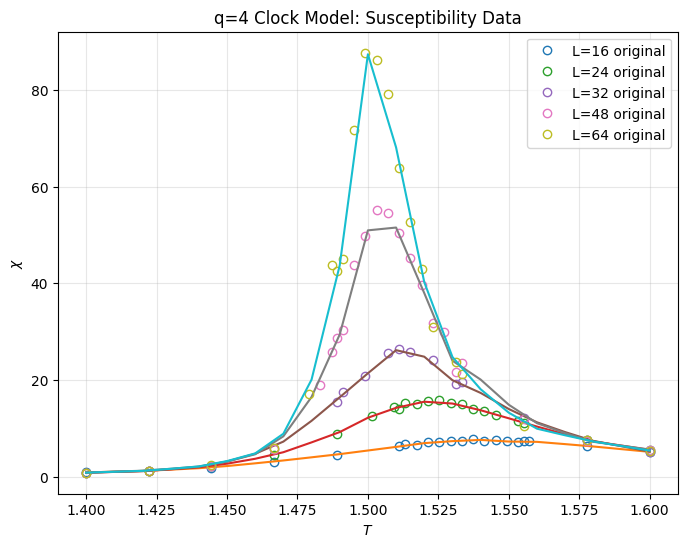


Uncertainty:
da shape = (5, 21)
da min   = 0.03951449853249711
da max   = 4.370370444634225

FSSA optimization results:
----------------------------------------------------------------------
Start: Tc=1.492, nu=0.75, zeta=1.35
Result: Tc=1.489592, nu=0.935846, gamma   =1.596566, quality=1.027477

Start: Tc=1.492, nu=0.83, zeta=1.44
Result: Tc=1.489592, nu=0.935848, gamma   =1.596567, quality=1.027477

Start: Tc=1.492, nu=0.90, zeta=1.55
Result: Tc=1.489592, nu=0.935846, gamma   =1.596569, quality=1.027477

Start: Tc=1.480, nu=0.83, zeta=1.44
Result: Tc=1.489592, nu=0.935844, gamma   =1.596561, quality=1.027477

Start: Tc=1.490, nu=0.83, zeta=1.44
Result: Tc=1.489593, nu=0.935846, gamma   =1.596569, quality=1.027477

Start: Tc=1.500, nu=0.83, zeta=1.44
Result: Tc=1.489592, nu=0.935846, gamma   =1.596565, quality=1.027477

Start: Tc=1.492, nu=0.75, zeta=1.44
Result: Tc=1.489592, nu=0.935849, gamma   =1.596568, quality=1.027477

Start: Tc=1.492, nu=0.90, zeta=1.44
Result: Tc=1.489592, nu

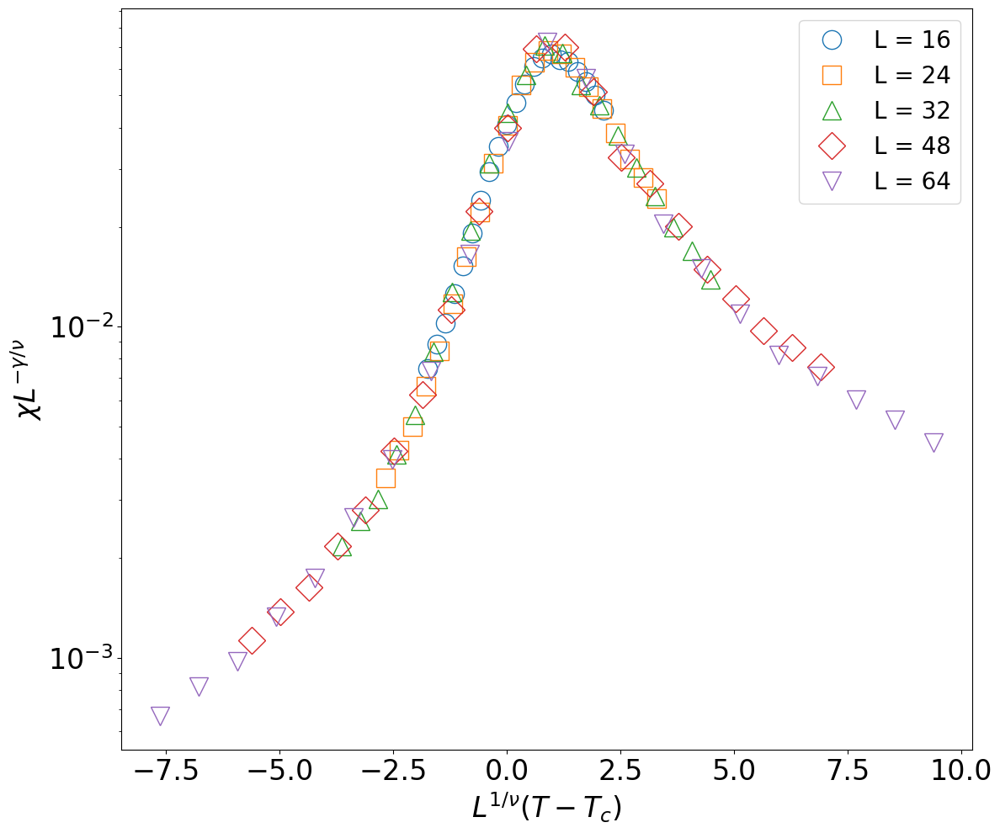

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import fssa
from scipy.optimize import minimize

# ============================================================
# 1. LOAD EXISTING SIMULATION DATA
# ============================================================

filename = "clock_q3_binderresolvedsimulationAdaptLog-16-64_data.npz"

data = np.load(filename)

L = np.array([16, 24, 32, 48, 64], dtype=float)

# ============================================================
# 2. LOAD THE ORIGINAL TEMPERATURE AND SUSCEPTIBILITY DATA
# ============================================================

T_original = {}
chi_original = {}

for Lval in L.astype(int):

    T_original[Lval] = np.asarray(
        data[f"L{Lval}_T"],
        dtype=float
    )

    chi_original[Lval] = np.asarray(
        data[f"L{Lval}_chi"],
        dtype=float
    )

    print(
        f"L = {Lval:2d}: "
        f"T = {len(T_original[Lval])} points, "
        f"chi = {len(chi_original[Lval])} points"
    )


# ============================================================
# 3. COMMON TEMPERATURE GRID
# ============================================================
#
# Your simulations all cover T = 1.00 to 1.45,
# but use different adaptive temperature points.
#
# We use the common region around the transition.
#
# This does NOT rerun the simulation.
# It only interpolates the already-existing chi(T) data.

T = np.arange(1.40, 1.60, 0.01)

print("\nCommon temperature grid:")
print(T)


# ============================================================
# 4. INTERPOLATE EXISTING chi(T) DATA
# ============================================================

chi = np.array([
    np.interp(
        T,
        T_original[int(Lval)],
        chi_original[int(Lval)]
    )
    for Lval in L
])

print("\nArray shapes:")
print("L   =", L.shape)
print("T   =", T.shape)
print("chi =", chi.shape)

assert chi.shape == (len(L), len(T))


# ============================================================
# 5. CHECK THE INTERPOLATED DATA
# ============================================================

plt.figure(figsize=(8, 6))

for i, Lval in enumerate(L.astype(int)):

    plt.plot(
        T_original[Lval],
        chi_original[Lval],
        'o',
        fillstyle='none',
        label=f"L={Lval} original"
    )

    plt.plot(
        T,
        chi[i],
        '-'
    )

plt.xlabel(r"$T$")
plt.ylabel(r"$\chi$")
plt.title("q=4 Clock Model: Susceptibility Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 6. NUMERICAL UNCERTAINTY
# ============================================================
#
# Your NPZ file contains ensemble averages, not the individual
# Monte Carlo measurements.
#
# Therefore 5% is NOT a measured statistical uncertainty.
# It is only a numerical weighting parameter for FSSA.
#
# Change this later if you obtain proper uncertainties.

relative_error = 0.05

da = relative_error * np.abs(chi)

# Make absolutely sure all uncertainties are positive
da = np.maximum(da, 1e-12)

print("\nUncertainty:")
print("da shape =", da.shape)
print("da min   =", da.min())
print("da max   =", da.max())


# ============================================================
# 7. DEFINE THE FSSA QUALITY FUNCTION
# ============================================================
#
# This reproduces the optimization performed internally by
# fssa.autoscale(), but avoids its problematic final
# covariance/error calculation.
#
# FSSA uses:
#
# x = L^(1/nu) (T - Tc)
#
# y = L^(-zeta/nu) chi
#
# where zeta = gamma/nu.
# ============================================================

def fssa_quality(parameters):

    Tc, nu, zeta = parameters

    # Reject physically/numerically invalid parameters
    if nu <= 0:
        return 1e100

    if zeta < 0:
        return 1e100

    # Keep Tc inside the actual temperature range
    if Tc < T.min() or Tc > T.max():
        return 1e100

    try:

        scaled = fssa.scaledata(
            l=L,
            rho=T,
            a=chi,
            da=da,
            rho_c=Tc,
            nu=nu,
            zeta=zeta
        )

        quality = fssa.quality(
            scaled.x,
            scaled.y,
            scaled.dy
        )

        if not np.isfinite(quality):
            return 1e100

        return quality

    except Exception:
        return 1e100


# ============================================================
# 8. TRY MULTIPLE INITIAL GUESSES
# ============================================================
#
# These are numerical starting points, NOT assumed theoretical
# values.
#
# Trying several starting points is useful because Nelder-Mead
# is a local optimizer.
# ============================================================

initial_guesses = [

    [1.492, 0.75, 1.35],
    [1.492, 0.8333, 1.4444],
    [1.492, 0.90, 1.55],

    [1.480, 0.8333, 1.4444],
    [1.490, 0.8333, 1.4444],
    [1.500, 0.8333, 1.4444],

    [1.492, 0.75, 1.4444],
    [1.492, 0.90, 1.4444],
    [1.492, 0.8333, 1.55]

]


results = []

print("\nFSSA optimization results:")
print("-" * 70)

for guess in initial_guesses:

    result = minimize(
        fssa_quality,
        guess,
        method="Nelder-Mead",
        options={
            "maxiter": 3000,
            "xatol": 1e-5,
            "fatol": 1e-5
        }
    )

    if result.success and np.isfinite(result.fun):

        results.append(result)

        print(
            f"Start: Tc={guess[0]:.3f}, "
            f"nu={guess[1]:.2f}, "
            f"zeta={guess[2]:.2f}"
        )

        print(
            f"Result: Tc={result.x[0]:.6f}, "
            f"nu={result.x[1]:.6f}, "
            f"gamma   ={result.x[2]:.6f}, "
            f"quality={result.fun:.6f}"
        )

        print()


# ============================================================
# 9. SELECT THE LOWEST FSSA QUALITY RESULT
# ============================================================

if len(results) == 0:
    raise RuntimeError(
        "FSSA optimization failed for all starting guesses."
    )

best = min(results, key=lambda r: r.fun)

Tc = best.x[0]
nu = best.x[1]
zeta = best.x[2]

print("=" * 70)
print("FINAL FSSA RESULT")
print("=" * 70)

print(f"Tc       = {Tc:.8f}")
print(f"nu       = {nu:.8f}")
print(f"gamma    = {zeta:.8f}")
print(f"quality  = {best.fun:.8f}")

print("=" * 70)


# ============================================================
# 10. SCALE DATA USING THE OPTIMIZED PARAMETERS
# ============================================================

scaled = fssa.scaledata(
    l=L,
    rho=T,
    a=chi,
    da=da,
    rho_c=Tc,
    nu=nu,
    zeta=zeta
)


# ============================================================
# 11. DATA COLLAPSE PLOT
# ============================================================

plt.figure(figsize=(12, 10))

markers = ['o', 's', '^', 'D', 'v']

for i, Lval in enumerate(L.astype(int)):

    plt.plot(
        scaled.x[i],
        scaled.y[i],
        marker=markers[i],
        ms = 16,
        fillstyle='none',
        linestyle='',
        label=f"L = {Lval}"
    )
plt.tick_params(axis='both', labelsize=24)
plt.xlabel(
    r"$L^{1/\nu}(T-T_c)$",
    fontsize=24
)
plt.yscale('log')
plt.ylabel(
    r"$\chi L^{-\gamma/\nu}$",
    fontsize=24
)

#plt.title(
    #"FSSA Data Collapse: q=4 Clock Model",
    #fontsize=14
#)

plt.legend(fontsize=20)
plt.grid(False)
plt.savefig('FSSAq3Clock.pdf')
plt.tight_layout()
plt.show()

In [3]:
import numpy as np
import fssa

# ============================================================
# Load existing simulation
# ============================================================

data = np.load("clock_q4_binderresolvedsimulationAdaptLog16-64_data.npz")

L = np.array([16, 24, 32, 48, 64], dtype=float)

# ============================================================
# Extract the ORIGINAL temperature and susceptibility data
# ============================================================

T_original = {}
chi_original = {}

for Lval in L.astype(int):

    T_original[Lval] = np.asarray(
        data[f"L{Lval}_T"], dtype=float
    )

    chi_original[Lval] = np.asarray(
        data[f"L{Lval}_chi"], dtype=float
    )

    print(
        f"L={Lval}: "
        f"{len(T_original[Lval])} points"
    )

# ============================================================
# Create a common temperature grid
# ============================================================

T = np.arange(1.00, 1.4501, 0.01)

# ============================================================
# Interpolate existing chi(T) data
# ============================================================

chi = np.array([
    np.interp(
        T,
        T_original[int(Lval)],
        chi_original[int(Lval)]
    )
    for Lval in L
])

print("\nFinal arrays:")
print("L shape   =", L.shape)
print("T shape   =", T.shape)
print("chi shape =", chi.shape)

L=16: 21 points
L=24: 21 points
L=32: 25 points
L=48: 21 points
L=64: 22 points

Final arrays:
L shape   = (5,)
T shape   = (46,)
chi shape = (5, 46)


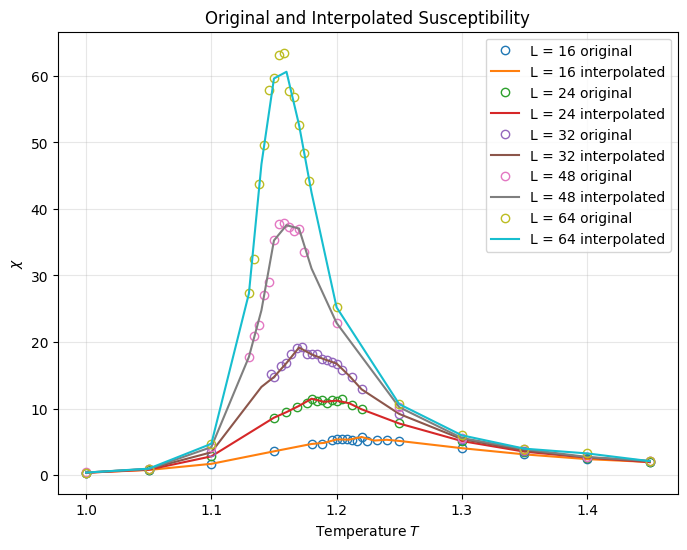

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for i, Lval in enumerate(L.astype(int)):

    plt.plot(
        T_original[Lval],
        chi_original[Lval],
        'o',
        fillstyle='none',
        label=f"L = {Lval} original"
    )

    plt.plot(
        T,
        chi[i],
        '-',
        label=f"L = {Lval} interpolated"
    )

plt.xlabel("Temperature $T$")
plt.ylabel(r"$\chi$")
plt.title("Original and Interpolated Susceptibility")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

L = 16: T = 21 points, chi = 21 points
L = 24: T = 21 points, chi = 21 points
L = 32: T = 25 points, chi = 25 points
L = 48: T = 21 points, chi = 21 points
L = 64: T = 22 points, chi = 22 points

Common temperature grid:
[1.1  1.11 1.12 1.13 1.14 1.15 1.16 1.17 1.18 1.19 1.2  1.21 1.22 1.23
 1.24 1.25]

Array shapes:
L   = (5,)
T   = (16,)
chi = (5, 16)


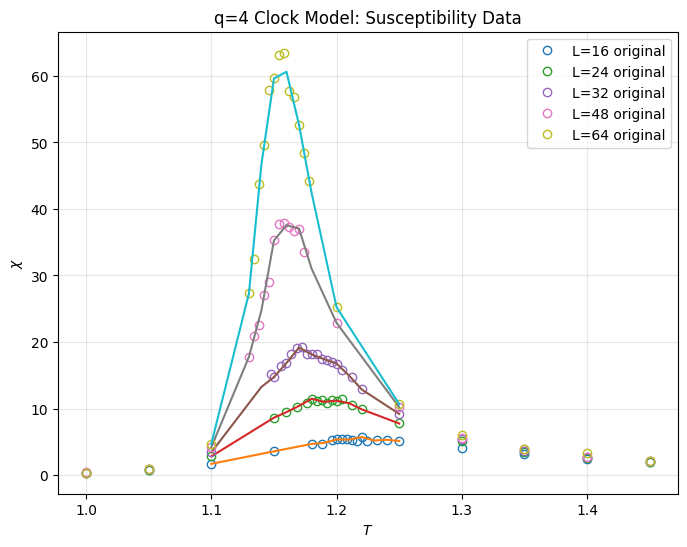


Uncertainty:
da shape = (5, 16)
da min   = 0.08502219919022412
da max   = 3.03057410652251

FSSA optimization results:
----------------------------------------------------------------------
Start: Tc=1.135, nu=0.90, zeta=1.65
Result: Tc=1.127960, nu=1.205344, gamma   =2.062287, quality=1.728495

Start: Tc=1.135, nu=1.00, zeta=1.75
Result: Tc=1.127960, nu=1.205388, gamma   =2.062333, quality=1.728495

Start: Tc=1.135, nu=1.10, zeta=1.85
Result: Tc=1.128008, nu=1.119590, gamma   =1.929727, quality=1.849496

Start: Tc=1.130, nu=0.90, zeta=1.75
Result: Tc=1.127960, nu=1.205371, gamma   =2.062324, quality=1.728495

Start: Tc=1.130, nu=1.00, zeta=1.75
Result: Tc=1.127955, nu=1.204876, gamma   =2.061436, quality=1.728502

Start: Tc=1.140, nu=1.00, zeta=1.75
Result: Tc=1.127960, nu=1.205361, gamma   =2.062318, quality=1.728495

Start: Tc=1.140, nu=0.90, zeta=1.85
Result: Tc=1.127960, nu=1.205372, gamma   =2.062327, quality=1.728495

Start: Tc=1.140, nu=1.10, zeta=1.75
Result: Tc=1.127960, nu=

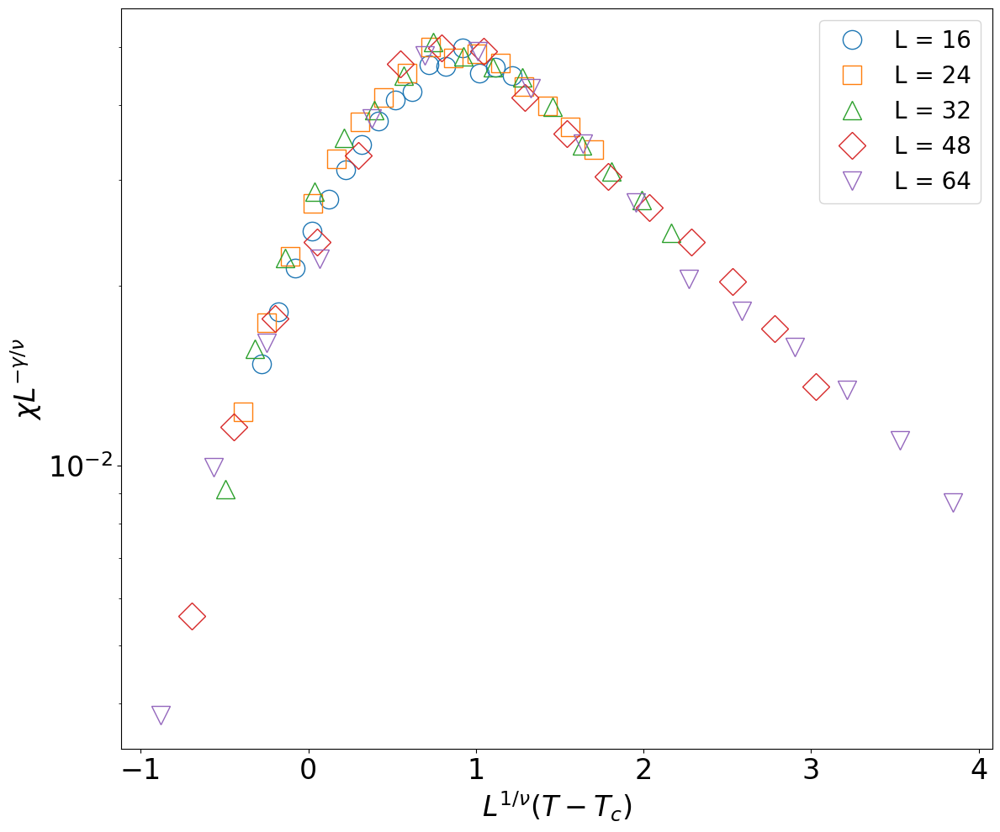

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import fssa
from scipy.optimize import minimize

# ============================================================
# 1. LOAD EXISTING SIMULATION DATA
# ============================================================

filename = "clock_q4_binderresolvedsimulationAdaptLog16-64_data.npz"

data = np.load(filename)

L = np.array([16, 24, 32, 48, 64], dtype=float)

# ============================================================
# 2. LOAD THE ORIGINAL TEMPERATURE AND SUSCEPTIBILITY DATA
# ============================================================

T_original = {}
chi_original = {}

for Lval in L.astype(int):

    T_original[Lval] = np.asarray(
        data[f"L{Lval}_T"],
        dtype=float
    )

    chi_original[Lval] = np.asarray(
        data[f"L{Lval}_chi"],
        dtype=float
    )

    print(
        f"L = {Lval:2d}: "
        f"T = {len(T_original[Lval])} points, "
        f"chi = {len(chi_original[Lval])} points"
    )


# ============================================================
# 3. COMMON TEMPERATURE GRID
# ============================================================
#
# Your simulations all cover T = 1.00 to 1.45,
# but use different adaptive temperature points.
#
# We use the common region around the transition.
#
# This does NOT rerun the simulation.
# It only interpolates the already-existing chi(T) data.

T = np.arange(1.10, 1.2501, 0.01)

print("\nCommon temperature grid:")
print(T)


# ============================================================
# 4. INTERPOLATE EXISTING chi(T) DATA
# ============================================================

chi = np.array([
    np.interp(
        T,
        T_original[int(Lval)],
        chi_original[int(Lval)]
    )
    for Lval in L
])

print("\nArray shapes:")
print("L   =", L.shape)
print("T   =", T.shape)
print("chi =", chi.shape)

assert chi.shape == (len(L), len(T))


# ============================================================
# 5. CHECK THE INTERPOLATED DATA
# ============================================================

plt.figure(figsize=(8, 6))

for i, Lval in enumerate(L.astype(int)):

    plt.plot(
        T_original[Lval],
        chi_original[Lval],
        'o',
        fillstyle='none',
        label=f"L={Lval} original"
    )

    plt.plot(
        T,
        chi[i],
        '-'
    )

plt.xlabel(r"$T$")
plt.ylabel(r"$\chi$")
plt.title("q=4 Clock Model: Susceptibility Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 6. NUMERICAL UNCERTAINTY
# ============================================================
#
# Your NPZ file contains ensemble averages, not the individual
# Monte Carlo measurements.
#
# Therefore 5% is NOT a measured statistical uncertainty.
# It is only a numerical weighting parameter for FSSA.
#
# Change this later if you obtain proper uncertainties.

relative_error = 0.05

da = relative_error * np.abs(chi)

# Make absolutely sure all uncertainties are positive
da = np.maximum(da, 1e-12)

print("\nUncertainty:")
print("da shape =", da.shape)
print("da min   =", da.min())
print("da max   =", da.max())


# ============================================================
# 7. DEFINE THE FSSA QUALITY FUNCTION
# ============================================================
#
# This reproduces the optimization performed internally by
# fssa.autoscale(), but avoids its problematic final
# covariance/error calculation.
#
# FSSA uses:
#
# x = L^(1/nu) (T - Tc)
#
# y = L^(-zeta/nu) chi
#
# where zeta = gamma/nu.
# ============================================================

def fssa_quality(parameters):

    Tc, nu, zeta = parameters

    # Reject physically/numerically invalid parameters
    if nu <= 0:
        return 1e100

    if zeta < 0:
        return 1e100

    # Keep Tc inside the actual temperature range
    if Tc < T.min() or Tc > T.max():
        return 1e100

    try:

        scaled = fssa.scaledata(
            l=L,
            rho=T,
            a=chi,
            da=da,
            rho_c=Tc,
            nu=nu,
            zeta=zeta
        )

        quality = fssa.quality(
            scaled.x,
            scaled.y,
            scaled.dy
        )

        if not np.isfinite(quality):
            return 1e100

        return quality

    except Exception:
        return 1e100


# ============================================================
# 8. TRY MULTIPLE INITIAL GUESSES
# ============================================================
#
# These are numerical starting points, NOT assumed theoretical
# values.
#
# Trying several starting points is useful because Nelder-Mead
# is a local optimizer.
# ============================================================

#initial_guesses = [

    #[1.14, 0.50, 1.00],
    #[1.14, 0.75, 1.50],
    #[1.14, 1.00, 1.75],

    #[1.16, 0.50, 1.50],
    #[1.16, 0.75, 1.75],
    #[1.16, 1.00, 2.00],

    #[1.18, 0.50, 1.50],
    #[1.18, 0.75, 1.75],
    #[1.18, 1.00, 2.00]
#]
initial_guesses = [
    [1.1346, 0.90, 1.65],
    [1.1346, 1.00, 1.75],
    [1.1346, 1.10, 1.85],

    [1.1300, 0.90, 1.75],
    [1.1300, 1.00, 1.75],
    [1.1400, 1.00, 1.75],

    [1.1400, 0.90, 1.85],
    [1.1400, 1.10, 1.75],
    [1.1500, 1.00, 1.75]
]

results = []

print("\nFSSA optimization results:")
print("-" * 70)

for guess in initial_guesses:

    result = minimize(
        fssa_quality,
        guess,
        method="Nelder-Mead",
        options={
            "maxiter": 3000,
            "xatol": 1e-5,
            "fatol": 1e-5
        }
    )

    if result.success and np.isfinite(result.fun):

        results.append(result)

        print(
            f"Start: Tc={guess[0]:.3f}, "
            f"nu={guess[1]:.2f}, "
            f"zeta={guess[2]:.2f}"
        )

        print(
            f"Result: Tc={result.x[0]:.6f}, "
            f"nu={result.x[1]:.6f}, "
            f"gamma   ={result.x[2]:.6f}, "
            f"quality={result.fun:.6f}"
        )

        print()


# ============================================================
# 9. SELECT THE LOWEST FSSA QUALITY RESULT
# ============================================================

if len(results) == 0:
    raise RuntimeError(
        "FSSA optimization failed for all starting guesses."
    )

best = min(results, key=lambda r: r.fun)

Tc = best.x[0]
nu = best.x[1]
zeta = best.x[2]

print("=" * 70)
print("FINAL FSSA RESULT")
print("=" * 70)

print(f"Tc       = {Tc:.8f}")
print(f"nu       = {nu:.8f}")
print(f"gamma    = {zeta:.8f}")
print(f"quality  = {best.fun:.8f}")

print("=" * 70)


# ============================================================
# 10. SCALE DATA USING THE OPTIMIZED PARAMETERS
# ============================================================

scaled = fssa.scaledata(
    l=L,
    rho=T,
    a=chi,
    da=da,
    rho_c=Tc,
    nu=nu,
    zeta=zeta
)


# ============================================================
# 11. DATA COLLAPSE PLOT
# ============================================================

plt.figure(figsize=(12, 10))

markers = ['o', 's', '^', 'D', 'v']

for i, Lval in enumerate(L.astype(int)):

    plt.plot(
        scaled.x[i],
        scaled.y[i],
        marker=markers[i],
        ms = 16,
        fillstyle='none',
        linestyle='',
        label=f"L = {Lval}"
    )
plt.tick_params(axis='both', labelsize=24)
plt.xlabel(
    r"$L^{1/\nu}(T-T_c)$",
    fontsize=24
)
plt.yscale('log')
plt.ylabel(
    r"$\chi L^{-\gamma/\nu}$",
    fontsize=24
)

#plt.title(
    #"FSSA Data Collapse: q=4 Clock Model",
    #fontsize=14
#)

plt.legend(fontsize = 20)
plt.grid(False)
plt.savefig('FSSAq4Clock.pdf')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

data = np.load("clock_q4_binderresolvedsimulationAdaptLog16-64_data.npz")

L_values = [16, 24, 32, 48, 64]

for L in L_values:

    T = np.asarray(data[f"L{L}_T"])
    chi = np.asarray(data[f"L{L}_chi"])

    print(
        f"L = {L:2d} | "
        f"T shape = {T.shape} | "
        f"chi shape = {chi.shape} | "
        f"T range = ({T.min():.6f}, {T.max():.6f})"
    )

for L in L_values:

    T = np.asarray(data[f"L{L}_T"])
    chi = np.asarray(data[f"L{L}_chi"])

    print(f"\nL = {L}")
    print("Number of T:", len(T))
    print("Number of chi:", len(chi))
    print("T sorted:", np.all(np.diff(T) > 0))
    print("T:")
    print(T)

In [43]:

data = np.load("clock_q4_binderresolvedsimulationAdaptLog16-64_data.npz")

L = np.array([16, 24, 32, 48, 64])

T_arrays = [
    data["L16_T"],
    data["L24_T"],
    data["L32_T"],
    data["L48_T"],
    data["L64_T"]
]

chi = np.array([
    data["L16_chi"],
    data["L24_chi"],
    data["L32_chi"],
    data["L48_chi"],
    data["L64_chi"]
])

# Check temperature grids
same_T = all(np.array_equal(T_arrays[0], T) for T in T_arrays[1:])

print("Same temperature grid:", same_T)

if same_T:
    T = T_arrays[0]

    print("T shape:", T.shape)
    print("L shape:", L.shape)
    print("chi shape:", chi.shape)

Same temperature grid: False


C:\Users\Darwin\AppData\Local\Temp\ipykernel_18096\3779437224.py:13: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  chi = np.array([


In [33]:
import warnings
import fssa

warnings.filterwarnings(
    "ignore",
    message="`np.int` is a deprecated alias"
)
# Sensitivity Analysis for values of Tc, nu, and gamma
#Tc_guesses = [0.99, 1.00, 1.01]

#nu_guesses = [0.70, 0.80, 0.90, 1.00]

#gamma_over_nu_guess = 1.7
# --------------------------------------------------
# Load existing simulation data
# --------------------------------------------------
L_values = [16, 24, 36, 48, 64]
data = np.load("clock_q4_binderresolvedsimulationAdaptLog16-64_data.npz")

T = np.asarray(data["T_values"], dtype=float)
L = np.asarray(data["L_values"], dtype=float)

chi = np.array([
    data["L16_chi"],
    data["L24_chi"],
    data["L32_chi"],
    data["L48_chi"],
    data["L64_chi"]
], dtype=float)

# Rows = lattice sizes
# Columns = temperatures
print("T shape   :", T.shape)
print("L shape   :", L.shape)
print("chi shape :", chi.shape)

# --------------------------------------------------
# Assumed uncertainty for FSSA
# --------------------------------------------------

relative_error = 0.05
da = relative_error * np.abs(chi)

# --------------------------------------------------
# FSSA
# --------------------------------------------------

result = fssa.autoscale(
    L,
    T,
    chi,
    da,
    rho_c0=0.95,
    nu0=0.67,
    zeta0=1.17
)

print("\nFSSA results")
print("--------------------")
print(f"Tc       = {result.rho:.6f}")
print(f"nu       = {result.nu:.6f}")
print(f"gamma/nu = {result.zeta:.6f}")
print(f"quality  = {result.fun:.6f}")

# --------------------------------------------------
# Scale data using fitted parameters
# --------------------------------------------------

scaled = fssa.scaledata(
    L,
    T,
    chi,
    da,
    result.rho,
    result.nu,
    result.zeta
)

# --------------------------------------------------
# Plot data collapse
# --------------------------------------------------

plt.figure(figsize=(8, 6))

markers = ['o', 's', '^', 'D', 'v']

for i, Lval in enumerate(L):
    plt.plot(
        scaled.x[i],
        scaled.y[i],
        marker=markers[i],
        fillstyle='none',
        linestyle = '',
        label=f"L = {int(Lval)}"
    )

plt.xlabel(r"$L^{1/\nu}(T-T_c)$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("FSSA Data Collapse: 3-State clock Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

L = 16
[1.    1.05  1.1   1.15  1.18  1.188 1.196 1.2   1.204 1.208 1.212 1.216
 1.22  1.224 1.232 1.24  1.25  1.3   1.35  1.4   1.45 ]
L = 24
[1.    1.05  1.1   1.15  1.16  1.168 1.176 1.18  1.184 1.188 1.192 1.196
 1.2   1.204 1.212 1.22  1.25  1.3   1.35  1.4   1.45 ]
L = 36
[1.    1.05  1.1   1.148 1.15  1.156 1.16  1.164 1.168 1.172 1.176 1.18
 1.184 1.188 1.192 1.196 1.2   1.204 1.212 1.22  1.25  1.3   1.35  1.4
 1.45 ]
L = 48
[1.    1.05  1.1   1.13  1.134 1.138 1.142 1.146 1.15  1.154 1.158 1.162
 1.166 1.17  1.174 1.2   1.25  1.3   1.35  1.4   1.45 ]
L = 64
[1.    1.05  1.1   1.13  1.134 1.138 1.142 1.146 1.15  1.154 1.158 1.162
 1.166 1.17  1.174 1.178 1.2   1.25  1.3   1.35  1.4   1.45 ]


KeyError: 'T_values is not a file in the archive'

### Average Magnetization Components per Spin in Different values of Clock States (q)

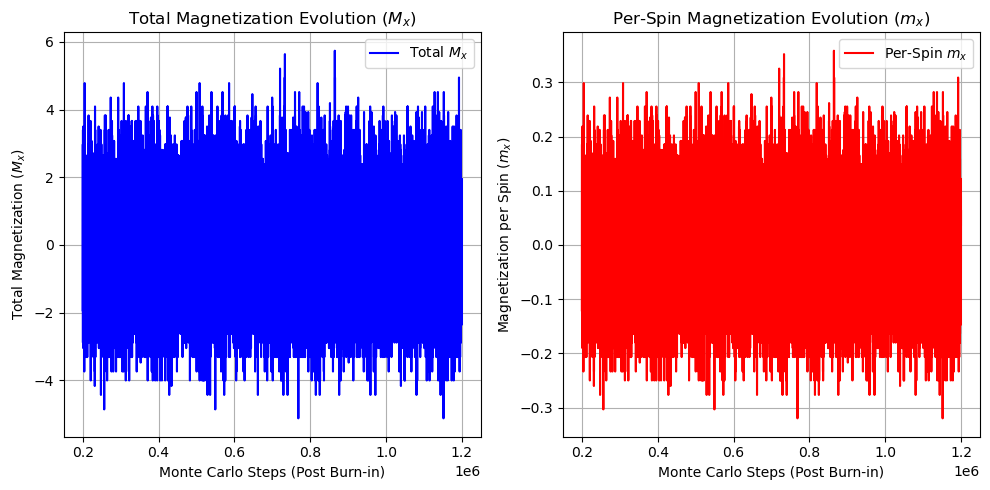

In [11]:

# Parameters
L = 4  # Lattice size
q = 5   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
T = 1.0  # Temperature
steps = 10**6  # Total Monte Carlo steps (AFTER burn-in)
measure_every = L**2  # Measure every L^2 steps
burn_in = 200000  # Burn-in period

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles
# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:  # Nearest neighbors
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Chirality inside cosine
                H -= np.dot(h, sigma[i, j])  # External field term
    return H
# Compute total magnetization (only x-component)
def compute_magnetization_x(sigma, L):
    M_x = np.sum(sigma[:, :, 0])  # Sum over x-components
    m_x = M_x / (L**2)  # Normalize per spin
    return M_x, m_x  # Return both total and per-spin magnetization

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="glauber"):
    """
    Perform a single Monte Carlo update using either Glauber or Metropolis dynamics.
    """
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    old_angle = angles[i, j]  # Current spin angle

    # Compute E_old (Energy before update)
    E_old = 0
    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        E_old += J * np.cos(old_angle - neighbor_angle + delta)

    # Compute E_new (Energy after update)
    E_new = 0
    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        E_new += J * np.cos(new_angle - neighbor_angle + delta)

    # External field term
    E_old += np.dot(h, sigma[i, j])
    E_new += np.dot(h, new_sigma)

    # Compute ΔE
    dE = E_new - E_old  # No factor of 2

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    
    # Burn-in
    for _ in range(burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

    # Lists to store magnetization
    M_x_list = []
    m_x_list = []

    # Correct number of steps (AFTER burn-in)
    for step in range(steps):  # Now runs only after burn-in
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            M_x, m_x = compute_magnetization_x(sigma, L)
            M_x_list.append(M_x)  # Store total magnetization in x
            m_x_list.append(m_x)  # Store per-spin magnetization in x

    return np.array(M_x_list), np.array(m_x_list), spins, sigma, angles  # Return lists

# Run the Glauber simulation
M_x_list, m_x_list, spins, sigma, angles = run_simulation("glauber")

# Plot magnetization x-component over time
plt.figure(figsize=(10, 5))

# Correct x-axis values to **exclude** burn-in
x_vals = np.arange(len(M_x_list)) * measure_every + burn_in

# Plot total magnetization x-component
plt.subplot(1, 2, 1)
plt.plot(x_vals, M_x_list, label="Total $M_x$", color="blue")
plt.xlabel("Monte Carlo Steps (Post Burn-in)")
plt.ylabel("Total Magnetization ($M_x$)")
plt.title("Total Magnetization Evolution ($M_x$)")
plt.legend()
plt.grid()

# Plot per-spin magnetization x-component
plt.subplot(1, 2, 2)
plt.plot(x_vals, m_x_list, label="Per-Spin $m_x$", color="red")
plt.xlabel("Monte Carlo Steps (Post Burn-in)")
plt.ylabel("Magnetization per Spin ($m_x$)")
plt.title("Per-Spin Magnetization Evolution ($m_x$)")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


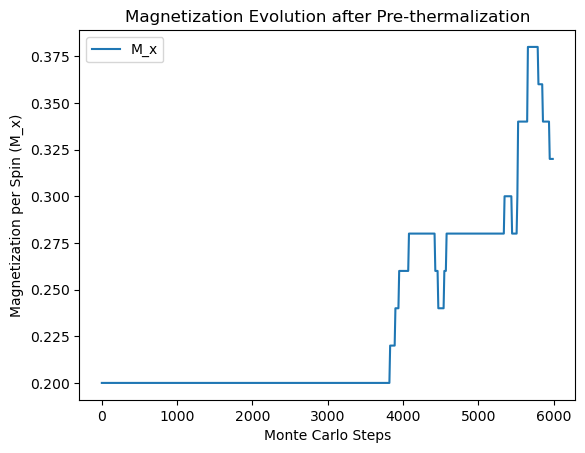

In [203]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
L = 10  # Lattice size
q = 2   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps
burn_in = 4000  # Number of steps to discard before measuring

def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)
    return spins, sigma, angles

def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)
    return mag_vector  # Returns [M_x, M_y]

def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)
    new_spin = np.random.randint(0, q)
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])
    old_angle = angles[i, j]
    dE = 0
    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) -
                        np.cos(new_angle - neighbor_angle + delta))
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))
    P_accept = 1 / (1 + np.exp(dE / T)) if update_rule == "glauber" else min(1, np.exp(-dE / T))
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma

def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    magnetization_vals = []
    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)
        if step >= burn_in and step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma)[0])  # M_x only
    return np.array(magnetization_vals)

# Run Glauber simulation with pre-thermalization
magnetization_vals = run_simulation("glauber")
avg_mag = np.abs(magnetization_vals)
# Ensure we have data to plot
if len(magnetization_vals) == 0:
    print("Error: No magnetization values recorded. Check burn_in and steps values.")
else:
    # Corrected x-axis range
    plt.plot(np.arange(0, len(avg_mag) * measure_every, measure_every), 
             avg_mag, label="M_x")
    plt.xlabel("Monte Carlo Steps")
    plt.ylabel("Magnetization per Spin (M_x)")
    plt.title("Magnetization Evolution after Pre-thermalization")
    plt.legend()
    plt.show()


Initial Hamiltonian: -200.0
Initial Magnetization per Spin: [1. 0.]
Final Hamiltonian: -200.0
Final Magnetization per Spin: [1. 0.]


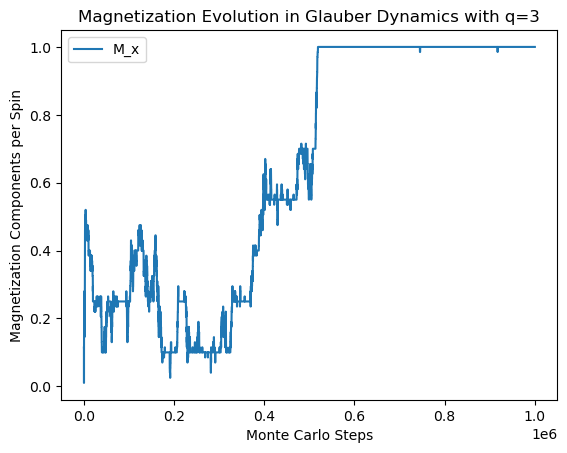

In [151]:

# Parameters
L = 10  # Lattice size
q = 3   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps
# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles  # Return angles too

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:  # Nearest neighbors
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Chirality inside cosine
                H -= np.dot(h, sigma[i, j])  # External field term
    return H

# Compute average magnetization per spin
def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)  # Average magnetization vector
    return mag_vector

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="glauber"):
    """
    Perform a single Monte Carlo update using either Glauber or Metropolis dynamics.
    """
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    # Compute energy difference ΔE
    old_angle = angles[i, j]  # Current spin angle
    dE = 0

    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        
        # Corrected interaction term with chirality
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) - 
                        np.cos(new_angle - neighbor_angle + delta))

    # External field term
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    magnetization_vals = []

    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma))

    return np.array(magnetization_vals), spins, sigma, angles  # Return angles

# Run the Glauber simulation
magnetization_vals, spins, sigma, angles = run_simulation("glauber")

# Compute initial and final Hamiltonian
H_init = compute_hamiltonian(sigma, angles, J, h, delta)
M_init = compute_magnetization(sigma)
H_final = compute_hamiltonian(sigma, angles, J, h, delta)
M_final = compute_magnetization(sigma)

print("Initial Hamiltonian:", H_init)
print("Initial Magnetization per Spin:", M_init)
print("Final Hamiltonian:", H_final)
print("Final Magnetization per Spin:", M_final)

# Plot magnetization components over time
plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 0], label="M_x")
#plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 1], label="M_y")
plt.xlabel("Monte Carlo Steps")
plt.ylabel("Magnetization Components per Spin")
plt.title("Magnetization Evolution in Glauber Dynamics with q=3")
plt.legend()
plt.show()


Initial Hamiltonian: -168.0
Initial Magnetization per Spin: [-0.62 -0.38]
Final Hamiltonian: -168.0
Final Magnetization per Spin: [-0.62 -0.38]


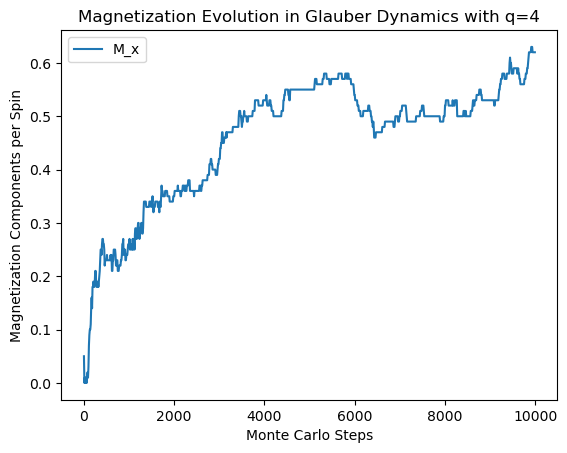

In [124]:

# Parameters
L = 10  # Lattice size
q = 4   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles  # Return angles too

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:  # Nearest neighbors
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Chirality inside cosine
                H -= np.dot(h, sigma[i, j])  # External field term
    return H

# Compute average magnetization per spin
def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)  # Average magnetization vector
    return mag_vector

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="metropolis"):
    """
    Perform a single Monte Carlo update using either Glauber or Metropolis dynamics.
    """
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    # Compute energy difference ΔE
    old_angle = angles[i, j]  # Current spin angle
    dE = 0

    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        
        # Corrected interaction term with chirality
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) - 
                        np.cos(new_angle - neighbor_angle + delta))

    # External field term
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    magnetization_vals = []

    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma))

    return np.array(magnetization_vals), spins, sigma, angles  # Return angles

# Run the Glauber simulation
magnetization_vals, spins, sigma, angles = run_simulation("glauber")

# Compute initial and final Hamiltonian
H_init = compute_hamiltonian(sigma, angles, J, h, delta)
M_init = compute_magnetization(sigma)
H_final = compute_hamiltonian(sigma, angles, J, h, delta)
M_final = compute_magnetization(sigma)

print("Initial Hamiltonian:", H_init)
print("Initial Magnetization per Spin:", M_init)
print("Final Hamiltonian:", H_final)
print("Final Magnetization per Spin:", M_final)

# Plot magnetization components over time
plt.plot(np.arange(0, steps, measure_every), np.abs(magnetization_vals[:, 0]), label="M_x")
#plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 1], label="M_y")
plt.xlabel("Monte Carlo Steps")
plt.ylabel("Magnetization Components per Spin")
plt.title("Magnetization Evolution in Glauber Dynamics with q=4")
plt.legend()
plt.show()


Initial Hamiltonian: -143.37790070187228
Initial Magnetization per Spin: [-0.30225425 -0.21960057]
Final Hamiltonian: -143.37790070187228
Final Magnetization per Spin: [-0.30225425 -0.21960057]


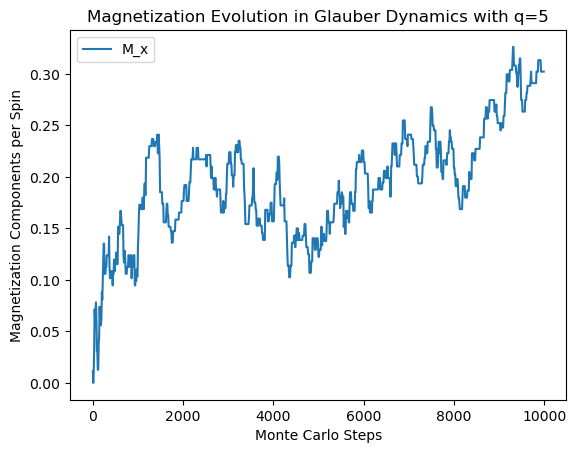

In [54]:

# Parameters
L = 10  # Lattice size
q = 5   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles  # Return angles too

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:  # Nearest neighbors
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Chirality inside cosine
                H -= np.dot(h, sigma[i, j])  # External field term
    return H

# Compute average magnetization per spin
def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)  # Average magnetization vector
    return mag_vector

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="glauber"):
    """
    Perform a single Monte Carlo update using either Glauber or Metropolis dynamics.
    """
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    # Compute energy difference ΔE
    old_angle = angles[i, j]  # Current spin angle
    dE = 0

    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        
        # Corrected interaction term with chirality
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) - 
                        np.cos(new_angle - neighbor_angle + delta))

    # External field term
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    magnetization_vals = []

    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma))

    return np.array(magnetization_vals), spins, sigma, angles  # Return angles

# Run the Glauber simulation
magnetization_vals, spins, sigma, angles = run_simulation("glauber")

# Compute initial and final Hamiltonian
H_init = compute_hamiltonian(sigma, angles, J, h, delta)
M_init = compute_magnetization(sigma)
H_final = compute_hamiltonian(sigma, angles, J, h, delta)
M_final = compute_magnetization(sigma)

print("Initial Hamiltonian:", H_init)
print("Initial Magnetization per Spin:", M_init)
print("Final Hamiltonian:", H_final)
print("Final Magnetization per Spin:", M_final)

# Plot magnetization components over time
plt.plot(np.arange(0, steps, measure_every), np.abs(magnetization_vals[:, 0]), label="M_x")
#plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 1], label="M_y")
plt.xlabel("Monte Carlo Steps")
plt.ylabel("Magnetization Components per Spin")
plt.title("Magnetization Evolution in Glauber Dynamics with q=5")
plt.legend()
plt.show()


Initial Hamiltonian: -184.0
Initial Magnetization per Spin: [ 0.33      -0.8660254]
Final Hamiltonian: -184.0
Final Magnetization per Spin: [ 0.33      -0.8660254]


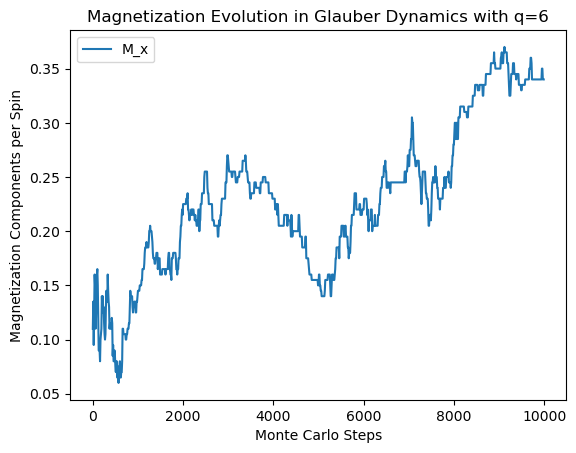

In [111]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
L = 10  # Lattice size
q = 6   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles  # Return angles too

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:  # Nearest neighbors
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Chirality inside cosine
                H -= np.dot(h, sigma[i, j])  # External field term
    return H

# Compute average magnetization per spin
def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)  # Average magnetization vector
    return mag_vector

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="glauber"):
    """
    Perform a single Monte Carlo update using either Glauber or Metropolis dynamics.
    """
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    # Compute energy difference ΔE
    old_angle = angles[i, j]  # Current spin angle
    dE = 0

    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        
        # Corrected interaction term with chirality
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) - 
                        np.cos(new_angle - neighbor_angle + delta))

    # External field term
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    magnetization_vals = []

    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma))

    return np.array(magnetization_vals), spins, sigma, angles  # Return angles

# Run the Glauber simulation
magnetization_vals, spins, sigma, angles = run_simulation("glauber")

# Compute initial and final Hamiltonian
H_init = compute_hamiltonian(sigma, angles, J, h, delta)
M_init = compute_magnetization(sigma)
H_final = compute_hamiltonian(sigma, angles, J, h, delta)
M_final = compute_magnetization(sigma)

print("Initial Hamiltonian:", H_init)
print("Initial Magnetization per Spin:", M_init)
print("Final Hamiltonian:", H_final)
print("Final Magnetization per Spin:", M_final)

# Plot magnetization components over time
plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 0], label="M_x")
#plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 1], label="M_y")
plt.xlabel("Monte Carlo Steps")
plt.ylabel("Magnetization Components per Spin")
plt.title("Magnetization Evolution in Glauber Dynamics with q=6")
plt.legend()
plt.show()


### With Chirality value of $\delta = 0.5$

Initial Hamiltonian: -117.75860032394624
Initial Magnetization per Spin: [0.48 0.44]
Final Hamiltonian: -117.75860032394624
Final Magnetization per Spin: [0.48 0.44]


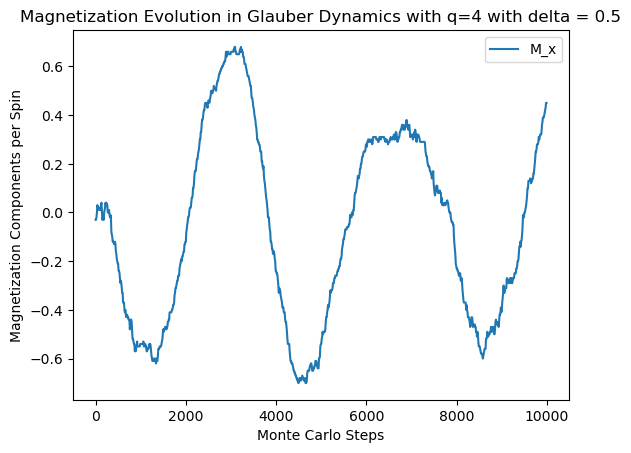

In [126]:

# Parameters
L = 10  # Lattice size
q = 4   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0.5  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles  # Return angles too

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:  # Nearest neighbors
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Chirality inside cosine
                H -= np.dot(h, sigma[i, j])  # External field term
    return H

# Compute average magnetization per spin
def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)  # Average magnetization vector
    return mag_vector

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="glauber"):
    """
    Perform a single Monte Carlo update using either Glauber or Metropolis dynamics.
    """
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    # Compute energy difference ΔE
    old_angle = angles[i, j]  # Current spin angle
    dE = 0

    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        
        # Corrected interaction term with chirality
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) - 
                        np.cos(new_angle - neighbor_angle + delta))

    # External field term
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    magnetization_vals = []

    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma))

    return np.array(magnetization_vals), spins, sigma, angles  # Return angles

# Run the Glauber simulation
magnetization_vals, spins, sigma, angles = run_simulation("glauber")

# Compute initial and final Hamiltonian
H_init = compute_hamiltonian(sigma, angles, J, h, delta)
M_init = compute_magnetization(sigma)
H_final = compute_hamiltonian(sigma, angles, J, h, delta)
M_final = compute_magnetization(sigma)

print("Initial Hamiltonian:", H_init)
print("Initial Magnetization per Spin:", M_init)
print("Final Hamiltonian:", H_final)
print("Final Magnetization per Spin:", M_final)

# Plot magnetization components over time
plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 0], label="M_x")
#plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 1], label="M_y")
plt.xlabel("Monte Carlo Steps")
plt.ylabel("Magnetization Components per Spin")
plt.title("Magnetization Evolution in Glauber Dynamics with q=4 with delta = 0.5")
plt.legend()
plt.show()


Initial Hamiltonian: -101.09325356302803
Initial Magnetization per Spin: [0.2736068 0.5813296]
Final Hamiltonian: -101.09325356302803
Final Magnetization per Spin: [0.2736068 0.5813296]


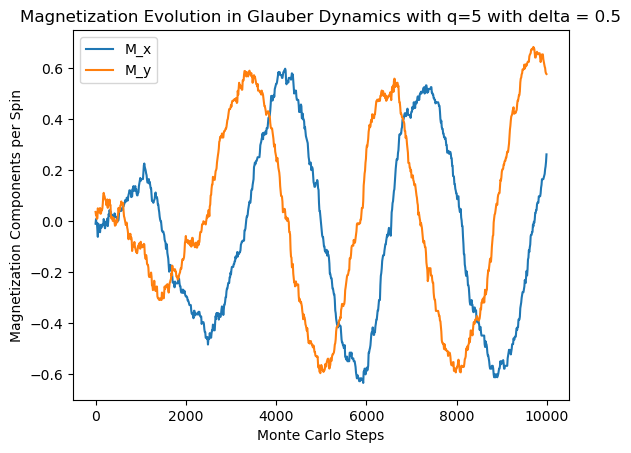

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
L = 10  # Lattice size
q = 5   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0.5  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles  # Return angles too

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:  # Nearest neighbors
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Chirality inside cosine
                H -= np.dot(h, sigma[i, j])  # External field term
    return H

# Compute average magnetization per spin
def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)  # Average magnetization vector
    return mag_vector

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="glauber"):
    """
    Perform a single Monte Carlo update using either Glauber or Metropolis dynamics.
    """
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    # Compute energy difference ΔE
    old_angle = angles[i, j]  # Current spin angle
    dE = 0

    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        
        # Corrected interaction term with chirality
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) - 
                        np.cos(new_angle - neighbor_angle + delta))

    # External field term
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    magnetization_vals = []

    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma))

    return np.array(magnetization_vals), spins, sigma, angles  # Return angles

# Run the Glauber simulation
magnetization_vals, spins, sigma, angles = run_simulation("glauber")

# Compute initial and final Hamiltonian
H_init = compute_hamiltonian(sigma, angles, J, h, delta)
M_init = compute_magnetization(sigma)
H_final = compute_hamiltonian(sigma, angles, J, h, delta)
M_final = compute_magnetization(sigma)

print("Initial Hamiltonian:", H_init)
print("Initial Magnetization per Spin:", M_init)
print("Final Hamiltonian:", H_final)
print("Final Magnetization per Spin:", M_final)

# Plot magnetization components over time
plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 0], label="M_x")
plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 1], label="M_y")
plt.xlabel("Monte Carlo Steps")
plt.ylabel("Magnetization Components per Spin")
plt.title("Magnetization Evolution in Glauber Dynamics with q=5 with delta = 0.5")
plt.legend()
plt.show()


Initial Hamiltonian: -77.5340210551346
Initial Magnetization per Spin: [-0.11       -0.03464102]
Final Hamiltonian: -77.5340210551346
Final Magnetization per Spin: [-0.11       -0.03464102]


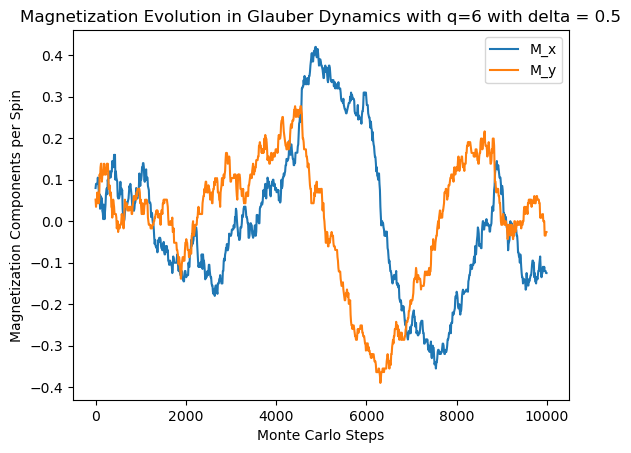

In [39]:

# Parameters
L = 10  # Lattice size
q = 6   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0.5  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles  # Return angles too

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:  # Nearest neighbors
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Chirality inside cosine
                H -= np.dot(h, sigma[i, j])  # External field term
    return H

# Compute average magnetization per spin
def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)  # Average magnetization vector
    return mag_vector

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule="glauber"):
    """
    Perform a single Monte Carlo update using either Glauber or Metropolis dynamics.
    """
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    # Compute energy difference ΔE
    old_angle = angles[i, j]  # Current spin angle
    dE = 0

    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:  # Nearest neighbors
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        
        # Corrected interaction term with chirality
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) - 
                        np.cos(new_angle - neighbor_angle + delta))

    # External field term
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    magnetization_vals = []

    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma))

    return np.array(magnetization_vals), spins, sigma, angles  # Return angles

# Run the Glauber simulation
magnetization_vals, spins, sigma, angles = run_simulation("glauber")

# Compute initial and final Hamiltonian
H_init = compute_hamiltonian(sigma, angles, J, h, delta)
M_init = compute_magnetization(sigma)
H_final = compute_hamiltonian(sigma, angles, J, h, delta)
M_final = compute_magnetization(sigma)

print("Initial Hamiltonian:", H_init)
print("Initial Magnetization per Spin:", M_init)
print("Final Hamiltonian:", H_final)
print("Final Magnetization per Spin:", M_final)

# Plot magnetization components over time
plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 0], label="M_x")
plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 1], label="M_y")
plt.xlabel("Monte Carlo Steps")
plt.ylabel("Magnetization Components per Spin")
plt.title("Magnetization Evolution in Glauber Dynamics with q=6 with delta = 0.5")
plt.legend()
plt.show()


### Calculating the Response Functions for different values of q and different lattice sizes
Magnetic Susceptibility is given by: $$\chi_{|M|}=\frac{1}{L^2}(<\vec{M}\cdot\vec{M}>-<\vec{M}>\cdot<\vec{M}>)$$
Specific Heat is given by: $$C = \frac{\beta^2}{L^2}(<E^2>-<E>^2)$$

In [56]:
import numpy as np

# Parameters
q = 5   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
steps = 10**6  # Total Monte Carlo steps
burn_in = 200000
L_values = [3, 4, 5, 6]  # Different lattice sizes to test
T_values = np.linspace(0.5, 3.0, 10)  # Temperature range
beta_values = 1 / T_values  # Inverse temperature

# Function to compute measure frequency
measure_every = lambda L: L**2

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles

# Compute total magnetization (vector)
def compute_magnetization(sigma):
    M_x = np.sum(sigma[:, :, 0])  # Sum over x-components
    M_y = np.sum(sigma[:, :, 1])  # Sum over y-components
    return np.array([M_x, M_y]) / (sigma.shape[0]**2)  # Normalize per spin

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta, L):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)
            H -= np.dot(h, sigma[i, j])
    return H

# Monte Carlo Step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)
    new_spin = np.random.randint(0, q)
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])
    old_angle = angles[i, j]
    
    dE = 0
    for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        dE += 2 * J * (np.cos(old_angle - neighbor_angle + delta) -
                        np.cos(new_angle - neighbor_angle + delta))
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    P_accept = 1 / (1 + np.exp(dE / T)) if update_rule == "glauber" else min(1, np.exp(-dE / T))
    
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []  # List to store magnetization vectors
    E_vals = []

    # Pre-thermalization (Burn-in)
    for _ in range(burn_in):  
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma)  # [M_x, M_y]
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)  # Convert list to NumPy array
    E_vals = np.array(E_vals)
    # Compute Observables
    m_avg = np.mean(m_vals, axis=0)  # ⟨M_x⟩, ⟨M_y⟩
    mod_m_avg = np.linalg.norm(m_avg)  # |⟨M⟩|
    m_sq_avg = np.mean(np.einsum('ij,ij->i', m_vals, m_vals))  # ⟨M ⋅ M⟩

    # Susceptibility
    chi_M = (m_sq_avg - mod_m_avg**2) / (L * L)

    # Energy calculations
    E_avg = np.mean(E_vals)
    E_sq_avg = np.mean(np.square(E_vals))
    
    # Heat capacity
    C_v = (E_sq_avg - E_avg**2) / (L**2 * T**2)

    return mod_m_avg, chi_M, C_v, E_avg

# Run simulations for different lattice sizes and temperatures
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        mod_m_avg, chi_M, C_v, E_avg = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(mod_m_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg)


Running simulations for T=0.50 (Beta=2.00)...
Running simulations for T=0.78 (Beta=1.29)...
Running simulations for T=1.06 (Beta=0.95)...
Running simulations for T=1.33 (Beta=0.75)...
Running simulations for T=1.61 (Beta=0.62)...
Running simulations for T=1.89 (Beta=0.53)...
Running simulations for T=2.17 (Beta=0.46)...
Running simulations for T=2.44 (Beta=0.41)...
Running simulations for T=2.72 (Beta=0.37)...
Running simulations for T=3.00 (Beta=0.33)...


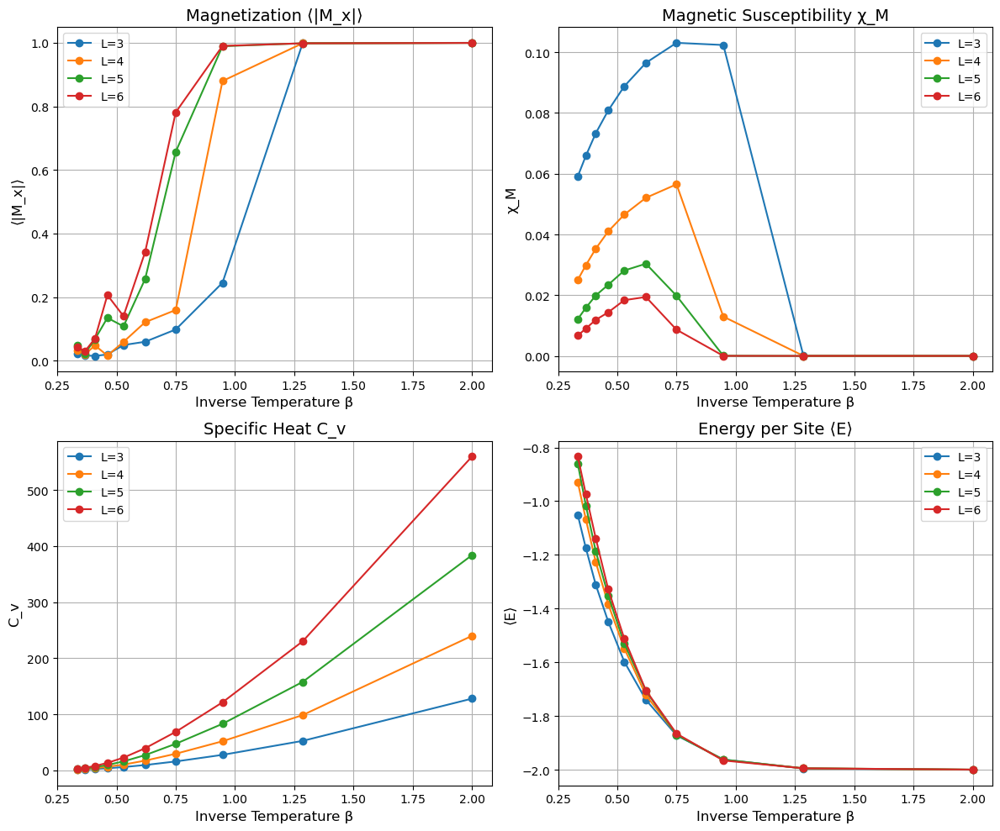

In [60]:
# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Titles and y-axis labels
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
          "Specific Heat C_v", "Energy per Site ⟨E⟩"]
y_labels = ["⟨|M_x|⟩", "χ_M", "C_v", "⟨E⟩"]

# Flatten axes array for easier indexing
axes = axes.flatten()

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "C_v", "E_avg"]):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")
    
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

# Adjust layout and show
plt.tight_layout()
plt.show()

#### New Change in energy formula (E_new - E_old)

In [104]:

# Parameters
q = 5   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
steps = 10**6  # Total Monte Carlo steps
burn_in = 200000
L_values = [4, 6, 8, 10, 12]  # Different lattice sizes to test
T_values = np.linspace(0.5, 3.0, 10)  # Temperature range

# Function to compute measure frequency
def measure_every(L):
    return L**2

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles

# Compute total magnetization (vector)
def compute_magnetization(sigma, L):
    return  np.sum(sigma, axis=(0, 1)) / (L * L)  # Normalize per spin

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta, L):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta) / 2  # Avoid double counting
        H -= np.dot(h, sigma[i, j]) # External field term
    return H

# Monte Carlo Step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)  # Pick a random site
    new_spin = np.random.randint(0, q)  # Pick a new random spin state
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    old_angle = angles[i, j]  # Current angle
    old_sigma = sigma[i, j]   # Current spin vector

    # Define neighbor sites with periodic boundaries
    neighbor_sites = [( (i+1) % L, j ), ( (i-1) % L, j ), ( i, (j+1) % L ), ( i, (j-1) % L )]

    # Compute old and new energy
    E_old = -J * sum(np.cos(old_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 
    E_new = -J * sum(np.cos(new_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 

    # Add external field term
    E_old -= np.dot(h, old_sigma)
    E_new -= np.dot(h, new_sigma)

    # Compute ΔE
    dE = E_new - E_old  

    # Compute acceptance probability (Glauber or Metropolis)
    beta = 1 / T
    P_accept = 1 / (1 + np.exp(beta * dE)) if update_rule == "glauber" else min(1, np.exp(-beta * dE))

    # Accept or reject the update
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma  # Update spin vector

# Run simulation
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []  # List to store magnetization vectors
    E_vals = []

    # Pre-thermalization (Burn-in)
    for _ in range(burn_in):  
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)  # [M_x, M_y]
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)  # Convert list to NumPy array
    E_vals = np.array(E_vals)
   # Mean magnetization vector
    m_avg = np.mean(m_vals, axis=0)  # ⟨M_x⟩, ⟨M_y⟩
    # Compute mean magnitude of magnetization
    mod_m_avg = np.mean(np.linalg.norm(m_vals, axis=1))  # ⟨|M|⟩
    # Compute ⟨M ⋅ M⟩
    m_sq_avg = np.mean(np.sum(m_vals**2, axis=1))  # ⟨M ⋅ M⟩

    # Susceptibility (corrected formula)
    chi_M = (m_sq_avg - mod_m_avg**2) / (L * L)

    # Energy calculations
    E_avg = np.mean(E_vals)
  
    E_sq_avg = np.mean(np.square(E_vals))
    
    # Heat capacity
    C_v = (E_sq_avg - E_avg**2) / (L**2 * T**2)

    return mod_m_avg, chi_M, C_v, E_avg

# Run simulations for different lattice sizes and temperatures
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        mod_m_avg, chi_M, C_v, E_avg = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(mod_m_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg)


Running simulations for T=0.50 (Beta=2.00)...
Running simulations for T=0.78 (Beta=1.29)...
Running simulations for T=1.06 (Beta=0.95)...
Running simulations for T=1.33 (Beta=0.75)...
Running simulations for T=1.61 (Beta=0.62)...
Running simulations for T=1.89 (Beta=0.53)...
Running simulations for T=2.17 (Beta=0.46)...
Running simulations for T=2.44 (Beta=0.41)...
Running simulations for T=2.72 (Beta=0.37)...
Running simulations for T=3.00 (Beta=0.33)...


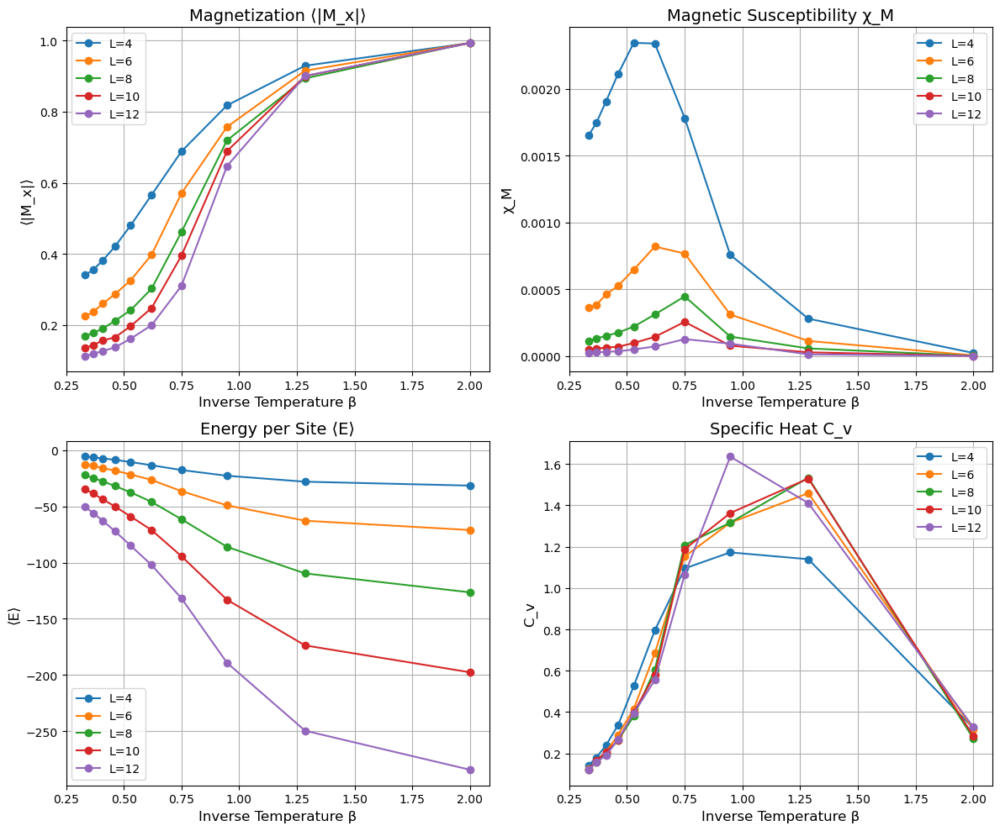

In [106]:
# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Titles and y-axis labels
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
         "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

# Flatten axes array for easier indexing
axes = axes.flatten()

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")
    
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

# Adjust layout and show
plt.tight_layout()
plt.show()

In [47]:
# Parameters
q = 6   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
steps = 10**6  # Total Monte Carlo steps
burn_in = 200000
L_values = [4, 6, 8, 10, 12]  # Different lattice sizes to test
T_values = np.linspace(0.5, 3.0, 10)  # Temperature range

# Function to compute measure frequency
def measure_every(L):
    return L**2

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles

# Compute total magnetization (vector)
def compute_magnetization(sigma, L):
    return  np.sum(sigma, axis=(0, 1)) / (L * L)  # Normalize per spin

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta, L):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta) / 2  # Avoid double counting
        H -= np.dot(h, sigma[i, j]) # External field term
    return H

# Monte Carlo Step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)  # Pick a random site
    new_spin = np.random.randint(0, q)  # Pick a new random spin state
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    old_angle = angles[i, j]  # Current angle
    old_sigma = sigma[i, j]   # Current spin vector

    # Define neighbor sites with periodic boundaries
    neighbor_sites = [( (i+1) % L, j ), ( (i-1) % L, j ), ( i, (j+1) % L ), ( i, (j-1) % L )]

    # Compute old and new energy
    E_old = -J * sum(np.cos(old_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 
    E_new = -J * sum(np.cos(new_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 

    # Add external field term
    E_old -= np.dot(h, old_sigma)
    E_new -= np.dot(h, new_sigma)

    # Compute ΔE
    dE = E_new - E_old  

    # Compute acceptance probability (Glauber or Metropolis)
    beta = 1 / T
    P_accept = 1 / (1 + np.exp(beta * dE)) if update_rule == "glauber" else min(1, np.exp(-beta * dE))

    # Accept or reject the update
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma  # Update spin vector

# Run simulation
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []  # List to store magnetization vectors
    E_vals = []
    burn_in = 500000 if L >= 10 else 200000  # More steps for large L
    # Pre-thermalization (Burn-in)
    for _ in range(burn_in):  
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)  # [M_x, M_y]
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)  # Convert list to NumPy array
    E_vals = np.array(E_vals)
   # Mean magnetization vector
    m_avg = np.mean(m_vals, axis=0)  # ⟨M_x⟩, ⟨M_y⟩
    # Compute mean magnitude of magnetization
    mod_m_avg = np.mean(np.linalg.norm(m_vals, axis=1))  # ⟨|M|⟩
    # Compute ⟨M ⋅ M⟩
    m_sq_avg = np.mean(np.sum(m_vals**2, axis=1))  # ⟨M ⋅ M⟩

    # Susceptibility (corrected formula)
    chi_M = (m_sq_avg - mod_m_avg**2) / (L * L)

    # Energy calculations
    E_avg = np.mean(E_vals)
  
    E_sq_avg = np.mean(np.square(E_vals))
    
    # Heat capacity
    C_v = (E_sq_avg - E_avg**2) / (L**2 * T**2)

    return mod_m_avg, chi_M, C_v, E_avg

# Run simulations for different lattice sizes and temperatures
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        mod_m_avg, chi_M, C_v, E_avg = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(mod_m_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg)


Running simulations for T=0.50 (Beta=2.00)...


KeyboardInterrupt: 

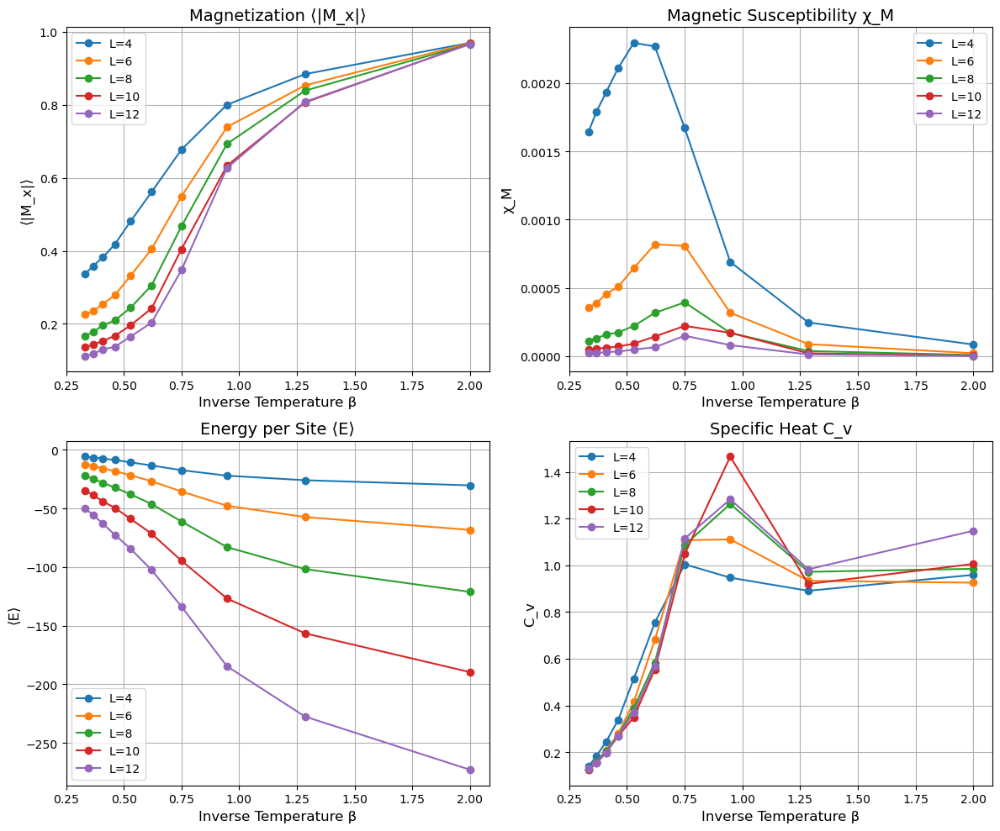

In [23]:
# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Titles and y-axis labels
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
         "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

# Flatten axes array for easier indexing
axes = axes.flatten()

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")
    
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

# Adjust layout and show
plt.tight_layout()
plt.show()

### Testing for different formulas of magnetic susceptibility specifically, changing the scaling by multiplying by L**2 insstead of dividing


### Four Response Functions of q=3 state Clock model (Cluster Alg.)

In [3]:

# Parameters
J = 1.0  # Interaction strength
h = 0  # External field
q = 3
sweeps = 5*10**4  # Total Monte Carlo steps
#burn_frac = 2**18
L_values = [16, 24, 32, 48, 64]  # Different lattice sizes to test

# Temperature range
#L = 16
# Temperature range
#beta_core = np.linspace(0.2, 1.0, 8)
#delta_beta = beta_core[1] - beta_core[0]
#beta_extra_low = beta_core[0] - delta_beta
#beta_extra_high = beta_core[-1] + delta_beta
#beta_values = np.concatenate([[beta_extra_low], beta_core, [beta_extra_high]])
T_values = np.linspace(1.4, 1.6, 10)
#T_values = np.linspace(1.2, 1.9, 10)
beta_values = 1/T_values

In [5]:
import numpy as np

# -------------------------------
# Initial configuration
# -------------------------------
def new_state(L, q=3):
    return np.random.randint(0, q, size=(L, L))


# -------------------------------
# CLOCK MODEL ENERGY
# -------------------------------
def E(spins, J=1.0, q=3):
    L = spins.shape[0]
    energy_val = 0.0

    for x in range(L):
        for y in range(L):
            si = spins[x, y]
            for dx, dy in [(1, 0), (0, 1)]:
                nx, ny = (x + dx) % L, (y + dy) % L
                sj = spins[nx, ny]
                energy_val -= J * np.cos(2 * np.pi * (si - sj) / q)

    return energy_val


# -------------------------------
# VECTOR MAGNETIZATION (UNCHANGED)
# -------------------------------

def magnetization(spins, q=3):
    angles = 2 * np.pi * np.arange(q) / q
    cos_vals = np.cos(angles)
    sin_vals = np.sin(angles)

    spins = np.asarray(spins)  # safety
    Mx = np.sum(cos_vals[spins])
    My = np.sum(sin_vals[spins])

    return np.array([Mx, My])


# -------------------------------
# WOLFF CLUSTER (q=3 CLOCK)
# -------------------------------
def wolff_cluster_q3_vector(spins, T, J=1.0):
    L = spins.shape[0]
    beta = 1.0 / T
    q = 3

    # --- reflections: k -> (a - k) mod 3 ---
    reflections = [
        lambda k: (-k) % q,
        lambda k: (1 - k) % q,
        lambda k: (2 - k) % q
    ]
    # Dihedral symmetry so each reflection fixes one spin while swapping the other two
    reflect = np.random.choice(reflections)

    # --- vector representation ---
    angles = 2 * np.pi * np.arange(q) / q
    vec = np.column_stack((np.cos(angles), np.sin(angles)))

    # --- choose seed to pick one of the three axes---
    x0, y0 = np.random.randint(0, L, size=2)
    orig = spins.copy() #store original configuration for cluster growth

    cluster = {(x0, y0)} # accepted sites
    pocket = [(x0, y0)] # frontier for grwoth

    # --- grow cluster ---
    while pocket:
        x, y = pocket.pop()
        si = orig[x, y]
        theta_i = angles[si]
        theta_i_ref = angles[reflect(si)]

        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x + dx) % L, (y + dy) % L
            if (nx, ny) in cluster:
                continue # avoid revisiting sites

            sj = orig[nx, ny]
            theta_j = angles[sj]

            # Energy difference for clock model (Bond probability of Wolff)
            delta = (
                np.cos(theta_i - theta_j)
                -
                np.cos(theta_i_ref - theta_j)
            )

            if delta > 0:
                p = 1 - np.exp(-beta * J * delta)
                if np.random.rand() < p:
                    cluster.add((nx, ny))
                    pocket.append((nx, ny))

    # --- flip cluster ---
    for x, y in cluster:
        spins[x, y] = reflect(orig[x, y]) # apply the same reflection to the entire cluster
 
    return spins, len(cluster)


def global_rotate(spins, q): # Rotate the entire circle for ergodicity (restores full group sampling)
    r = np.random.randint(0, q)
    return (spins + r) % q # moves configuration between degenerate symmetry sectors

# -------------------------------
# MAIN SIMULATION
# -------------------------------
def run_simulation(L, T, sweeps=10**6, J=1.0, q=3, burn_frac=0.3,sample_interval=1):
    spins = new_state(L, q)
    E_arr, M_arr = [], []
    burn_steps = int(burn_frac * sweeps)

    for sweep in range(sweeps):
        

        flipped = 0
        while flipped < L**2:
            spins, csize = wolff_cluster_q3_vector(spins, T, J)
            spins = global_rotate(spins, q)
            flipped += csize

        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            M_arr.append(magnetization(spins, q))
            E_arr.append(E(spins, J, q))
    M_arr = np.array(M_arr)
    #E_arr = np.array(E_arr)
    Mx = M_arr[:, 0]
    My = M_arr[:, 1]

    #Mx_mean = np.mean(Mx)
    #My_mean = np.mean(My)

    #Mx2_mean = np.mean(Mx**2)
    #My2_mean = np.mean(My**2)

    #chi_M =  (
    #Mx2_mean + My2_mean
    #- Mx_mean**2 - My_mean**2)/ (L**2 * T)
    M_mag = np.sqrt(Mx**2+My**2) 
    M_avg_per_site = np.mean(M_mag) / L**2
   
    M_mag_mean = np.mean(M_mag)
    M_mag2_mean = np.mean(M_mag**2)

    chi_M = (M_mag2_mean - M_mag_mean**2) / (L**2 * T)

    #E_avg = np.mean(E_arr)
    #E_sq_avg = np.mean(E_arr**2)
    #E_avg_per_site = E_avg/L**2
    #C_v = (E_sq_avg - E_avg**2)/(L**2*T**2)
    return M_avg_per_site, chi_M#, E_avg_per_site, C_v

In [47]:
import numpy as np
# Clock model parameters
q = 3
ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# Reflection table: REFLECT[r, k] = reflected spin
# Removes module operations inside the loop
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)]
])

# -------------------------------
# Initial configuration
# -------------------------------
def new_state(L, q=3):
    return np.random.randint(0, q, size=(L, L))


# -------------------------------
# CLOCK MODEL ENERGY
# -------------------------------
def energy(spins, J=1.0):
    L = spins.shape[0]
    E = 0.0
    for x in range(L):
        for y in range(L):
            si = spins[x, y]
            sj = spins[(x+1) % L, y]
            sk = spins[x, (y+1) % L]
            E -= J * (np.cos(ANGLES[si] - ANGLES[sj]) +
                      np.cos(ANGLES[si] - ANGLES[sk]))
    return E



# -------------------------------
# VECTOR MAGNETIZATION (UNCHANGED)
# -------------------------------
def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My


# -------------------------------
# WOLFF CLUSTER (q=3 CLOCK)
# -------------------------------
def wolff_cluster_q3(spins, beta, E, J=1.0):
    L = spins.shape[0]
    visited = np.zeros((L, L), dtype=bool)

    r = np.random.randint(0, q)
    x0, y0 = np.random.randint(0, L, size=2)

    stack = [(x0, y0)]
    visited[x0, y0] = True
    cluster = []

    dE = 0.0

    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]
        ti = ANGLES[si]
        ti_ref = ANGLES[si_ref]

        for dx, dy in [(1,0),(-1,0),(0,1),(0,-1)]:
            nx, ny = (x+dx)%L, (y+dy)%L
            sj = spins[nx, ny]
            tj = ANGLES[sj]

            if not visited[nx, ny]:
                delta = np.cos(ti - tj) - np.cos(ti_ref - tj)
                if delta > 0 and np.random.rand() < 1 - np.exp(-beta * J * delta):
                    visited[nx, ny] = True
                    stack.append((nx, ny))
            else:
                # bond inside cluster → ignore
                pass

    # boundary energy change
    for x, y in cluster:
        si = spins[x, y]
        si_ref = REFLECT[r, si]
        ti = ANGLES[si]
        ti_ref = ANGLES[si_ref]

        for dx, dy in [(1,0),(0,1)]:
            nx, ny = (x+dx)%L, (y+dy)%L
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                tj = ANGLES[sj]
                dE += J * (np.cos(ti - tj) - np.cos(ti_ref - tj))

    # flip
    for x, y in cluster:
        spins[x, y] = REFLECT[r, spins[x, y]]

    return len(cluster), E + dE

def global_rotate(spins, q): # Rotate the entire circle for ergodicity (restores full group sampling)
    r = np.random.randint(0, q)
    return (spins + r) % q # moves configuration between degenerate symmetry sectors

# -------------------------------
# MAIN SIMULATION
# ----------------------------
def run_simulation(
    L,
    T,
    sweeps= 10**5,
    burn_frac=0.2,
    sample_interval=10,
    J=1.0
):
    beta = 1.0 / T
    spins = new_state(L)

    burn_steps = int(burn_frac * sweeps)

    Mmag_samples = []
    #E_samples = []
    E = energy(spins, J)
    for sweep in range(sweeps):

        flipped = 0
        while flipped < L * L:
            csize, E = wolff_cluster_q3(spins, beta, E, J)
            flipped += csize

        # One global rotation per sweep (important!)
        global_rotate(spins,q)

        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            Mx, My = magnetization(spins)
            Mmag_samples.append(np.sqrt(Mx**2 + My**2))
            # Optional: comment out if slow
            E_samples.append(E)
    E_arr = np.array(E_samples)
    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)
    E_avg_per_site = E_avg/L**2
    C_v = (E_sq_avg - E_avg**2)/(L**2*T**2)
    Mmag = np.array(Mmag_samples)

    M_mean = np.mean(Mmag)
    M2_mean = np.mean(Mmag**2)

    chi_M = (M2_mean - M_mean**2) / (L**2 * T)
    M_avg_per_site = M_mean / (L**2)

    return M_avg_per_site, chi_M, E_avg_per_site, C_v


In [5]:
import numpy as np
# OPTIMIZE
# ============================================================
# q = 3 CLOCK MODEL (OPTIMIZED FOR SPEED)
# ============================================================

q = 3
J = 1.0

# Pre-computing spin angles
ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)
# cos(theta_i - theta_j) lookup.Precomputed result is stored in memory instead of computing cosine everytime
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# ------------------------------------------------------------
# Precompute interaction matrix:
# E_bond[s_i, s_j] = -J cos(theta_i - theta_j)
# ------------------------------------------------------------
E_BOND = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        E_BOND[i, j] = -J * np.cos(ANGLES[i] - ANGLES[j])

# ------------------------------------------------------------
# Reflection table
# ------------------------------------------------------------
# Removes module operations inside the loop
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================
def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# MAGNETIZATION (vector)
# ============================================================
def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1)%L, y]
            s_up = spins[x, (y+1)%L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E
# ============================================================
# WOLFF CLUSTER (FULLY OPTIMIZED)
# ============================================================
def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    #visited = np.zeros((L, L), dtype=bool)
    visited.fill(False) # Reuses same memory only overwrites values
    # random reflection axis
    r = np.random.randint(0, q)

    # random seed
    x0, y0 = np.random.randint(0, L, size=2)
    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0

    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        # 4 neighbors
        for nx, ny in (
            ((x+1)%L, y),
            ((x-1)%L, y),
            (x, (y+1)%L),
            (x, (y-1)%L),
        ):

            sj = spins[nx, ny]

            if not visited[nx, ny]:

            # correct embedding delta (NO bond energy!)
                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))

    # --------------------------------------------------------
    # Boundary energy and magnetization correction
    # --------------------------------------------------------
    
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]
        for nx, ny in (
            ((x+1)%L, y),
            ((x-1)%L, y),
            (x, (y+1)%L),
            (x, (y-1)%L),
        ):

        
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])

    # Flip cluster
    for x, y in cluster:
        spins[x, y] = REFLECT[r, spins[x, y]]

    return len(cluster), E_current + dE #Instead of recomputing total energy each sweep


# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================
def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q


# ============================================================
# MAIN SIMULATION
# ============================================================
def run_simulation(
    L,
    T,
    sweeps=10**5,
    J = 1,
    burn_frac=0.2,
    sample_interval = 1
    
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L,L), dtype=bool)
    # Initial full energy (computed once only)
    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        #flipped = 0
        #while flipped < L * L:
        csize, E = wolff_cluster_q3(spins, beta, E, visited)
            #flipped += csize

        global_rotate(spins)

        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:

            Mx, My = magnetization(spins)
            M_samples.append(np.sqrt(Mx**2 + My**2))

            E_samples.append(E)

    # --------------------------------------------------------
    # Observables
    # --------------------------------------------------------
    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)

    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v


In [13]:
import numpy as np

# ============================================================
# PARAMETERS
# ============================================================

q = 3
J = 1.0

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# Reflection table
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# TOTAL ENERGY (computed once)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E


# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    # Random reflection axis
    r = np.random.randint(0, q)

    # Random seed
    x0, y0 = np.random.randint(0, L, size=2)
    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # -----------------------------
    # Grow cluster
    # -----------------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))

    # -----------------------------
    # Boundary energy correction
    # -----------------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):

            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])

    # -----------------------------
    # Flip cluster + update magnetization
    # -----------------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref

    return len(cluster), E_current + dE, dMx, dMy


# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r


# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=10**5,
    J=J,
    burn_frac=0.2,
    sample_interval=1
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L, L), dtype=bool)

    # Initial observables
    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        _, E, dMx, dMy = wolff_cluster_q3(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        # Rotate magnetization accordingly
        angle = ANGLES[r]
        Mx_new = Mx * np.cos(angle) - My * np.sin(angle)
        My_new = Mx * np.sin(angle) + My * np.cos(angle)
        Mx, My = Mx_new, My_new

        # --- Measurements
        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ============================================================
    # Observables
    # ============================================================

    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)

    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v


In [5]:
import numpy as np

# ============================================================
# PARAMETERS
# ============================================================

q = 3
J = 1.0

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# Reflection table
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# TOTAL ENERGY (computed once)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E


# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    r = np.random.randint(0, q)

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ----------------------
    # Grow cluster ONLY
    # ----------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))
       # ----------------------
    # Boundary correction
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])
    # ----------------------
    # Flip + magnetization
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref


    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r


# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=10**5,
    J=J,
    burn_frac=0.2,
    sample_interval=1
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L, L), dtype=bool)

    # Initial observables
    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster_q3(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        # Rotate magnetization accordingly
        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c
    
        # --- Measurements
        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ============================================================
    # Observables
    # ============================================================

    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    
    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v


In [33]:
# Storage
results = {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    M_avg_per_site, chi_M = run_simulation(L, T, sweeps=10**5, J=1, burn_frac=0.2)
    results["M_x"].append(M_avg_per_site)   
    results["chi_M"].append(chi_M)

Running simulations for T=11.67 (Beta=0.09)...
Running simulations for T=5.00 (Beta=0.20)...
Running simulations for T=3.18 (Beta=0.31)...
Running simulations for T=2.33 (Beta=0.43)...
Running simulations for T=1.84 (Beta=0.54)...
Running simulations for T=1.52 (Beta=0.66)...
Running simulations for T=1.30 (Beta=0.77)...
Running simulations for T=1.13 (Beta=0.89)...
Running simulations for T=1.00 (Beta=1.00)...
Running simulations for T=0.90 (Beta=1.11)...


In [7]:
import time 
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "time": []} for L in L_values}

for T in T_values:
    print(f"\nRunning simulations for T = {T:.3f} (β = {1/T:.3f})...")
    for L in L_values:
        start_time = time.time()  # ⏱ start timer

        M_avg_per_site, chi_M, E_avg_per_site, C_v = run_simulation(
            L, T, sweeps=sweeps, J=J, burn_frac=0.2
        )

        end_time = time.time()
        elapsed = end_time - start_time
 
        results[L]["M_x"].append(M_avg_per_site)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site) 
        results[L]["time"].append(elapsed) 
        
        print(f"  L={L:2d} → done in {elapsed/60: .2f} min | M={M_avg_per_site:.4f}, χ={chi_M:.4e}")
# Convert lists to arrays
for L in L_values:
    for key in results[L]:
        results[L][key] = np.array(results[L][key])

# Save everything
save_dict = {
    "T_values": np.array(T_values),
    "L_values": np.array(L_values)
}

for L in L_values:
    for key in results[L]:
        save_dict[f"L{L}_{key}"] = results[L][key]

np.savez_compressed("clock_q3_simulationoptresolved_data.npz", **save_dict)

print("\nData saved successfully.")


Running simulations for T = 1.250 (β = 0.800)...
  L=16 → done in  2.52 min | M=0.9538, χ=1.3182e-01
  L=32 → done in  8.71 min | M=0.9535, χ=1.3243e-01
  L=64 → done in  34.07 min | M=0.9534, χ=1.3387e-01

Running simulations for T = 1.333 (β = 0.750)...
  L=16 → done in  2.14 min | M=0.9242, χ=2.9600e-01
  L=32 → done in  8.16 min | M=0.9234, χ=3.0346e-01
  L=64 → done in  32.19 min | M=0.9235, χ=3.0384e-01

Running simulations for T = 1.417 (β = 0.706)...
  L=16 → done in  1.94 min | M=0.8663, χ=1.0113e+00
  L=32 → done in  21.65 min | M=0.8647, χ=1.0778e+00
  L=64 → done in  90.89 min | M=0.8640, χ=1.1215e+00

Running simulations for T = 1.500 (β = 0.667)...
  L=16 → done in  4.22 min | M=0.6897, χ=5.5725e+00
  L=32 → done in  5.87 min | M=0.5912, χ=2.2833e+01
  L=64 → done in  10.29 min | M=0.4670, χ=9.0376e+01

Running simulations for T = 1.583 (β = 0.632)...
  L=16 → done in  0.58 min | M=0.3972, χ=6.0989e+00
  L=32 → done in  0.63 min | M=0.1986, χ=7.2764e+00
  L=64 → done in 

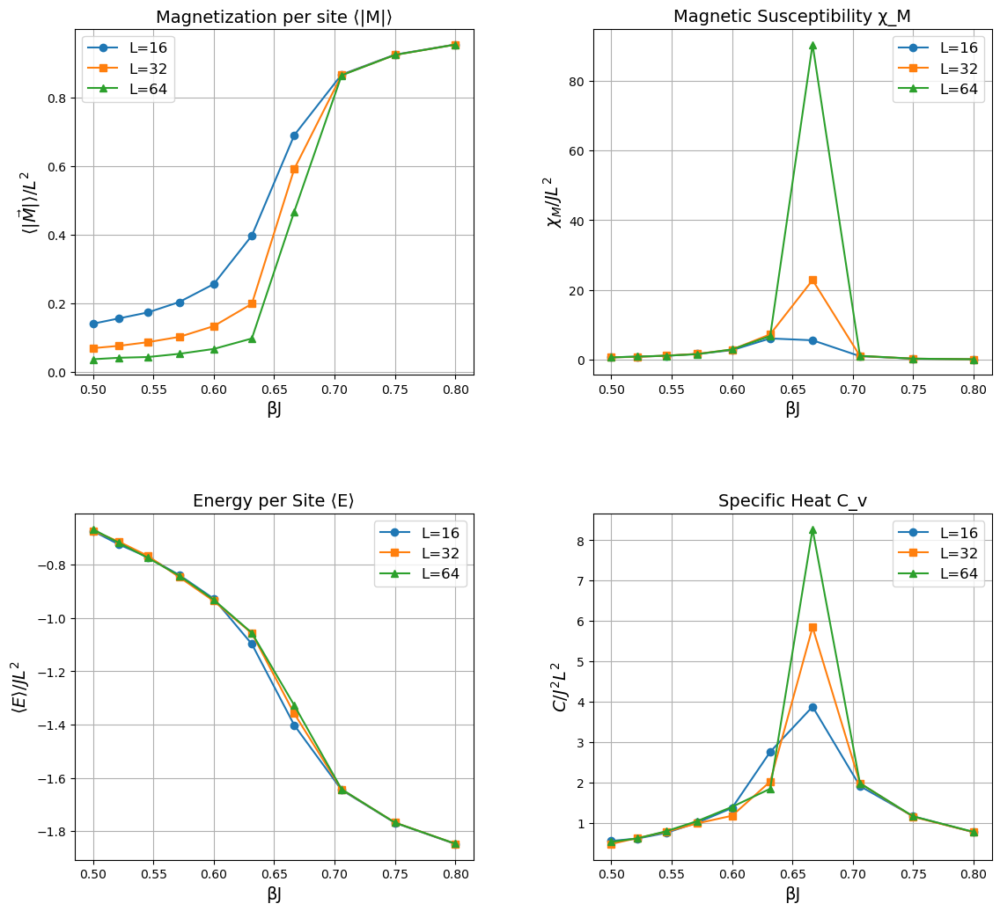

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockOptResolved3-state-8-64.png")
plt.show()


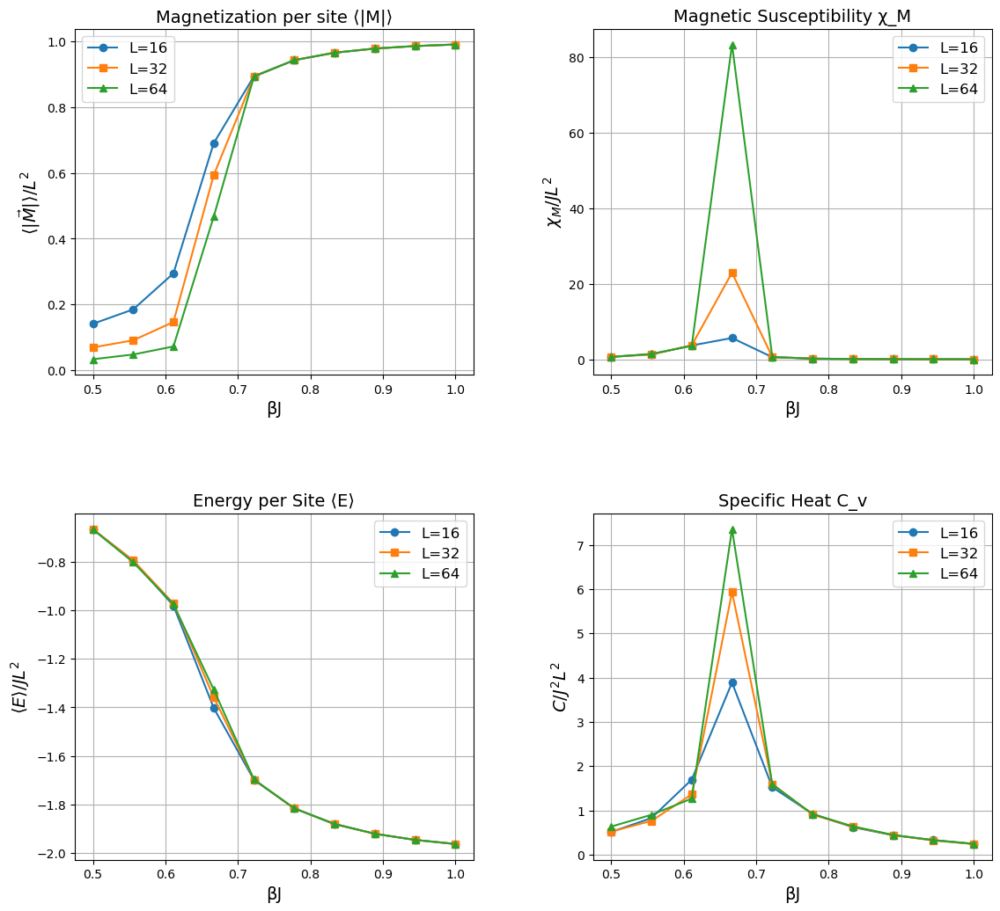

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockOpt3-state-8-64.png")
plt.show()


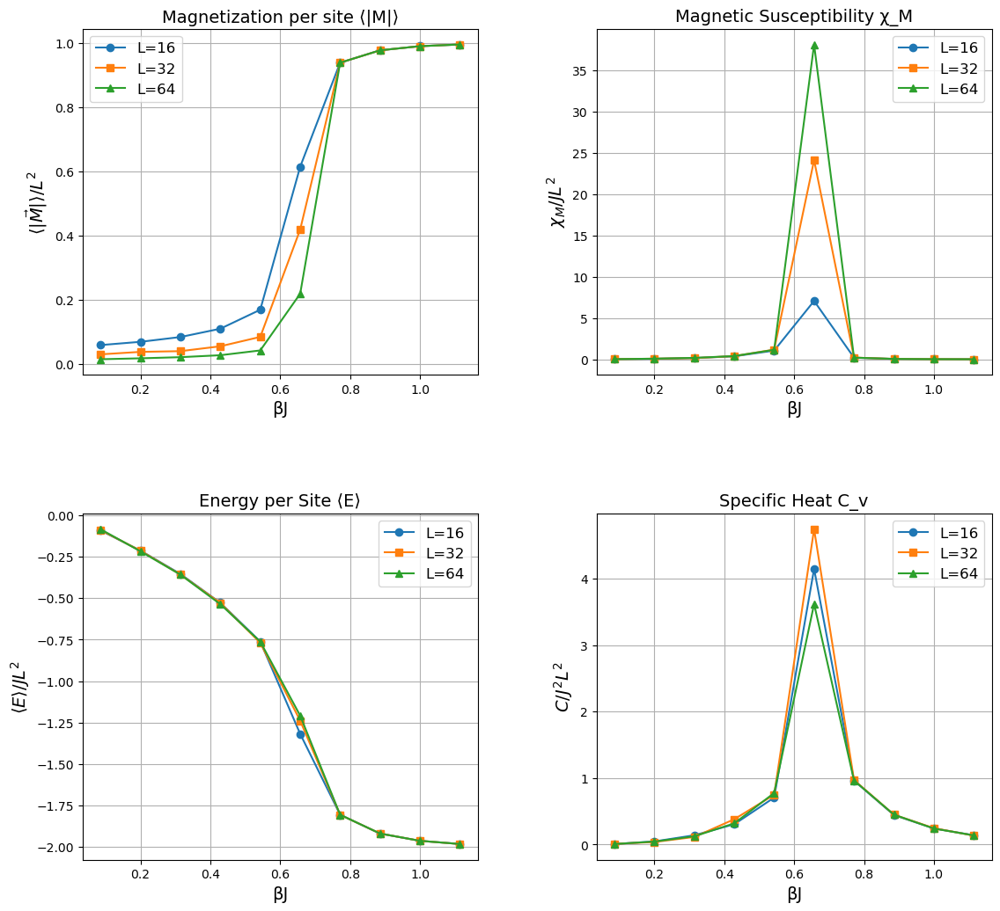

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClock3-state-8-64.png")
plt.show()


Slope (γ/ν) = 1.2155
Intercept = -1.2872
R² = 0.9351


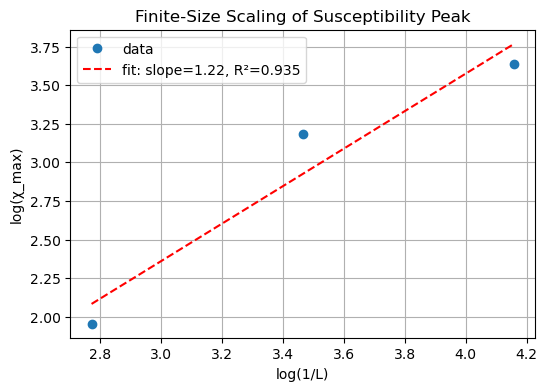

In [15]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi_M"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = -np.log(1/L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(1/L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.savefig("FSSClockq3-16-64.png")
plt.grid(True)
plt.show()

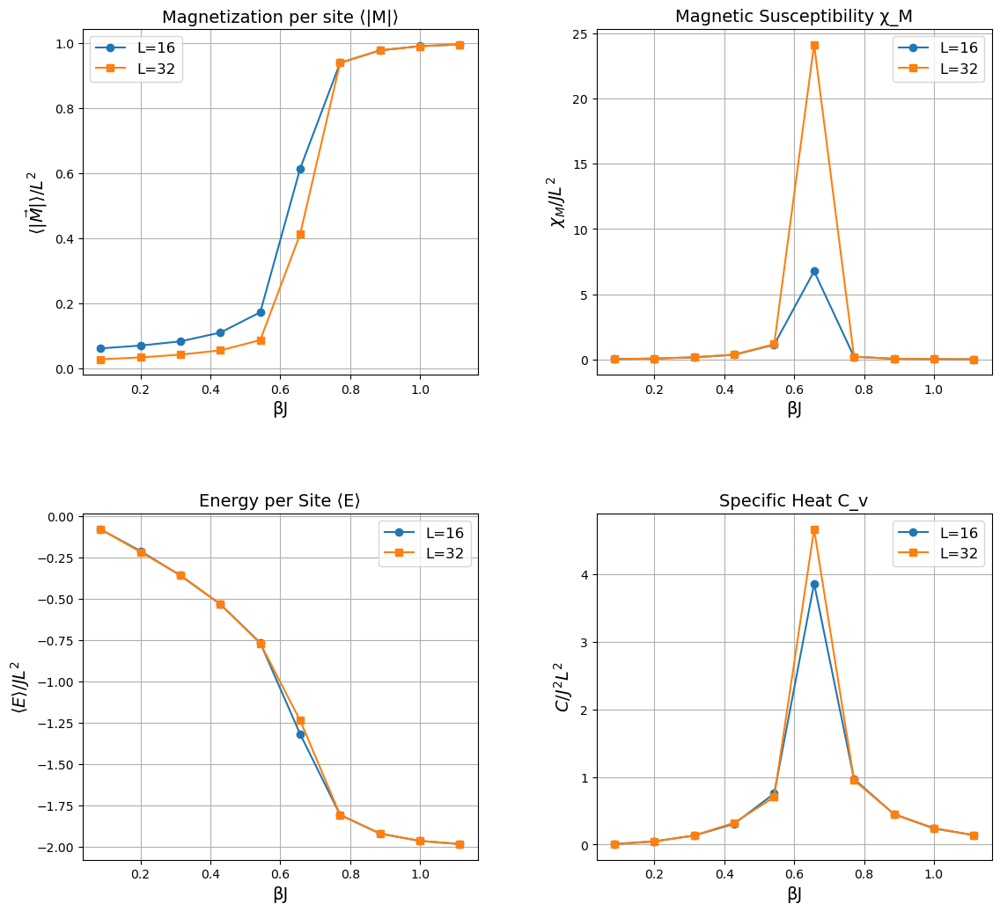

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


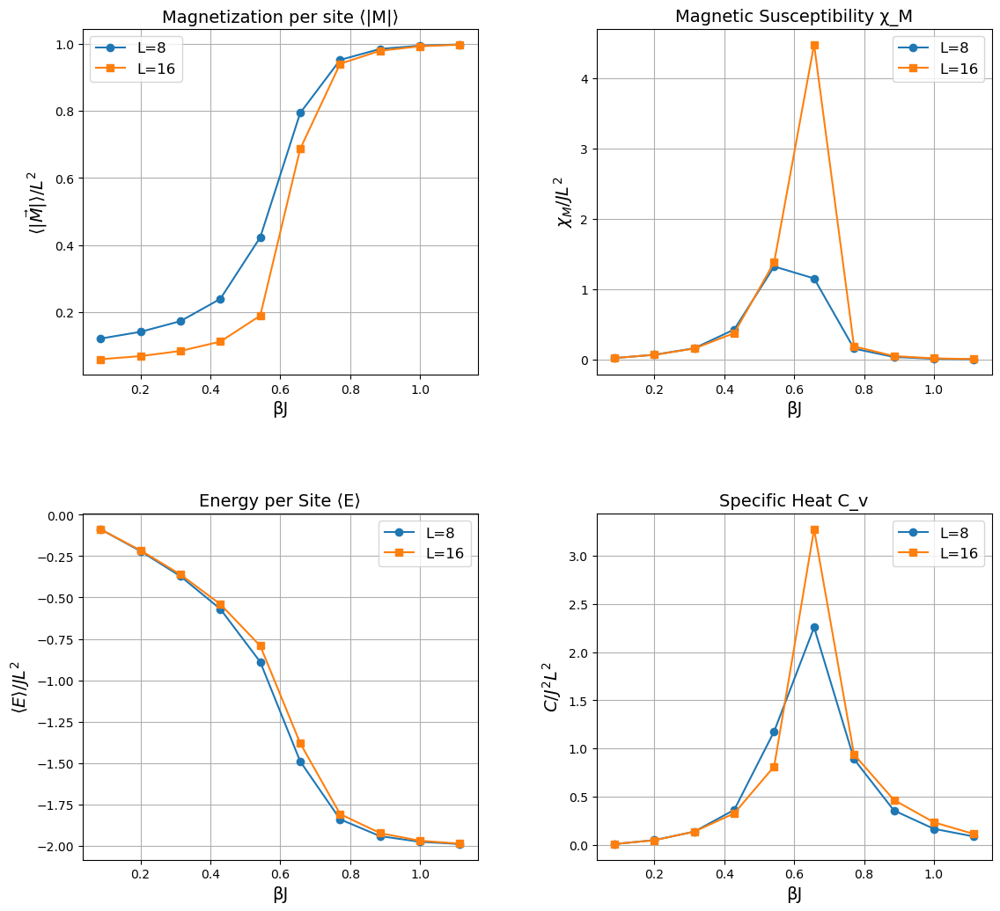

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


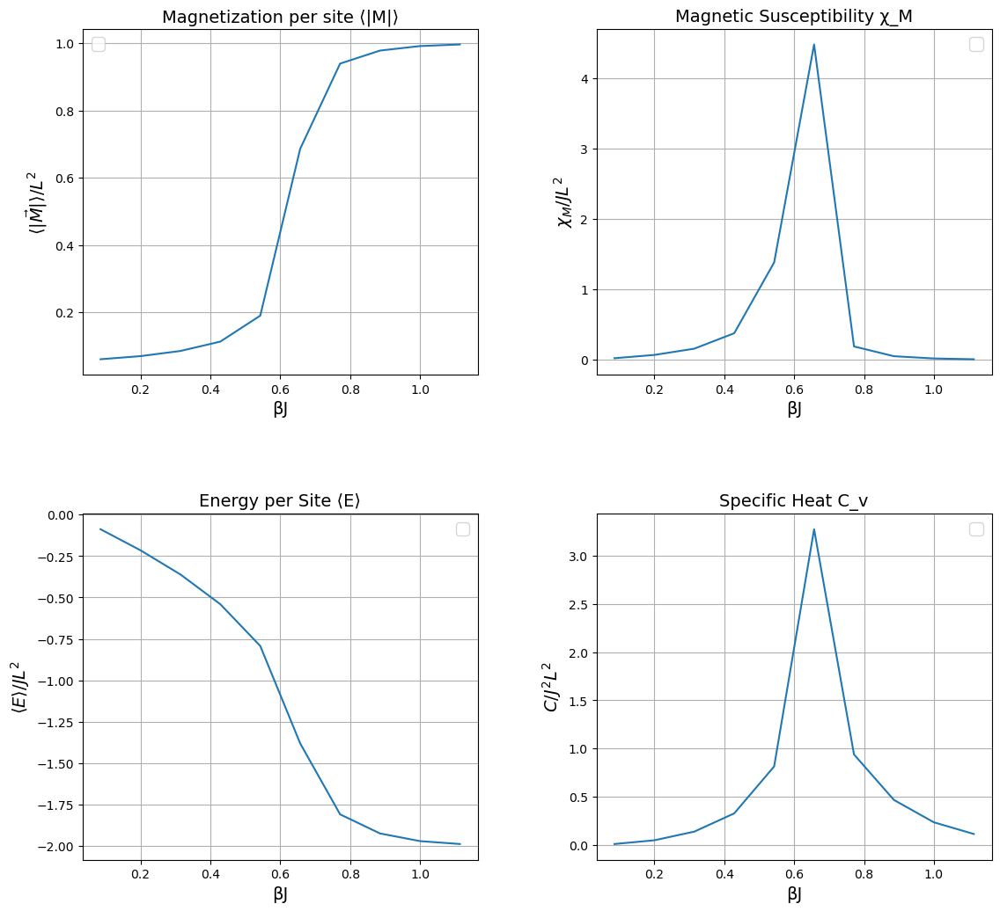

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()

# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    ax.plot(beta_values, results[L][key])
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


ValueError: x and y must have same first dimension, but have shapes (10,) and (0,)

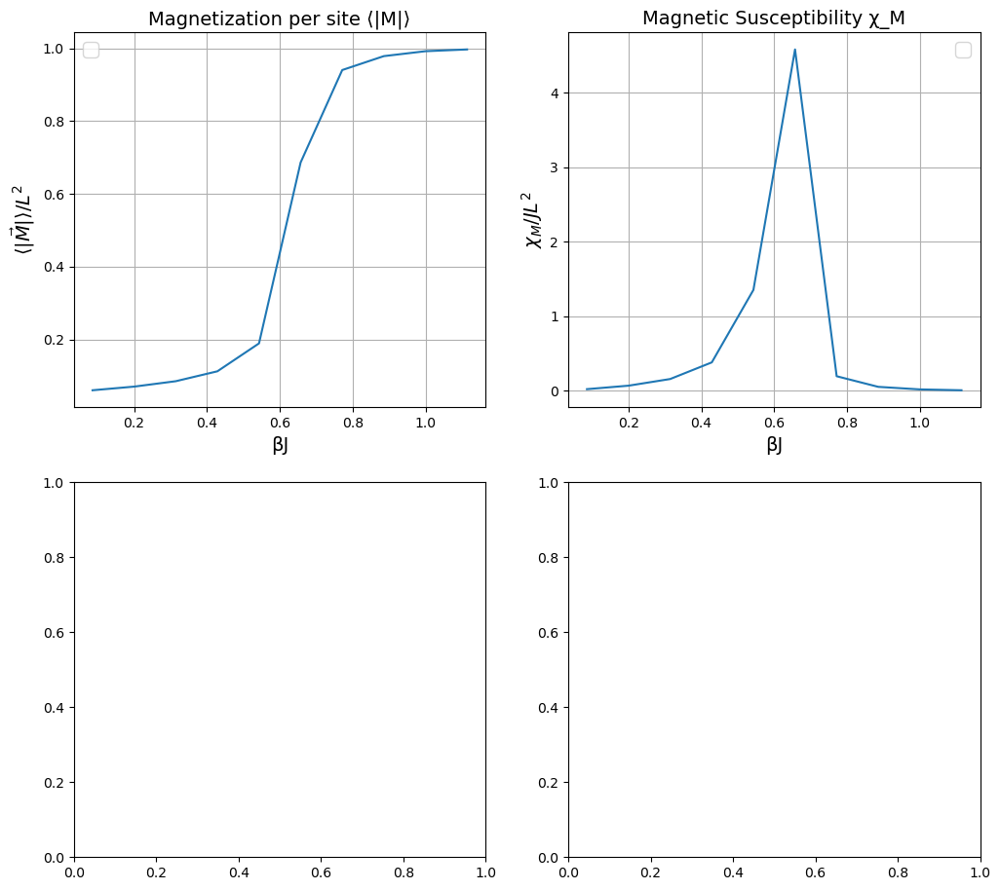

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    ax.plot(beta_values, results[key])
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

In [25]:
print(results)
print(results.keys())

{8: {'M_x': [0.12219191432760991, 0.14220841926622005, 0.17395197307396743, 0.24026470687532037, 0.42346107881003675, 0.7934618398573047, 0.9513724981785313, 0.9839764919674394, 0.993726407372336, 0.9973077275277983], 'chi_M': [0.022069495118062166, 0.06924377014447805, 0.16157577128789408, 0.4284428779081923, 1.3237005885643278, 1.1541509598625483, 0.15643069951673774, 0.0373839696983148, 0.012743134115694943, 0.00541528803625064], 'C_v': [0.0076814516417709755, 0.04797891483398436, 0.13624818965242344, 0.3620225192871093, 1.1769585950852512, 2.257016278097048, 0.88857633528854, 0.35568547049141414, 0.16546210839842956, 0.08611231037903], 'E_avg': [-0.08762597656249997, -0.219705078125, -0.3712109375, -0.569509765625, -0.8896689453125, -1.4902021484375, -1.8404345703125, -1.9419892578125, -1.97617578125, -1.9895673828125], 'time': [869.3504617214203, 559.4870843887329, 506.34986639022827, 118.59755849838257, 129.708420753479, 132.64300298690796, 119.76401877403259, 92.17771458625793, 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


ValueError: x and y must have same first dimension, but have shapes (10,) and (0,)

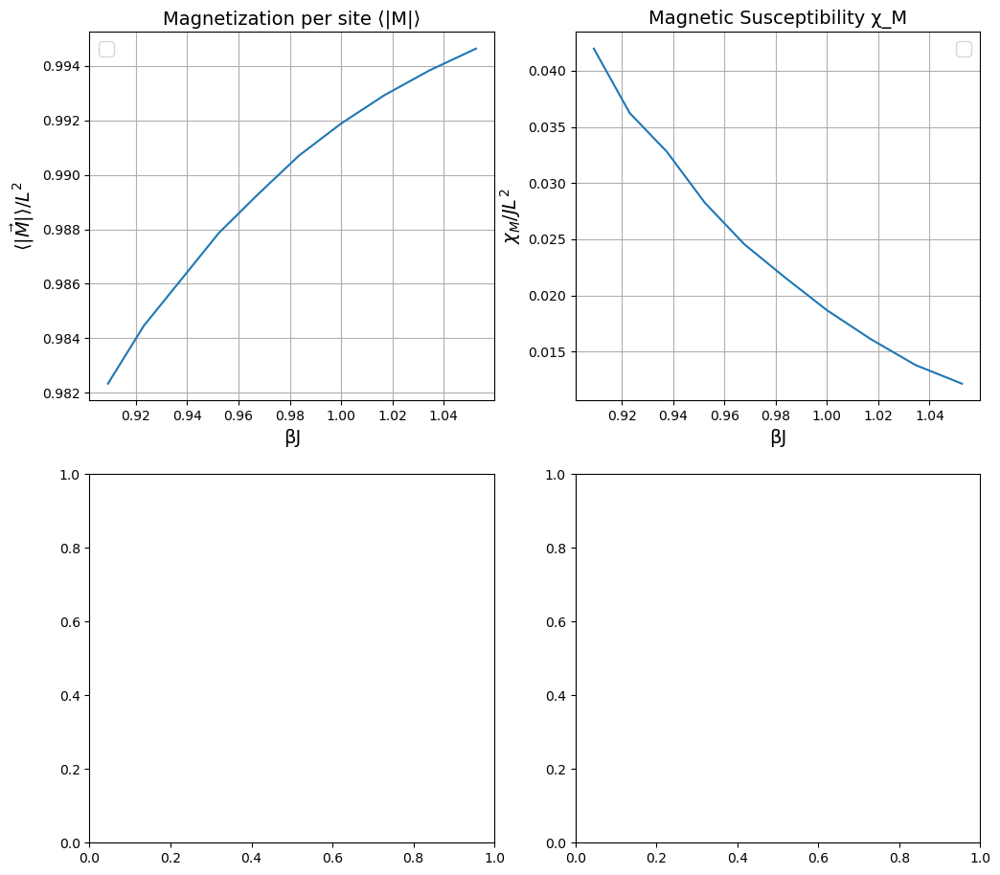

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    ax.plot(beta_values, results[key])
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


ValueError: x and y must have same first dimension, but have shapes (10,) and (0,)

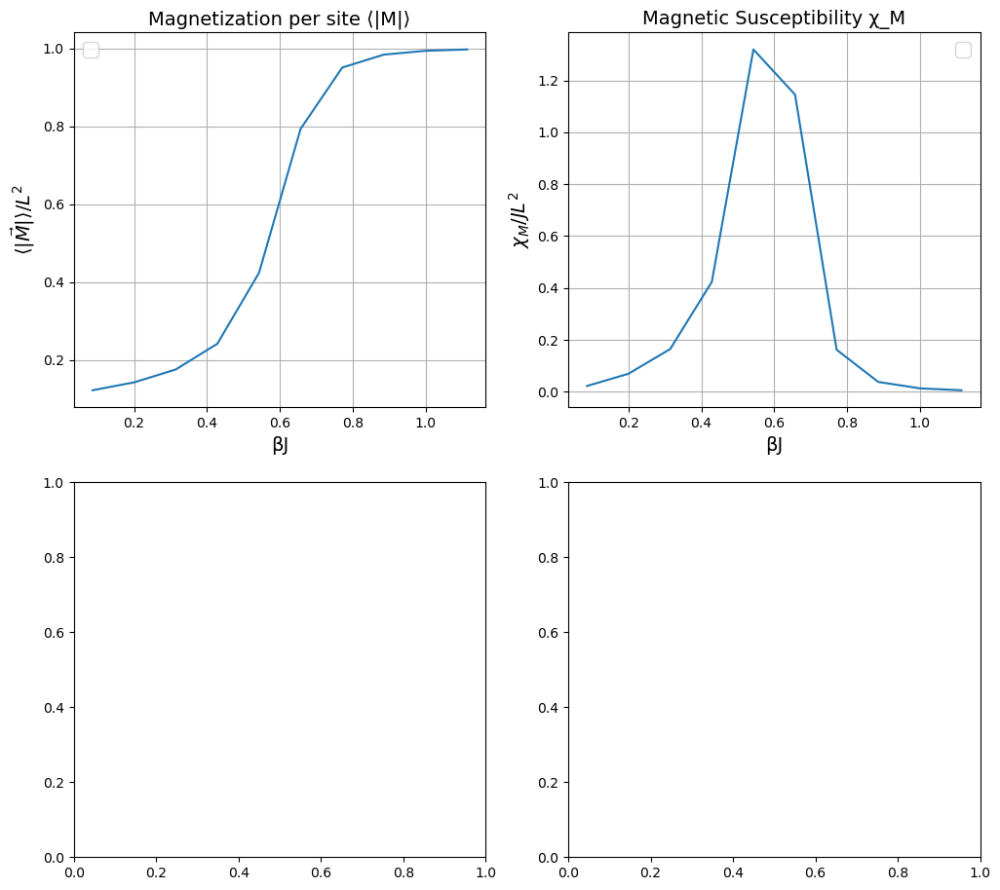

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    ax.plot(beta_values, results[key])
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


ValueError: x and y must have same first dimension, but have shapes (10,) and (0,)

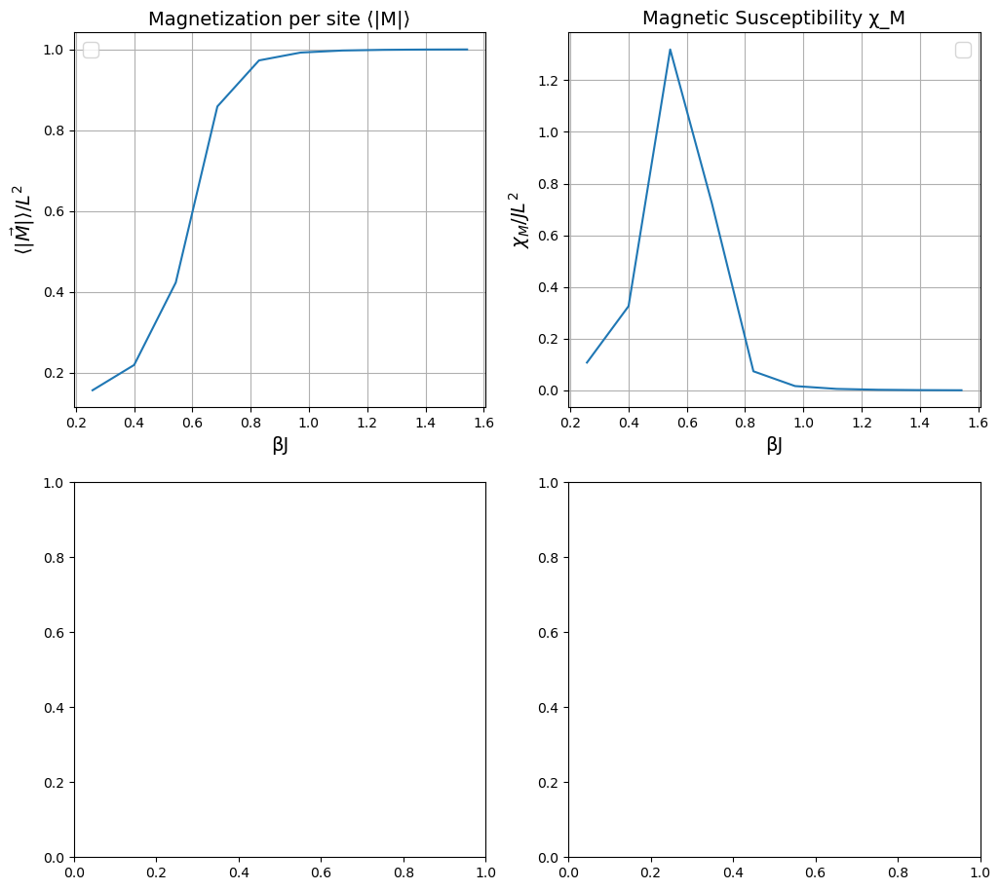

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    ax.plot(beta_values, results[key])
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

### Binder Cumulant

In [5]:
import numpy as np

# ============================================================
# PARAMETERS
# ============================================================

q = 3
J = 1.0

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# Reflection table
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# TOTAL ENERGY (computed once)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E


# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    r = np.random.randint(0, q)

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ----------------------
    # Grow cluster ONLY
    # ----------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))
       # ----------------------
    # Boundary correction
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])
    # ----------------------
    # Flip + magnetization
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref


    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r


# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=10**5,
    J=J,
    burn_frac=0.2,
    sample_interval=1
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L, L), dtype=bool)

    # Initial observables
    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster_q3(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        # Rotate magnetization accordingly
        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c
    
        # --- Measurements
        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ============================================================
    # Observables
    # ============================================================

    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)
    U = 1 - M4_mean/(3*(M2_mean**2))
    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U


In [41]:

# --- Storage ---
results = {
    L: {
        "M": [],
        "chi": [],
        "E": [],
        "Cv": [],
        "Binder": []
    }
    for L in L_values
}

# --- Loop over sizes and temperatures ---
for L in L_values:
    print(f"\nRunning simulations for L = {L}")

    for T in T_values:
        start_time = time.time()

        M, chi, E, Cv, U = run_simulation(
            L, T,
            sweeps=sweeps,
            J=J,
            burn_frac=0.3
        )

        results[L]["M"].append(M)
        results[L]["chi"].append(chi)
        results[L]["E"].append(E)
        results[L]["Cv"].append(Cv)
        results[L]["Binder"].append(U)

        elapsed = time.time() - start_time
x`
        print(f"T = {T:.3f} | U = {U:.4f} | time = {elapsed/60:.2f} min")


for L in L_values:
    for key in results[L]:
        results[L][key] = np.array(results[L][key])
        
save_dict = {
    "T_values": np.array(T_values),
    "L_values": np.array( L_values)
}

for L in L_values:
    for key in results[L]:
        save_dict[f"L{L}_{key}"] = results[L][key]

np.savez_compressed("clock_q3_binderresolvedsimulationInt16-64_data.npz", **save_dict)

print("\nData saved successfully.")


Running simulations for L = 16
T = 1.400 | U = 0.6603 | time = 2.04 min
T = 1.422 | U = 0.6574 | time = 2.01 min
T = 1.444 | U = 0.6520 | time = 1.90 min
T = 1.467 | U = 0.6394 | time = 1.70 min
T = 1.489 | U = 0.6197 | time = 1.54 min
T = 1.511 | U = 0.5907 | time = 1.36 min
T = 1.533 | U = 0.5422 | time = 1.03 min
T = 1.556 | U = 0.4810 | time = 0.79 min
T = 1.578 | U = 0.4338 | time = 0.62 min
T = 1.600 | U = 0.3844 | time = 0.56 min

Running simulations for L = 24
T = 1.400 | U = 0.6636 | time = 4.65 min
T = 1.422 | U = 0.6617 | time = 4.66 min
T = 1.444 | U = 0.6585 | time = 4.73 min
T = 1.467 | U = 0.6476 | time = 3.69 min
T = 1.489 | U = 0.6232 | time = 3.46 min
T = 1.511 | U = 0.5551 | time = 2.32 min
T = 1.533 | U = 0.4752 | time = 1.52 min
T = 1.556 | U = 0.3838 | time = 1.13 min
T = 1.578 | U = 0.3301 | time = 0.74 min
T = 1.600 | U = 0.3133 | time = 0.58 min

Running simulations for L = 32
T = 1.400 | U = 0.6650 | time = 8.13 min
T = 1.422 | U = 0.6638 | time = 7.80 min
T 

In [5]:
import numpy as np

# ============================================================
# PARAMETERS4


 
# ============================================================

#q = 3
#J = 1.0

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# Reflection table
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# TOTAL ENERGY (computed once)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E


# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================
DELTA = np.zeros((q,q,q))
for r in range(q):
    for si in range(q):
        si_ref = REFLECT[r,si]
        for sj in range(q):
            DELTA[r,si,sj] = COS_DIFF[si,sj] - COS_DIFF[si_ref,sj]
            
def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    r = np.random.randint(0, q)

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ----------------------
    # Grow cluster ONLY
    # ----------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                #delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]
                delta = DELTA[r,si,sj]
                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))
       # ----------------------
    # Boundary correction
    # ----------------------

    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                delta = DELTA[r,si,sj]
                dE += J * delta
    # ----------------------
    # Flip + magnetization
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref


    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r


# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=10**5,
    spins=None,
    J=J,
    burn_frac=0.2,
    sample_interval=1
):

    beta = 1.0 / T

     # ---- USE EXISTING CONFIGURATION IF PROVIDED
    if spins is None:
        spins = new_state(L)
    else:
        spins = spins.copy()
    
    visited = np.zeros((L,L), dtype=bool)
    # Initial observables
    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster_q3(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        # Rotate magnetization accordingly
        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c
    
        # --- Measurements
        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ============================================================
    # Observables
    # ============================================================

    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)
    U = 1 - M4_mean/(3*(M2_mean**2))
    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U, spins
def adaptive_temperature_scan(
    L,
    T_values,
    sweeps=10**5,
    refine_iterations=2,
    refine_width=0.03,
    refine_points=4
):

    results = {}
    configs = {}

    # ------------------------------------------------
    # INITIAL COARSE SCAN
    # ------------------------------------------------

    for T in T_values:

        M, chi, E, Cv, U, spins = run_simulation(
            L,
            T,
            sweeps=sweeps
        )

        results[T] = (M, chi, E, Cv, U) # Store the computed results
        configs[T] = spins # Stores final spin configurations

    # ------------------------------------------------
    # ADAPTIVE REFINEMENT
    # ------------------------------------------------

    for it in range(refine_iterations):

        Ts = np.array(sorted(results.keys()))
        chis = np.array([results[T][1] for T in Ts])
        cvs = np.array([results[T][3] for T in Ts])

        # choose strongest peak
        peak_index = np.argmax(chis + cvs)
        T_peak = Ts[peak_index]

        print(f"L={L} refinement {it+1} peak near T = {T_peak:.5f}")

        new_Ts = np.linspace(     # Generate new temperatures
            T_peak - refine_width,
            T_peak + refine_width,
            refine_points
        )

        for T in new_Ts:

            if T not in results:

                # start from closest configuration
                closest = Ts[np.argmin(np.abs(Ts - T))]
                start_config = configs[closest]

                M, chi, E, Cv, U, spins = run_simulation(
                    L,
                    T,
                    sweeps=sweeps//2,
                    spins=start_config,
                    burn_frac=0.05
                )

                results[T] = (M, chi, E, Cv, U)
                configs[T] = spins

    return results

In [7]:
def unpack_results(results_dict):

    Ts = np.array(sorted(results_dict.keys()))

    M = []
    chi = []
    E = []
    Cv = []
    Binder = []

    for T in Ts:
        m, c, e, cv, u = results_dict[T]
        M.append(m)
        chi.append(c)
        E.append(e)
        Cv.append(cv)
        Binder.append(u)

    return Ts, np.array(M), np.array(chi), np.array(E), np.array(Cv), np.array(Binder)
# --- Storage ---
results = {
    L: {
        "T": [],
        "M": [],
        "chi": [],
        "E": [],
        "Cv": [],
        "Binder": []
    }
    for L in L_values
}

# -------------------------------------------------
# Adaptive simulations
# -------------------------------------------------

for L in L_values:

    print(f"\nRunning adaptive simulations for L = {L}")

    start_total = time.time()

    # Run adaptive scan
    adaptive_results = adaptive_temperature_scan(
        L,
        T_values,
        sweeps=sweeps,
        refine_iterations=3,
        refine_width=0.02,
        refine_points=6
    )

    # Convert dictionary → arrays
    Ts, M, chi, E, Cv, Binder = unpack_results(adaptive_results)

    results[L]["T"] = Ts
    results[L]["M"] = M
    results[L]["chi"] = chi
    results[L]["E"] = E
    results[L]["Cv"] = Cv
    results[L]["Binder"] = Binder

    elapsed = time.time() - start_total
    print(f"L={L} completed in {elapsed/60:.2f} minutes")


# -------------------------------------------------
# Save results
# -------------------------------------------------

save_dict = {}

for L in L_values:
    save_dict[f"L{L}_T"] = results[L]["T"]
    save_dict[f"L{L}_M"] = results[L]["M"]
    save_dict[f"L{L}_chi"] = results[L]["chi"]
    save_dict[f"L{L}_E"] = results[L]["E"]
    save_dict[f"L{L}_Cv"] = results[L]["Cv"]
    save_dict[f"L{L}_Binder"] = results[L]["Binder"]

save_dict["L_values"] = np.array(L_values)

np.savez_compressed(
    "clock_q3_binderresolvedsimulationAdaptLog3-16-64_data.npz",
    **save_dict
)

print("\nData saved successfully.")



Running adaptive simulations for L = 16
L=16 refinement 1 peak near T = 1.51111
L=16 refinement 2 peak near T = 1.52311
L=16 refinement 3 peak near T = 1.52311
L=16 completed in 6.48 minutes

Running adaptive simulations for L = 24
L=24 refinement 1 peak near T = 1.51111
L=24 refinement 2 peak near T = 1.53111
L=24 refinement 3 peak near T = 1.51911
L=24 completed in 25.10 minutes

Running adaptive simulations for L = 32
L=32 refinement 1 peak near T = 1.51111
L=32 refinement 2 peak near T = 1.51111
L=32 refinement 3 peak near T = 1.51111
L=32 completed in 65.02 minutes

Running adaptive simulations for L = 48
L=48 refinement 1 peak near T = 1.51111
L=48 refinement 2 peak near T = 1.50711
L=48 refinement 3 peak near T = 1.50711
L=48 completed in 50.58 minutes

Running adaptive simulations for L = 64
L=64 refinement 1 peak near T = 1.51111
L=64 refinement 2 peak near T = 1.49911
L=64 refinement 3 peak near T = 1.50311
L=64 completed in 157.16 minutes

Data saved successfully.


In [69]:

data = np.load("clock_q3_binderresolvedsimulationAdaptLog-16-64_data.npz")
print(data.files)

['L16_T', 'L16_M', 'L16_chi', 'L16_E', 'L16_Cv', 'L16_Binder', 'L24_T', 'L24_M', 'L24_chi', 'L24_E', 'L24_Cv', 'L24_Binder', 'L32_T', 'L32_M', 'L32_chi', 'L32_E', 'L32_Cv', 'L32_Binder', 'L48_T', 'L48_M', 'L48_chi', 'L48_E', 'L48_Cv', 'L48_Binder', 'L64_T', 'L64_M', 'L64_chi', 'L64_E', 'L64_Cv', 'L64_Binder', 'L_values']


In [70]:

L_values = [16, 24, 32, 48, 64]   # set your lattice sizes

results = {}

for L in L_values:

    results[L] = {
        "T": data[f"L{L}_T"],
        "M": data[f"L{L}_M"],
        "chi": data[f"L{L}_chi"],
        "E": data[f"L{L}_E"],
        "Cv": data[f"L{L}_Cv"],
        "Binder": data[f"L{L}_Binder"]
    }

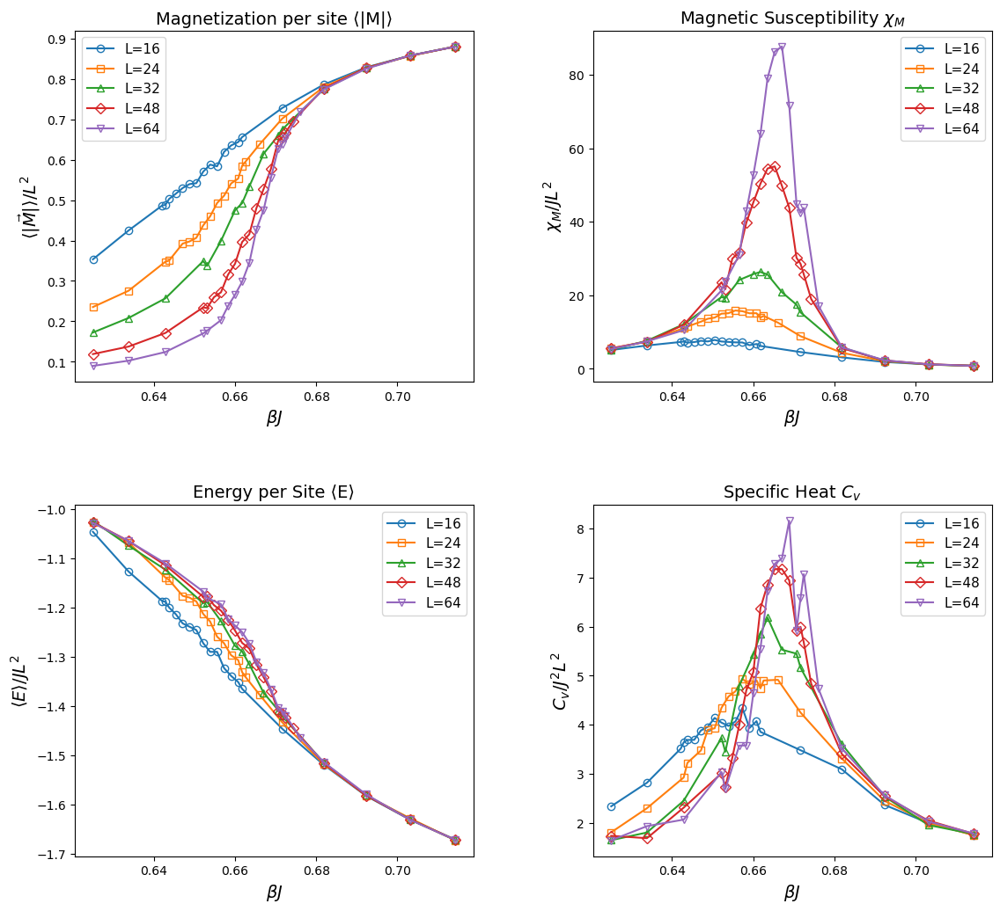

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility $χ_M$",
    "Energy per Site ⟨E⟩",
    "Specific Heat $C_v$"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    r"$\langle E \rangle / JL^2$",
    r"$C_v / J^2 L^2$"
]

keys = ["M", "chi", "E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):

        T_vals = results[L]["T"]
        beta_vals = 1.0 / T_vals

        ax.plot(
            beta_vals,
            results[L][key],
            marker=markers[j % len(markers)],
            mfc = 'none',
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    ax.grid(False)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncq3ClockBinderResolvedIntAdaptiveGridless-16-64.pdf", dpi=300
)

plt.show()

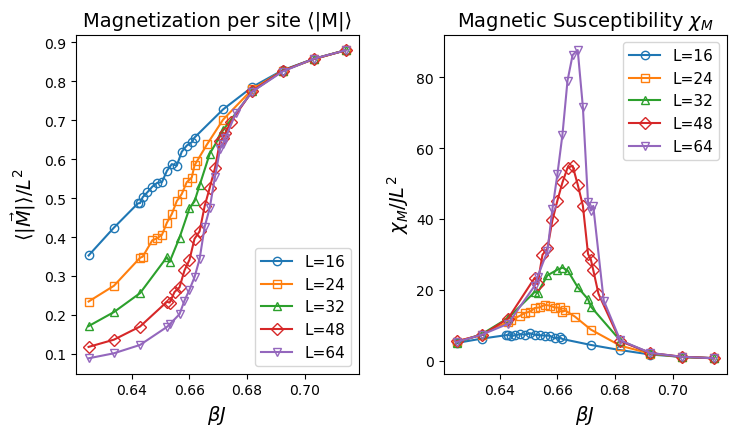

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8, 5))

titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility $χ_M$",
    #"Energy per Site ⟨E⟩",
    #"Specific Heat $C_v$"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    #r"$\langle E \rangle / JL^2$",
    #r"$C_v / J^2 L^2$"
]

keys = ["M", "chi"] #"E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):

        T_vals = results[L]["T"]
        beta_vals = 1.0 / T_vals

        ax.plot(
            beta_vals,
            results[L][key],
            marker=markers[j % len(markers)],
            mfc = 'none',
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    ax.grid(False)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncq3ClockBinderResolvedIntAdaptiveGridless-16-64.pdf",
    dpi=300
)

plt.show()

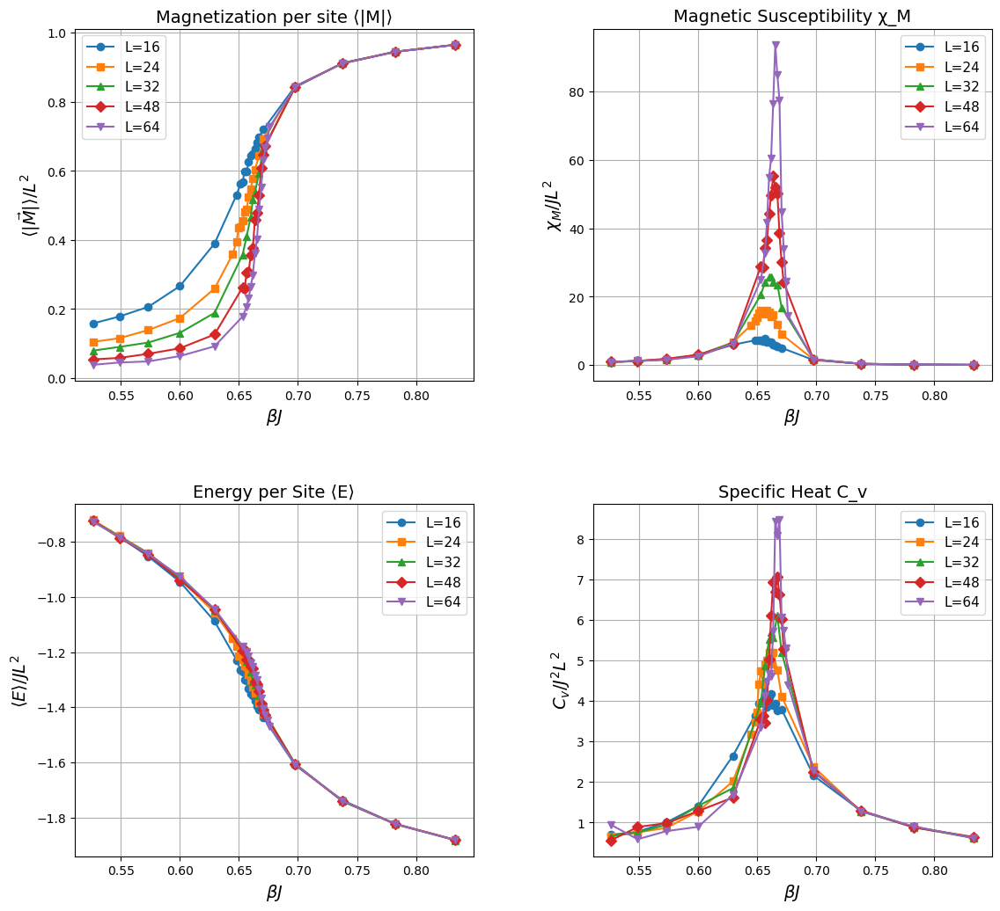

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility χ_M",
    "Energy per Site ⟨E⟩",
    "Specific Heat C_v"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    r"$\langle E \rangle / JL^2$",
    r"$C_v / J^2 L^2$"
]

keys = ["M", "chi", "E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):

        T_vals = results[L]["T"]
        beta_vals = 1.0 / T_vals

        ax.plot(
            beta_vals,
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncClockBinderResolvedIntAdaptive3.1-state-16-64.pdf",
    dpi=300
)

plt.show()

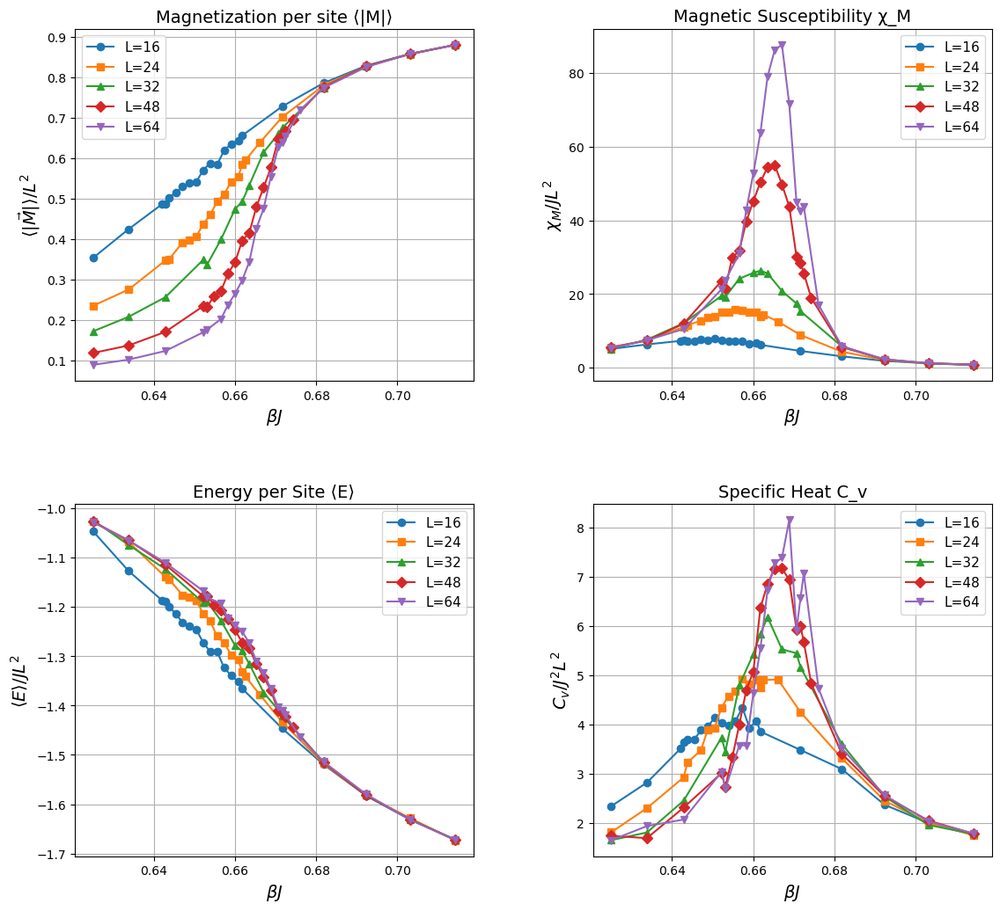

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility χ_M",
    "Energy per Site ⟨E⟩",
    "Specific Heat C_v"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    r"$\langle E \rangle / JL^2$",
    r"$C_v / J^2 L^2$"
]

keys = ["M", "chi", "E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):

        T_vals = results[L]["T"]
        beta_vals = 1.0 / T_vals

        ax.plot(
            beta_vals,
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncClockBinderResolvedIntAdaptive3-state-16-64.pdf",
    dpi=300
)

plt.show()

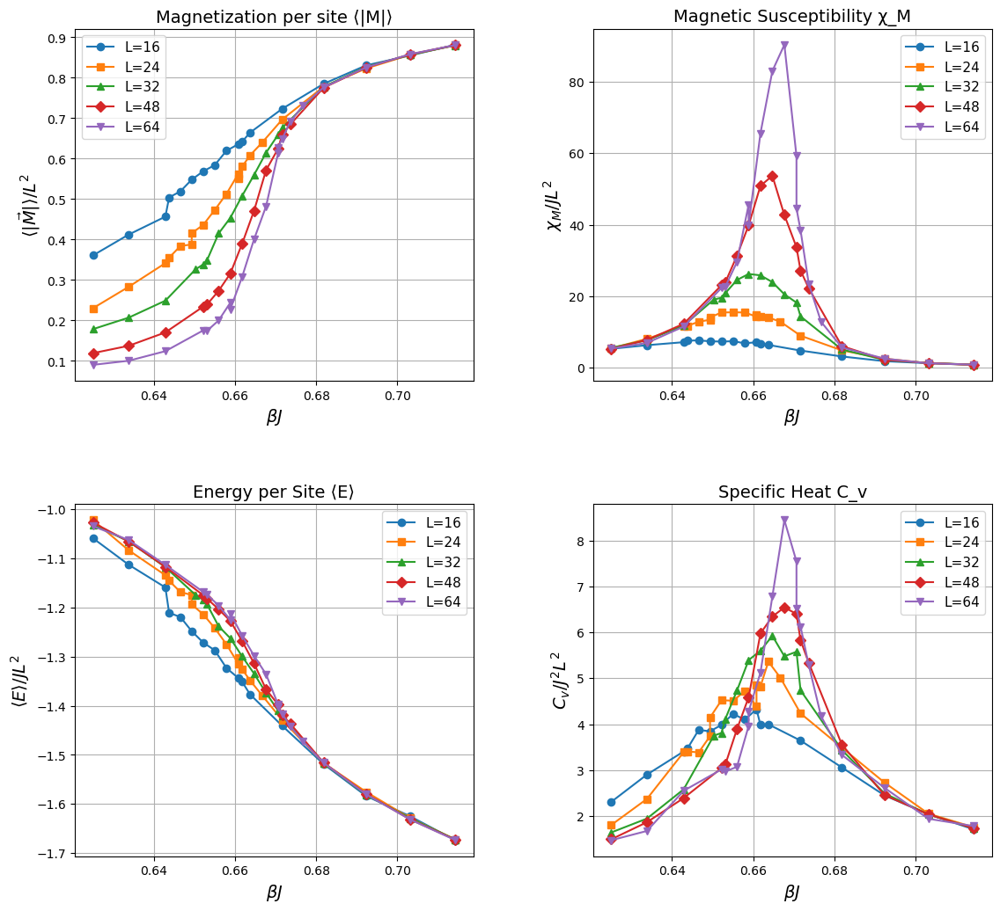

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility χ_M",
    "Energy per Site ⟨E⟩",
    "Specific Heat C_v"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    r"$\langle E \rangle / JL^2$",
    r"$C_v / J^2 L^2$"
]

keys = ["M", "chi", "E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):

        T_vals = results[L]["T"]
        beta_vals = 1.0 / T_vals

        ax.plot(
            beta_vals,
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncClockBinderResolvedIntAdaptive2-state-16-64.png",
    dpi=300
)

plt.show()

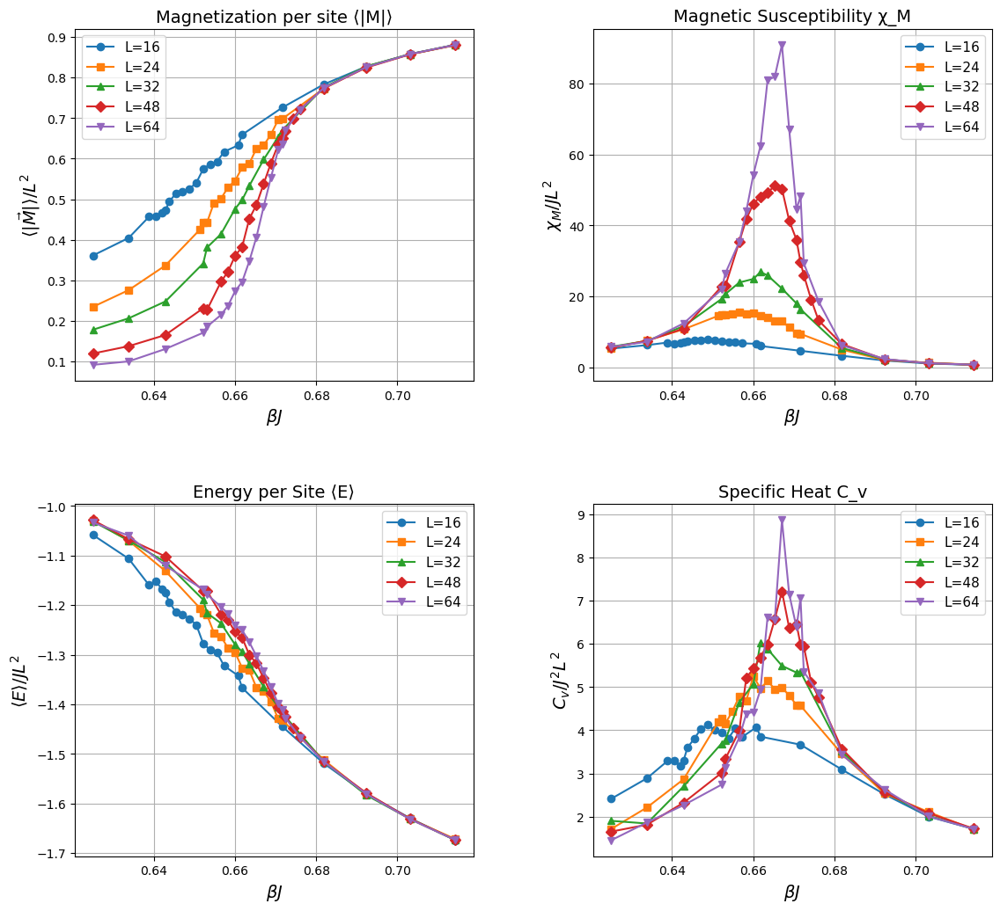

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility χ_M",
    "Energy per Site ⟨E⟩",
    "Specific Heat C_v"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    r"$\langle E \rangle / JL^2$",
    r"$C_v / J^2 L^2$"
]

keys = ["M", "chi", "E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):

        T_vals = results[L]["T"]
        beta_vals = 1.0 / T_vals

        ax.plot(
            beta_vals,
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncClockBinderResolvedIntAdaptive-state-16-64.png",
    dpi=300
)

plt.show()

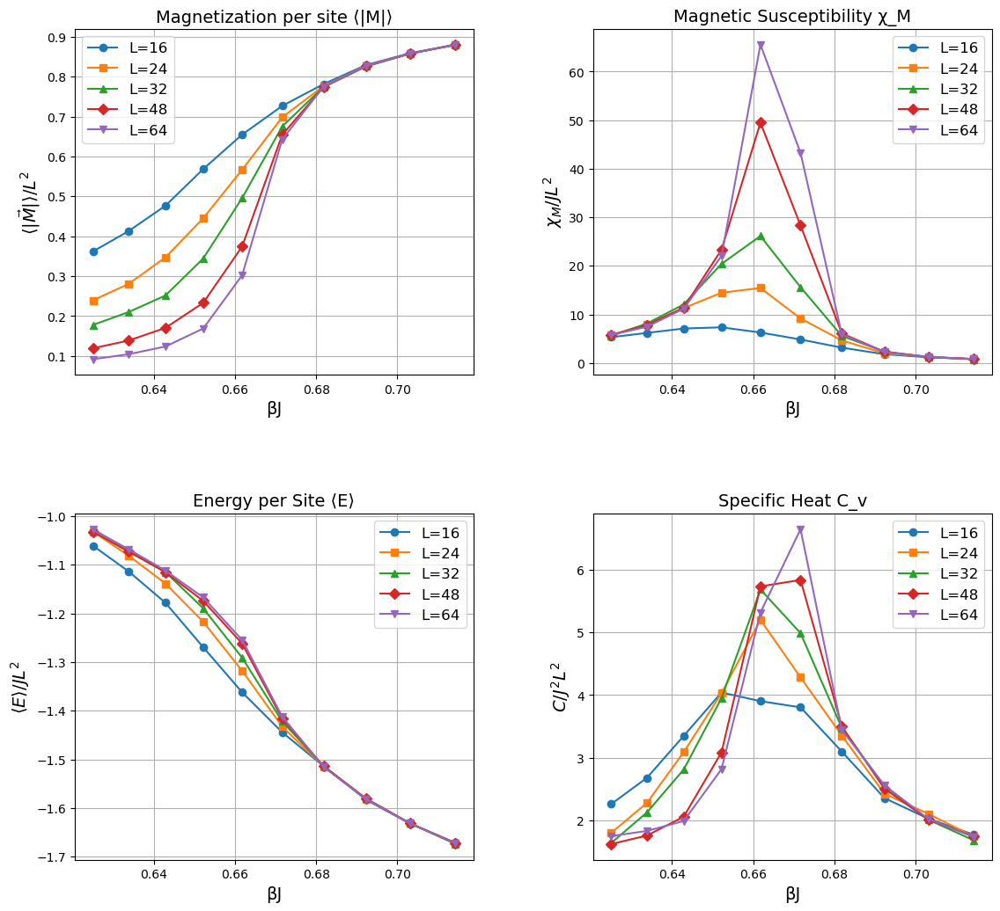

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockBinderResolvedInt3-state-16-64.png")
plt.show()


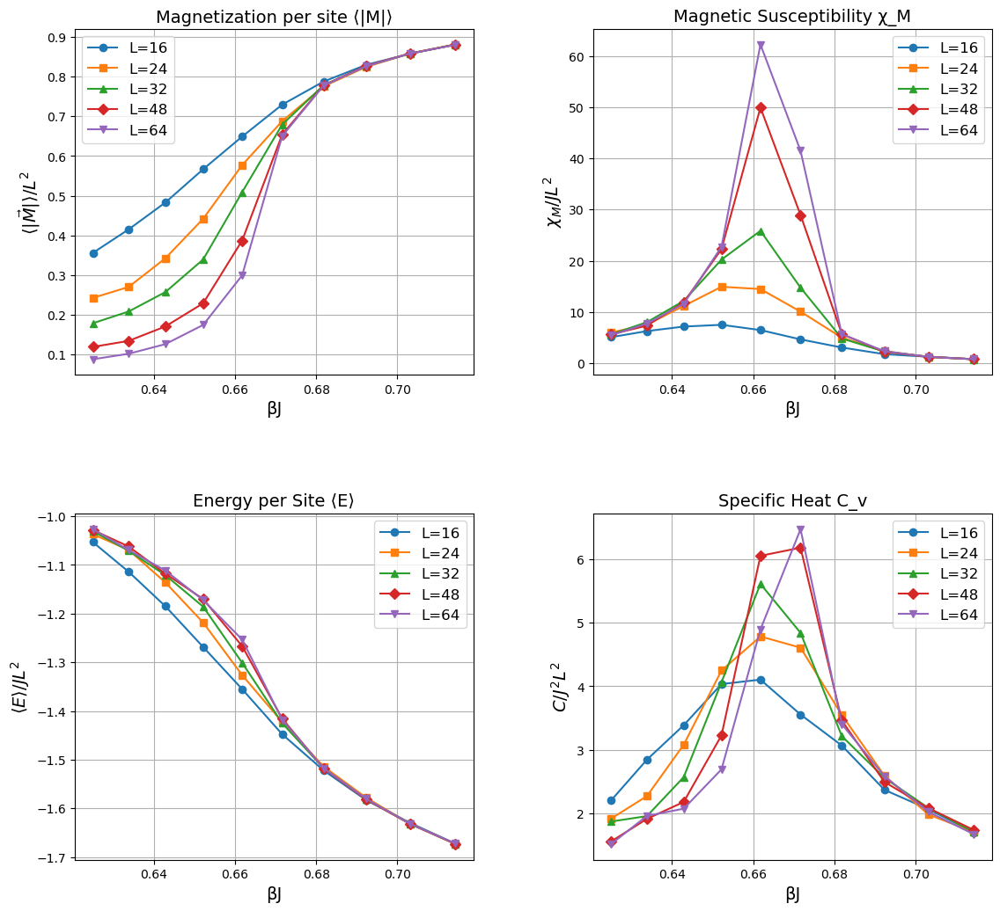

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockBinderResolvedInt-state-16-64.png")
plt.show()


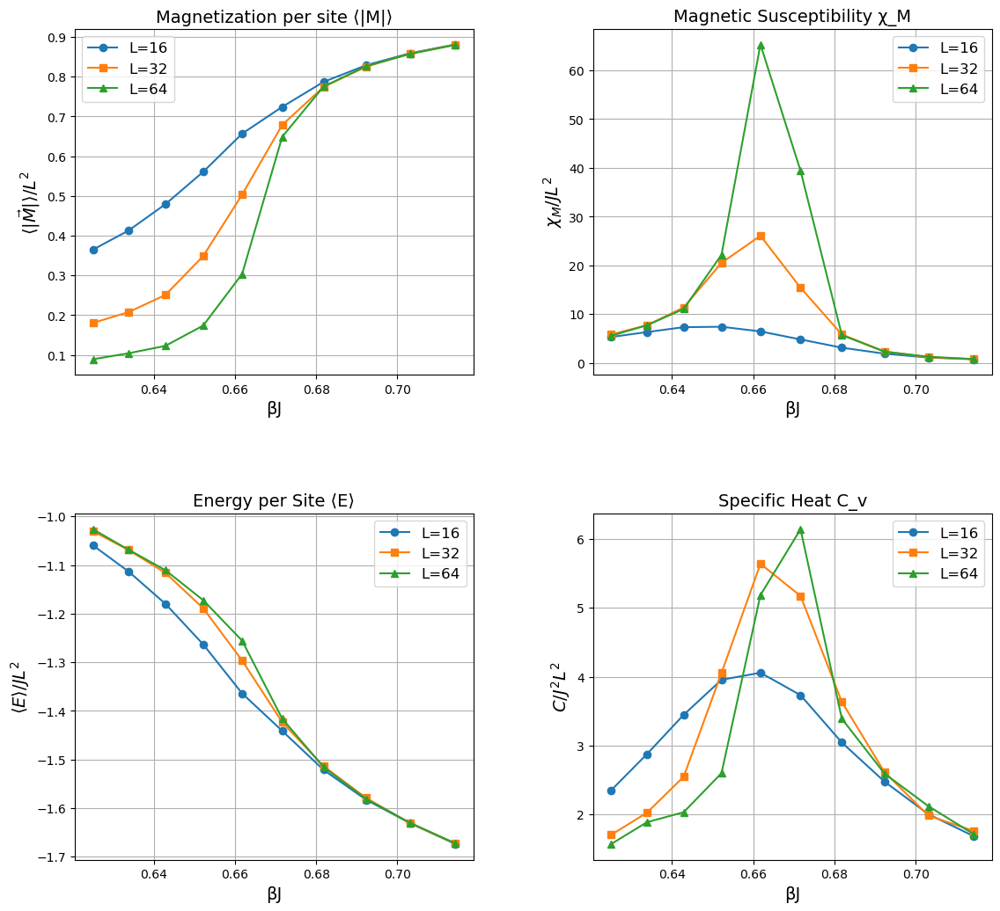

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockBinderResolved3.1-state-16-64.png")
plt.show()


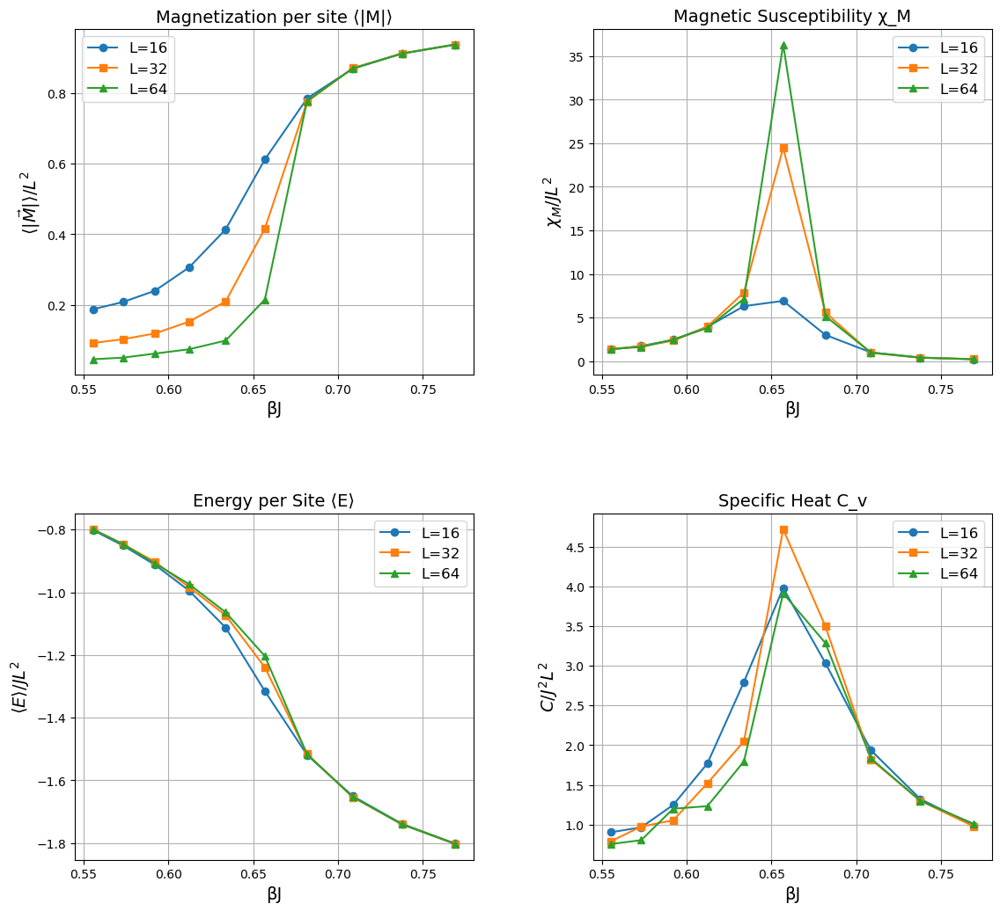

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockBinderResolved3-state-16-64.png")
plt.show()


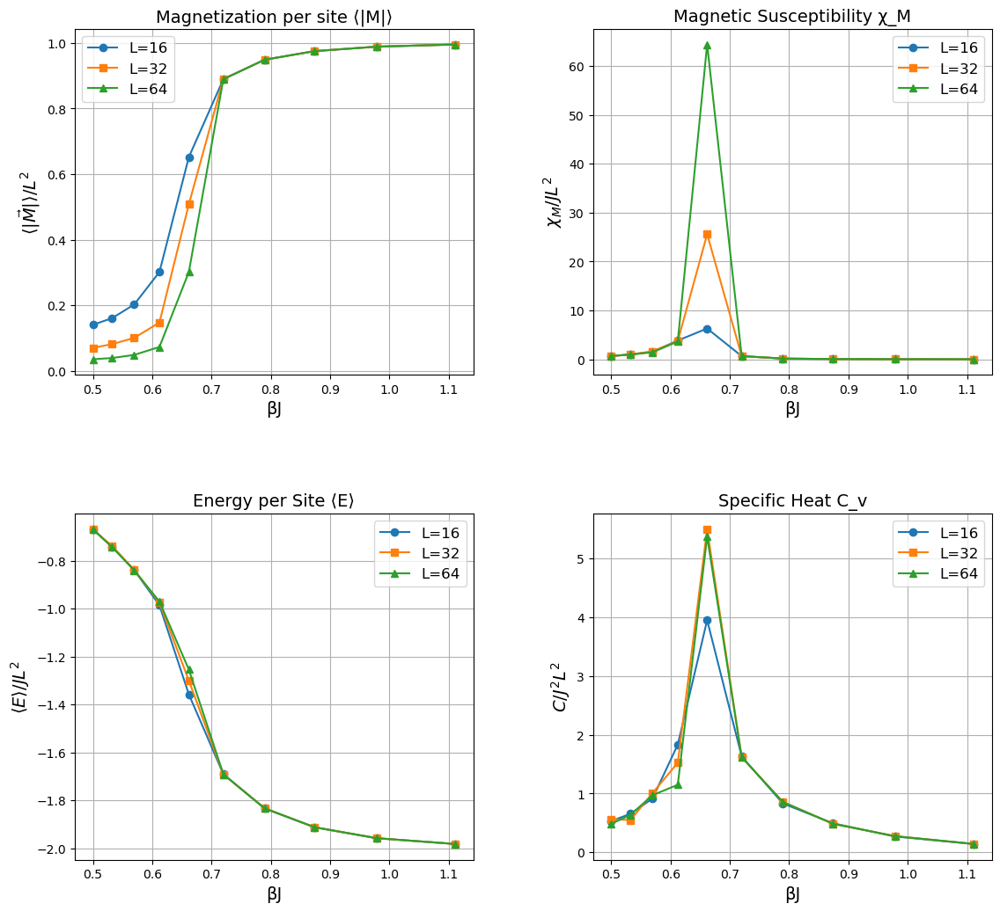

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockBinderResolved3-state-16-64.png")
plt.show()


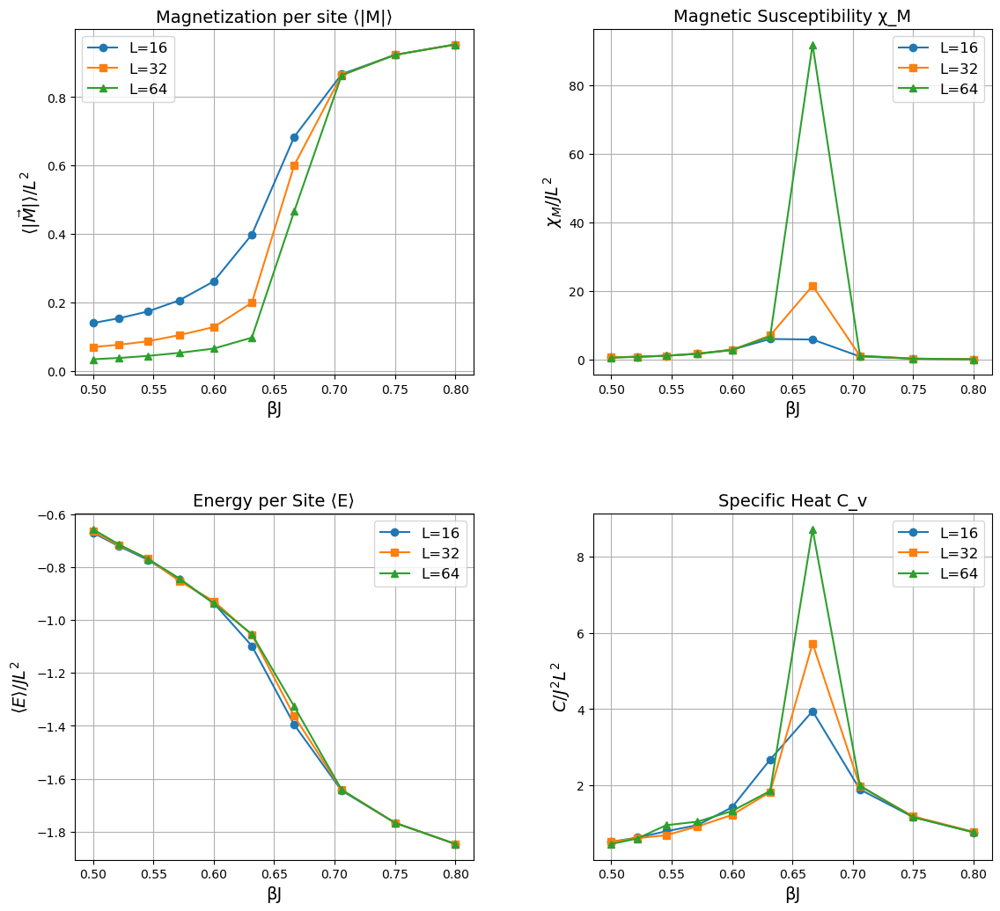

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockBinder3-state-16-64.png")
plt.show()


Slope = -0.0946
Estimated β/ν = 0.0946
Intercept = -0.0707
R² = 0.9849


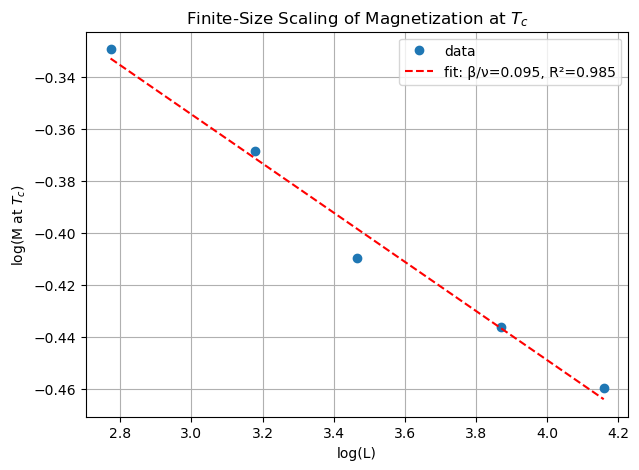

In [11]:
from scipy.stats import linregress
import numpy as np
import matplotlib.pyplot as plt

Tc = 1.490  # your estimated critical temperature

# --- Collect M(Tc) for each L ---
M_Tc_values = []

for L in L_values:

    T_arr = np.array(results[L]["T"])
    M_arr = np.array(results[L]["M"])

    # Find index closest to Tc
    idx = np.argmin(np.abs(T_arr - Tc))

    M_Tc = M_arr[idx]
    M_Tc_values.append(M_Tc)

M_Tc_values = np.array(M_Tc_values)
L_array = np.array(L_values)

# --- Log-log fit: M ~ L^(-β/ν) ---
logL = np.log(L_array)
logM = np.log(M_Tc_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logM)

beta_over_nu = -slope  # IMPORTANT: negative slope

# --- Print results ---
print(f"Slope = {slope:.4f}")
print(f"Estimated β/ν = {beta_over_nu:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot ---
plt.figure(figsize=(7,5))

plt.plot(logL, logM, 'o', label="data")
plt.plot(
    logL,
    intercept + slope * logL,
    'r--',
    label=f"fit: β/ν={beta_over_nu:.3f}, R²={r_value**2:.3f}"
)

plt.xlabel("log(L)")
plt.ylabel("log(M at $T_c$)")
plt.title("Finite-Size Scaling of Magnetization at $T_c$")
plt.legend()
plt.grid(True)

plt.savefig("FSS_beta_over_nu_q3_clock.png")
plt.show()

Slope = -0.0946
Estimated β/ν = 0.0946
Intercept = -0.0570
R² = 0.9913


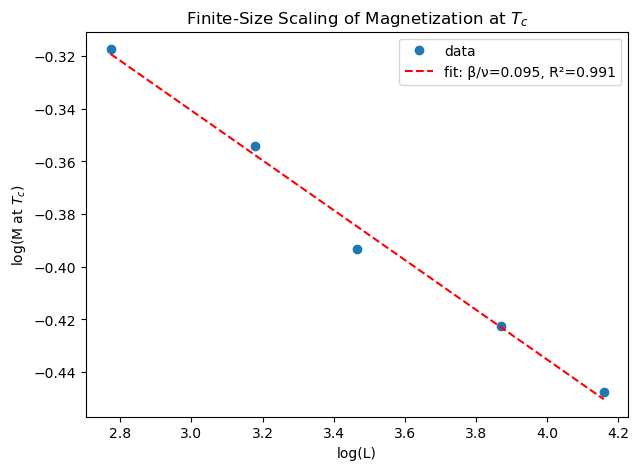

In [45]:
from scipy.stats import linregress
import numpy as np
import matplotlib.pyplot as plt

Tc = 1.490  # your estimated critical temperature

# --- Collect M(Tc) for each L ---
M_Tc_values = []

for L in L_values:

    T_arr = np.array(results[L]["T"])
    M_arr = np.array(results[L]["M"])

    # Find index closest to Tc
    idx = np.argmin(np.abs(T_arr - Tc))

    M_Tc = M_arr[idx]
    M_Tc_values.append(M_Tc)

M_Tc_values = np.array(M_Tc_values)
L_array = np.array(L_values)

# --- Log-log fit: M ~ L^(-β/ν) ---
logL = np.log(L_array)
logM = np.log(M_Tc_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logM)

beta_over_nu = -slope  # IMPORTANT: negative slope

# --- Print results ---
print(f"Slope = {slope:.4f}")
print(f"Estimated β/ν = {beta_over_nu:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot ---
plt.figure(figsize=(7,5))

plt.plot(logL, logM, 'o', label="data")
plt.plot(
    logL,
    intercept + slope * logL,
    'r--',
    label=f"fit: β/ν={beta_over_nu:.3f}, R²={r_value**2:.3f}"
)

plt.xlabel("log(L)")
plt.ylabel("log(M at $T_c$)")
plt.title("Finite-Size Scaling of Magnetization at $T_c$")
plt.legend()
#plt.grid(True)

plt.savefig("FSS_beta_over_nu_q3_clock.pdf")
plt.show()

Slope (γ/ν) = 1.7529
Intercept = -2.8005
R² = 0.9998


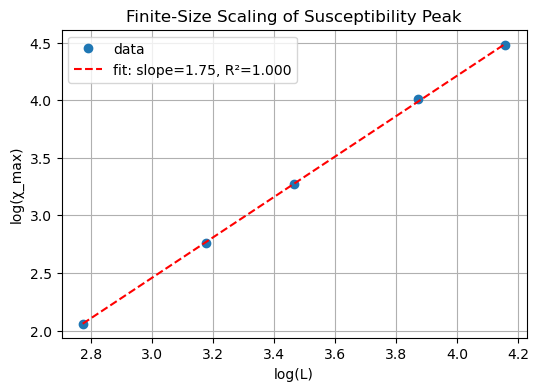

In [61]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3ClockResolvedBinderIntAdaptLog-16-64.pdf")
plt.show()


Slope (γ/ν) = 1.7529
Intercept = -2.8005
R² = 0.9998


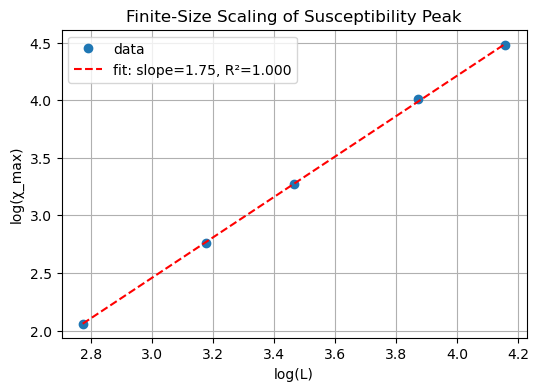

In [61]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3ClockResolvedBinderIntAdaptLog-16-64.pdf")
plt.show()


Slope (γ/ν) = 1.7529
Intercept = -2.8005
R² = 0.9998


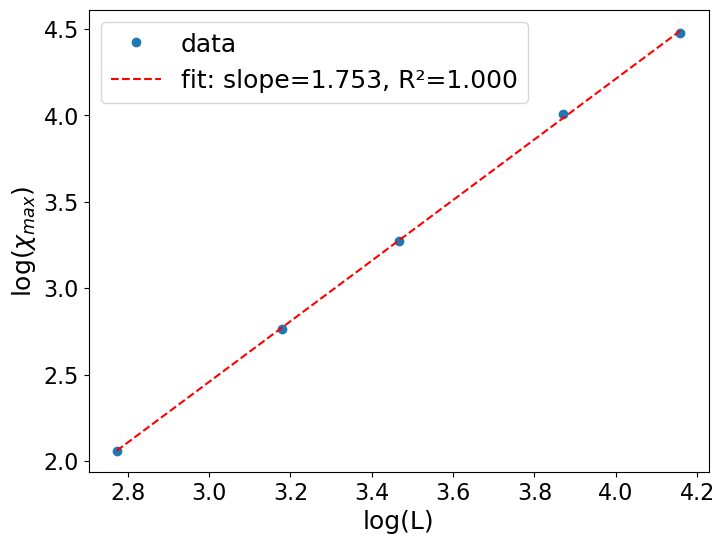

In [9]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(8,6))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)", fontsize = 18)
plt.ylabel("log($χ_{max}$)", fontsize = 18)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
#plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend(fontsize = 18)
plt.grid(False)
plt.savefig("FSSq3ClockResolvedBinderIntAdapt3FontSize-16-64.pdf")
plt.show()


Slope (γ/ν) = 1.7529
Intercept = -2.8005
R² = 0.9998


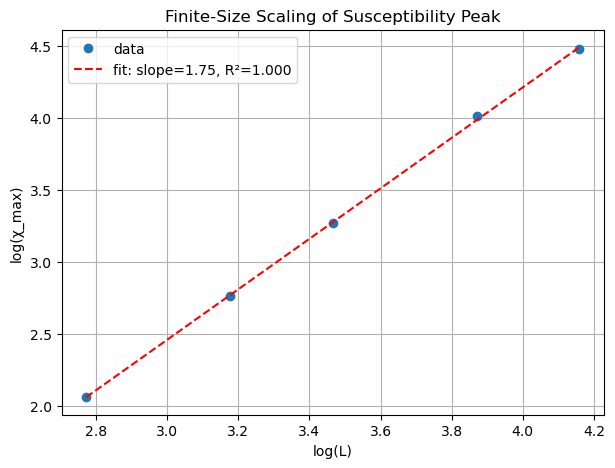

In [25]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(7,5))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
#plt.savefig("FSSq3ClockResolvedBinderIntAdapt3-16-64.pdf")
plt.show()


Slope (γ/ν) = 1.7859
Intercept = -2.9269
R² = 1.0000


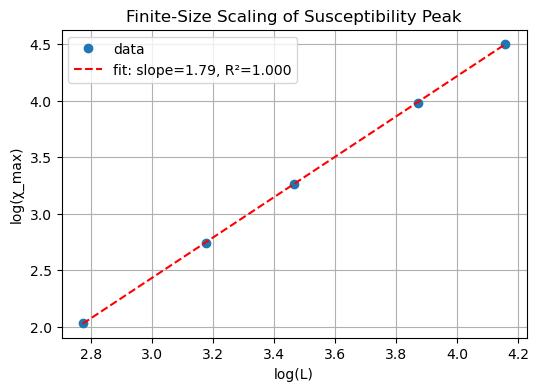

In [14]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3ClockResolvedBinderIntAdapt2-16-64.png")
plt.show()


Slope (γ/ν) = 1.7543
Intercept = -2.8116
R² = 0.9991


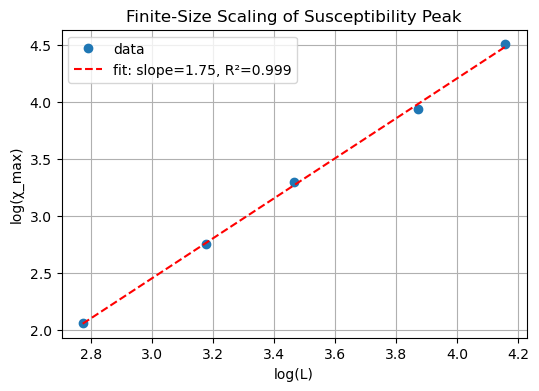

In [11]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3ClockResolvedBinderIntAdapt-16-64.png")
plt.show()


Slope (γ/ν) = 1.6055
Intercept = -2.3865
R² = 0.9905


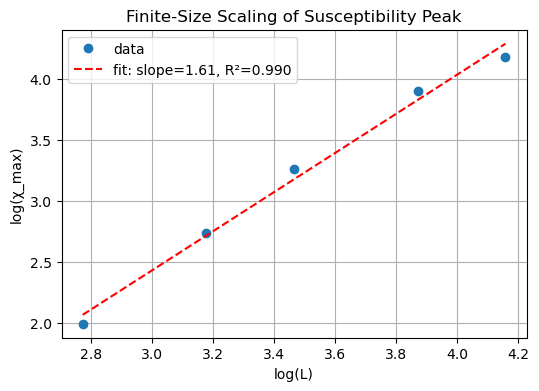

In [45]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3ClockResolvedBinderInt-16-64.png")
plt.show()


Slope (γ/ν) = 1.5471
Intercept = -2.2272
R² = 0.9913


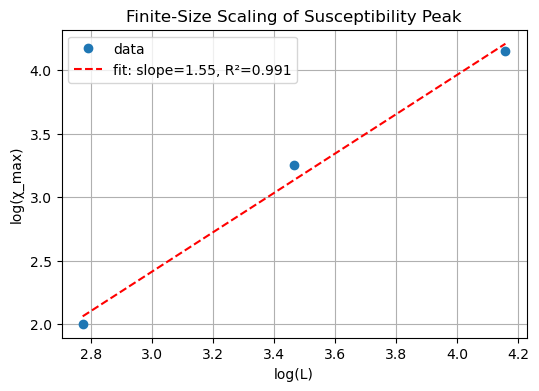

In [11]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3ClockResolvedBinder3.2-16-64.png")
plt.show()


Slope (γ/ν) = 1.5680
Intercept = -2.2857
R² = 0.9920


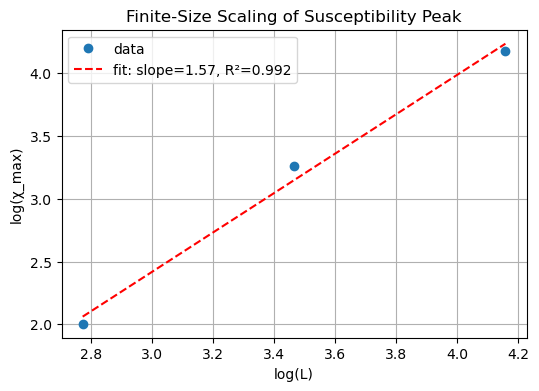

In [12]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3ClockResolvedBinder3.1-16-64.png")
plt.show()


Slope (γ/ν) = 1.1974
Intercept = -1.2419
R² = 0.9164


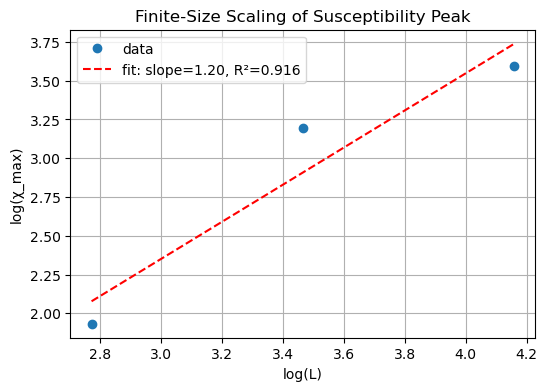

In [13]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3ClockResolved-16-64.png")
plt.show()


Slope (γ/ν) = 1.6767
Intercept = -2.7282
R² = 0.9861


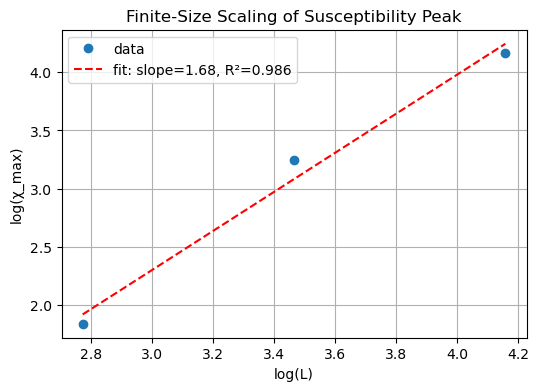

In [15]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3-14-20.png")
plt.show()


Slope (γ/ν) = 1.9637
Intercept = -3.6754
R² = 0.9986


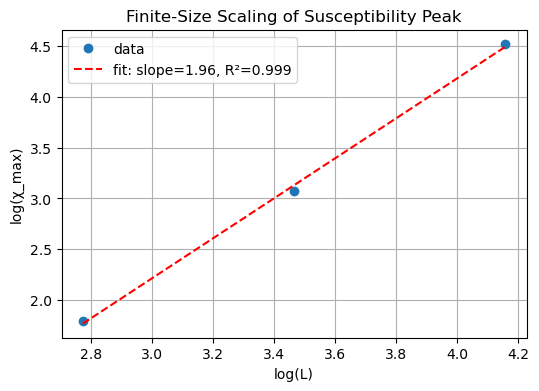

In [39]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq3-14-20.png")
plt.show()


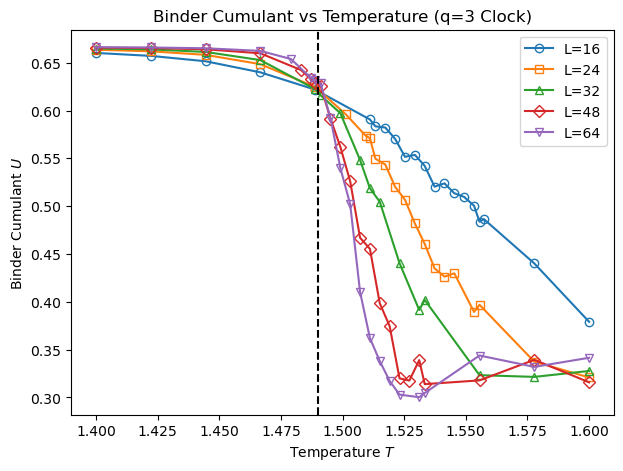

In [95]:
plt.figure(figsize=(7,5))
Tc=1.490
markers = ['o', 's', '^', 'D', 'v']
for i, L in enumerate(L_values):
    T_arr = results[L]["T"]          # adaptive temperature points
    binder_arr = results[L]["Binder"]

    plt.plot(T_arr, binder_arr, marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.axvline(Tc, linestyle = '--', linewidth = 1.5, color = 'black')
#plt.xlim(1.492,1.493)
plt.legend()
plt.grid(False)

plt.savefig("BinderCumulantq3ClockResolvedIntAdaptLogGrid.pdf")
plt.show()

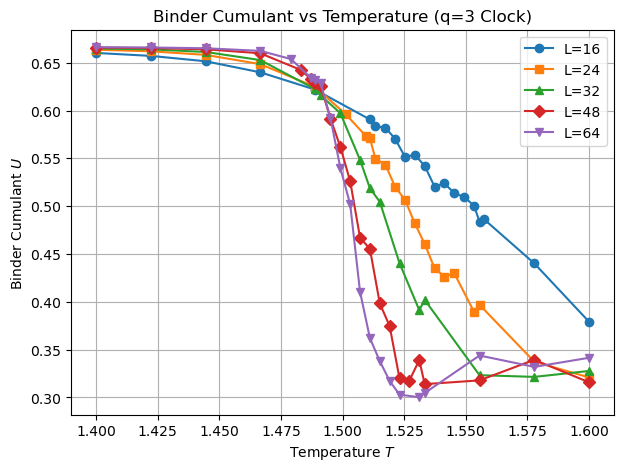

In [55]:
plt.figure(figsize=(7,5))
markers = ['o', 's', '^', 'D', 'v']
for i, L in enumerate(L_values):
    T_arr = results[L]["T"]          # adaptive temperature points
    binder_arr = results[L]["Binder"]

    plt.plot(T_arr, binder_arr, marker=markers[i % len(markers)],
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.legend()
plt.grid(True)

plt.savefig("BinderCumulantq3ClockResolvedIntAdapt3.pdf")
plt.show()

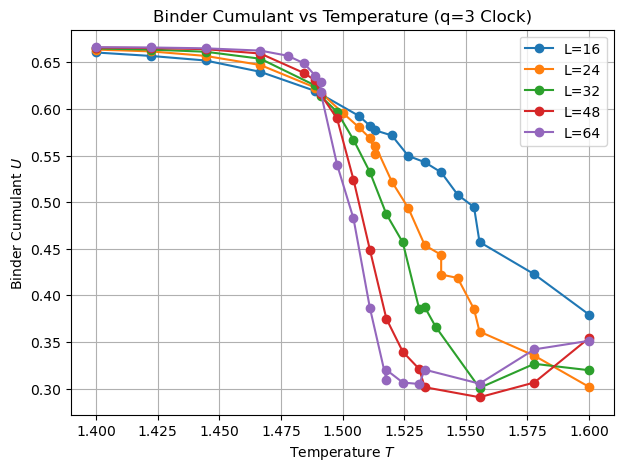

In [16]:
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = results[L]["T"]          # adaptive temperature points
    binder_arr = results[L]["Binder"]

    plt.plot(T_arr, binder_arr, 'o-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.legend()
plt.grid(True)

plt.savefig("BinderCumulantq3ClockResolvedIntAdapt2.png")
plt.show()

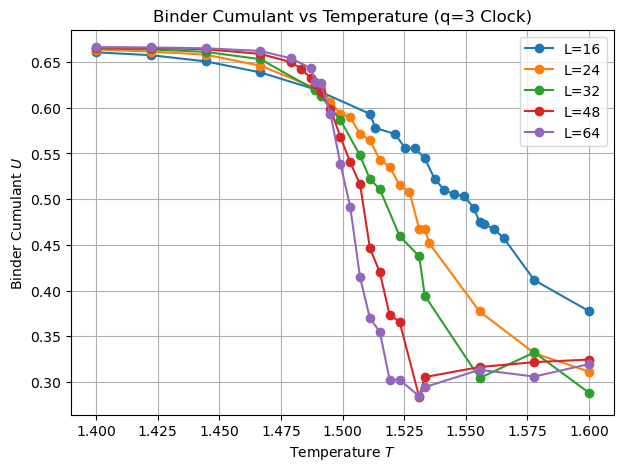

In [17]:
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = results[L]["T"]          # adaptive temperature points
    binder_arr = results[L]["Binder"]

    plt.plot(T_arr, binder_arr, 'o-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.legend()
plt.grid(True)

plt.savefig("BinderCumulantq3ClockResolvedIntAdapt.png")
plt.show()

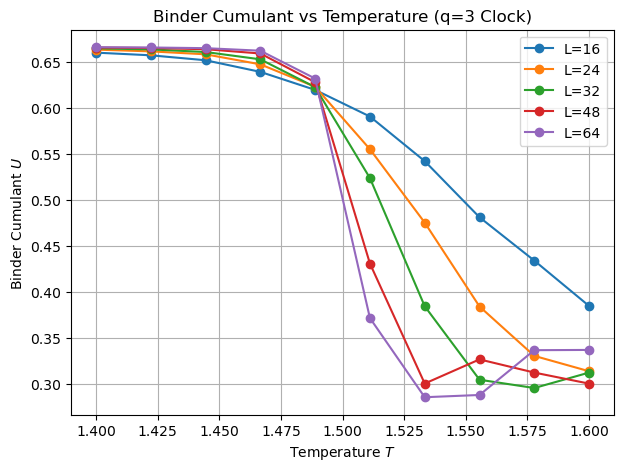

In [47]:
plt.figure(figsize=(7,5))

for L in L_values:
    plt.plot(T_values, results[L]["Binder"], 'o-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.savefig("BinderCumulantq3ClockResolvedInt.png")
plt.show()

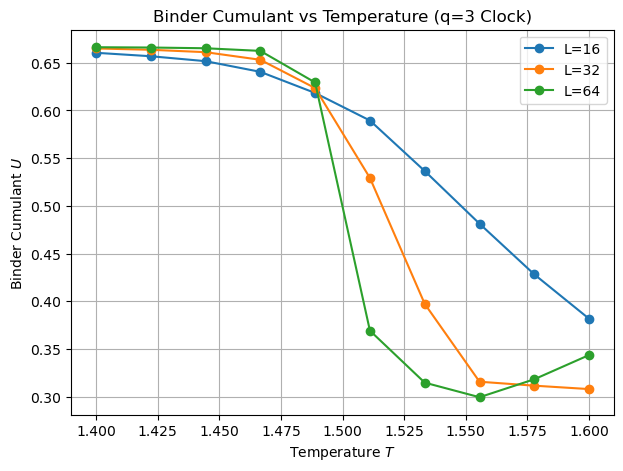

In [13]:
plt.figure(figsize=(7,5))

for L in L_values:
    plt.plot(T_values, results[L]["Binder"], 'o-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.savefig("BinderCumulantq3ClockResolved.png")
plt.show()

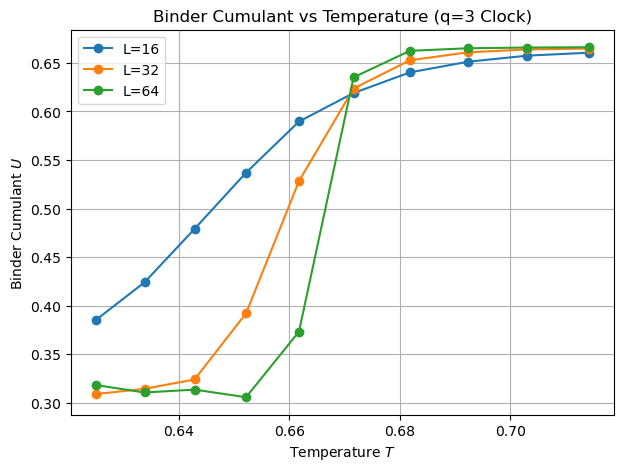

In [30]:
plt.figure(figsize=(7,5))

for L in L_values:
    plt.plot(beta_values, results[L]["Binder"], 'o-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
#plt.xlim(1.45, 1.525)
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.savefig("BinderCumulantq3ClockResolved2Beta.png")
plt.show()

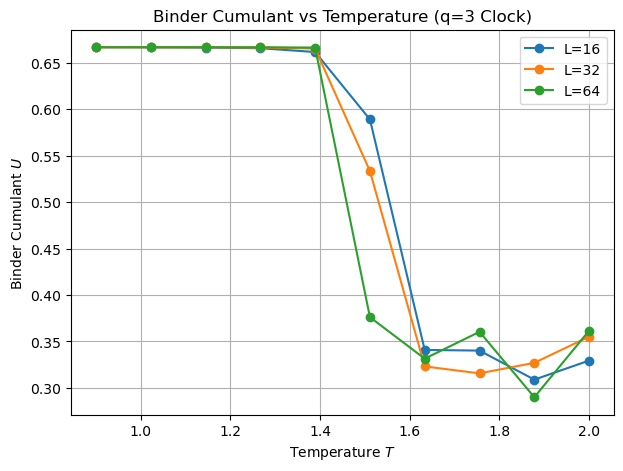

In [17]:
plt.figure(figsize=(7,5))

for L in L_values:
    plt.plot(T_values, results[L]["Binder"], 'o-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.show()

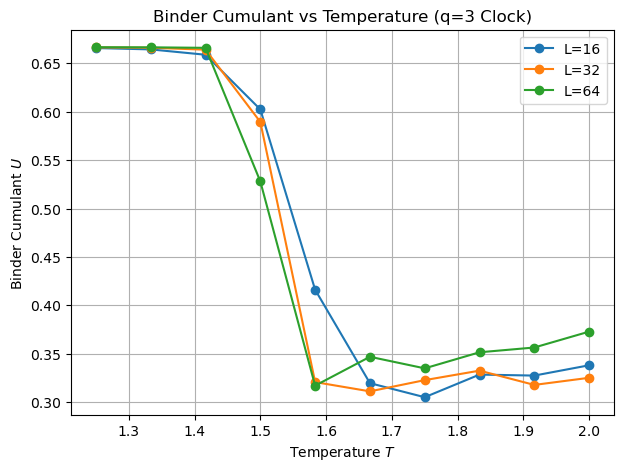

In [27]:
plt.figure(figsize=(7,5))

for L in L_values:
    plt.plot(T_values, results[L]["Binder"], 'o-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.show()

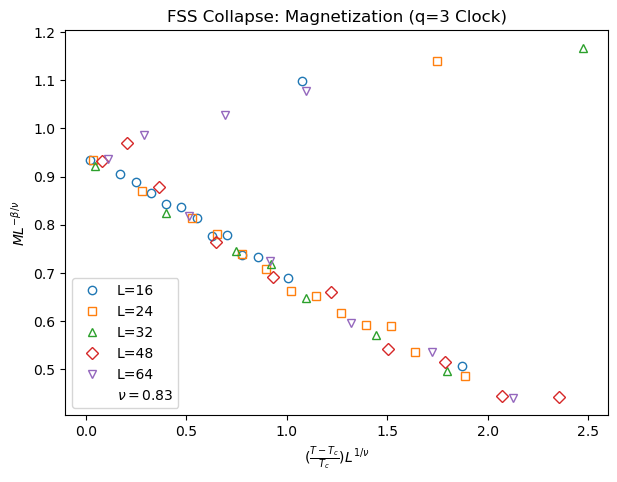

In [13]:
Tc = 1.490
nu = 0.83
beta_over_nu = slope   # ✅ correct for q=3

plt.figure(figsize=(7,5))

markers = ['o', 's', '^', 'D', 'v']

for i, L in enumerate(L_values):

    T_arr = np.array(results[L]["T"])
    M_arr = np.array(results[L]["M"])

    x = (np.abs(T_arr - Tc)/Tc) * L**(1/nu)
    y = M_arr / (L**beta_over_nu)

    # Optional window restriction (HIGHLY recommended)
    mask = np.abs(x) < 2.5

    plt.plot(
        x[mask],
        y[mask],
        marker=markers[i % len(markers)],
        linestyle='',
        label=f"L={L}", mfc = 'none'
    )
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$(\frac{T - T_c}{T_c})L^{1/\nu}$")
plt.ylabel(r"$M L^{-\beta/\nu}$")
#plt.yscale('log')
plt.title("FSS Collapse: Magnetization (q=3 Clock)")
plt.legend()
#plt.grid(True)

plt.show()

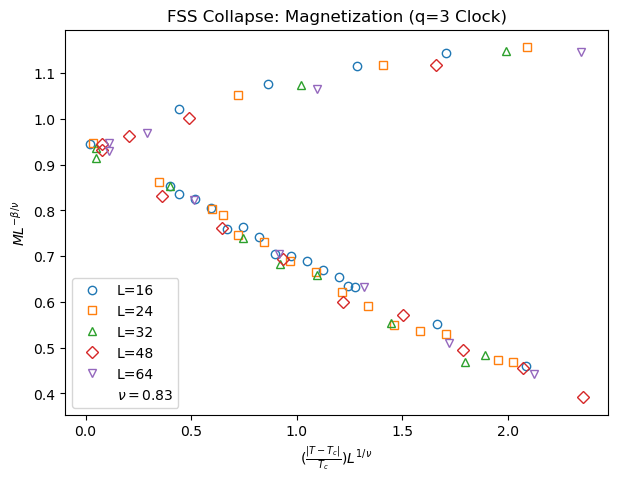

In [39]:
Tc = 1.490
nu = 0.83
beta_over_nu = slope   # ✅ correct for q=3

plt.figure(figsize=(7,5))

markers = ['o', 's', '^', 'D', 'v']

for i, L in enumerate(L_values):

    T_arr = np.array(results[L]["T"])
    M_arr = np.array(results[L]["M"])

    x = (np.abs(T_arr - Tc)/Tc) * L**(1/nu)
    y = M_arr / (L**beta_over_nu)

    # Optional window restriction (HIGHLY recommended)
    mask = np.abs(x) < 2.5

    plt.plot(
        x[mask],
        y[mask],
        marker=markers[i % len(markers)],
        linestyle='',
        label=f"L={L}", mfc = 'none'
    )
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$(\frac{|T - T_c|}{T_c})L^{1/\nu}$")
plt.ylabel(r"$M L^{-\beta/\nu}$")
#plt.yscale('log')
plt.title("FSS Collapse: Magnetization (q=3 Clock)")
plt.legend()
#plt.grid(True)
#plt.savefig("FSSCollapseq3ClockBinderResolvedIntAdapt3.1LogAroundTheoGridBeta.pdf")
plt.show()

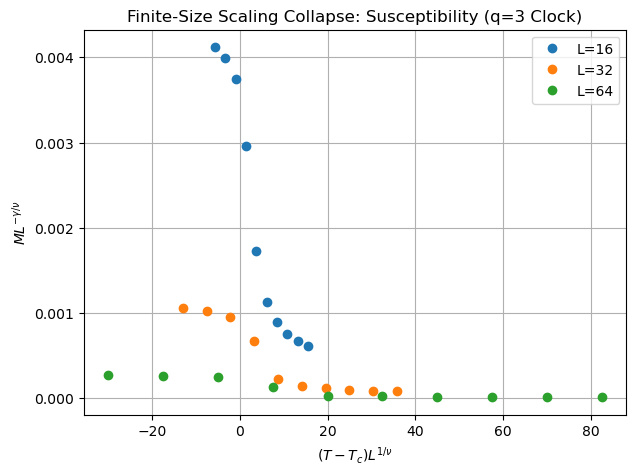

In [51]:
Tc = 1.45      # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = slope   # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    M_arr = results[L]["M"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = M_arr / (L**gamma_over_nu)

    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$ML^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.show()

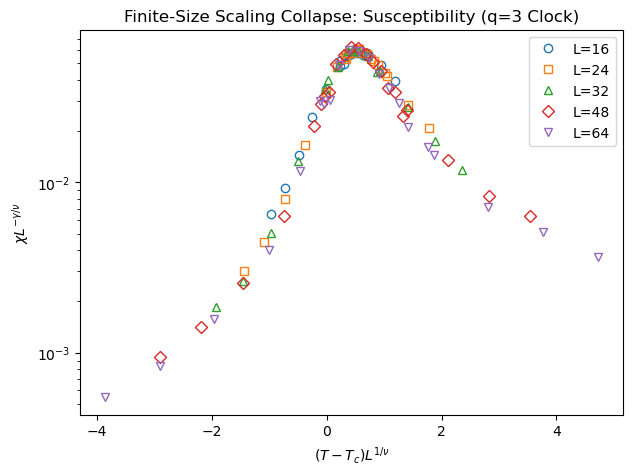

In [51]:
Tc = 1.490
nu = 1
gamma_over_nu = slope

plt.figure(figsize=(7,5))
markers = ['o', 's', '^', 'D', 'v']
for i, L in enumerate(L_values):

    T_arr = np.array(results[L]["T"])      # adaptive temperatures
    chi_arr = np.array(results[L]["chi"])

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, marker=markers[i % len(markers)], mfc='none',
        linestyle='', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.yscale('log')
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.grid(False)

plt.savefig("FSSCollapseq3ClockBinderResolvedIntAdapt3.1LogAboveTheoGrid.pdf")
plt.show()

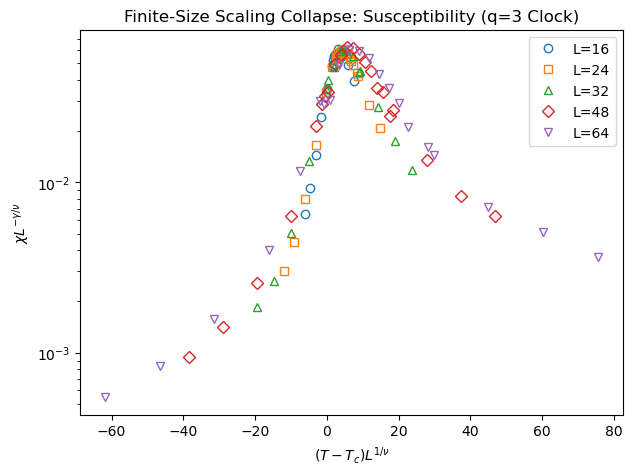

In [53]:
Tc = 1.490
nu = 0.6
gamma_over_nu = slope

plt.figure(figsize=(7,5))
markers = ['o', 's', '^', 'D', 'v']
for i, L in enumerate(L_values):

    T_arr = np.array(results[L]["T"])      # adaptive temperatures
    chi_arr = np.array(results[L]["chi"])

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, marker=markers[i % len(markers)], mfc = 'none',
        linestyle='', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")

plt.yscale('log')
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
#plt.grid(True)

plt.savefig("FSSCollapseq3ClockBinderResolvedIntAdapt3.1LogBelowTheoGrid.pdf")
plt.show()

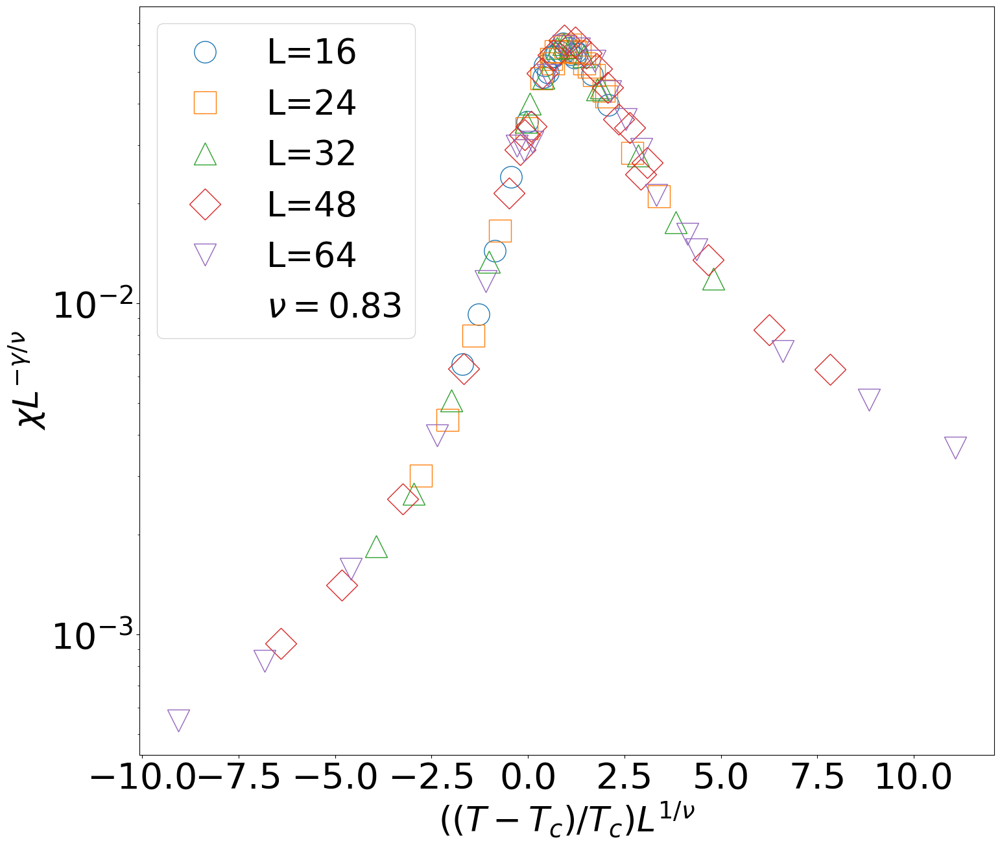

In [13]:
Tc = 1.490
nu = 0.83
gamma_over_nu = slope

plt.figure(figsize=(17,15))
markers = ['o', 's', '^', 'D', 'v']
for i, L in enumerate(L_values):

    T_arr = np.array(results[L]["T"])      # adaptive temperatures
    chi_arr = np.array(results[L]["chi"])

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, marker=markers[i % len(markers)], ms = 24, mfc = 'none',
        linestyle='', label=f"L={L}")
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$((T - T_c)/T_c)L^{1/\nu}$", fontsize = 38)
plt.ylabel(r"$\chi L^{-\gamma/\nu}$",fontsize = 38)
plt.xticks(fontsize = 40)
plt.yticks(fontsize = 40)
plt.yscale('log')
#plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend(fontsize = 38)
#plt.grid(True)

plt.savefig("FSSCollapseq3ClockBinderResolvedIntAdapt3.1LogAroundTheoFontSize.pdf")
plt.show()

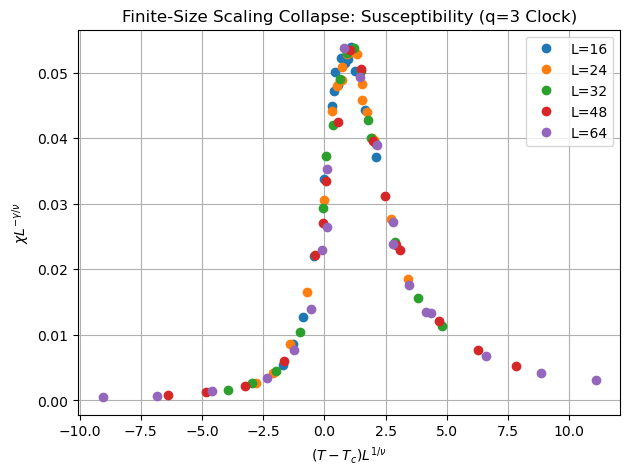

In [22]:
Tc = 1.490
nu = 0.83
gamma_over_nu = slope

plt.figure(figsize=(7,5))

for L in L_values:

    T_arr = np.array(results[L]["T"])      # adaptive temperatures
    chi_arr = np.array(results[L]["chi"])

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.grid(True)

plt.savefig("FSSCollapseq3ClockBinderResolvedIntAdapt2.png")
plt.show()

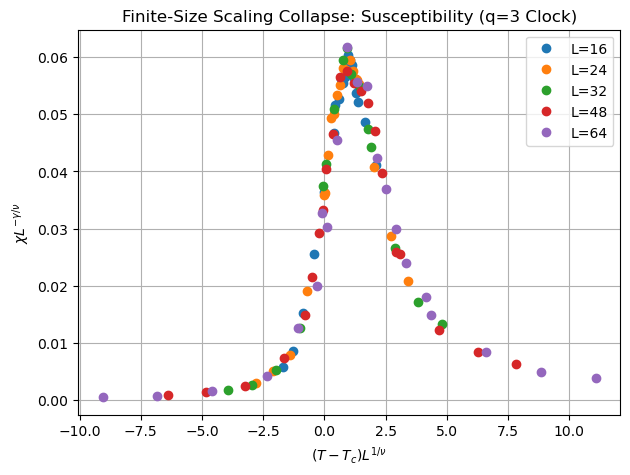

In [35]:
Tc = 1.490
nu = 0.83
gamma_over_nu = slope

plt.figure(figsize=(7,5))

for L in L_values:

    T_arr = np.array(results[L]["T"])      # adaptive temperatures
    chi_arr = np.array(results[L]["chi"])

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.grid(True)

plt.savefig("FSSCollapseq3ClockBinderResolvedIntAdapt.png")
plt.show()

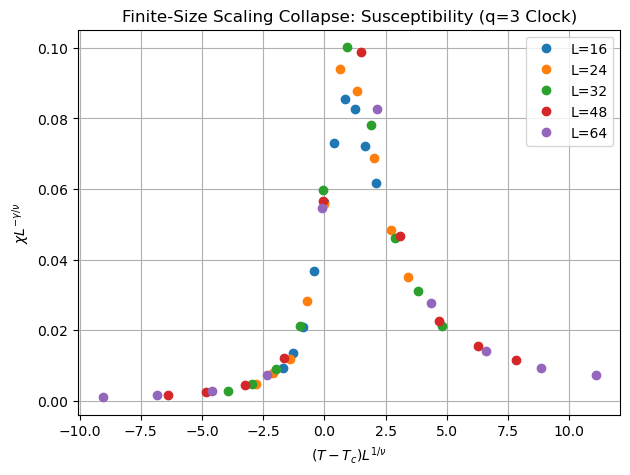

In [67]:
Tc = 1.490     # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = slope   # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)
    #mask = np.abs(x) <3
    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.savefig("FSSCollapseq3ClockBinderResolvedInt.png")
plt.grid(True)
plt.show()

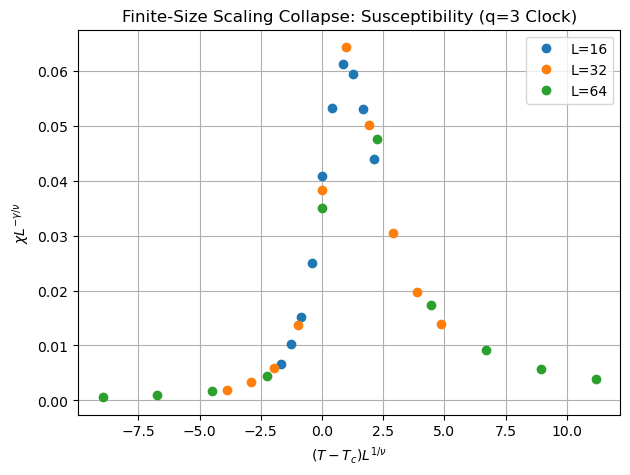

In [47]:
Tc = 1.489      # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = 1.73   # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)
    #mask = np.abs(x) <3
    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.savefig("FSSCollapseq3ClockBinderResolved3.2Theo.png")
plt.grid(True)
plt.show()

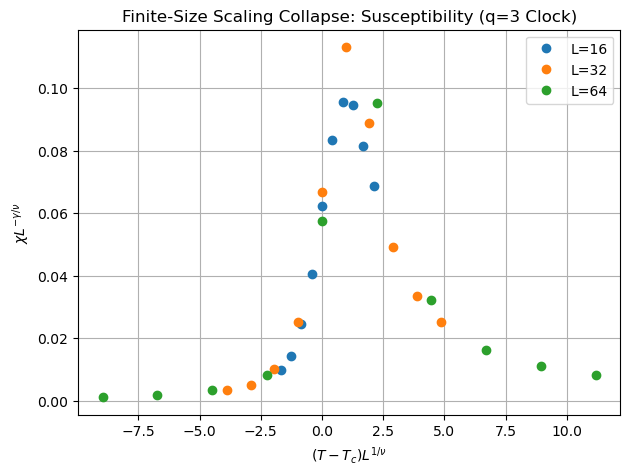

In [32]:
Tc = 1.489      # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = 1.57   # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)
    
    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.savefig("FSSCollapseq3ClockBinderResolved2.png")
plt.grid(True)
plt.show()

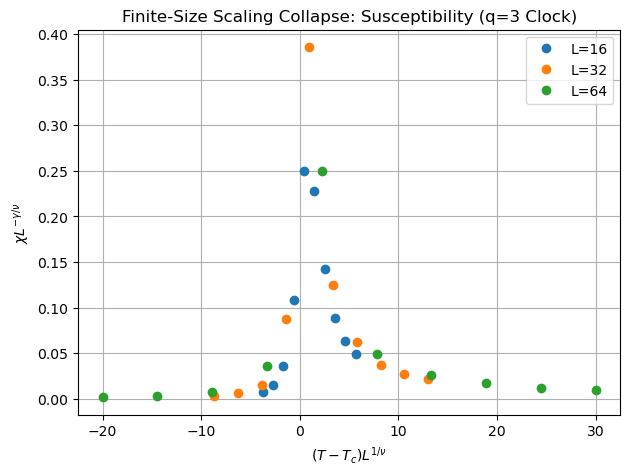

In [33]:
Tc = 1.5      # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = slope   # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.savefig("FSSCollapseq3ClockBinderResolved.png")
plt.grid(True)
plt.show()

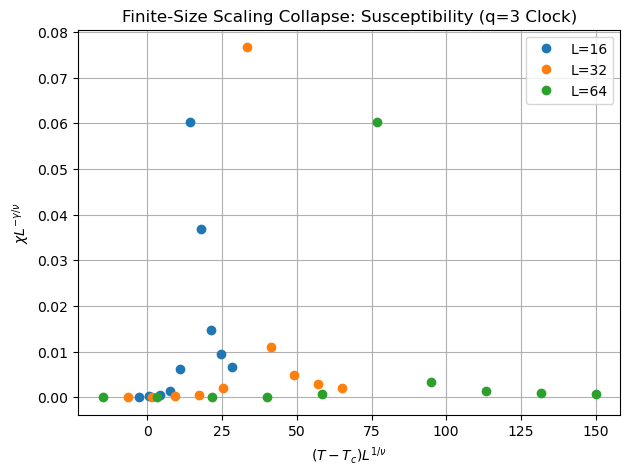

In [27]:
Tc = 1.0      # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = slope   # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.show()

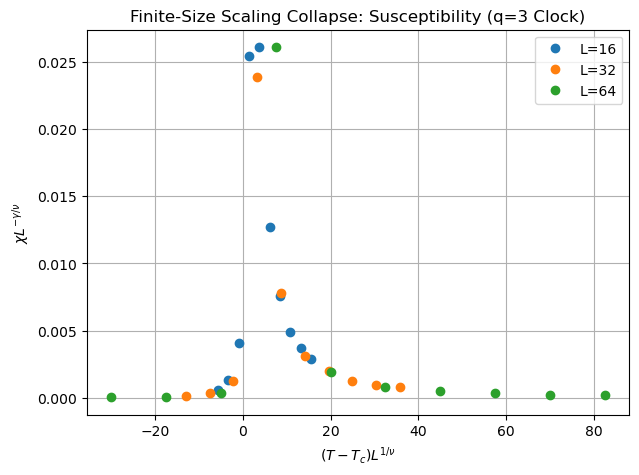

In [49]:
Tc = 1.45      # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = slope   # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    chi_arr = results[L]["chi"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.show()

### Four Response Functions of q=4 state clock model (Cluster Alg.)

print("")

In [15]:
# Parameters
J = 1.0  # Interaction strength
h = 0  # External field
q = 4
sweeps = 5*10**4  # Total Monte Carlo steps
#burn_frac = 2**18
L_values = [16, 24, 32, 48, 64]  # Different lattice sizes to test

# Temperature range
#L = 16
# Temperature range
#beta_core = np.linspace(0.4, 1.2, 8)
#delta_beta = beta_core[1] - beta_core[0]
#beta_extra_low = beta_core[0] - delta_beta
#beta_extra_high = beta_core[-1] + delta_beta
#beta_values = np.concatenate([[beta_extra_low], beta_core, [beta_extra_high]])
T_values = np.linspace(1, 1.45, 10)
#T_values = np.linspace(0.95, 1.1, 10)
beta_values = 1/T_values

In [5]:
q = 4
J = 1.0

# Spin angles
ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)
# cos(theta_i - theta_j) lookup
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# ------------------------------------------------------------
# Precompute interaction matrix:
# E_bond[s_i, s_j] = -J cos(theta_i - theta_j)
# ------------------------------------------------------------
E_BOND = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        E_BOND[i, j] = -J * np.cos(ANGLES[i] - ANGLES[j])

# ------------------------------------------------------------
# Reflection table
# ------------------------------------------------------------
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)],
    [(3-k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================
def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# MAGNETIZATION (vector)
# ============================================================
def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1)%L, y]
            s_up = spins[x, (y+1)%L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E
# ============================================================
# WOLFF CLUSTER (FULLY OPTIMIZED)
# ============================================================
def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    #visited = np.zeros((L, L), dtype=bool)
    visited.fill(False)
    # random reflection axis
    r = np.random.randint(0, q)

    # random seed
    x0, y0 = np.random.randint(0, L, size=2)
    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0

    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        # 4 neighbors
        for nx, ny in (
            ((x+1)%L, y),
            ((x-1)%L, y),
            (x, (y+1)%L),
            (x, (y-1)%L),
        ):

            sj = spins[nx, ny]

            if not visited[nx, ny]:

            # correct embedding delta (NO bond energy!)
                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))

    # --------------------------------------------------------
    # Boundary energy correction
    # --------------------------------------------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]
        for nx, ny in (
            ((x+1)%L, y),
            ((x-1)%L, y),
            (x, (y+1)%L),
            (x, (y-1)%L),
        ):

        
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])

                
    # Flip cluster
    for x, y in cluster:
        spins[x, y] = REFLECT[r, spins[x, y]]

    return len(cluster), E_current + dE


# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================
def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q


# ============================================================
# MAIN SIMULATION
# ============================================================
def run_simulation(
    L,
    T,
    sweeps=10**5,
    J = 1,
    burn_frac=0.2,
    sample_interval = 1
    
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L,L), dtype=bool)
    # Initial full energy (computed once only)
    E = total_energy(spins)
    

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        #flipped = 0
        #while flipped < L * L:
        csize, E = wolff_cluster_q3(spins, beta, E, visited)
            #flipped += csize

        global_rotate(spins)

        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:

            Mx, My = magnetization(spins)
            M_samples.append(np.sqrt(Mx**2 + My**2))

            E_samples.append(E)

    # --------------------------------------------------------
    # Observables
    # --------------------------------------------------------
    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)

    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v


In [19]:

# ============================================================
# PARAMETERS
# ============================================================

q = 4
J = 1.0

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# Reflection table
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)],
    [(3 - k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# TOTAL ENERGY (computed once)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E


# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    r = np.random.randint(0, q)

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ----------------------
    # Grow cluster ONLY
    # ----------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))
       # ----------------------
    # Boundary correction
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])
    # ----------------------
    # Flip + magnetization
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref


    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r


# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=10**5,
    J=J,
    burn_frac=0.3,
    sample_interval=1
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L, L), dtype=bool)

    # Initial observables
    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster_q3(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        # Rotate magnetization accordingly
        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c
    
        # --- Measurements
        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ============================================================
    # Observables
    # ============================================================

    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)
    U = 1 - M4_mean/(3*(M2_mean**2))
    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U

In [5]:
# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# Reflection table
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)],
    [(3 - k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# TOTAL ENERGY (computed once)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E


# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================
DELTA = np.zeros((q,q,q))
for r in range(q):
    for si in range(q):
        si_ref = REFLECT[r,si]
        for sj in range(q):
            DELTA[r,si,sj] = COS_DIFF[si,sj] - COS_DIFF[si_ref,sj]
            
def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    r = np.random.randint(0, q)

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ----------------------
    # Grow cluster ONLY
    # ----------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                #delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]
                delta = DELTA[r,si,sj]
                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))
       # ----------------------
    # Boundary correction
    # ----------------------

    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                delta = DELTA[r,si,sj]
                dE += J * delta
    # ----------------------
    # Flip + magnetization
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref


    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r


# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=10**5,
    spins=None,
    J=J,
    burn_frac=0.2,
    sample_interval=1
):

    beta = 1.0 / T

     # ---- USE EXISTING CONFIGURATION IF PROVIDED
    if spins is None:
        spins = new_state(L)
    else:
        spins = spins.copy()
    
    visited = np.zeros((L,L), dtype=bool)
    # Initial observables
    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster_q3(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        # Rotate magnetization accordingly
        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c
    
        # --- Measurements
        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ============================================================
    # Observables
    # ============================================================

    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)
    U = 1 - M4_mean/(3*(M2_mean**2))
    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U, spins
def adaptive_temperature_scan(
    L,
    T_values,
    sweeps=10**5,
    refine_iterations=2,
    refine_width=0.03,
    refine_points=4
):

    results = {}
    configs = {}

    # ------------------------------------------------
    # INITIAL COARSE SCAN
    # ------------------------------------------------

    for T in T_values:

        M, chi, E, Cv, U, spins = run_simulation(
            L,
            T,
            sweeps=sweeps
        )

        results[T] = (M, chi, E, Cv, U) # Store the computed results
        configs[T] = spins # Stores final spin configurations

    # ------------------------------------------------
    # ADAPTIVE REFINEMENT
    # ------------------------------------------------

    for it in range(refine_iterations):

        Ts = np.array(sorted(results.keys()))
        chis = np.array([results[T][1] for T in Ts])
        cvs = np.array([results[T][3] for T in Ts])

        # choose strongest peak
        peak_index = np.argmax(chis + cvs)
        T_peak = Ts[peak_index]

        print(f"L={L} refinement {it+1} peak near T = {T_peak:.5f}")

        new_Ts = np.linspace(     # Generate new temperatures
            T_peak - refine_width,
            T_peak + refine_width,
            refine_points
        )

        for T in new_Ts:

            if T not in results:

                # start from closest configuration
                closest = Ts[np.argmin(np.abs(Ts - T))]
                start_config = configs[closest]

                M, chi, E, Cv, U, spins = run_simulation(
                    L,
                    T,
                    sweeps=sweeps//2,
                    spins=start_config,
                    burn_frac=0.05
                )

                results[T] = (M, chi, E, Cv, U)
                configs[T] = spins

    return results

In [17]:
import time 
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "time": []} for L in L_values}

for T in T_values:
    print(f"\nRunning simulations for T = {T:.3f} (β = {1/T:.3f})...")
    for L in L_values:
        start_time = time.time()  # ⏱ start timer

        M_avg_per_site, chi_M, E_avg_per_site, C_v = run_simulation(
            L, T, sweeps=sweeps, J=J, burn_frac=0.2
        )

        end_time = time.time()
        elapsed = end_time - start_time
 
        results[L]["M_x"].append(M_avg_per_site)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site) 
        results[L]["time"].append(elapsed) 
        
        print(f"  L={L:2d} → done in {elapsed/60: .2f} min | M={M_avg_per_site:.4f}, χ={chi_M:.4e}")
# Convert lists to arrays
for L in L_values:
    for key in results[L]:
        results[L][key] = np.array(results[L][key])

# Save everything
save_dict = {
    "T_values": np.array(T_values),
    "L_values": np.array(L_values)
}

for L in L_values:
    for key in results[L]:
        save_dict[f"L{L}_{key}"] = results[L][key]

np.savez_compressed("clock_q4_simulation_resolveddatabinder.npz", **save_dict)

print("\nData saved successfully.")



Running simulations for T = 0.850 (β = 1.176)...


ValueError: too many values to unpack (expected 4)

In [23]:
# --- Storage ---
results = {
    L: {
        "M": [],
        "chi": [],
        "E": [],
        "Cv": [],
        "Binder": []
    }
    for L in L_values
}

# --- Loop over sizes and temperatures ---
for L in L_values:
    print(f"\nRunning simulations for L = {L}")

    for T in T_values:
        start_time = time.time()

        M, chi, E, Cv, U = run_simulation(
            L, T,
            sweeps=sweeps,
            J=J,
            burn_frac=0.3
        )

        results[L]["M"].append(M)
        results[L]["chi"].append(chi)
        results[L]["E"].append(E)
        results[L]["Cv"].append(Cv)
        results[L]["Binder"].append(U)

        elapsed = time.time() - start_time
        print(f"T = {T:.3f} | U = {U:.4f} | time = {elapsed/60:.2f} min")


for L in L_values:
    for key in results[L]:
        results[L][key] = np.array(results[L][key])
        
save_dict = {
    "T_values": np.array(T_values),
    "L_values": np.array( L_values)
}

for L in L_values:
    for key in results[L]:
        save_dict[f"L{L}_{key}"] = results[L][key]

np.savez_compressed("clock_q4_binderresolvedsimulationInt16-64_data.npz", **save_dict)

print("\nData saved successfully.")


Running simulations for L = 16
T = 0.850 | U = 0.6663 | time = 1.91 min
T = 0.941 | U = 0.6658 | time = 1.98 min
T = 1.032 | U = 0.6631 | time = 1.80 min
T = 1.123 | U = 0.6450 | time = 1.33 min
T = 1.214 | U = 0.5658 | time = 0.73 min
T = 1.306 | U = 0.4727 | time = 0.38 min
T = 1.397 | U = 0.4083 | time = 0.26 min
T = 1.488 | U = 0.3800 | time = 0.17 min
T = 1.579 | U = 0.3646 | time = 0.16 min
T = 1.670 | U = 0.3613 | time = 0.12 min

Running simulations for L = 24
T = 0.850 | U = 0.6665 | time = 5.19 min
T = 0.941 | U = 0.6662 | time = 5.24 min
T = 1.032 | U = 0.6648 | time = 4.84 min
T = 1.123 | U = 0.6482 | time = 3.61 min
T = 1.214 | U = 0.5170 | time = 1.20 min
T = 1.306 | U = 0.4010 | time = 0.47 min
T = 1.397 | U = 0.3642 | time = 0.31 min
T = 1.488 | U = 0.3706 | time = 0.21 min
T = 1.579 | U = 0.3596 | time = 0.17 min
T = 1.670 | U = 0.3405 | time = 0.15 min

Running simulations for L = 32
T = 0.850 | U = 0.6666 | time = 8.52 min
T = 0.941 | U = 0.6664 | time = 7.09 min
T 

In [9]:
def unpack_results(results_dict):

    Ts = np.array(sorted(results_dict.keys()))

    M = []
    chi = []
    E = []
    Cv = []
    Binder = []

    for T in Ts:
        m, c, e, cv, u = results_dict[T]
        M.append(m)
        chi.append(c)
        E.append(e)
        Cv.append(cv)
        Binder.append(u)

    return Ts, np.array(M), np.array(chi), np.array(E), np.array(Cv), np.array(Binder)
# --- Storage ---
results = {
    L: {
        "T": [],
        "M": [],
        "chi": [],
        "E": [],
        "Cv": [],
        "Binder": []
    }
    for L in L_values
}

# -------------------------------------------------
# Adaptive simulations
# -------------------------------------------------

for L in L_values:

    print(f"\nRunning adaptive simulations for L = {L}")

    start_total = time.time()

    # Run adaptive scan
    adaptive_results = adaptive_temperature_scan(
        L,
        T_values,
        sweeps=sweeps,
        refine_iterations=3,
        refine_width=0.02,
        refine_points=6
    )

    # Convert dictionary → arrays
    Ts, M, chi, E, Cv, Binder = unpack_results(adaptive_results)

    results[L]["T"] = Ts
    results[L]["M"] = M
    results[L]["chi"] = chi
    results[L]["E"] = E
    results[L]["Cv"] = Cv
    results[L]["Binder"] = Binder

    elapsed = time.time() - start_total
    print(f"L={L} completed in {elapsed/60:.2f} minutes")


# -------------------------------------------------
# Save results
# -------------------------------------------------

save_dict = {}

for L in L_values:
    save_dict[f"L{L}_T"] = results[L]["T"]
    save_dict[f"L{L}_M"] = results[L]["M"]
    save_dict[f"L{L}_chi"] = results[L]["chi"]
    save_dict[f"L{L}_E"] = results[L]["E"]
    save_dict[f"L{L}_Cv"] = results[L]["Cv"]
    save_dict[f"L{L}_Binder"] = results[L]["Binder"]

save_dict["L_values"] = np.array(L_values)

np.savez_compressed(
    "clock_q4_binderresolvedsimulationAdaptLog16-64_data.npz",
    **save_dict
)

print("\nData saved successfully.")



Running adaptive simulations for L = 16
L=16 refinement 1 peak near T = 1.20000
L=16 refinement 2 peak near T = 1.22000
L=16 refinement 3 peak near T = 1.22000
L=16 completed in 29.09 minutes

Running adaptive simulations for L = 24
L=24 refinement 1 peak near T = 1.20000
L=24 refinement 2 peak near T = 1.18000
L=24 refinement 3 peak near T = 1.18000
L=24 completed in 25.99 minutes

Running adaptive simulations for L = 32
L=32 refinement 1 peak near T = 1.20000
L=32 refinement 2 peak near T = 1.18000
L=32 refinement 3 peak near T = 1.16800
L=32 completed in 20.37 minutes

Running adaptive simulations for L = 48
L=48 refinement 1 peak near T = 1.15000
L=48 refinement 2 peak near T = 1.15400
L=48 refinement 3 peak near T = 1.15400
L=48 completed in 41.64 minutes

Running adaptive simulations for L = 64
L=64 refinement 1 peak near T = 1.15000
L=64 refinement 2 peak near T = 1.15400
L=64 refinement 3 peak near T = 1.15800
L=64 completed in 65.26 minutes

Data saved successfully.


In [7]:
data = np.load("clock_q4_binderresolvedsimulationAdaptLog16-64_data.npz")
print(data.files)

['L16_T', 'L16_M', 'L16_chi', 'L16_E', 'L16_Cv', 'L16_Binder', 'L24_T', 'L24_M', 'L24_chi', 'L24_E', 'L24_Cv', 'L24_Binder', 'L32_T', 'L32_M', 'L32_chi', 'L32_E', 'L32_Cv', 'L32_Binder', 'L48_T', 'L48_M', 'L48_chi', 'L48_E', 'L48_Cv', 'L48_Binder', 'L64_T', 'L64_M', 'L64_chi', 'L64_E', 'L64_Cv', 'L64_Binder', 'L_values']


In [9]:
L_values = [16, 24, 32, 48, 64]   # set your lattice sizes

results = {}

for L in L_values:

    results[L] = {
        "T": data[f"L{L}_T"],
        "M": data[f"L{L}_M"],
        "chi": data[f"L{L}_chi"],
        "E": data[f"L{L}_E"],
        "Cv": data[f"L{L}_Cv"],
        "Binder": data[f"L{L}_Binder"]
    }

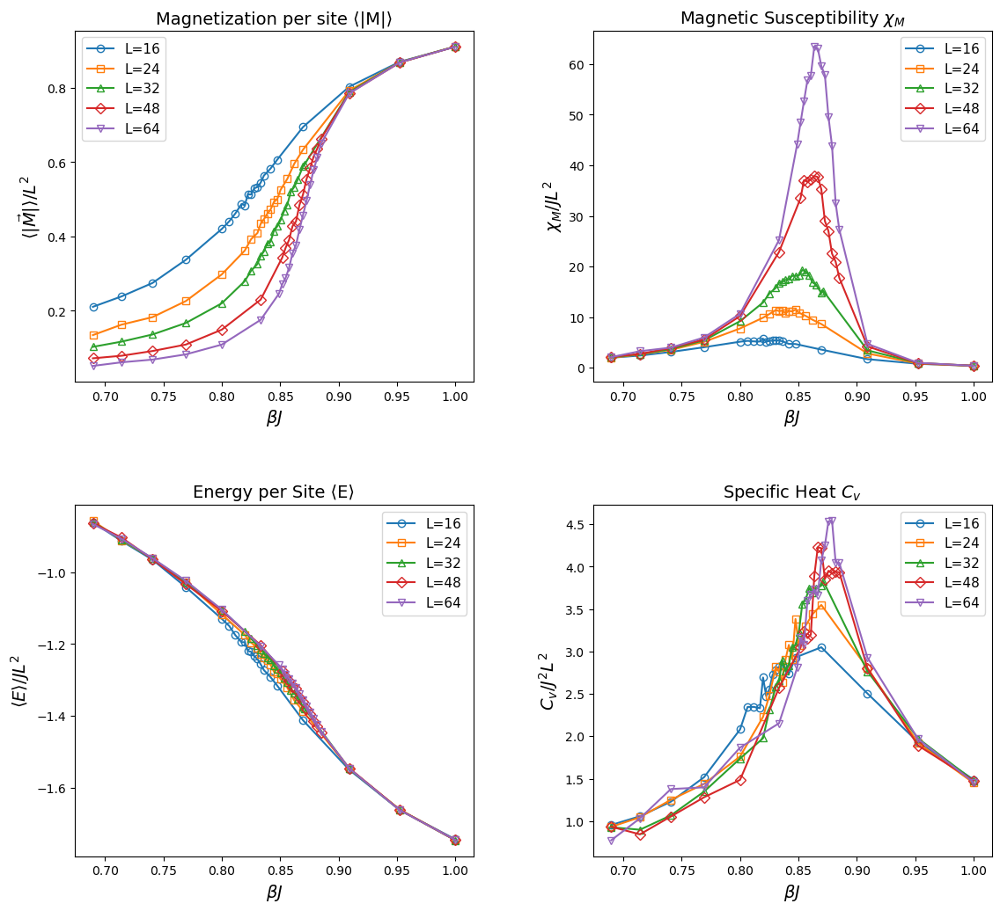

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility $χ_M$",
    "Energy per Site ⟨E⟩",
    "Specific Heat $C_v$"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    r"$\langle E \rangle / JL^2$",
    r"$C_v / J^2 L^2$"
]

keys = ["M", "chi", "E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):

        T_vals = results[L]["T"]
        beta_vals = 1.0 / T_vals

        ax.plot(
            beta_vals,
            results[L][key],
            marker=markers[j % len(markers)], mfc='none',
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    #ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncClockBinderResolvedIntAdaptive4-state-16-64.pdf",
    dpi=300
)

plt.show()

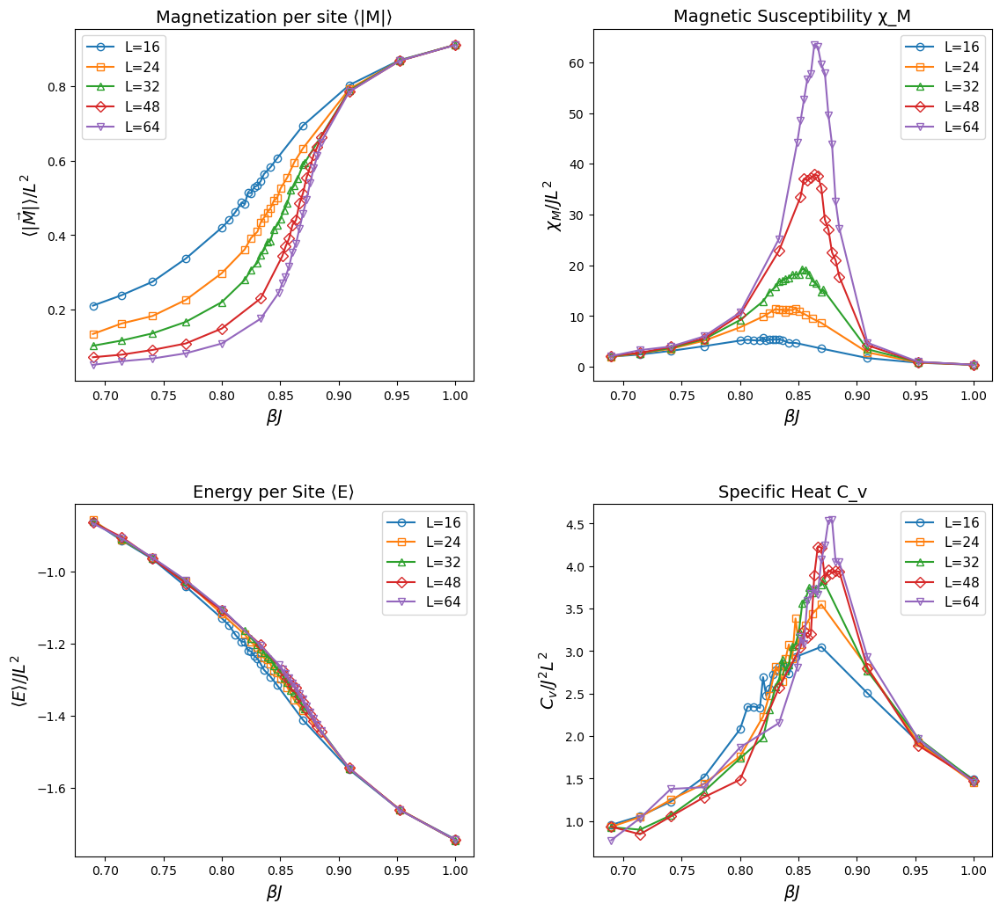

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility χ_M",
    "Energy per Site ⟨E⟩",
    "Specific Heat C_v"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    r"$\langle E \rangle / JL^2$",
    r"$C_v / J^2 L^2$"
]

keys = ["M", "chi", "E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):

        T_vals = results[L]["T"]
        beta_vals = 1.0 / T_vals

        ax.plot(
            beta_vals,
            results[L][key],
            marker=markers[j % len(markers)], mfc='none',
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    #ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncClockBinderResolvedIntAdaptive4-state-16-64.pdf",
    dpi=300
)

plt.show()

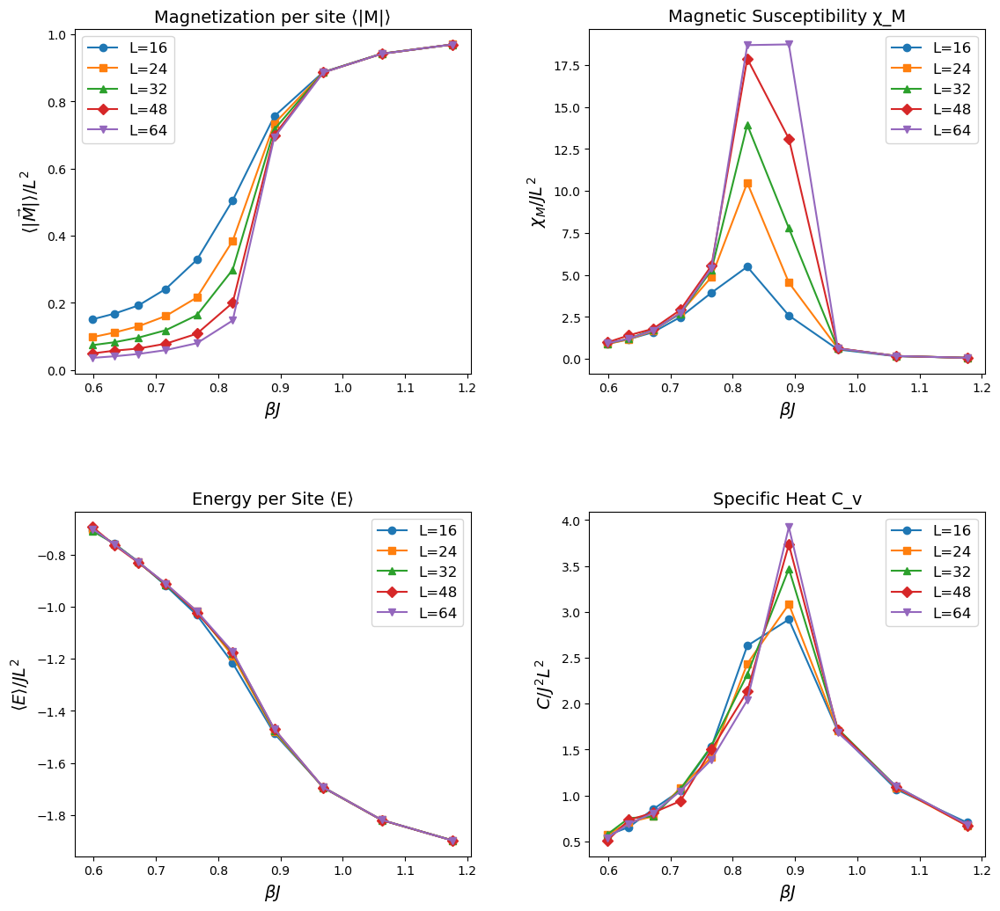

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$βJ$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    #ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClock4ResolvedBinder-state-16-64.png")
plt.show()


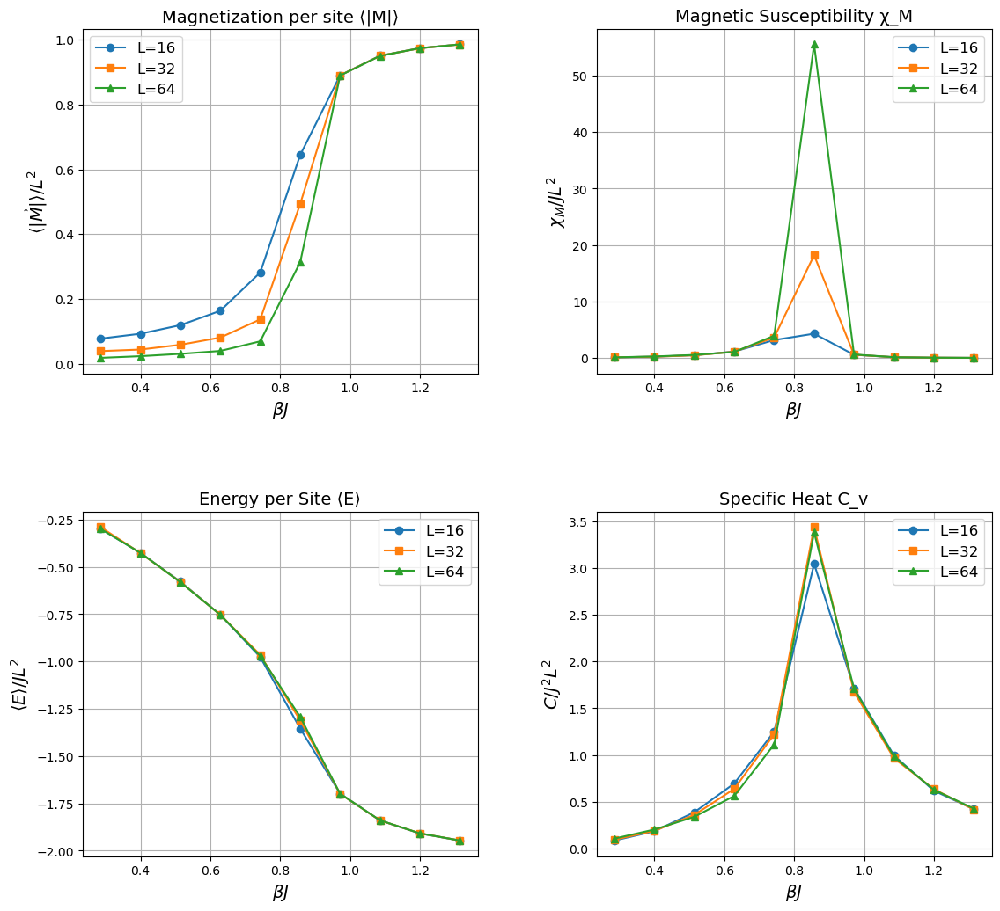

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$βJ$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClock4Resolved-state-16-64.png")
plt.show()


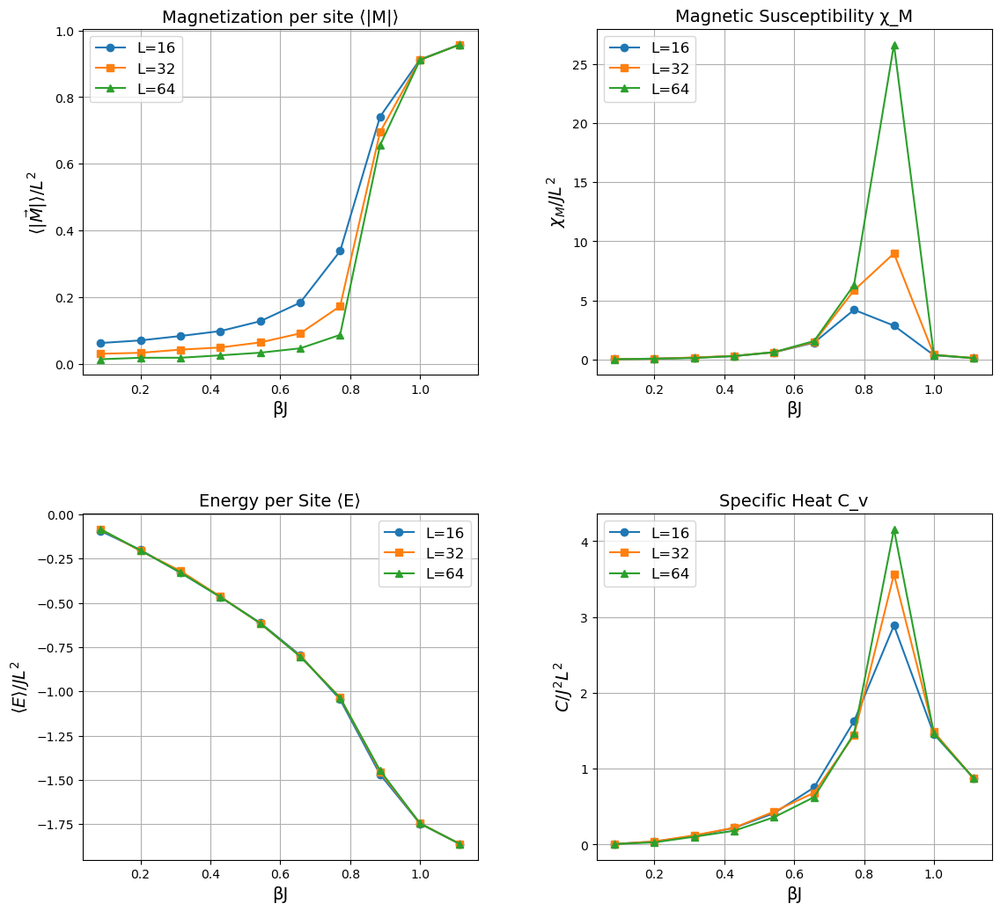

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClock4-state-16-64.png")
plt.show()


Slope = -0.2316
Estimated β/ν = 0.2316
Intercept = 0.2822
R² = 0.9838


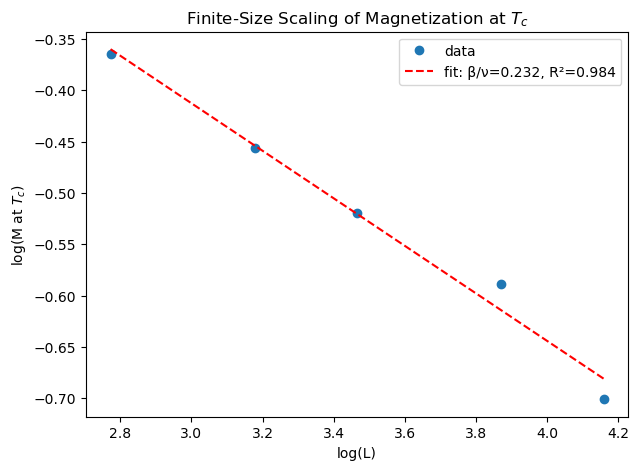

In [61]:
from scipy.stats import linregress
import numpy as np
import matplotlib.pyplot as plt

Tc = 1.145  # your estimated critical temperature

# --- Collect M(Tc) for each L ---
M_Tc_values = []

for L in L_values:

    T_arr = np.array(results[L]["T"])
    M_arr = np.array(results[L]["M"])

    # Find index closest to Tc
    idx = np.argmin(np.abs(T_arr - Tc))

    M_Tc = M_arr[idx]
    M_Tc_values.append(M_Tc)

M_Tc_values = np.array(M_Tc_values)
L_array = np.array(L_values)

# --- Log-log fit: M ~ L^(-β/ν) ---
logL = np.log(L_array)
logM = np.log(M_Tc_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logM)

beta_over_nu = -slope  # IMPORTANT: negative slope

# --- Print results ---
print(f"Slope = {slope:.4f}")
print(f"Estimated β/ν = {beta_over_nu:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot ---
plt.figure(figsize=(7,5))

plt.plot(logL, logM, 'o', label="data")
plt.plot(
    logL,
    intercept + slope * logL,
    'r--',
    label=f"fit: β/ν={beta_over_nu:.3f}, R²={r_value**2:.3f}"
)

plt.xlabel("log(L)")
plt.ylabel("log(M at $T_c$)")
plt.title("Finite-Size Scaling of Magnetization at $T_c$")
plt.legend()
#plt.grid(True)

plt.savefig("FSS_beta_over_nu_q4_clock.pdf")
plt.show()

Slope (γ/ν) = 1.7311
Intercept = -3.0537
R² = 0.9999


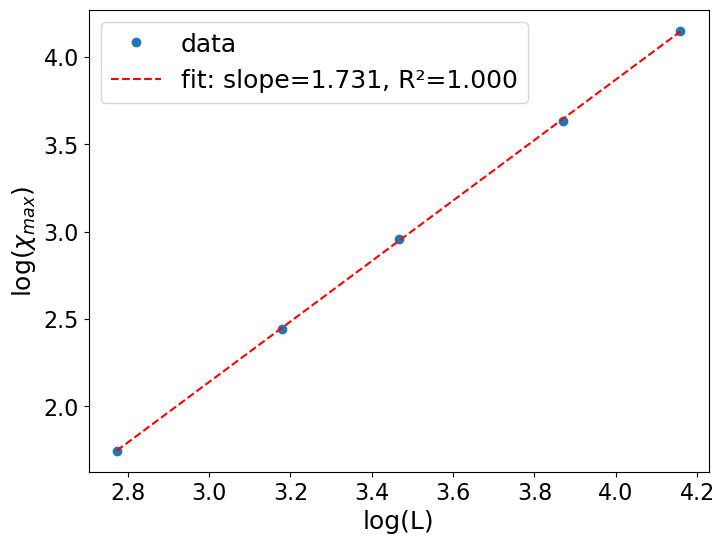

In [101]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(8,6))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)", fontsize = 18)
plt.ylabel("log($χ_{max}$)", fontsize = 18)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
#plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend(fontsize=18)
plt.grid(False)
plt.savefig("FSSq4ClockResolvedBinderIntAdaptFontSize-16-64.pdf")
plt.show()


Slope (γ/ν) = 0.8704
Intercept = -0.5368
R² = 0.9060


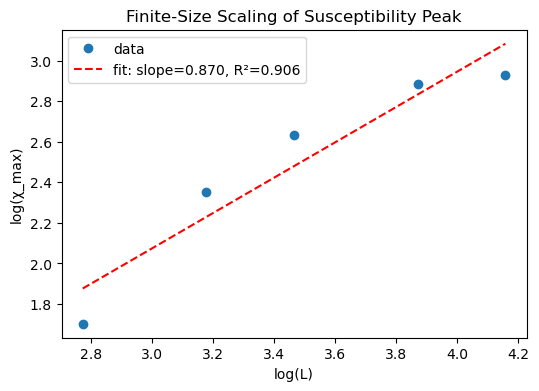

In [37]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
#plt.grid(True)
plt.savefig("FSSq4ClockResolvedBinder-16-64.png")
plt.show()


Slope (γ/ν) = 1.8447
Intercept = -3.6013
R² = 0.9946


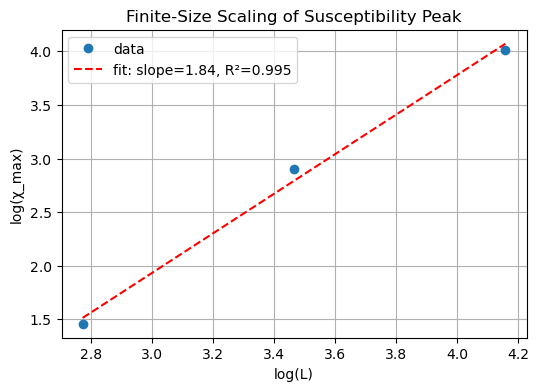

In [27]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi_M"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq4ClockResolved-16-64.png")
plt.show()


Crossing L=16 and L=24: T = 1.15010432
Crossing L=24 and L=32: T = 1.14873512
Crossing L=32 and L=48: T = 1.13811880
Crossing L=48 and L=64: T = 1.12371323

Estimated Tc from largest systems:
L = 48 and L = 64
Tc = 1.12371323


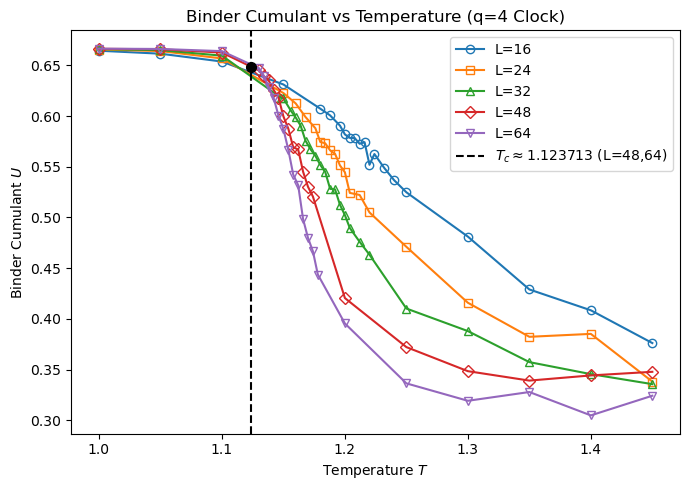

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter


# =========================================================
# PLOT BINDER CUMULANT
# =========================================================

plt.figure(figsize=(7, 5))

markers = ['o', 's', '^', 'D', 'v']

# Store curves
curves = []


# =========================================================
# PLOT ORIGINAL DATA
# =========================================================

for i, L in enumerate(L_values):

    T_arr = np.asarray(results[L]["T"])
    binder_arr = np.asarray(results[L]["Binder"])

    # -----------------------------------------------------
    # Sort temperatures
    # -----------------------------------------------------

    order = np.argsort(T_arr)

    T_arr = T_arr[order]
    binder_arr = binder_arr[order]

    # -----------------------------------------------------
    # Remove duplicate temperature values if any
    # -----------------------------------------------------

    T_unique, unique_indices = np.unique(
        T_arr,
        return_index=True
    )

    binder_unique = binder_arr[unique_indices]

    # -----------------------------------------------------
    # Store
    # -----------------------------------------------------

    curves.append(
        (T_unique, binder_unique)
    )

    # -----------------------------------------------------
    # Plot ORIGINAL Binder data
    # -----------------------------------------------------

    plt.plot(
        T_unique,
        binder_unique,

        marker=markers[i % len(markers)],
        mfc='none',

        linestyle='-',

        label=f"L={L}"
    )


# =========================================================
# FUNCTION TO FIND CROSSING OF TWO CURVES
# =========================================================

def find_crossing(T1, U1, T2, U2):

    # -----------------------------------------------------
    # Find common temperature interval
    # -----------------------------------------------------

    Tmin = max(
        np.min(T1),
        np.min(T2)
    )

    Tmax = min(
        np.max(T1),
        np.max(T2)
    )

    if Tmin >= Tmax:
        return None

    # -----------------------------------------------------
    # Common dense temperature grid
    # -----------------------------------------------------

    T_common = np.linspace(
        Tmin,
        Tmax,
        5000
    )

    # -----------------------------------------------------
    # Smooth Binder curves
    #
    # This is important because statistical fluctuations can
    # create artificial crossings.
    # -----------------------------------------------------

    def smooth_curve(U):

        n = len(U)

        # Not enough points for smoothing
        if n < 7:
            return U

        # Window must be odd
        window = min(
            11,
            n if n % 2 == 1 else n - 1
        )

        if window < 5:
            return U

        return savgol_filter(
            U,
            window_length=window,
            polyorder=2
        )

    U1_smooth = smooth_curve(U1)
    U2_smooth = smooth_curve(U2)

    # -----------------------------------------------------
    # Interpolate smoothed curves
    # -----------------------------------------------------

    U1_interp = np.interp(
        T_common,
        T1,
        U1_smooth
    )

    U2_interp = np.interp(
        T_common,
        T2,
        U2_smooth
    )

    # -----------------------------------------------------
    # Difference between curves
    # -----------------------------------------------------

    difference = U1_interp - U2_interp

    # -----------------------------------------------------
    # Find SIGN CHANGES
    #
    # A genuine intersection occurs when the difference
    # changes from + to - or from - to +.
    # -----------------------------------------------------

    sign_changes = np.where(
        difference[:-1] * difference[1:] < 0
    )[0]

    if len(sign_changes) == 0:

        # No actual crossing detected
        return None

    # -----------------------------------------------------
    # Calculate every crossing
    # -----------------------------------------------------

    crossing_candidates = []

    for idx in sign_changes:

        T_left = T_common[idx]
        T_right = T_common[idx + 1]

        d_left = difference[idx]
        d_right = difference[idx + 1]

        # Linear interpolation to zero
        T_cross = (
            T_left
            - d_left
            * (T_right - T_left)
            / (d_right - d_left)
        )

        crossing_candidates.append(
            T_cross
        )

    # -----------------------------------------------------
    # Select the crossing that is most central in the
    # common temperature interval.
    #
    # This prevents a tiny numerical crossing at the edge
    # from being selected.
    # -----------------------------------------------------

    margin = 0.05 * (Tmax - Tmin)

    central_candidates = [
        T
        for T in crossing_candidates
        if Tmin + margin <= T <= Tmax - margin
    ]

    if len(central_candidates) > 0:

        crossing_candidates = central_candidates

    # -----------------------------------------------------
    # If several genuine crossings remain, choose the one
    # closest to the middle of the temperature interval.
    # -----------------------------------------------------

    T_middle = 0.5 * (Tmin + Tmax)

    T_cross = min(
        crossing_candidates,
        key=lambda T: abs(T - T_middle)
    )

    return T_cross


# =========================================================
# FIND PAIRWISE CROSSINGS
# =========================================================

pairwise_crossings = []


for i in range(len(curves) - 1):

    T1, U1 = curves[i]
    T2, U2 = curves[i + 1]

    L1 = L_values[i]
    L2 = L_values[i + 1]

    T_cross = find_crossing(
        T1,
        U1,
        T2,
        U2
    )

    if T_cross is not None:

        pairwise_crossings.append(
            (L1, L2, T_cross)
        )

        print(
            f"Crossing L={L1} and L={L2}: "
            f"T = {T_cross:.8f}"
        )


# =========================================================
# DETERMINE Tc FROM LARGEST TWO SYSTEMS
# =========================================================
#
# For finite-size scaling, the crossing of the largest
# lattice sizes is generally more useful than simply
# averaging all crossings.
#
# =========================================================

Tc_crossing = None

largest_L1 = L_values[-2]
largest_L2 = L_values[-1]

for L1, L2, T_cross in pairwise_crossings:

    if (
        L1 == largest_L1
        and
        L2 == largest_L2
    ):

        Tc_crossing = T_cross

        break


# =========================================================
# PLOT CROSSING INFORMATION
# =========================================================

if Tc_crossing is not None:

    # -----------------------------------------------------
    # Vertical dashed line
    # -----------------------------------------------------

    plt.axvline(
        Tc_crossing,
        color='black',
        linestyle='--',
        linewidth=1.5,

        label=(
            rf"$T_c \approx {Tc_crossing:.6f}$ "
            f"(L={largest_L1},{largest_L2})"
        )
    )

    # -----------------------------------------------------
    # Mark the crossing
    # -----------------------------------------------------

    T1, U1 = curves[-2]
    T2, U2 = curves[-1]

    U1_cross = np.interp(
        Tc_crossing,
        T1,
        U1
    )

    plt.plot(
        Tc_crossing,
        U1_cross,
        'ko',
        markersize=7
    )

    print(
        "\n========================================"
    )

    print(
        f"Estimated Tc from largest systems:"
    )

    print(
        f"L = {largest_L1} and L = {largest_L2}"
    )

    print(
        f"Tc = {Tc_crossing:.8f}"
    )

    print(
        "========================================"
    )

else:

    print(
        "\nNo crossing detected between "
        f"L={largest_L1} and L={largest_L2}."
    )


# =========================================================
# LABELS
# =========================================================

plt.xlabel(
    "Temperature $T$"
)

plt.ylabel(
    "Binder Cumulant $U$"
)

plt.title(
    "Binder Cumulant vs Temperature (q=4 Clock)"
)

plt.legend()

plt.grid(False)

plt.tight_layout()

plt.savefig(
    "BinderCumulantq4ClockResolvedIntAdaptLogGrid.pdf"
)

plt.show()

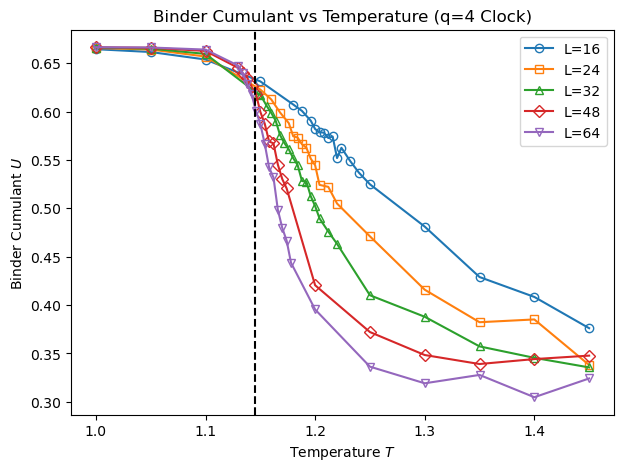

In [103]:
plt.figure(figsize=(7,5))
Tc=1.145
markers = ['o', 's', '^', 'D', 'v']
for i, L in enumerate(L_values):
    T_arr = results[L]["T"]          # adaptive temperature points
    binder_arr = results[L]["Binder"]

    plt.plot(T_arr, binder_arr, marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.axvline(Tc,  linestyle='--',
        linewidth=1.5, color = 'black')
plt.title("Binder Cumulant vs Temperature (q=4 Clock)")
plt.legend()
#plt.xlim(1.12,1.15)
plt.grid(False)

plt.savefig("BinderCumulantq4ClockResolvedIntAdaptLogGrid.pdf")
plt.show()

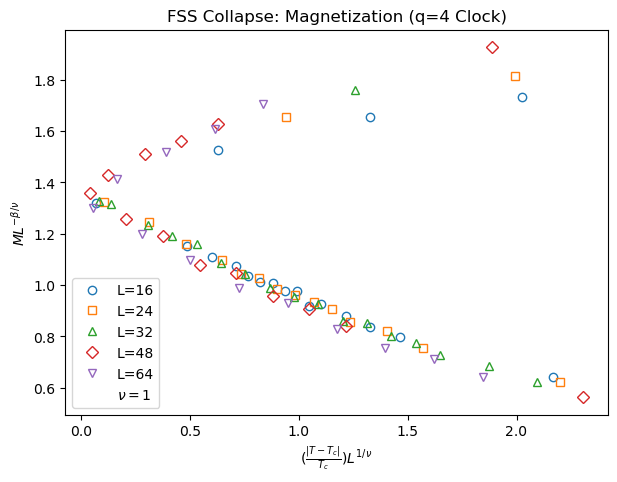

In [59]:
Tc = 1.145
nu = 1
beta_over_nu = slope   # ✅ correct for q=3

plt.figure(figsize=(7,5))

markers = ['o', 's', '^', 'D', 'v']

for i, L in enumerate(L_values):

    T_arr = np.array(results[L]["T"])
    M_arr = np.array(results[L]["M"])

    x = (np.abs(T_arr - Tc)/Tc) * L**(1/nu)
    y = M_arr / (L**beta_over_nu)

    # Optional window restriction (HIGHLY recommended)
    mask = np.abs(x) < 2.5

    plt.plot(
        x[mask],
        y[mask],
        marker=markers[i % len(markers)],
        linestyle='',
        label=f"L={L}", mfc = 'none'
    )
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$(\frac{|T - T_c|}{T_c})L^{1/\nu}$")
plt.ylabel(r"$M L^{-\beta/\nu}$")
#plt.yscale('log')
plt.title("FSS Collapse: Magnetization (q=4 Clock)")
plt.legend()
#plt.grid(True)
plt.savefig("FSSCollapseq4ClockBinderResolvedIntAdaptBeta.pdf")
plt.show()

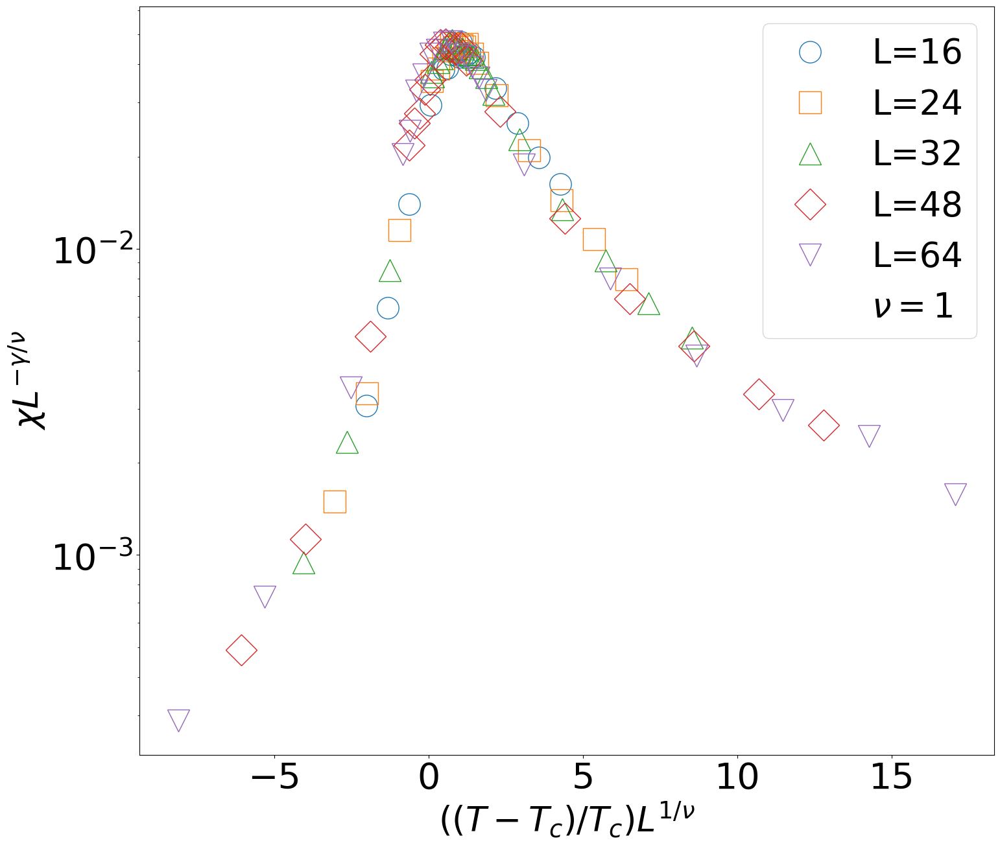

In [23]:
Tc = 1.145
nu = 1
gamma_over_nu = slope

plt.figure(figsize=(17,15))
markers = ['o', 's', '^', 'D', 'v']
for i, L in enumerate(L_values):

    T_arr = np.array(results[L]["T"])      # adaptive temperatures
    chi_arr = np.array(results[L]["chi"])

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, marker=markers[i % len(markers)], ms=24, mfc = 'none',
        linestyle='', label=f"L={L}")
plt.plot([], [], ' ', label=rf"$\nu = {nu}$")
plt.xlabel(r"$((T - T_c)/T_c)L^{1/\nu}$", fontsize=38)
plt.ylabel(r"$\chi L^{-\gamma/\nu}$", fontsize=38)
plt.xticks(fontsize = 40)
plt.yticks(fontsize = 40)
plt.yscale('log')
#plt.title("Finite-Size Scaling Collapse: Susceptibility (q=4 Clock)")
plt.legend(fontsize = 38)
#plt.grid(True)

plt.savefig("FSSCollapseq4ClockBinderResolvedIntAdaptLogAroundTheoFontSize.pdf")
plt.show()

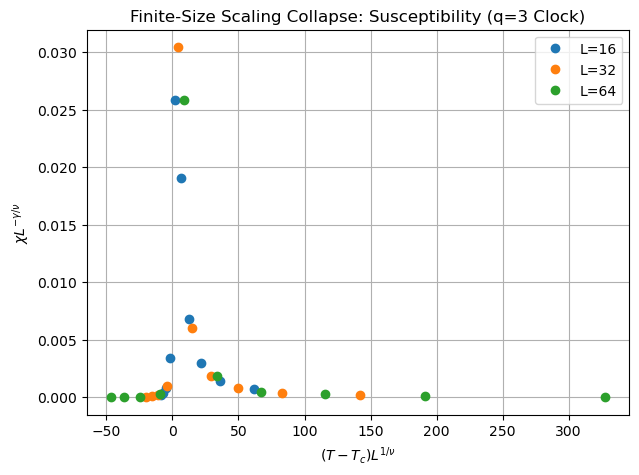

In [25]:
Tc = 1.1     # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = slope   # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    chi_arr = results[L]["chi_M"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=3 Clock)")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
q = 4
J = 1.0

# Spin angles
ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)
# cos(theta_i - theta_j) lookup
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# ------------------------------------------------------------
# Precompute interaction matrix:
# E_bond[s_i, s_j] = -J cos(theta_i - theta_j)
# ------------------------------------------------------------
E_BOND = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        E_BOND[i, j] = -J * np.cos(ANGLES[i] - ANGLES[j])

# ------------------------------------------------------------
# Reflection table
# ------------------------------------------------------------
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)],
    [(3-k) % q for k in range(q)]
])


# ============================================================
# INITIAL STATE
# ============================================================
def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# MAGNETIZATION (vector)
# ============================================================
def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1)%L, y]
            s_up = spins[x, (y+1)%L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E
# ============================================================
# WOLFF CLUSTER (FULLY OPTIMIZED)
# ============================================================
def wolff_cluster_q3(spins, beta, E_current, visited):

    L = spins.shape[0]
    #visited = np.zeros((L, L), dtype=bool)
    visited.fill(False)
    # random reflection axis
    r = np.random.randint(0, q)

    # random seed
    x0, y0 = np.random.randint(0, L, size=2)
    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0

    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        # 4 neighbors
        for nx, ny in (
            ((x+1)%L, y),
            ((x-1)%L, y),
            (x, (y+1)%L),
            (x, (y-1)%L),
        ):

            sj = spins[nx, ny]

            if not visited[nx, ny]:

            # correct embedding delta (NO bond energy!)
                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))

    # --------------------------------------------------------
    # Boundary energy correction
    # --------------------------------------------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]
        for nx, ny in (
            ((x+1)%L, y),
            ((x-1)%L, y),
            (x, (y+1)%L),
            (x, (y-1)%L),
        ):

        
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])

                
    # Flip cluster
    for x, y in cluster:
        spins[x, y] = REFLECT[r, spins[x, y]]

    return len(cluster), E_current + dE


# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================
def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q


# ============================================================
# MAIN SIMULATION
# ============================================================
def run_simulation(
    L,
    T,
    sweeps=10**5,
    J = 1,
    burn_frac=0.2,
    sample_interval = 1
    
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L,L), dtype=bool)
    # Initial full energy (computed once only)
    E = total_energy(spins)
    

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        #flipped = 0
        #while flipped < L * L:
        csize, E = wolff_cluster_q3(spins, beta, E, visited)
            #flipped += csize

        global_rotate(spins)

        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:

            Mx, My = magnetization(spins)
            M_samples.append(np.sqrt(Mx**2 + My**2))

            E_samples.append(E)

    # --------------------------------------------------------
    # Observables
    # --------------------------------------------------------
    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)
    U = 1 - M4_mean/(3*(M2_mean**2))
    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U


In [ ]:
# --- Storage ---
results = {
    L: {
        "M": [],
        "chi_M": [],
        "E": [],
        "Cv": [],
        "Binder": []
    }
    for L in L_values
}

# --- Loop over sizes and temperatures ---
for L in L_values:
    print(f"\nRunning simulations for L = {L}")

    for T in T_values:
        start_time = time.time()

        M, chi, E, Cv, U = run_simulation(
            L, T,
            sweeps=sweeps,
            J=J,
            burn_frac=0.3
        )

        results[L]["M"].append(M)
        results[L]["chi_M"].append(chi)
        results[L]["E"].append(E)
        results[L]["Cv"].append(Cv)
        results[L]["Binder"].append(U)

        elapsed = time.time() - start_time

        print(f"T = {T:.3f} | U = {U:.4f} | time = {elapsed/60:.2f} min")


for L in L_values:
    for key in results[L]:
        results[L][key] = np.array(results[L][key])
        
save_dict = {
    "T_values": np.array(T_values),
    "L_values": np.array( L_values)
}

for L in L_values:
    for key in results[L]:
        save_dict[f"L{L}_{key}"] = results[L][key]

np.savez_compressed("clock_q4_binderresolvedsimulation2_data.npz", **save_dict)

print("\nData saved successfully.")


Running simulations for L = 16
T = 0.600 | U = 0.6666 | time = 3.91 min
T = 0.644 | U = 0.6666 | time = 3.12 min
T = 0.689 | U = 0.6666 | time = 3.14 min
T = 0.733 | U = 0.6666 | time = 3.07 min
T = 0.778 | U = 0.6665 | time = 3.12 min
T = 0.822 | U = 0.6664 | time = 3.06 min
T = 0.867 | U = 0.6663 | time = 3.07 min
T = 0.911 | U = 0.6660 | time = 3.04 min
T = 0.956 | U = 0.6655 | time = 2.95 min
T = 1.000 | U = 0.6645 | time = 2.88 min

Running simulations for L = 32
T = 0.600 | U = 0.6667 | time = 11.74 min
T = 0.644 | U = 0.6667 | time = 18.73 min
T = 0.689 | U = 0.6667 | time = 31.79 min
T = 0.733 | U = 0.6666 | time = 33.54 min
T = 0.778 | U = 0.6666 | time = 31.73 min
T = 0.822 | U = 0.6666 | time = 10.69 min
T = 0.867 | U = 0.6666 | time = 10.27 min
T = 0.911 | U = 0.6665 | time = 10.21 min
T = 0.956 | U = 0.6664 | time = 9.90 min
T = 1.000 | U = 0.6661 | time = 9.60 min

Running simulations for L = 64
T = 0.600 | U = 0.6667 | time = 41.27 min
T = 0.644 | U = 0.6667 | time = 41

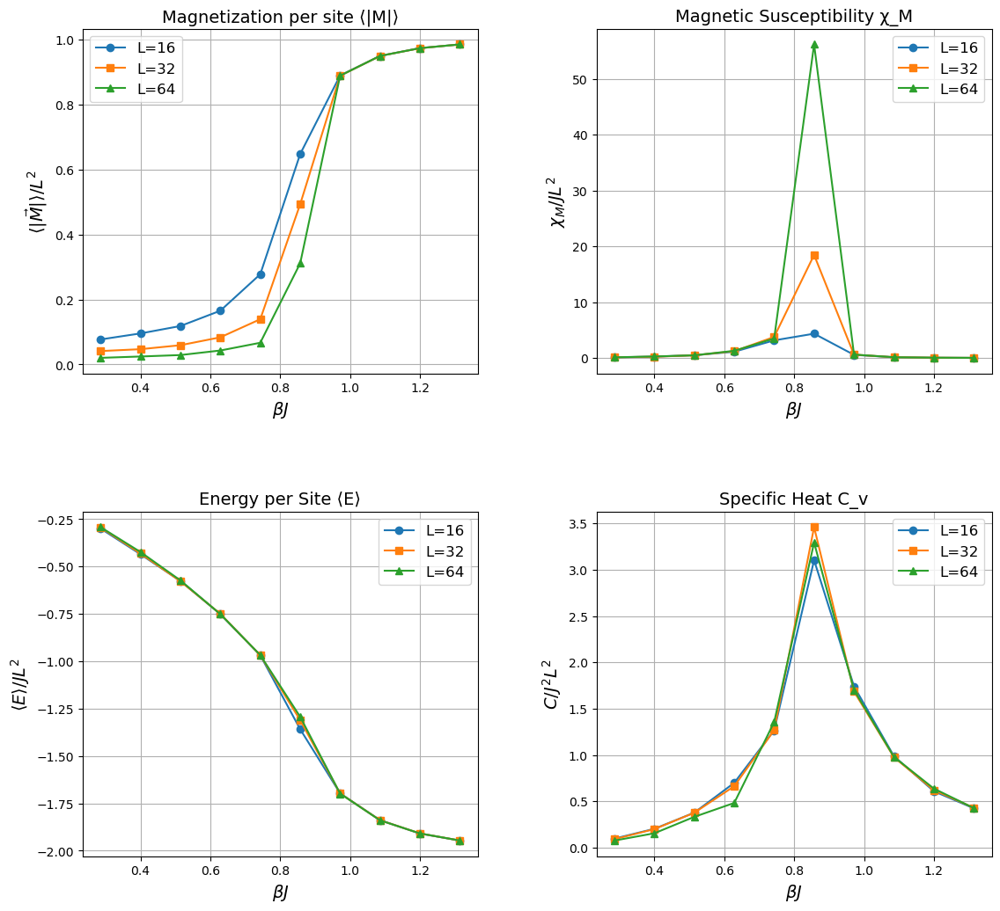

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi_M", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$βJ$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClock4BinderResolved-state-16-64.png")
plt.show()

Slope (γ/ν) = 1.8439
Intercept = -3.5852
R² = 0.9944


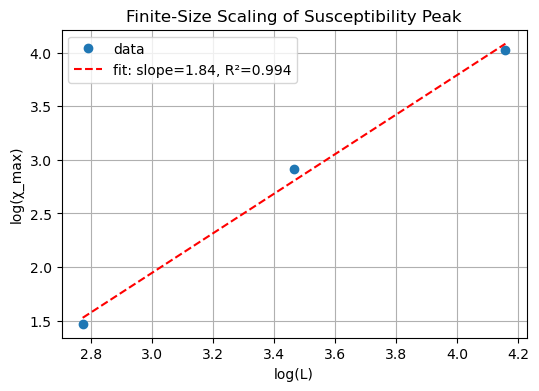

In [29]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi_M"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(6,4))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.2f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)")
plt.ylabel("log(χ_max)")
plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend()
plt.grid(True)
plt.savefig("FSSq4ClockBinderResolved-16-64.png")
plt.show()


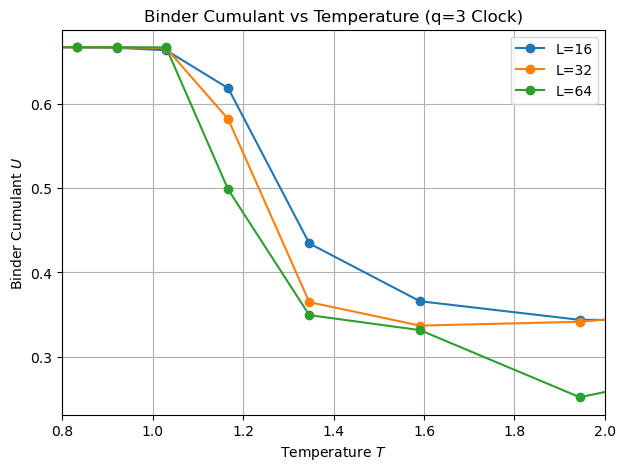

In [47]:
plt.figure(figsize=(7,5))

for L in L_values:
    plt.plot(T_values, results[L]["Binder"], 'o-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=3 Clock)")
plt.xlim(0.8,2)
plt.savefig("BinderCumulant.png")
plt.legend()
plt.grid(True)
plt.show()

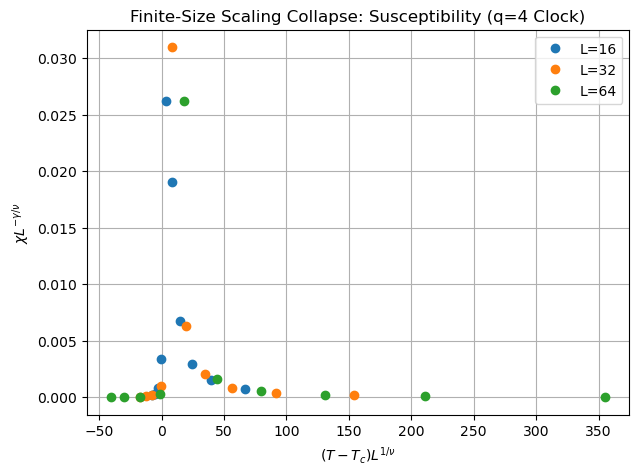

In [45]:
Tc = 1.04     # example from Binder crossing
nu = 0.83       # your estimate
gamma_over_nu = slope  # from your log fit
plt.figure(figsize=(7,5))

for L in L_values:
    T_arr = T_values
    chi_arr = results[L]["chi_M"]

    x = ((T_arr - Tc)/Tc) * L**(1/nu)
    y = chi_arr / (L**gamma_over_nu)

    plt.plot(x, y, 'o', label=f"L={L}")

plt.xlabel(r"$(T - T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi L^{-\gamma/\nu}$")
plt.title("Finite-Size Scaling Collapse: Susceptibility (q=4 Clock)")
plt.legend()
plt.savefig("FSSCollapseq4ClockBinderResolved.png")
plt.grid(True)
plt.show()

### Four Response Functions of q=5 state clock model


In [3]:
import numpy as np

data = np.load("clock_q5_correlation_length_fss.npz")

print("Lattice sizes:", data["L_values"])
print("Temperatures:", data["temperatures"])
print("Correlation-length shape:", data["xi_second_moment"].shape)
print("xi/L shape:", data["xi_over_L"].shape)

Lattice sizes: [16 24 32 48 64]
Temperatures: [0.7        0.76666667 0.83333333 0.9        0.96666667 1.03333333
 1.1        1.16666667 1.23333333 1.3       ]
Correlation-length shape: (5, 10)
xi/L shape: (5, 10)


In [12]:
filename = "clock_q5_L64_correlation_length.npz"

data = np.load(filename, allow_pickle=True)

print("Variables stored in NPZ:")
print(data.files)


Variables stored in NPZ:
['q', 'J', 'L', 'temperatures', 'thermalization', 'measurements', 'skip_steps', 'initial_state', 'S0_mean', 'Skmin_mean', 'xi_second_moment', 'xi_over_L']


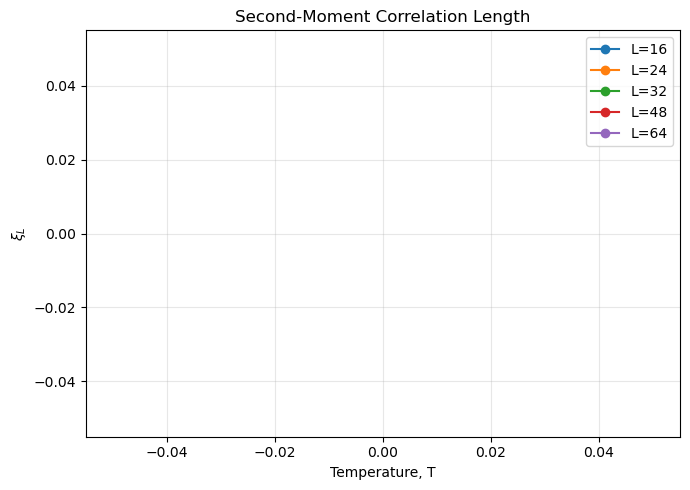

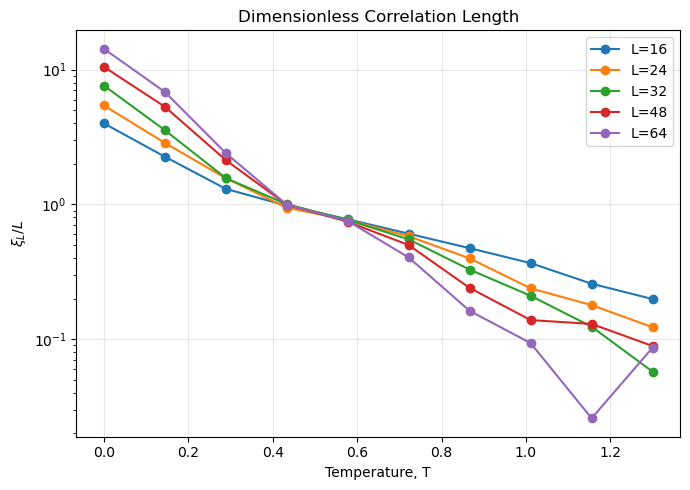

In [16]:
plt.figure(figsize=(7, 5))
for i, L in enumerate(L_values):
    plt.plot(temperatures, xi[i], "o-", label=f"L={L}")
plt.xlabel("Temperature, T")
plt.ylabel(r"$\xi_L$")
plt.title("Second-Moment Correlation Length")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
#plt.savefig("clock_q5_xi_vs_temperature.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
for i, L in enumerate(L_values):
    plt.plot(temperatures, xi_over_L[i], "o-", label=f"L={L}")
plt.xlabel("Temperature, T")
plt.ylabel(r"$\xi_L/L$")
plt.title("Dimensionless Correlation Length")
plt.grid(alpha=0.3)
plt.yscale('log')
plt.legend()
plt.tight_layout()
#plt.savefig("clock_q5_xi_over_L_vs_temperature.png", dpi=300)
plt.show()


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# q=5 clock model: second-moment correlation length
q, J = 5, 1.0
L_values = np.array([16, 24, 32, 48, 64])
temperatures = np.linspace(0.70, 1.30, 10)

thermalization = 15000
measurements = 500
skip_steps = 10
initial_state = "random"
rng = np.random.default_rng()

angles = 2 * np.pi * np.arange(q) / q
cos_diff = np.cos(angles[:, None] - angles[None, :])


def new_state(L):
    if initial_state == "ordered":
        return np.zeros((L, L), dtype=np.int8)
    return rng.integers(0, q, size=(L, L), dtype=np.int8)


def total_energy(spins, L):
    return -J * np.sum(
        cos_diff[spins, np.roll(spins, -1, axis=0)]
        + cos_diff[spins, np.roll(spins, -1, axis=1)]
    )


def wolff_cluster(spins, beta, energy, visited, L):
    visited.fill(False)
    r = rng.integers(q)
    x0, y0 = rng.integers(L, size=2)
    stack = [(x0, y0)]
    visited[x0, y0] = True
    cluster = []

    while stack:
        x, y = stack.pop()
        cluster.append((x, y))
        si = spins[x, y]
        si_ref = (2 * r - si) % q
        for nx, ny in (
            ((x + 1) % L, y), ((x - 1) % L, y),
            (x, (y + 1) % L), (x, (y - 1) % L)
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                delta = cos_diff[si, sj] - cos_diff[si_ref, sj]
                if delta > 0 and rng.random() < 1 - np.exp(-beta * J * delta):
                    visited[nx, ny] = True
                    stack.append((nx, ny))

    dE = 0.0
    for x, y in cluster:
        si = spins[x, y]
        si_ref = (2 * r - si) % q
        for nx, ny in (
            ((x + 1) % L, y), ((x - 1) % L, y),
            (x, (y + 1) % L), (x, (y - 1) % L)
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (cos_diff[si, sj] - cos_diff[si_ref, sj])

    for x, y in cluster:
        spins[x, y] = (2 * r - spins[x, y]) % q
    return energy + dE


def structure_factors(spins, L):
    z = np.exp(2j * np.pi * spins / q)
    zk = np.fft.fft2(z)
    s0 = np.abs(zk[0, 0])**2 / L**2
    sk = (np.abs(zk[1, 0])**2 + np.abs(zk[0, 1])**2) / (2 * L**2)
    return s0, sk


def second_moment_xi(s0, sk, L):
    if not np.isfinite(s0) or not np.isfinite(sk) or sk <= 0:
        return np.nan
    ratio = s0 / sk
    if ratio < 1:
        return np.nan
    return np.sqrt(ratio - 1) / (2 * np.sin(np.pi / L))


shape = (len(L_values), len(temperatures))
S0_mean = np.full(shape, np.nan)
Skmin_mean = np.full(shape, np.nan)
xi = np.full(shape, np.nan)

for iL, L in enumerate(L_values):
    for iT, T in enumerate(temperatures):
        print(f"\nL={L}, T={T:.4f}")
        beta = 1.0 / T
        spins = new_state(L)
        visited = np.zeros((L, L), dtype=bool)
        energy = total_energy(spins, L)

        for _ in range(thermalization):
            energy = wolff_cluster(spins, beta, energy, visited, L)

        s0_samples = np.empty(measurements)
        sk_samples = np.empty(measurements)
        for m in range(measurements):
            for _ in range(skip_steps):
                energy = wolff_cluster(spins, beta, energy, visited, L)
            s0_samples[m], sk_samples[m] = structure_factors(spins, L)

        S0_mean[iL, iT] = np.mean(s0_samples)
        Skmin_mean[iL, iT] = np.mean(sk_samples)
        xi[iL, iT] = second_moment_xi(S0_mean[iL, iT], Skmin_mean[iL, iT], L)
        print(
            f"S0={S0_mean[iL, iT]:.5g}, "
            f"Skmin={Skmin_mean[iL, iT]:.5g}, "
            f"xi={xi[iL, iT]:.5g}, xi/L={xi[iL, iT]/L:.5g}"
        )

xi_over_L = xi / L_values[:, None]
output = "clock_q5_correlation_length_fss.npz"
np.savez_compressed(
    output, q=q, J=J, L_values=L_values, temperatures=temperatures,
    thermalization=thermalization, measurements=measurements,
    skip_steps=skip_steps, initial_state=initial_state,
    S0_mean=S0_mean, Skmin_mean=Skmin_mean,
    xi_second_moment=xi, xi_over_L=xi_over_L
)
print(f"\nSaved results to {output}")

plt.figure(figsize=(7, 5))
for i, L in enumerate(L_values):
    plt.plot(temperatures, xi[i], "o-", label=f"L={L}")
plt.xlabel("Temperature, T")
plt.ylabel(r"$\xi_L$")
plt.title("Second-Moment Correlation Length")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("clock_q5_xi_vs_temperature.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
for i, L in enumerate(L_values):
    plt.plot(temperatures, xi_over_L[i], "o-", label=f"L={L}")
plt.xlabel("Temperature, T")
plt.ylabel(r"$\xi_L/L$")
plt.title("Dimensionless Correlation Length")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
#plt.savefig("clock_q5_xi_over_L_vs_temperature.png", dpi=300)
plt.show()



L=16, T=0.0000


C:\Users\Darwin\AppData\Local\Temp\ipykernel_15204\440272529.py:98: RuntimeWarning: divide by zero encountered in scalar divide
  beta = 1.0 / T


S0=256, Skmin=0, xi=nan, xi/L=nan

L=16, T=0.1444
S0=256, Skmin=0, xi=nan, xi/L=nan

L=16, T=0.2889


KeyboardInterrupt: 

In [36]:
import numpy as np

# ============================================================
# 2D q-state clock model: Wolff updates + second-moment xi
# ============================================================
q, J, L = 5, 1.0, 64
temperatures = np.array([0.82, 0.93, 1.15])

thermalization = 15000
measurements = 500
skip_steps = 10
initial_state = "random"
rng = np.random.default_rng()

angles = 2 * np.pi * np.arange(q) / q
cos_state, sin_state = np.cos(angles), np.sin(angles)
cos_diff = np.cos(angles[:, None] - angles[None, :])


def new_state():
    if initial_state == "ordered":
        return np.zeros((L, L), dtype=np.int8)
    return rng.integers(0, q, size=(L, L), dtype=np.int8)


def total_energy(spins):
    # Each periodic nearest-neighbor bond is counted once.
    return -J * np.sum(
        cos_diff[spins, np.roll(spins, -1, axis=0)]
        + cos_diff[spins, np.roll(spins, -1, axis=1)]
    )


def wolff_cluster(spins, beta, energy, visited):
    visited.fill(False)
    r = rng.integers(q)
    x0, y0 = rng.integers(L, size=2)
    stack = [(x0, y0)]
    visited[x0, y0] = True
    cluster = []

    while stack:
        x, y = stack.pop()
        cluster.append((x, y))
        si = spins[x, y]
        si_ref = (2 * r - si) % q

        for nx, ny in (
            ((x + 1) % L, y), ((x - 1) % L, y),
            (x, (y + 1) % L), (x, (y - 1) % L)
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                delta = cos_diff[si, sj] - cos_diff[si_ref, sj]
                if delta > 0 and rng.random() < 1 - np.exp(-beta * J * delta):
                    visited[nx, ny] = True
                    stack.append((nx, ny))

    # Energy change from boundary bonds only.
    dE = 0.0
    for x, y in cluster:
        si = spins[x, y]
        si_ref = (2 * r - si) % q
        for nx, ny in (
            ((x + 1) % L, y), ((x - 1) % L, y),
            (x, (y + 1) % L), (x, (y - 1) % L)
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (cos_diff[si, sj] - cos_diff[si_ref, sj])

    for x, y in cluster:
        spins[x, y] = (2 * r - spins[x, y]) % q

    return energy + dE


def structure_factors(spins):
    # Complex clock-spin field and its Fourier transform.
    z = np.exp(2j * np.pi * spins / q)
    zk = np.fft.fft2(z)
    s0 = np.abs(zk[0, 0])**2 / L**2

    # Average the two equivalent minimum wavevectors:
    # (2*pi/L, 0) and (0, 2*pi/L).
    skmin = (
        np.abs(zk[1, 0])**2 + np.abs(zk[0, 1])**2
    ) / (2 * L**2)
    return s0, skmin


def correlation_length(s0, skmin):
    if not np.isfinite(s0) or not np.isfinite(skmin) or skmin <= 0:
        return np.nan
    ratio = s0 / skmin
    if ratio < 1:
        return np.nan
    return np.sqrt(ratio - 1) / (2 * np.sin(np.pi / L))


S0_mean = np.zeros(len(temperatures))
Skmin_mean = np.zeros(len(temperatures))
xi = np.full(len(temperatures), np.nan)

for i, T in enumerate(temperatures):
    print(f"\nRunning T = {T:.4f}")
    beta = 1.0 / T
    spins = new_state()
    visited = np.zeros((L, L), dtype=bool)
    energy = total_energy(spins)

    for _ in range(thermalization):
        energy = wolff_cluster(spins, beta, energy, visited)

    s0_samples = np.empty(measurements)
    sk_samples = np.empty(measurements)

    for m in range(measurements):
        for _ in range(skip_steps):
            energy = wolff_cluster(spins, beta, energy, visited)

        s0_samples[m], sk_samples[m] = structure_factors(spins)

        if (m + 1) % 100 == 0:
            print(f"  measurement {m + 1}/{measurements}")

    # Average structure factors first, then calculate xi.
    S0_mean[i] = np.mean(s0_samples)
    Skmin_mean[i] = np.mean(sk_samples)
    xi[i] = correlation_length(S0_mean[i], Skmin_mean[i])

    print(
        f"  S(0)={S0_mean[i]:.6g}, "
        f"S(kmin)={Skmin_mean[i]:.6g}, "
        f"xi={xi[i]:.6g}, xi/L={xi[i] / L:.6g}"
    )

output = f"clock_q{q}_L{L}_correlation_length.npz"
np.savez_compressed(
    output,
    q=q, J=J, L=L,
    temperatures=temperatures,
    thermalization=thermalization,
    measurements=measurements,
    skip_steps=skip_steps,
    initial_state=initial_state,
    S0_mean=S0_mean,
    Skmin_mean=Skmin_mean,
    xi_second_moment=xi,
    xi_over_L=xi / L,
)

print(f"\nSaved correlation-length data to {output}")



Running T = 0.8200
  measurement 100/500
  measurement 200/500
  measurement 300/500
  measurement 400/500
  measurement 500/500
  S(0)=2870.29, S(kmin)=8.12491, xi=191.255, xi/L=2.98836

Running T = 0.9300
  measurement 100/500
  measurement 200/500
  measurement 300/500
  measurement 400/500
  measurement 500/500
  S(0)=1684.32, S(kmin)=60.3008, xi=52.8821, xi/L=0.826283

Running T = 1.1500
  measurement 100/500
  measurement 200/500
  measurement 300/500
  measurement 400/500
  measurement 500/500
  S(0)=86.3478, S(kmin)=58.6321, xi=7.00599, xi/L=0.109469

Saved correlation-length data to clock_q5_L64_correlation_length.npz


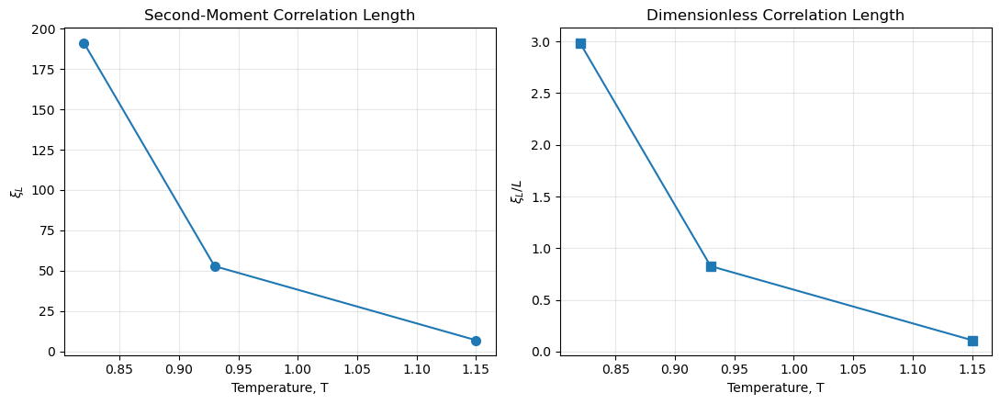

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("clock_q5_L64_correlation_length.npz")

T = data["temperatures"]
xi = data["xi_second_moment"]
xi_L = data["xi_over_L"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(T, xi, "o-", markersize=7)
axes[0].set_xlabel("Temperature, T")
axes[0].set_ylabel(r"$\xi_L$")
axes[0].set_title("Second-Moment Correlation Length")
axes[0].grid(alpha=0.3)

axes[1].plot(T, xi_L, "s-", markersize=7)
axes[1].set_xlabel("Temperature, T")
axes[1].set_ylabel(r"$\xi_L/L$")
axes[1].set_title("Dimensionless Correlation Length")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

T = 0.8200, xi/L = 2.961982, xi = 189.566864
T = 0.9300, xi/L = 2.260286, xi = 144.658333
T = 1.1500, xi/L = nan, xi = nan


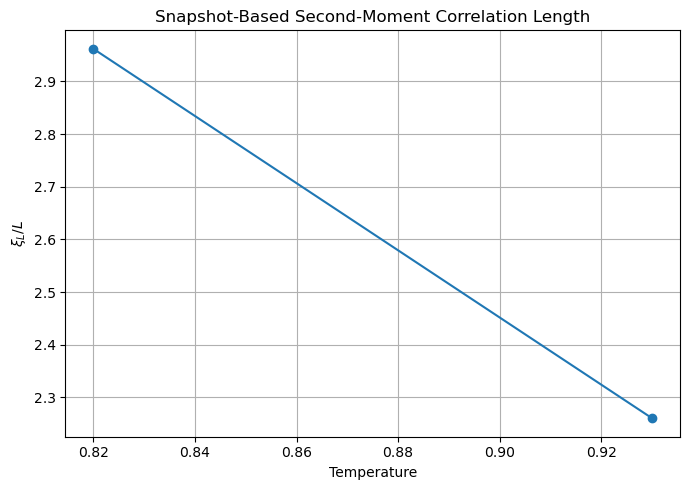

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Load your saved vortex-analysis data
data = np.load("clock_q5_L64_vorticity_results.npz")

q = int(data["q"])
L = int(data["L"])
temperatures = data["temperatures"]
spins = data["spins"]

def second_moment_xi_snapshot(spin_config, q):
    """
    Snapshot-based second-moment correlation length estimate
    for a 2D q-state clock configuration.
    """
    L = spin_config.shape[0]

    # Convert clock states into complex unit vectors
    z = np.exp(2j * np.pi * spin_config / q)

    # Fourier transform; normalization cancels in the ratio
    z_k = np.fft.fft2(z)

    # Structure factor at zero momentum
    S0 = np.abs(z_k[0, 0])**2

    # Smallest nonzero momentum along x
    Sk = np.abs(z_k[1, 0])**2

    # Avoid division by zero and nonphysical ratios
    if Sk <= 0:
        return np.nan

    ratio = S0 / Sk

    if ratio < 1:
        return np.nan

    xi = (
        1 / (2 * np.sin(np.pi / L))
        * np.sqrt(ratio - 1)
    )

    return xi


xi_values = []

for i, T in enumerate(temperatures):
    xi = second_moment_xi_snapshot(spins[i], q)
    xi_values.append(xi)

    print(f"T = {T:.4f}, xi/L = {xi/L:.6f}, xi = {xi:.6f}")

# Plot the snapshot estimates
plt.figure(figsize=(7, 5))
plt.plot(temperatures, np.array(xi_values) / L, "o-")
plt.xlabel("Temperature")
plt.ylabel(r"$\xi_L/L$")
plt.title("Snapshot-Based Second-Moment Correlation Length")
plt.grid(True)
plt.tight_layout()
plt.show()

T=0.820: vorticity min=-1.000, max=1.000, nonzero=6


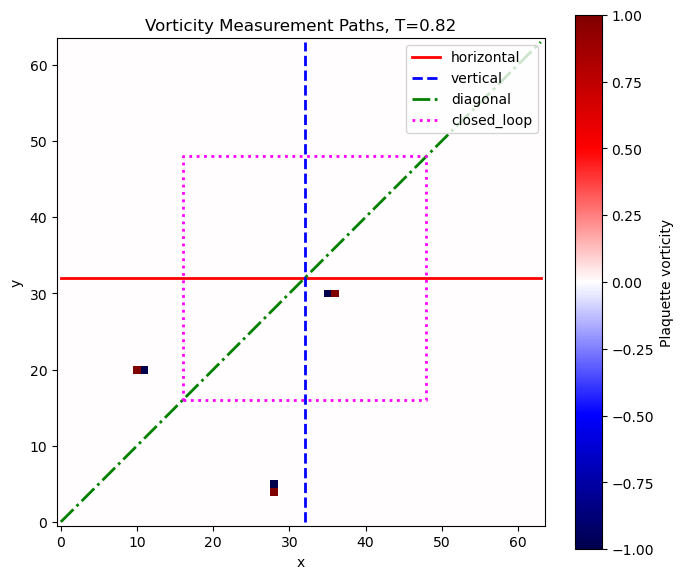

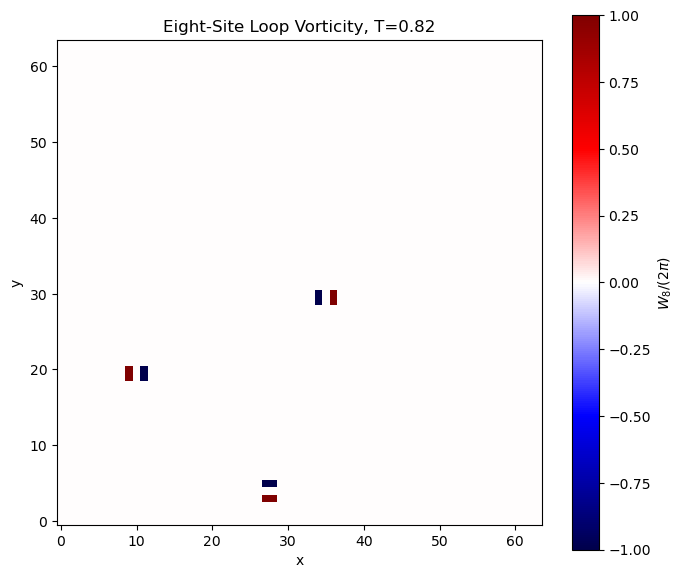

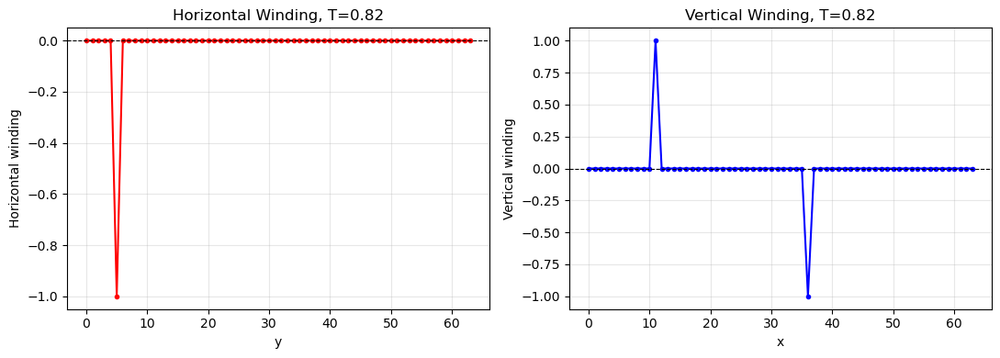

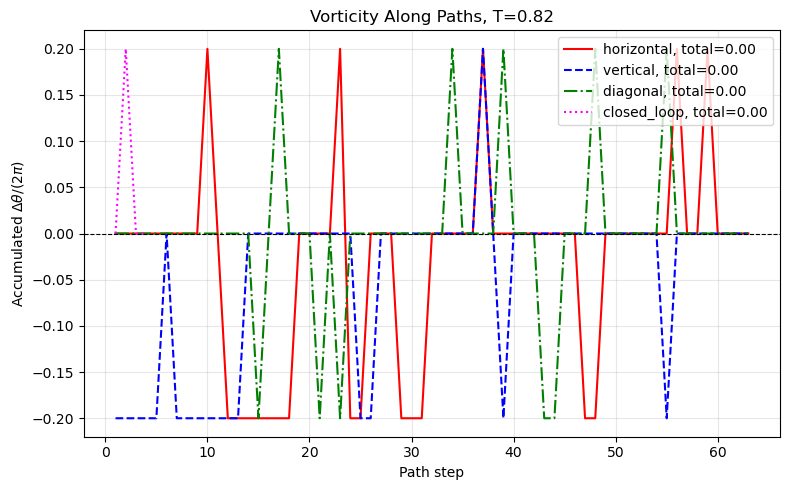

T=0.930: vorticity min=-1.000, max=1.000, nonzero=26


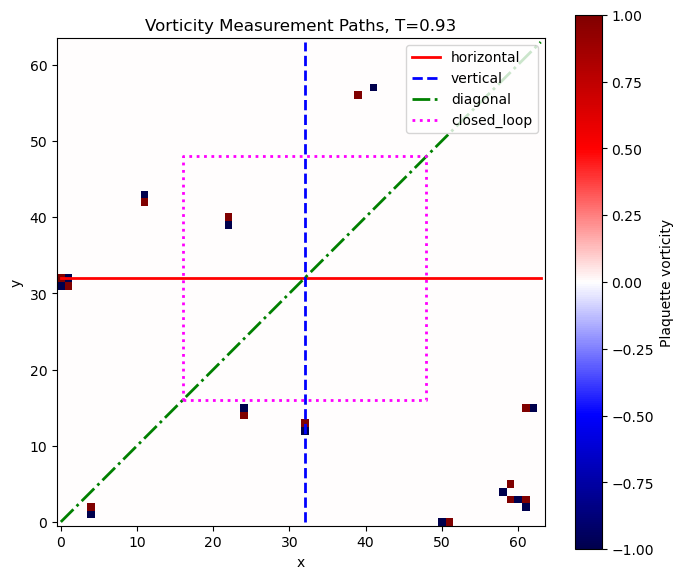

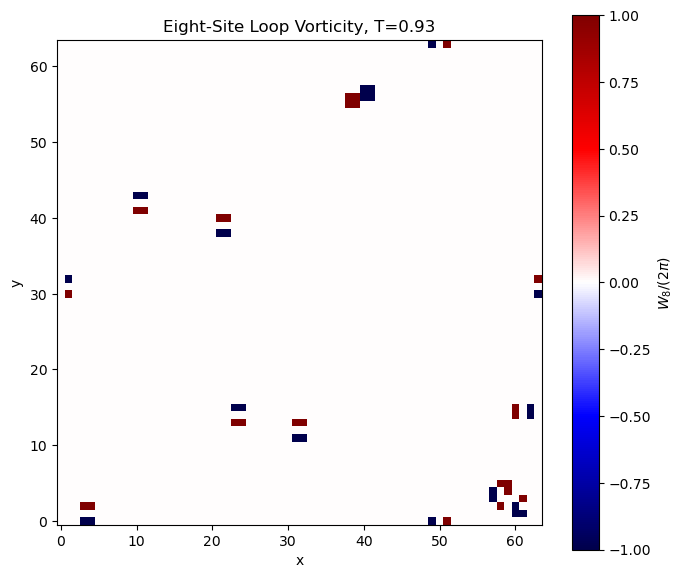

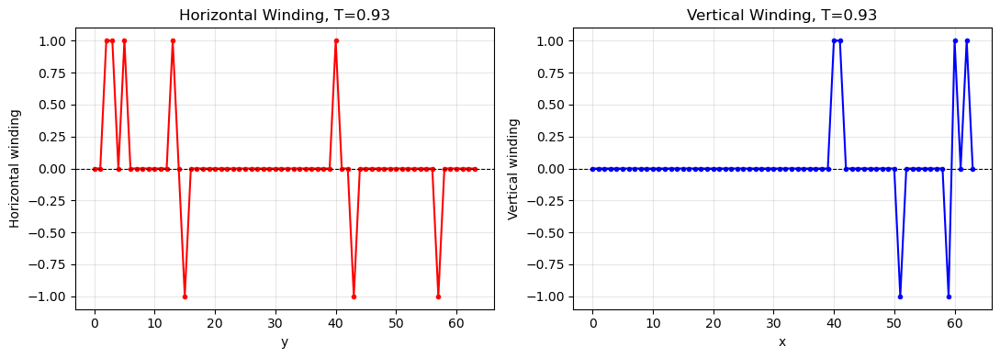

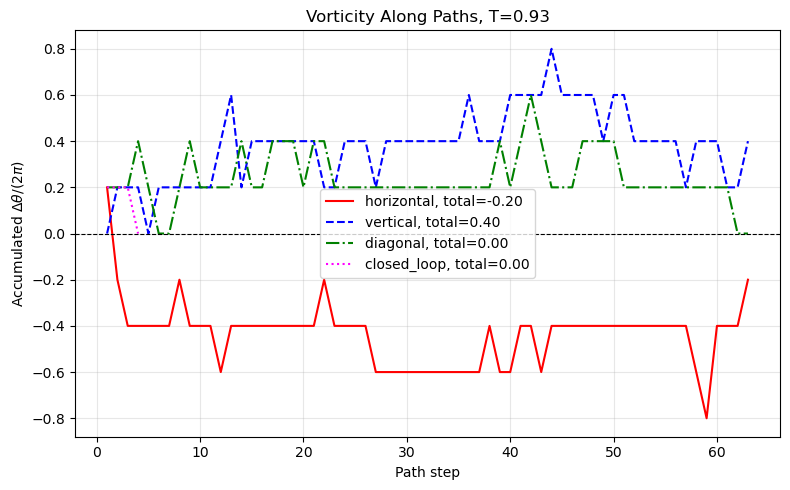

T=1.150: vorticity min=-1.000, max=1.000, nonzero=226


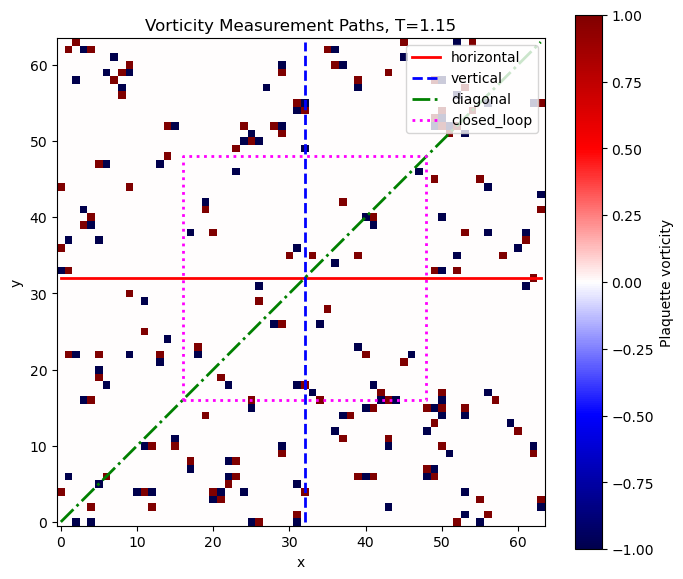

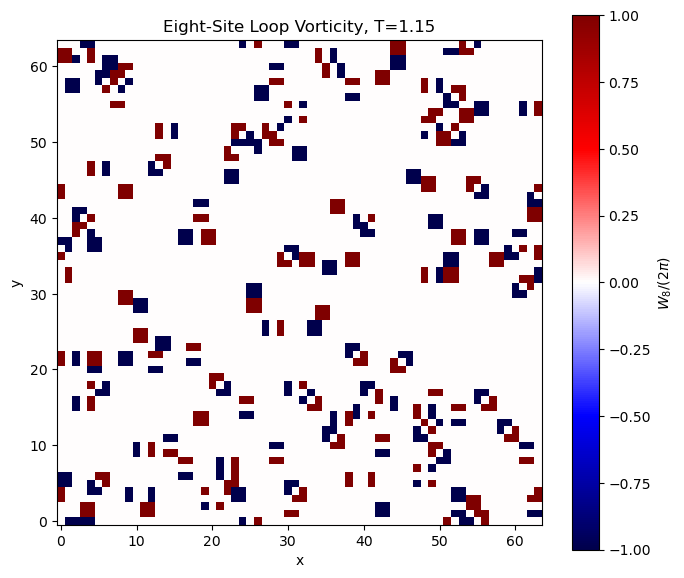

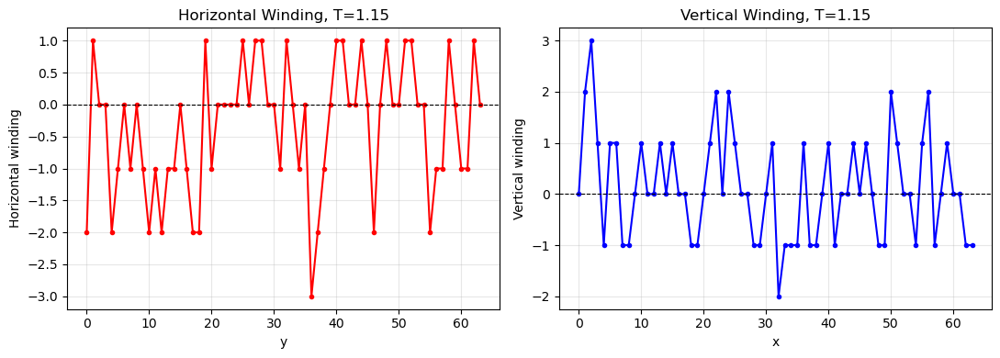

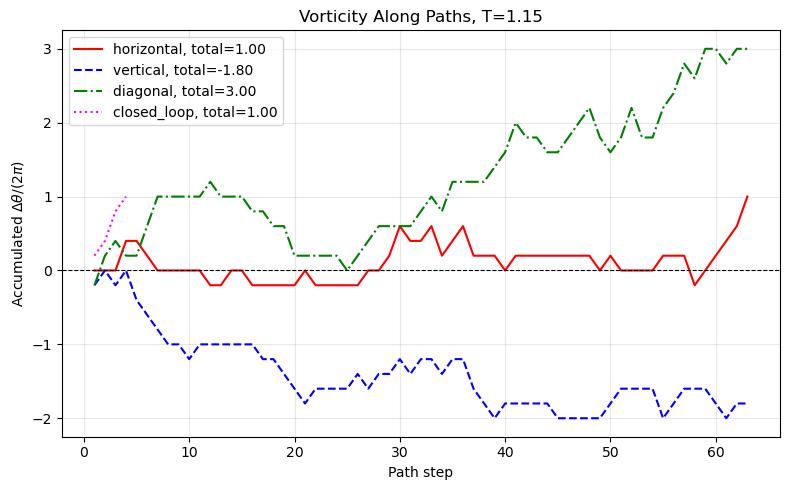

All plots saved to: C:\Users\Darwin\clock_q5_path_plots


In [37]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# LOAD SAVED SIMULATION
# ============================================================
filename = "clock_q5_L64_vorticity_results.npz"
data = np.load(filename)

q = int(data["q"])
L = int(data["L"])
temperatures = data["temperatures"]

spins_all = data["spins"]
vorticity_all = data["plaquette_vorticity"]
W8_all = data["W8"]
horizontal_all = data["horizontal_winding"]
vertical_all = data["vertical_winding"]

output_dir = Path("clock_q5_path_plots")
output_dir.mkdir(exist_ok=True)

ANGLES = 2 * np.pi * np.arange(q) / q


# ============================================================
# SAME WRAPPED ANGLE DIFFERENCE AS THE SIMULATION
# ============================================================
def wrapped_angle_difference(theta1, theta2):
    return (theta2 - theta1 + np.pi) % (2 * np.pi) - np.pi


# ============================================================
# SAME FOUR PATH DEFINITIONS AS THE SIMULATION
# ============================================================
def create_paths(L):
    paths = {}

    y0 = L // 2
    paths["horizontal"] = [(x, y0) for x in range(L)]

    x0 = L // 2
    paths["vertical"] = [(x0, y) for y in range(L)]

    paths["diagonal"] = [(x, x) for x in range(L)]

    margin = L // 4
    x1, x2 = margin, L - margin
    y1, y2 = margin, L - margin

    paths["closed_loop"] = [
        (x1, y1),
        (x2, y1),
        (x2, y2),
        (x1, y2)
    ]

    return paths


# ============================================================
# SAME ACCUMULATED PATH-VORTICITY CALCULATION
# ============================================================
def path_vorticity(spins, path, L, closed=False):
    theta = ANGLES[spins]
    increments = []
    cumulative = []
    total = 0.0

    for i in range(len(path) - 1):
        x1, y1 = path[i]
        x2, y2 = path[i + 1]

        dtheta = wrapped_angle_difference(
            theta[x1 % L, y1 % L],
            theta[x2 % L, y2 % L]
        )

        increment = dtheta / (2 * np.pi)
        increments.append(increment)
        total += increment
        cumulative.append(total)

    if closed:
        x1, y1 = path[-1]
        x2, y2 = path[0]

        dtheta = wrapped_angle_difference(
            theta[x1 % L, y1 % L],
            theta[x2 % L, y2 % L]
        )

        increment = dtheta / (2 * np.pi)
        increments.append(increment)
        total += increment
        cumulative.append(total)

    return np.asarray(increments), np.asarray(cumulative), total


paths = create_paths(L)

styles = {
    "horizontal": {"color": "red", "linestyle": "-"},
    "vertical": {"color": "blue", "linestyle": "--"},
    "diagonal": {"color": "green", "linestyle": "-."},
    "closed_loop": {"color": "magenta", "linestyle": ":"}
}


# ============================================================
# PLOT EACH TEMPERATURE
# ============================================================
for i, T in enumerate(temperatures):

    spins = spins_all[i]
    vort = vorticity_all[i]
    W8 = W8_all[i]
    Wh = horizontal_all[i]
    Wv = vertical_all[i]

    tag = f"T{T:.3f}"

    print(
        f"T={T:.3f}: vorticity min={vort.min():.3f}, "
        f"max={vort.max():.3f}, "
        f"nonzero={np.count_nonzero(np.abs(vort) > 1e-8)}"
    )

    # --------------------------------------------------------
    # 1. LOCAL PLAQUETTE VORTICITY
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(7, 6))

    im = ax.imshow(
        vort.T,
        cmap="seismic",
        origin="lower",
        interpolation="nearest",
        vmin=-1,
        vmax=1
    )

    # Overlay all four paths in the same coordinate system
    for name, path in paths.items():
        px = [p[0] for p in path]
        py = [p[1] for p in path]

        if name == "closed_loop":
            px.append(px[0])
            py.append(py[0])

        ax.plot(
            px, py,
            linewidth=2,
            label=name,
            **styles[name]
        )

    fig.colorbar(im, ax=ax, label="Plaquette vorticity")
    ax.set(
        xlabel="x",
        ylabel="y",
        title=f"Vorticity Measurement Paths, T={T:.2f}"
    )
    ax.legend(loc="upper right")
    fig.tight_layout()
    fig.savefig(output_dir / f"vorticity_paths_{tag}.png", dpi=300)
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 2. EIGHT-SITE LOOP VORTICITY W8
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(7, 6))

    im = ax.imshow(
        W8.T,
        cmap="seismic",
        origin="lower",
        interpolation="nearest",
        vmin=-1,
        vmax=1
    )

    fig.colorbar(im, ax=ax, label=r"$W_8/(2\pi)$")
    ax.set(
        xlabel="x",
        ylabel="y",
        title=f"Eight-Site Loop Vorticity, T={T:.2f}"
    )
    fig.tight_layout()
    fig.savefig(output_dir / f"W8_{tag}.png", dpi=300)
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 3. HORIZONTAL AND VERTICAL WINDING PROFILES
    # --------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(np.arange(L), Wh, "o-", color="red", markersize=3)
    axes[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
    axes[0].set(
        xlabel="y",
        ylabel="Horizontal winding",
        title=f"Horizontal Winding, T={T:.2f}"
    )
    axes[0].grid(alpha=0.3)

    axes[1].plot(np.arange(L), Wv, "o-", color="blue", markersize=3)
    axes[1].axhline(0, color="black", linestyle="--", linewidth=0.8)
    axes[1].set(
        xlabel="x",
        ylabel="Vertical winding",
        title=f"Vertical Winding, T={T:.2f}"
    )
    axes[1].grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(output_dir / f"winding_profiles_{tag}.png", dpi=300)
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 4. ACCUMULATED VORTICITY ALONG ALL FOUR PATHS
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8, 5))

    for name, path in paths.items():
        closed = (name == "closed_loop")

        increments, cumulative, total = path_vorticity(
            spins, path, L, closed=closed
        )

        ax.plot(
            np.arange(1, len(cumulative) + 1),
            cumulative,
            linewidth=1.5,
            label=f"{name}, total={total:.2f}",
            **styles[name]
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(
        xlabel="Path step",
        ylabel=r"Accumulated $\Delta\theta/(2\pi)$",
        title=f"Vorticity Along Paths, T={T:.2f}"
    )
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(
        output_dir / f"accumulated_vorticity_{tag}.png",
        dpi=300
    )
    plt.show()
    plt.close(fig)

print(f"All plots saved to: {output_dir.resolve()}")


In [23]:
data = np.load("clock_q5_all_temperatures.npz", allow_pickle=True)

print("Variables stored in NPZ:")
print(data.files)
plt.figure(figsize=(6,5))



Variables stored in NPZ:
['temperatures', 'G', 'S', 'vortex', 'spins', 'magnetization', 'energy']


<Figure size 600x500 with 0 Axes>

<Figure size 600x500 with 0 Axes>

Variables stored in NPZ:
['temperatures', 'G', 'S', 'vortex', 'spins', 'magnetization', 'energy']
temperatures

Array shapes:
Temperatures: (3,)
G: (3, 64, 64)
S: (3, 64, 64)
Vortex: (3, 63, 63)
Spins: (3, 64, 64)
Magnetization: (3,)
Energy: (3,)

Plotting T = 0.8200


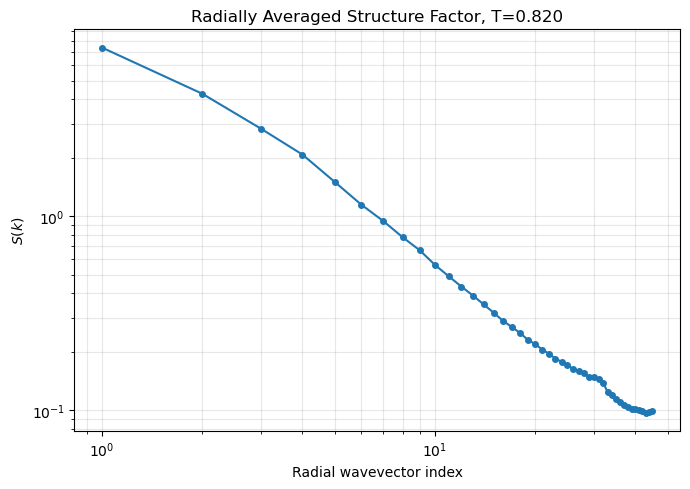

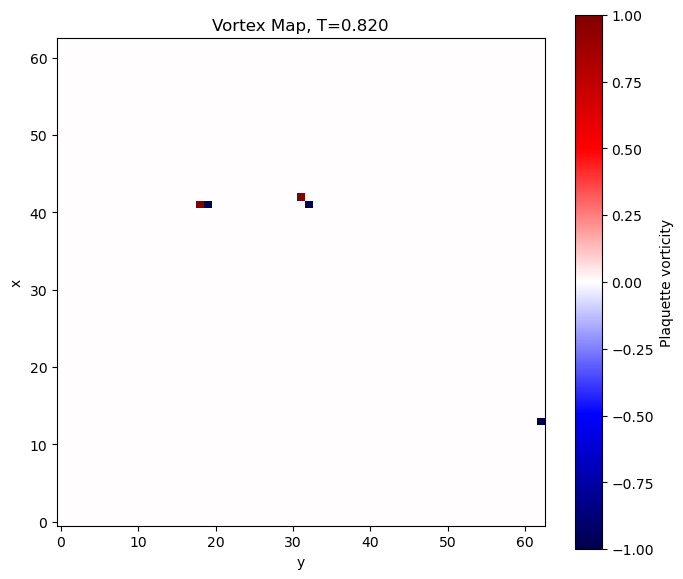

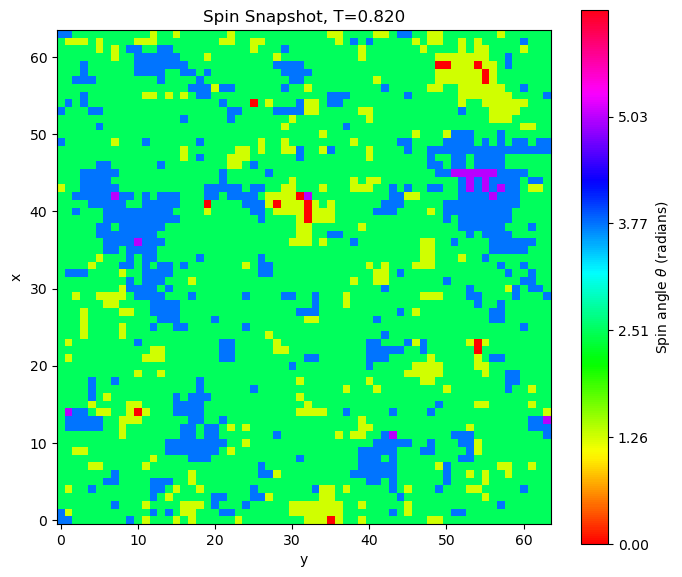


Plotting T = 0.9300


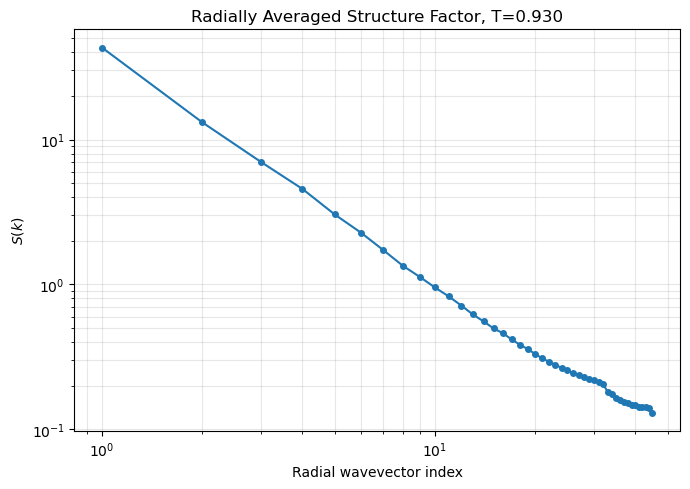

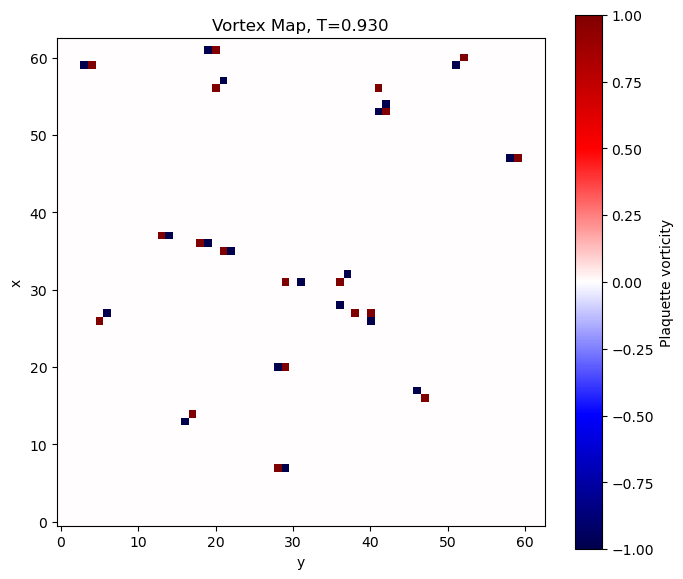

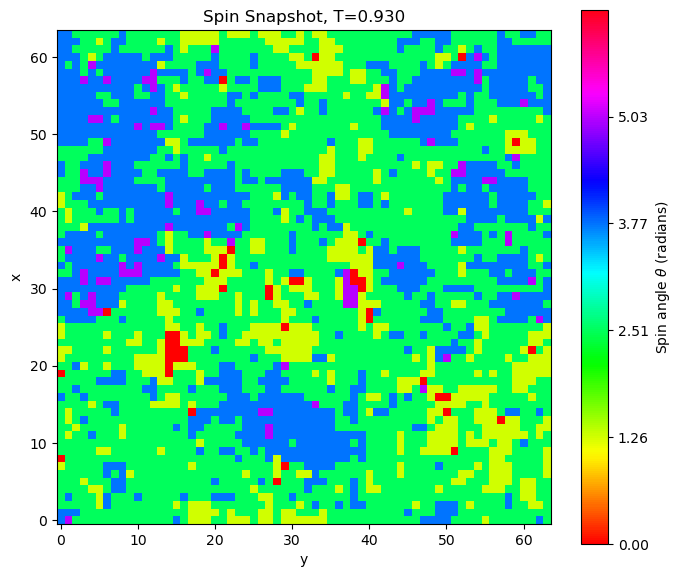


Plotting T = 1.1500


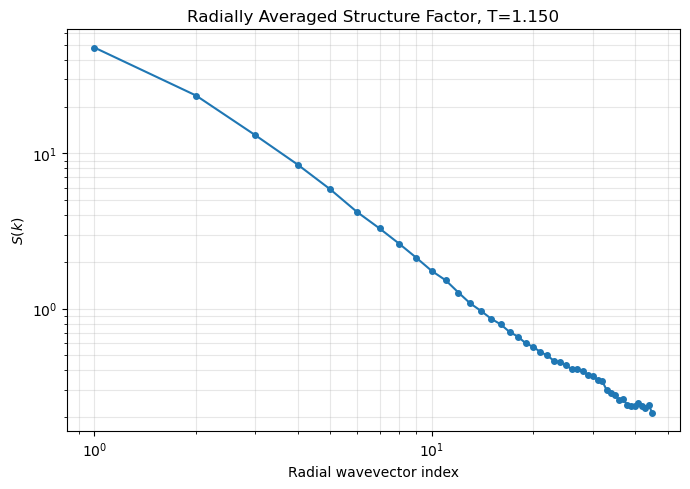

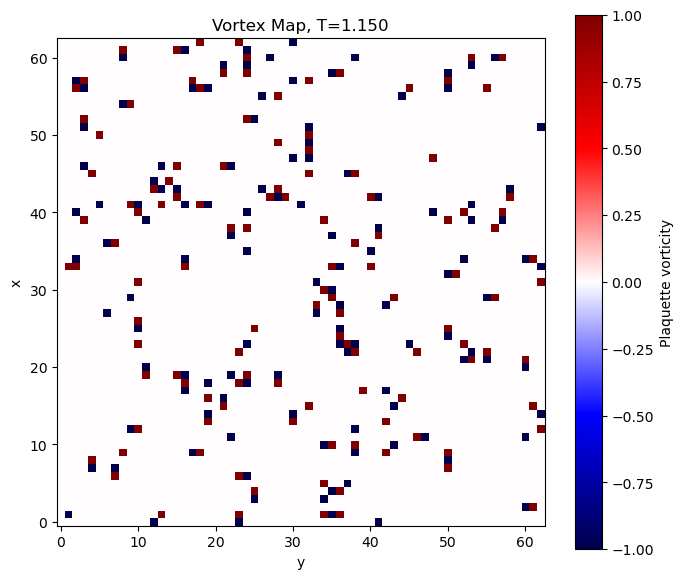

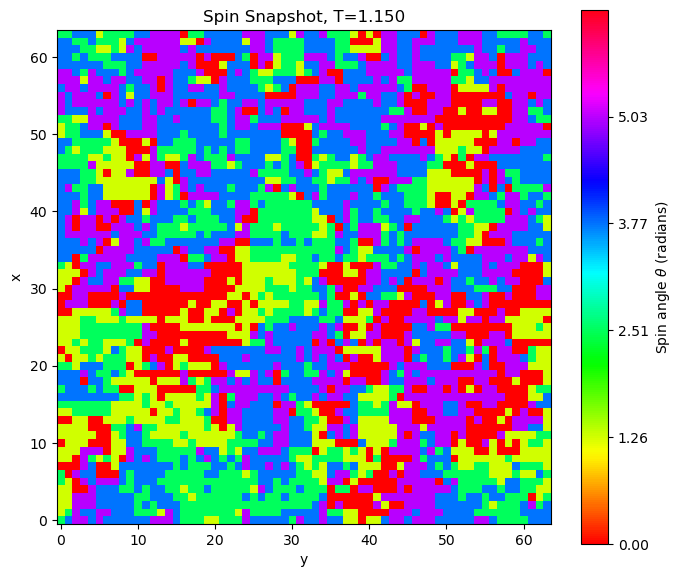


All plots generated successfully.


In [29]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD SAVED SIMULATION DATA
# ============================================================

filename = "clock_q5_all_temperatures.npz"

data = np.load(filename)

print("Variables stored in NPZ:")
print(data.files)

temperatures = data["temperatures"]
print("temperatures")
G = data["G"]
S = data["S"]
vortex = data["vortex"]
spins = data["spins"]

magnetization = data["magnetization"]
energy = data["energy"]

# ============================================================
# CHECK ARRAY DIMENSIONS
# ============================================================

print("\nArray shapes:")
print("Temperatures:", temperatures.shape)
print("G:", G.shape)
print("S:", S.shape)
print("Vortex:", vortex.shape)
print("Spins:", spins.shape)
print("Magnetization:", magnetization.shape)
print("Energy:", energy.shape)

nT = len(temperatures)

# ============================================================
# RADIAL AVERAGE OF STRUCTURE FACTOR
# ============================================================

def radial_average(Sk):

    ny, nx = Sk.shape

    center_y = ny // 2
    center_x = nx // 2

    y, x = np.indices(Sk.shape)

    radius = np.sqrt(
        (x - center_x)**2 +
        (y - center_y)**2
    ).astype(int)

    total = np.bincount(
        radius.ravel(),
        weights=Sk.ravel()
    )

    count = np.bincount(radius.ravel())

    radial = np.divide(
        total,
        count,
        out=np.zeros_like(total, dtype=float),
        where=count > 0
    )

    return np.arange(len(radial)), radial


# ============================================================
# LOOP OVER ALL TEMPERATURES
# ============================================================

for i, T in enumerate(temperatures):

    print(f"\nPlotting T = {T:.4f}")

    # --------------------------------------------------------
    # EXTRACT DATA FOR THIS TEMPERATURE
    # --------------------------------------------------------

    G_T = G[i]
    S_T = S[i]
    vortex_T = vortex[i]
    spins_T = spins[i]

    # ========================================================
    # 1. LOG-LOG STRUCTURE FACTOR
    # ========================================================

    # If S is already the Fourier-space structure factor,
    # use it directly.
    r, Sr = radial_average(S_T)

    mask = (
        (r > 0) &
        (Sr > 0) &
        np.isfinite(Sr)
    )

    plt.figure(figsize=(7, 5))

    plt.loglog(
        r[mask],
        Sr[mask],
        "o-",
        markersize=4
    )

    plt.xlabel("Radial wavevector index")
    plt.xscale("log")
    plt.yscale("log")
    plt.ylabel(r"$S(k)$")
    plt.title(f"Radially Averaged Structure Factor, T={T:.3f}")
    plt.savefig(f"RadAveSF_T{T:.3f}.pdf", dpi=300, bbox_inches="tight")
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ========================================================
    # 2. VORTEX MAP
    # ========================================================

    plt.figure(figsize=(7, 6))

    plt.imshow(
        vortex_T,
        cmap="seismic",
        origin="lower",
        interpolation="nearest",
        vmin=-1,
        vmax=1
    )

    plt.colorbar(label="Plaquette vorticity")
    plt.xlabel("y")
    plt.ylabel("x")
    plt.title(f"Vortex Map, T={T:.3f}")
    plt.savefig(f"VortexMap_T{T:.3f}.pdf", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()

    # ========================================================
    # 3. SPIN SNAPSHOT
    # ========================================================

    q = int(data["q"]) if "q" in data.files else 5

    angles = 2 * np.pi * np.arange(q) / q
    theta_T = angles[spins_T]

    plt.figure(figsize=(7, 6))

    plt.imshow(
        theta_T,
        cmap="hsv",
        origin="lower",
        interpolation="nearest",
        vmin=0,
        vmax=2*np.pi
    )

    cbar = plt.colorbar()
    cbar.set_label(r"Spin angle $\theta$ (radians)")
    cbar.set_ticks(
        2*np.pi*np.arange(q)/q
    )
    cbar.set_ticklabels(
        [f"{a:.2f}" for a in angles]
    )

    plt.xlabel("y")
    plt.ylabel("x")
    plt.title(f"Spin Snapshot, T={T:.3f}")
    plt.savefig(f"Snapshot_T{T:.3f}.pdf", dpi=300, bbox_inches="tight")
    plt.tight_layout()
    plt.show()

data.close()

print("\nAll plots generated successfully.")

Variables stored in NPZ:
['q', 'J', 'L', 'temperatures', 'T_low', 'T_mid', 'T_high', 'thermalization', 'measurements', 'skip_steps', 'M_low', 'M_mid', 'M_high', 'bins_low', 'bins_mid', 'bins_high', 'hist_low', 'hist_mid', 'hist_high']

Temperatures:
[0.8, 0.85, 1.0]

Magnetization samples:
Low T : (10000,)
Mid T : (10000,)
High T: (10000,)

Histogram data:
Low T bins : (50,)
Mid T bins : (50,)
High T bins: (50,)


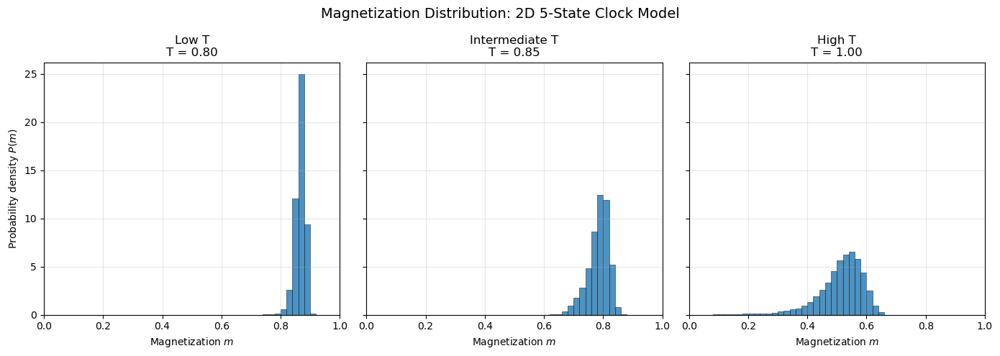

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD EXISTING NPZ DATA
# ============================================================

filename = "clock_q5_L64_magnetization_histograms.npz"

data = np.load(filename, allow_pickle=True)

print("Variables stored in NPZ:")
print(data.files)

# ============================================================
# TEMPERATURES
# ============================================================

T_low = float(data["T_low"])
T_mid = float(data["T_mid"])
T_high = float(data["T_high"])

temperatures = [T_low, T_mid, T_high]

print("\nTemperatures:")
print(temperatures)

# ============================================================
# LOAD MAGNETIZATION SAMPLES
# ============================================================

M_low = data["M_low"]
M_mid = data["M_mid"]
M_high = data["M_high"]

# ============================================================
# LOAD ALREADY-CALCULATED HISTOGRAMS
# ============================================================

bins_low = data["bins_low"]
bins_mid = data["bins_mid"]
bins_high = data["bins_high"]

hist_low = data["hist_low"]
hist_mid = data["hist_mid"]
hist_high = data["hist_high"]

# ============================================================
# PRINT DATA INFORMATION
# ============================================================

print("\nMagnetization samples:")
print("Low T :", M_low.shape)
print("Mid T :", M_mid.shape)
print("High T:", M_high.shape)

print("\nHistogram data:")
print("Low T bins :", bins_low.shape)
print("Mid T bins :", bins_mid.shape)
print("High T bins:", bins_high.shape)

# ============================================================
# PLOT USING THE SAVED HISTOGRAM DATA
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 5),
    sharey=True
)

# ------------------------------------------------------------
# LOW TEMPERATURE
# ------------------------------------------------------------

axes[0].bar(
    bins_low,
    hist_low,
    width=bins_low[1] - bins_low[0],
    alpha=0.8,
    edgecolor='black',
    linewidth=0.4
)

axes[0].set_title(
    f"Low T\nT = {T_low:.2f}"
)

axes[0].set_xlabel(r"Magnetization $m$")
axes[0].set_ylabel(r"Probability density $P(m)$")

axes[0].set_xlim(0, 1)

axes[0].grid(
    True,
    alpha=0.3
)

# ------------------------------------------------------------
# INTERMEDIATE TEMPERATURE
# ------------------------------------------------------------

axes[1].bar(
    bins_mid,
    hist_mid,
    width=bins_mid[1] - bins_mid[0],
    alpha=0.8,
    edgecolor='black',
    linewidth=0.4
)

axes[1].set_title(
    f"Intermediate T\nT = {T_mid:.2f}"
)

axes[1].set_xlabel(r"Magnetization $m$")

axes[1].set_xlim(0, 1)

axes[1].grid(
    True,
    alpha=0.3
)

# ------------------------------------------------------------
# HIGH TEMPERATURE
# ------------------------------------------------------------

axes[2].bar(
    bins_high,
    hist_high,
    width=bins_high[1] - bins_high[0],
    alpha=0.8,
    edgecolor='black',
    linewidth=0.4
)

axes[2].set_title(
    f"High T\nT = {T_high:.2f}"
)

axes[2].set_xlabel(r"Magnetization $m$")

axes[2].set_xlim(0, 1)

axes[2].grid(
    True,
    alpha=0.3
)

# ============================================================
# OVERALL TITLE
# ============================================================

fig.suptitle(
    "Magnetization Distribution: 2D 5-State Clock Model",
    fontsize=14
)

plt.tight_layout()

# ============================================================
# SAVE FIGURE
# ============================================================

plt.savefig(
    "q5_clock_magnetization_distributions.pdf",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Variables stored in NPZ:
['q', 'J', 'L', 'temperatures', 'T_low', 'T_mid', 'T_high', 'thermalization', 'measurements', 'skip_steps', 'M_low', 'M_mid', 'M_high', 'bins_low', 'bins_mid', 'bins_high', 'hist_low', 'hist_mid', 'hist_high']

Temperatures:
[0.8, 0.85, 1.0]

Sample sizes:
T = 0.8: 10000 samples
T = 0.85: 10000 samples
T = 1.0: 10000 samples


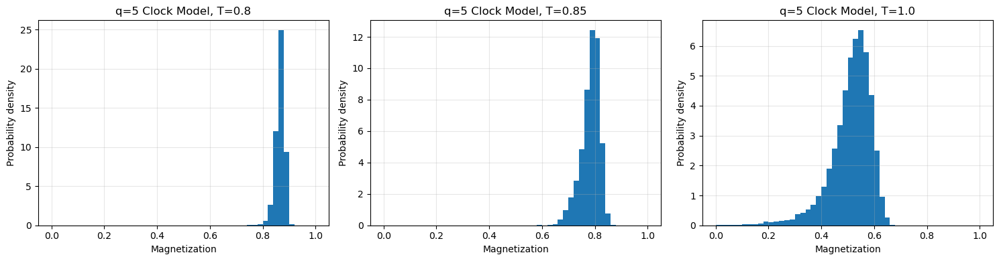

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD SAVED q=5 HISTOGRAM DATA
# ============================================================

data = np.load(
    "clock_q5_L64_magnetization_histograms.npz",
    allow_pickle=True
)

print("Variables stored in NPZ:")
print(data.files)

# ============================================================
# LOAD TEMPERATURES
# ============================================================

T_low = float(data["T_low"])
T_mid = float(data["T_mid"])
T_high = float(data["T_high"])

temperatures = [T_low, T_mid, T_high]

# ============================================================
# RECONSTRUCT all_samples
# ============================================================

all_samples = {

    T_low: data["M_low"],

    T_mid: data["M_mid"],

    T_high: data["M_high"]

}

print("\nTemperatures:")
print(temperatures)

print("\nSample sizes:")

for T in temperatures:
    print(
        f"T = {T}: "
        f"{len(all_samples[T])} samples"
    )

# ============================================================
# NOW YOUR ORIGINAL PLOTTING CODE CAN USE:
#
# all_samples[T_low]
# all_samples[T_mid]
# all_samples[T_high]
# ============================================================
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for ax, T in zip(axes, temperatures):

    ax.hist(
        all_samples[T],
        bins=50,
        range=(0, 1),
        density=True
    )

    ax.set_xlabel("Magnetization")
    ax.set_ylabel("Probability density")
    ax.set_title(f"q=5 Clock Model, T={T}")

    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Variables stored in NPZ:
['q', 'J', 'L', 'temperatures', 'thermalization', 'measurements', 'skip_steps', 'W_horizontal', 'W_vertical', 'W_diagonal', 'W_closed', 'P_gt1_horizontal', 'P_gt1_vertical', 'P_gt1_diagonal', 'P_gt1_closed', 'mean_abs_horizontal', 'mean_abs_vertical', 'mean_abs_diagonal', 'mean_abs_closed']

Temperatures:
[0.85 0.86 0.87 0.88 0.89 0.9  0.91 0.92 0.93 0.94 0.95 0.96 0.97 0.98
 0.99 1.   1.01 1.02 1.03 1.04 1.05]


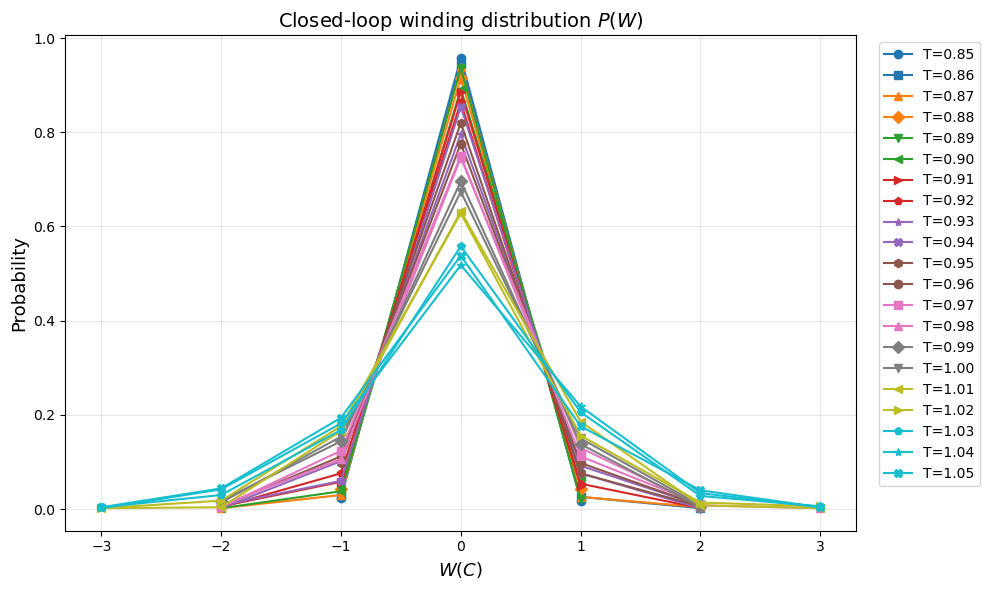

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD NPZ DATA
# ============================================================

filename = "clock_q5_path_winding_scan.npz"

data = np.load(filename)

print("Variables stored in NPZ:")
print(data.files)

# ============================================================
# EXTRACT DATA
# ============================================================

temperatures = data["temperatures"]

W_horizontal = data["W_horizontal"]
W_vertical   = data["W_vertical"]
W_diagonal   = data["W_diagonal"]
W_closed     = data["W_closed"]

P_gt1_horizontal = data["P_gt1_horizontal"]
P_gt1_vertical   = data["P_gt1_vertical"]
P_gt1_diagonal   = data["P_gt1_diagonal"]
P_gt1_closed     = data["P_gt1_closed"]

mean_abs_horizontal = data["mean_abs_horizontal"]
mean_abs_vertical   = data["mean_abs_vertical"]
mean_abs_diagonal   = data["mean_abs_diagonal"]
mean_abs_closed     = data["mean_abs_closed"]

print("\nTemperatures:")
print(temperatures)
# CLOSED-LOOP WINDING DISTRIBUTION
# ============================================================

plt.figure(figsize=(10,6))

markers = [
    'o',
    's',
    '^',
    'D',
    'v',
    '<',
    '>',
    'p',
    '*',
    'X',
    'h'
]

colors = plt.cm.tab10(
    np.linspace(0, 1, len(temperatures))
)

for i, T in enumerate(temperatures):

    W = W_closed[i]

    # unique integer winding values
    values, counts = np.unique(
        W,
        return_counts=True
    )

    probability = (
        counts / np.sum(counts)
    )

    plt.plot(
        values,
        probability,
        marker=markers[i % len(markers)],
        color=colors[i % len(colors)],
        linewidth=1.5,
        markersize=6,
        label=f"T={T:.2f}"
    )

#plt.axvline(
    #-1,
    #linestyle='--',
    #linewidth=1
#)

#plt.axvline(
    #1,
    #linestyle='--',
    #linewidth=1
#)

plt.xlabel(r"$W(C)$", fontsize=13)

plt.ylabel(
    "Probability",
    fontsize=13
)

plt.title(
    "Closed-loop winding distribution $P(W)$",
    fontsize=14
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig("Closedloopwindingdistribution.pdf")
plt.show()

Temperatures:
[0.85 0.86 0.87 0.88 0.89 0.9  0.91 0.92 0.93 0.94 0.95 0.96 0.97 0.98
 0.99 1.   1.01 1.02 1.03 1.04 1.05]
Number of temperatures = 21


Temperature 1/21: T = 0.850
Thermalizing...
  thermalization: 3000/15000
  thermalization: 6000/15000
  thermalization: 9000/15000
  thermalization: 12000/15000
Thermalization complete.
Measuring path winding...
  measurement 0/500
  measurement 100/500
  measurement 200/500
  measurement 300/500
  measurement 400/500

T = 0.850
P(|W|>1):
  Horizontal = 0.00000
  Vertical   = 0.00200
  Diagonal   = 0.00000
  Closed     = 0.00000


Temperature 2/21: T = 0.860
Thermalizing...
  thermalization: 3000/15000
  thermalization: 6000/15000
  thermalization: 9000/15000
  thermalization: 12000/15000
Thermalization complete.
Measuring path winding...
  measurement 0/500
  measurement 100/500
  measurement 200/500
  measurement 300/500
  measurement 400/500

T = 0.860
P(|W|>1):
  Horizontal = 0.00000
  Vertical   = 0.00200
  Diagonal   = 0.00000
  C

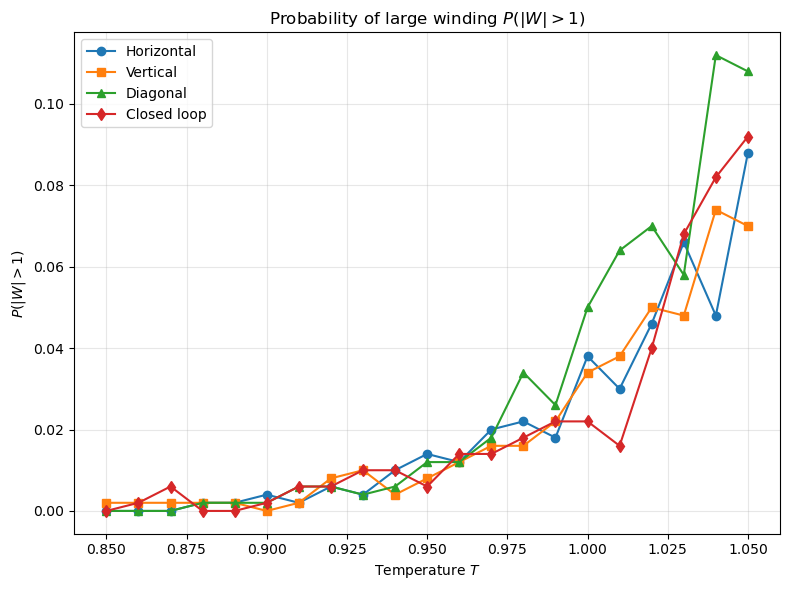

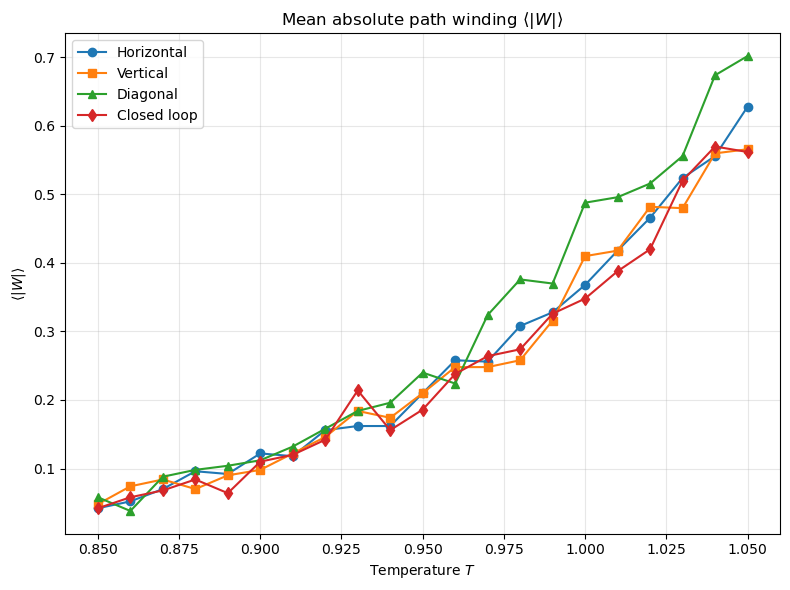

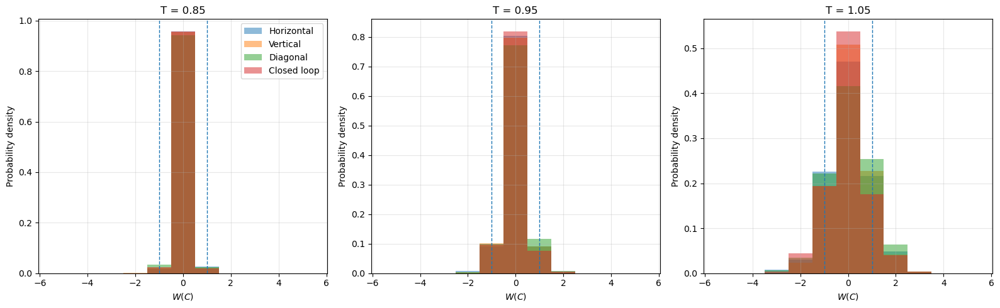

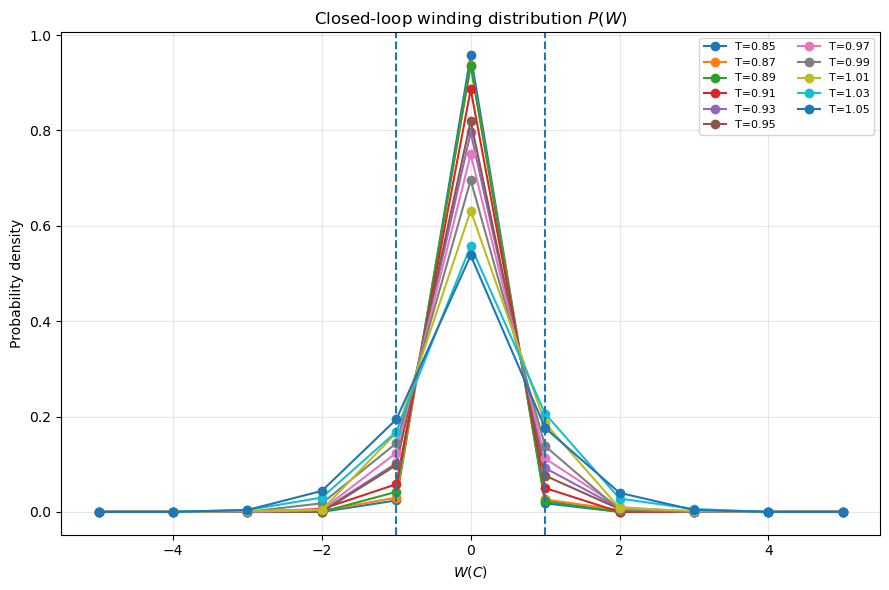

In [3]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 2D q=5 CLOCK MODEL
# WOLFF CLUSTER ALGORITHM
#
# PATH WINDING / VORTICITY ANALYSIS
#
# We calculate:
#
#   W(C) = (1/2π) Σ Δθ
#
# along several paths:
#
#   1. Horizontal
#   2. Vertical
#   3. Diagonal
#   4. Closed loop
#
# and determine:
#
#   P(|W| > 1)
#
# as a function of temperature.
#
# ============================================================


# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# lattice size
L = 64


# ============================================================
# TEMPERATURE RANGE
# ============================================================

# Start temperature
T_min = 0.85

# End temperature
T_max = 1.05

# Temperature spacing
dT = 0.01

temperatures = np.arange(
    T_min,
    T_max + 0.5*dT,
    dT
)

print("Temperatures:")
print(temperatures)
print("Number of temperatures =", len(temperatures))


# ============================================================
# INITIAL CONDITION
# ============================================================

# Choose one:
#
# "random"
# "low"
# "high"
#
# random = completely random spins
# low    = all spins initially aligned
# high   = random spins
#
# For equilibrium measurements, the initial condition
# should not affect the final results if thermalization
# is sufficiently long.

initial_condition = "random"


# ============================================================
# MONTE CARLO PARAMETERS
# ============================================================

# Number of Wolff updates used for equilibration
thermalization = 15000

# Number of measurements at each temperature
measurements = 500

# Number of Wolff updates between measurements
skip_steps = 10


# ============================================================
# PRECOMPUTED CLOCK ANGLES
# ============================================================

ANGLES = (
    2.0
    * np.pi
    * np.arange(q)
    / q
)

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)


# ============================================================
# PRECOMPUTE COSINE INTERACTION TABLE
# ============================================================

COS_DIFF = np.zeros((q, q))

for i in range(q):

    for j in range(q):

        COS_DIFF[i, j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):

    if initial_condition == "random":

        return np.random.randint(
            0,
            q,
            size=(L, L)
        )

    elif initial_condition == "low":

        # Completely ordered state
        return np.zeros(
            (L, L),
            dtype=int
        )

    elif initial_condition == "high":

        # High-temperature-like random state
        return np.random.randint(
            0,
            q,
            size=(L, L)
        )

    else:

        raise ValueError(
            "initial_condition must be "
            "'random', 'low', or 'high'"
        )


# ============================================================
# TOTAL ENERGY
#
# H = -J Σ_<ij> cos(theta_i - theta_j)
#
# Only right and upward neighbors are counted so that
# every bond is counted exactly once.
# ============================================================

def total_energy(spins):

    E = 0.0

    for x in range(L):

        for y in range(L):

            s = spins[x, y]

            # right neighbor
            sr = spins[
                (x + 1) % L,
                y
            ]

            # upward neighbor
            su = spins[
                x,
                (y + 1) % L
            ]

            E += (
                -J
                * COS_DIFF[s, sr]
            )

            E += (
                -J
                * COS_DIFF[s, su]
            )

    return E


# ============================================================
# MAGNETIZATION
#
# Mx = Σ cos(theta_i)
# My = Σ sin(theta_i)
# ============================================================

def magnetization(spins):

    Mx = np.sum(
        COS[spins]
    )

    My = np.sum(
        SIN[spins]
    )

    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    visited.fill(False)

    # --------------------------------------------------------
    # Choose a random reflection axis
    # --------------------------------------------------------

    r = np.random.randint(
        0,
        q
    )

    # --------------------------------------------------------
    # Choose random seed
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [
        (x0, y0)
    ]

    visited[
        x0,
        y0
    ] = True

    cluster = []

    dE = 0.0

    dMx = 0.0
    dMy = 0.0


    # ========================================================
    # GROW CLUSTER
    # ========================================================

    while stack:

        x, y = stack.pop()

        cluster.append(
            (x, y)
        )

        si = spins[x, y]

        # ----------------------------------------------------
        # Reflection
        #
        # s -> 2r - s
        # ----------------------------------------------------

        si_ref = (
            2*r - si
        ) % q


        # ----------------------------------------------------
        # Four nearest neighbors
        # ----------------------------------------------------

        neighbors = (

            (
                (x + 1) % L,
                y
            ),

            (
                (x - 1) % L,
                y
            ),

            (
                x,
                (y + 1) % L
            ),

            (
                x,
                (y - 1) % L
            )

        )


        for nx, ny in neighbors:

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                # ------------------------------------------------
                # Energy advantage of reflecting si
                # ------------------------------------------------

                delta = (

                    COS_DIFF[si, sj]

                    -

                    COS_DIFF[
                        si_ref,
                        sj
                    ]

                )


                if delta > 0:

                    p = (
                        1.0
                        -
                        np.exp(
                            -beta
                            * J
                            * delta
                        )
                    )

                    if (
                        np.random.rand()
                        < p
                    ):

                        visited[
                            nx,
                            ny
                        ] = True

                        stack.append(
                            (nx, ny)
                        )


    # ========================================================
    # ENERGY CHANGE
    #
    # Only bonds connecting the cluster to the outside
    # contribute to the energy change.
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (
            2*r - si
        ) % q


        neighbors = (

            (
                (x + 1) % L,
                y
            ),

            (
                (x - 1) % L,
                y
            ),

            (
                x,
                (y + 1) % L
            ),

            (
                x,
                (y - 1) % L
            )

        )


        for nx, ny in neighbors:

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                dE += (
                    J
                    * (
                        COS_DIFF[si, sj]
                        -
                        COS_DIFF[
                            si_ref,
                            sj
                        ]
                    )
                )


    # ========================================================
    # REFLECT CLUSTER
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (
            2*r - si
        ) % q


        # magnetization change
        dMx += (
            COS[si_ref]
            -
            COS[si]
        )

        dMy += (
            SIN[si_ref]
            -
            SIN[si]
        )


        # perform reflection
        spins[x, y] = si_ref


    return (
        E_current + dE,
        dMx,
        dMy
    )


# ============================================================
# GLOBAL CLOCK ROTATION
#
# The Hamiltonian is invariant under
#
# theta -> theta + constant
#
# so this preserves the energy.
# ============================================================

def global_rotate(spins):

    r = np.random.randint(
        0,
        q
    )

    spins[:] = (
        spins + r
    ) % q

    return r


# ============================================================
# WRAPPED ANGULAR DIFFERENCE
#
# Δθ must lie in
#
# [-π, π]
#
# ============================================================

def wrapped_angle_difference(
    theta1,
    theta2
):

    dtheta = theta2 - theta1

    dtheta = (
        dtheta + np.pi
    ) % (
        2*np.pi
    ) - np.pi

    return dtheta


# ============================================================
# PATH WINDING
#
# W(C) = 1/(2π) Σ Δθ
#
# IMPORTANT:
#
# The path is closed because the final point is connected
# back to the first point.
#
# ============================================================

def path_winding(
    spins,
    path
):

    theta = ANGLES[spins]

    total_winding = 0.0

    n = len(path)


    for i in range(n):

        x1, y1 = path[i]

        x2, y2 = path[
            (i + 1) % n
        ]

        theta1 = theta[
            x1,
            y1
        ]

        theta2 = theta[
            x2,
            y2
        ]

        dtheta = wrapped_angle_difference(
            theta1,
            theta2
        )

        total_winding += dtheta


    W = (
        total_winding
        /
        (2*np.pi)
    )

    return W


# ============================================================
# HORIZONTAL CLOSED PATH
#
# A full row around the periodic lattice.
#
# (x, y) -> (x+1, y)
#
# ============================================================

def horizontal_path(y):

    path = []

    for x in range(L):

        path.append(
            (
                x,
                y
            )
        )

    return path


# ============================================================
# VERTICAL CLOSED PATH
#
# A full column around the periodic lattice.
# ============================================================

def vertical_path(x):

    path = []

    for y in range(L):

        path.append(
            (
                x,
                y
            )
        )

    return path


# ============================================================
# DIAGONAL CLOSED PATH
#
# (x,y)
# -> (x+1,y+1)
#
# Periodic boundary conditions make the path close.
# ============================================================

def diagonal_path():

    path = []

    for i in range(L):

        path.append(
            (
                i,
                i
            )
        )

    return path


# ============================================================
# RECTANGULAR CLOSED LOOP
#
# This is a genuinely local closed contour.
#
# The rectangle has dimensions:
#
# width  = L/4
# height = L/4
#
# and is placed at a random position.
# ============================================================

def closed_loop_path():

    width = L // 4

    height = L // 4

    x0 = np.random.randint(
        0,
        L
    )

    y0 = np.random.randint(
        0,
        L
    )


    path = []


    # bottom
    for dx in range(width):

        path.append(
            (
                (x0 + dx) % L,
                y0 % L
            )
        )


    # right side
    for dy in range(1, height):

        path.append(
            (
                (x0 + width) % L,
                (y0 + dy) % L
            )
        )


    # top
    for dx in range(width, 0, -1):

        path.append(
            (
                (x0 + dx) % L,
                (y0 + height) % L
            )
        )


    # left side
    for dy in range(height, 0, -1):

        path.append(
            (
                x0 % L,
                (y0 + dy) % L
            )
        )


    return path


# ============================================================
# STORAGE
# ============================================================

nT = len(
    temperatures
)


# W distributions
W_horizontal = np.zeros(
    (nT, measurements)
)

W_vertical = np.zeros(
    (nT, measurements)
)

W_diagonal = np.zeros(
    (nT, measurements)
)

W_closed = np.zeros(
    (nT, measurements)
)


# Probability P(|W| > 1)
P_gt1_horizontal = np.zeros(nT)

P_gt1_vertical = np.zeros(nT)

P_gt1_diagonal = np.zeros(nT)

P_gt1_closed = np.zeros(nT)


# Average |W|
mean_abs_horizontal = np.zeros(nT)

mean_abs_vertical = np.zeros(nT)

mean_abs_diagonal = np.zeros(nT)

mean_abs_closed = np.zeros(nT)


# ============================================================
# MAIN TEMPERATURE LOOP
# ============================================================

for ti, T in enumerate(temperatures):


    print("\n")
    print("=" * 65)
    print(
        f"Temperature {ti+1}/{nT}: T = {T:.3f}"
    )
    print("=" * 65)


    beta = 1.0 / T


    # ========================================================
    # INITIALIZE
    # ========================================================

    spins = new_state(L)

    visited = np.zeros(
        (L, L),
        dtype=bool
    )


    E = total_energy(
        spins
    )


    Mx, My = magnetization(
        spins
    )


    # ========================================================
    # THERMALIZATION
    # ========================================================

    print(
        "Thermalizing..."
    )


    for step in range(
        thermalization
    ):

        E, dMx, dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )

        Mx += dMx
        My += dMy


        # --------------------------------------------
        # Global rotation
        # --------------------------------------------

        r = global_rotate(
            spins
        )


        c = COS[r]
        s = SIN[r]


        Mx, My = (

            Mx*c - My*s,

            Mx*s + My*c

        )


        # --------------------------------------------
        # progress
        # --------------------------------------------

        if (
            step % 3000 == 0
            and step > 0
        ):

            print(
                f"  thermalization: "
                f"{step}/{thermalization}"
            )


    print(
        "Thermalization complete."
    )


    # ========================================================
    # MEASURE PATH WINDING
    # ========================================================

    print(
        "Measuring path winding..."
    )


    for meas in range(
        measurements
    ):


        # ====================================================
        # DECORRELATION
        # ====================================================

        for _ in range(
            skip_steps
        ):

            E, dMx, dMy = wolff_cluster(
                spins,
                beta,
                E,
                visited
            )

            Mx += dMx
            My += dMy


        # ====================================================
        # CHOOSE RANDOM HORIZONTAL PATH
        # ====================================================

        y_random = np.random.randint(
            0,
            L
        )

        horizontal = horizontal_path(
            y_random
        )


        # ====================================================
        # CHOOSE RANDOM VERTICAL PATH
        # ====================================================

        x_random = np.random.randint(
            0,
            L
        )

        vertical = vertical_path(
            x_random
        )


        # ====================================================
        # DIAGONAL PATH
        # ====================================================

        diagonal = diagonal_path()


        # ====================================================
        # RANDOM CLOSED LOOP
        # ====================================================

        closed = closed_loop_path()


        # ====================================================
        # CALCULATE WINDING
        # ====================================================

        Wh = path_winding(
            spins,
            horizontal
        )

        Wv = path_winding(
            spins,
            vertical
        )

        Wd = path_winding(
            spins,
            diagonal
        )

        Wc = path_winding(
            spins,
            closed
        )


        # ====================================================
        # STORE
        # ====================================================

        W_horizontal[
            ti,
            meas
        ] = Wh

        W_vertical[
            ti,
            meas
        ] = Wv

        W_diagonal[
            ti,
            meas
        ] = Wd

        W_closed[
            ti,
            meas
        ] = Wc


        # ====================================================
        # PROGRESS
        # ====================================================

        if (
            meas % 100 == 0
        ):

            print(
                f"  measurement "
                f"{meas}/{measurements}"
            )


    # ========================================================
    # CALCULATE P(|W| > 1)
    # ========================================================

    P_gt1_horizontal[ti] = np.mean(
        np.abs(
            W_horizontal[ti]
        ) > 1
    )

    P_gt1_vertical[ti] = np.mean(
        np.abs(
            W_vertical[ti]
        ) > 1
    )

    P_gt1_diagonal[ti] = np.mean(
        np.abs(
            W_diagonal[ti]
        ) > 1
    )

    P_gt1_closed[ti] = np.mean(
        np.abs(
            W_closed[ti]
        ) > 1
    )


    # ========================================================
    # CALCULATE <|W|>
    # ========================================================

    mean_abs_horizontal[ti] = np.mean(
        np.abs(
            W_horizontal[ti]
        )
    )

    mean_abs_vertical[ti] = np.mean(
        np.abs(
            W_vertical[ti]
        )
    )

    mean_abs_diagonal[ti] = np.mean(
        np.abs(
            W_diagonal[ti]
        )
    )

    mean_abs_closed[ti] = np.mean(
        np.abs(
            W_closed[ti]
        )
    )


    # ========================================================
    # PRINT RESULTS FOR THIS TEMPERATURE
    # ========================================================

    print()
    print(
        f"T = {T:.3f}"
    )

    print(
        "P(|W|>1):"
    )

    print(
        f"  Horizontal = "
        f"{P_gt1_horizontal[ti]:.5f}"
    )

    print(
        f"  Vertical   = "
        f"{P_gt1_vertical[ti]:.5f}"
    )

    print(
        f"  Diagonal   = "
        f"{P_gt1_diagonal[ti]:.5f}"
    )

    print(
        f"  Closed     = "
        f"{P_gt1_closed[ti]:.5f}"
    )


# ============================================================
# SAVE EVERYTHING IN ONE NPZ FILE
# ============================================================

np.savez(

    "clock_q5_path_winding_scan.npz",

    q=q,

    J=J,

    L=L,

    temperatures=temperatures,

    thermalization=thermalization,

    measurements=measurements,

    skip_steps=skip_steps,

    W_horizontal=W_horizontal,

    W_vertical=W_vertical,

    W_diagonal=W_diagonal,

    W_closed=W_closed,

    P_gt1_horizontal=P_gt1_horizontal,

    P_gt1_vertical=P_gt1_vertical,

    P_gt1_diagonal=P_gt1_diagonal,

    P_gt1_closed=P_gt1_closed,

    mean_abs_horizontal=mean_abs_horizontal,

    mean_abs_vertical=mean_abs_vertical,

    mean_abs_diagonal=mean_abs_diagonal,

    mean_abs_closed=mean_abs_closed

)


print()
print(
    "============================================================"
)
print(
    "ALL TEMPERATURES FINISHED"
)
print(
    "============================================================"
)

print(
    "Saved all data to:"
)

print(
    "clock_q5_path_winding_scan.npz"
)


# ============================================================
# PLOT 1:
# P(|W| > 1) VS TEMPERATURE
# ============================================================

plt.figure(
    figsize=(8,6)
)


plt.plot(
    temperatures,
    P_gt1_horizontal,
    'o-',
    label='Horizontal'
)

plt.plot(
    temperatures,
    P_gt1_vertical,
    's-',
    label='Vertical'
)

plt.plot(
    temperatures,
    P_gt1_diagonal,
    '^-',
    label='Diagonal'
)

plt.plot(
    temperatures,
    P_gt1_closed,
    'd-',
    label='Closed loop'
)


plt.xlabel(
    'Temperature $T$'
)

plt.ylabel(
    r'$P(|W|>1)$'
)

plt.title(
    r'Probability of large winding '
    r'$P(|W|>1)$'
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# PLOT 2:
# AVERAGE |W| VS TEMPERATURE
# ============================================================

plt.figure(
    figsize=(8,6)
)


plt.plot(
    temperatures,
    mean_abs_horizontal,
    'o-',
    label='Horizontal'
)

plt.plot(
    temperatures,
    mean_abs_vertical,
    's-',
    label='Vertical'
)

plt.plot(
    temperatures,
    mean_abs_diagonal,
    '^-',
    label='Diagonal'
)

plt.plot(
    temperatures,
    mean_abs_closed,
    'd-',
    label='Closed loop'
)


plt.xlabel(
    'Temperature $T$'
)

plt.ylabel(
    r'$\langle |W| \rangle$'
)

plt.title(
    r'Mean absolute path winding '
    r'$\langle |W| \rangle$'
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# PLOT 3:
# W DISTRIBUTION AT SELECTED TEMPERATURES
# ============================================================

# Select three temperatures:
#
# first
# middle
# last
#

selected_indices = [
    0,
    len(temperatures)//2,
    len(temperatures)-1
]


fig, axes = plt.subplots(
    1,
    3,
    figsize=(16,5)
)


for ax, ti in zip(
    axes,
    selected_indices
):


    # --------------------------------------------
    # Horizontal
    # --------------------------------------------

    ax.hist(
        W_horizontal[ti],
        bins=np.arange(
            -5.5,
            6.5,
            1
        ),
        density=True,
        alpha=0.5,
        label='Horizontal'
    )


    # --------------------------------------------
    # Vertical
    # --------------------------------------------

    ax.hist(
        W_vertical[ti],
        bins=np.arange(
            -5.5,
            6.5,
            1
        ),
        density=True,
        alpha=0.5,
        label='Vertical'
    )


    # --------------------------------------------
    # Diagonal
    # --------------------------------------------

    ax.hist(
        W_diagonal[ti],
        bins=np.arange(
            -5.5,
            6.5,
            1
        ),
        density=True,
        alpha=0.5,
        label='Diagonal'
    )


    # --------------------------------------------
    # Closed loop
    # --------------------------------------------

    ax.hist(
        W_closed[ti],
        bins=np.arange(
            -5.5,
            6.5,
            1
        ),
        density=True,
        alpha=0.5,
        label='Closed loop'
    )


    # --------------------------------------------
    # Threshold lines
    # --------------------------------------------

    ax.axvline(
        1,
        linestyle='--',
        linewidth=1
    )

    ax.axvline(
        -1,
        linestyle='--',
        linewidth=1
    )


    ax.set_xlabel(
        r'$W(C)$'
    )

    ax.set_ylabel(
        'Probability density'
    )

    ax.set_title(
        f'T = {temperatures[ti]:.2f}'
    )

    ax.grid(
        True,
        alpha=0.3
    )


axes[0].legend()

plt.tight_layout()

plt.show()


# ============================================================
# PLOT 4:
# CLOSED LOOP DISTRIBUTION FOR ALL TEMPERATURES
#
# This lets you see the gradual evolution of P(W).
# ============================================================

plt.figure(
    figsize=(9,6)
)


for ti, T in enumerate(
    temperatures
):

    # Only plot every 2nd temperature to avoid
    # an overcrowded figure.

    if ti % 2 != 0:

        continue


    values = W_closed[ti]


    # Integer winding bins
    bins = np.arange(
        -5.5,
        6.5,
        1
    )


    hist, edges = np.histogram(
        values,
        bins=bins,
        density=True
    )


    centers = (
        edges[:-1]
        +
        edges[1:]
    ) / 2


    plt.plot(
        centers,
        hist,
        'o-',
        label=f'T={T:.2f}'
    )


plt.axvline(
    1,
    linestyle='--'
)

plt.axvline(
    -1,
    linestyle='--'
)


plt.xlabel(
    r'$W(C)$'
)

plt.ylabel(
    'Probability density'
)

plt.title(
    r'Closed-loop winding distribution $P(W)$'
)

plt.legend(
    ncol=2,
    fontsize=8
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


Running q = 5, T = 0.88
Thermalizing...
Thermalization: 0/15000
Thermalization: 5000/15000
Thermalization: 10000/15000
Thermalization complete.
Measuring magnetization...
Measurement: 0/10000
Measurement: 1000/10000
Measurement: 2000/10000
Measurement: 3000/10000
Measurement: 4000/10000
Measurement: 5000/10000
Measurement: 6000/10000
Measurement: 7000/10000
Measurement: 8000/10000
Measurement: 9000/10000

Running q = 5, T = 0.93
Thermalizing...
Thermalization: 0/15000
Thermalization: 5000/15000
Thermalization: 10000/15000
Thermalization complete.
Measuring magnetization...
Measurement: 0/10000
Measurement: 1000/10000
Measurement: 2000/10000
Measurement: 3000/10000
Measurement: 4000/10000
Measurement: 5000/10000
Measurement: 6000/10000
Measurement: 7000/10000
Measurement: 8000/10000
Measurement: 9000/10000

Running q = 5, T = 1.0
Thermalizing...
Thermalization: 0/15000
Thermalization: 5000/15000
Thermalization: 10000/15000
Thermalization complete.
Measuring magnetization...
Measurement

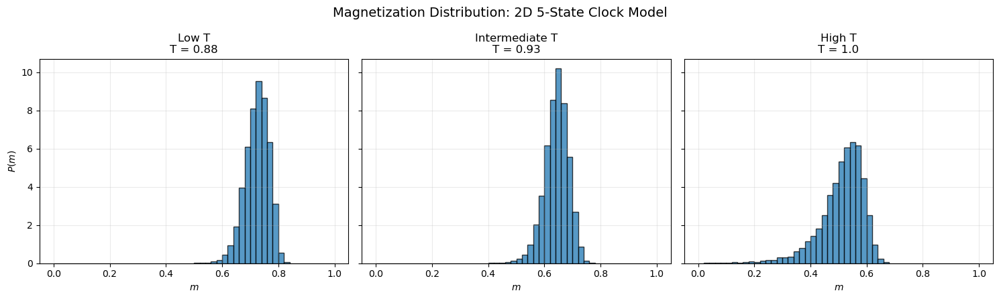

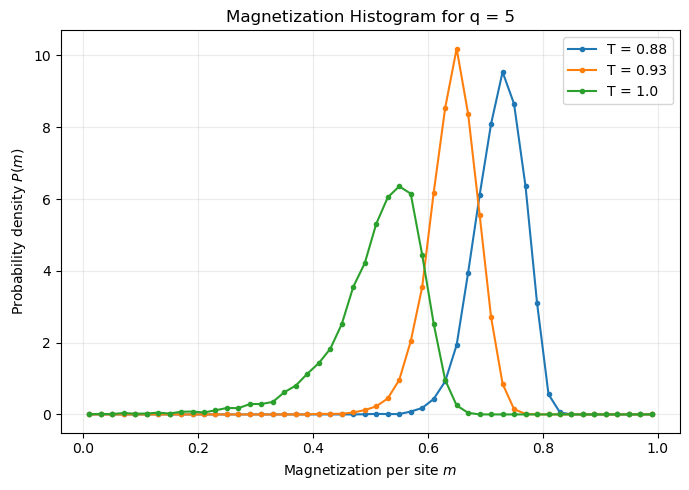


ALL SIMULATIONS FINISHED.


In [17]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 2D q-STATE CLOCK MODEL
# MAGNETIZATION HISTOGRAM USING WOLFF CLUSTER ALGORITHM
# ============================================================

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# lattice size
L = 64

# ------------------------------------------------------------
# TEMPERATURES
# ------------------------------------------------------------

# Ordered phase
T_low = 0.88

# BKT-like / intermediate phase
T_mid = 0.93

# Disordered phase
T_high = 1.0

temperatures = [T_low, T_mid, T_high]

# labels
temp_labels = {
    T_low: "low",
    T_mid: "mid",
    T_high: "high"
}

# ============================================================
# MONTE CARLO PARAMETERS
# ============================================================

# Number of Wolff updates used for thermalization
thermalization = 15000

# Number of magnetization measurements
measurements = 10000

# Number of Wolff updates between measurements
skip_steps = 10

# ============================================================
# PRECOMPUTED ANGLES
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# ============================================================
# PRECOMPUTE COS(theta_i - theta_j)
# ============================================================

COS_DIFF = np.zeros((q, q))

for i in range(q):
    for j in range(q):

        COS_DIFF[i, j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )

# ============================================================
# INITIAL RANDOM STATE
# ============================================================

def new_state(L):

    return np.random.randint(
        0,
        q,
        size=(L, L)
    )

# ============================================================
# TOTAL ENERGY
#
# H = -J sum_<ij> cos(theta_i - theta_j)
# ============================================================

def total_energy(spins):

    E = 0.0

    for x in range(L):
        for y in range(L):

            s = spins[x, y]

            sr = spins[(x + 1) % L, y]
            su = spins[x, (y + 1) % L]

            E += -J * COS_DIFF[s, sr]
            E += -J * COS_DIFF[s, su]

    return E

# ============================================================
# MAGNETIZATION COMPONENTS
# ============================================================

def magnetization(spins):

    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])

    return Mx, My

# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    visited.fill(False)

    # --------------------------------------------------------
    # Random discrete reflection axis
    # --------------------------------------------------------

    r = np.random.randint(0, q)

    # --------------------------------------------------------
    # Random seed site
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]

    visited[x0, y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ========================================================
    # CLUSTER GROWTH
    # ========================================================

    while stack:

        x, y = stack.pop()

        cluster.append((x, y))

        si = spins[x, y]

        # ----------------------------------------------------
        # Reflection of the clock state
        #
        # si_ref = 2r - si (mod q)
        # ----------------------------------------------------

        si_ref = (2 * r - si) % q

        # ----------------------------------------------------
        # Four nearest neighbors
        # ----------------------------------------------------

        for nx, ny in (

            ((x + 1) % L, y),
            ((x - 1) % L, y),
            (x, (y + 1) % L),
            (x, (y - 1) % L)

        ):

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                # ------------------------------------------------
                # Energy difference associated with reflection
                # ------------------------------------------------

                delta = (
                    COS_DIFF[si, sj]
                    -
                    COS_DIFF[si_ref, sj]
                )

                # ------------------------------------------------
                # Wolff bond probability
                # ------------------------------------------------

                if delta > 0:

                    p = 1 - np.exp(
                        -beta * J * delta
                    )

                    if np.random.rand() < p:

                        visited[nx, ny] = True

                        stack.append((nx, ny))

    # ========================================================
    # ENERGY CORRECTION
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (2 * r - si) % q

        for nx, ny in (

            ((x + 1) % L, y),
            ((x - 1) % L, y),
            (x, (y + 1) % L),
            (x, (y - 1) % L)

        ):

            # Only cluster boundary bonds contribute
            if not visited[nx, ny]:

                sj = spins[nx, ny]

                dE += J * (
                    COS_DIFF[si, sj]
                    -
                    COS_DIFF[si_ref, sj]
                )

    # ========================================================
    # REFLECT CLUSTER
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (2 * r - si) % q

        # Magnetization change
        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        # Actually change the spin
        spins[x, y] = si_ref

    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION
#
# Rotates every clock spin by the same allowed angle.
# This does not change the energy.
# ============================================================

def global_rotate(spins):

    r = np.random.randint(0, q)

    spins[:] = (spins + r) % q

    return r

# ============================================================
# MAGNETIZATION HISTOGRAM FUNCTION
# ============================================================

def run_temperature(T):

    print("\n============================================")
    print(f"Running q = {q}, T = {T}")
    print("============================================")

    beta = 1.0 / T

    # --------------------------------------------------------
    # Initialize system
    # --------------------------------------------------------

    spins = new_state(L)

    visited = np.zeros(
        (L, L),
        dtype=bool
    )

    # Initial energy
    E = total_energy(spins)

    # Initial magnetization
    Mx, My = magnetization(spins)

    N = L * L

    # ========================================================
    # THERMALIZATION
    # ========================================================

    print("Thermalizing...")

    for step in range(thermalization):

        E, dMx, dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )

        Mx += dMx
        My += dMy

        # ----------------------------------------------------
        # Global rotation
        # ----------------------------------------------------

        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]

        Mx, My = (
            Mx * c - My * s,
            Mx * s + My * c
        )

        if step % 5000 == 0:
            print(
                f"Thermalization: "
                f"{step}/{thermalization}"
            )

    print("Thermalization complete.")

    # ========================================================
    # MEASURE MAGNETIZATION
    # ========================================================

    M_samples = np.zeros(measurements)

    print("Measuring magnetization...")

    for meas in range(measurements):

        # ----------------------------------------------------
        # Decorrelate between measurements
        # ----------------------------------------------------

        for _ in range(skip_steps):

            E, dMx, dMy = wolff_cluster(
                spins,
                beta,
                E,
                visited
            )

            Mx += dMx
            My += dMy

        # ----------------------------------------------------
        # Magnetization magnitude per site
        #
        # m = sqrt(Mx^2 + My^2)/N
        # ----------------------------------------------------

        m = np.sqrt(
            Mx**2 + My**2
        ) / N

        M_samples[meas] = m

        if meas % 1000 == 0:
            print(
                f"Measurement: "
                f"{meas}/{measurements}"
            )

    # ========================================================
    # HISTOGRAM
    # ========================================================

    hist, bins = np.histogram(
        M_samples,
        bins=50,
        range=(0, 1),
        density=True
    )

    bin_centers = (
        bins[:-1] + bins[1:]
    ) / 2

    return (
        M_samples,
        bin_centers,
        hist
    )

# ============================================================
# RUN ALL THREE TEMPERATURES
# ============================================================

all_samples = {}
all_bin_centers = {}
all_histograms = {}

for T in temperatures:

    samples, bin_centers, hist = run_temperature(T)

    all_samples[T] = samples
    all_bin_centers[T] = bin_centers
    all_histograms[T] = hist

# ============================================================
# SAVE EVERYTHING IN ONE NPZ FILE
# ============================================================

np.savez(
    f"clock_q{q}_L{L}_magnetization_histograms.npz",

    q=q,
    J=J,
    L=L,

    temperatures=np.array(temperatures),

    T_low=T_low,
    T_mid=T_mid,
    T_high=T_high,

    thermalization=thermalization,
    measurements=measurements,
    skip_steps=skip_steps,

    # Raw magnetization samples
    M_low=all_samples[T_low],
    M_mid=all_samples[T_mid],
    M_high=all_samples[T_high],

    # Histogram x-axis
    bins_low=all_bin_centers[T_low],
    bins_mid=all_bin_centers[T_mid],
    bins_high=all_bin_centers[T_high],

    # Probability density
    hist_low=all_histograms[T_low],
    hist_mid=all_histograms[T_mid],
    hist_high=all_histograms[T_high]
)

print(
    f"\nData saved to: "
    f"clock_q{q}_L{L}_magnetization_histograms.npz"
)

# ============================================================
# PLOT 1:
# THREE HISTOGRAMS SEPARATELY
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5),
    sharey=True
)

for ax, T, label in zip(
    axes,
    temperatures,
    ["Low T", "Intermediate T", "High T"]
):

    ax.hist(
        all_samples[T],
        bins=50,
        range=(0, 1),
        density=True,
        alpha=0.75,
        edgecolor='black'
    )

    ax.set_xlabel(r"$m$")
    ax.set_title(
        f"{label}\nT = {T}"
    )

    ax.grid(
        alpha=0.25
    )

axes[0].set_ylabel(
    r"$P(m)$"
)

fig.suptitle(
    f"Magnetization Distribution: "
    f"2D {q}-State Clock Model",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ============================================================
# PLOT 2:
# ALL THREE ON ONE GRAPH
# ============================================================

plt.figure(figsize=(7, 5))

for T in temperatures:

    plt.plot(
        all_bin_centers[T],
        all_histograms[T],
        marker='o',
        markersize=3,
        label=f"T = {T}"
    )

plt.xlabel(
    r"Magnetization per site $m$"
)

plt.ylabel(
    r"Probability density $P(m)$"
)

plt.title(
    f"Magnetization Histogram "
    f"for q = {q}"
)

plt.legend()
plt.grid(alpha=0.25)
plt.savefig("MagnetizationDistribq5Clock.pdf")
plt.tight_layout()
plt.show()

print("\nALL SIMULATIONS FINISHED.")



RUNNING T = 0.82
Thermalizing...
Thermalization complete.
Measuring path circulation...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500

Results for T = 0.82
--------------------------------------------
Horizontal P(|W|>1) = 0.003
Vertical   P(|W|>1) = 0.0032
Diagonal   P(|W|>1) = 0.0034
Closed     P(|W|>1) = 0.0002


RUNNING T = 0.93
Thermalizing...
Thermalization complete.
Measuring path circulation...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500

Results for T = 0.93
--------------------------------------------
Horizontal P(|W|>1) = 0.0302
Vertical   P(|W|>1) = 0.0298
Diagonal   P(|W|>1) = 0.0392
Closed     P(|W|>1) = 0.0048


RUNNING T = 1.15
Thermalizing...
Thermalization complete.
M

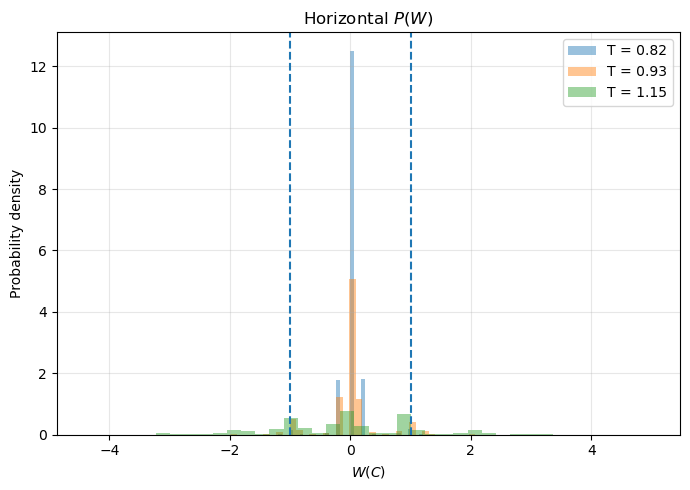

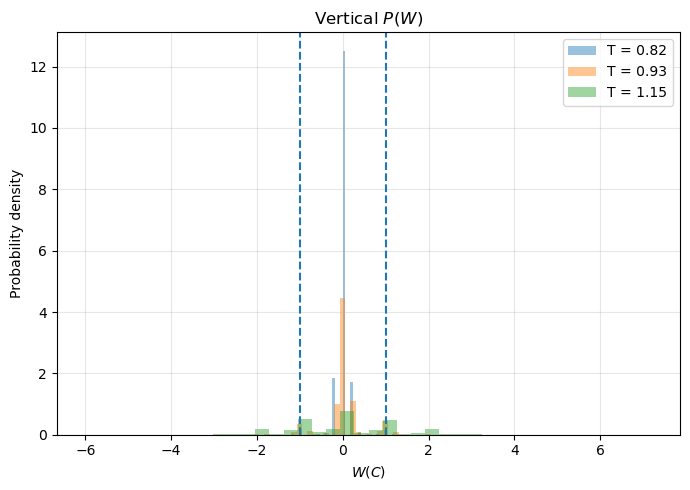

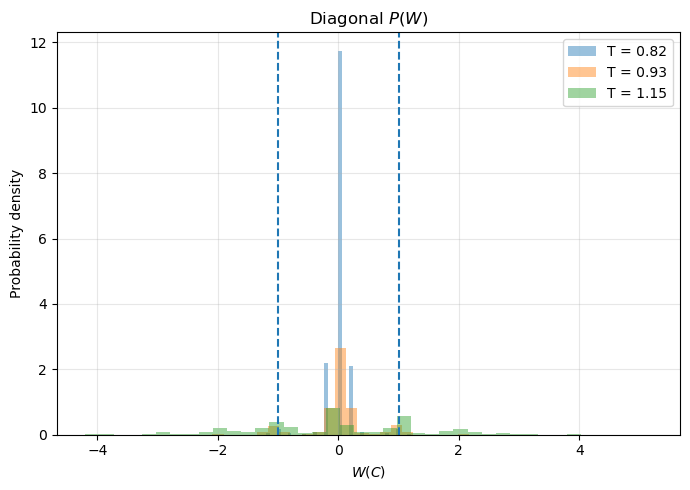

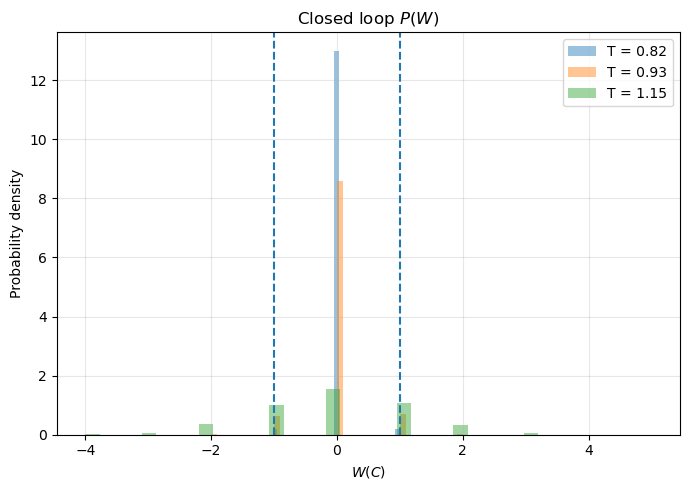

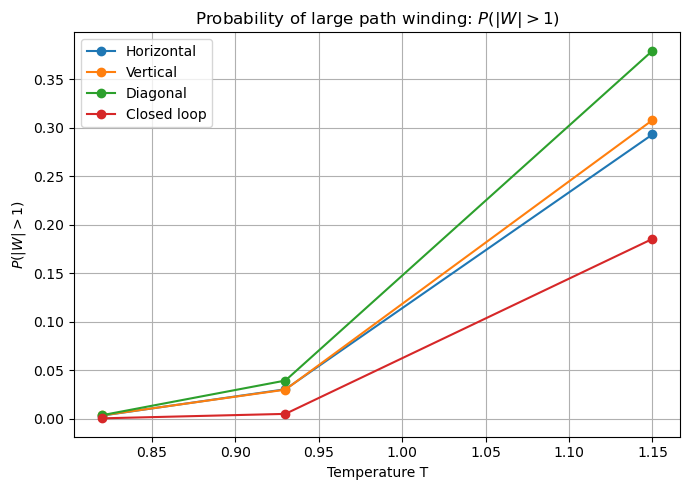

In [3]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 2D q-STATE CLOCK MODEL
#
# WOLFF ALGORITHM
#
# CALCULATES:
#
#   W(C) = path circulation / winding
#
# for:
#   1. Horizontal paths
#   2. Vertical paths
#   3. Diagonal paths
#   4. Closed loops
#
# Also calculates:
#
#   P(W)
#
# and
#
#   P_{>1}(T) = P(|W| > 1)
#
# ============================================================


# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

L = 64


# ============================================================
# THREE TEMPERATURE REGIMES
# ============================================================

# Below the lower transition
T_low = 0.82

# Near / inside the BKT-like region
T_mid = 0.93

# Above the transition
T_high = 1.15

temperatures = [
    T_low,
    T_mid,
    T_high
]


# ============================================================
# MONTE CARLO PARAMETERS
# ============================================================

# Thermalization
thermalization = 15000

# Number of decorrelated configurations
measurements = 500

# Wolff updates between measurements
skip_steps = 10

# Number of different paths sampled
# from each configuration
paths_per_measurement = 10


# ============================================================
# RANDOM SEED
# ============================================================

# Set to an integer if reproducibility is wanted.
# Example:
#
# np.random.seed(12345)
#
# Leave commented for a different simulation every run.

# np.random.seed(12345)


# ============================================================
# CLOCK ANGLES
# ============================================================

ANGLES = 2*np.pi*np.arange(q)/q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)


# ============================================================
# PRECOMPUTE COS(theta_i - theta_j)
# ============================================================

COS_DIFF = np.zeros((q, q))

for i in range(q):

    for j in range(q):

        COS_DIFF[i, j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )


# ============================================================
# RANDOM INITIAL STATE
# ============================================================

def new_state(L):

    return np.random.randint(
        0,
        q,
        size=(L, L)
    )


# ============================================================
# TOTAL ENERGY
#
# H = -J sum_<ij> cos(theta_i - theta_j)
#
# Periodic boundary conditions
# ============================================================

def total_energy(spins):

    E = 0.0

    for x in range(L):

        for y in range(L):

            s = spins[x, y]

            # right neighbor
            sr = spins[
                (x + 1) % L,
                y
            ]

            # upper neighbor
            su = spins[
                x,
                (y + 1) % L
            ]

            E += -J * COS_DIFF[s, sr]

            E += -J * COS_DIFF[s, su]

    return E


# ============================================================
# MAGNETIZATION
# ============================================================

def magnetization(spins):

    Mx = np.sum(
        COS[spins]
    )

    My = np.sum(
        SIN[spins]
    )

    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    visited.fill(False)

    # --------------------------------------------------------
    # RANDOM REFLECTION AXIS
    # --------------------------------------------------------

    r = np.random.randint(0, q)

    # --------------------------------------------------------
    # RANDOM SEED
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]

    visited[x0, y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0


    # ========================================================
    # GROW CLUSTER
    # ========================================================

    while stack:

        x, y = stack.pop()

        cluster.append(
            (x, y)
        )

        si = spins[x, y]

        # Reflection:
        #
        # theta -> 2 theta_r - theta
        #
        si_ref = (2*r - si) % q


        # ----------------------------------------------------
        # FOUR NEAREST NEIGHBORS
        # ----------------------------------------------------

        neighbors = (

            ((x + 1) % L, y),
            ((x - 1) % L, y),
            (x, (y + 1) % L),
            (x, (y - 1) % L)

        )


        for nx, ny in neighbors:

            if not visited[nx, ny]:

                sj = spins[nx, ny]


                # ------------------------------------------------
                # ENERGY BIAS FOR ADDING NEIGHBOR
                # ------------------------------------------------

                delta = (

                    COS_DIFF[si, sj]
                    -
                    COS_DIFF[si_ref, sj]

                )


                if delta > 0:

                    p = 1.0 - np.exp(
                        -beta * J * delta
                    )


                    if np.random.rand() < p:

                        visited[nx, ny] = True

                        stack.append(
                            (nx, ny)
                        )


    # ========================================================
    # ENERGY CHANGE
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (2*r - si) % q


        neighbors = (

            ((x + 1) % L, y),
            ((x - 1) % L, y),
            (x, (y + 1) % L),
            (x, (y - 1) % L)

        )


        for nx, ny in neighbors:

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                dE += J * (

                    COS_DIFF[si, sj]
                    -
                    COS_DIFF[si_ref, sj]

                )


    # ========================================================
    # FLIP CLUSTER
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (2*r - si) % q


        dMx += (
            COS[si_ref]
            -
            COS[si]
        )

        dMy += (
            SIN[si_ref]
            -
            SIN[si]
        )


        spins[x, y] = si_ref


    return (
        E_current + dE,
        dMx,
        dMy
    )


# ============================================================
# GLOBAL ROTATION
# ============================================================

def global_rotate(spins):

    r = np.random.randint(
        0,
        q
    )

    spins[:] = (
        spins + r
    ) % q

    return r


# ============================================================
# WRAPPED ANGULAR DIFFERENCE
#
# Delta theta is restricted to:
#
#       -pi < Delta theta <= pi
#
# ============================================================

def angle_diff(a, b):

    d = b - a

    d = (
        d + np.pi
    ) % (
        2*np.pi
    ) - np.pi

    return d


# ============================================================
# PATH CIRCULATION
#
# W(C) = 1/(2*pi) sum Delta theta
#
# For a CLOSED path:
#
#       W = integer winding number
#
# For an OPEN path:
#
#       W = path circulation
#
# ============================================================

def path_winding(spins, path, closed=False):

    total = 0.0

    n = len(path)


    # --------------------------------------------------------
    # SUM ANGULAR DIFFERENCES
    # --------------------------------------------------------

    for i in range(n - 1):

        x1, y1 = path[i]

        x2, y2 = path[i + 1]


        theta1 = ANGLES[
            spins[x1, y1]
        ]

        theta2 = ANGLES[
            spins[x2, y2]
        ]


        total += angle_diff(
            theta1,
            theta2
        )


    # --------------------------------------------------------
    # CLOSE THE PATH
    # --------------------------------------------------------

    if closed:

        x1, y1 = path[-1]

        x2, y2 = path[0]


        theta1 = ANGLES[
            spins[x1, y1]
        ]

        theta2 = ANGLES[
            spins[x2, y2]
        ]


        total += angle_diff(
            theta1,
            theta2
        )


    # --------------------------------------------------------
    # CONVERT TO WINDING UNITS
    # --------------------------------------------------------

    return total / (2*np.pi)


# ============================================================
# HORIZONTAL PATH
#
# Goes across the lattice.
#
# (x,y0)
# (x+1,y0)
# ...
#
# OPEN PATH
# ============================================================

def horizontal_path(L):

    y0 = np.random.randint(L)

    path = [

        (x, y0)

        for x in range(L)

    ]

    return path


# ============================================================
# VERTICAL PATH
#
# OPEN PATH
# ============================================================

def vertical_path(L):

    x0 = np.random.randint(L)

    path = [

        (x0, y)

        for y in range(L)

    ]

    return path


# ============================================================
# DIAGONAL PATH
#
# Main diagonal direction.
#
# OPEN PATH
#
# Periodic coordinates are used.
# ============================================================

def diagonal_path(L):

    x0 = np.random.randint(L)

    y0 = np.random.randint(L)

    path = [

        (
            (x0 + i) % L,
            (y0 + i) % L
        )

        for i in range(L)

    ]

    return path


# ============================================================
# CLOSED LOOP
#
# We use a square loop.
#
# The loop has approximately L bonds in total:
#
# side = L/4
#
# perimeter = 4*(L/4) = L
#
# This makes its length comparable to the
# horizontal / vertical / diagonal paths.
# ============================================================

def closed_square_path(L):

    side = L // 4

    # random starting position
    x0 = np.random.randint(L)

    y0 = np.random.randint(L)


    path = []


    # --------------------------------------------------------
    # BOTTOM EDGE
    # --------------------------------------------------------

    for i in range(side):

        path.append(

            (
                (x0 + i) % L,
                y0
            )

        )


    # --------------------------------------------------------
    # RIGHT EDGE
    # --------------------------------------------------------

    for i in range(1, side):

        path.append(

            (
                (x0 + side - 1) % L,
                (y0 + i) % L
            )

        )


    # --------------------------------------------------------
    # TOP EDGE
    # --------------------------------------------------------

    for i in range(1, side):

        path.append(

            (
                (x0 + side - 1 - i) % L,
                (y0 + side - 1) % L
            )

        )


    # --------------------------------------------------------
    # LEFT EDGE
    # --------------------------------------------------------

    for i in range(1, side):

        path.append(

            (
                x0,
                (y0 + side - 1 - i) % L
            )

        )


    return path


# ============================================================
# GENERATE ONE SET OF PATH WINDINGS
# ============================================================

def measure_path_windings(spins):

    W_horizontal = []
    W_vertical   = []
    W_diagonal   = []
    W_closed     = []


    # --------------------------------------------------------
    # SAMPLE MULTIPLE PATHS FROM CURRENT CONFIGURATION
    # --------------------------------------------------------

    for _ in range(paths_per_measurement):


        # ====================================================
        # HORIZONTAL
        # ====================================================

        path = horizontal_path(L)

        W = path_winding(
            spins,
            path,
            closed=False
        )

        W_horizontal.append(W)


        # ====================================================
        # VERTICAL
        # ====================================================

        path = vertical_path(L)

        W = path_winding(
            spins,
            path,
            closed=False
        )

        W_vertical.append(W)


        # ====================================================
        # DIAGONAL
        # ====================================================

        path = diagonal_path(L)

        W = path_winding(
            spins,
            path,
            closed=False
        )

        W_diagonal.append(W)


        # ====================================================
        # CLOSED LOOP
        # ====================================================

        path = closed_square_path(L)

        W = path_winding(
            spins,
            path,
            closed=True
        )

        W_closed.append(W)


    return (

        np.array(W_horizontal),

        np.array(W_vertical),

        np.array(W_diagonal),

        np.array(W_closed)

    )


# ============================================================
# PROBABILITY P(|W| > 1)
# ============================================================

def probability_abs_w_greater_than_one(W):

    return np.mean(
        np.abs(W) > 1.0
    )


# ============================================================
# MAIN SIMULATION
# ============================================================

all_W = {

    "horizontal": [],
    "vertical": [],
    "diagonal": [],
    "closed": []
}


# ============================================================
# STORE P(|W| > 1)
#
# rows    = temperatures
# columns = path types
# ============================================================

P_gt1 = np.zeros(
    (
        len(temperatures),
        4
    )
)


# ============================================================
# STORE MEAN AND RMS
# ============================================================

W_mean = np.zeros(
    (
        len(temperatures),
        4
    )
)


W_rms = np.zeros(
    (
        len(temperatures),
        4
    )
)


# ============================================================
# TEMPERATURE LOOP
# ============================================================

for temp_index, T in enumerate(temperatures):


    print("\n")
    print("================================================")
    print(f"RUNNING T = {T}")
    print("================================================")


    beta = 1.0 / T


    # --------------------------------------------------------
    # INITIAL RANDOM CONFIGURATION
    # --------------------------------------------------------

    spins = new_state(L)


    visited = np.zeros(
        (L, L),
        dtype=bool
    )


    E = total_energy(
        spins
    )


    Mx, My = magnetization(
        spins
    )


    # ========================================================
    # THERMALIZATION
    # ========================================================

    print("Thermalizing...")


    for step in range(
        thermalization
    ):

        E, dMx, dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )


        Mx += dMx

        My += dMy


        # ----------------------------------------------------
        # GLOBAL ROTATION
        # ----------------------------------------------------

        r = global_rotate(
            spins
        )


        c = COS[r]

        s = SIN[r]


        Mx, My = (

            Mx*c - My*s,

            Mx*s + My*c

        )


    print("Thermalization complete.")


    # ========================================================
    # TEMPORARY ARRAYS FOR THIS TEMPERATURE
    # ========================================================

    W_H = []
    W_V = []
    W_D = []
    W_C = []


    # ========================================================
    # MEASUREMENT LOOP
    # ========================================================

    print("Measuring path circulation...")


    for meas in range(
        measurements
    ):


        # ----------------------------------------------------
        # DECORRELATE CONFIGURATION
        # ----------------------------------------------------

        for _ in range(
            skip_steps
        ):

            E, dMx, dMy = wolff_cluster(
                spins,
                beta,
                E,
                visited
            )


            Mx += dMx

            My += dMy


        # ----------------------------------------------------
        # MEASURE PATH WINDINGS
        # ----------------------------------------------------

        WH, WV, WD, WC = measure_path_windings(
            spins
        )


        W_H.extend(WH)

        W_V.extend(WV)

        W_D.extend(WD)

        W_C.extend(WC)


        if meas % 50 == 0:

            print(
                f"Measurement "
                f"{meas}/{measurements}"
            )


    # ========================================================
    # CONVERT TO NUMPY ARRAYS
    # ========================================================

    W_H = np.asarray(W_H)

    W_V = np.asarray(W_V)

    W_D = np.asarray(W_D)

    W_C = np.asarray(W_C)


    # ========================================================
    # SAVE RAW DISTRIBUTIONS IN MEMORY
    # ========================================================

    all_W["horizontal"].append(
        W_H
    )

    all_W["vertical"].append(
        W_V
    )

    all_W["diagonal"].append(
        W_D
    )

    all_W["closed"].append(
        W_C
    )


    # ========================================================
    # CALCULATE P(|W| > 1)
    # ========================================================

    P_gt1[
        temp_index,
        0
    ] = probability_abs_w_greater_than_one(
        W_H
    )


    P_gt1[
        temp_index,
        1
    ] = probability_abs_w_greater_than_one(
        W_V
    )


    P_gt1[
        temp_index,
        2
    ] = probability_abs_w_greater_than_one(
        W_D
    )


    P_gt1[
        temp_index,
        3
    ] = probability_abs_w_greater_than_one(
        W_C
    )


    # ========================================================
    # MEAN
    # ========================================================

    W_mean[
        temp_index,
        0
    ] = np.mean(W_H)


    W_mean[
        temp_index,
        1
    ] = np.mean(W_V)


    W_mean[
        temp_index,
        2
    ] = np.mean(W_D)


    W_mean[
        temp_index,
        3
    ] = np.mean(W_C)


    # ========================================================
    # RMS
    # ========================================================

    W_rms[
        temp_index,
        0
    ] = np.sqrt(
        np.mean(W_H**2)
    )


    W_rms[
        temp_index,
        1
    ] = np.sqrt(
        np.mean(W_V**2)
    )


    W_rms[
        temp_index,
        2
    ] = np.sqrt(
        np.mean(W_D**2)
    )


    W_rms[
        temp_index,
        3
    ] = np.sqrt(
        np.mean(W_C**2)
    )


    # ========================================================
    # PRINT RESULTS FOR THIS TEMPERATURE
    # ========================================================

    print("\nResults for T =", T)

    print("--------------------------------------------")

    print(
        "Horizontal P(|W|>1) =",
        P_gt1[temp_index, 0]
    )

    print(
        "Vertical   P(|W|>1) =",
        P_gt1[temp_index, 1]
    )

    print(
        "Diagonal   P(|W|>1) =",
        P_gt1[temp_index, 2]
    )

    print(
        "Closed     P(|W|>1) =",
        P_gt1[temp_index, 3]
    )


# ============================================================
# CONVERT DICTIONARY TO OBJECT ARRAYS
#
# Each temperature has a distribution.
# ============================================================

W_horizontal = np.array(
    all_W["horizontal"],
    dtype=object
)

W_vertical = np.array(
    all_W["vertical"],
    dtype=object
)

W_diagonal = np.array(
    all_W["diagonal"],
    dtype=object
)

W_closed = np.array(
    all_W["closed"],
    dtype=object
)


# ============================================================
# SAVE EVERYTHING INTO ONE NPZ FILE
# ============================================================

np.savez(

    f"clock_q{q}_L{L}_path_winding.npz",

    q=q,

    J=J,

    L=L,

    temperatures=np.array(
        temperatures
    ),

    thermalization=thermalization,

    measurements=measurements,

    skip_steps=skip_steps,

    paths_per_measurement=paths_per_measurement,

    W_horizontal=W_horizontal,

    W_vertical=W_vertical,

    W_diagonal=W_diagonal,

    W_closed=W_closed,

    P_gt1=P_gt1,

    W_mean=W_mean,

    W_rms=W_rms

)


print("\n")
print("================================================")
print("SIMULATION COMPLETE")
print("================================================")

print(
    f"Data saved to:"
)

print(
    f"clock_q{q}_L{L}_path_winding.npz"
)


# ============================================================
# FINAL SUMMARY TABLE
# ============================================================

print("\n")
print("P(|W| > 1)")
print("--------------------------------------------")

print(
    "Temperature    Horizontal    Vertical    "
    "Diagonal    Closed"
)

for i, T in enumerate(temperatures):

    print(
        f"{T:10.3f}    "
        f"{P_gt1[i,0]:10.5f}    "
        f"{P_gt1[i,1]:10.5f}    "
        f"{P_gt1[i,2]:10.5f}    "
        f"{P_gt1[i,3]:10.5f}"
    )


# ============================================================
# OPTIONAL:
# P(W) DISTRIBUTIONS
#
# These are the distributions you requested.
# ============================================================

path_names = [

    "Horizontal",
    "Vertical",
    "Diagonal",
    "Closed loop"

]


all_distributions = [

    W_horizontal,
    W_vertical,
    W_diagonal,
    W_closed

]


for path_index in range(4):


    plt.figure(
        figsize=(7,5)
    )


    for temp_index, T in enumerate(
        temperatures
    ):


        data = all_distributions[
            path_index
        ][temp_index]


        plt.hist(

            data,

            bins=40,

            density=True,

            alpha=0.45,

            label=f"T = {T}"

        )


    # --------------------------------------------------------
    # |W| = 1 threshold
    # --------------------------------------------------------

    plt.axvline(
        1.0,
        linestyle="--",
        linewidth=1.5
    )


    plt.axvline(
        -1.0,
        linestyle="--",
        linewidth=1.5
    )


    plt.xlabel(
        r"$W(C)$"
    )


    plt.ylabel(
        "Probability density"
    )


    plt.title(
        f"{path_names[path_index]} "
        r"$P(W)$"
    )


    plt.legend()


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# P(|W| > 1) VS TEMPERATURE
# ============================================================

plt.figure(
    figsize=(7,5)
)


for path_index in range(4):

    plt.plot(

        temperatures,

        P_gt1[:, path_index],

        "o-",

        label=path_names[path_index]

    )


plt.xlabel(
    "Temperature T"
)


plt.ylabel(
    r"$P(|W|>1)$"
)


plt.title(
    r"Probability of large path winding: "
    r"$P(|W|>1)$"
)


plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


RUNNING q=5, L=64, T=0.5
Thermalizing...
  thermalization step 0/15000
  thermalization step 5000/15000
  thermalization step 10000/15000
Thermalization finished.
Taking measurements...
  measurement 0/500
  measurement 50/500
  measurement 100/500
  measurement 150/500
  measurement 200/500
  measurement 250/500
  measurement 300/500
  measurement 350/500
  measurement 400/500
  measurement 450/500

-----------------------------------------------
T = 0.5
-----------------------------------------------
Mean horizontal =  0.0016
Mean vertical   =  0.0012000000000000001
Mean diagonal   =  -0.0008000000000000001
Mean closed     =  0.0

Mean absolute path circulation:
<|H|> =  0.0032
<|V|> =  0.002
<|D|> =  0.0031999999999999997
<|C|> =  0.0

Events with |V_path| > 1:
Horizontal: 0 / 500 = 0.0
Vertical: 0 / 500 = 0.0
Diagonal: 0 / 500 = 0.0
Closed: 0 / 500 = 0.0


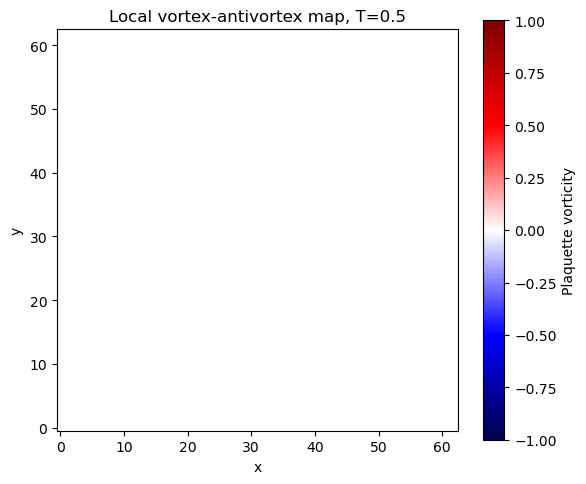

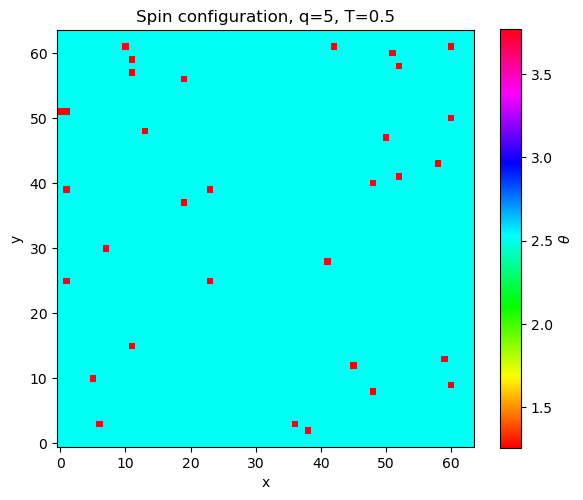

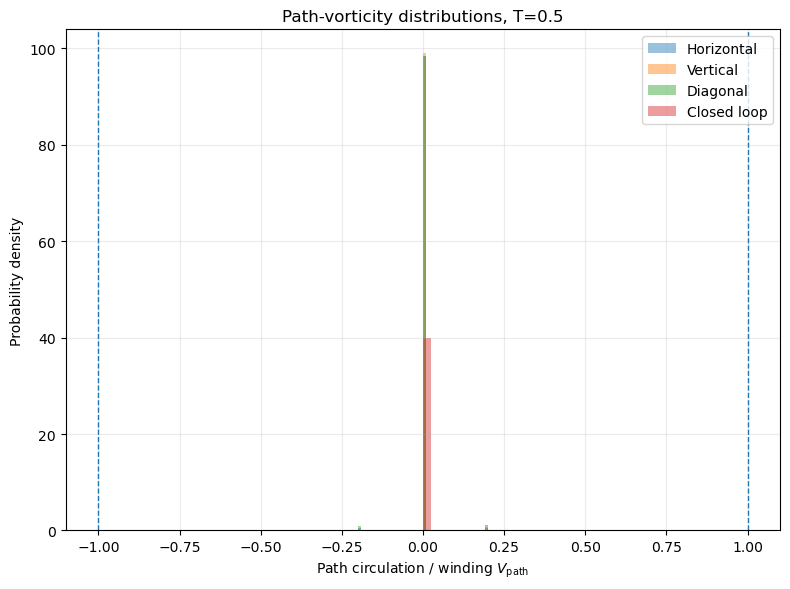

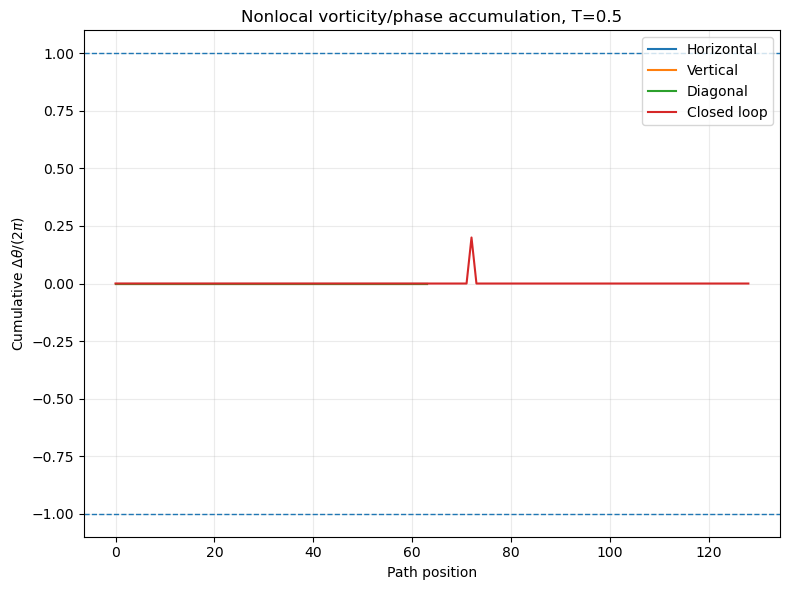


RUNNING q=5, L=64, T=0.93
Thermalizing...
  thermalization step 0/15000
  thermalization step 5000/15000
  thermalization step 10000/15000
Thermalization finished.
Taking measurements...
  measurement 0/500
  measurement 50/500
  measurement 100/500
  measurement 150/500
  measurement 200/500
  measurement 250/500
  measurement 300/500
  measurement 350/500
  measurement 400/500
  measurement 450/500

-----------------------------------------------
T = 0.93
-----------------------------------------------
Mean horizontal =  0.005200000000000002
Mean vertical   =  0.030400000000000003
Mean diagonal   =  -0.0416
Mean closed     =  0.010000000000000004

Mean absolute path circulation:
<|H|> =  0.21800000000000003
<|V|> =  0.2232
<|D|> =  0.256
<|C|> =  0.274

Events with |V_path| > 1:
Horizontal: 18 / 500 = 0.036
Vertical: 19 / 500 = 0.038
Diagonal: 31 / 500 = 0.062
Closed: 38 / 500 = 0.076


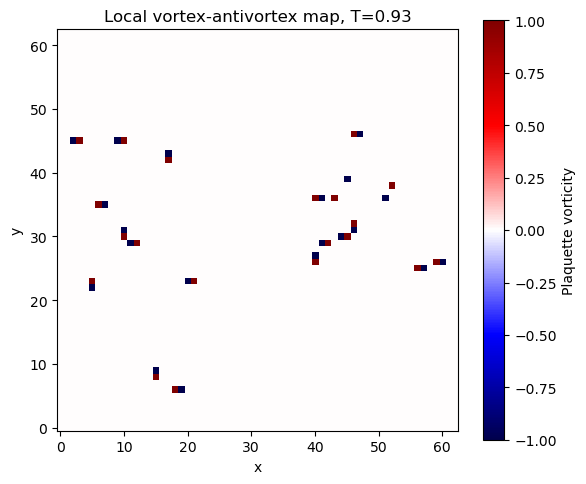

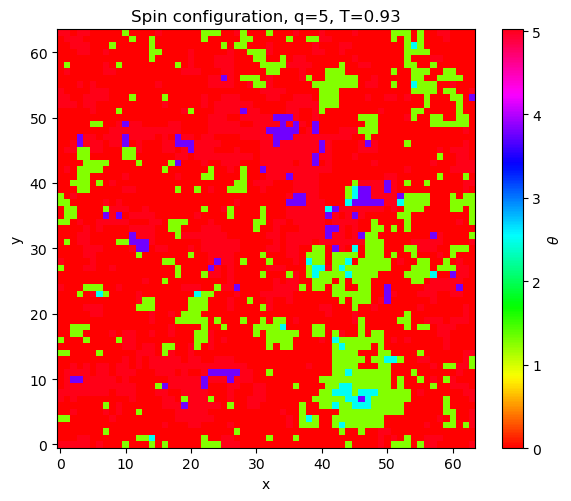

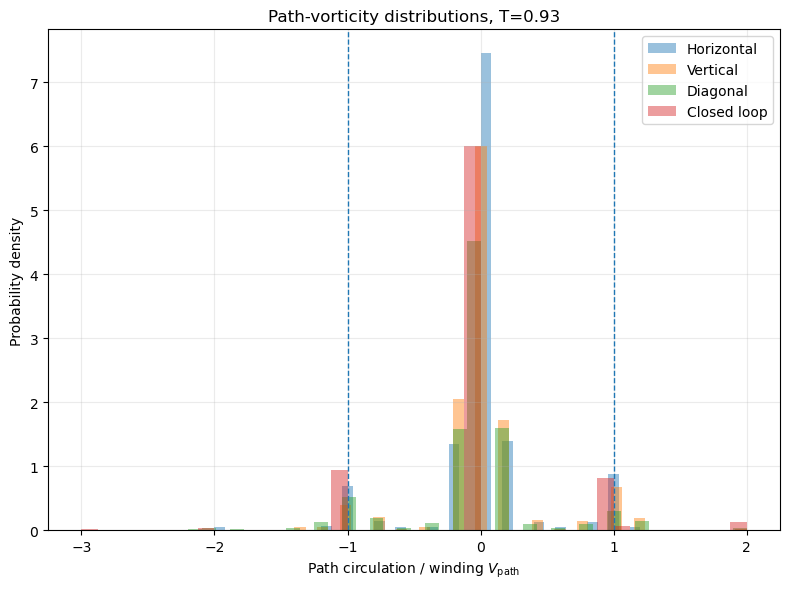

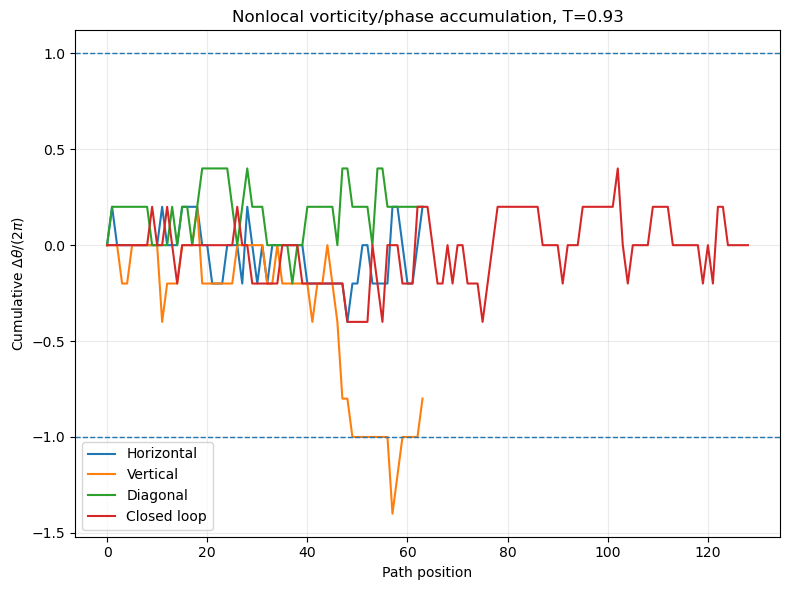


RUNNING q=5, L=64, T=1.5
Thermalizing...
  thermalization step 0/15000
  thermalization step 5000/15000
  thermalization step 10000/15000
Thermalization finished.
Taking measurements...
  measurement 0/500
  measurement 50/500
  measurement 100/500
  measurement 150/500
  measurement 200/500
  measurement 250/500
  measurement 300/500
  measurement 350/500
  measurement 400/500
  measurement 450/500

-----------------------------------------------
T = 1.5
-----------------------------------------------
Mean horizontal =  -0.3664
Mean vertical   =  -0.4168
Mean diagonal   =  0.01399999999999983
Mean closed     =  -0.7240000000000001

Mean absolute path circulation:
<|H|> =  1.2848
<|V|> =  1.0864
<|D|> =  1.5188000000000001
<|C|> =  2.0600000000000005

Events with |V_path| > 1:
Horizontal: 271 / 500 = 0.542
Vertical: 209 / 500 = 0.418
Diagonal: 297 / 500 = 0.594
Closed: 372 / 500 = 0.744


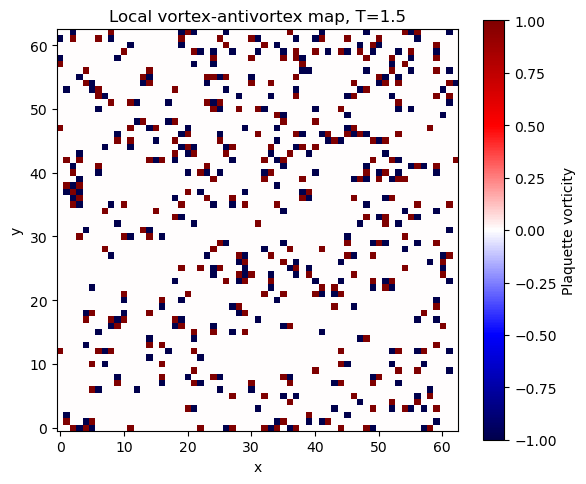

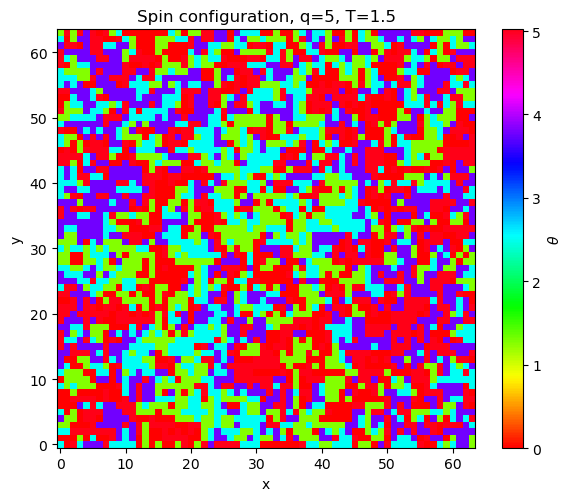

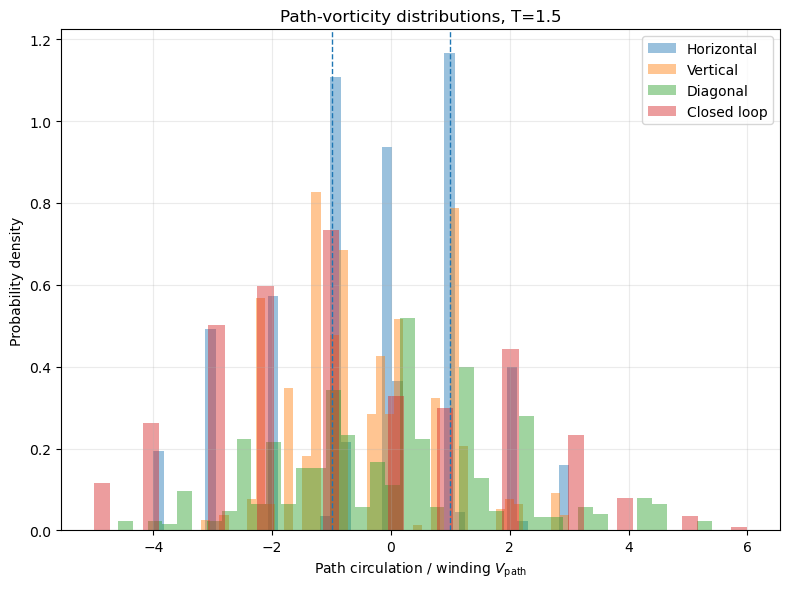

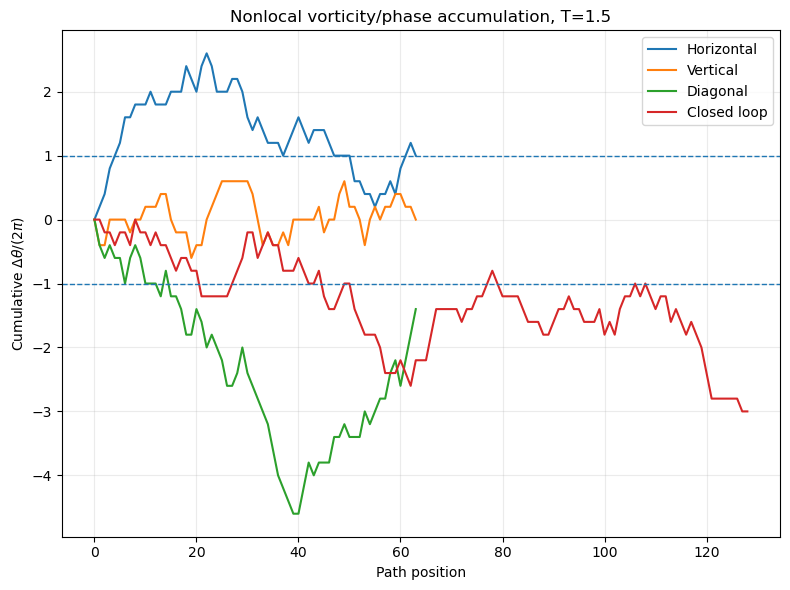

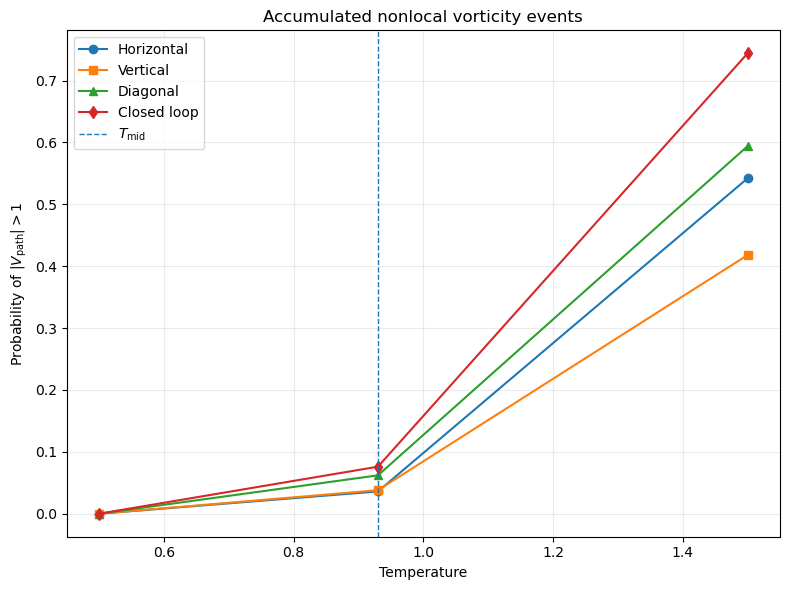

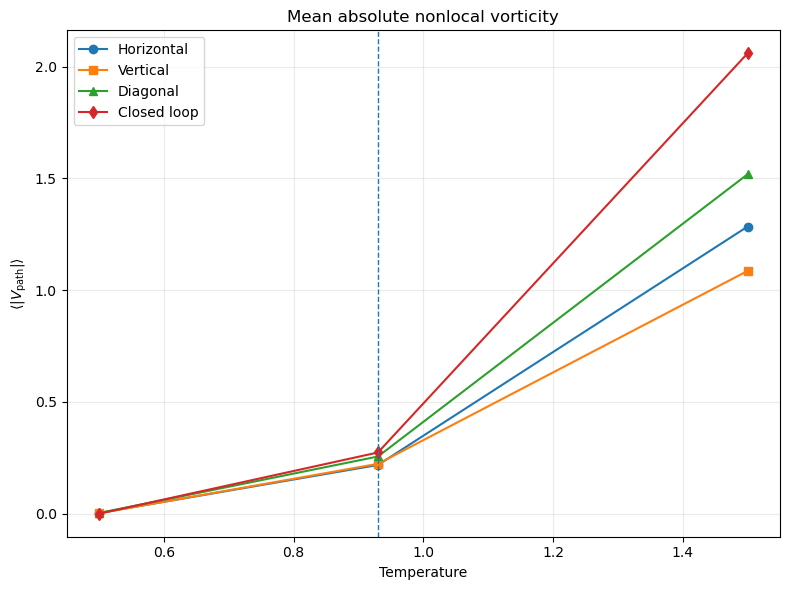


ALL SIMULATIONS FINISHED
All data saved to:
clock_q5_L64_path_vorticity.npz


In [15]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 2D q-STATE CLOCK MODEL
#
# WOLFF CLUSTER ALGORITHM
#
# LOCAL:
#   - plaquette vorticity
#
# NONLOCAL:
#   - horizontal path circulation
#   - vertical path circulation
#   - diagonal path circulation
#   - closed-loop winding
#
# STATISTICS:
#   - average path circulation
#   - absolute path circulation
#   - distributions/histograms
#   - accumulated probability/count of |V| > 1
#
# DATA:
#   - everything saved into ONE .npz file
# ============================================================


# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

L = 64


# ============================================================
# TEMPERATURES
# ============================================================

T_low  = 0.50
T_mid  = 0.93
T_high = 1.50

temperatures = [T_low, T_mid, T_high]


# ============================================================
# INITIAL CONDITION
#
# "ordered" = all spins initially in state 0
# "random"  = completely random state
#
# The initial condition is only important before thermalization.
# After sufficiently long thermalization, equilibrium results
# should not depend on this choice.
# ============================================================

start_mode = "random"


# ============================================================
# MONTE CARLO PARAMETERS
# ============================================================

thermalization = 15000

measurements = 500

skip_steps = 10


# ============================================================
# RANDOM SEED
#
# Set to an integer for reproducibility.
# Set to None for a different random run every time.
# ============================================================

seed = None

if seed is not None:
    np.random.seed(seed)


# ============================================================
# PRECOMPUTED CLOCK ANGLES
# ============================================================

ANGLES = 2*np.pi*np.arange(q)/q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)


# ============================================================
# PRECOMPUTE COS(theta_i - theta_j)
# ============================================================

COS_DIFF = np.zeros((q, q))

for i in range(q):

    for j in range(q):

        COS_DIFF[i, j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L, mode="random"):

    if mode == "ordered":

        return np.zeros(
            (L, L),
            dtype=np.int8
        )

    elif mode == "random":

        return np.random.randint(
            0,
            q,
            size=(L, L)
        ).astype(np.int8)

    else:

        raise ValueError(
            "start_mode must be 'ordered' or 'random'"
        )


# ============================================================
# TOTAL ENERGY
#
# H = -J sum_<ij> cos(theta_i - theta_j)
#
# Only right and upward neighbors are counted so that each
# bond is counted exactly once.
# ============================================================

def total_energy(spins):

    E = 0.0

    for x in range(L):

        for y in range(L):

            s = spins[x, y]

            sr = spins[(x + 1) % L, y]

            su = spins[x, (y + 1) % L]

            E += -J * COS_DIFF[s, sr]

            E += -J * COS_DIFF[s, su]

    return E


# ============================================================
# MAGNETIZATION
#
# Mx = sum cos(theta_i)
# My = sum sin(theta_i)
#
# |M| = sqrt(Mx^2 + My^2)
#
# Normalized magnetization:
#
# m = |M| / N
# ============================================================

def magnetization(spins):

    Mx = np.sum(COS[spins])

    My = np.sum(SIN[spins])

    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    visited.fill(False)

    # --------------------------------------------------------
    # Random reflection axis
    # --------------------------------------------------------

    r = np.random.randint(0, q)

    # --------------------------------------------------------
    # Random seed
    # --------------------------------------------------------

    x0 = np.random.randint(L)

    y0 = np.random.randint(L)

    stack = [(x0, y0)]

    visited[x0, y0] = True

    cluster = []

    dE = 0.0

    dMx = 0.0

    dMy = 0.0


    # ========================================================
    # CLUSTER GROWTH
    # ========================================================

    while stack:

        x, y = stack.pop()

        cluster.append((x, y))

        si = spins[x, y]

        # Reflection:
        #
        # theta -> 2 theta_r - theta
        #
        # In terms of state indices:
        #
        # s -> 2r - s  (mod q)

        si_ref = (2*r - si) % q


        neighbors = (

            ((x + 1) % L, y),

            ((x - 1) % L, y),

            (x, (y + 1) % L),

            (x, (y - 1) % L)

        )


        for nx, ny in neighbors:

            if not visited[nx, ny]:

                sj = spins[nx, ny]


                # Difference between the old and reflected
                # interaction with the neighboring spin.

                delta = (

                    COS_DIFF[si, sj]

                    -

                    COS_DIFF[si_ref, sj]

                )


                if delta > 0:

                    p = 1 - np.exp(
                        -beta * J * delta
                    )


                    if np.random.rand() < p:

                        visited[nx, ny] = True

                        stack.append((nx, ny))


    # ========================================================
    # ENERGY CHANGE
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (2*r - si) % q


        neighbors = (

            ((x + 1) % L, y),

            ((x - 1) % L, y),

            (x, (y + 1) % L),

            (x, (y - 1) % L)

        )


        for nx, ny in neighbors:

            # If neighbor is outside cluster, this bond
            # contributes to the energy change.

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                dE += J * (

                    COS_DIFF[si, sj]

                    -

                    COS_DIFF[si_ref, sj]

                )


    # ========================================================
    # FLIP THE CLUSTER
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (2*r - si) % q


        dMx += (

            COS[si_ref]

            -

            COS[si]

        )


        dMy += (

            SIN[si_ref]

            -

            SIN[si]

        )


        spins[x, y] = si_ref


    return E_current + dE, dMx, dMy


# ============================================================
# GLOBAL ROTATION
#
# The clock Hamiltonian is invariant under a global rotation.
#
# theta_i -> theta_i + theta_0
#
# This is useful for exploring the symmetry-equivalent
# orientations.
# ============================================================

def global_rotate(spins):

    r = np.random.randint(0, q)

    spins[:] = (spins + r) % q

    return r


# ============================================================
# WRAPPED ANGULAR DIFFERENCE
#
# Returns the shortest angular difference from a to b:
#
# Delta theta = b - a
#
# wrapped into (-pi, pi]
# ============================================================

def angle_diff(a, b):

    d = b - a

    d = (d + np.pi) % (2*np.pi) - np.pi

    return d


# ============================================================
# LOCAL PLAQUETTE VORTICITY
#
# For each elementary plaquette:
#
#        4 ---- 3
#        |      |
#        |      |
#        1 ---- 2
#
# We calculate
#
# Delta theta_12
# + Delta theta_23
# + Delta theta_34
# + Delta theta_41
#
# and divide by 2pi.
#
# This gives the local winding number.
# ============================================================

def vortex_map(spins):

    theta = ANGLES[spins]

    vort = np.zeros(
        (L - 1, L - 1)
    )


    for x in range(L - 1):

        for y in range(L - 1):

            t1 = theta[x, y]

            t2 = theta[x + 1, y]

            t3 = theta[x + 1, y + 1]

            t4 = theta[x, y + 1]


            winding = (

                angle_diff(t1, t2)

                +

                angle_diff(t2, t3)

                +

                angle_diff(t3, t4)

                +

                angle_diff(t4, t1)

            )


            vort[x, y] = winding / (2*np.pi)


    return vort


# ============================================================
# HORIZONTAL PATH
#
# Fixed y = y0
#
# x = x_start ... x_end
#
# This is an OPEN PATH.
#
# Therefore the result is phase accumulation/circulation,
# NOT a topological winding number.
# ============================================================

def horizontal_path(spins, y0=None):

    if y0 is None:

        y0 = L // 2


    theta = ANGLES[spins]


    total = 0.0

    values = [0.0]


    for x in range(L - 1):

        dtheta = angle_diff(
            theta[x, y0],
            theta[x + 1, y0]
        )

        total += dtheta / (2*np.pi)

        values.append(total)


    return total, np.array(values)


# ============================================================
# VERTICAL PATH
# ============================================================

def vertical_path(spins, x0=None):

    if x0 is None:

        x0 = L // 2


    theta = ANGLES[spins]


    total = 0.0

    values = [0.0]


    for y in range(L - 1):

        dtheta = angle_diff(
            theta[x0, y],
            theta[x0, y + 1]
        )

        total += dtheta / (2*np.pi)

        values.append(total)


    return total, np.array(values)


# ============================================================
# DIAGONAL PATH
#
# From (0,0) toward (1,1), (2,2), ...
#
# Again, this is an OPEN PATH.
# ============================================================

def diagonal_path(spins):

    theta = ANGLES[spins]


    total = 0.0

    values = [0.0]


    for i in range(L - 1):

        dtheta = angle_diff(
            theta[i, i],
            theta[i + 1, i + 1]
        )

        total += dtheta / (2*np.pi)

        values.append(total)


    return total, np.array(values)


# ============================================================
# CLOSED SQUARE LOOP
#
# This is the important topological observable.
#
# The path goes:
#
# bottom -> right -> top -> left
#
# around a square of size loop_size.
#
# Because the path is closed, the total phase change
# divided by 2pi is a winding number.
# ============================================================

def closed_loop(spins, x0=None, y0=None, loop_size=None):

    if x0 is None:

        x0 = L // 4

    if y0 is None:

        y0 = L // 4

    if loop_size is None:

        loop_size = L // 2


    theta = ANGLES[spins]


    x1 = x0 + loop_size

    y1 = y0 + loop_size


    # Make sure the loop stays inside the lattice.

    if x1 >= L or y1 >= L:

        raise ValueError(
            "Closed loop is outside the lattice."
        )


    total = 0.0

    values = [0.0]


    # --------------------------------------------------------
    # Bottom edge
    # --------------------------------------------------------

    for x in range(x0, x1):

        dtheta = angle_diff(
            theta[x, y0],
            theta[x + 1, y0]
        )

        total += dtheta / (2*np.pi)

        values.append(total)


    # --------------------------------------------------------
    # Right edge
    # --------------------------------------------------------

    for y in range(y0, y1):

        dtheta = angle_diff(
            theta[x1, y],
            theta[x1, y + 1]
        )

        total += dtheta / (2*np.pi)

        values.append(total)


    # --------------------------------------------------------
    # Top edge
    # --------------------------------------------------------

    for x in range(x1, x0, -1):

        dtheta = angle_diff(
            theta[x, y1],
            theta[x - 1, y1]
        )

        total += dtheta / (2*np.pi)

        values.append(total)


    # --------------------------------------------------------
    # Left edge
    # --------------------------------------------------------

    for y in range(y1, y0, -1):

        dtheta = angle_diff(
            theta[x0, y],
            theta[x0, y - 1]
        )

        total += dtheta / (2*np.pi)

        values.append(total)


    return total, np.array(values)


# ============================================================
# PATH OBSERVABLES
#
# Calculate all four observables for ONE configuration.
# ============================================================

def path_observables(spins):

    H, H_profile = horizontal_path(spins)

    V, V_profile = vertical_path(spins)

    D, D_profile = diagonal_path(spins)

    C, C_profile = closed_loop(spins)


    return {

        "horizontal": H,

        "vertical": V,

        "diagonal": D,

        "closed": C,

        "horizontal_profile": H_profile,

        "vertical_profile": V_profile,

        "diagonal_profile": D_profile,

        "closed_profile": C_profile

    }


# ============================================================
# SPIN SNAPSHOT
# ============================================================

def spin_snapshot(spins, T):

    theta = ANGLES[spins]


    plt.figure(figsize=(6, 5))


    plt.imshow(
        theta,
        cmap="hsv",
        origin="lower",
        interpolation="nearest"
    )


    plt.colorbar(
        label=r"$\theta$")


    plt.xlabel("x")

    plt.ylabel("y")

    plt.title(
        f"Spin configuration, q={q}, T={T}"
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# VORTEX SNAPSHOT
# ============================================================

def plot_vortex_map(spins, T):

    vort = vortex_map(spins)


    plt.figure(figsize=(6, 5))


    plt.imshow(
        vort,
        cmap="seismic",
        origin="lower",
        interpolation="nearest",
        vmin=-1,
        vmax=1
    )


    plt.colorbar(
        label="Plaquette vorticity"
    )


    plt.xlabel("x")

    plt.ylabel("y")

    plt.title(
        f"Local vortex-antivortex map, T={T}"
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# PATH DISTRIBUTION PLOTS
# ============================================================

def plot_path_distributions(
    path_data,
    T
):

    names = [
        "horizontal",
        "vertical",
        "diagonal",
        "closed"
    ]


    labels = [
        "Horizontal",
        "Vertical",
        "Diagonal",
        "Closed loop"
    ]


    plt.figure(figsize=(8, 6))


    for name, label in zip(names, labels):

        data = path_data[name]


        plt.hist(
            data,
            bins=40,
            density=True,
            alpha=0.45,
            label=label
        )


    plt.axvline(
        1.0,
        linestyle="--",
        linewidth=1
    )


    plt.axvline(
        -1.0,
        linestyle="--",
        linewidth=1
    )


    plt.xlabel(
        r"Path circulation / winding $V_{\rm path}$"
    )


    plt.ylabel(
        "Probability density"
    )


    plt.title(
        f"Path-vorticity distributions, T={T}"
    )


    plt.legend()

    plt.grid(alpha=0.25)

    plt.tight_layout()

    plt.show()


# ============================================================
# MAIN SIMULATION
# ============================================================

all_results = {}


# ============================================================
# LOOP OVER TEMPERATURES
# ============================================================

for T in temperatures:

    print()
    print("================================================")
    print(f"RUNNING q={q}, L={L}, T={T}")
    print("================================================")


    beta = 1.0 / T


    # --------------------------------------------------------
    # INITIAL STATE
    # --------------------------------------------------------

    spins = new_state(
        L,
        mode=start_mode
    )


    visited = np.zeros(
        (L, L),
        dtype=bool
    )


    # --------------------------------------------------------
    # INITIAL ENERGY
    # --------------------------------------------------------

    E = total_energy(spins)


    Mx, My = magnetization(spins)


    # ========================================================
    # THERMALIZATION
    # ========================================================

    print("Thermalizing...")


    for step in range(thermalization):

        E, dMx, dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )


        Mx += dMx

        My += dMy


        # ----------------------------------------------------
        # Global rotation
        # ----------------------------------------------------

        r = global_rotate(spins)


        c = COS[r]

        s = SIN[r]


        Mx, My = (

            Mx*c - My*s,

            Mx*s + My*c

        )


        if step % 5000 == 0:

            print(
                f"  thermalization step "
                f"{step}/{thermalization}"
            )


    print("Thermalization finished.")


    # ========================================================
    # ARRAYS FOR MONTE CARLO OBSERVABLES
    # ========================================================

    horizontal_values = []

    vertical_values = []

    diagonal_values = []

    closed_values = []


    # --------------------------------------------------------
    # Average absolute values
    # --------------------------------------------------------

    horizontal_abs = []

    vertical_abs = []

    diagonal_abs = []

    closed_abs = []


    # --------------------------------------------------------
    # Vorticity maps
    #
    # We keep the final snapshot and the average local
    # vorticity map.
    # --------------------------------------------------------

    vortex_sum = np.zeros(
        (L - 1, L - 1)
    )


    # --------------------------------------------------------
    # Save path profiles from the FINAL measurement
    # --------------------------------------------------------

    final_profiles = None


    # ========================================================
    # MEASUREMENT LOOP
    # ========================================================

    print("Taking measurements...")


    for meas in range(measurements):


        # ====================================================
        # DECORRELATION
        # ====================================================

        for _ in range(skip_steps):

            E, dMx, dMy = wolff_cluster(
                spins,
                beta,
                E,
                visited
            )


            Mx += dMx

            My += dMy


        # ====================================================
        # PATH OBSERVABLES
        # ====================================================

        paths = path_observables(spins)


        H = paths["horizontal"]

        V = paths["vertical"]

        D = paths["diagonal"]

        C = paths["closed"]


        horizontal_values.append(H)

        vertical_values.append(V)

        diagonal_values.append(D)

        closed_values.append(C)


        horizontal_abs.append(abs(H))

        vertical_abs.append(abs(V))

        diagonal_abs.append(abs(D))

        closed_abs.append(abs(C))


        # ====================================================
        # LOCAL VORTICITY MAP
        # ====================================================

        vort = vortex_map(spins)

        vortex_sum += vort


        # ----------------------------------------------------
        # Store latest profiles
        # ----------------------------------------------------

        final_profiles = {

            "horizontal": paths[
                "horizontal_profile"
            ],

            "vertical": paths[
                "vertical_profile"
            ],

            "diagonal": paths[
                "diagonal_profile"
            ],

            "closed": paths[
                "closed_profile"
            ]

        }


        if meas % 50 == 0:

            print(
                f"  measurement "
                f"{meas}/{measurements}"
            )


    # ========================================================
    # CONVERT TO NUMPY ARRAYS
    # ========================================================

    horizontal_values = np.array(
        horizontal_values
    )

    vertical_values = np.array(
        vertical_values
    )

    diagonal_values = np.array(
        diagonal_values
    )

    closed_values = np.array(
        closed_values
    )


    horizontal_abs = np.array(
        horizontal_abs
    )

    vertical_abs = np.array(
        vertical_abs
    )

    diagonal_abs = np.array(
        diagonal_abs
    )

    closed_abs = np.array(
        closed_abs
    )


    # ========================================================
    # AVERAGE LOCAL VORTICITY
    # ========================================================

    vortex_avg = (
        vortex_sum / measurements
    )


    # ========================================================
    # ACCUMULATED EVENTS |V| > 1
    # ========================================================

    H_exceed = (
        np.abs(horizontal_values) > 1
    )

    V_exceed = (
        np.abs(vertical_values) > 1
    )

    D_exceed = (
        np.abs(diagonal_values) > 1
    )

    C_exceed = (
        np.abs(closed_values) > 1
    )


    # ========================================================
    # EVENT COUNTS
    # ========================================================

    H_count = np.sum(H_exceed)

    V_count = np.sum(V_exceed)

    D_count = np.sum(D_exceed)

    C_count = np.sum(C_exceed)


    # ========================================================
    # EVENT PROBABILITIES
    #
    # Fraction of MC measurements where |V| > 1.
    # ========================================================

    H_probability = (
        H_count / measurements
    )

    V_probability = (
        V_count / measurements
    )

    D_probability = (
        D_count / measurements
    )

    C_probability = (
        C_count / measurements
    )


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print()
    print("-----------------------------------------------")
    print(f"T = {T}")
    print("-----------------------------------------------")


    print(
        "Mean horizontal = ",
        np.mean(horizontal_values)
    )

    print(
        "Mean vertical   = ",
        np.mean(vertical_values)
    )

    print(
        "Mean diagonal   = ",
        np.mean(diagonal_values)
    )

    print(
        "Mean closed     = ",
        np.mean(closed_values)
    )


    print()
    print("Mean absolute path circulation:")


    print(
        "<|H|> = ",
        np.mean(horizontal_abs)
    )

    print(
        "<|V|> = ",
        np.mean(vertical_abs)
    )

    print(
        "<|D|> = ",
        np.mean(diagonal_abs)
    )

    print(
        "<|C|> = ",
        np.mean(closed_abs)
    )


    print()
    print("Events with |V_path| > 1:")


    print(
        "Horizontal:",
        H_count,
        "/",
        measurements,
        "=",
        H_probability
    )


    print(
        "Vertical:",
        V_count,
        "/",
        measurements,
        "=",
        V_probability
    )


    print(
        "Diagonal:",
        D_count,
        "/",
        measurements,
        "=",
        D_probability
    )


    print(
        "Closed:",
        C_count,
        "/",
        measurements,
        "=",
        C_probability
    )


    # ========================================================
    # STORE EVERYTHING FOR THIS TEMPERATURE
    # ========================================================

    all_results[T] = {

        "horizontal": horizontal_values,

        "vertical": vertical_values,

        "diagonal": diagonal_values,

        "closed": closed_values,

        "horizontal_abs": horizontal_abs,

        "vertical_abs": vertical_abs,

        "diagonal_abs": diagonal_abs,

        "closed_abs": closed_abs,

        "vortex_avg": vortex_avg,

        "spins_final": spins.copy(),

        "energy_final": E,

        "magnetization_final":
            np.sqrt(Mx**2 + My**2),

        "profiles": final_profiles,

        "exceed_probability": np.array([

            H_probability,

            V_probability,

            D_probability,

            C_probability

        ])

    }


    # ========================================================
    # PLOT LOCAL VORTICITY
    # ========================================================

    plot_vortex_map(
        spins,
        T
    )


    # ========================================================
    # SPIN SNAPSHOT
    # ========================================================

    spin_snapshot(
        spins,
        T
    )


    # ========================================================
    # PATH DISTRIBUTIONS
    # ========================================================

    path_data = {

        "horizontal":
            horizontal_values,

        "vertical":
            vertical_values,

        "diagonal":
            diagonal_values,

        "closed":
            closed_values

    }


    plot_path_distributions(
        path_data,
        T
    )


    # ========================================================
    # CUMULATIVE PATH PROFILES
    # ========================================================

    plt.figure(
        figsize=(8, 6)
    )


    plt.plot(
        final_profiles["horizontal"],
        label="Horizontal"
    )


    plt.plot(
        final_profiles["vertical"],
        label="Vertical"
    )


    plt.plot(
        final_profiles["diagonal"],
        label="Diagonal"
    )


    plt.plot(
        final_profiles["closed"],
        label="Closed loop"
    )


    plt.axhline(
        1,
        linestyle="--",
        linewidth=1
    )


    plt.axhline(
        -1,
        linestyle="--",
        linewidth=1
    )


    plt.xlabel(
        "Path position"
    )


    plt.ylabel(
        r"Cumulative $\Delta\theta/(2\pi)$"
    )


    plt.title(
        f"Nonlocal vorticity/phase accumulation, T={T}"
    )


    plt.legend()

    plt.grid(alpha=0.25)

    plt.tight_layout()

    plt.show()


# ============================================================
# TEMPERATURE-DEPENDENT SUMMARY
# ============================================================

T_array = np.array(
    temperatures
)


H_prob = np.array([

    all_results[T]["exceed_probability"][0]

    for T in temperatures

])


V_prob = np.array([

    all_results[T]["exceed_probability"][1]

    for T in temperatures

])


D_prob = np.array([

    all_results[T]["exceed_probability"][2]

    for T in temperatures

])


C_prob = np.array([

    all_results[T]["exceed_probability"][3]

    for T in temperatures

])


# ============================================================
# PLOT ACCUMULATED |V| > 1
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(
    T_array,
    H_prob,
    "o-",
    label="Horizontal"
)


plt.plot(
    T_array,
    V_prob,
    "s-",
    label="Vertical"
)


plt.plot(
    T_array,
    D_prob,
    "^-",
    label="Diagonal"
)


plt.plot(
    T_array,
    C_prob,
    "d-",
    label="Closed loop"
)


plt.axvline(
    T_mid,
    linestyle="--",
    linewidth=1,
    label=r"$T_{\rm mid}$"
)


plt.xlabel(
    "Temperature"
)


plt.ylabel(
    r"Probability of $|V_{\rm path}|>1$"
)


plt.title(
    "Accumulated nonlocal vorticity events"
)


plt.legend()

plt.grid(alpha=0.25)

plt.tight_layout()

plt.show()


# ============================================================
# AVERAGE ABSOLUTE PATH VORTICITY VS TEMPERATURE
# ============================================================

H_mean_abs = np.array([

    np.mean(
        all_results[T]["horizontal_abs"]
    )

    for T in temperatures

])


V_mean_abs = np.array([

    np.mean(
        all_results[T]["vertical_abs"]
    )

    for T in temperatures

])


D_mean_abs = np.array([

    np.mean(
        all_results[T]["diagonal_abs"]
    )

    for T in temperatures

])


C_mean_abs = np.array([

    np.mean(
        all_results[T]["closed_abs"]
    )

    for T in temperatures

])


plt.figure(
    figsize=(8, 6)
)


plt.plot(
    T_array,
    H_mean_abs,
    "o-",
    label="Horizontal"
)


plt.plot(
    T_array,
    V_mean_abs,
    "s-",
    label="Vertical"
)


plt.plot(
    T_array,
    D_mean_abs,
    "^-",
    label="Diagonal"
)


plt.plot(
    T_array,
    C_mean_abs,
    "d-",
    label="Closed loop"
)


plt.axvline(
    T_mid,
    linestyle="--",
    linewidth=1
)


plt.xlabel(
    "Temperature"
)


plt.ylabel(
    r"$\langle |V_{\rm path}| \rangle$"
)


plt.title(
    "Mean absolute nonlocal vorticity"
)


plt.legend()

plt.grid(alpha=0.25)

plt.tight_layout()

plt.show()


# ============================================================
# SAVE EVERYTHING INTO ONE NPZ FILE
# ============================================================

np.savez_compressed(

    f"clock_q{q}_L{L}_path_vorticity.npz",

    q=q,

    J=J,

    L=L,

    temperatures=T_array,

    thermalization=thermalization,

    measurements=measurements,

    skip_steps=skip_steps,

    start_mode=start_mode,

    horizontal_T_low=
        all_results[T_low]["horizontal"],

    horizontal_T_mid=
        all_results[T_mid]["horizontal"],

    horizontal_T_high=
        all_results[T_high]["horizontal"],

    vertical_T_low=
        all_results[T_low]["vertical"],

    vertical_T_mid=
        all_results[T_mid]["vertical"],

    vertical_T_high=
        all_results[T_high]["vertical"],

    diagonal_T_low=
        all_results[T_low]["diagonal"],

    diagonal_T_mid=
        all_results[T_mid]["diagonal"],

    diagonal_T_high=
        all_results[T_high]["diagonal"],

    closed_T_low=
        all_results[T_low]["closed"],

    closed_T_mid=
        all_results[T_mid]["closed"],

    closed_T_high=
        all_results[T_high]["closed"],

    vortex_avg_T_low=
        all_results[T_low]["vortex_avg"],

    vortex_avg_T_mid=
        all_results[T_mid]["vortex_avg"],

    vortex_avg_T_high=
        all_results[T_high]["vortex_avg"],

    spins_T_low=
        all_results[T_low]["spins_final"],

    spins_T_mid=
        all_results[T_mid]["spins_final"],

    spins_T_high=
        all_results[T_high]["spins_final"],

    probability_absV_gt1=
        np.column_stack((

            H_prob,

            V_prob,

            D_prob,

            C_prob

        ))

)


print()
print("================================================")
print("ALL SIMULATIONS FINISHED")
print("================================================")

print(
    f"All data saved to:"
)

print(
    f"clock_q{q}_L{L}_path_vorticity.npz"
)



RUNNING TEMPERATURE T = 0.82
Thermalizing...
Thermalization complete.
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500
Calculating vorticity observables...


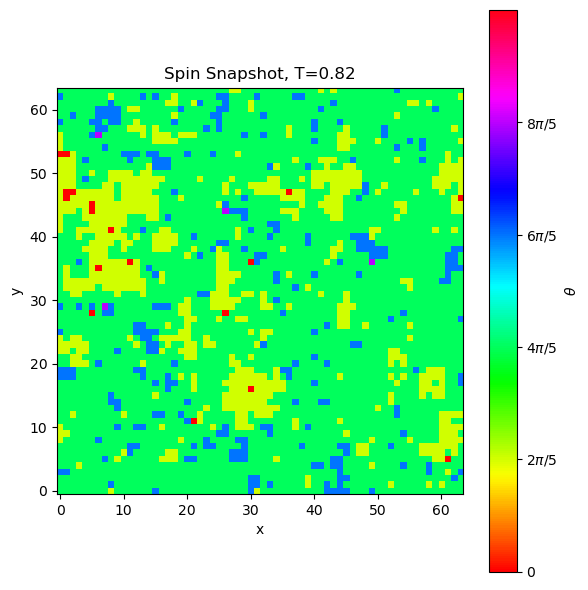

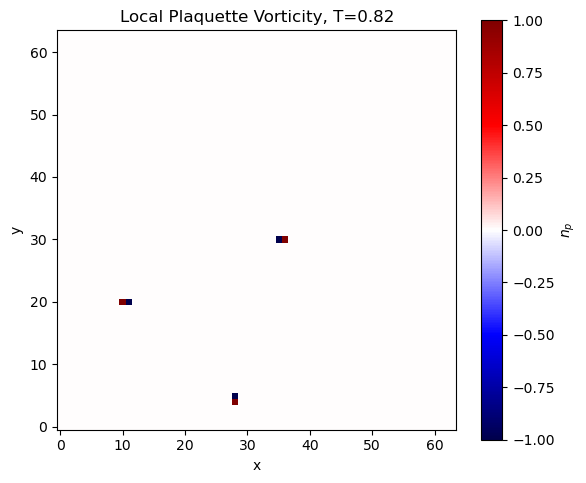

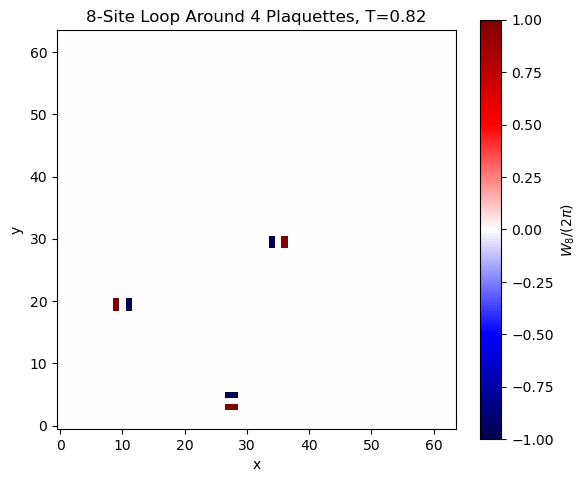

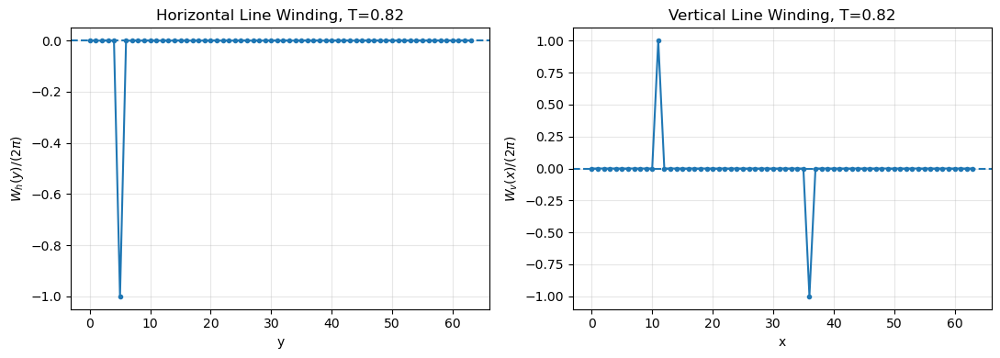

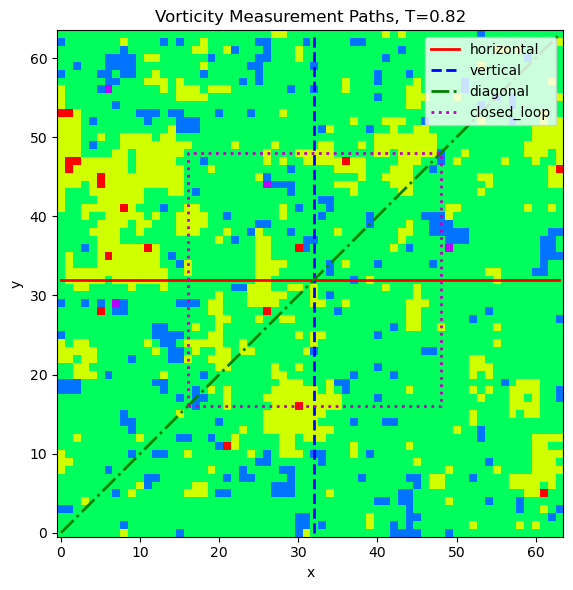

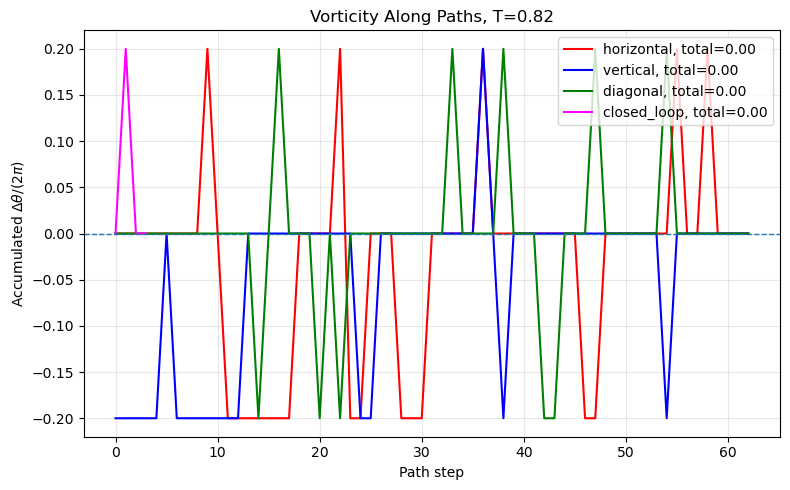



RUNNING TEMPERATURE T = 0.93
Thermalizing...
Thermalization complete.
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500
Calculating vorticity observables...


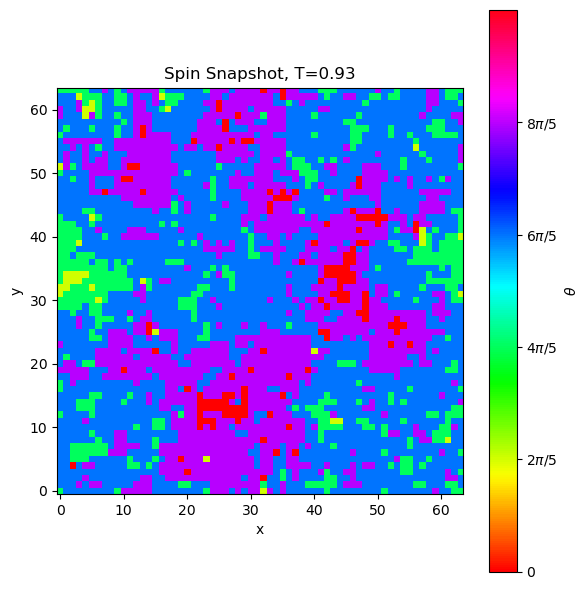

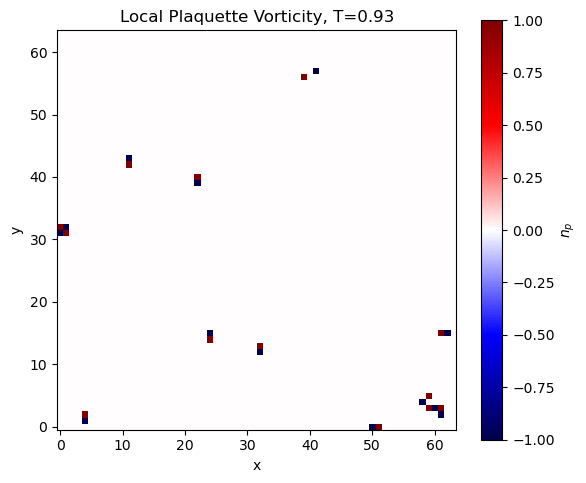

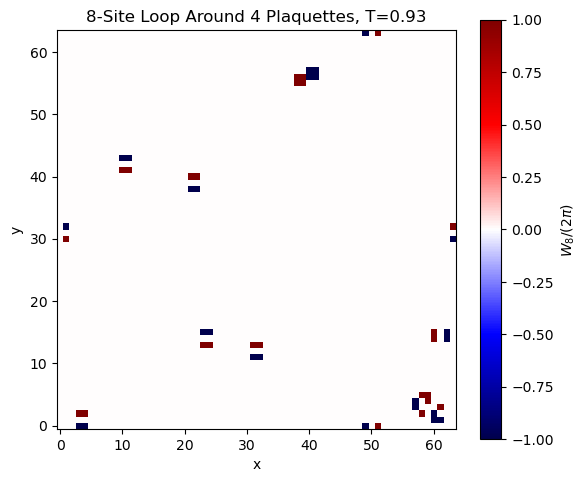

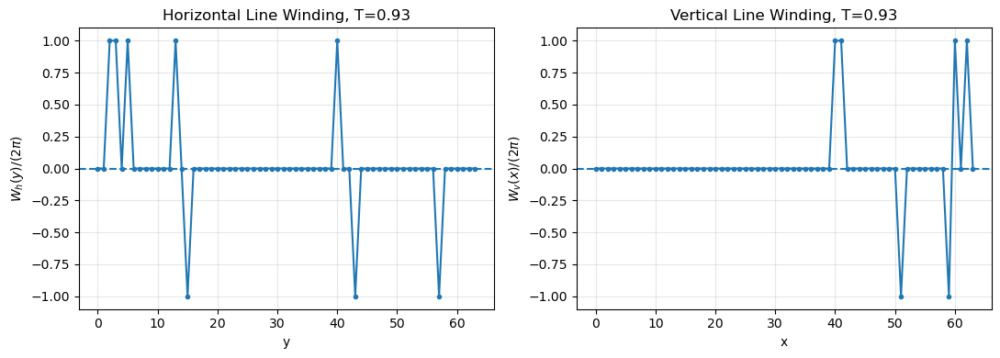

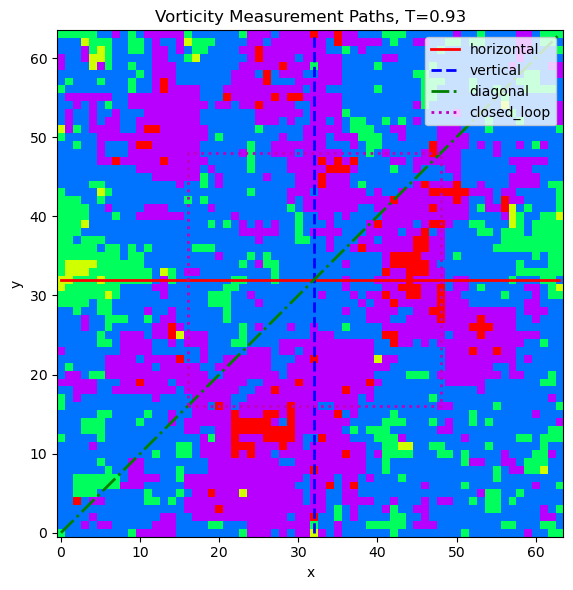

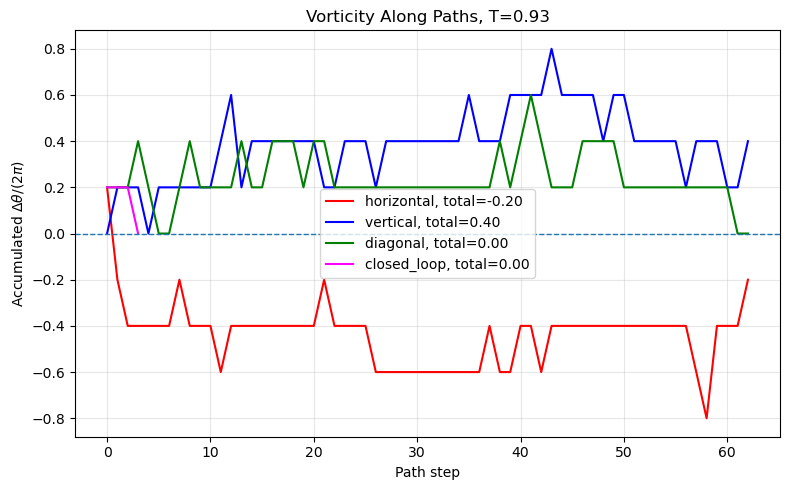



RUNNING TEMPERATURE T = 1.15
Thermalizing...
Thermalization complete.
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500
Calculating vorticity observables...


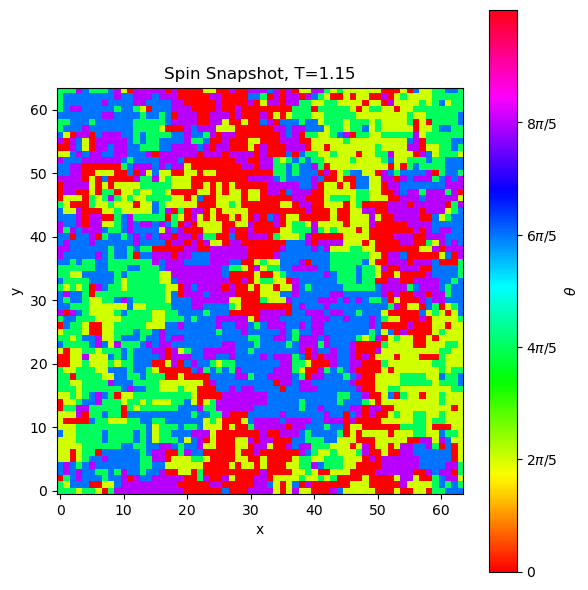

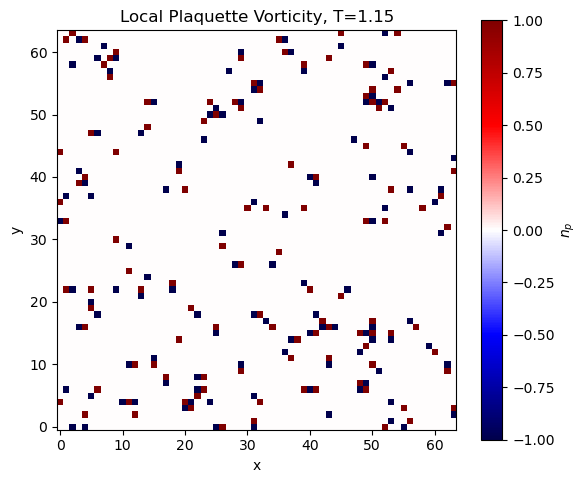

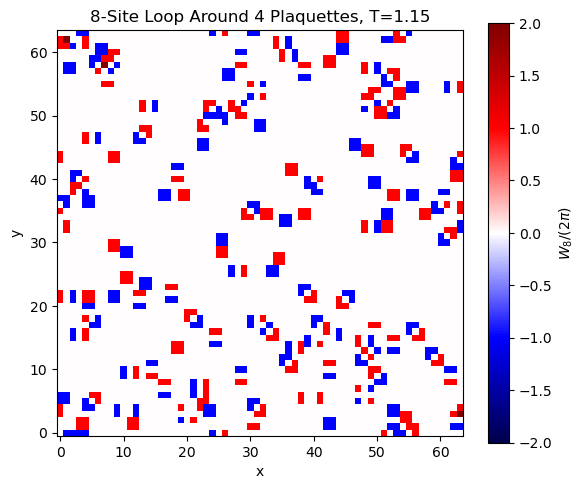

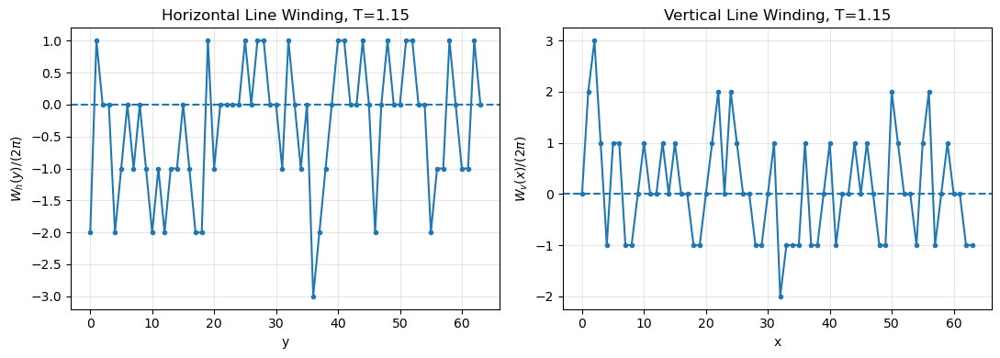

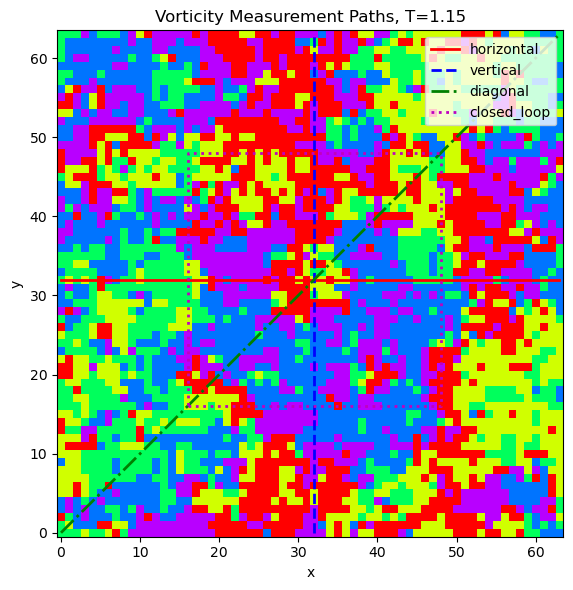

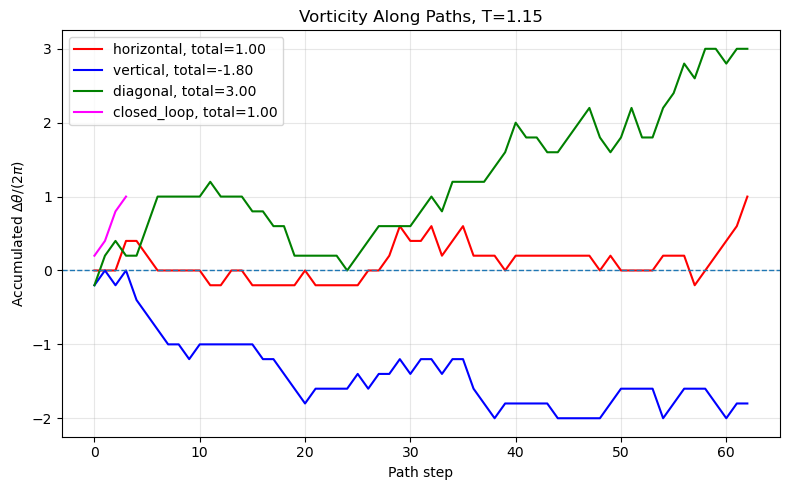



SIMULATION FINISHED
All data saved in:
clock_q5_L64_vorticity_results.npz


In [13]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 2D q-STATE CLOCK MODEL
#
# WOLFF CLUSTER ALGORITHM
#
# LOCAL VORTICITY
# 8-SITE LOOP AROUND 4 PLAQUETTES
# HORIZONTAL / VERTICAL NONLOCAL WINDING
# ARBITRARY PATH VORTICITY
#
# ============================================================


# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# lattice size
L = 64


# ============================================================
# TEMPERATURES
# ============================================================

# Below transition
T_low = 0.82

# Near transition / intermediate region
T_mid = 0.93

# Above transition
T_high = 1.15

temperatures = [
    T_low,
    T_mid,
    T_high
]

temperature_labels = [
    "below",
    "near",
    "above"
]


# ============================================================
# INITIAL CONDITION
#
# "random"  -> completely random configuration
# "ordered" -> all spins initially aligned
# "hot"     -> random configuration
# ============================================================

initial_state = "random"


# ============================================================
# MONTE CARLO PARAMETERS
# ============================================================

# thermalization
thermalization = 15000

# number of measurements
measurements = 500

# Wolff updates between measurements
skip_steps = 10

# ------------------------------------------------------------
# Which measurement should be used for the vortex snapshot?
#
# For example:
#
# snapshot_measurement = 250
#
# means take the spin/vorticity snapshot at measurement 250.
# ------------------------------------------------------------

snapshot_measurement = 250


# ============================================================
# PRECOMPUTED ANGLES
# ============================================================

ANGLES = 2*np.pi*np.arange(q)/q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)


# ============================================================
# PRECOMPUTE COS(theta_i - theta_j)
# ============================================================

COS_DIFF = np.zeros((q, q))

for i in range(q):

    for j in range(q):

        COS_DIFF[i, j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L, mode="random"):

    # --------------------------------------------------------
    # RANDOM / HOT STATE
    # --------------------------------------------------------

    if mode in ["random", "hot"]:

        return np.random.randint(
            0,
            q,
            size=(L, L)
        )

    # --------------------------------------------------------
    # ORDERED STATE
    # --------------------------------------------------------

    elif mode == "ordered":

        return np.zeros(
            (L, L),
            dtype=int
        )

    else:

        raise ValueError(
            "initial_state must be 'random', "
            "'ordered', or 'hot'"
        )


# ============================================================
# TOTAL ENERGY
#
# H = -J sum_<ij> cos(theta_i - theta_j)
#
# Periodic boundary conditions
#
# Each bond is counted once.
# ============================================================

def total_energy(spins):

    E = 0.0

    for x in range(L):

        for y in range(L):

            s = spins[x, y]

            # right neighbor
            sr = spins[
                (x + 1) % L,
                y
            ]

            # upper neighbor
            su = spins[
                x,
                (y + 1) % L
            ]

            E += -J * COS_DIFF[s, sr]

            E += -J * COS_DIFF[s, su]

    return E


# ============================================================
# MAGNETIZATION
#
# Mx = sum cos(theta)
# My = sum sin(theta)
#
# |M| = sqrt(Mx^2 + My^2)
# ============================================================

def magnetization(spins):

    Mx = np.sum(
        COS[spins]
    )

    My = np.sum(
        SIN[spins]
    )

    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    visited.fill(False)

    # --------------------------------------------------------
    # RANDOM REFLECTION AXIS
    # --------------------------------------------------------

    r = np.random.randint(
        0,
        q
    )

    # --------------------------------------------------------
    # RANDOM SEED
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [
        (x0, y0)
    ]

    visited[x0, y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0


    # ========================================================
    # GROW CLUSTER
    # ========================================================

    while stack:

        x, y = stack.pop()

        cluster.append(
            (x, y)
        )

        si = spins[x, y]

        # ----------------------------------------------------
        # REFLECTION
        #
        # theta -> 2*phi - theta
        #
        # in discrete state representation:
        #
        # s -> 2r - s (mod q)
        # ----------------------------------------------------

        si_ref = (
            2*r - si
        ) % q


        # ----------------------------------------------------
        # FOUR NEAREST NEIGHBORS
        # ----------------------------------------------------

        neighbors = (

            ((x + 1) % L, y),

            ((x - 1) % L, y),

            (x, (y + 1) % L),

            (x, (y - 1) % L)

        )


        for nx, ny in neighbors:

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                # ------------------------------------------------
                # ENERGY DIFFERENCE FOR REFLECTION
                # ------------------------------------------------

                delta = (

                    COS_DIFF[si, sj]
                    -
                    COS_DIFF[si_ref, sj]

                )


                # ------------------------------------------------
                # BOND ACTIVATION PROBABILITY
                # ------------------------------------------------

                if delta > 0:

                    p = 1 - np.exp(
                        -beta * J * delta
                    )

                    if np.random.rand() < p:

                        visited[nx, ny] = True

                        stack.append(
                            (nx, ny)
                        )


    # ========================================================
    # ENERGY CHANGE
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (
            2*r - si
        ) % q


        neighbors = (

            ((x + 1) % L, y),

            ((x - 1) % L, y),

            (x, (y + 1) % L),

            (x, (y - 1) % L)

        )


        for nx, ny in neighbors:

            # only boundary bonds
            if not visited[nx, ny]:

                sj = spins[nx, ny]

                dE += J * (

                    COS_DIFF[si, sj]
                    -
                    COS_DIFF[si_ref, sj]

                )


    # ========================================================
    # FLIP CLUSTER
    # ========================================================

    for x, y in cluster:

        si = spins[x, y]

        si_ref = (
            2*r - si
        ) % q


        dMx += (
            COS[si_ref]
            -
            COS[si]
        )

        dMy += (
            SIN[si_ref]
            -
            SIN[si]
        )


        spins[x, y] = si_ref


    return (
        E_current + dE,
        dMx,
        dMy
    )


# ============================================================
# GLOBAL ROTATION
#
# theta -> theta + constant
#
# This does not change relative angles or vorticity.
# ============================================================

def global_rotate(spins):

    r = np.random.randint(
        0,
        q
    )

    spins[:] = (
        spins + r
    ) % q

    return r


# ============================================================
# WRAPPED ANGULAR DIFFERENCE
#
# Returns:
#
# Delta theta in [-pi, pi)
#
# This is extremely important for vortex calculation.
#
# Example:
#
# theta1 = 0
# theta2 = 2*pi - small number
#
# ordinary subtraction gives approximately 2*pi
#
# but physically the difference is approximately -small.
# ============================================================

def wrapped_angle_difference(theta1, theta2):

    dtheta = theta2 - theta1

    dtheta = (
        dtheta + np.pi
    ) % (2*np.pi) - np.pi

    return dtheta


# ============================================================
# LOCAL PLAQUETTE VORTICITY
#
# For each plaquette:
#
#       3 -------- 2
#       |          |
#       |          |
#       0 -------- 1
#
# n_p = 1/(2*pi)
#       [Delta theta_01
#        + Delta theta_12
#        + Delta theta_23
#        + Delta theta_30]
#
# Periodic boundaries are used.
#
# Therefore result is L x L.
# ============================================================

def plaquette_vorticity(spins):

    theta = ANGLES[spins]

    vort = np.zeros(
        (L, L)
    )


    for x in range(L):

        for y in range(L):

            # ------------------------------------------------
            # Four corners
            # ------------------------------------------------

            t0 = theta[x, y]

            t1 = theta[
                (x + 1) % L,
                y
            ]

            t2 = theta[
                (x + 1) % L,
                (y + 1) % L
            ]

            t3 = theta[
                x,
                (y + 1) % L
            ]


            # ------------------------------------------------
            # Sum angular differences around plaquette
            # ------------------------------------------------

            winding = (

                wrapped_angle_difference(
                    t0, t1
                )

                +

                wrapped_angle_difference(
                    t1, t2
                )

                +

                wrapped_angle_difference(
                    t2, t3
                )

                +

                wrapped_angle_difference(
                    t3, t0
                )

            )


            # ------------------------------------------------
            # Divide by 2*pi
            #
            # approximately:
            #
            # +1 -> vortex
            # -1 -> antivortex
            #  0 -> no vortex
            # ------------------------------------------------

            vort[x, y] = (
                winding / (2*np.pi)
            )


    return vort


# ============================================================
# 8-SITE LOOP AROUND FOUR PLAQUETTES
#
# The loop encloses a 2 x 2 block of plaquettes:
#
#
#       0 ---- 1 ---- 2
#       |             |
#       7     4       3
#       |             |
#       6 ---- 5 ---- 4
#
#
# More precisely, the 8 unique sites are:
#
# (x,y)
# (x+1,y)
# (x+2,y)
# (x+2,y+1)
# (x+2,y+2)
# (x+1,y+2)
# (x,y+2)
# (x,y+1)
#
# The final bond closes the loop.
#
# This surrounds FOUR plaquettes.
#
# W8 = 1/(2*pi) sum Delta theta
#
# ============================================================

def eight_site_loop_vorticity(spins):

    theta = ANGLES[spins]

    W8 = np.zeros(
        (L, L)
    )


    for x in range(L):

        for y in range(L):

            # ------------------------------------------------
            # 8 sites surrounding a 2x2 plaquette block
            # ------------------------------------------------

            path = [

                (
                    x,
                    y
                ),

                (
                    (x + 1) % L,
                    y
                ),

                (
                    (x + 2) % L,
                    y
                ),

                (
                    (x + 2) % L,
                    (y + 1) % L
                ),

                (
                    (x + 2) % L,
                    (y + 2) % L
                ),

                (
                    (x + 1) % L,
                    (y + 2) % L
                ),

                (
                    x,
                    (y + 2) % L
                ),

                (
                    x,
                    (y + 1) % L
                )

            ]


            winding = 0.0


            # ------------------------------------------------
            # Calculate angular difference around the loop
            # ------------------------------------------------

            for i in range(8):

                x1, y1 = path[i]

                x2, y2 = path[
                    (i + 1) % 8
                ]


                winding += wrapped_angle_difference(

                    theta[x1, y1],

                    theta[x2, y2]

                )


            W8[x, y] = (
                winding / (2*np.pi)
            )


    return W8


# ============================================================
# HORIZONTAL LINE WINDING
#
# For each fixed y:
#
# W_h(y)
#
# = 1/(2*pi)
#   sum_x Delta theta(x,y)
#
# The final bond connects:
#
# x = L-1 -> x = 0
#
# so the line is a CLOSED periodic loop.
#
# ============================================================

def horizontal_line_winding(spins):

    theta = ANGLES[spins]

    W_horizontal = np.zeros(L)


    for y in range(L):

        total = 0.0


        for x in range(L):

            theta1 = theta[x, y]

            theta2 = theta[
                (x + 1) % L,
                y
            ]


            total += wrapped_angle_difference(
                theta1,
                theta2
            )


        W_horizontal[y] = (
            total / (2*np.pi)
        )


    return W_horizontal


# ============================================================
# VERTICAL LINE WINDING
#
# For each fixed x:
#
# W_v(x)
#
# = 1/(2*pi)
#   sum_y Delta theta(x,y)
#
# Periodic closure:
#
# y = L-1 -> y = 0
#
# ============================================================

def vertical_line_winding(spins):

    theta = ANGLES[spins]

    W_vertical = np.zeros(L)


    for x in range(L):

        total = 0.0


        for y in range(L):

            theta1 = theta[x, y]

            theta2 = theta[
                x,
                (y + 1) % L
            ]


            total += wrapped_angle_difference(
                theta1,
                theta2
            )


        W_vertical[x] = (
            total / (2*np.pi)
        )


    return W_vertical


# ============================================================
# GENERIC PATH VORTICITY
#
# path:
#
# [(x0,y0), (x1,y1), ...]
#
# If closed=False:
#
# returns cumulative angular winding along the path.
#
# If closed=True:
#
# adds the final bond back to the starting point.
#
# ============================================================

def path_vorticity(
    spins,
    path,
    closed=False
):

    theta = ANGLES[spins]

    increments = []

    cumulative = []

    total = 0.0


    # --------------------------------------------------------
    # Angular differences along path
    # --------------------------------------------------------

    for i in range(
        len(path) - 1
    ):

        x1, y1 = path[i]

        x2, y2 = path[i + 1]


        dtheta = wrapped_angle_difference(

            theta[x1 % L, y1 % L],

            theta[x2 % L, y2 % L]

        )


        increments.append(
            dtheta / (2*np.pi)
        )


        total += (
            dtheta / (2*np.pi)
        )


        cumulative.append(
            total
        )


    # --------------------------------------------------------
    # CLOSE PATH
    # --------------------------------------------------------

    if closed:

        x1, y1 = path[-1]

        x2, y2 = path[0]


        dtheta = wrapped_angle_difference(

            theta[x1 % L, y1 % L],

            theta[x2 % L, y2 % L]

        )


        increments.append(
            dtheta / (2*np.pi)
        )


        total += (
            dtheta / (2*np.pi)
        )


        cumulative.append(
            total
        )


    return (

        np.array(increments),

        np.array(cumulative),

        total

    )


# ============================================================
# CREATE EXAMPLE PATHS
# ============================================================

def create_paths():

    paths = {}


    # --------------------------------------------------------
    # PATH 1
    #
    # Horizontal line
    # --------------------------------------------------------

    y0 = L // 2

    paths["horizontal"] = [

        (x, y0)

        for x in range(L)

    ]


    # --------------------------------------------------------
    # PATH 2
    #
    # Vertical line
    # --------------------------------------------------------

    x0 = L // 2

    paths["vertical"] = [

        (x0, y)

        for y in range(L)

    ]


    # --------------------------------------------------------
    # PATH 3
    #
    # Diagonal
    # --------------------------------------------------------

    paths["diagonal"] = [

        (
            x,
            x
        )

        for x in range(L)

    ]


    # --------------------------------------------------------
    # PATH 4
    #
    # CLOSED RECTANGULAR LOOP
    # --------------------------------------------------------

    margin = L // 4

    x1 = margin
    x2 = L - margin

    y1 = margin
    y2 = L - margin


    paths["closed_loop"] = [

        (x1, y1),

        (x2, y1),

        (x2, y2),

        (x1, y2)

    ]


    return paths


# ============================================================
# SPIN SNAPSHOT
# ============================================================

def spin_snapshot(
    spins,
    title=""
):

    theta = ANGLES[spins]


    plt.figure(
        figsize=(6, 6)
    )


    plt.imshow(

        theta,

        cmap="hsv",

        origin="lower",

        interpolation="nearest",

        vmin=0,

        vmax=2*np.pi

    )


    cbar = plt.colorbar()

    cbar.set_label(
        r"$\theta$")
    cbar.set_ticks([
        0,
        2*np.pi/5,
        4*np.pi/5,
        6*np.pi/5,
        8*np.pi/5
    ])

    cbar.set_ticklabels([
        r"$0$",
        r"$2\pi/5$",
        r"$4\pi/5$",
        r"$6\pi/5$",
        r"$8\pi/5$"
    ])


    plt.xlabel("x")

    plt.ylabel("y")

    plt.title(title)

    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT LOCAL VORTICITY
# ============================================================

def plot_plaquette_vorticity(
    vort,
    T
):

    plt.figure(
        figsize=(6, 5)
    )


    vmax = max(
        1,
        np.max(np.abs(vort))
    )


    plt.imshow(

        vort.T,

        cmap="seismic",

        origin="lower",

        interpolation="nearest",

        vmin=-vmax,

        vmax=vmax

    )


    cbar = plt.colorbar()

    cbar.set_label(
        r"$n_p$")


    plt.xlabel("x")

    plt.ylabel("y")

    plt.title(
        f"Local Plaquette Vorticity, T={T}"
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT 8-SITE LOOP VORTICITY
# ============================================================

def plot_eight_site_vorticity(
    W8,
    T
):

    plt.figure(
        figsize=(6, 5)
    )


    vmax = max(
        1,
        np.max(np.abs(W8))
    )


    plt.imshow(

        W8.T,

        cmap="seismic",

        origin="lower",

        interpolation="nearest",

        vmin=-vmax,

        vmax=vmax

    )


    cbar = plt.colorbar()

    cbar.set_label(
        r"$W_8/(2\pi)$"
    )


    plt.xlabel("x")

    plt.ylabel("y")

    plt.title(
        f"8-Site Loop Around 4 Plaquettes, T={T}"
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT HORIZONTAL AND VERTICAL WINDING
# ============================================================

def plot_line_winding(
    Wh,
    Wv,
    T
):

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11, 4)
    )


    # --------------------------------------------------------
    # Horizontal
    # --------------------------------------------------------

    axes[0].plot(
        np.arange(L),
        Wh,
        "o-",
        markersize=3
    )

    axes[0].axhline(
        0,
        linestyle="--"
    )

    axes[0].set_xlabel("y")

    axes[0].set_ylabel(
        r"$W_h(y)/(2\pi)$"
    )

    axes[0].set_title(
        f"Horizontal Line Winding, T={T}"
    )

    axes[0].grid(
        alpha=0.3
    )


    # --------------------------------------------------------
    # Vertical
    # --------------------------------------------------------

    axes[1].plot(
        np.arange(L),
        Wv,
        "o-",
        markersize=3
    )

    axes[1].axhline(
        0,
        linestyle="--"
    )

    axes[1].set_xlabel("x")

    axes[1].set_ylabel(
        r"$W_v(x)/(2\pi)$"
    )

    axes[1].set_title(
        f"Vertical Line Winding, T={T}"
    )

    axes[1].grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT PATHS ON SPIN CONFIGURATION
# ============================================================

def plot_paths(
    spins,
    paths,
    T
):

    theta = ANGLES[spins]


    plt.figure(
        figsize=(7, 6)
    )


    plt.imshow(

        theta,

        cmap="hsv",

        origin="lower",

        interpolation="nearest",

        vmin=0,

        vmax=2*np.pi

    )


    styles = {

        "horizontal": "r-",

        "vertical": "b--",

        "diagonal": "g-.",

        "closed_loop": "m:"

    }


    for name, path in paths.items():

        px = [
            p[0]
            for p in path
        ]

        py = [
            p[1]
            for p in path
        ]


        # close rectangular loop visually
        if name == "closed_loop":

            px.append(
                px[0]
            )

            py.append(
                py[0]
            )


        plt.plot(

            px,

            py,

            styles[name],

            linewidth=2,

            label=name

        )


    plt.xlabel("x")

    plt.ylabel("y")

    plt.title(
        f"Vorticity Measurement Paths, T={T}"
    )


    plt.legend(
        loc="upper right"
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT VORTICITY ALONG PATHS
# ============================================================

def plot_path_vorticity(
    spins,
    paths,
    T
):

    plt.figure(
        figsize=(8, 5)
    )


    colors = {

        "horizontal": "red",

        "vertical": "blue",

        "diagonal": "green",

        "closed_loop": "magenta"

    }


    for name, path in paths.items():

        # ----------------------------------------------------
        # closed loop only for rectangular loop
        # ----------------------------------------------------

        closed = (
            name == "closed_loop"
        )


        increments, cumulative, total = path_vorticity(

            spins,

            path,

            closed=closed

        )


        plt.plot(

            np.arange(
                len(cumulative)
            ),

            cumulative,

            color=colors[name],

            linewidth=1.5,

            label=(
                f"{name}, "
                f"total={total:.2f}"
            )

        )


    plt.axhline(
        0,
        linestyle="--",
        linewidth=1
    )


    plt.xlabel(
        "Path step"
    )

    plt.ylabel(
        r"Accumulated $\Delta\theta/(2\pi)$"
    )


    plt.title(
        f"Vorticity Along Paths, T={T}"
    )


    plt.legend()

    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# MAIN SIMULATION
# ============================================================

# ------------------------------------------------------------
# Arrays for storing all temperatures
# ------------------------------------------------------------

nT = len(temperatures)


all_G = None
all_S = None

all_spins = np.zeros(
    (nT, L, L),
    dtype=np.int8
)

all_plaquette_vorticity = np.zeros(
    (nT, L, L)
)

all_W8 = np.zeros(
    (nT, L, L)
)

all_horizontal = np.zeros(
    (nT, L)
)

all_vertical = np.zeros(
    (nT, L)
)

all_energy = np.zeros(
    nT
)

all_magnetization = np.zeros(
    nT
)


# ============================================================
# CREATE PATHS
# ============================================================

paths = create_paths()


# ============================================================
# LOOP OVER TEMPERATURES
# ============================================================

for temp_index, T in enumerate(temperatures):


    print("\n")
    print("================================================")
    print(f"RUNNING TEMPERATURE T = {T}")
    print("================================================")


    beta = 1.0 / T


    # ========================================================
    # INITIALIZE
    # ========================================================

    spins = new_state(
        L,
        initial_state
    )


    visited = np.zeros(
        (L, L),
        dtype=bool
    )


    E = total_energy(
        spins
    )


    Mx, My = magnetization(
        spins
    )


    # ========================================================
    # THERMALIZATION
    # ========================================================

    print(
        "Thermalizing..."
    )


    for step in range(
        thermalization
    ):

        E, dMx, dMy = wolff_cluster(

            spins,

            beta,

            E,

            visited

        )


        Mx += dMx

        My += dMy


        # ----------------------------------------------------
        # global symmetry rotation
        # ----------------------------------------------------

        r = global_rotate(
            spins
        )


        c = COS[r]

        s = SIN[r]


        Mx, My = (

            Mx*c - My*s,

            Mx*s + My*c

        )


    print(
        "Thermalization complete."
    )


    # ========================================================
    # MEASUREMENT LOOP
    # ========================================================

    snapshot_spins = None


    for meas in range(
        measurements
    ):


        # ----------------------------------------------------
        # decorrelation
        # ----------------------------------------------------

        for _ in range(
            skip_steps
        ):

            E, dMx, dMy = wolff_cluster(

                spins,

                beta,

                E,

                visited

            )


            Mx += dMx

            My += dMy


        # ----------------------------------------------------
        # TAKE SNAPSHOT AT SPECIFIED MC TIME
        # ----------------------------------------------------

        if meas == snapshot_measurement:

            snapshot_spins = (
                spins.copy()
            )


        # ----------------------------------------------------
        # progress
        # ----------------------------------------------------

        if meas % 50 == 0:

            print(
                f"Measurement "
                f"{meas}/{measurements}"
            )


    # ========================================================
    # IF SNAPSHOT WAS NOT TAKEN
    # ========================================================

    if snapshot_spins is None:

        snapshot_spins = (
            spins.copy()
        )


    # ========================================================
    # CALCULATE OBSERVABLES
    #
    # These are calculated from the selected
    # Monte Carlo snapshot.
    # ========================================================

    print(
        "Calculating vorticity observables..."
    )


    # --------------------------------------------------------
    # Local plaquette vorticity
    # --------------------------------------------------------

    vort = plaquette_vorticity(
        snapshot_spins
    )


    # --------------------------------------------------------
    # 8-site loop around four plaquettes
    # --------------------------------------------------------

    W8 = eight_site_loop_vorticity(
        snapshot_spins
    )


    # --------------------------------------------------------
    # horizontal nonlocal winding
    # --------------------------------------------------------

    Wh = horizontal_line_winding(
        snapshot_spins
    )


    # --------------------------------------------------------
    # vertical nonlocal winding
    # --------------------------------------------------------

    Wv = vertical_line_winding(
        snapshot_spins
    )


    # --------------------------------------------------------
    # energy and magnetization
    # --------------------------------------------------------

    M = np.sqrt(
        Mx**2 + My**2
    )


    # ========================================================
    # STORE
    # ========================================================

    all_spins[
        temp_index
    ] = snapshot_spins


    all_plaquette_vorticity[
        temp_index
    ] = vort


    all_W8[
        temp_index
    ] = W8


    all_horizontal[
        temp_index
    ] = Wh


    all_vertical[
        temp_index
    ] = Wv


    all_energy[
        temp_index
    ] = E


    all_magnetization[
        temp_index
    ] = M


    # ========================================================
    # PLOTS
    # ========================================================

    # --------------------------------------------------------
    # 1. Spin configuration
    # --------------------------------------------------------

    spin_snapshot(

        snapshot_spins,

        title=(
            f"Spin Snapshot, "
            f"T={T}"
        )

    )


    # --------------------------------------------------------
    # 2. Local plaquette vorticity
    # --------------------------------------------------------

    plot_plaquette_vorticity(
        vort,
        T
    )


    # --------------------------------------------------------
    # 3. 8-site loop vorticity
    # --------------------------------------------------------

    plot_eight_site_vorticity(
        W8,
        T
    )


    # --------------------------------------------------------
    # 4. Horizontal / vertical nonlocal winding
    # --------------------------------------------------------

    plot_line_winding(
        Wh,
        Wv,
        T
    )


    # --------------------------------------------------------
    # 5. Show paths on lattice
    # --------------------------------------------------------

    plot_paths(

        snapshot_spins,

        paths,

        T

    )


    # --------------------------------------------------------
    # 6. Vorticity accumulated along paths
    # --------------------------------------------------------

    plot_path_vorticity(

        snapshot_spins,

        paths,

        T

    )


# ============================================================
# SAVE EVERYTHING INTO ONE NPZ FILE
# ============================================================

np.savez_compressed(

    f"clock_q{q}_L{L}_vorticity_results.npz",

    # parameters
    q=q,
    J=J,
    L=L,

    temperatures=np.array(
        temperatures
    ),

    thermalization=thermalization,

    measurements=measurements,

    skip_steps=skip_steps,

    snapshot_measurement=snapshot_measurement,

    initial_state=initial_state,

    # configurations
    spins=all_spins,

    # local observable
    plaquette_vorticity=
        all_plaquette_vorticity,

    # 8-site nonlocal loop
    W8=all_W8,

    # periodic line winding
    horizontal_winding=
        all_horizontal,

    vertical_winding=
        all_vertical,

    # basic observables
    energy=all_energy,

    magnetization=
        all_magnetization

)


print("\n")
print("================================================")
print("SIMULATION FINISHED")
print("================================================")

print(
    f"All data saved in:"
)

print(
    f"clock_q{q}_L{L}_vorticity_results.npz"
)


RUNNING T = 0.5
Thermalizing...
Thermalization done.
Measuring correlation function...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500


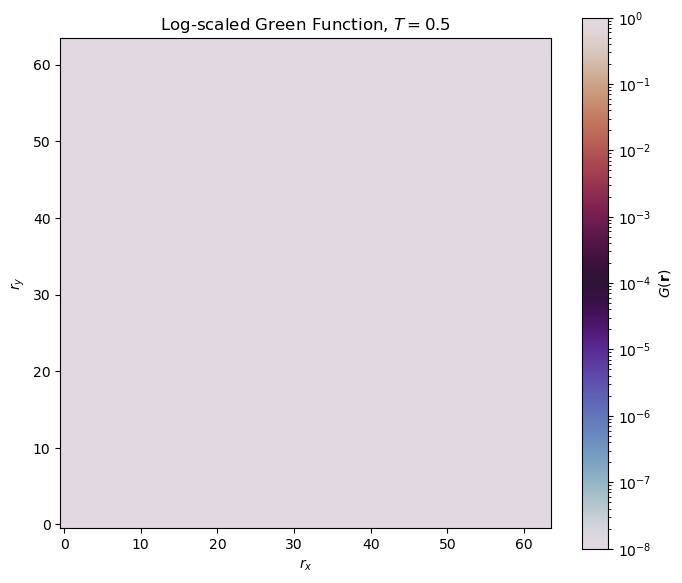

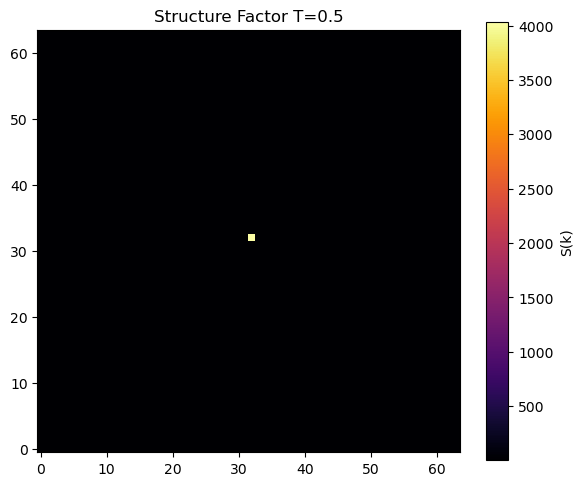

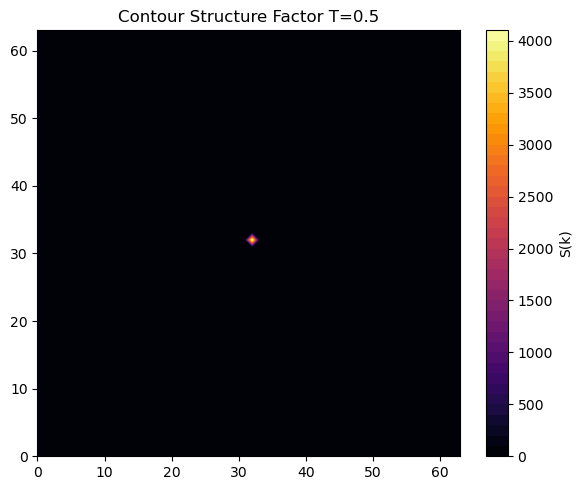

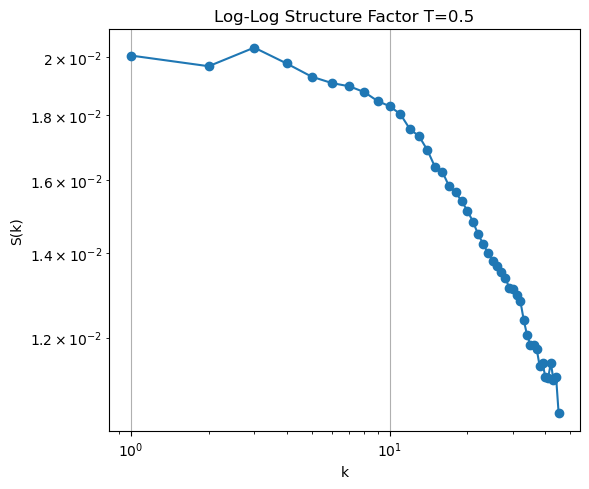

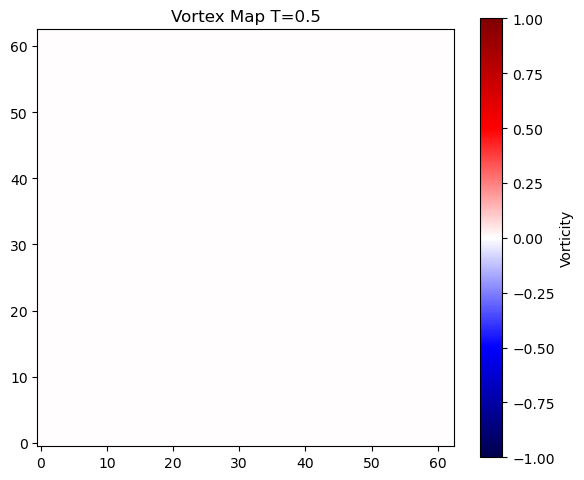

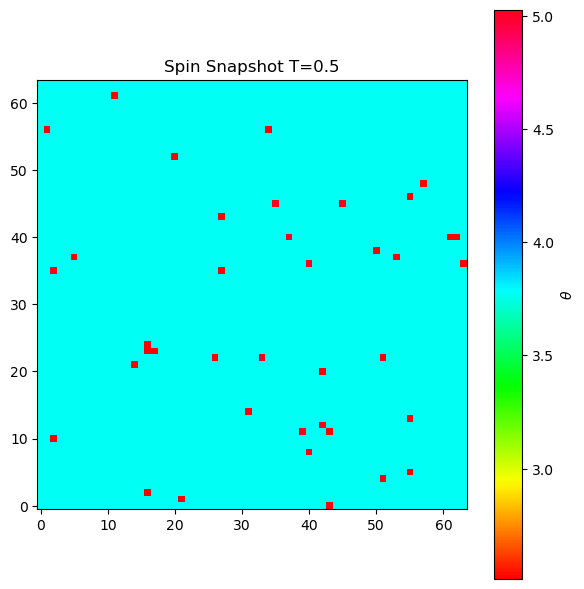

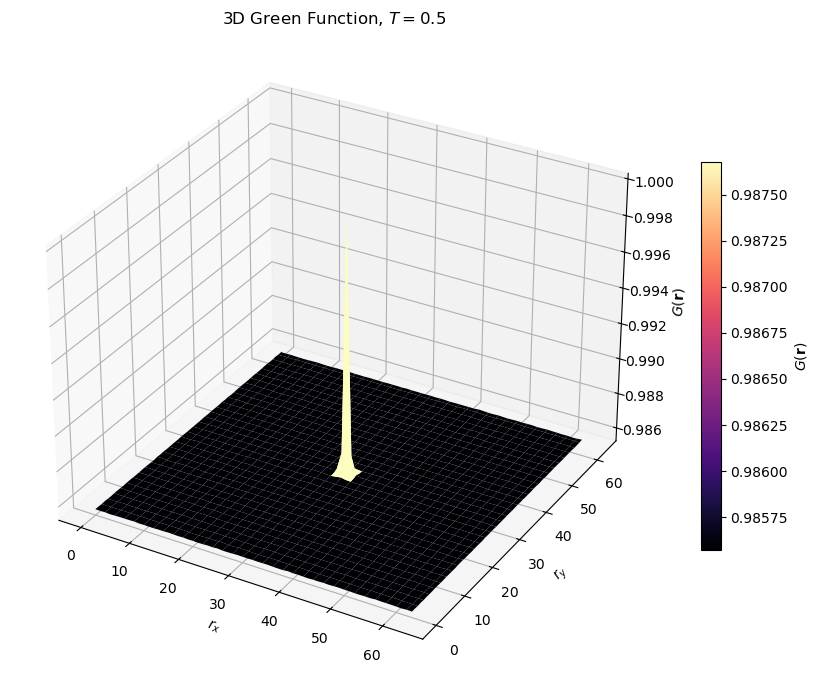


RUNNING T = 0.93
Thermalizing...


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from matplotlib.colors import LogNorm
# ============================================================
# 2D q=5 CLOCK MODEL
# PAPER-STYLE IMPLEMENTATION
#
# Wolff Cluster Algorithm
# Green's Function
# Structure Factor
# Radial Scaling
# Vortex-Antivortex Visualization
#
# This version follows the workflow:
#
# Monte Carlo
# -> Correlation Function G(r)
# -> Monte Carlo Average
# -> Fourier Transform
# -> Structure Factor S(k)
# -> Radial Average
# -> BKT Analysis
#
# ============================================================

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# lattice size
L = 64

# ------------------------------------------------------------
# TEMPERATURES
# ------------------------------------------------------------
# ordered phase
T_low = 0.5

# BKT-like phase
T_mid = 0.93

# disordered phase
T_high = 1.5

temperatures = [T_low, T_mid, T_high]

# labels for saving
temp_labels = {
    T_low: "low",
    T_mid: "mid",
    T_high: "high"
}

# ============================================================
# MONTE CARLO PARAMETERS
# ============================================================

# thermalization sweeps
thermalization = 15000

# number of measurements
measurements = 500

# Wolff updates between measurements
skip_steps = 10

# ============================================================
# PRECOMPUTED ANGLES
# ============================================================

ANGLES = 2*np.pi*np.arange(q)/q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# ============================================================
# PRECOMPUTE COS(theta_i-theta_j)
# ============================================================

COS_DIFF = np.zeros((q,q))

for i in range(q):
    for j in range(q):

        COS_DIFF[i,j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )

# ============================================================
# INITIAL RANDOM STATE
# ============================================================

def new_state(L):

    return np.random.randint(
        0,
        q,
        size=(L,L)
    )

# ============================================================
# TOTAL ENERGY
#
# H = -J Σ cos(theta_i-theta_j)
# ============================================================

def total_energy(spins):

    E = 0.0

    for x in range(L):
        for y in range(L):

            s = spins[x,y]

            sr = spins[(x+1)%L,y]
            su = spins[x,(y+1)%L]

            E += -J*COS_DIFF[s,sr]
            E += -J*COS_DIFF[s,su]

    return E

# ============================================================
# MAGNETIZATION
#
# M = Σ exp(i theta)
# ============================================================

def magnetization(spins):

    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])

    return Mx,My

# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    visited.fill(False)

    # --------------------------------------------------------
    # random reflection axis
    # --------------------------------------------------------

    r = np.random.randint(0,q)

    # --------------------------------------------------------
    # random seed site
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0,y0)]

    visited[x0,y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ========================================================
    # CLUSTER GROWTH
    # ========================================================

    while stack:

        x,y = stack.pop()

        cluster.append((x,y))

        si = spins[x,y]

        # reflection
        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L)

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                # energy difference
                delta = (

                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]

                )

                if delta > 0:

                    p = 1 - np.exp(
                        -beta*J*delta
                    )

                    if np.random.rand() < p:

                        visited[nx,ny] = True

                        stack.append((nx,ny))

    # ========================================================
    # ENERGY CORRECTION
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L)

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                dE += J*(

                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]

                )

    # ========================================================
    # FLIP CLUSTER
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x,y] = si_ref

    return E_current+dE,dMx,dMy

# ============================================================
# GLOBAL ROTATION
#
# improves ergodicity
# ============================================================

def global_rotate(spins):

    r = np.random.randint(0,q)

    spins[:] = (spins+r)%q

    return r

# ============================================================
# CORRELATION FUNCTION
#
# G(r)=<s(0)s(r)>
#
# computed using FFT
#
# Wiener-Khinchin theorem:
#
# G = FFT^-1(|FFT(s)|^2)
#
# ============================================================

def correlation_function(spins):

    theta = ANGLES[spins]

    # complex spin field
    field = np.exp(1j*theta)

    # Fourier transform
    Fk = np.fft.fft2(field)

    # power spectrum
    power = np.abs(Fk)**2

    # inverse transform
    G = np.fft.ifft2(power).real

    # normalization
    G /= (L*L) # Ensemble-averaged Green's function

    return G

# ============================================================
# STRUCTURE FACTOR
#
# S(k)=FFT(G(r))
# ============================================================

def structure_factor(G):

    S = np.abs(
        np.fft.fft2(G)
    )

    # center k=0
    S = np.fft.fftshift(S)

    return S

# ============================================================
# RADIAL AVERAGE
#
# S(kx,ky) -> S(k)
# ============================================================

def radial_average(S):

    n = S.shape[0]

    center = n//2

    y,x = np.indices((n,n))

    r = np.sqrt(

        (x-center)**2
        +
        (y-center)**2

    )

    r = r.astype(int)

    tbin = np.bincount(
        r.ravel(),
        S.ravel()
    )

    nr = np.bincount(r.ravel())

    radial = tbin/nr
    # Converts 2D structure factor to S(k)
    return np.arange(len(radial)),radial

# ============================================================
# ANGLE DIFFERENCE
#
# wrapped to [-pi,pi]
# ============================================================

def angle_diff(a,b):

    d = b-a

    while d > np.pi:
        d -= 2*np.pi

    while d <= -np.pi:
        d += 2*np.pi

    return d

# ============================================================
# VORTEX MAP
#
# plaquette winding number
# ============================================================

def vortex_map(spins):

    theta = ANGLES[spins]

    vort = np.zeros((L-1,L-1))

    for x in range(L-1):
        for y in range(L-1):

            t1 = theta[x,y]
            t2 = theta[x+1,y]
            t3 = theta[x+1,y+1]
            t4 = theta[x,y+1]

            winding = (

                angle_diff(t1,t2)
                +
                angle_diff(t2,t3)
                +
                angle_diff(t3,t4)
                +
                angle_diff(t4,t1)

            )

            vort[x,y] = winding/(2*np.pi)

    return vort

# ============================================================
# SPIN SNAPSHOT
# ============================================================

def spin_snapshot(spins,title=""):

    theta = ANGLES[spins]

    plt.figure(figsize=(6,6))

    plt.imshow(
        theta,
        cmap='hsv',
        origin='lower'
    )

    plt.colorbar(label=r'$\theta$')

    plt.title(title)

    plt.tight_layout()

    plt.show()

# ============================================================
# MAIN LOOP
# ============================================================

# ============================================================
# STORAGE ARRAYS
# ============================================================

all_T = []

all_G = []

all_S = []

all_vortex = []

all_spins = []

all_mag = []

all_energy = []

# ============================================================
# MAIN LOOP
# ============================================================

for T in temperatures:

    print("\n===================================")
    print(f"RUNNING T = {T}")
    print("===================================")

    beta = 1.0/T

    # --------------------------------------------------------
    # initialize state
    # --------------------------------------------------------

    spins = new_state(L)

    visited = np.zeros(
        (L,L),
        dtype=bool
    )

    E = total_energy(spins)

    Mx,My = magnetization(spins)

    # ========================================================
    # THERMALIZATION
    # ========================================================

    print("Thermalizing...")

    for step in range(thermalization):

        E,dMx,dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )

        Mx += dMx
        My += dMy

        # ergodicity rotation
        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]

        Mx,My = (

            Mx*c - My*s,
            Mx*s + My*c

        )

    print("Thermalization done.")

    # ========================================================
    # MONTE CARLO AVERAGE OF G(r)
    # ========================================================

    G_total = np.zeros((L,L))

    print("Measuring correlation function...")

    for meas in range(measurements):

        # decorrelation sweeps
        for _ in range(skip_steps):

            E,dMx,dMy = wolff_cluster(
                spins,
                beta,
                E,
                visited
            )

            Mx += dMx
            My += dMy

        # ----------------------------------------------------
        # Green's function
        # ----------------------------------------------------

        G = correlation_function(spins)

        G_total += G

        if meas % 50 == 0:

            print(
                f"Measurement {meas}/{measurements}"
            )

    # ========================================================
    # MONTE CARLO AVERAGE
    # ========================================================

    G_avg = G_total / measurements

    # ========================================================
    # STRUCTURE FACTOR
    # ========================================================

    S_avg = structure_factor(G_avg)

    # ========================================================
    # VORTEX MAP
    # ========================================================

    vort = vortex_map(spins)

    # ========================================================
    # STORE DATA
    # ========================================================

    all_T.append(T)

    all_G.append(G_avg)

    all_S.append(S_avg)

    all_vortex.append(vort)

    all_spins.append(spins.copy())

    all_mag.append(
        np.sqrt(Mx**2 + My**2)
    )

    all_energy.append(E)

    # ========================================================
    # GREEN FUNCTION HEATMAP
    # ========================================================

   # GREEN'S FUNCTION HEATMAP
# LOG-SCALED COLOR NORMALIZATION
# ============================================================

    G_plot = np.fft.fftshift(G_avg)



    G_positive = np.maximum(G_plot, 1e-8)

    plt.figure(figsize=(7,6))

    im = plt.imshow(
        G_positive,
        cmap='twilight',
        origin='lower',
        norm=LogNorm(
        vmin=1e-8,
        vmax=G_positive.max()
        )
    )

    cbar = plt.colorbar(im)
    cbar.set_label(r'$G(\mathbf{r})$')

    plt.xlabel(r'$r_x$')
    plt.ylabel(r'$r_y$')

    plt.title(
        rf'Log-scaled Green Function, $T={T}$'
    )

    plt.tight_layout()
    plt.show()

    # ========================================================
    # STRUCTURE FACTOR
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        S_avg,
        cmap='inferno',
        origin='lower'
    )

    plt.colorbar(label='S(k)')

    plt.title(
        f"Structure Factor T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # CONTOUR
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.contourf(
        S_avg,
        levels=40,
        cmap='inferno'
    )

    plt.colorbar(label='S(k)')

    plt.title(
        f"Contour Structure Factor T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # RADIAL AVERAGE
    # ========================================================

    r,Sr = radial_average(S_avg)

    mask = (
        (r > 0)
        &
        (Sr > 1e-12)
    )

    plt.figure(figsize=(6,5))

    plt.loglog(
        r[mask],
        Sr[mask],
        'o-'
    )

    plt.xlabel("k")

    plt.ylabel("S(k)")

    plt.title(
        f"Log-Log Structure Factor T={T}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.show()

    # ========================================================
    # VORTEX MAP
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        vort,
        cmap='seismic',
        origin='lower',
        vmin=-1,
        vmax=1
    )

    plt.colorbar(label='Vorticity')

    plt.title(
        f"Vortex Map T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # SPIN SNAPSHOT
    # ========================================================

    spin_snapshot(
        spins,
        title=f"Spin Snapshot T={T}"
    )
    G_plot = np.fft.fftshift(G_avg)

    x = np.arange(L)
    y = np.arange(L)

    X, Y = np.meshgrid(x, y)

    fig = plt.figure(figsize=(9,7))

    ax = fig.add_subplot(111, projection='3d')

    surf = ax.plot_surface(
        X,
        Y,
        G_plot,
        cmap='magma',
        linewidth=0,
        antialiased=True
    )

    ax.set_xlabel(r'$r_x$')
    ax.set_ylabel(r'$r_y$')
    ax.set_zlabel(r'$G(\mathbf{r})$')

    ax.set_title(
        rf'3D Green Function, $T={T}$'
    )

    fig.colorbar(
        surf,
        ax=ax,
        shrink=0.6,
        label=r'$G(\mathbf{r})$'
    )

    plt.tight_layout()
    plt.show()
    # ============================================================

# ============================================================
# SAVE EVERYTHING INTO ONE FILE
# ============================================================

np.savez(

    "clock_q5_all_temperatures.npz",

    temperatures=np.array(all_T),

    G=np.array(all_G),

    S=np.array(all_S),

    vortex=np.array(all_vortex),

    spins=np.array(all_spins),

    magnetization=np.array(all_mag),

    energy=np.array(all_energy)

)

print("\nSaved all data into:")
print("clock_q5_all_temperatures.npz")

print("\nALL SIMULATIONS FINISHED.")

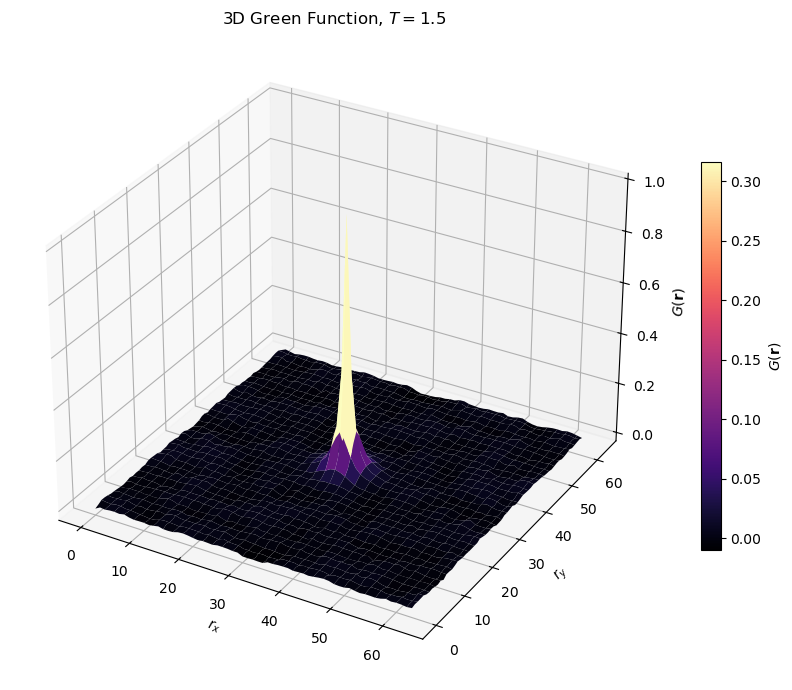

In [7]:
from mpl_toolkits.mplot3d import Axes3D

G_plot = np.fft.fftshift(G_avg)

x = np.arange(L)
y = np.arange(L)

X, Y = np.meshgrid(x, y)

fig = plt.figure(figsize=(9,7))

ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    X,
    Y,
    G_plot,
    cmap='magma',
    linewidth=0,
    antialiased=True
)

ax.set_xlabel(r'$r_x$')
ax.set_ylabel(r'$r_y$')
ax.set_zlabel(r'$G(\mathbf{r})$')

ax.set_title(
    rf'3D Green Function, $T={T}$'
)

fig.colorbar(
    surf,
    ax=ax,
    shrink=0.6,
    label=r'$G(\mathbf{r})$'
)

plt.tight_layout()
plt.show()


T = 0.820
Positive vortices: 0
Antivortices: 0
Zero-vorticity plaquettes: 3969
Unique values: [0.]


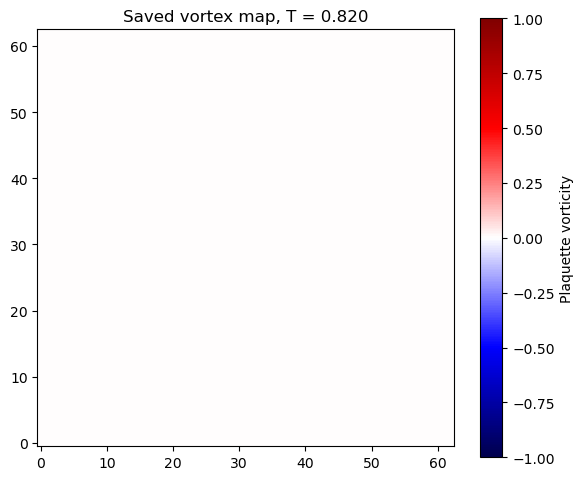


T = 0.930
Positive vortices: 14
Antivortices: 14
Zero-vorticity plaquettes: 3941
Unique values: [-1.  0.  1.]


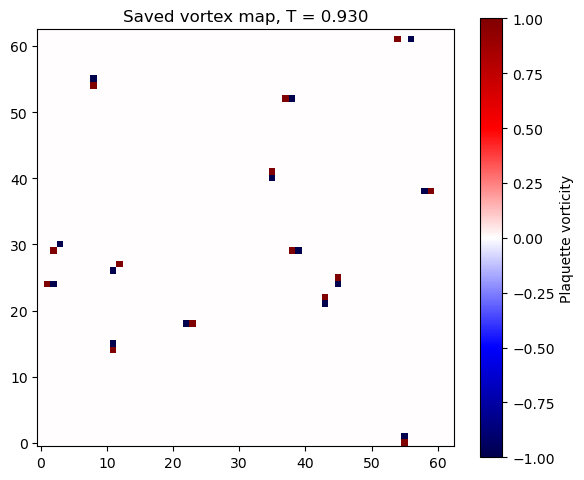


T = 1.150
Positive vortices: 111
Antivortices: 113
Zero-vorticity plaquettes: 3745
Unique values: [-1.  0.  1.]


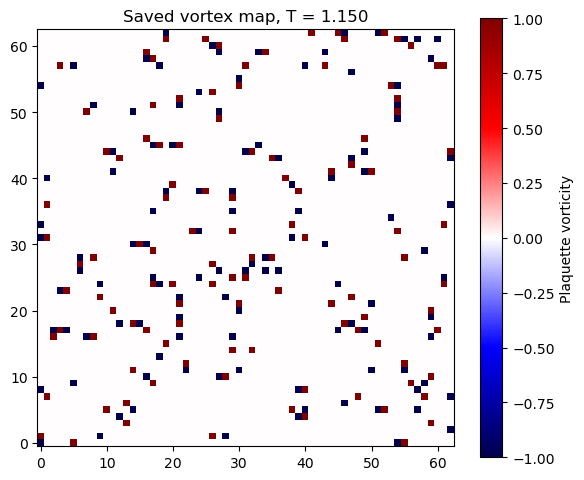

In [19]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("clock_q5_all_temperatures.npz")

temperatures = data["temperatures"]
vortices = data["vortex"]

for i, T in enumerate(temperatures):
    vort = vortices[i]

    n_positive = np.count_nonzero(vort > 0.5)
    n_negative = np.count_nonzero(vort < -0.5)
    n_zero = np.count_nonzero(np.abs(vort) < 0.5)

    print(f"\nT = {T:.3f}")
    print("Positive vortices:", n_positive)
    print("Antivortices:", n_negative)
    print("Zero-vorticity plaquettes:", n_zero)
    print("Unique values:", np.unique(np.round(vort, 4)))

    plt.figure(figsize=(6, 5))
    plt.imshow(
        vort,
        cmap="seismic",
        origin="lower",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )
    plt.colorbar(label="Plaquette vorticity")
    plt.title(f"Saved vortex map, T = {T:.3f}")
    plt.tight_layout()
    plt.show()


RUNNING T = 0.82
Thermalizing...
Thermalization done.
Measuring correlation function...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500


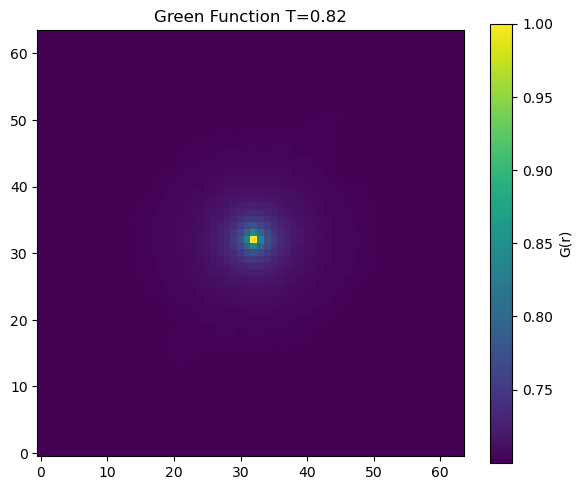

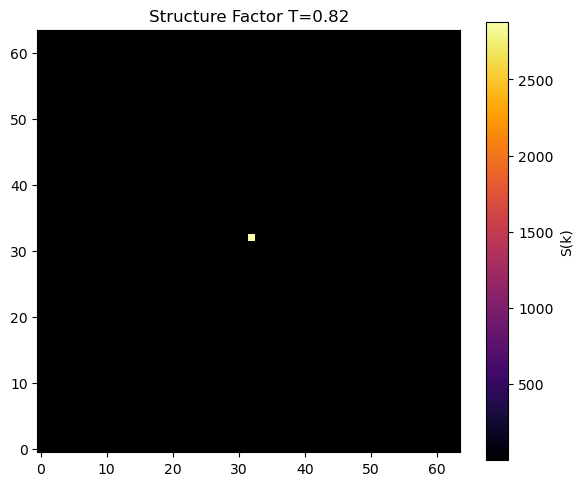

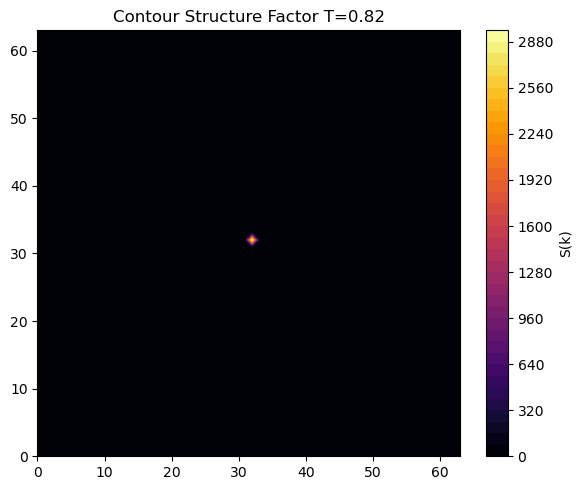

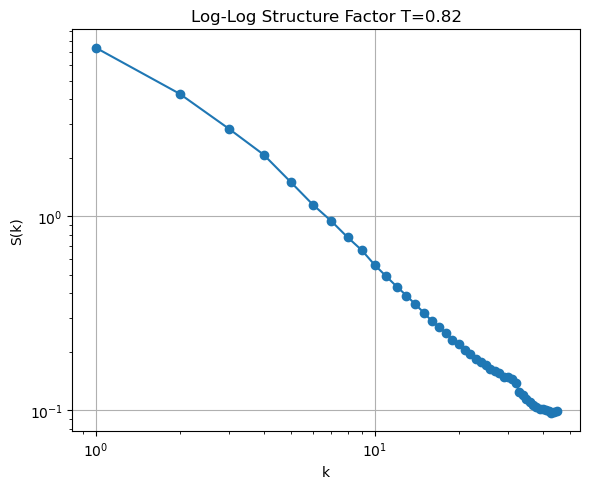

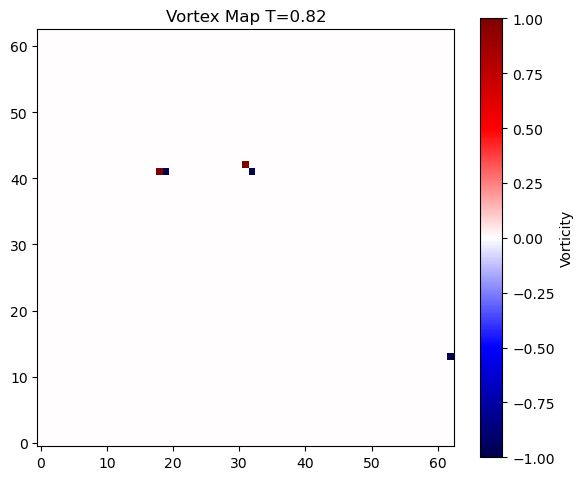

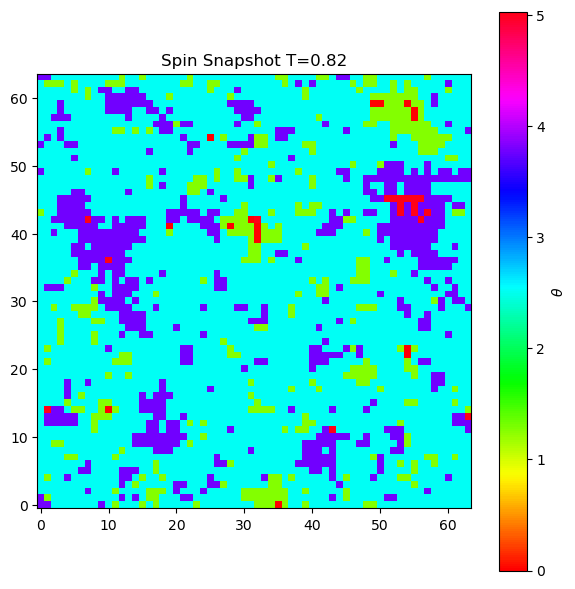


RUNNING T = 0.93
Thermalizing...
Thermalization done.
Measuring correlation function...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500


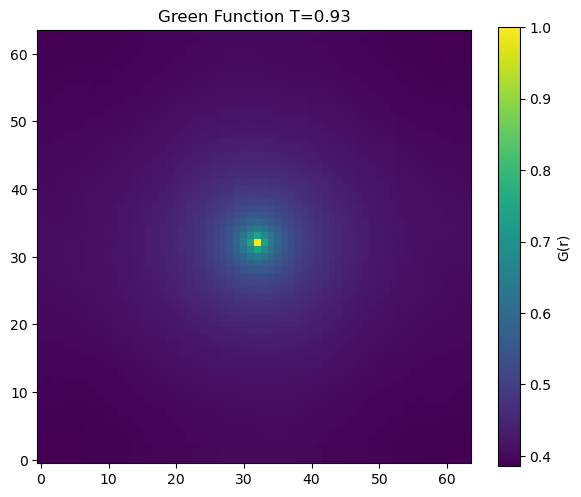

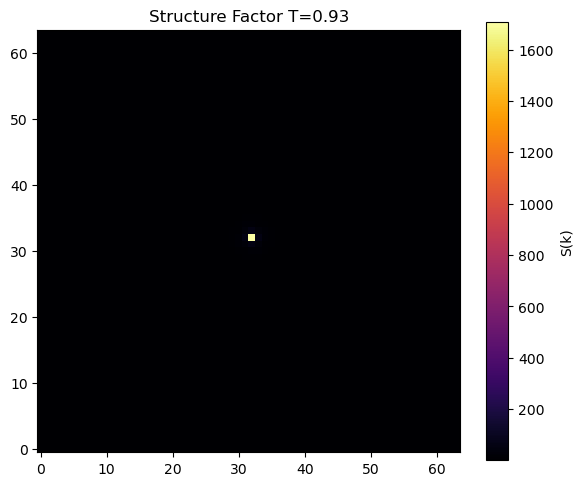

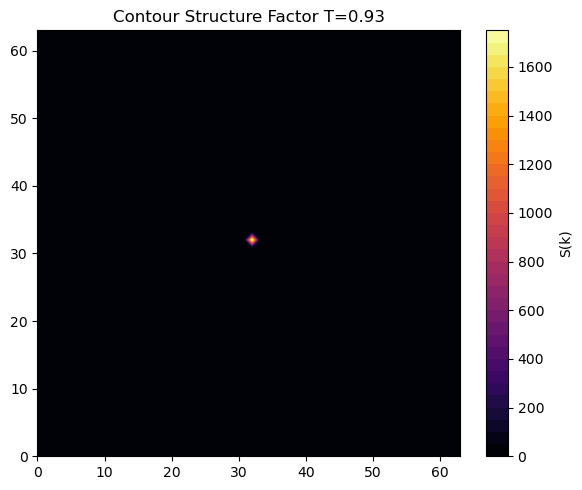

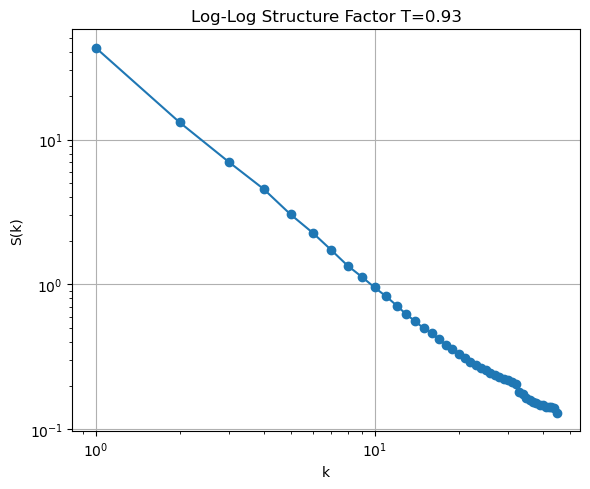

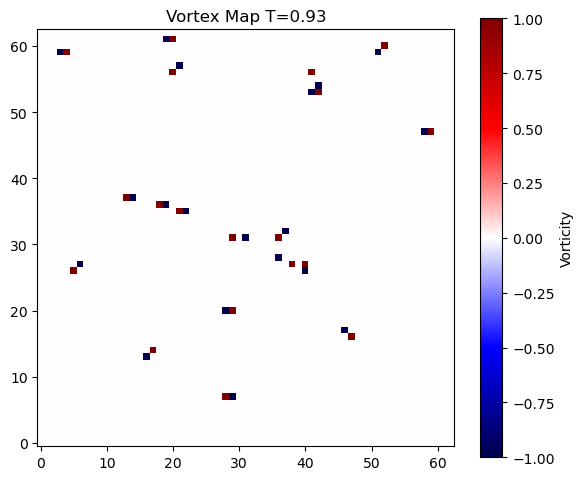

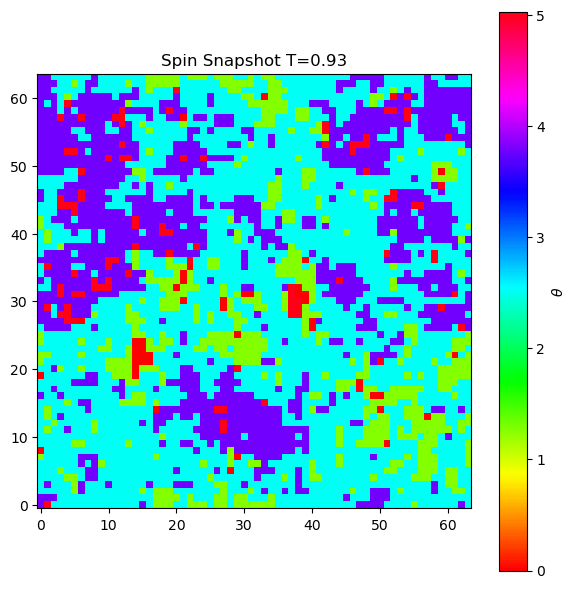


RUNNING T = 1.15
Thermalizing...
Thermalization done.
Measuring correlation function...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500


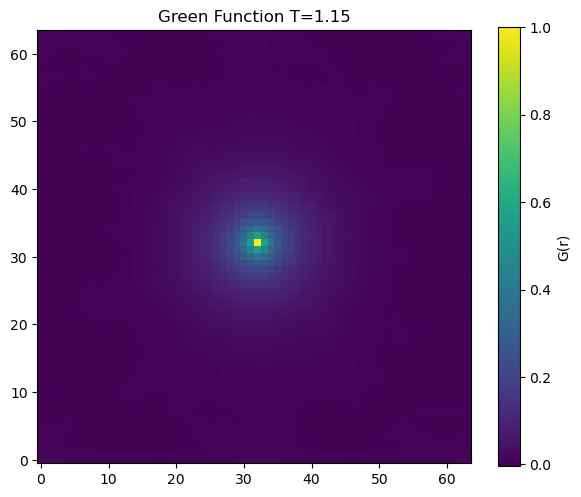

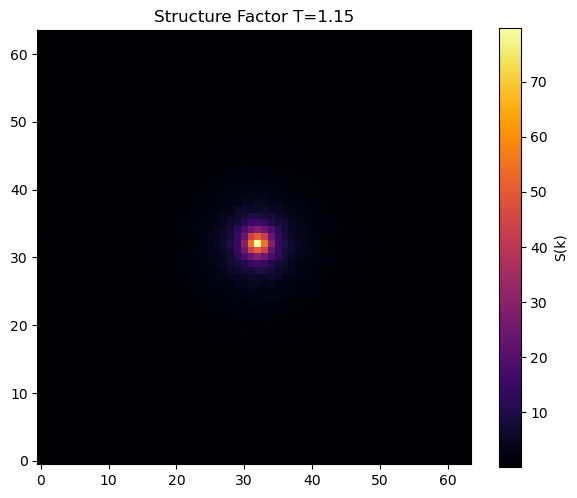

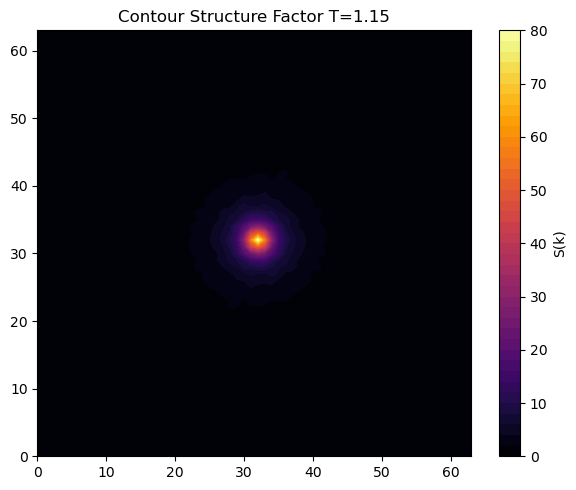

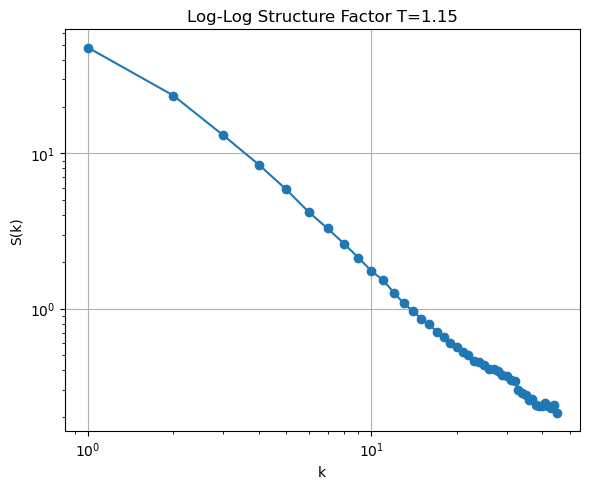

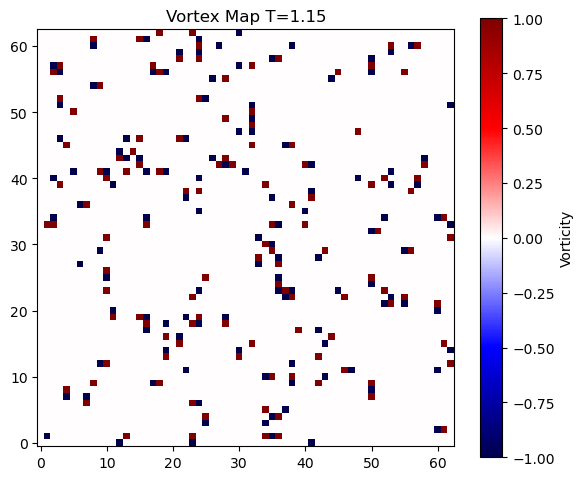

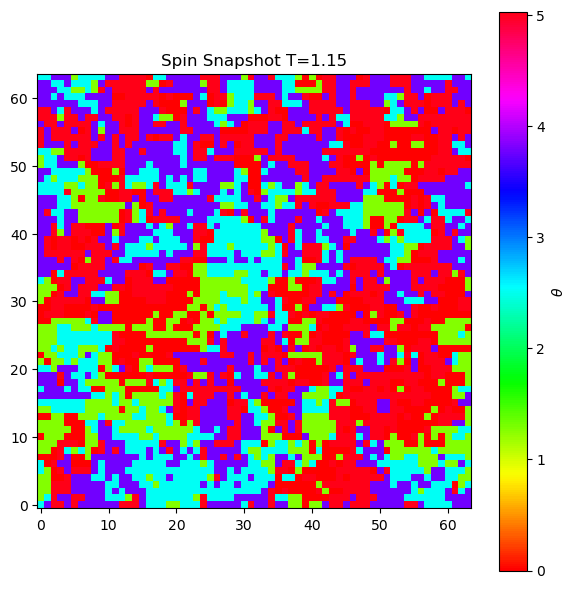


Saved all data into:
clock_q5_all_temperatures.npz

ALL SIMULATIONS FINISHED.


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
# ============================================================
# 2D q=5 CLOCK MODEL
# PAPER-STYLE IMPLEMENTATION
#
# Wolff Cluster Algorithm
# Green's Function
# Structure Factor
# Radial Scaling
# Vortex-Antivortex Visualization
#
# This version follows the workflow:
#
# Monte Carlo
# -> Correlation Function G(r)
# -> Monte Carlo Average
# -> Fourier Transform
# -> Structure Factor S(k)
# -> Radial Average
# -> BKT Analysis
#
# ============================================================

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# lattice size
L = 64

# ------------------------------------------------------------
# TEMPERATURES
# ------------------------------------------------------------
# ordered phase
T_low = 0.82

# BKT-like phase
T_mid = 0.93

# disordered phase
T_high = 1.15

temperatures = [T_low, T_mid, T_high]

# labels for saving
temp_labels = {
    T_low: "low",
    T_mid: "mid",
    T_high: "high"
}

# ============================================================
# MONTE CARLO PARAMETERS
# ============================================================

# thermalization sweeps
thermalization = 15000

# number of measurements
measurements = 500

# Wolff updates between measurements
skip_steps = 10

# ============================================================
# PRECOMPUTED ANGLES
# ============================================================

ANGLES = 2*np.pi*np.arange(q)/q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# ============================================================
# PRECOMPUTE COS(theta_i-theta_j)
# ============================================================

COS_DIFF = np.zeros((q,q))

for i in range(q):
    for j in range(q):

        COS_DIFF[i,j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )

# ============================================================
# INITIAL RANDOM STATE
# ============================================================

def new_state(L):

    return np.random.randint(
        0,
        q,
        size=(L,L)
    )

# ============================================================
# TOTAL ENERGY
#
# H = -J Σ cos(theta_i-theta_j)
# ============================================================

def total_energy(spins):

    E = 0.0

    for x in range(L):
        for y in range(L):

            s = spins[x,y]

            sr = spins[(x+1)%L,y]
            su = spins[x,(y+1)%L]

            E += -J*COS_DIFF[s,sr]
            E += -J*COS_DIFF[s,su]

    return E

# ============================================================
# MAGNETIZATION
#
# M = Σ exp(i theta)
# ============================================================

def magnetization(spins):

    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])

    return Mx,My

# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    visited.fill(False)

    # --------------------------------------------------------
    # random reflection axis
    # --------------------------------------------------------

    r = np.random.randint(0,q)

    # --------------------------------------------------------
    # random seed site
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0,y0)]

    visited[x0,y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ========================================================
    # CLUSTER GROWTH
    # ========================================================

    while stack:

        x,y = stack.pop()

        cluster.append((x,y))

        si = spins[x,y]

        # reflection
        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L)

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                # energy difference
                delta = (

                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]

                )

                if delta > 0:

                    p = 1 - np.exp(
                        -beta*J*delta
                    )

                    if np.random.rand() < p:

                        visited[nx,ny] = True

                        stack.append((nx,ny))

    # ========================================================
    # ENERGY CORRECTION
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L)

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                dE += J*(

                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]

                )

    # ========================================================
    # FLIP CLUSTER
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x,y] = si_ref

    return E_current+dE,dMx,dMy

# ============================================================
# GLOBAL ROTATION
#
# improves ergodicity
# ============================================================

def global_rotate(spins):

    r = np.random.randint(0,q)

    spins[:] = (spins+r)%q

    return r

# ============================================================
# CORRELATION FUNCTION
#
# G(r)=<s(0)s(r)>
#
# computed using FFT
#
# Wiener-Khinchin theorem:
#
# G = FFT^-1(|FFT(s)|^2)
#
# ============================================================

def correlation_function(spins):

    theta = ANGLES[spins]

    # complex spin field
    field = np.exp(1j*theta)

    # Fourier transform
    Fk = np.fft.fft2(field)

    # power spectrum
    power = np.abs(Fk)**2

    # inverse transform
    G = np.fft.ifft2(power).real

    # normalization
    G /= (L*L) # Ensemble-averaged Green's function

    return G

# ============================================================
# STRUCTURE FACTOR
#
# S(k)=FFT(G(r))
# ============================================================

def structure_factor(G):

    S = np.abs(
        np.fft.fft2(G)
    )

    # center k=0
    S = np.fft.fftshift(S)

    return S

# ============================================================
# RADIAL AVERAGE
#
# S(kx,ky) -> S(k)
# ============================================================

def radial_average(S):

    n = S.shape[0]

    center = n//2

    y,x = np.indices((n,n))

    r = np.sqrt(

        (x-center)**2
        +
        (y-center)**2

    )

    r = r.astype(int)

    tbin = np.bincount(
        r.ravel(),
        S.ravel()
    )

    nr = np.bincount(r.ravel())

    radial = tbin/nr
    # Converts 2D structure factor to S(k)
    return np.arange(len(radial)),radial

# ============================================================
# ANGLE DIFFERENCE
#
# wrapped to [-pi,pi]
# ============================================================

def angle_diff(a,b):

    d = b-a

    while d > np.pi:
        d -= 2*np.pi

    while d <= -np.pi:
        d += 2*np.pi

    return d

# ============================================================
# VORTEX MAP
#
# plaquette winding number
# ============================================================

def vortex_map(spins):

    theta = ANGLES[spins]

    vort = np.zeros((L-1,L-1))

    for x in range(L-1):
        for y in range(L-1):

            t1 = theta[x,y]
            t2 = theta[x+1,y]
            t3 = theta[x+1,y+1]
            t4 = theta[x,y+1]

            winding = (

                angle_diff(t1,t2)
                +
                angle_diff(t2,t3)
                +
                angle_diff(t3,t4)
                +
                angle_diff(t4,t1)

            )

            vort[x,y] = winding/(2*np.pi)

    return vort

# ============================================================
# SPIN SNAPSHOT
# ============================================================

def spin_snapshot(spins,title=""):

    theta = ANGLES[spins]

    plt.figure(figsize=(6,6))

    plt.imshow(
        theta,
        cmap='hsv',
        origin='lower'
    )

    plt.colorbar(label=r'$\theta$')

    plt.title(title)

    plt.tight_layout()

    plt.show()

# ============================================================
# MAIN LOOP
# ============================================================

# ============================================================
# STORAGE ARRAYS
# ============================================================

all_T = []

all_G = []

all_S = []

all_vortex = []

all_spins = []

all_mag = []

all_energy = []

# ============================================================
# MAIN LOOP
# ============================================================

for T in temperatures:

    print("\n===================================")
    print(f"RUNNING T = {T}")
    print("===================================")

    beta = 1.0/T

    # --------------------------------------------------------
    # initialize state
    # --------------------------------------------------------

    spins = new_state(L)

    visited = np.zeros(
        (L,L),
        dtype=bool
    )

    E = total_energy(spins)

    Mx,My = magnetization(spins)

    # ========================================================
    # THERMALIZATION
    # ========================================================

    print("Thermalizing...")

    for step in range(thermalization):

        E,dMx,dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )

        Mx += dMx
        My += dMy

        # ergodicity rotation
        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]

        Mx,My = (

            Mx*c - My*s,
            Mx*s + My*c

        )

    print("Thermalization done.")

    # ========================================================
    # MONTE CARLO AVERAGE OF G(r)
    # ========================================================

    G_total = np.zeros((L,L))

    print("Measuring correlation function...")

    for meas in range(measurements):

        # decorrelation sweeps
        for _ in range(skip_steps):

            E,dMx,dMy = wolff_cluster(
                spins,
                beta,
                E,
                visited
            )

            Mx += dMx
            My += dMy

        # ----------------------------------------------------
        # Green's function
        # ----------------------------------------------------

        G = correlation_function(spins)

        G_total += G

        if meas % 50 == 0:

            print(
                f"Measurement {meas}/{measurements}"
            )

    # ========================================================
    # MONTE CARLO AVERAGE
    # ========================================================

    G_avg = G_total / measurements

    # ========================================================
    # STRUCTURE FACTOR
    # ========================================================

    S_avg = structure_factor(G_avg)

    # ========================================================
    # VORTEX MAP
    # ========================================================

    vort = vortex_map(spins)

    # ========================================================
    # STORE DATA
    # ========================================================

    all_T.append(T)

    all_G.append(G_avg)

    all_S.append(S_avg)

    all_vortex.append(vort)

    all_spins.append(spins.copy())

    all_mag.append(
        np.sqrt(Mx**2 + My**2)
    )

    all_energy.append(E)

    # ========================================================
    # GREEN FUNCTION HEATMAP
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        np.fft.fftshift(G_avg),
        cmap='viridis',
        origin='lower'
    )

    plt.colorbar(label='G(r)')

    plt.title(
        f"Green Function T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # STRUCTURE FACTOR
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        S_avg,
        cmap='inferno',
        origin='lower'
    )

    plt.colorbar(label='S(k)')

    plt.title(
        f"Structure Factor T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # CONTOUR
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.contourf(
        S_avg,
        levels=40,
        cmap='inferno'
    )

    plt.colorbar(label='S(k)')

    plt.title(
        f"Contour Structure Factor T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # RADIAL AVERAGE
    # ========================================================

    r,Sr = radial_average(S_avg)

    mask = (
        (r > 0)
        &
        (Sr > 1e-12)
    )

    plt.figure(figsize=(6,5))

    plt.loglog(
        r[mask],
        Sr[mask],
        'o-'
    )

    plt.xlabel("k")

    plt.ylabel("S(k)")

    plt.title(
        f"Log-Log Structure Factor T={T}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.show()

    # ========================================================
    # VORTEX MAP
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        vort,
        cmap='seismic',
        origin='lower',
        vmin=-1,
        vmax=1
    )

    plt.colorbar(label='Vorticity')

    plt.title(
        f"Vortex Map T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # SPIN SNAPSHOT
    # ========================================================

    spin_snapshot(
        spins,
        title=f"Spin Snapshot T={T}"
    )

# ============================================================
# SAVE EVERYTHING INTO ONE FILE
# ============================================================

np.savez(

    "clock_q5_all_temperatures.npz",

    temperatures=np.array(all_T),

    G=np.array(all_G),

    S=np.array(all_S),

    vortex=np.array(all_vortex),

    spins=np.array(all_spins),

    magnetization=np.array(all_mag),

    energy=np.array(all_energy)

)

print("\nSaved all data into:")
print("clock_q5_all_temperatures.npz")

print("\nALL SIMULATIONS FINISHED.")


RUNNING T = 0.82
Thermalizing...
Thermalization done.
Measuring correlation function...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500
Saved: clock_q5_L64_low.npz


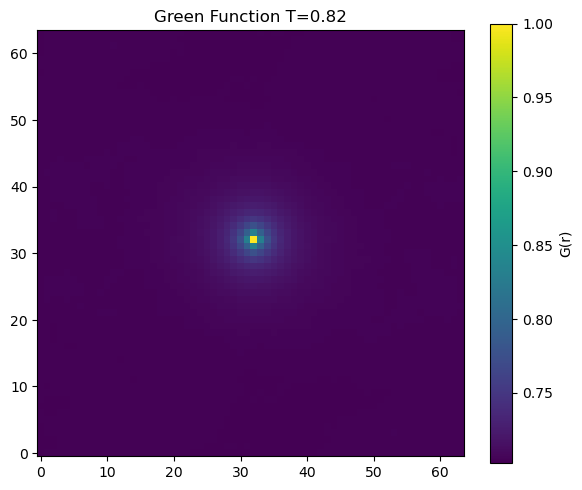

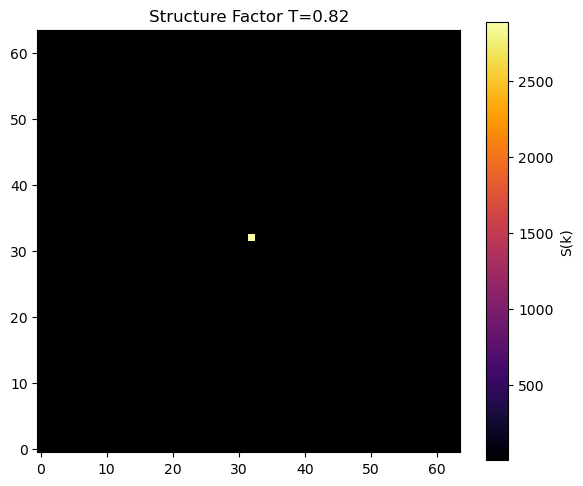

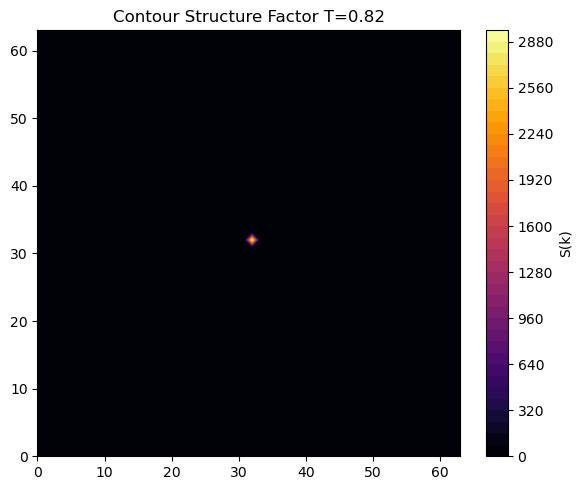

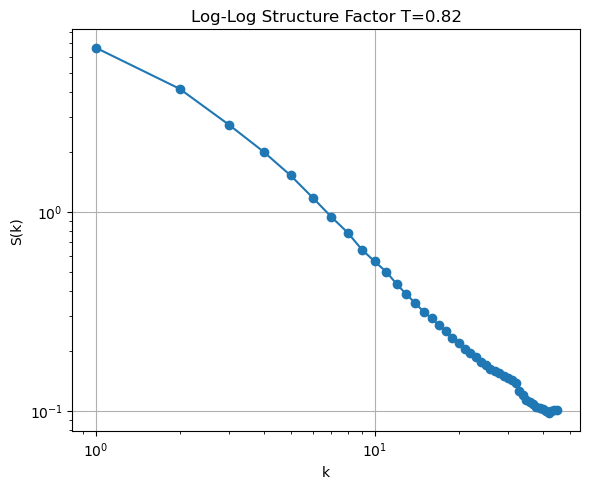

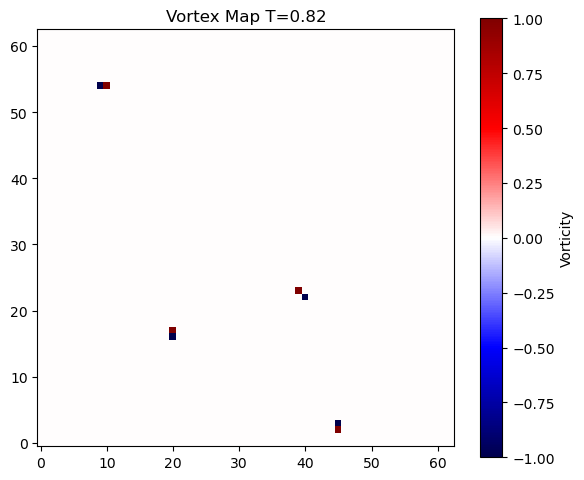

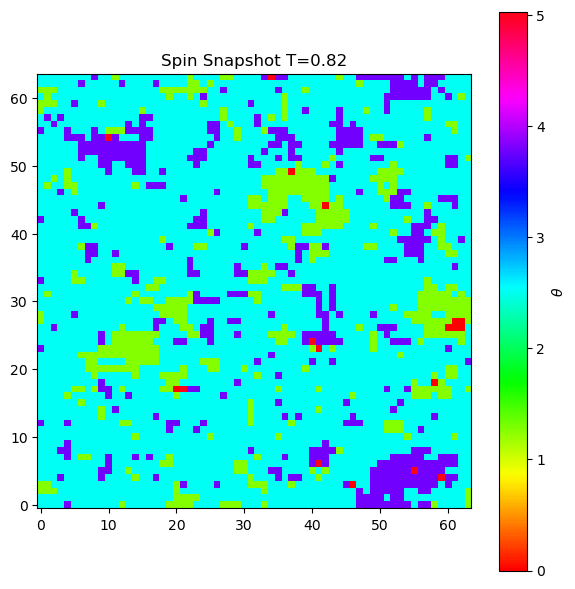


RUNNING T = 0.93
Thermalizing...
Thermalization done.
Measuring correlation function...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500
Saved: clock_q5_L64_mid.npz


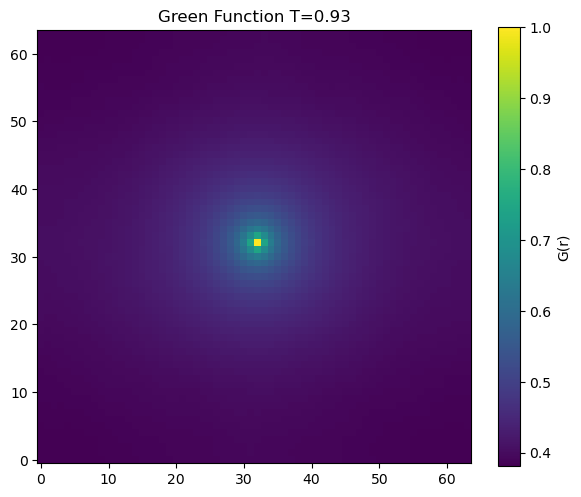

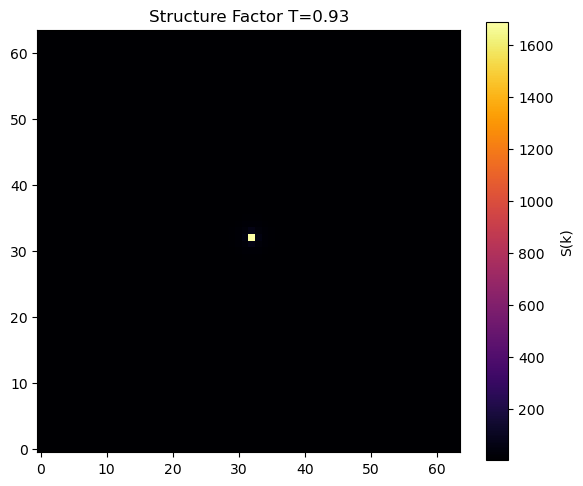

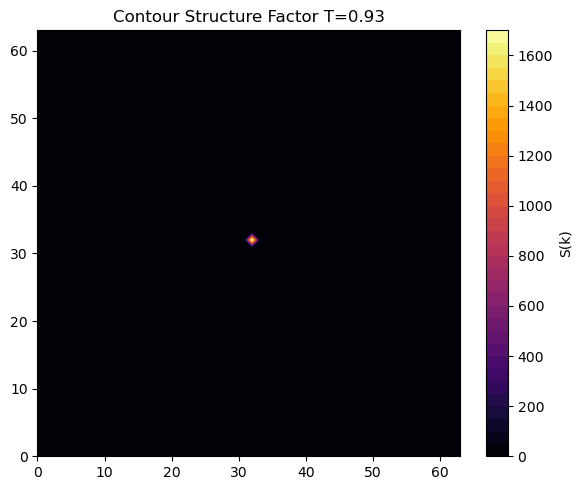

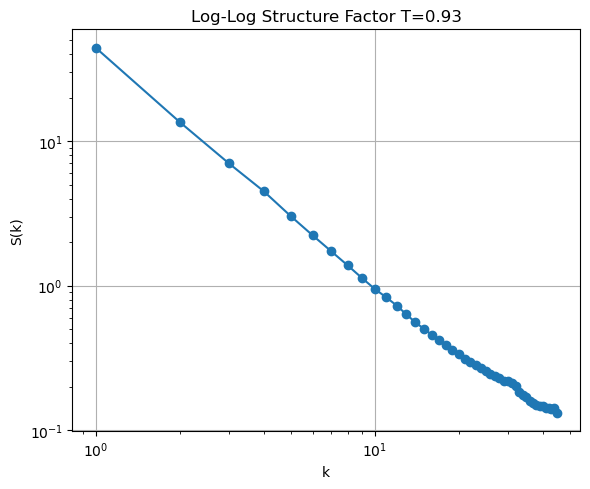

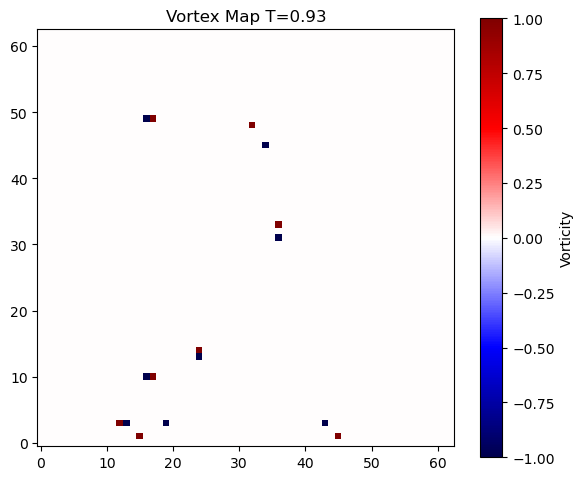

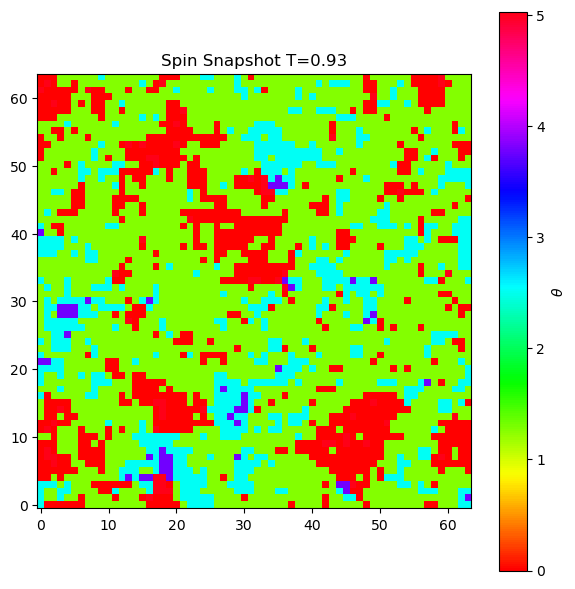


RUNNING T = 1.15
Thermalizing...
Thermalization done.
Measuring correlation function...
Measurement 0/500
Measurement 50/500
Measurement 100/500
Measurement 150/500
Measurement 200/500
Measurement 250/500
Measurement 300/500
Measurement 350/500
Measurement 400/500
Measurement 450/500
Saved: clock_q5_L64_high.npz


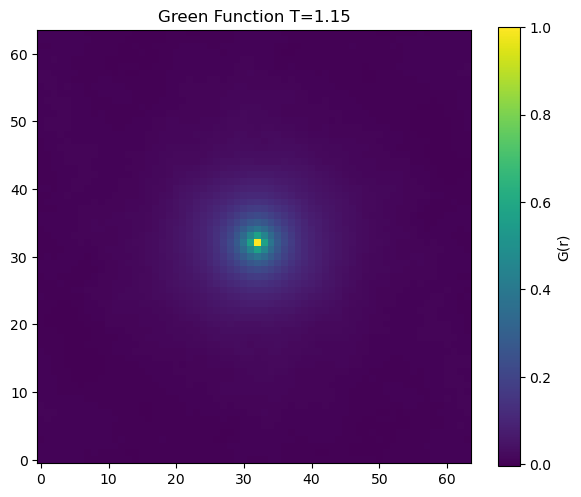

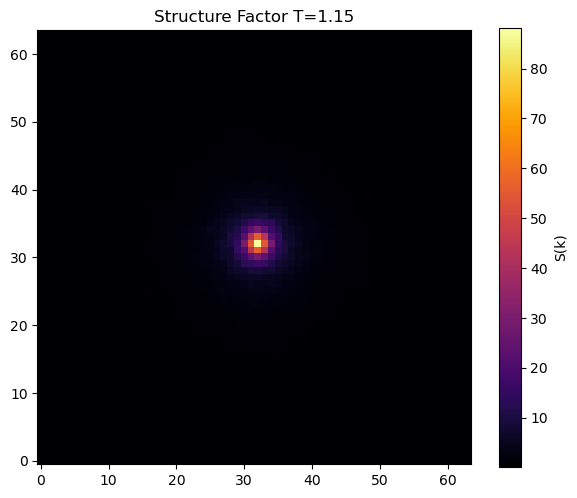

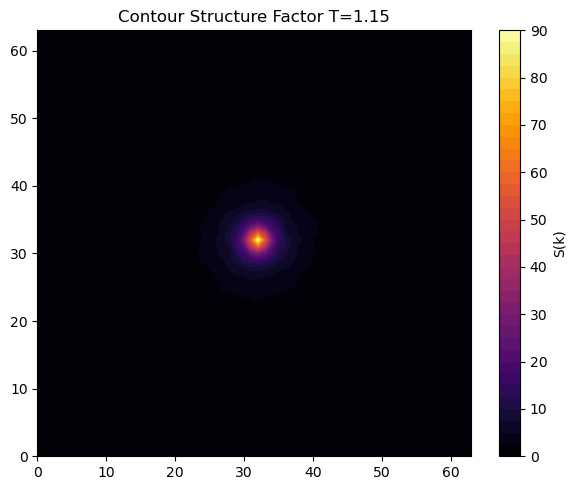

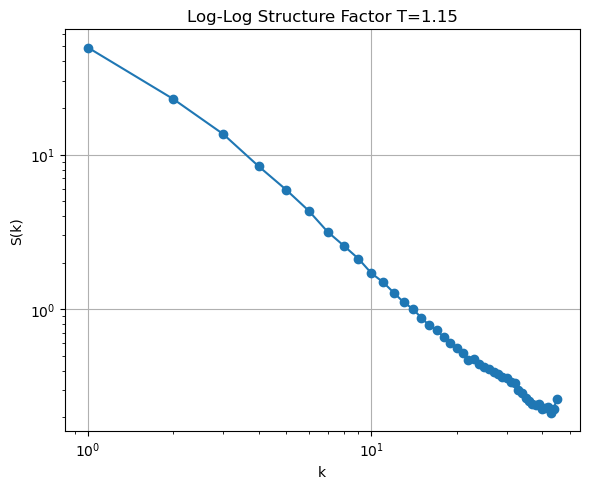

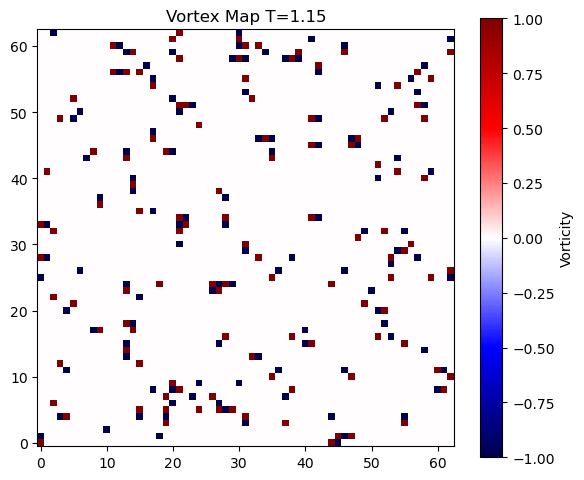

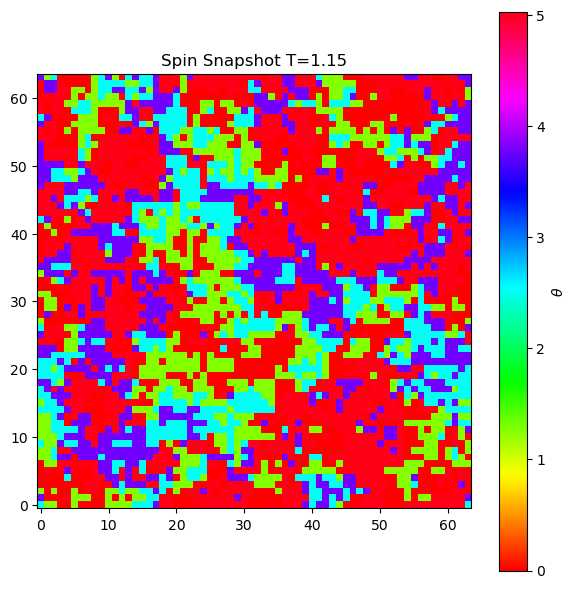


ALL SIMULATIONS FINISHED.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 2D q=5 CLOCK MODEL
# PAPER-STYLE IMPLEMENTATION
#
# Wolff Cluster Algorithm
# Green's Function
# Structure Factor
# Radial Scaling
# Vortex-Antivortex Visualization
#
# This version follows the workflow:
#
# Monte Carlo
# -> Correlation Function G(r)
# -> Monte Carlo Average
# -> Fourier Transform
# -> Structure Factor S(k)
# -> Radial Average
# -> BKT Analysis
#
# ============================================================

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# lattice size
L = 64

# ------------------------------------------------------------
# TEMPERATURES
# ------------------------------------------------------------
# ordered phase
T_low = 0.82

# BKT-like phase
T_mid = 0.93

# disordered phase
T_high = 1.15

temperatures = [T_low, T_mid, T_high]

# labels for saving
temp_labels = {
    T_low: "low",
    T_mid: "mid",
    T_high: "high"
}

# ============================================================
# MONTE CARLO PARAMETERS
# ============================================================

# thermalization sweeps
thermalization = 15000

# number of measurements
measurements = 500

# Wolff updates between measurements
skip_steps = 10

# ============================================================
# PRECOMPUTED ANGLES
# ============================================================

ANGLES = 2*np.pi*np.arange(q)/q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# ============================================================
# PRECOMPUTE COS(theta_i-theta_j)
# ============================================================

COS_DIFF = np.zeros((q,q))

for i in range(q):
    for j in range(q):

        COS_DIFF[i,j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )

# ============================================================
# INITIAL RANDOM STATE
# ============================================================

def new_state(L):

    return np.random.randint(
        0,
        q,
        size=(L,L)
    )

# ============================================================
# TOTAL ENERGY
#
# H = -J Σ cos(theta_i-theta_j)
# ============================================================

def total_energy(spins):

    E = 0.0

    for x in range(L):
        for y in range(L):

            s = spins[x,y]

            sr = spins[(x+1)%L,y]
            su = spins[x,(y+1)%L]

            E += -J*COS_DIFF[s,sr]
            E += -J*COS_DIFF[s,su]

    return E

# ============================================================
# MAGNETIZATION
#
# M = Σ exp(i theta)
# ============================================================

def magnetization(spins):

    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])

    return Mx,My

# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    visited.fill(False)

    # --------------------------------------------------------
    # random reflection axis
    # --------------------------------------------------------

    r = np.random.randint(0,q)

    # --------------------------------------------------------
    # random seed site
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0,y0)]

    visited[x0,y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ========================================================
    # CLUSTER GROWTH
    # ========================================================

    while stack:

        x,y = stack.pop()

        cluster.append((x,y))

        si = spins[x,y]

        # reflection
        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L)

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                # energy difference
                delta = (

                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]

                )

                if delta > 0:

                    p = 1 - np.exp(
                        -beta*J*delta
                    )

                    if np.random.rand() < p:

                        visited[nx,ny] = True

                        stack.append((nx,ny))

    # ========================================================
    # ENERGY CORRECTION
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L)

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                dE += J*(

                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]

                )

    # ========================================================
    # FLIP CLUSTER
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x,y] = si_ref

    return E_current+dE,dMx,dMy

# ============================================================
# GLOBAL ROTATION
#
# improves ergodicity
# ============================================================

def global_rotate(spins):

    r = np.random.randint(0,q)

    spins[:] = (spins+r)%q

    return r

# ============================================================
# CORRELATION FUNCTION
#
# G(r)=<s(0)s(r)>
#
# computed using FFT
#
# Wiener-Khinchin theorem:
#
# G = FFT^-1(|FFT(s)|^2)
#
# ============================================================

def correlation_function(spins):

    theta = ANGLES[spins]

    # complex spin field
    field = np.exp(1j*theta)

    # Fourier transform
    Fk = np.fft.fft2(field)

    # power spectrum
    power = np.abs(Fk)**2

    # inverse transform
    G = np.fft.ifft2(power).real

    # normalization
    G /= (L*L) # Ensemble-averaged Green's function

    return G

# ============================================================
# STRUCTURE FACTOR
#
# S(k)=FFT(G(r))
# ============================================================

def structure_factor(G):

    S = np.abs(
        np.fft.fft2(G)
    )

    # center k=0
    S = np.fft.fftshift(S)

    return S

# ============================================================
# RADIAL AVERAGE
#
# S(kx,ky) -> S(k)
# ============================================================

def radial_average(S):

    n = S.shape[0]

    center = n//2

    y,x = np.indices((n,n))

    r = np.sqrt(

        (x-center)**2
        +
        (y-center)**2

    )

    r = r.astype(int)

    tbin = np.bincount(
        r.ravel(),
        S.ravel()
    )

    nr = np.bincount(r.ravel())

    radial = tbin/nr
    # Converts 2D structure factor to S(k)
    return np.arange(len(radial)),radial

# ============================================================
# ANGLE DIFFERENCE
#
# wrapped to [-pi,pi]
# ============================================================

def angle_diff(a,b):

    d = b-a

    while d > np.pi:
        d -= 2*np.pi

    while d <= -np.pi:
        d += 2*np.pi

    return d

# ============================================================
# VORTEX MAP
#
# plaquette winding number
# ============================================================

def vortex_map(spins):

    theta = ANGLES[spins]

    vort = np.zeros((L-1,L-1))

    for x in range(L-1):
        for y in range(L-1):

            t1 = theta[x,y]
            t2 = theta[x+1,y]
            t3 = theta[x+1,y+1]
            t4 = theta[x,y+1]

            winding = (

                angle_diff(t1,t2)
                +
                angle_diff(t2,t3)
                +
                angle_diff(t3,t4)
                +
                angle_diff(t4,t1)

            )

            vort[x,y] = winding/(2*np.pi)

    return vort

# ============================================================
# SPIN SNAPSHOT
# ============================================================

def spin_snapshot(spins,title=""):

    theta = ANGLES[spins]

    plt.figure(figsize=(6,6))

    plt.imshow(
        theta,
        cmap='hsv',
        origin='lower'
    )

    plt.colorbar(label=r'$\theta$')

    plt.title(title)

    plt.tight_layout()

    plt.show()

# ============================================================
# MAIN LOOP
# ============================================================

for T in temperatures:

    print("\n===================================")
    print(f"RUNNING T = {T}")
    print("===================================")

    beta = 1.0/T

    # --------------------------------------------------------
    # initialize state
    # --------------------------------------------------------

    spins = new_state(L)

    visited = np.zeros(
        (L,L),
        dtype=bool
    )

    E = total_energy(spins)

    Mx,My = magnetization(spins)

    # ========================================================
    # THERMALIZATION
    # ========================================================

    print("Thermalizing...")

    for step in range(thermalization):

        E,dMx,dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )

        Mx += dMx
        My += dMy

        # global rotation
        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]

        Mx,My = (

            Mx*c - My*s,
            Mx*s + My*c

        )

    print("Thermalization done.")

    # ========================================================
    # MONTE CARLO AVERAGE OF G(r)
    # ========================================================

    print("Measuring correlation function...")

    G_total = np.zeros((L,L))

    for meas in range(measurements):

        # decorrelation sweeps
        for _ in range(skip_steps):

            E,dMx,dMy = wolff_cluster(
                spins,
                beta,
                E,
                visited
            )

            Mx += dMx
            My += dMy

        # --------------------------------------------
        # compute Green's function
        # --------------------------------------------

        G = correlation_function(spins)

        G_total += G

        if meas % 50 == 0:

            print(
                f"Measurement {meas}/{measurements}"
            )

    # ========================================================
    # AVERAGED GREEN'S FUNCTION
    # ========================================================

    G_avg = G_total/measurements

    # ========================================================
    # STRUCTURE FACTOR
    # ========================================================

    S_avg = structure_factor(G_avg)

    # ========================================================
    # SAVE DATA
    # ========================================================

    label = temp_labels[T]

    np.savez(

        f"clock_q5_L{L}_{label}.npz",

        T=T,
        G_avg=G_avg,
        S_avg=S_avg,
        spins=spins,
        energy=E,
        magnetization=np.sqrt(Mx**2+My**2)

    )

    print(
        f"Saved: clock_q5_L{L}_{label}.npz"
    )

    # ========================================================
    # GREEN'S FUNCTION HEATMAP
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        np.fft.fftshift(G_avg),
        cmap='viridis',
        origin='lower'
    )

    plt.colorbar(label='G(r)')

    plt.title(
        f"Green Function T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # STRUCTURE FACTOR HEATMAP
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        S_avg,
        cmap='inferno',
        origin='lower'
    )

    plt.colorbar(label='S(k)')

    plt.title(
        f"Structure Factor T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # CONTOUR PLOT
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.contourf(
        S_avg,
        levels=40,
        cmap='inferno'
    )

    plt.colorbar(label='S(k)')

    plt.title(
        f"Contour Structure Factor T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # RADIAL AVERAGE
    # ========================================================

    r,Sr = radial_average(S_avg)

    mask = (

        (r > 0)
        &
        (Sr > 1e-12)

    )

    # ========================================================
    # LOG-LOG PLOT
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.loglog(
        r[mask],
        Sr[mask],
        'o-'
    )

    plt.xlabel("k")

    plt.ylabel("S(k)")

    plt.title(
        f"Log-Log Structure Factor T={T}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.show()

    # ========================================================
    # VORTEX MAP
    # ========================================================

    vort = vortex_map(spins)

    plt.figure(figsize=(6,5))

    plt.imshow(

        vort,

        cmap='seismic',

        origin='lower',

        vmin=-1,
        vmax=1

    )

    plt.colorbar(label='Vorticity')

    plt.title(
        f"Vortex Map T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # SPIN SNAPSHOT
    # ========================================================

    spin_snapshot(
        spins,
        title=f"Spin Snapshot T={T}"
    )

print("\nALL SIMULATIONS FINISHED.")


RUNNING T = 0.82
Thermalizing...
Thermalization done.
Measuring structure factor...
Measurement 0/300
Measurement 50/300
Measurement 100/300
Measurement 150/300
Measurement 200/300
Measurement 250/300
Saved data: clock_q5_L64_low.npz


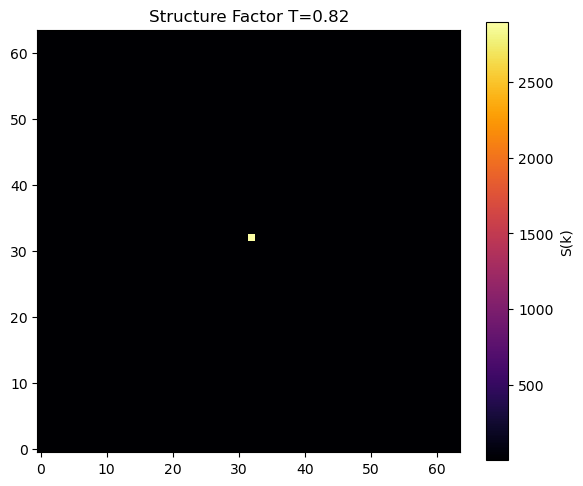

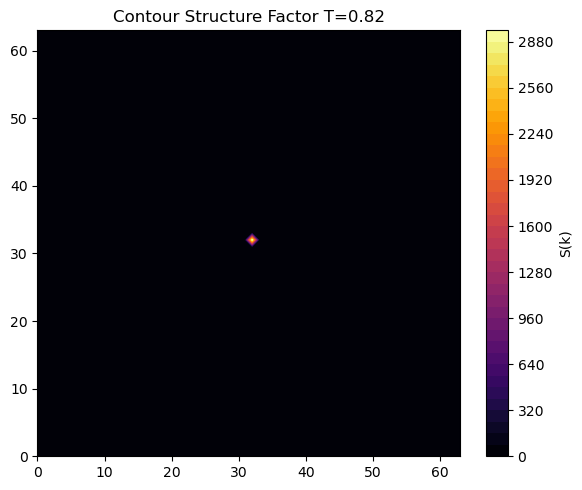

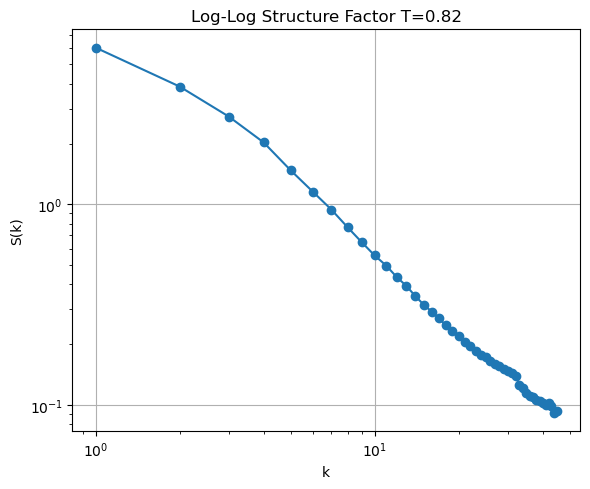

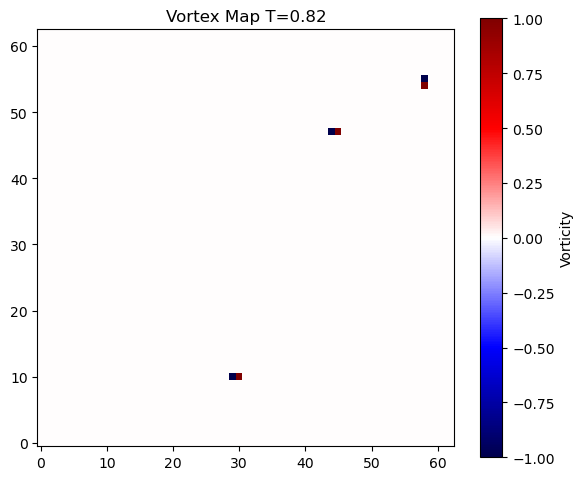

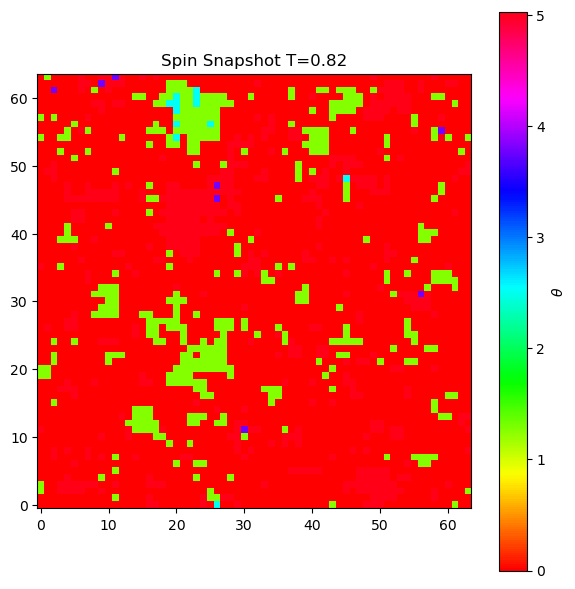


RUNNING T = 0.93
Thermalizing...
Thermalization done.
Measuring structure factor...
Measurement 0/300
Measurement 50/300
Measurement 100/300
Measurement 150/300
Measurement 200/300
Measurement 250/300
Saved data: clock_q5_L64_mid.npz


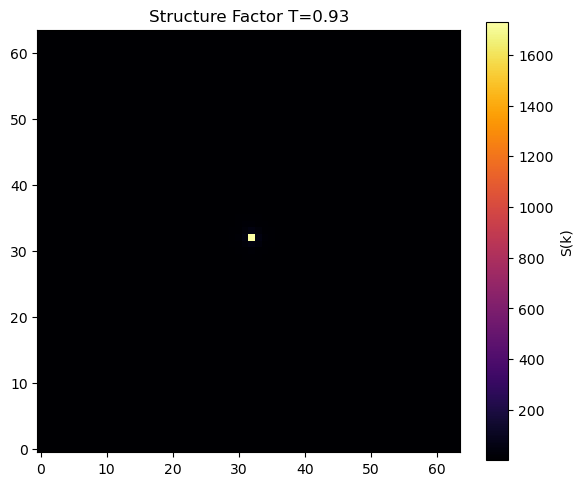

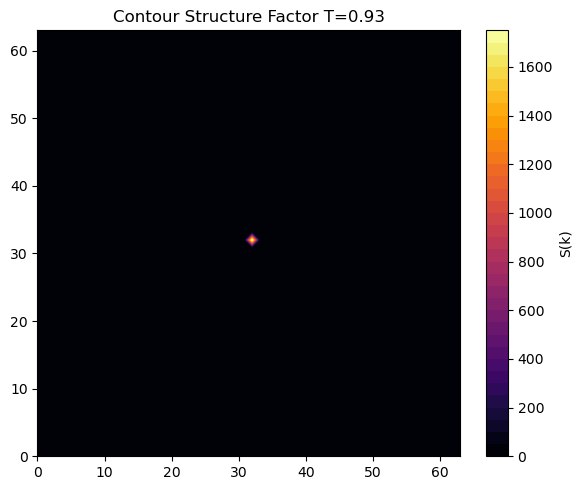

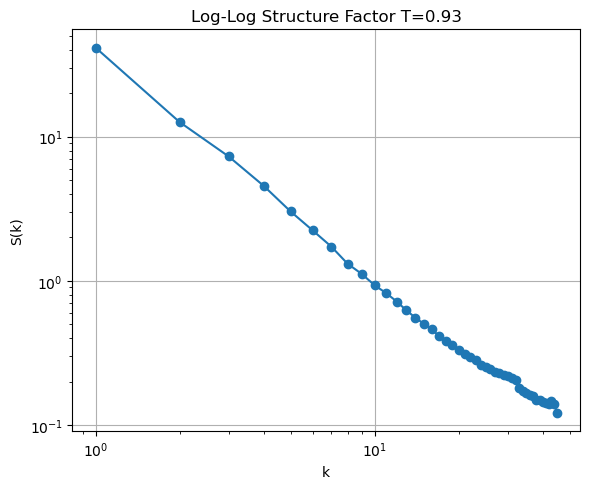

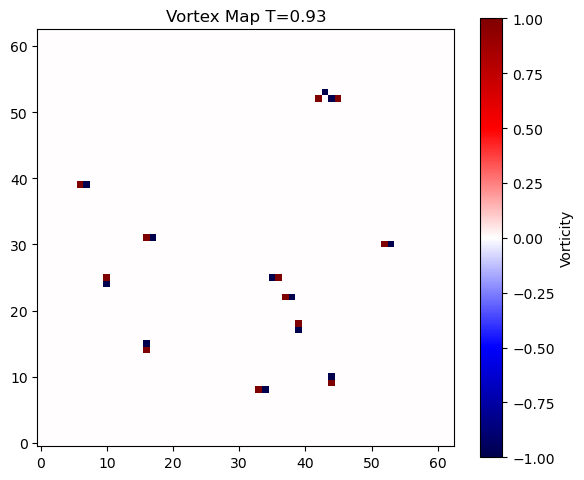

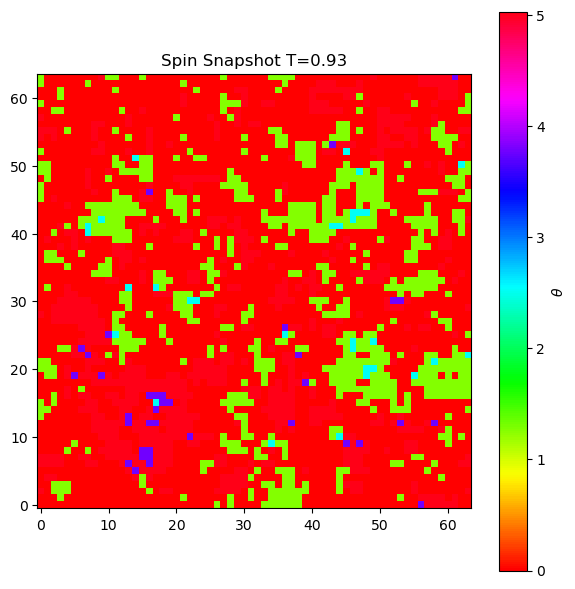


RUNNING T = 1.15
Thermalizing...
Thermalization done.
Measuring structure factor...
Measurement 0/300
Measurement 50/300
Measurement 100/300
Measurement 150/300
Measurement 200/300
Measurement 250/300
Saved data: clock_q5_L64_high.npz


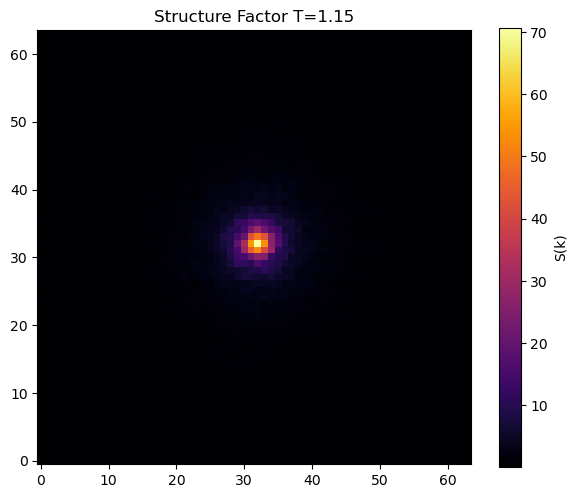

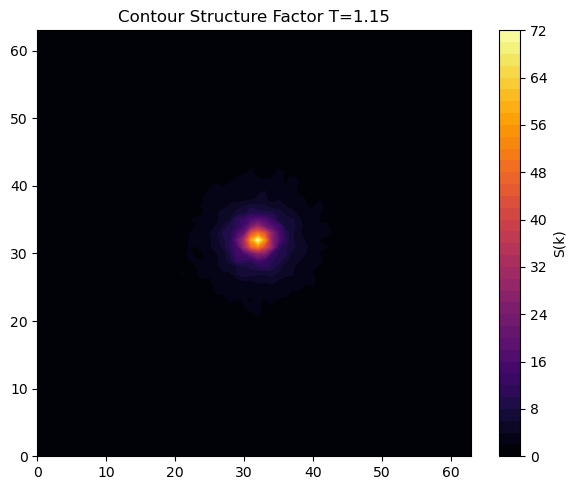

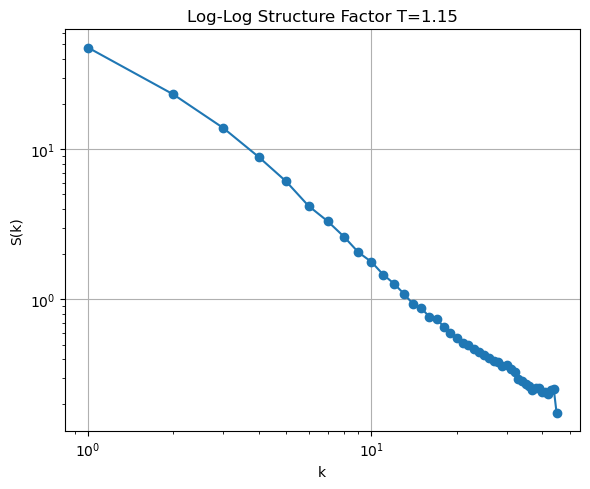

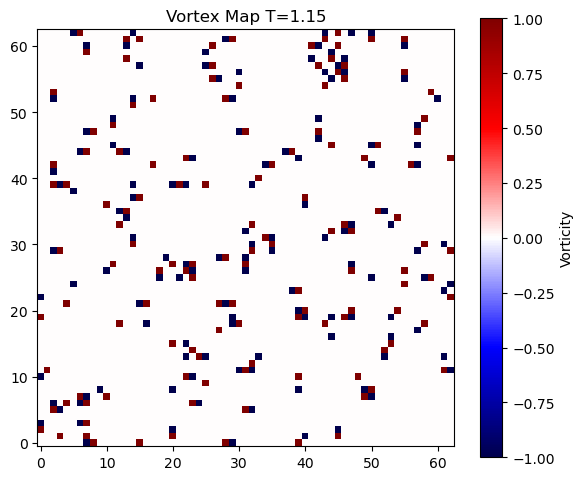

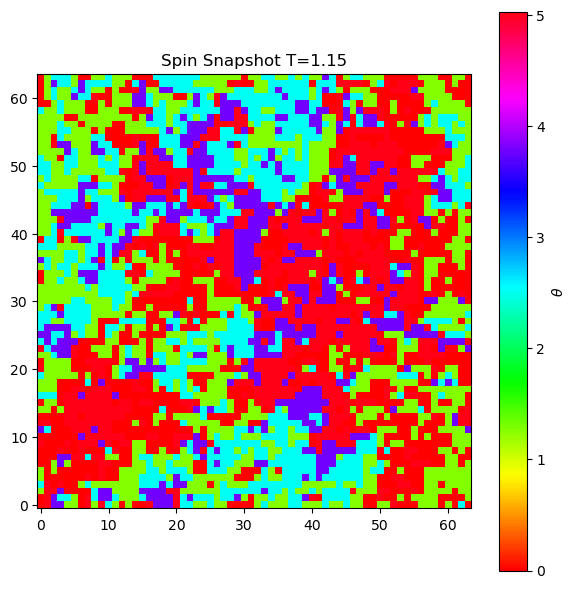


ALL SIMULATIONS FINISHED.


In [13]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 2D q=5 CLOCK MODEL
# WOLFF CLUSTER + STRUCTURE FACTOR + VORTICES
# ============================================================

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

L = 64

# ------------------------------------------------------------
# TEMPERATURES
# ------------------------------------------------------------
# q=5 clock model:
# lower transition  ~0.90
# upper transition  ~0.95
#
# We choose:
# below BKT-like region
# inside BKT-like region
# disordered phase
# ------------------------------------------------------------

T_low  = 0.82
T_mid  = 0.93
T_high = 1.15

temperatures = [T_low, T_mid, T_high]

# labels for saving
temp_labels = {
    T_low:  "low",
    T_mid:  "mid",
    T_high: "high"
}

# ------------------------------------------------------------
# MONTE CARLO PARAMETERS
# ------------------------------------------------------------

thermalization = 15000

# number of saved measurements
measurements = 300

# decorrelation sweeps between measurements
skip_steps = 10

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2*np.pi*np.arange(q)/q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# ------------------------------------------------------------
# cos(theta_i-theta_j)
# ------------------------------------------------------------

COS_DIFF = np.zeros((q,q))

for i in range(q):
    for j in range(q):

        COS_DIFF[i,j] = np.cos(
            ANGLES[i] - ANGLES[j]
        )

# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):

    return np.random.randint(
        0,
        q,
        size=(L,L)
    )

# ============================================================
# TOTAL ENERGY
# ============================================================

def total_energy(spins):

    L = spins.shape[0]

    E = 0.0

    for x in range(L):
        for y in range(L):

            s = spins[x,y]

            sr = spins[(x+1)%L,y]
            su = spins[x,(y+1)%L]

            E += -J*COS_DIFF[s,sr]
            E += -J*COS_DIFF[s,su]

    return E

# ============================================================
# MAGNETIZATION
# ============================================================

def magnetization(spins):

    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])

    return Mx,My

# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster(
    spins,
    beta,
    E_current,
    visited
):

    L = spins.shape[0]

    visited.fill(False)

    # --------------------------------------------------------
    # DISCRETE REFLECTION AXIS
    # --------------------------------------------------------

    r = np.random.randint(0,q)

    # --------------------------------------------------------
    # RANDOM SEED
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0,y0)]

    visited[x0,y0] = True

    cluster = []

    dE  = 0.0
    dMx = 0.0
    dMy = 0.0

    # ========================================================
    # CLUSTER GROWTH
    # ========================================================

    while stack:

        x,y = stack.pop()

        cluster.append((x,y))

        si = spins[x,y]

        # ----------------------------------------------------
        # REFLECTION:
        # si -> reflected spin
        # ----------------------------------------------------

        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L)

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                delta = (

                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]

                )

                if delta > 0:

                    p = 1 - np.exp(
                        -beta*J*delta
                    )

                    if np.random.rand() < p:

                        visited[nx,ny] = True

                        stack.append((nx,ny))

    # ========================================================
    # ENERGY CORRECTION
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L)

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                dE += J*(

                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]

                )

    # ========================================================
    # FLIP CLUSTER
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x,y] = si_ref

    return E_current+dE,dMx,dMy

# ============================================================
# GLOBAL ROTATION
# ============================================================

def global_rotate(spins):

    r = np.random.randint(0,q)

    spins[:] = (spins+r)%q

    return r

# ============================================================
# STRUCTURE FACTOR
# ============================================================

def structure_factor(spins):

    theta = ANGLES[spins]

    # complex spin field
    field = np.exp(1j*theta)

    # Fourier transform
    Fk = np.fft.fft2(field)

    # structure factor
    S = np.abs(Fk)**2/(L*L)

    # shift k=0 to center
    S = np.fft.fftshift(S)

    return S

# ============================================================
# RADIAL AVERAGE
# ============================================================

def radial_average(S):

    n = S.shape[0]

    center = n//2

    y,x = np.indices((n,n))

    r = np.sqrt(

        (x-center)**2
        +
        (y-center)**2

    )

    r = r.astype(int)

    tbin = np.bincount(
        r.ravel(),
        S.ravel()
    )

    nr = np.bincount(r.ravel())

    radial = tbin/nr

    return np.arange(len(radial)),radial

# ============================================================
# ANGLE DIFFERENCE
# ============================================================

def angle_diff(a,b):

    d = b-a

    while d > np.pi:
        d -= 2*np.pi

    while d <= -np.pi:
        d += 2*np.pi

    return d

# ============================================================
# VORTEX MAP
# ============================================================

def vortex_map(spins):

    theta = ANGLES[spins]

    vort = np.zeros((L-1,L-1))

    for x in range(L-1):
        for y in range(L-1):

            t1 = theta[x,y]
            t2 = theta[x+1,y]
            t3 = theta[x+1,y+1]
            t4 = theta[x,y+1]

            winding = (

                angle_diff(t1,t2)
                +
                angle_diff(t2,t3)
                +
                angle_diff(t3,t4)
                +
                angle_diff(t4,t1)

            )

            vort[x,y] = winding/(2*np.pi)

    return vort

# ============================================================
# SPIN SNAPSHOT
# ============================================================

def spin_snapshot(spins,title=""):

    theta = ANGLES[spins]

    plt.figure(figsize=(6,6))

    plt.imshow(
        theta,
        cmap='hsv',
        origin='lower'
    )

    plt.colorbar(label=r'$\theta$')

    plt.title(title)

    plt.tight_layout()

    plt.show()

# ============================================================
# MAIN LOOP
# ============================================================

for T in temperatures:

    print("\n====================================")
    print(f"RUNNING T = {T}")
    print("====================================")

    beta = 1.0/T

    # --------------------------------------------------------
    # INITIALIZE
    # --------------------------------------------------------

    spins = new_state(L)

    visited = np.zeros(
        (L,L),
        dtype=bool
    )

    E = total_energy(spins)

    Mx,My = magnetization(spins)

    # ========================================================
    # THERMALIZATION
    # ========================================================

    print("Thermalizing...")

    for step in range(thermalization):

        E,dMx,dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )

        Mx += dMx
        My += dMy

        # ergodicity rotation
        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]

        Mx,My = (

            Mx*c - My*s,
            Mx*s + My*c

        )

    print("Thermalization done.")

    # ========================================================
    # MEASURE STRUCTURE FACTOR
    # ========================================================

    print("Measuring structure factor...")

    S_total = np.zeros((L,L))

    for meas in range(measurements):

        # decorrelation sweeps
        for _ in range(skip_steps):

            E,dMx,dMy = wolff_cluster(
                spins,
                beta,
                E,
                visited
            )

            Mx += dMx
            My += dMy

        # structure factor
        S = structure_factor(spins)

        S_total += S

        if meas%50 == 0:
            print(
                f"Measurement {meas}/{measurements}"
            )

    # Monte Carlo average
    S_avg = S_total/measurements

    # ========================================================
    # SAVE DATA
    # ========================================================

    label = temp_labels[T]

    np.savez(

        f"clock_q5_L{L}_{label}.npz",

        T=T,
        S_avg=S_avg,
        spins=spins,
        energy=E,
        magnetization=np.sqrt(Mx**2+My**2)

    )

    print(f"Saved data: clock_q5_L{L}_{label}.npz")

    # ========================================================
    # HEATMAP
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        S_avg,
        cmap='inferno',
        origin='lower'
    )

    plt.colorbar(label='S(k)')

    plt.title(
        f"Structure Factor T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # CONTOUR PLOT
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.contourf(
        S_avg,
        levels=40,
        cmap='inferno'
    )

    plt.colorbar(label='S(k)')

    plt.title(
        f"Contour Structure Factor T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # LOG-LOG PLOT
    # ========================================================

    r,Sr = radial_average(S_avg)

    mask = (

        (r > 0)
        &
        (Sr > 1e-12)

    )

    plt.figure(figsize=(6,5))

    plt.loglog(
        r[mask],
        Sr[mask],
        'o-'
    )

    plt.xlabel("k")

    plt.ylabel("S(k)")

    plt.title(
        f"Log-Log Structure Factor T={T}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.show()

    # ========================================================
    # VORTEX MAP
    # ========================================================

    vort = vortex_map(spins)

    plt.figure(figsize=(6,5))

    plt.imshow(

        vort,

        cmap='seismic',

        origin='lower',

        vmin=-1,
        vmax=1

    )

    plt.colorbar(label='Vorticity')

    plt.title(
        f"Vortex Map T={T}"
    )

    plt.tight_layout()

    plt.show()

    # ========================================================
    # SPIN SNAPSHOT
    # ========================================================

    spin_snapshot(
        spins,
        title=f"Spin Snapshot T={T}"
    )

print("\nALL SIMULATIONS FINISHED.")


Running T = 0.85


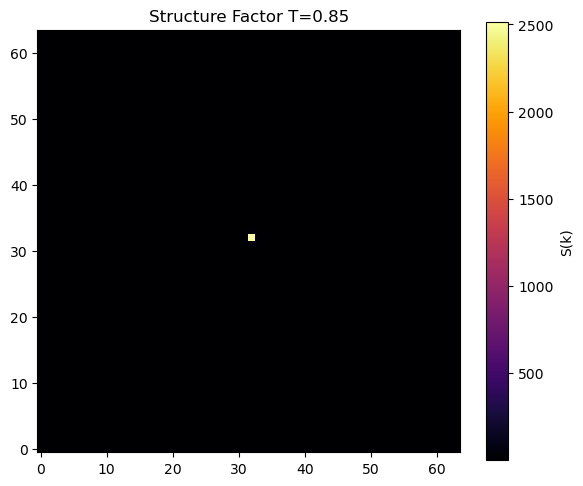

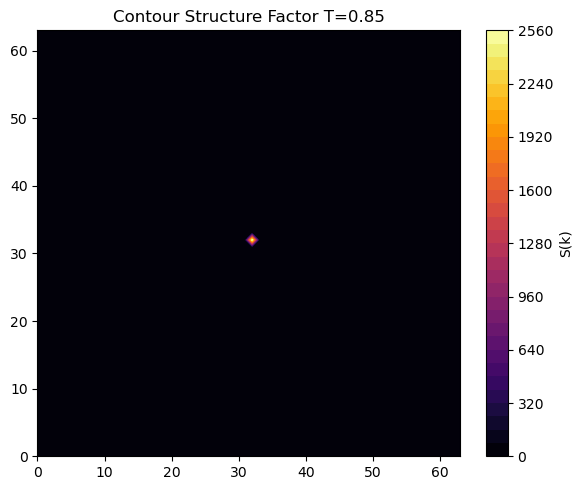

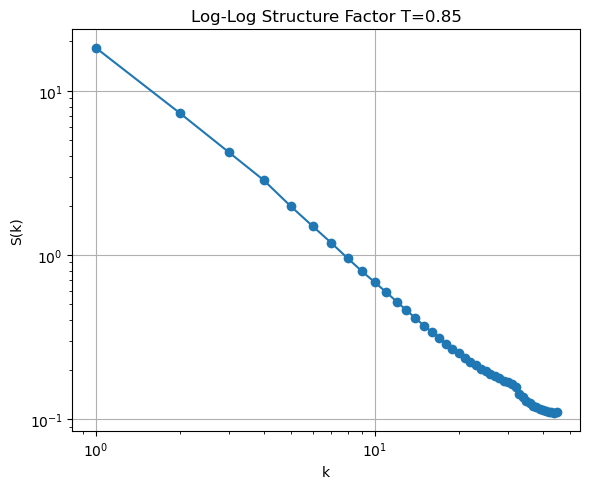

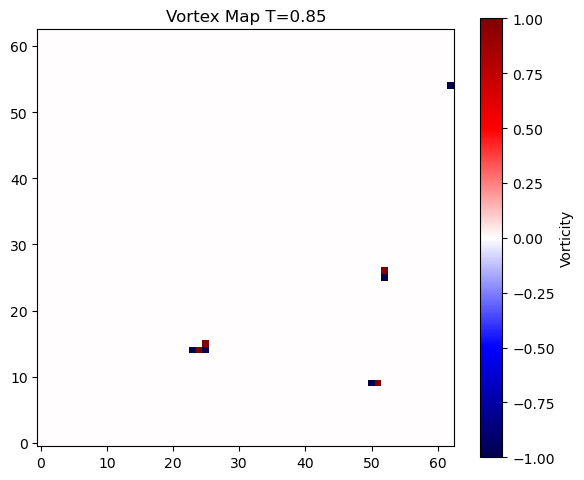

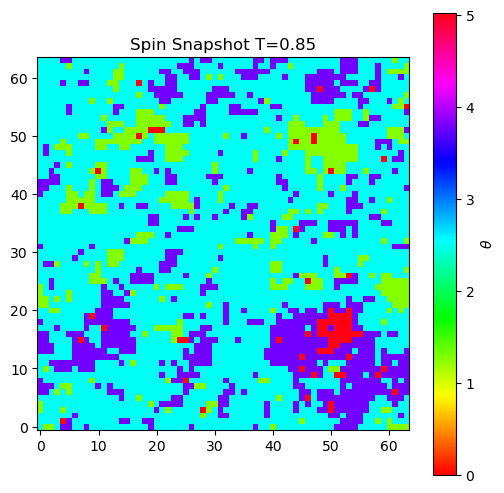


Running T = 0.98


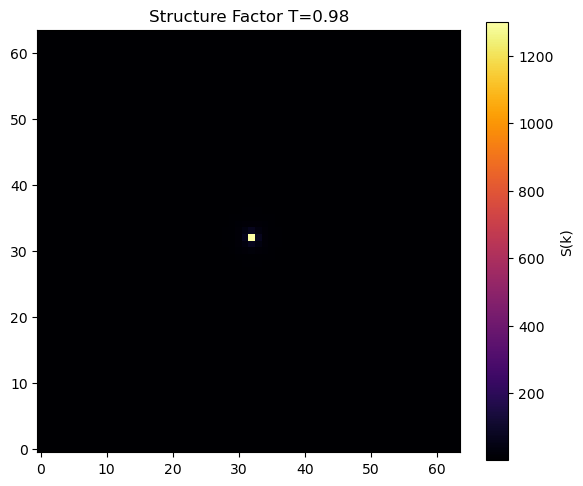

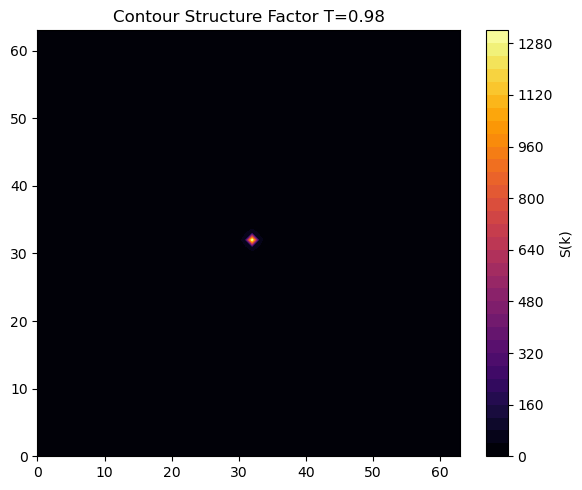

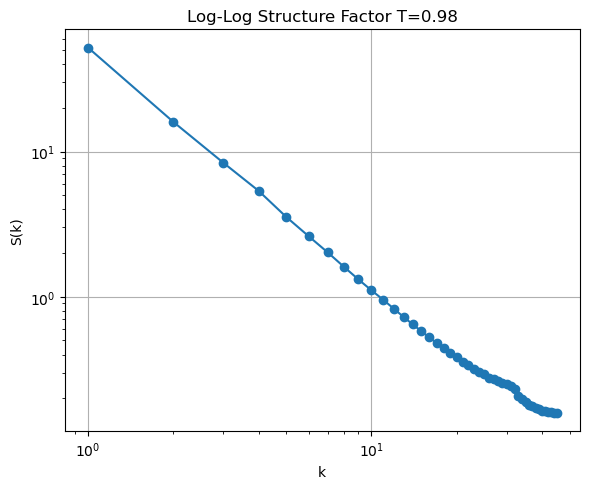

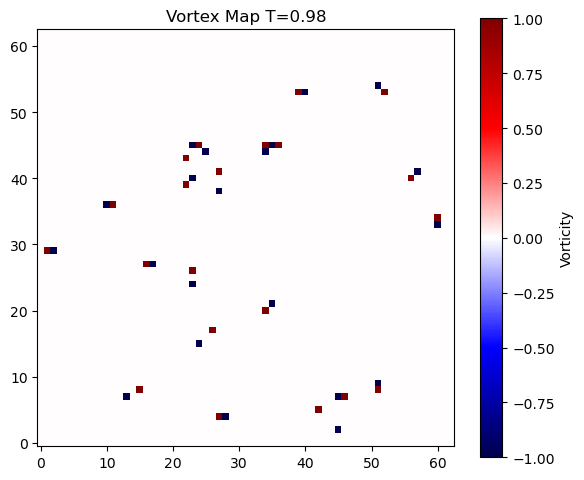

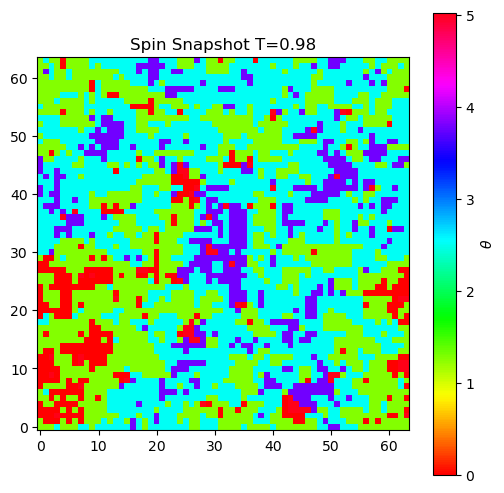


Running T = 1.2


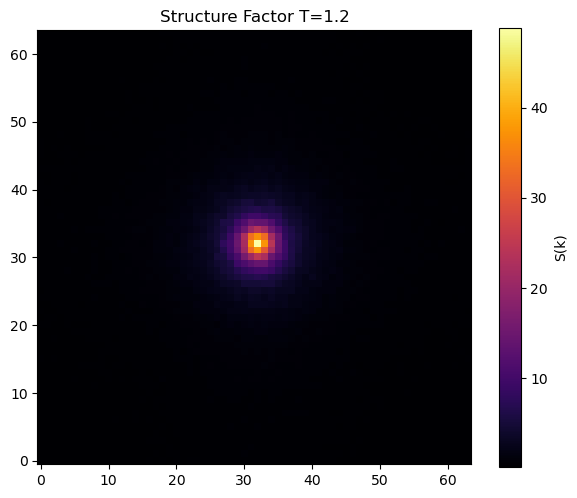

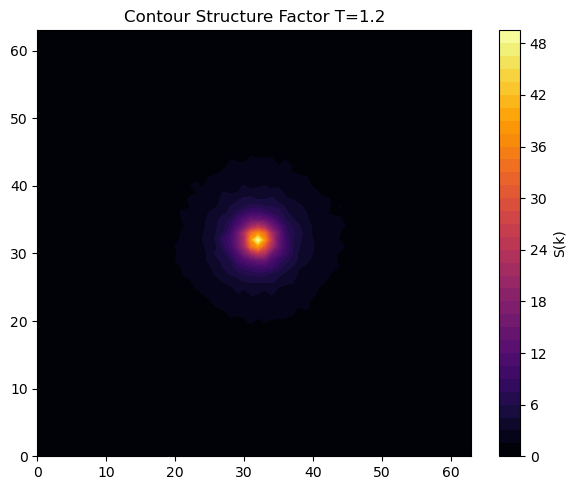

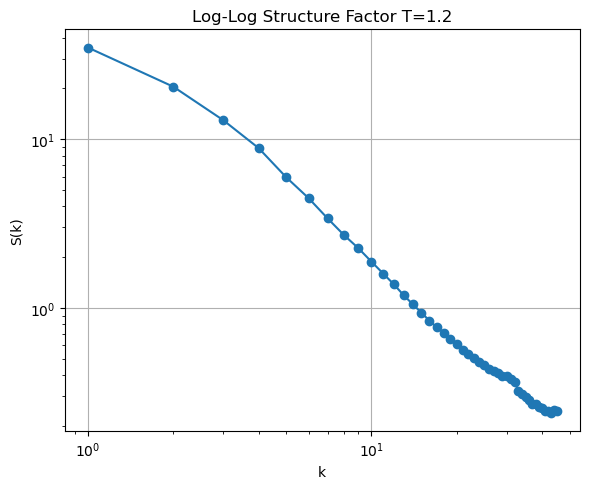

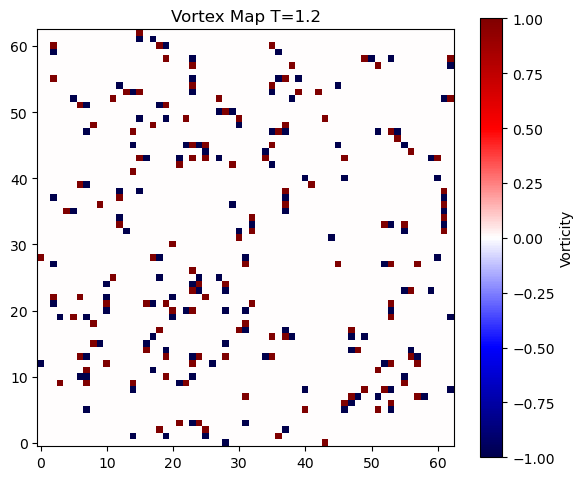

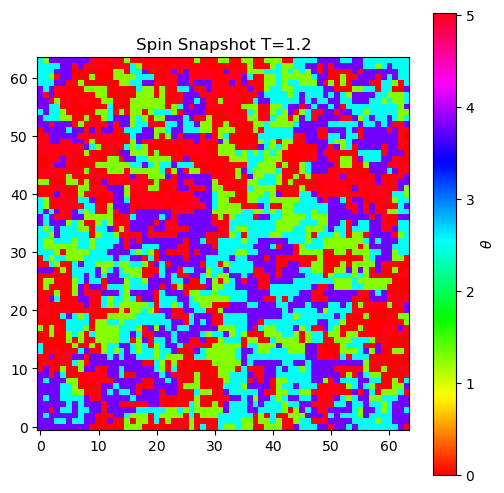

In [11]:
 import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

L = 64

# ------------------------------------------------------------
# TEMPERATURES
# ------------------------------------------------------------
# Example temperatures:
# ordered phase
T_low = 0.85

# BKT-like phase
T_mid = 0.98

# disordered phase
T_high = 1.20

temperatures = [T_low, T_mid, T_high]

# ------------------------------------------------------------
# MONTE CARLO PARAMETERS
# ------------------------------------------------------------

thermalization = 20000
measurements = 20000

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2*np.pi*np.arange(q)/q

COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# ------------------------------------------------------------
# cos(theta_i - theta_j)
# ------------------------------------------------------------

COS_DIFF = np.zeros((q,q))

for i in range(q):
    for j in range(q):
        COS_DIFF[i,j] = np.cos(ANGLES[i]-ANGLES[j])

# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):

    return np.random.randint(0,q,size=(L,L))

# ============================================================
# TOTAL ENERGY
# ============================================================

def total_energy(spins):

    L = spins.shape[0]

    E = 0.0

    for x in range(L):
        for y in range(L):

            s = spins[x,y]

            sr = spins[(x+1)%L,y]
            su = spins[x,(y+1)%L]

            E += -J*COS_DIFF[s,sr]
            E += -J*COS_DIFF[s,su]

    return E

# ============================================================
# MAGNETIZATION
# ============================================================

def magnetization(spins):

    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])

    return Mx, My

# ============================================================
# WOLFF CLUSTER
# ============================================================

def wolff_cluster(spins,beta,E_current,visited):

    L = spins.shape[0]

    visited.fill(False)

    # --------------------------------------------------------
    # reflection axis
    # --------------------------------------------------------

    r = np.random.randint(0,q)

    # --------------------------------------------------------
    # random seed
    # --------------------------------------------------------

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0,y0)]

    visited[x0,y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ========================================================
    # CLUSTER GROWTH
    # ========================================================

    while stack:

        x,y = stack.pop()

        cluster.append((x,y))

        si = spins[x,y]

        # reflection
        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L),

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                delta = (
                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]
                )

                if delta > 0:

                    p = 1 - np.exp(-beta*J*delta)

                    if np.random.rand() < p:

                        visited[nx,ny] = True

                        stack.append((nx,ny))

    # ========================================================
    # ENERGY CORRECTION
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        for nx,ny in (

            ((x+1)%L,y),
            ((x-1)%L,y),
            (x,(y+1)%L),
            (x,(y-1)%L),

        ):

            if not visited[nx,ny]:

                sj = spins[nx,ny]

                dE += J*(
                    COS_DIFF[si,sj]
                    -
                    COS_DIFF[si_ref,sj]
                )

    # ========================================================
    # FLIP SPINS
    # ========================================================

    for x,y in cluster:

        si = spins[x,y]

        si_ref = (2*r - si)%q

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x,y] = si_ref

    return E_current+dE,dMx,dMy

# ============================================================
# GLOBAL ROTATION
# ============================================================

def global_rotate(spins):

    r = np.random.randint(0,q)

    spins[:] = (spins+r)%q

    return r

# ============================================================
# CORRELATION FUNCTION
# ============================================================

def correlation_function(spins):

    L = spins.shape[0]

    theta = ANGLES[spins]

    G = np.zeros((L//2,L//2))

    # --------------------------------------------------------
    # G(dx,dy)
    # --------------------------------------------------------

    for dx in range(L//2):

        for dy in range(L//2):

            corr = 0.0

            for x in range(L):

                for y in range(L):

                    t1 = theta[x,y]

                    t2 = theta[
                        (x+dx)%L,
                        (y+dy)%L
                    ]

                    corr += np.cos(t1-t2)

            G[dx,dy] = corr/(L*L)

    return G

# ============================================================
# STRUCTURE FACTOR
# ============================================================

def structure_factor(G):

    S = np.fft.fftshift(
        np.abs(np.fft.fft2(G))
    )

    return S

# ============================================================
# RADIAL AVERAGE
# ============================================================

def radial_average(S):

    n = S.shape[0]

    center = n//2

    y,x = np.indices((n,n))

    r = np.sqrt(
        (x-center)**2
        +
        (y-center)**2
    )

    r = r.astype(int)

    tbin = np.bincount(r.ravel(),S.ravel())

    nr = np.bincount(r.ravel())

    radialprofile = tbin/nr

    return np.arange(len(radialprofile)),radialprofile

# ============================================================
# VORTEX FUNCTIONS
# ============================================================

def angle_diff(a,b):

    d = b-a

    while d > np.pi:
        d -= 2*np.pi

    while d <= -np.pi:
        d += 2*np.pi

    return d

# ============================================================
# VORTEX MAP
# ============================================================

def vortex_map(spins):

    L = spins.shape[0]

    theta = ANGLES[spins]

    vort = np.zeros((L-1,L-1))

    for x in range(L-1):

        for y in range(L-1):

            t1 = theta[x,y]
            t2 = theta[x+1,y]
            t3 = theta[x+1,y+1]
            t4 = theta[x,y+1]

            winding = (

                angle_diff(t1,t2)
                +
                angle_diff(t2,t3)
                +
                angle_diff(t3,t4)
                +
                angle_diff(t4,t1)

            )

            vort[x,y] = winding/(2*np.pi)

    return vort

# ============================================================
# SPIN SNAPSHOT
# ============================================================

def spin_snapshot(spins,title=""):

    theta = ANGLES[spins]

    plt.figure(figsize=(6,6))

    plt.imshow(theta,cmap='hsv',origin='lower')

    plt.colorbar(label=r'$\theta$')

    plt.title(title)

    plt.show()

# ============================================================
# MAIN SIMULATION
# ============================================================
# ============================================================
# MAIN SIMULATION
# ============================================================

for T in temperatures:

    print(f"\nRunning T = {T}")

    beta = 1.0 / T

    spins = new_state(L)

    visited = np.zeros((L, L), dtype=bool)

    E = total_energy(spins)

    Mx, My = magnetization(spins)

    # ========================================================
    # THERMALIZATION
    # ========================================================

    for step in range(thermalization):

        E, dMx, dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )

        Mx += dMx
        My += dMy

        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]

        Mx, My = (
            Mx*c - My*s,
            Mx*s + My*c
        )

    # ========================================================
    # STRUCTURE FACTOR MEASUREMENT
    # ========================================================

    S_total = np.zeros((L, L))

    for step in range(measurements):

        # ----------------------------------------------------
        # Wolff update
        # ----------------------------------------------------

        E, dMx, dMy = wolff_cluster(
            spins,
            beta,
            E,
            visited
        )

        Mx += dMx
        My += dMy

        # ----------------------------------------------------
        # Spin field:
        # s(r)=exp(i theta)
        # ----------------------------------------------------

        theta = ANGLES[spins]

        spin_field = np.exp(1j * theta)

        # ----------------------------------------------------
        # Fourier transform
        # ----------------------------------------------------

        Fk = np.fft.fft2(spin_field)

        # ----------------------------------------------------
        # Structure factor
        # ----------------------------------------------------

        S = np.abs(Fk)**2 / (L*L)

        # shift zero momentum to center
        S = np.fft.fftshift(S)

        S_total += S

    # ========================================================
    # Monte Carlo average
    # ========================================================

    S_avg = S_total / measurements

    # ========================================================
    # HEATMAP
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.imshow(
        S_avg,
        cmap='inferno',
        origin='lower'
    )

    plt.colorbar(label='S(k)')

    plt.title(f"Structure Factor T={T}")

    plt.tight_layout()

    plt.show()

    # ========================================================
    # CONTOUR PLOT
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.contourf(
        S_avg,
        levels=40,
        cmap='inferno'
    )

    plt.colorbar(label='S(k)')

    plt.title(f"Contour Structure Factor T={T}")

    plt.tight_layout()

    plt.show()

    # ========================================================
    # RADIAL AVERAGE
    # ========================================================

    r, Sr = radial_average(S_avg)

    mask = (r > 0)

    plt.figure(figsize=(6,5))

    plt.loglog(
        r[mask],
        Sr[mask],
        'o-'
    )

    plt.xlabel("k")

    plt.ylabel("S(k)")

    plt.title(f"Log-Log Structure Factor T={T}")

    plt.grid(True)

    plt.tight_layout()

    plt.show()

    # ========================================================
    # VORTEX MAP
    # ========================================================

    vort = vortex_map(spins)

    plt.figure(figsize=(6,5))

    plt.imshow(
        vort,
        cmap='seismic',
        origin='lower',
        vmin=-1,
        vmax=1
    )

    plt.colorbar(label='Vorticity')

    plt.title(f"Vortex Map T={T}")

    plt.tight_layout()

    plt.show()

    # ========================================================
    # SPIN SNAPSHOT
    # ========================================================

    spin_snapshot(
        spins,
        title=f"Spin Snapshot T={T}"
    )

In [3]:
q = 5   # Number of clock states
J = 1.0  # Interactio\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\n strength
h = np.array([0, 0])  # External field
#delta = 0  # Chirality term
sweeps = 5*10**4 
#steps = 10**7  # Total Monte Carlo steps
#burn_in = 2**17
L_values = [16, 24, 32, 48, 64]  # Different lattice sizes to test
  # Temperature range
#beta_core = np.linspace(0.5, 1.75, 10)
#delta_beta = beta_core[1] - beta_core[0]
#beta_extra_low = beta_core[0] - delta_beta
#beta_extra_high = beta_core[-1] + delta_beta
#beta_values = np.concatenate([[beta_extra_low], beta_core, [beta_extra_high]])
T_values = np.linspace(0.8, 1.43, 10)
# Compute corresponding temperature values
beta_values = 1 / T_values

In [9]:
# Function to compute measure frequency
def measure_every(L):
    return L**2

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles

# Compute total magnetization (vector)
def compute_magnetization(sigma, L):
    return  np.sum(sigma, axis=(0, 1)) / (L * L)  # Normalize per spin

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta, L):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Avoid double counting
        H -= np.dot(h, sigma[i, j]) # External field term
    return H/2




In [11]:
# Monte Carlo Step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)  # Pick a random site
    new_spin = np.random.randint(0, q)  # Pick a new random spin state
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    old_angle = angles[i, j]  # Current angle
    old_sigma = sigma[i, j]   # Current spin vector

    # Define neighbor sites with periodic boundaries
    neighbor_sites = [( (i+1) % L, j ), ( (i-1) % L, j ), ( i, (j+1) % L ), ( i, (j-1) % L )]

    # Compute old and new energy
    E_old = -J * sum(np.cos(old_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 
    E_new = -J * sum(np.cos(new_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 

    # Add external field term
    E_old -= np.dot(h, old_sigma)
    E_new -= np.dot(h, new_sigma)

    # Compute ΔE
    dE = E_new - E_old  

    # Compute acceptance probability (Glauber or Metropolis)
    beta = 1/T
    P_accept = 1 / (1 + np.exp(beta * dE)) if update_rule == "glauber" else min(1, np.exp(-beta * dE))

    # Accept or reject the update
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma  # Update spin vector


In [19]:
# Run simulation
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []  # List to store magnetization vectors
    E_vals = []
    # Adjust burn-in dynamically based on system size
    burn_in = 5000000 if L >= 10 else (10**6)*2  # More steps for large L
    # Pre-thermalization (Burn-in)
    for _ in range(burn_in):  
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)  # [M_x, M_y]
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)  # Convert list to NumPy array
    E_vals = np.array(E_vals)
   # Mean magnetization vector
    m_avg = np.mean(m_vals, axis=0)  # ⟨M_x⟩, ⟨M_y⟩
   
    # Compute mean magnitude of magnetization
    mod_m_avg = np.mean(np.linalg.norm(m_vals, axis=1)) # ⟨|M|⟩
    m_sq_avg = np.mean(np.linalg.norm(m_vals, axis=1)**2)  # ⟨|M|^2⟩
    m_avg_sq = np.linalg.norm(np.mean(m_vals, axis=0))**2  # ⟨|M|⟩^2
    #avg_sq_mod_m = np.square(np.linalg.norm(m_avg))
    # Compute ⟨M⟩ ⋅ ⟨M⟩
    #m_avg_sq = np.dot(m_avg, m_avg)  # ⟨M⟩ ⋅ ⟨M⟩
    # Compute ⟨M ⋅ M⟩
    #m_sq_avg = np.mean(np.sum(m_vals**2, axis=1))   # ⟨M ⋅ M⟩

    # Susceptibility (corrected formula)
    chi_M = (m_sq_avg - m_avg_sq)/(L**2*T)
    # Energy calculations
    E_avg = np.mean(E_vals)
    E_avg_per_site = E_avg/L**2
    E_sq_avg = np.mean(np.square(E_vals))
    # Heat capacity
    C_v = (E_sq_avg - E_avg**2)/(T**2 * L**2)

    return mod_m_avg, chi_M, C_v, E_avg_per_site



In [21]:
# Run simulations for different lattice sizes and temperatures
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (β ≈ {1/T:.2f})...")
    for L in L_values:
        mod_m_avg, chi_M, C_v, E_avg_per_site = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(mod_m_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)


Running simulations for T=2.77 (β ≈ 0.36)...


KeyboardInterrupt: 

In [9]:
import numpy as np

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# Reflection table
REFLECT = np.array([
    [(-k) % q for k in range(q)],
    [(1 - k) % q for k in range(q)],
    [(2 - k) % q for k in range(q)],
    [(3 - k) % q for k in range(q)],
    [(4 - k) % q for k in range(q)],
])


# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))


# ============================================================
# TOTAL ENERGY (computed once)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E


# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My


# ============================================================
# WOLFF CLUSTER UPDATE
# ============================================================

def wolff_cluster_q5(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    r = np.random.randint(0, q)

    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []
    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ----------------------
    # Grow cluster ONLY
    # ----------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):

            if not visited[nx, ny]:

                sj = spins[nx, ny]

                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))
       # ----------------------
    # Boundary correction
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])
    # ----------------------
    # Flip + magnetization
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = REFLECT[r, si]

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref


    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r


# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=5*10**4,
    J=J,
    burn_frac=0.2,
    sample_interval=1
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L, L), dtype=bool)

    # Initial observables
    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster_q3(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        # Rotate magnetization accordingly
        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c
    
        # --- Measurements
        if sweep >= burn_steps and (sweep - burn_steps) % sample_interval == 0:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ============================================================
    # Observables
    # ============================================================

    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)
    U = 1 - M4_mean/(3*(M2_mean**2))
    N = L * L

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U


In [5]:
import numpy as np

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# ------------------------------------------------------------
# PRECOMPUTE DELTA (CRITICAL FOR SPEED)
# Δ = cos(si - sj) - cos(si_ref - sj)
# ------------------------------------------------------------

DELTA = np.zeros((q, q, q))

for r in range(q):
    for si in range(q):
        si_ref = (2*r - si) % q
        for sj in range(q):
            DELTA[r, si, sj] = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))

# ============================================================
# TOTAL ENERGY (ONLY ONCE)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E

# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My

# ============================================================
# WOLFF CLUSTER UPDATE (GENERAL q)
# ============================================================

def wolff_cluster(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    # random reflection axis
    r = np.random.randint(0, q)

    # random seed
    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ------------------------------------------------
    # GROW CLUSTER
    # ------------------------------------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:

                sj = spins[nx, ny]
                delta = DELTA[r, si, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)

                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))

    # ------------------------------------------------
    # ENERGY CHANGE (BOUNDARY ONLY)
    # ------------------------------------------------
    for x, y in cluster:

        si = spins[x, y]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * DELTA[r, si, sj]

    # ------------------------------------------------
    # FLIP CLUSTER + MAGNETIZATION UPDATE
    # ------------------------------------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = (2*r - si) % q

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref

    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r

# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=5*10**4,
    J=J,
    burn_frac=0.2
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L, L), dtype=bool)

    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c

        # --- Measurements
        if sweep >= burn_steps:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ------------------------------------------------
    # OBSERVABLES
    # ------------------------------------------------
    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    N = L * L

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)

    U = 1 - M4_mean / (3 * (M2_mean**2))

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U

In [13]:
import numpy as np

# ============================================================
# PARAMETERS
# ============================================================

q = 5
J = 1.0

# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])



for r in range(q):
    for si in range(q):
        si_ref = (2*r - si) % q
        for sj in range(q):
            DELTA[r, si, sj] = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))

# ============================================================
# TOTAL ENERGY
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E

# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My

# ============================================================
# WOLFF CLUSTER UPDATE (GENERAL q)
# ============================================================

def wolff_cluster(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    # Discrete reflection axis
    r = np.random.randint(0, q)

    # random seed
    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ----------------------
    # 1. Grow cluster
    # ----------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]
        si_ref = (2*r - si) % q

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:

                sj = spins[nx, ny]

                # energy difference
                delta = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)
                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))

    # ----------------------
    # 2. Energy correction (boundary only)
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = (2*r - si) % q

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * (COS_DIFF[si, sj] - COS_DIFF[si_ref, sj])

    # ----------------------
    # 3. Flip spins
    # ----------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = (2*r - si) % q

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref

    return E_current + dE, dMx, dMy
# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r

# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=5*10**4,
    J=J,
    burn_frac=0.2
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L, L), dtype=bool)

    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c

        # --- Measurements
        if sweep >= burn_steps:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ------------------------------------------------
    # OBSERVABLES
    # ------------------------------------------------
    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    N = L * L

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)

    U = 1 - M4_mean / (3 * (M2_mean**2))

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U

NameError: name 'DELTA' is not defined

In [7]:
import time
# --- Storage ---
results = {
    L: {
        "M": [],
        "chi": [],
        "E": [],
        "Cv": [],
        "Binder": []
    }
    for L in L_values
}

# --- Loop over sizes and temperatures ---
for L in L_values:
    print(f"\nRunning simulations for L = {L}")

    for T in T_values:
        start_time = time.time()

        M, chi, E, Cv, U = run_simulation(
            L, T,
            sweeps=sweeps,
            J=J,
            burn_frac=0.3
        )

        results[L]["M"].append(M)
        results[L]["chi"].append(chi)
        results[L]["E"].append(E)
        results[L]["Cv"].append(Cv)
        results[L]["Binder"].append(U)

        elapsed = time.time() - start_time
        print(f"T = {T:.3f} | U = {U:.4f} | time = {elapsed/60:.2f} min")


for L in L_values:
    for key in results[L]:
        results[L][key] = np.array(results[L][key])
        
save_dict = {
    "T_values": np.array(T_values),
    "L_values": np.array( L_values)
}

for L in L_values:
    for key in results[L]:
        save_dict[f"L{L}_{key}"] = results[L][key]

np.savez_compressed("clock_q5_binderresolvedsimulationInt4-16-64_data.npz", **save_dict)

print("\nData saved successfully.")


Running simulations for L = 16
T = 0.800 | U = 0.6633 | time = 1.09 min
T = 0.870 | U = 0.6602 | time = 0.89 min
T = 0.940 | U = 0.6572 | time = 0.78 min
T = 1.010 | U = 0.6495 | time = 0.64 min
T = 1.080 | U = 0.6248 | time = 0.51 min
T = 1.150 | U = 0.5720 | time = 0.35 min
T = 1.220 | U = 0.5047 | time = 0.23 min
T = 1.290 | U = 0.4479 | time = 0.17 min
T = 1.360 | U = 0.4083 | time = 0.15 min
T = 1.430 | U = 0.3880 | time = 0.11 min

Running simulations for L = 24
T = 0.800 | U = 0.6643 | time = 2.22 min
T = 0.870 | U = 0.6614 | time = 1.82 min
T = 0.940 | U = 0.6583 | time = 1.54 min
T = 1.010 | U = 0.6470 | time = 1.18 min
T = 1.080 | U = 0.5993 | time = 0.79 min
T = 1.150 | U = 0.5089 | time = 0.42 min
T = 1.220 | U = 0.4366 | time = 0.25 min
T = 1.290 | U = 0.3821 | time = 0.16 min
T = 1.360 | U = 0.3935 | time = 0.13 min
T = 1.430 | U = 0.3529 | time = 0.11 min

Running simulations for L = 32
T = 0.800 | U = 0.6650 | time = 3.91 min
T = 0.870 | U = 0.6617 | time = 3.50 min
T 

In [3]:
data = np.load("clock_q5_binderresolvedsimulationInt4-16-64_data.npz")
print(data.files)
T_values = np.linspace(0.8, 1.43, 10)
L_values = [16, 24, 32, 48, 64]   # set your lattice sizes

results = {}

for L in L_values:

    results[L] = {
        #"T": data[f"L{L}_T"],
        "M": data[f"L{L}_M"],
        "chi": data[f"L{L}_chi"],
        "E": data[f"L{L}_E"],
        "Cv": data[f"L{L}_Cv"],
        "Binder": data[f"L{L}_Binder"]
    }

['T_values', 'L_values', 'L16_M', 'L16_chi', 'L16_E', 'L16_Cv', 'L16_Binder', 'L24_M', 'L24_chi', 'L24_E', 'L24_Cv', 'L24_Binder', 'L32_M', 'L32_chi', 'L32_E', 'L32_Cv', 'L32_Binder', 'L48_M', 'L48_chi', 'L48_E', 'L48_Cv', 'L48_Binder', 'L64_M', 'L64_chi', 'L64_E', 'L64_Cv', 'L64_Binder']


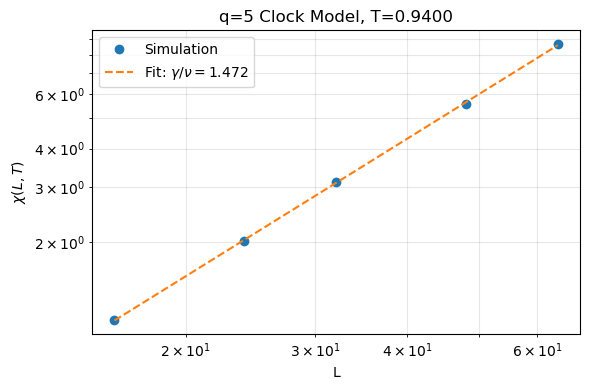

Selected temperature: 0.940000
Estimated gamma/nu: 1.4719


In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("clock_q5_binderresolvedsimulationInt4-16-64_data.npz")

T = data["T_values"]
Ls = data["L_values"]

# Choose one temperature in the trailing susceptibility peak
T_target = 0.92  # Change this to your chosen temperature

idx = np.argmin(np.abs(T - T_target))
T_used = T[idx]

chi = np.array([
    data[f"L{L}_chi"][idx] for L in Ls
])

# Power-law fit: chi ~ L^(gamma/nu)
slope, intercept = np.polyfit(np.log(Ls), np.log(chi), 1)
gamma_nu = slope

L_fit = np.linspace(min(Ls), max(Ls), 200)
chi_fit = np.exp(intercept) * L_fit**gamma_nu

plt.figure(figsize=(6, 4))
plt.loglog(Ls, chi, "o", label="Simulation")
plt.loglog(L_fit, chi_fit, "--",
           label=fr"Fit: $\gamma/\nu={gamma_nu:.3f}$")
plt.xlabel("L")
plt.ylabel(r"$\chi(L,T)$")
plt.title(f"q=5 Clock Model, T={T_used:.4f}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Selected temperature: {T_used:.6f}")
print(f"Estimated gamma/nu: {gamma_nu:.4f}")

Temperatures used: [0.8  0.87 0.94]
Lattice sizes: [16 24 32 48 64]

===== LOW-T FSS COLLAPSE =====
Candidate pseudocritical Tc = 0.84250
Effective nu                 = 0.95000
Effective gamma/nu           = 1.32500
Relative collapse score      = 0.000550553


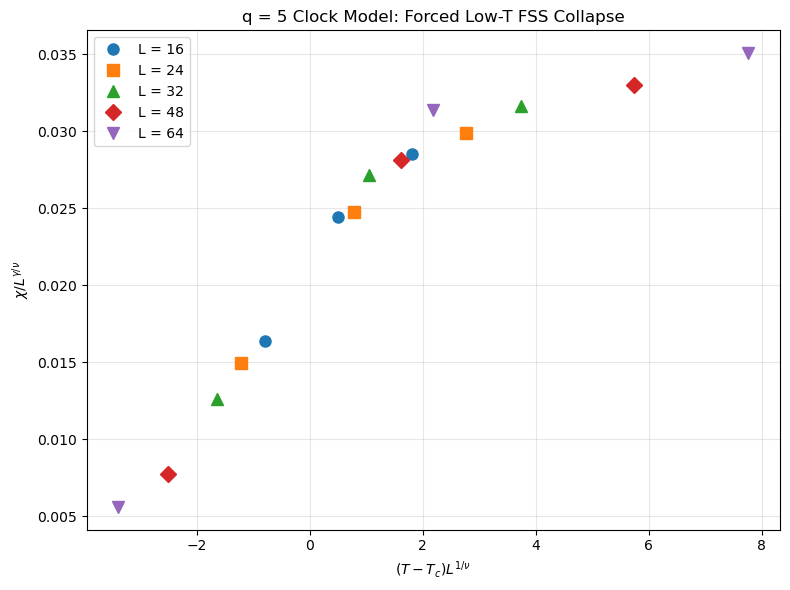

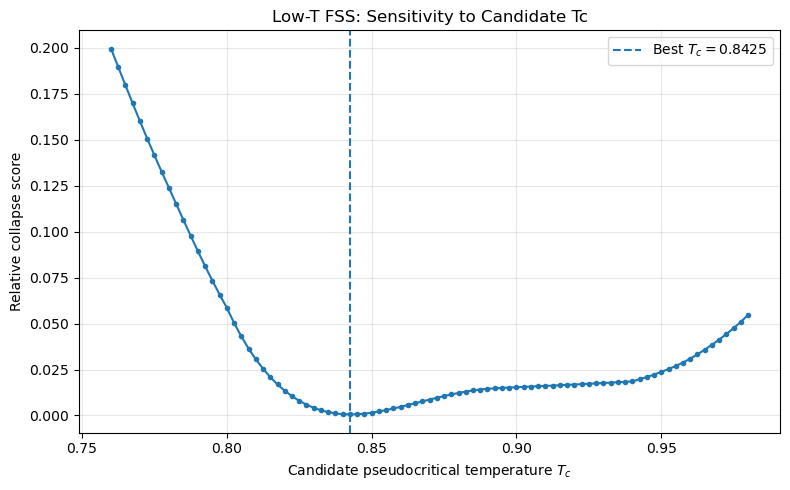

In [21]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD SAVED DATA
# ============================================================
filename = "clock_q5_binderresolvedsimulationInt4-16-64_data.npz"
data = np.load(filename)

T = np.asarray(data["T_values"], dtype=float)
Ls = np.asarray(data["L_values"], dtype=int)

chi_all = {
    L: np.asarray(data[f"L{L}_chi"], dtype=float)
    for L in Ls
}

# ============================================================
# 2. SELECT LOW-TEMPERATURE REGION
# ============================================================
mask = (T >= 0.80) & (T <= 0.95)
T_fit = T[mask]

chi_fit = {
    L: chi_all[L][mask]
    for L in Ls
}

if len(T_fit) < 3:
    raise ValueError("Fewer than three low-temperature points.")

if any(np.any(chi_fit[L] <= 0) for L in Ls):
    raise ValueError("All susceptibility values must be positive.")

print("Temperatures used:", T_fit)
print("Lattice sizes:", Ls)

# ============================================================
# 3. COLLAPSE SCORE
# ============================================================
def collapse_score(Tc, nu, gamma_over_nu):
    curves = []

    for L in Ls:
        x = (T_fit - Tc) * L**(1.0 / nu)
        y = chi_fit[L] / L**gamma_over_nu

        order = np.argsort(x)
        curves.append((x[order], y[order]))

    # Shared scaled-temperature interval
    x_low = max(curve[0][0] for curve in curves)
    x_high = min(curve[0][-1] for curve in curves)

    if x_high <= x_low:
        return np.inf

    # Compare all curves on the same x grid
    x_common = np.linspace(x_low, x_high, 100)

    y_curves = np.array([
        np.interp(x_common, x, y)
        for x, y in curves
    ])

    mean_y = np.mean(y_curves, axis=0)
    scale = np.mean(mean_y**2)

    if scale <= 1e-14:
        return np.inf

    # Mean relative spread across lattice sizes
    return np.mean(
        np.mean((y_curves - mean_y)**2, axis=0)
    ) / scale

# ============================================================
# 4. FORCE A STANDARD FSS PARAMETER SEARCH
# ============================================================
Tc_values = np.linspace(0.75, 1.00, 101)
nu_values = np.linspace(0.50, 2.50, 81)
gamma_values = np.linspace(0.50, 2.50, 81)

best_score = np.inf
best_parameters = None

for Tc in Tc_values:
    for nu in nu_values:
        for gamma_nu in gamma_values:
            score = collapse_score(Tc, nu, gamma_nu)

            if score < best_score:
                best_score = score
                best_parameters = (Tc, nu, gamma_nu)

Tc_best, nu_best, gamma_best = best_parameters

print("\n===== LOW-T FSS COLLAPSE =====")
print(f"Candidate pseudocritical Tc = {Tc_best:.5f}")
print(f"Effective nu                 = {nu_best:.5f}")
print(f"Effective gamma/nu           = {gamma_best:.5f}")
print(f"Relative collapse score      = {best_score:.6g}")

# ============================================================
# 5. PLOT COLLAPSED DATA — MARKERS ONLY
# ============================================================
markers = ['o', 's', '^', 'D', 'v']

plt.figure(figsize=(8, 6))

for i, L in enumerate(Ls):
    x = (T_fit - Tc_best) * L**(1.0 / nu_best)
    y = chi_fit[L] / L**gamma_best

    plt.plot(
        x, y,
        linestyle='None',
        marker=markers[i % len(markers)],
        markersize=8,
        label=f"L = {L}"
    )

plt.xlabel(r"$(T-T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi/L^{\gamma/\nu}$")
plt.title("q = 5 Clock Model: Forced Low-T FSS Collapse")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 6. PLOT SCORE VERSUS Tc
# Hold the best exponents fixed to inspect Tc sensitivity.
# ============================================================
scores_Tc = np.array([
    collapse_score(Tc, nu_best, gamma_best)
    for Tc in Tc_values
])

plt.figure(figsize=(8, 5))
plt.plot(Tc_values, scores_Tc, marker='o', markersize=3)
plt.axvline(Tc_best, linestyle='--',
            label=fr"Best $T_c={Tc_best:.4f}$")
plt.xlabel(r"Candidate pseudocritical temperature $T_c$")
plt.ylabel("Relative collapse score")
plt.title("Low-T FSS: Sensitivity to Candidate Tc")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Temperatures used: [0.8  0.87 0.94]
Lattice sizes: [16 24 32 48 64]

===== BKT-INSPIRED PRELIMINARY TEST =====
Candidate Tc = 0.95000
Fixed gamma/nu = 1.750
Collapse score = 0.00841766


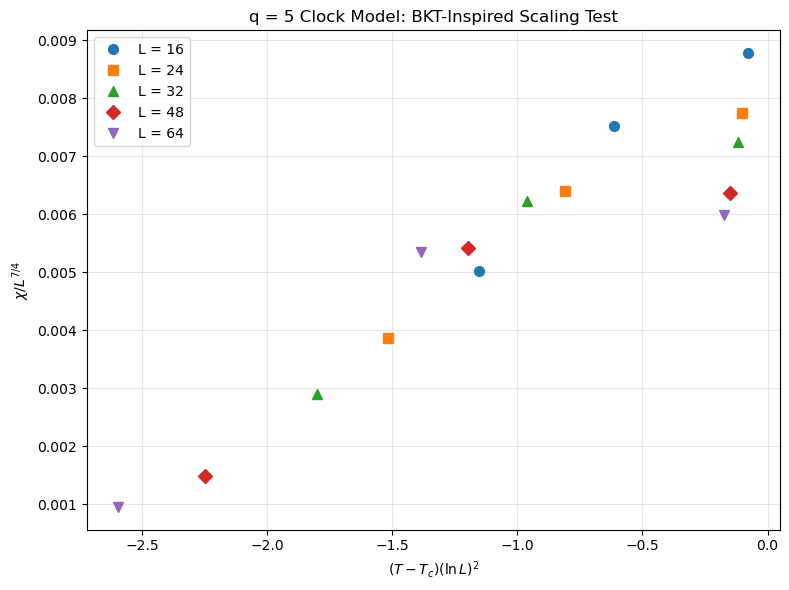

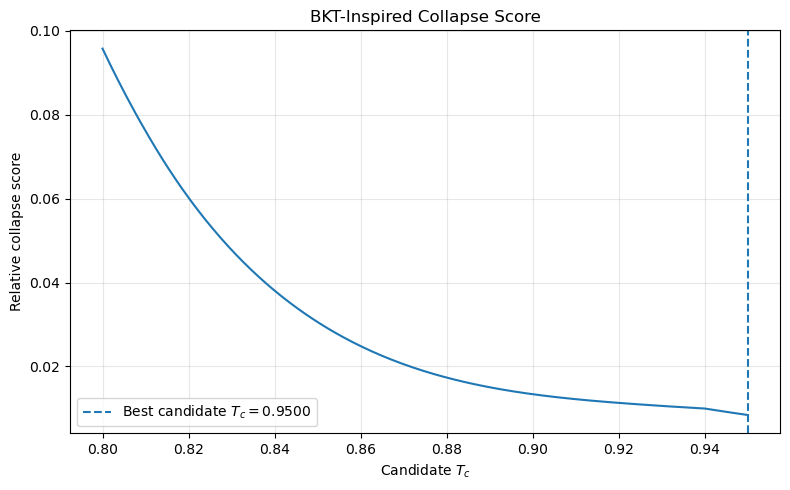

In [19]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD DATA
# ============================================================
filename = "clock_q5_binderresolvedsimulationInt4-16-64_data.npz"
data = np.load(filename)

T = np.asarray(data["T_values"], dtype=float)
Ls = np.asarray(data["L_values"], dtype=int)

chi_all = {
    L: np.asarray(data[f"L{L}_chi"], dtype=float)
    for L in Ls
}

# Select temperatures in the possible low-temperature region
mask = (T >= 0.80) & (T <= 0.95)
T_fit = T[mask]

chi_fit = {
    L: chi_all[L][mask]
    for L in Ls
}

print("Temperatures used:", T_fit)
print("Lattice sizes:", Ls)

if len(T_fit) < 3:
    raise ValueError("Fewer than three temperatures in selected region.")

# ============================================================
# BKT-INSPIRED SCALING
#
# x = (T - Tc) * (ln L)^2
# y = chi / L^(7/4)
#
# Assumes the candidate is the UPPER BKT transition.
# ============================================================
eta_c = 0.25
gamma_over_nu = 2.0 - eta_c

def bkt_collapse_score(T_values, L_values, chi_values, Tc):
    curves = []

    for L in L_values:
        x = (T_values - Tc) * np.log(L)**2
        y = chi_values[L] / L**gamma_over_nu

        order = np.argsort(x)
        curves.append((x[order], y[order]))

    # Only compare the region covered by every curve
    x_low = max(x[0] for x, y in curves)
    x_high = min(x[-1] for x, y in curves)

    if x_high <= x_low:
        return np.inf

    # Avoid scoring an extremely narrow overlap
    ranges = [x[-1] - x[0] for x, y in curves]
    if x_high - x_low < 0.25 * min(ranges):
        return np.inf

    x_common = np.linspace(x_low, x_high, 50)

    y_curves = np.array([
        np.interp(x_common, x, y)
        for x, y in curves
    ])

    mean_y = np.mean(y_curves, axis=0)
    denominator = np.mean(mean_y**2)

    if denominator <= 1e-14:
        return np.inf

    return (
        np.mean(np.mean((y_curves - mean_y)**2, axis=0))
        / denominator
    )

# ============================================================
# SCAN PSEUDOCRITICAL TEMPERATURE
# ============================================================
Tc_candidates = np.linspace(0.80, 0.95, 301)

scores = np.array([
    bkt_collapse_score(T_fit, Ls, chi_fit, Tc)
    for Tc in Tc_candidates
])

valid = np.isfinite(scores)

if not np.any(valid):
    raise ValueError(
        "No valid common scaled-temperature interval. "
        "Inspect the temperature grid and scaling ranges."
    )

best_index = np.argmin(scores)
Tc_best = Tc_candidates[best_index]
best_score = scores[best_index]

print("\n===== BKT-INSPIRED PRELIMINARY TEST =====")
print(f"Candidate Tc = {Tc_best:.5f}")
print(f"Fixed gamma/nu = {gamma_over_nu:.3f}")
print(f"Collapse score = {best_score:.6g}")

# ============================================================
# PLOT COLLAPSE: MARKERS ONLY
# ============================================================
markers = ['o', 's', '^', 'D', 'v']

plt.figure(figsize=(8, 6))

for i, L in enumerate(Ls):
    x = (T_fit - Tc_best) * np.log(L)**2
    y = chi_fit[L] / L**gamma_over_nu

    order = np.argsort(x)

    plt.plot(
        x[order], y[order],
        linestyle='None',
        marker=markers[i % len(markers)],
        markersize=7,
        label=f"L = {L}"
    )

plt.xlabel(r"$(T-T_c)(\ln L)^2$")
plt.ylabel(r"$\chi/L^{7/4}$")
plt.title("q = 5 Clock Model: BKT-Inspired Scaling Test")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# PLOT SCORE VS CANDIDATE Tc
# ============================================================
plt.figure(figsize=(8, 5))
plt.plot(Tc_candidates[valid], scores[valid])
plt.axvline(
    Tc_best, linestyle='--',
    label=fr"Best candidate $T_c={Tc_best:.4f}$"
)
plt.xlabel(r"Candidate $T_c$")
plt.ylabel("Relative collapse score")
plt.title("BKT-Inspired Collapse Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Temperatures: [0.8  0.87 0.94 1.01 1.08 1.15 1.22 1.29 1.36 1.43]
Lattice sizes: [16 24 32 48 64]


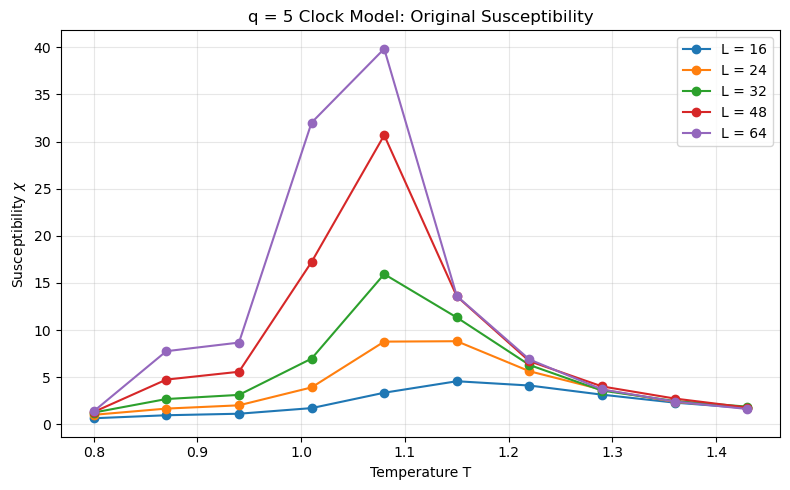


===== BEST CANDIDATE COLLAPSE =====
Tc           = 0.94500
nu           = 1.82000
gamma/nu     = 1.60000
Collapse score = 0.00459839


TypeError: cannot unpack non-iterable numpy.int32 object

<Figure size 800x600 with 0 Axes>

In [17]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD DATA
# ============================================================
filename = "clock_q5_binderresolvedsimulationInt4-16-64_data.npz"
data = np.load(filename)

T = np.asarray(data["T_values"], dtype=float)
Ls = np.asarray(data["L_values"], dtype=int)

chi = {
    L: np.asarray(data[f"L{L}_chi"], dtype=float)
    for L in Ls
}

print("Temperatures:", T)
print("Lattice sizes:", Ls)

for L in Ls:
    if len(chi[L]) != len(T):
        raise ValueError(f"Mismatch between T and L={L} susceptibility data.")
    if not np.all(np.isfinite(chi[L])) or np.any(chi[L] <= 0):
        raise ValueError(f"Invalid susceptibility values for L={L}.")

# ============================================================
# 2. PLOT ORIGINAL SUSCEPTIBILITY
# ============================================================
plt.figure(figsize=(8, 5))

for L in Ls:
    plt.plot(T, chi[L], "o-", label=f"L = {L}")

plt.xlabel("Temperature T")
plt.ylabel(r"Susceptibility $\chi$")
plt.title("q = 5 Clock Model: Original Susceptibility")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3. COLLAPSE SCORE
# x = (T - Tc) L^(1/nu)
# y = chi / L^(gamma/nu)
# ============================================================
def collapse_score(T, Ls, chi, Tc, nu, gamma_over_nu,
                   grid_points=100):

    curves = []

    for L in Ls:
        x = (T - Tc) * L**(1.0 / nu)
        y = chi[L] / L**gamma_over_nu

        order = np.argsort(x)
        curves.append((x[order], y[order]))

    # Require an overlapping scaled-x interval
    x_low = max(x[0] for x, y in curves)
    x_high = min(x[-1] for x, y in curves)

    if x_high <= x_low:
        return np.inf

    # Reject very narrow overlaps relative to the smallest
    # scaled-temperature range of any curve
    smallest_range = min(x[-1] - x[0] for x, y in curves)

    if x_high - x_low < 0.25 * smallest_range:
        return np.inf

    x_common = np.linspace(x_low, x_high, grid_points)

    y_curves = np.array([
        np.interp(x_common, x, y)
        for x, y in curves
    ])

    mean_y = np.mean(y_curves, axis=0)

    # Relative variance across lattice sizes
    denominator = np.mean(mean_y**2)

    if denominator <= 1e-14:
        return np.inf

    score = np.mean(
        np.mean((y_curves - mean_y)**2, axis=0)
    ) / denominator

    return score

# ============================================================
# 4. SCAN CANDIDATE PARAMETERS
# Use the full temperature array for this initial diagnostic.
# The search bounds are exploratory, not universal exponents.
# ============================================================
Tc_values = np.linspace(0.80, 1.15, 71)
nu_values = np.linspace(0.5, 2.0, 51)
gamma_values = np.linspace(0.5, 2.5, 61)

best_score = np.inf
best_parameters = None

for Tc in Tc_values:
    for nu in nu_values:
        for gamma_over_nu in gamma_values:

            score = collapse_score(
                T, Ls, chi, Tc, nu, gamma_over_nu
            )

            if score < best_score:
                best_score = score
                best_parameters = (Tc, nu, gamma_over_nu)

if best_parameters is None or not np.isfinite(best_score):
    raise ValueError(
        "No acceptable collapse found. Try a physically motivated "
        "temperature window or inspect the susceptibility data."
    )

Tc_best, nu_best, gamma_best = best_parameters

print("\n===== BEST CANDIDATE COLLAPSE =====")
print(f"Tc           = {Tc_best:.5f}")
print(f"nu           = {nu_best:.5f}")
print(f"gamma/nu     = {gamma_best:.5f}")
print(f"Collapse score = {best_score:.6g}")

# ============================================================
# 5. PLOT COLLAPSED DATA
# ============================================================
markers = ['o', 's', '^', 'D', 'v']
plt.figure(figsize=(8, 6))

for i, L in Ls:
    x = (T - Tc_best) * L**(1.0 / nu_best)
    y = chi[L] / L**gamma_best

    order = np.argsort(x)

    plt.plot(
        x[order], y[order],
        linestyle="None",
        marker=markers[i % len(markers)],
        markersize=6,
        label=f"L = {L}"
    )

plt.xlabel(r"$(T-T_c)L^{1/\nu}$")
plt.ylabel(r"$\chi/L^{\gamma/\nu}$")
plt.title("q = 5 Clock Model: Full-Grid Scaling Test")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


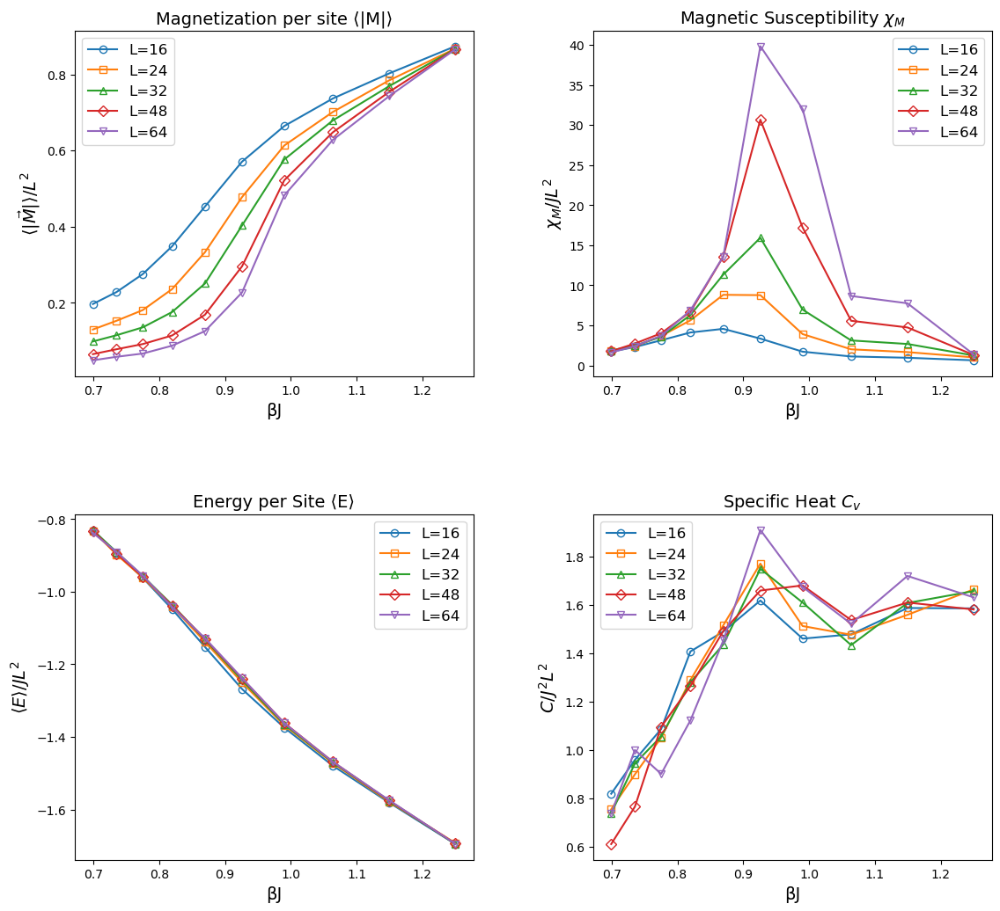

In [5]:

beta_values = 1/T_values
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility $χ_M$",
          "Energy per Site ⟨E⟩", "Specific Heat $C_v$"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(False)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockq5-stateLogGrid-16-64.pdf")
plt.show()


Slope (γ/ν) = 1.6121
Intercept = -2.9102
R² = 0.9899


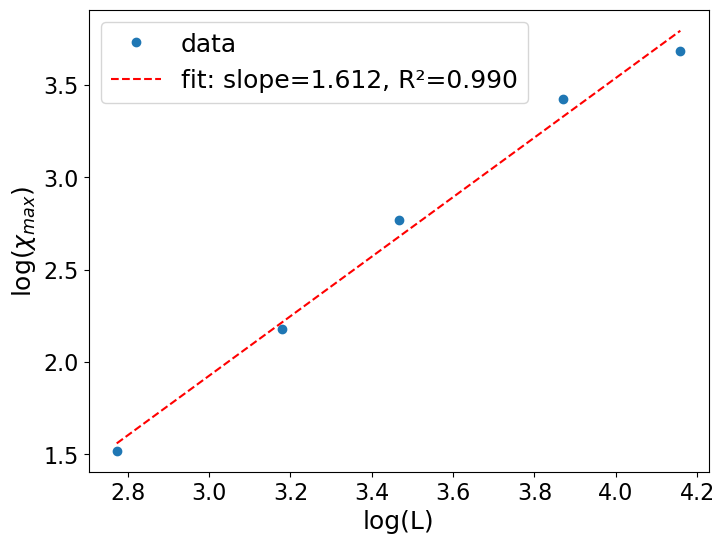

In [47]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(8,6))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)", fontsize = 18)
plt.ylabel("log($χ_{max}$)", fontsize = 18)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
#plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend(fontsize = 18)
#plt.grid(True)

#plt.savefig("FSSq3BinderResolvedLogFontSize-16-64.pdf")
plt.show()

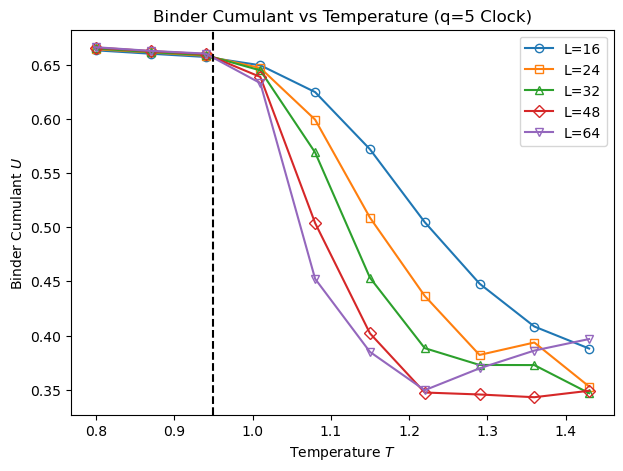

In [45]:
plt.figure(figsize=(7,5))
Tc = 0.95
markers = ['o', 's', '^', 'D', 'v']
for i,L in enumerate(L_values):
    plt.plot(T_values, results[L]["Binder"], marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=5 Clock)")
#plt.xlim(0.9,1.1)
#plt.xlim(0.9,1)
plt.axvline(Tc, linestyle = '--', linewidth = 1.5, color = 'black')
plt.savefig("BinderCumulantq5Clock.pdf")
plt.legend()
#plt.grid(True)
plt.show()

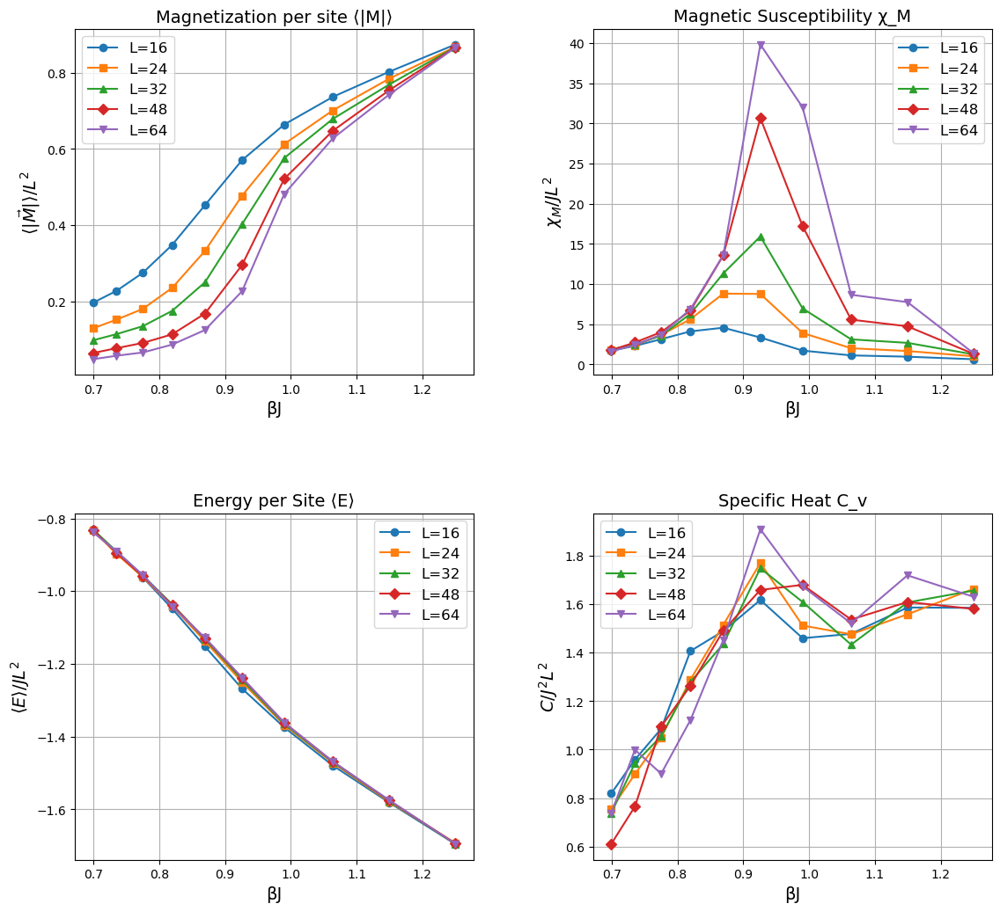

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockq5.2-state-16-64.pdf")
plt.show()


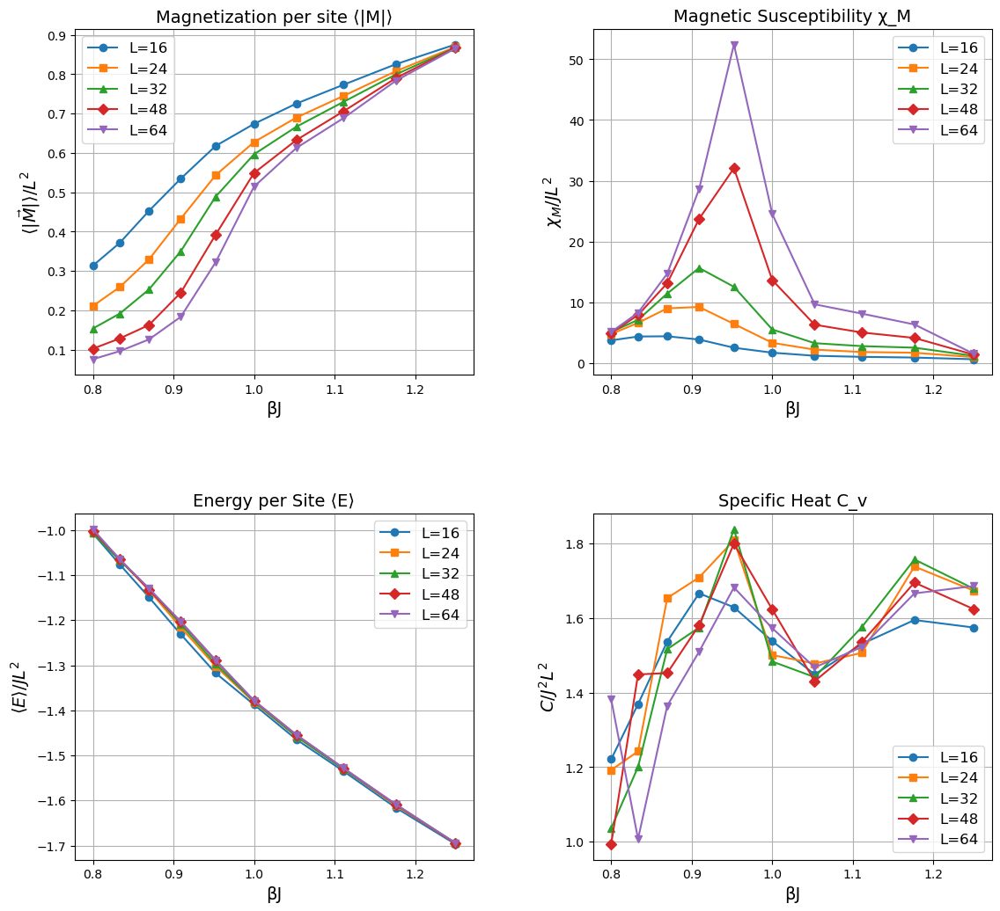

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockq5.1-state-16-64.pdf")
plt.show()


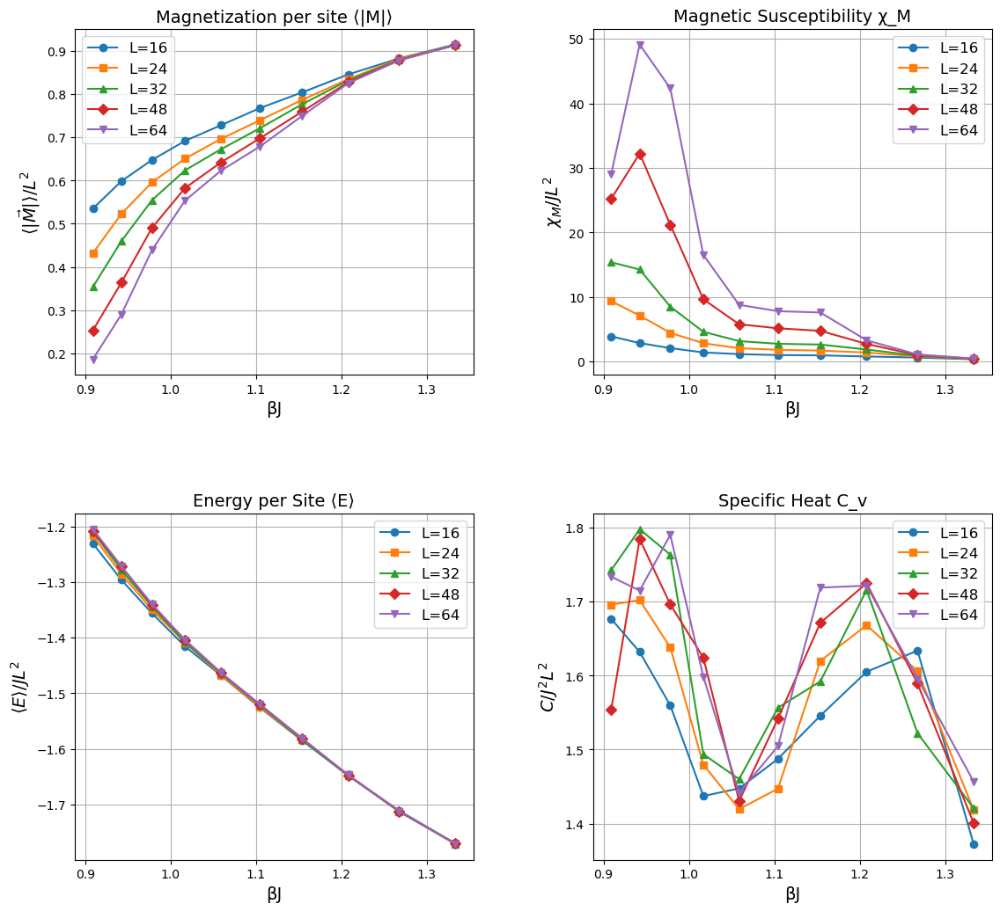

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockq5-state-16-64.pdf")
plt.show()


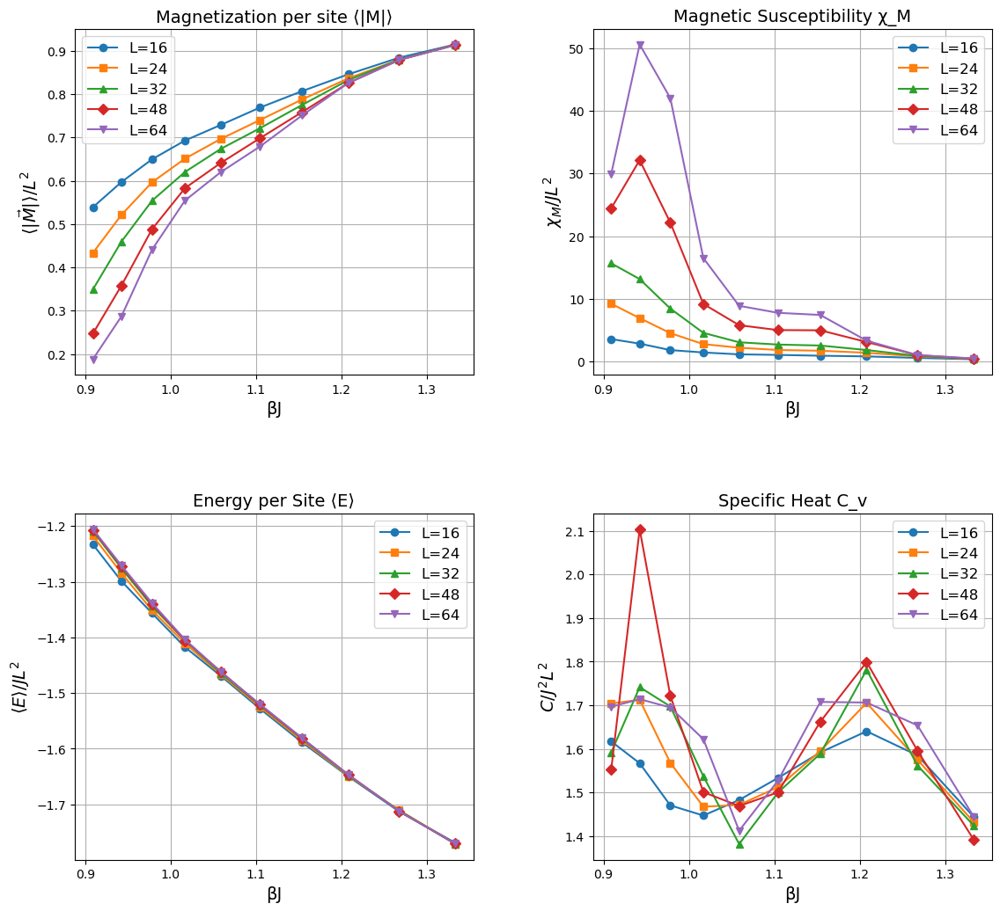

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)],
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockq5-state-16-64.pdf")
plt.show()


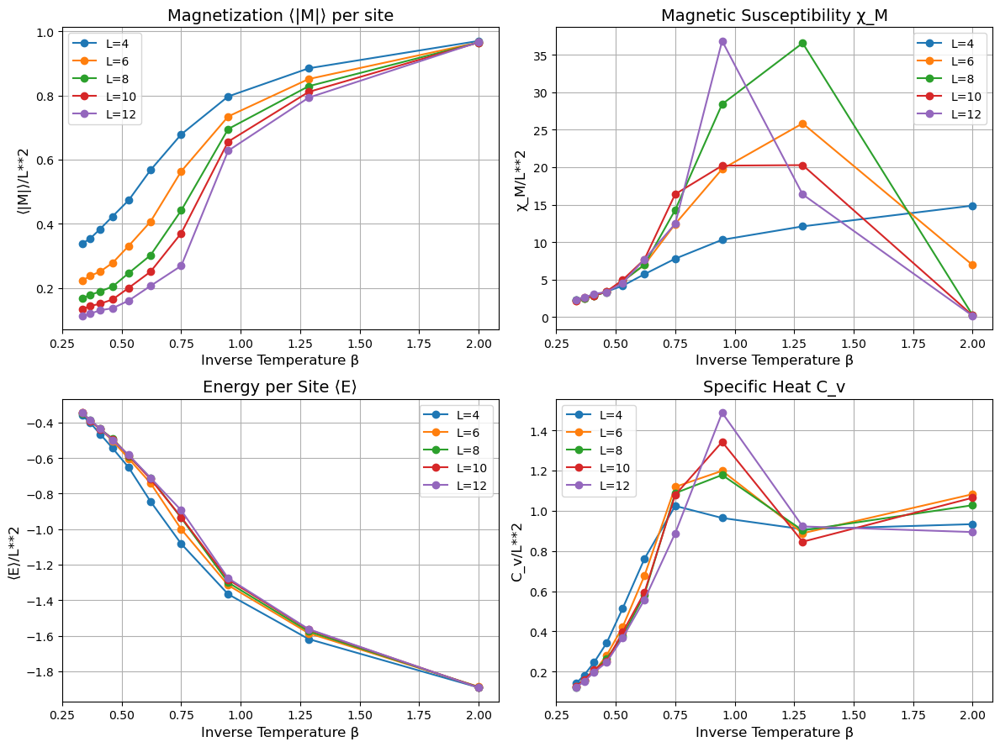

In [55]:

# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Titles and y-axis labels
titles = ["Magnetization ⟨|M|⟩ per site", "Magnetic Susceptibility χ_M",
         "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M|⟩/L**2", "χ_M/L**2", "⟨E⟩/L**2", "C_v/L**2"]

# Flatten axes array for easier indexing
axes = axes.flatten()

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")
    
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
 
    ax.legend()
    ax.grid(True)

# Adjust layout and show
plt.tight_layout()
plt.savefig('ResFuncfor5.pdf', format = 'pdf', bbox_inches = 'tight')
plt.show()

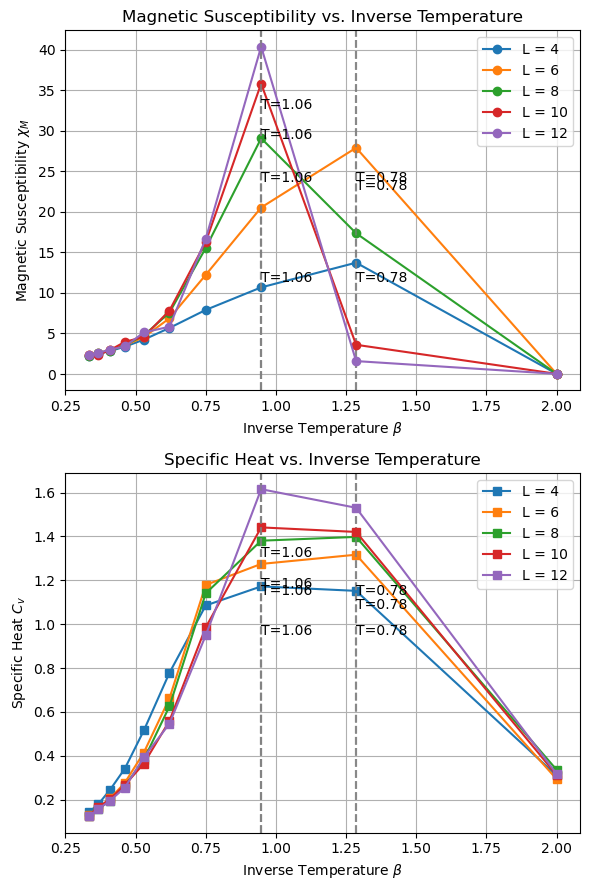

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Convert temperature values to inverse temperature (beta)
beta_values = 1 / T_values

# Create figure with two subplots
fig, axes = plt.subplots(2, 1, figsize=(6, 9))

for L in L_values:
    chi_M_vals = results[L]["chi_M"]
    C_v_vals = results[L]["C_v"]

    # Find peaks for transition points
    peaks_chi, _ = find_peaks(chi_M_vals)
    peaks_Cv, _ = find_peaks(C_v_vals)

    # Get transition points (sorted in increasing beta)
    transition_betas = sorted(beta_values[list(set(peaks_chi) | set(peaks_Cv))])
    transition_temps = [1/beta for beta in transition_betas]  # Convert beta back to T

    # Plot magnetic susceptibility
    axes[0].plot(beta_values, chi_M_vals, marker='o', label=f"L = {L}")
    for beta, T in zip(transition_betas, transition_temps):
        axes[0].axvline(beta, linestyle='dashed', color='gray', alpha=0.6)
        axes[0].text(beta, max(chi_M_vals)*0.8, f"T={T:.2f}", rotation=0, verticalalignment='bottom')

    # Plot specific heat
    axes[1].plot(beta_values, C_v_vals, marker='s', label=f"L = {L}")
    for beta, T in zip(transition_betas, transition_temps):
        axes[1].axvline(beta, linestyle='dashed', color='gray', alpha=0.6)
        axes[1].text(beta, max(C_v_vals)*0.8, f"T={T:.2f}", rotation=0, verticalalignment='bottom')

# Formatting
axes[0].set_xlabel(r"Inverse Temperature $\beta$")
axes[0].set_ylabel(r"Magnetic Susceptibility $\chi_M$")
axes[0].set_title("Magnetic Susceptibility vs. Inverse Temperature")
axes[0].legend()
axes[0].grid()

axes[1].set_xlabel(r"Inverse Temperature $\beta$") 
axes[1].set_ylabel(r"Specific Heat $C_v$")
axes[1].set_title("Specific Heat vs. Inverse Temperature")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()


ValueError: x and y must have same first dimension, but have shapes (10,) and (3,)

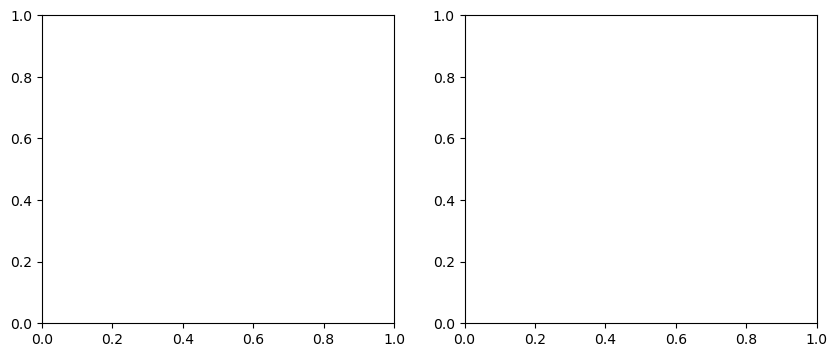

In [90]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Convert temperature values to inverse temperature (beta)
beta_values = 1 / T_values

# Create figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # Side-by-side, smaller size

for L in L_values:
    chi_M_vals = results[L]["chi_M"]
    C_v_vals = results[L]["C_v"]

    # Find peaks for transition points
    peaks_chi, _ = find_peaks(chi_M_vals)
    peaks_Cv, _ = find_peaks(C_v_vals)

    # Get transition points (sorted in increasing beta)
    transition_betas = sorted(beta_values[list(set(peaks_chi) | set(peaks_Cv))])
    transition_temps = [1/beta for beta in transition_betas]  # Convert beta back to T

    # Plot magnetic susceptibility
    axes[0].plot(beta_values, chi_M_vals, marker='o', linestyle='-', label=f"L = {L}")
    for beta, T in zip(transition_betas, transition_temps):
        axes[0].axvline(beta, linestyle='dashed', color='gray', alpha=0.6)
        axes[0].text(beta, max(chi_M_vals) * 0.8, f"T={T:.2f}", rotation=90, verticalalignment='bottom', fontsize=9)

    # Plot specific heat
    axes[1].plot(beta_values, C_v_vals, marker='s', linestyle='-', label=f"L = {L}")
    for beta, T in zip(transition_betas, transition_temps):
        axes[1].axvline(beta, linestyle='dashed', color='gray', alpha=0.6)
        axes[1].text(beta, max(C_v_vals) * 0.8, f"T={T:.2f}", rotation=90, verticalalignment='bottom', fontsize=9)

# Formatting
axes[0].set_xlabel(r"Inverse Temperature $\beta = 1/T$")
axes[0].set_ylabel(r"Magnetic Susceptibility $\chi_M$")
axes[0].set_title("Magnetic Susceptibility vs. Inverse Temperature")
axes[0].legend(fontsize=9)
axes[0].grid()

axes[1].set_xlabel(r"Inverse Temperature $\beta = 1/T$")
axes[1].set_ylabel(r"Specific Heat $C_v$")
axes[1].set_title("Specific Heat vs. Inverse Temperature")
axes[1].legend(fontsize=9)
axes[1].grid()

plt.tight_layout()
plt.show()


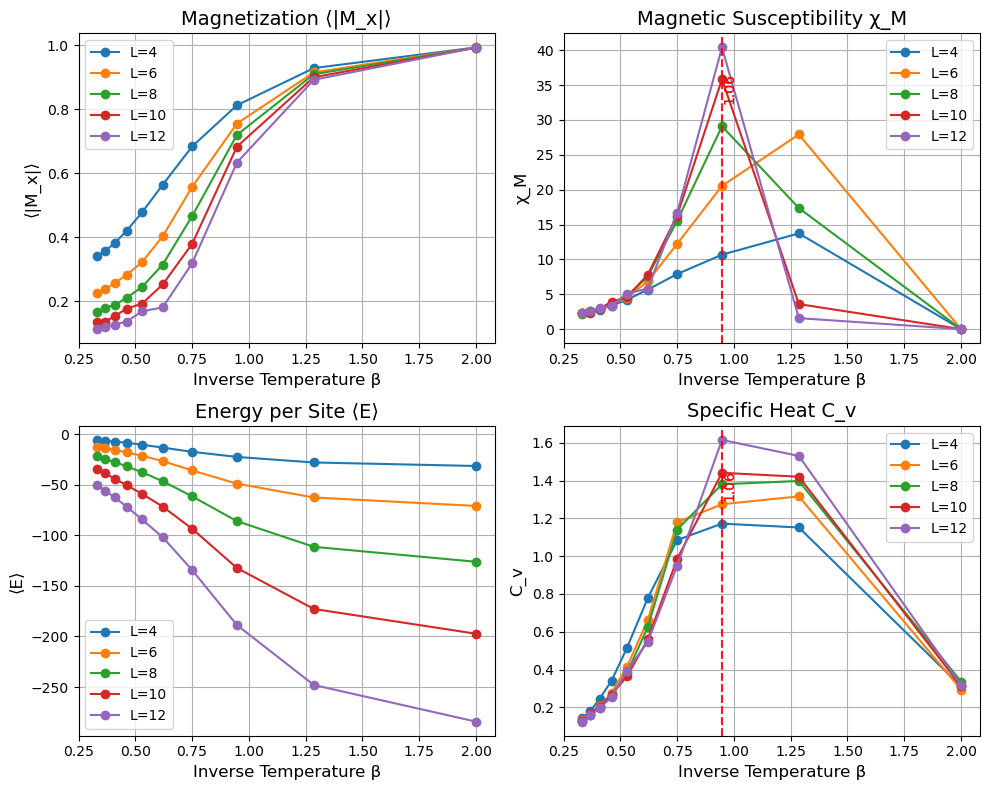

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Convert temperature values to inverse temperature (beta)
beta_values = 1 / T_values

# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

axes = axes.flatten()  # Flatten axes array for easier indexing

# Detect two transition points
chi_M_peaks, _ = find_peaks(results[L_values[-1]]["chi_M"])
Cv_peaks, _ = find_peaks(results[L_values[-1]]["C_v"])

# If two peaks exist, use them. Otherwise, approximate second transition
transition_betas = []

# First transition from χ_M
if len(chi_M_peaks) > 0:
    transition_betas.append(beta_values[chi_M_peaks[0]])  # First peak in χ_M

# Second transition from C_v
if len(Cv_peaks) > 0:
    transition_betas.append(beta_values[Cv_peaks[0]])  # First peak in C_v
elif len(chi_M_peaks) > 1:  
    transition_betas.append(beta_values[chi_M_peaks[1]])  # Use second χ_M peak if no C_v peak

# Ensure we have two transition points
if len(transition_betas) < 2:
    # Approximate second transition using the inflection point of |M|
    dM_dT = np.gradient(results[L_values[-1]]["M_x"])
    inflection_index = np.argmax(np.abs(np.gradient(dM_dT)))  
    transition_betas.append(beta_values[inflection_index])

# Sort transition betas
transition_betas = sorted(transition_betas)

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

    # Only mark transitions in χ_M and C_v plots
    if key in ["chi_M", "C_v"]:
        for beta in transition_betas:
            ax.axvline(x=beta, color='r', linestyle='--', alpha=0.7)
            ax.text(beta, max(results[L_values[-1]][key]) * 0.8, f"{1/beta:.2f}", 
                    rotation=90, verticalalignment='bottom', fontsize=10, color='red')

# Adjust layout and show
plt.tight_layout()
plt.show()


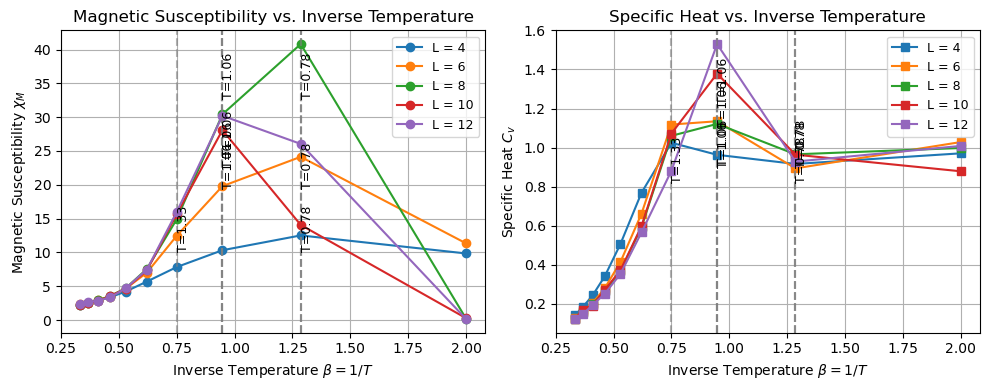

In [86]:
from scipy.signal import find_peaks

# Convert temperature values to inverse temperature (beta)
beta_values = 1 / T_values

# Create figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # Side-by-side, smaller size

for L in L_values:
    chi_M_vals = results[L]["chi_M"]
    C_v_vals = results[L]["C_v"]

    # Find peaks for transition points
    peaks_chi, _ = find_peaks(chi_M_vals)
    peaks_Cv, _ = find_peaks(C_v_vals)

    # Get transition points (sorted in increasing beta)
    transition_betas = sorted(beta_values[list(set(peaks_chi) | set(peaks_Cv))])
    transition_temps = [1/beta for beta in transition_betas]  # Convert beta back to T

    # Plot magnetic susceptibility
    axes[0].plot(beta_values, chi_M_vals, marker='o', linestyle='-', label=f"L = {L}")
    for beta, T in zip(transition_betas, transition_temps):
        axes[0].axvline(beta, linestyle='dashed', color='gray', alpha=0.6)
        axes[0].text(beta, max(chi_M_vals) * 0.8, f"T={T:.2f}", rotation=90, verticalalignment='bottom', fontsize=9)

    # Plot specific heat
    axes[1].plot(beta_values, C_v_vals, marker='s', linestyle='-', label=f"L = {L}")
    for beta, T in zip(transition_betas, transition_temps):
        axes[1].axvline(beta, linestyle='dashed', color='gray', alpha=0.6)
        axes[1].text(beta, max(C_v_vals) * 0.8, f"T={T:.2f}", rotation=90, verticalalignment='bottom', fontsize=9)

# Formatting
axes[0].set_xlabel(r"Inverse Temperature $\beta = 1/T$")
axes[0].set_ylabel(r"Magnetic Susceptibility $\chi_M$")
axes[0].set_title("Magnetic Susceptibility vs. Inverse Temperature")
axes[0].legend(fontsize=9)
axes[0].grid()

axes[1].set_xlabel(r"Inverse Temperature $\beta = 1/T$")
axes[1].set_ylabel(r"Specific Heat $C_v$")
axes[1].set_title("Specific Heat vs. Inverse Temperature")
axes[1].legend(fontsize=9)
axes[1].grid()

plt.tight_layout()
plt.show()


### Four Response Functions of q=6 state clock model

In [88]:

# Parameters
q = 6   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
steps = 10**6  # Total Monte Carlo steps
burn_in = 200000
L_values = [4, 6, 8, 10, 12]  # Different lattice sizes to test
T_values = np.linspace(0.5, 3.0, 10)  # Temperature range

# Function to compute measure frequency
def measure_every(L):
    return L**2

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles

# Compute total magnetization (vector)
def compute_magnetization(sigma, L):
    return  np.sum(sigma, axis=(0, 1)) / (L * L)  # Normalize per spin

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta, L):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta) / 2  # Avoid double counting
        H -= np.dot(h, sigma[i, j]) # External field term
    return H

# Monte Carlo Step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)  # Pick a random site
    new_spin = np.random.randint(0, q)  # Pick a new random spin state
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    old_angle = angles[i, j]  # Current angle
    old_sigma = sigma[i, j]   # Current spin vector

    # Define neighbor sites with periodic boundaries
    neighbor_sites = [( (i+1) % L, j ), ( (i-1) % L, j ), ( i, (j+1) % L ), ( i, (j-1) % L )]

    # Compute old and new energy
    E_old = -J * sum(np.cos(old_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 
    E_new = -J * sum(np.cos(new_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 

    # Add external field term
    E_old -= np.dot(h, old_sigma)
    E_new -= np.dot(h, new_sigma)

    # Compute ΔE
    dE = E_new - E_old  

    # Compute acceptance probability (Glauber or Metropolis)
    beta = 1 / T
    P_accept = 1 / (1 + np.exp(beta * dE)) if update_rule == "glauber" else min(1, np.exp(-beta * dE))

    # Accept or reject the update
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma  # Update spin vector

# Run simulation
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []  # List to store magnetization vectors
    E_vals = []
    # Adjust burn-in dynamically based on system size
    burn_in = 500000 if L >= 10 else 200000  # More steps for large L

    # Pre-thermalization (Burn-in)
    for _ in range(burn_in):  
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)  # [M_x, M_y]
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)  # Convert list to NumPy array
    E_vals = np.array(E_vals)
   # Mean magnetization vector
    m_avg = np.mean(m_vals, axis=0)  # ⟨M_x⟩, ⟨M_y⟩
   
    # Compute mean magnitude of magnetization
    mod_m_avg = np.mean(np.linalg.norm(m_vals, axis=1))  # ⟨|M|⟩
    m_sq_avg = np.mean(np.linalg.norm(m_vals, axis=1)**2)  # ⟨|M|^2⟩
    m_avg_sq = np.linalg.norm(np.mean(m_vals, axis=0))**2  # ⟨|M|⟩^2
    #avg_sq_mod_m = np.square(np.linalg.norm(m_avg))
    # Compute ⟨M⟩ ⋅ ⟨M⟩
    #m_avg_sq = np.dot(m_avg, m_avg)  # ⟨M⟩ ⋅ ⟨M⟩
    # Compute ⟨M ⋅ M⟩
    #m_sq_avg = np.mean(np.sum(m_vals**2, axis=1))   # ⟨M ⋅ M⟩

    # Susceptibility (corrected formula)
    chi_M = (m_sq_avg - m_avg_sq) * (L * L)

    # Energy calculations
    E_avg = np.mean(E_vals)
  
    E_sq_avg = np.mean(np.square(E_vals))
    
    # Heat capacity
    C_v = (E_sq_avg - E_avg**2) / (L**2 * T**2)

    return mod_m_avg, chi_M, C_v, E_avg

# Run simulations for different lattice sizes and temperatures
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        mod_m_avg, chi_M, C_v, E_avg = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(mod_m_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg)


Running simulations for T=0.50 (Beta=2.00)...
Running simulations for T=0.78 (Beta=1.29)...
Running simulations for T=1.06 (Beta=0.95)...


KeyboardInterrupt: 

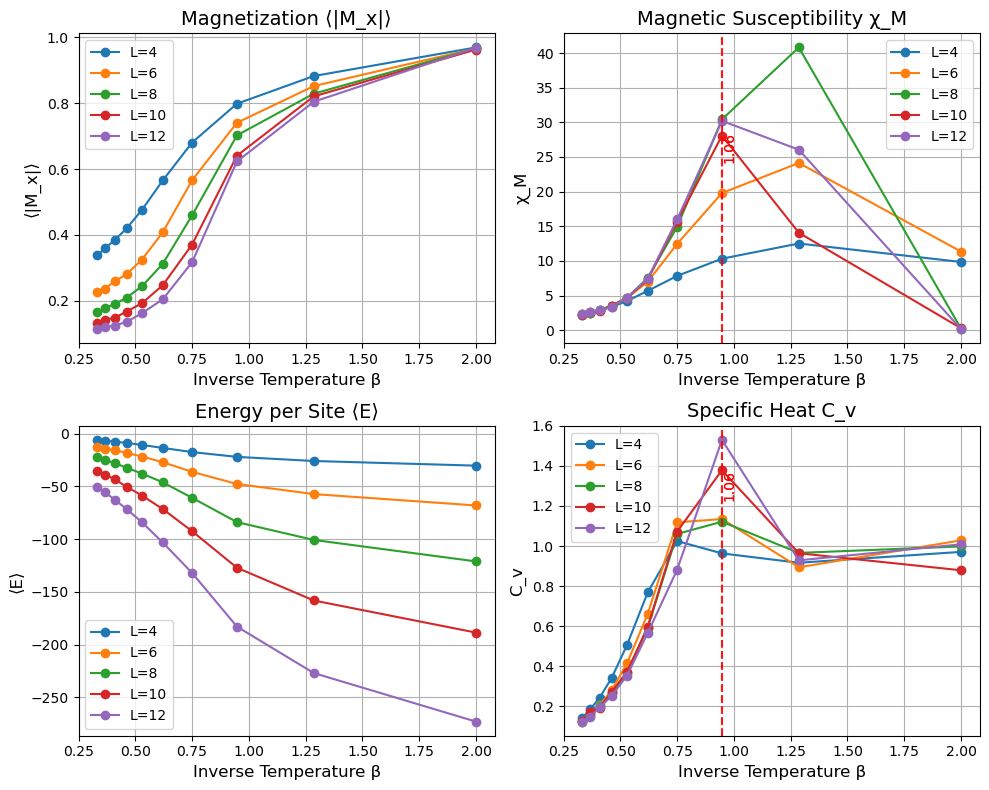

In [84]:
from scipy.signal import find_peaks

# Convert temperature values to inverse temperature (beta)
beta_values = 1 / T_values

# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

axes = axes.flatten()  # Flatten axes array for easier indexing

# Detect two transition points
chi_M_peaks, _ = find_peaks(results[L_values[-1]]["chi_M"])
Cv_peaks, _ = find_peaks(results[L_values[-1]]["C_v"])

# If two peaks exist, use them. Otherwise, approximate second transition
transition_betas = []

# First transition from χ_M
if len(chi_M_peaks) > 0:
    transition_betas.append(beta_values[chi_M_peaks[0]])  # First peak in χ_M

# Second transition from C_v
if len(Cv_peaks) > 0:
    transition_betas.append(beta_values[Cv_peaks[0]])  # First peak in C_v
elif len(chi_M_peaks) > 1:  
    transition_betas.append(beta_values[chi_M_peaks[1]])  # Use second χ_M peak if no C_v peak

# Ensure we have two transition points
if len(transition_betas) < 2:
    # Approximate second transition using the inflection point of |M|
    dM_dT = np.gradient(results[L_values[-1]]["M_x"])
    inflection_index = np.argmax(np.abs(np.gradient(dM_dT)))  
    transition_betas.append(beta_values[inflection_index])

# Sort transition betas
transition_betas = sorted(transition_betas)

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

    # Only mark transitions in χ_M and C_v plots
    if key in ["chi_M", "C_v"]:
        for beta in transition_betas:
            ax.axvline(x=beta, color='r', linestyle='--', alpha=0.7)
            ax.text(beta, max(results[L_values[-1]][key]) * 0.8, f"{1/beta:.2f}", 
                    rotation=90, verticalalignment='bottom', fontsize=10, color='red')

# Adjust layout and show
plt.tight_layout()
plt.show()


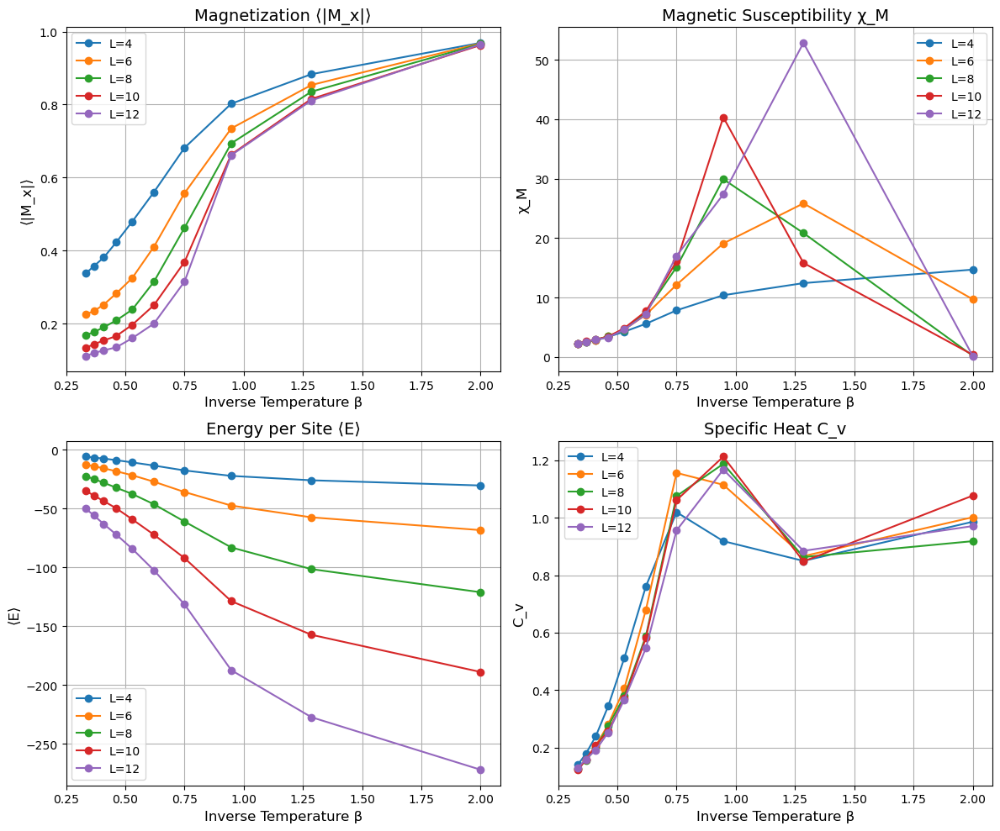

In [45]:
beta_values = 1/T_values
# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Titles and y-axis labels
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
         "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

# Flatten axes array for easier indexing
axes = axes.flatten()

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")
    
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

# Adjust layout and show
plt.tight_layout()
plt.show()

### Four Response Functions of q=7 state clock model

In [5]:

# Parameters
q = 7   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
steps = 10**6  # Total Monte Carlo steps
burn_in = 200000
L_values = [4, 6, 8, 10, 12]  # Different lattice sizes to test
T_values = np.linspace(0.5, 3.0, 10)  # Temperature range

# Function to compute measure frequency
def measure_every(L):
    return L**2

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles

# Compute total magnetization (vector)
def compute_magnetization(sigma, L):
    return  np.sum(sigma, axis=(0, 1)) / (L * L)  # Normalize per spin

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta, L):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta) / 2  # Avoid double counting
        H -= np.dot(h, sigma[i, j]) # External field term
    return H

# Monte Carlo Step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)  # Pick a random site
    new_spin = np.random.randint(0, q)  # Pick a new random spin state
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    old_angle = angles[i, j]  # Current angle
    old_sigma = sigma[i, j]   # Current spin vector

    # Define neighbor sites with periodic boundaries
    neighbor_sites = [( (i+1) % L, j ), ( (i-1) % L, j ), ( i, (j+1) % L ), ( i, (j-1) % L )]

    # Compute old and new energy
    E_old = -J * sum(np.cos(old_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 
    E_new = -J * sum(np.cos(new_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 

    # Add external field term
    E_old -= np.dot(h, old_sigma)
    E_new -= np.dot(h, new_sigma)

    # Compute ΔE
    dE = E_new - E_old  

    # Compute acceptance probability (Glauber or Metropolis)
    beta = 1 / T
    P_accept = 1 / (1 + np.exp(beta * dE)) if update_rule == "glauber" else min(1, np.exp(-beta * dE))

    # Accept or reject the update
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma  # Update spin vector

# Run simulation
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []  # List to store magnetization vectors
    E_vals = []
    # Adjust burn-in dynamically based on system size
    burn_in = 500000 if L >= 10 else 200000  # More steps for large L

    # Pre-thermalization (Burn-in)
    for _ in range(burn_in):  
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)  # [M_x, M_y]
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)  # Convert list to NumPy array
    E_vals = np.array(E_vals)
   # Mean magnetization vector
    m_avg = np.mean(m_vals, axis=0)  # ⟨M_x⟩, ⟨M_y⟩
   
    # Compute mean magnitude of magnetization
    mod_m_avg = np.mean(np.linalg.norm(m_vals, axis=1))  # ⟨|M|⟩
    m_sq_avg = np.mean(np.linalg.norm(m_vals, axis=1)**2)  # ⟨|M|^2⟩
    m_avg_sq = np.linalg.norm(np.mean(m_vals, axis=0))**2  # ⟨|M|⟩^2
    #avg_sq_mod_m = np.square(np.linalg.norm(m_avg))
    # Compute ⟨M⟩ ⋅ ⟨M⟩
    #m_avg_sq = np.dot(m_avg, m_avg)  # ⟨M⟩ ⋅ ⟨M⟩
    # Compute ⟨M ⋅ M⟩
    #m_sq_avg = np.mean(np.sum(m_vals**2, axis=1))   # ⟨M ⋅ M⟩

    # Susceptibility (corrected formula)
    chi_M = (m_sq_avg - m_avg_sq) * (L * L)

    # Energy calculations
    E_avg = np.mean(E_vals)
  
    E_sq_avg = np.mean(np.square(E_vals))
    
    # Heat capacity
    C_v = (E_sq_avg - E_avg**2) / (L**2 * T**2)

    return mod_m_avg, chi_M, C_v, E_avg

# Run simulations for different lattice sizes and temperatures
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        mod_m_avg, chi_M, C_v, E_avg = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(mod_m_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg)


Running simulations for T=0.50 (Beta=2.00)...
Running simulations for T=0.78 (Beta=1.29)...
Running simulations for T=1.06 (Beta=0.95)...
Running simulations for T=1.33 (Beta=0.75)...
Running simulations for T=1.61 (Beta=0.62)...
Running simulations for T=1.89 (Beta=0.53)...
Running simulations for T=2.17 (Beta=0.46)...
Running simulations for T=2.44 (Beta=0.41)...
Running simulations for T=2.72 (Beta=0.37)...
Running simulations for T=3.00 (Beta=0.33)...


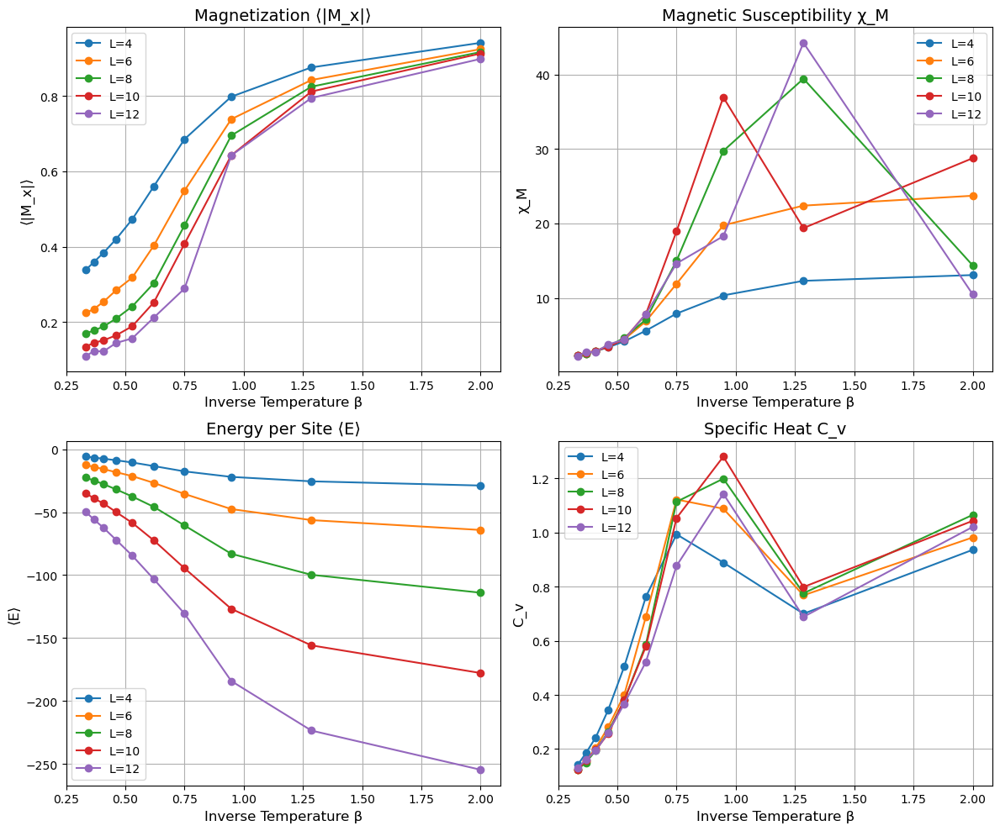

In [7]:
beta_values = 1/T_values
# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Titles and y-axis labels
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
         "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

# Flatten axes array for easier indexing
axes = axes.flatten()

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")
    
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.set_ylim([0,1])
    ax.legend()
    ax.grid(True)

# Adjust layout and show
plt.tight_layout()
plt.show()

### Four Response Functions of q=8 state clock model

In [9]:


data = np.load("clock_q8_16-64_data.npz")

print("Variables stored in NPZ:")
print(data.files)


Variables stored in NPZ:
['T_values', 'L_values', 'L16_M', 'L16_chi', 'L16_E', 'L16_Cv', 'L16_Binder', 'L24_M', 'L24_chi', 'L24_E', 'L24_Cv', 'L24_Binder', 'L32_M', 'L32_chi', 'L32_E', 'L32_Cv', 'L32_Binder', 'L48_M', 'L48_chi', 'L48_E', 'L48_Cv', 'L48_Binder', 'L64_M', 'L64_chi', 'L64_E', 'L64_Cv', 'L64_Binder']


In [53]:

q = 8
J = 1.0
h = np.array([0, 0])  # External field
#delta = 0  # Chirality term
sweeps = 5*10**4 
# ============================================================
# PRECOMPUTATIONS
# ============================================================

ANGLES = 2 * np.pi * np.arange(q) / q
COS = np.cos(ANGLES)
SIN = np.sin(ANGLES)

# cos(theta_i - theta_j)
COS_DIFF = np.zeros((q, q))
for i in range(q):
    for j in range(q):
        COS_DIFF[i, j] = np.cos(ANGLES[i] - ANGLES[j])

# ------------------------------------------------------------
# PRECOMPUTE DELTA (CRITICAL FOR SPEED)
# Δ = cos(si - sj) - cos(si_ref - sj)
# ------------------------------------------------------------

DELTA = np.zeros((q, q, q))

for r in range(q):
    for si in range(q):
        si_ref = (2*r - si) % q
        for sj in range(q):
            DELTA[r, si, sj] = COS_DIFF[si, sj] - COS_DIFF[si_ref, sj]

# ============================================================
# INITIAL STATE
# ============================================================

def new_state(L):
    return np.random.randint(0, q, size=(L, L))

# ============================================================
# TOTAL ENERGY (ONLY ONCE)
# ============================================================

def total_energy(spins):
    L = spins.shape[0]
    E = 0.0

    for x in range(L):
        for y in range(L):
            s = spins[x, y]
            s_right = spins[(x+1) % L, y]
            s_up = spins[x, (y+1) % L]

            E += -J * COS_DIFF[s, s_right]
            E += -J * COS_DIFF[s, s_up]

    return E

# ============================================================
# INITIAL MAGNETIZATION
# ============================================================

def magnetization(spins):
    Mx = np.sum(COS[spins])
    My = np.sum(SIN[spins])
    return Mx, My

# ============================================================
# WOLFF CLUSTER UPDATE (GENERAL q)
# ============================================================

def wolff_cluster(spins, beta, E_current, visited):

    L = spins.shape[0]
    visited.fill(False)

    # random reflection axis
    r = np.random.randint(0, q)

    # random seed
    x0 = np.random.randint(L)
    y0 = np.random.randint(L)

    stack = [(x0, y0)]
    visited[x0, y0] = True

    cluster = []

    dE = 0.0
    dMx = 0.0
    dMy = 0.0

    # ------------------------------------------------
    # GROW CLUSTER
    # ------------------------------------------------
    while stack:
        x, y = stack.pop()
        cluster.append((x, y))

        si = spins[x, y]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:

                sj = spins[nx, ny]
                delta = DELTA[r, si, sj]

                if delta > 0:
                    p = 1 - np.exp(-beta * J * delta)

                    if np.random.rand() < p:
                        visited[nx, ny] = True
                        stack.append((nx, ny))

    # ------------------------------------------------
    # ENERGY CHANGE (BOUNDARY ONLY)
    # ------------------------------------------------
    for x, y in cluster:

        si = spins[x, y]

        for nx, ny in (
            ((x+1) % L, y),
            ((x-1) % L, y),
            (x, (y+1) % L),
            (x, (y-1) % L),
        ):
            if not visited[nx, ny]:
                sj = spins[nx, ny]
                dE += J * DELTA[r, si, sj]

    # ------------------------------------------------
    # FLIP CLUSTER + MAGNETIZATION UPDATE
    # ------------------------------------------------
    for x, y in cluster:

        si = spins[x, y]
        si_ref = (2*r - si) % q

        dMx += COS[si_ref] - COS[si]
        dMy += SIN[si_ref] - SIN[si]

        spins[x, y] = si_ref

    return E_current + dE, dMx, dMy

# ============================================================
# GLOBAL ROTATION (ERGODICITY)
# ============================================================

def global_rotate(spins):
    r = np.random.randint(0, q)
    spins[:] = (spins + r) % q
    return r

# ============================================================
# MAIN SIMULATION
# ============================================================

def run_simulation(
    L,
    T,
    sweeps=5*10**4,
    J=J,
    burn_frac=0.2
):

    beta = 1.0 / T

    spins = new_state(L)
    visited = np.zeros((L, L), dtype=bool)

    E = total_energy(spins)
    Mx, My = magnetization(spins)

    burn_steps = int(burn_frac * sweeps)

    M_samples = []
    E_samples = []

    for sweep in range(sweeps):

        # --- Wolff update
        E, dMx, dMy = wolff_cluster(spins, beta, E, visited)
        Mx += dMx
        My += dMy

        # --- Global rotation
        r = global_rotate(spins)

        c = COS[r]
        s = SIN[r]
        Mx, My = Mx * c - My * s, Mx * s + My * c

        # --- Measurements
        if sweep >= burn_steps:
            M_samples.append(np.sqrt(Mx**2 + My**2))
            E_samples.append(E)

    # ------------------------------------------------
    # OBSERVABLES
    # ------------------------------------------------
    E_arr = np.array(E_samples)
    M_arr = np.array(M_samples)

    N = L * L

    E_avg = np.mean(E_arr)
    E_sq_avg = np.mean(E_arr**2)

    M_mean = np.mean(M_arr)
    M2_mean = np.mean(M_arr**2)
    M4_mean = np.mean(M_arr**4)

    U = 1 - M4_mean / (3 * (M2_mean**2))

    C_v = (E_sq_avg - E_avg**2) / (N * T**2)
    chi_M = (M2_mean - M_mean**2) / (N * T)

    return M_mean / N, chi_M, E_avg / N, C_v, U

In [55]:
import time
# --- Storage ---
results = {
    L: {
        "M": [],
        "chi": [],
        "E": [],
        "Cv": [],
        "Binder": []
    }
    for L in L_values
}

# --- Loop over sizes and temperatures ---
for L in L_values:
    print(f"\nRunning simulations for L = {L}")

    for T in T_values:
        start_time = time.time()

        M, chi, E, Cv, U = run_simulation(
            L, T,
            sweeps=sweeps,
            J=J,
            burn_frac=0.3
        )

        results[L]["M"].append(M)
        results[L]["chi"].append(chi)
        results[L]["E"].append(E)
        results[L]["Cv"].append(Cv)
        results[L]["Binder"].append(U)

        elapsed = time.time() - start_time
        print(f"T = {T:.3f} | U = {U:.4f} | time = {elapsed/60:.2f} min")


for L in L_values:
    for key in results[L]:
        results[L][key] = np.array(results[L][key])
        
save_dict = {
    "T_values": np.array(T_values),
    "L_values": np.array( L_values)
}

for L in L_values:
    for key in results[L]:
        save_dict[f"L{L}_{key}"] = results[L][key]

np.savez_compressed("clock_q8_16-64_data.npz", **sav e_dict)

print("\nData saved successfully.")


Running simulations for L = 16
T = 0.800 | U = 0.6630 | time = 1.00 min
T = 0.870 | U = 0.6604 | time = 0.75 min
T = 0.940 | U = 0.6563 | time = 0.58 min
T = 1.010 | U = 0.6445 | time = 0.44 min
T = 1.080 | U = 0.6154 | time = 0.32 min
T = 1.150 | U = 0.5604 | time = 0.25 min
T = 1.220 | U = 0.4946 | time = 0.21 min
T = 1.290 | U = 0.4394 | time = 0.21 min
T = 1.360 | U = 0.4070 | time = 0.11 min
T = 1.430 | U = 0.3782 | time = 0.08 min

Running simulations for L = 24
T = 0.800 | U = 0.6628 | time = 1.26 min
T = 0.870 | U = 0.6606 | time = 1.27 min
T = 0.940 | U = 0.6565 | time = 0.94 min
T = 1.010 | U = 0.6395 | time = 0.83 min
T = 1.080 | U = 0.5778 | time = 0.65 min
T = 1.150 | U = 0.4952 | time = 0.34 min
T = 1.220 | U = 0.4276 | time = 0.21 min
T = 1.290 | U = 0.3837 | time = 0.14 min
T = 1.360 | U = 0.3704 | time = 0.11 min
T = 1.430 | U = 0.3775 | time = 0.09 min

Running simulations for L = 32
T = 0.800 | U = 0.6630 | time = 2.14 min
T = 0.870 | U = 0.6615 | time = 1.97 min
T 

In [35]:
L_values = data["L_values"]
T_values = data['T_values']
#beta_values = 1/T_values
results = {}

for L in L_values:

    results[L] = {
        #"T": data[f"L{L}_T"],
        "M": data[f"L{L}_M"],
        "chi": data[f"L{L}_chi"],
        "E": data[f"L{L}_E"],
        "Cv": data[f"L{L}_Cv"],
        "Binder": data[f"L{L}_Binder"]
    }

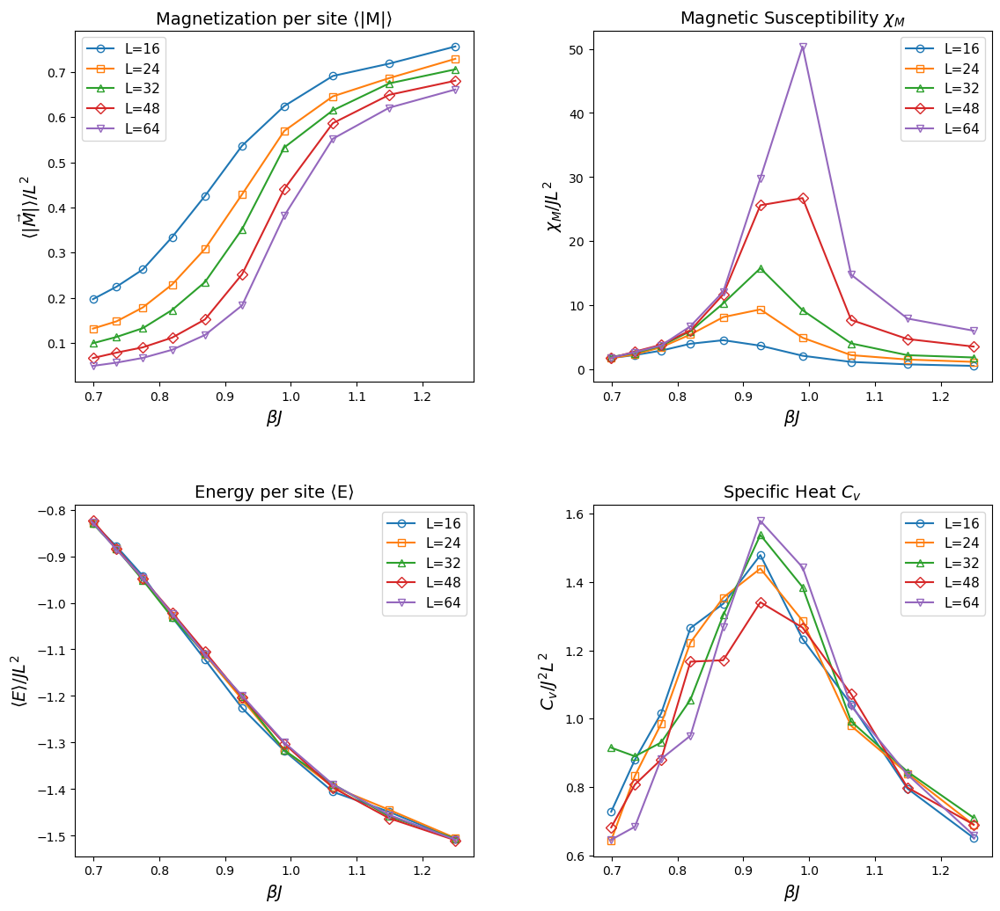

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
beta_values = 1/T_values
titles = [
    "Magnetization per site ⟨|M|⟩",
    "Magnetic Susceptibility $χ_M$",
    "Energy per site ⟨E⟩",
    "Specific Heat $C_v$"
]

y_labels = [
    r"$\langle |\vec{M}| \rangle / L^2$",
    r"$\chi_M / JL^2$",
    r"$\langle E \rangle / JL^2$",
    r"$C_v / J^2 L^2$"
]

keys = ["M", "chi", "E", "Cv"]

axes = axes.flatten()

markers = ['o', 's', '^', 'D', 'v']

# -------------------------------------------------
# Plot each observable
# -------------------------------------------------

for i, key in enumerate(keys):

    ax = axes[i]

    for j, L in enumerate(L_values):
        ax.plot(beta_values,
            results[L][key],
            marker=markers[j % len(markers)], mfc='none',
            label=f"L={L}",
            linewidth=1.5,
            markersize=6
        )

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(r"$\beta J$", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)

    ax.legend(fontsize=11)
    #ax.grid(True)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

plt.savefig(
    "ResponseFuncClockq8-stateLogGrid-16-64.pdf",
    dpi=300
)

plt.show()

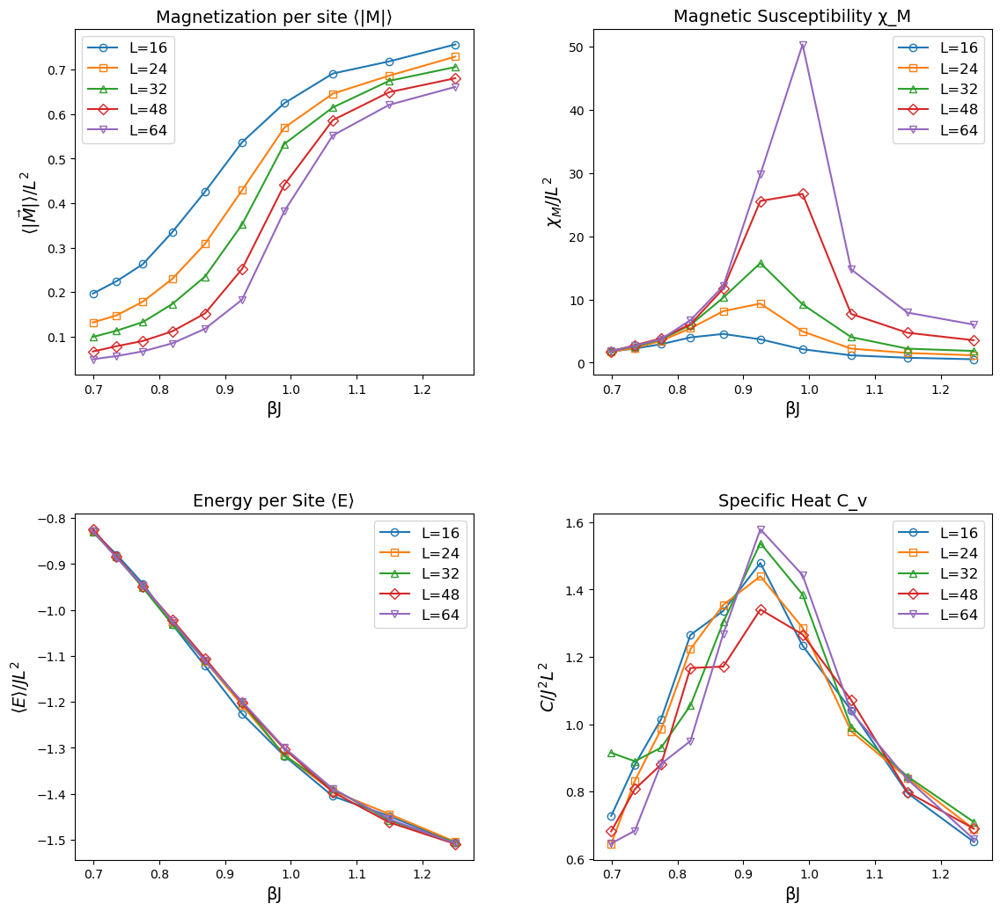

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", 
            r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M", "chi", "E", "Cv"]
axes = axes.flatten()
markers = ['o', 's', '^', 'D', 'v']

for i, key in enumerate(keys):
    ax = axes[i]
    for j, L in enumerate(L_values):
        ax.plot(
            beta_values, 
            results[L][key],
            marker=markers[j % len(markers)], mfc = 'none',
            label=f"L={L}"
        )
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("βJ", fontsize=14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(False)

plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.savefig("ResponseFuncClockq8-stateLogGrid-16-64.pdf")
plt.show()


Slope (γ/ν) = 1.6875
Intercept = -3.1460
R² = 0.9953


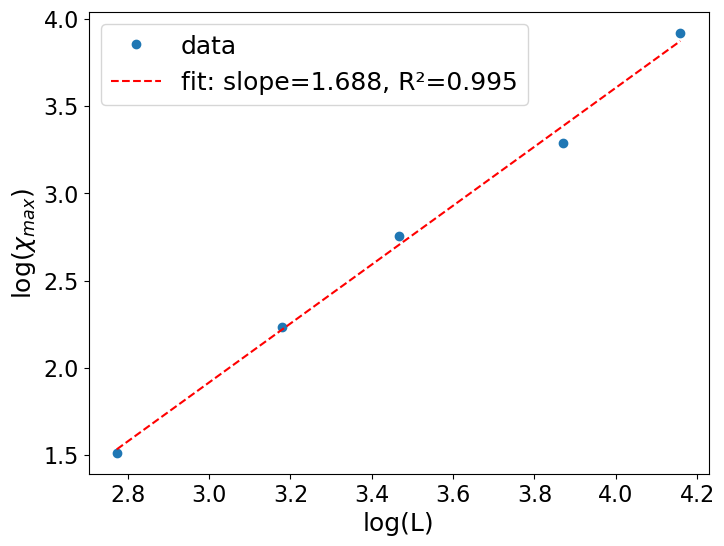

In [61]:
from scipy.stats import linregress

# --- Collect chi_max for each L ---
chi_max_values = []
for L in L_values:
    chi_list = results[L]["chi"]
    chi_max = np.max(chi_list)
    chi_max_values.append(chi_max)

chi_max_values = np.array(chi_max_values)
L_array = np.array(L_values)

# --- Log-log fitting ---
logL = np.log(L_array)
logChi = np.log(chi_max_values)

slope, intercept, r_value, p_value, std_err = linregress(logL, logChi)

# --- Print results ---
print(f"Slope (γ/ν) = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")
print(f"R² = {r_value**2:.4f}")

# --- Plot log-log scaling ---
plt.figure(figsize=(8,6))
plt.plot(logL, logChi, 'o', label="data")
plt.plot(logL, intercept + slope*logL, 'r--', label=f"fit: slope={slope:.3f}, R²={r_value**2:.3f}")
plt.xlabel("log(L)", fontsize = 18)
plt.ylabel("log($χ_{max}$)", fontsize = 18)
plt.xticks(fontsize = 16)
plt.yticks(fontsize = 16)
#plt.title("Finite-Size Scaling of Susceptibility Peak")
plt.legend(fontsize = 18)
#plt.grid(True)

#plt.savefig("FSSq3BinderResolvedLogFontSize-16-64.pdf")
plt.show()

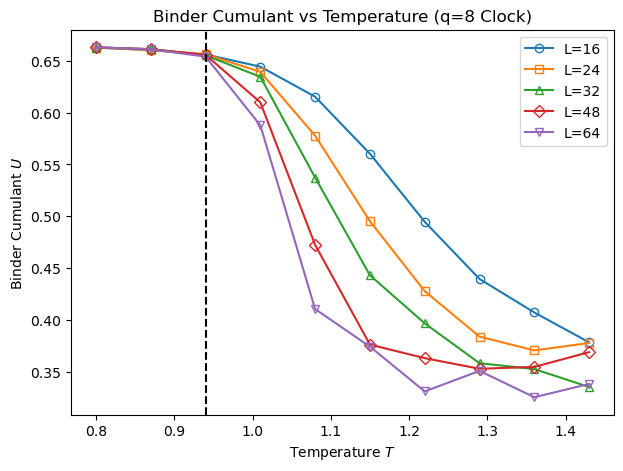

In [47]:
plt.figure(figsize=(7,5))
Tc = 0.94
markers = ['o', 's', '^', 'D', 'v']
for i,L in enumerate(L_values):
    plt.plot(T_values, results[L]["Binder"], marker=markers[i % len(markers)], mfc = 'none',
        linestyle='-', label=f"L={L}")

plt.xlabel("Temperature $T$")
plt.ylabel("Binder Cumulant $U$")
plt.title("Binder Cumulant vs Temperature (q=8 Clock)")
#plt.xlim(0.9,1.1)
#plt.xlim(0.9,1)
plt.axvline(Tc, linestyle = '--', linewidth = 1.5, color = 'black')
plt.savefig("BinderCumulantq8Clock.pdf")
plt.legend()
#plt.grid(True)
plt.show()

In [16]:

# Parameters
q = 8   # Number of clock states
J = 1.0  # Interaction strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
steps = 10**6  # Total Monte Carlo steps
burn_in = 200000
L_values = [4, 6, 8, 10, 12]  # Different lattice sizes to test
T_values = np.linspace(0.5, 3.0, 10)  # Temperature range

# Function to compute measure frequency
def measure_every(L):
    return L**2

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles

# Compute total magnetization (vector)
def compute_magnetization(sigma, L):
    return  np.sum(sigma, axis=(0, 1)) / (L * L)  # Normalize per spin

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta, L):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta) / 2  # Avoid double counting
        H -= np.dot(h, sigma[i, j]) # External field term
    return H

# Monte Carlo Step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)  # Pick a random site
    new_spin = np.random.randint(0, q)  # Pick a new random spin state
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    old_angle = angles[i, j]  # Current angle
    old_sigma = sigma[i, j]   # Current spin vector

    # Define neighbor sites with periodic boundaries
    neighbor_sites = [( (i+1) % L, j ), ( (i-1) % L, j ), ( i, (j+1) % L ), ( i, (j-1) % L )]

    # Compute old and new energy
    E_old = -J * sum(np.cos(old_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 
    E_new = -J * sum(np.cos(new_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 

    # Add external field term
    E_old -= np.dot(h, old_sigma)
    E_new -= np.dot(h, new_sigma)

    # Compute ΔE
    dE = E_new - E_old  

    # Compute acceptance probability (Glauber or Metropolis)
    beta = 1 / T
    P_accept = 1 / (1 + np.exp(beta * dE)) if update_rule == "glauber" else min(1, np.exp(-beta * dE))

    # Accept or reject the update
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma  # Update spin vector

# Run simulation
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []  # List to store magnetization vectors
    E_vals = []
    # Adjust burn-in dynamically based on system size
    burn_in = 500000 if L >= 10 else 200000  # More steps for large L

    # Pre-thermalization (Burn-in)
    for _ in range(burn_in):  
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)  # [M_x, M_y]
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)  # Convert list to NumPy array
    E_vals = np.array(E_vals)
   # Mean magnetization vector
    m_avg = np.mean(m_vals, axis=0)  # ⟨M_x⟩, ⟨M_y⟩
   
    # Compute mean magnitude of magnetization
    mod_m_avg = np.mean(np.linalg.norm(m_vals, axis=1))  # ⟨|M|⟩
    m_sq_avg = np.mean(np.linalg.norm(m_vals, axis=1)**2)  # ⟨|M|^2⟩
    m_avg_sq = np.linalg.norm(np.mean(m_vals, axis=0))**2  # ⟨|M|⟩^2
    #avg_sq_mod_m = np.square(np.linalg.norm(m_avg))
    # Compute ⟨M⟩ ⋅ ⟨M⟩
    #m_avg_sq = np.dot(m_avg, m_avg)  # ⟨M⟩ ⋅ ⟨M⟩
    # Compute ⟨M ⋅ M⟩
    #m_sq_avg = np.mean(np.sum(m_vals**2, axis=1))   # ⟨M ⋅ M⟩

    # Susceptibility (corrected formula)
    chi_M = (m_sq_avg - m_avg_sq) * (L * L)

    # Energy calculations
    E_avg = np.mean(E_vals)
  
    E_sq_avg = np.mean(np.square(E_vals))
    
    # Heat capacity
    C_v = (E_sq_avg - E_avg**2) / (L**2 * T**2)

    return mod_m_avg, chi_M, C_v, E_avg

# Run simulations for different lattice sizes and temperatures
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        mod_m_avg, chi_M, C_v, E_avg = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(mod_m_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg)


Running simulations for T=0.50 (Beta=2.00)...
Running simulations for T=0.78 (Beta=1.29)...
Running simulations for T=1.06 (Beta=0.95)...
Running simulations for T=1.33 (Beta=0.75)...
Running simulations for T=1.61 (Beta=0.62)...
Running simulations for T=1.89 (Beta=0.53)...
Running simulations for T=2.17 (Beta=0.46)...
Running simulations for T=2.44 (Beta=0.41)...
Running simulations for T=2.72 (Beta=0.37)...
Running simulations for T=3.00 (Beta=0.33)...


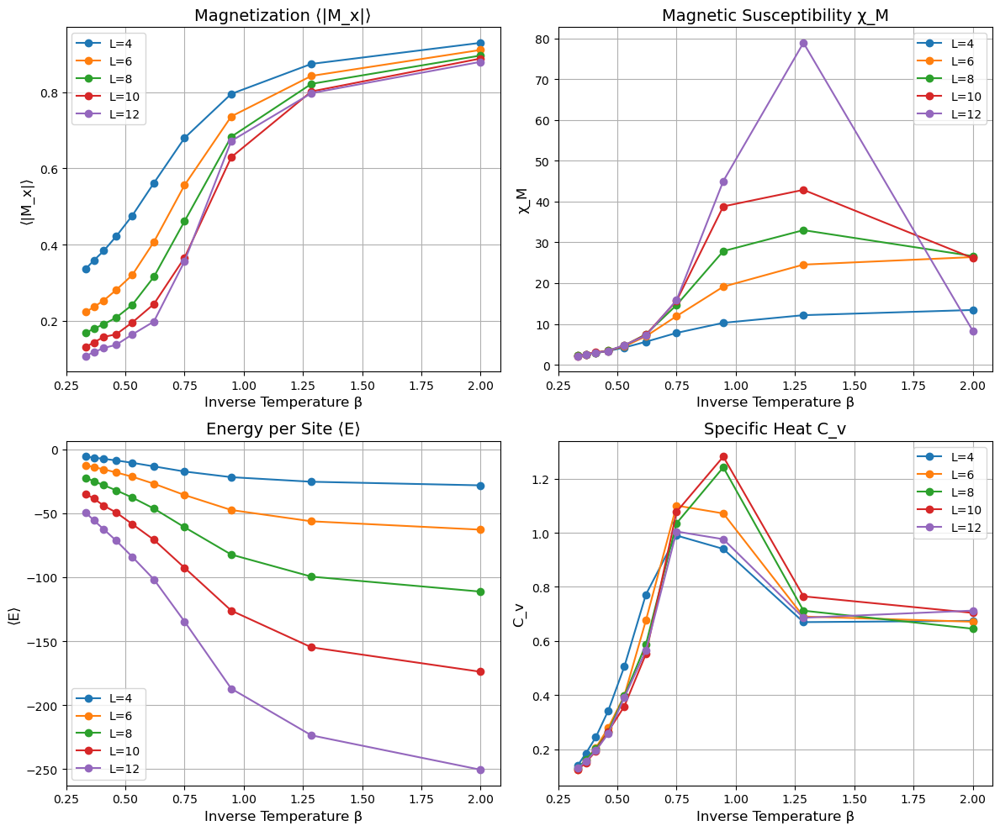

In [18]:
beta_values = 1/T_values
# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Titles and y-axis labels
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
         "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

# Flatten axes array for easier indexing
axes = axes.flatten()

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")
    
    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

# Adjust layout and show
plt.tight_layout()
plt.show()

### Bunching analysis

In [19]:
import matplotlib.pyplot as plt
import numpy as np
# Parameters
q = 5   # Number of clock states
J = 1.0  # Interactio\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\\n strength
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
steps = 10**6  # Total Monte Carlo steps
#burn_in = 2**18
L_values = [4, 6, 8, 10, 12]  # Different lattice sizes to test
  # Temperature range
beta_core = np.linspace(0.5, 1.75, 10)
delta_beta = beta_core[1] - beta_core[0]
beta_extra_low = beta_core[0] - delta_beta
beta_extra_high = beta_core[-1] + delta_beta
beta_values = np.concatenate([[beta_extra_low], beta_core, [beta_extra_high]])

# Compute corresponding temperature values
T_values = 1 / beta_values

In [21]:
# Function to compute measure frequency
#def measure_every(L):
    #return L

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles

# Compute total magnetization (vector)
def compute_magnetization(sigma, L):
    return  np.sum(sigma, axis=(0, 1)) / (L * L)  # Normalize per spin

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J, h, delta, L):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
                ni, nj = (i + di) % L, (j + dj) % L
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Avoid double counting
        H -= np.dot(h, sigma[i, j]) # External field term
    return H/2

# Monte Carlo Step
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule="glauber"):
    i, j = np.random.randint(0, L, 2)  # Pick a random site
    new_spin = np.random.randint(0, q)  # Pick a new random spin state
    new_angle = 2 * np.pi * new_spin / q
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    old_angle = angles[i, j]  # Current angle
    old_sigma = sigma[i, j]   # Current spin vector

    # Define neighbor sites with periodic boundaries
    neighbor_sites = [( (i+1) % L, j ), ( (i-1) % L, j ), ( i, (j+1) % L ), ( i, (j-1) % L )]

    # Compute old and new energy
    E_old = -J * sum(np.cos(old_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 
    E_new = -J * sum(np.cos(new_angle - angles[ni, nj] + delta) for ni, nj in neighbor_sites) 

    # Add external field term
    E_old -= np.dot(h, old_sigma)
    E_new -= np.dot(h, new_sigma)

    # Compute ΔE
    dE = E_new - E_old  
    
    # Compute acceptance probability (Glauber or Metropolis)
    beta = 1 / T
    P_accept = 1 / (1 + np.exp(beta * dE)) if update_rule == "glauber" else min(1, np.exp(-beta * dE))

    # Accept or reject the update
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle
        sigma[i, j] = new_sigma  # Update spin vector


In [61]:
# Run simulation
def run_simulation(q, T, L, update_rule, burn_in):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []  # List to store magnetization vectors
    E_vals = []
    # Adjust burn-in dynamically based on system size
    #burn_in = 500000 if L >= 10 else 200000  # More steps for large L

    # Pre-thermalization (Burn-in)
    for _ in range(burn_in):  
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)  # [M_x, M_y]
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)  # Convert list to NumPy array
    E_vals = np.array(E_vals)
   # Mean magnetization vector
    m_avg = np.mean(m_vals, axis=0)  # ⟨M_x⟩, ⟨M_y⟩
   
    # Compute mean magnitude of magnetization
    mod_m_avg = np.mean(np.linalg.norm(m_vals, axis=1))  # ⟨|M|⟩
    m_sq_avg = np.mean(np.linalg.norm(m_vals, axis=1)**2)  # ⟨|M|^2⟩
    m_avg_sq = np.linalg.norm(np.mean(m_vals, axis=0))**2  # ⟨|M|⟩^2
    #avg_sq_mod_m = np.square(np.linalg.norm(m_avg))
    # Compute ⟨M⟩ ⋅ ⟨M⟩
    #m_avg_sq = np.dot(m_avg, m_avg)  # ⟨M⟩ ⋅ ⟨M⟩
    # Compute ⟨M ⋅ M⟩
    #m_sq_avg = np.mean(np.sum(m_vals**2, axis=1))   # ⟨M ⋅ M⟩

    # Susceptibility (corrected formula)
    chi_M = (m_sq_avg - m_avg_sq) * (L * L)
    # Energy calculations
    E_avg = np.mean(E_vals)
    E_avg_per_site = E_avg/L**2
    E_sq_avg = np.mean(np.square(E_vals))
    # Heat capacity
    C_v = (E_sq_avg - E_avg**2)/(L**2* T**2)
    # Bunching analysis
    energy_bunch = bunch_data(E_vals)
    mag_bunch = bunch_data(np.linalg.norm(m_vals, axis=1))  # ⟨|M|⟩ values

    return mod_m_avg, chi_M, C_v, E_avg_per_site, energy_bunch, mag_bunch
def bunch_data(data):
    data = np.array(data)
    N = len(data)
    results = []

    max_k = int(np.floor(np.log2(N)))
    for k in range(0, max_k):  # start from k=0
        bin_size = 2**k
        num_bins = N // bin_size

        if num_bins < 2:
            break

        # Trim data so it fits perfectly into bins
        trimmed_data = data[:bin_size * num_bins]
        binned = trimmed_data.reshape(num_bins, bin_size).mean(axis=1)

        mean_val = np.mean(binned)
        variance = np.var(binned, ddof=1)  # Variance of bin means
        error = np.sqrt(variance / num_bins)  # Standard error

        results.append({
            "k": k,
            "bin_size": bin_size,
            "mean": mean_val,
            "error": error,
            "variance": variance
        })

    return results

# Run simulations for different lattice sizes and temperatures
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "E_bunch": [], "M_bunch": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        mod_m_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(mod_m_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["E_bunch"].append(E_bunch)
        results[L]["M_bunch"].append(M_bunch)




Running simulations for T=0.50 (Beta=2.00)...


TypeError: run_simulation() missing 1 required positional argument: 'burn_in'

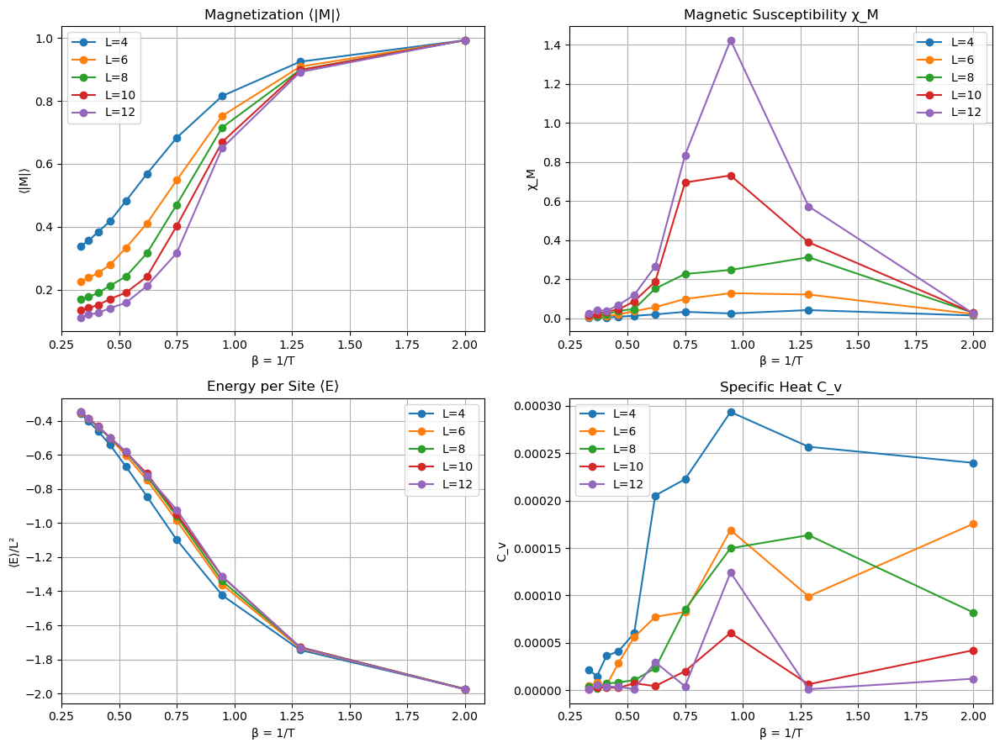

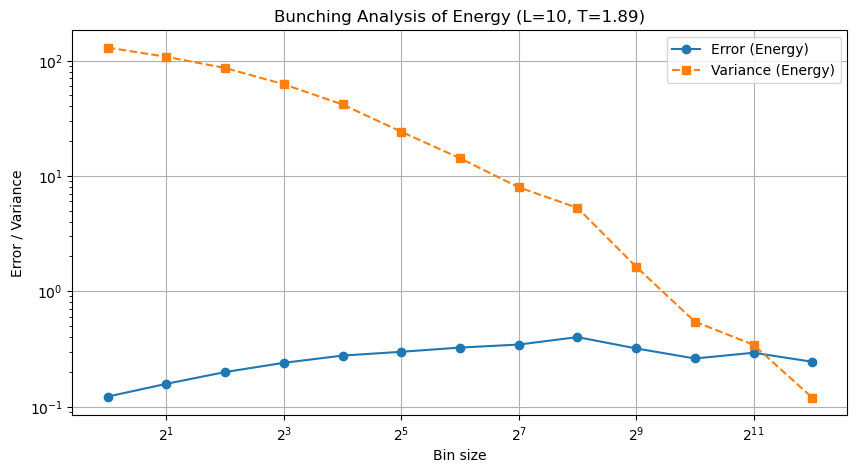

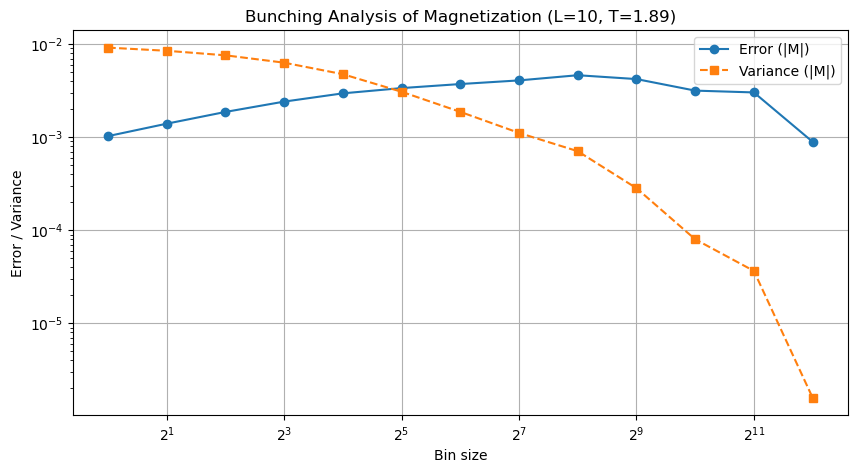

In [15]:
import matplotlib.pyplot as plt
beta_values = 1/T_values
# Plot the four response functions
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
titles = ["Magnetization ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = ["⟨|M|⟩", "χ_M", "⟨E⟩/L²", "C_v"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()

for i, key in enumerate(keys):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', label=f"L={L}")
    ax.set_title(titles[i])
    ax.set_xlabel("β = 1/T")
    ax.set_ylabel(y_labels[i])
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

# Choose a specific L and T index to visualize bunching
L_select = 10
T_index = 5  # e.g., T ~ 1.72
# Extract bunching results
E_bunch = results[L_select]["E_bunch"][T_index]
M_bunch = results[L_select]["M_bunch"][T_index]

# Extract bin_sizes and corresponding errors/variances separately
E_bin_sizes = [entry["bin_size"] for entry in E_bunch]
E_errors = [entry["error"] for entry in E_bunch]
E_vars = [entry["variance"] for entry in E_bunch]

M_bin_sizes = [entry["bin_size"] for entry in M_bunch]
M_errors = [entry["error"] for entry in M_bunch]
M_vars = [entry["variance"] for entry in M_bunch]

# Plot Energy bunching
plt.figure(figsize=(10, 5))
plt.plot(E_bin_sizes, E_errors, 'o-', label='Error (Energy)')
plt.plot(E_bin_sizes, E_vars, 's--', label='Variance (Energy)')
plt.title(f'Bunching Analysis of Energy (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

# Plot Magnetization bunching
plt.figure(figsize=(10, 5))
plt.plot(M_bin_sizes, M_errors, 'o-', label='Error (|M|)')
plt.plot(M_bin_sizes, M_vars, 's--', label='Variance (|M|)')
plt.title(f'Bunching Analysis of Magnetization (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

In [23]:
def bunch_data_with_optimal_bin(data):
    data = np.asarray(data)
    N = data.size
    results = []

    max_k = int(np.floor(np.log2(N)))
    min_diff = np.inf
    optimal_bin = None

    for k in range(max_k):
        bin_size = 2**k
        num_bins = N // bin_size

        if num_bins < 2:
            break

        binned = data[:num_bins * bin_size].reshape(num_bins, bin_size).mean(axis=1) # data[:num_bins*bin_size] trims the data to a multiple of the current bin size, 
                                                                              # then reshapes it into a 2d array where each row is a bin # Takes the mean across each bin (i.e., along axis=1) → gives a 1D array of binned means.
                                                                              # So binned ends up being a new shorter array of num_bins elements, where each value is the average of one bin/block. 
                                                                              #Each bin is a row, so you average along the columns to get the mean per bin.

        mean_val = np.mean(binned)
        mean_sq_val = np.mean(binned**2)
        variance = np.var(binned, ddof=1)
        error = np.sqrt(variance / num_bins)

        results.append({
            "k": k,
            "bin_size": bin_size,
            "mean": mean_val,
            "error": error,
            "variance": variance,
            "num_bins": num_bins
        })

        # Find where error ≈ variance (in log-log, they should cross)
        diff = abs(np.log(error) - np.log(variance))
        if diff < min_diff:
            min_diff = diff
            optimal_bin = {
                "k": k,
                "bin_size": bin_size,
                "mean": mean_val,
                "mean_sq": mean_sq_val,
                "error": error,
                "variance": variance,
                "num_bins": num_bins
            }

    return results, optimal_bin

In [31]:
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []
    E_vals = []

    # Pre-thermalization (burn-in)
    for _ in range(burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurement phase
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        #if step % measure_every(L) == 0:
        m_vec = compute_magnetization(sigma, L)
        m_vals.append(m_vec)
        E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)
    E_vals = np.array(E_vals)

    # ----- Bunching analysis -----
    E_bunch, E_opt = bunch_data_with_optimal_bin(E_vals)
    M_bunch, M_opt = bunch_data_with_optimal_bin(np.linalg.norm(m_vals, axis=1))

    # ----- Compute Observables from Optimal Binning -----

    # Energy observables
    E_avg = E_opt["mean"]
    E_avg_per_site = E_avg / (L**2)
    E_sq_avg = E_opt["mean"]**2 + E_opt["variance"]
    C_v = (E_sq_avg - E_avg**2) / (L**2 * T**2)

    # Magnetization observables
    M_avg = M_opt["mean"]
    M_sq_avg = (M_opt["mean"])**2 + M_opt["variance"]
    M_avg_sq = (M_opt["mean"])**2
    chi_M = (M_sq_avg - M_avg_sq)/(L**2)

    return M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch


In [37]:
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []
    E_vals = []
    burn_in = 500000 if L >= 10 else 2**19  # More steps for large L
    # Pre-thermalization
    for _ in range(burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurements
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        #if step % measure_every(L) == 0:
        m_vec = compute_magnetization(sigma, L)
        m_vals.append(m_vec)
        E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)
    E_vals = np.array(E_vals)

    # ----- Bunching analysis -----
    E_bunch, E_opt = bunch_data_with_optimal_bin(E_vals)
    M_bunch, M_opt = bunch_data_with_optimal_bin(np.linalg.norm(m_vals, axis=1))

    # ----- Observables -----
    # Energy observables
    E_avg = E_opt["mean"]
    E_sq_avg = E_opt["mean_sq"]
    # Final response functions
    E_avg_per_site = E_avg / (L**2)
    C_v= (E_sq_avg - E_avg**2)/ (L*T**2)

    # Magnetization observables
    M_avg = M_opt["mean"]
    M_avg_per_site = M_avg/ L**2
    M_sq_avg = M_opt["mean_sq"]
    chi_M = (M_sq_avg - M_avg**2)*L**2/T


    return M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch


In [39]:
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "E_bunch": [], "M_bunch": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(M_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["E_bunch"].append(E_bunch)
        results[L]["M_bunch"].append(M_bunch)


Running simulations for T=2.77 (Beta=0.36)...
Running simulations for T=2.00 (Beta=0.50)...
Running simulations for T=1.57 (Beta=0.64)...


KeyboardInterrupt: 

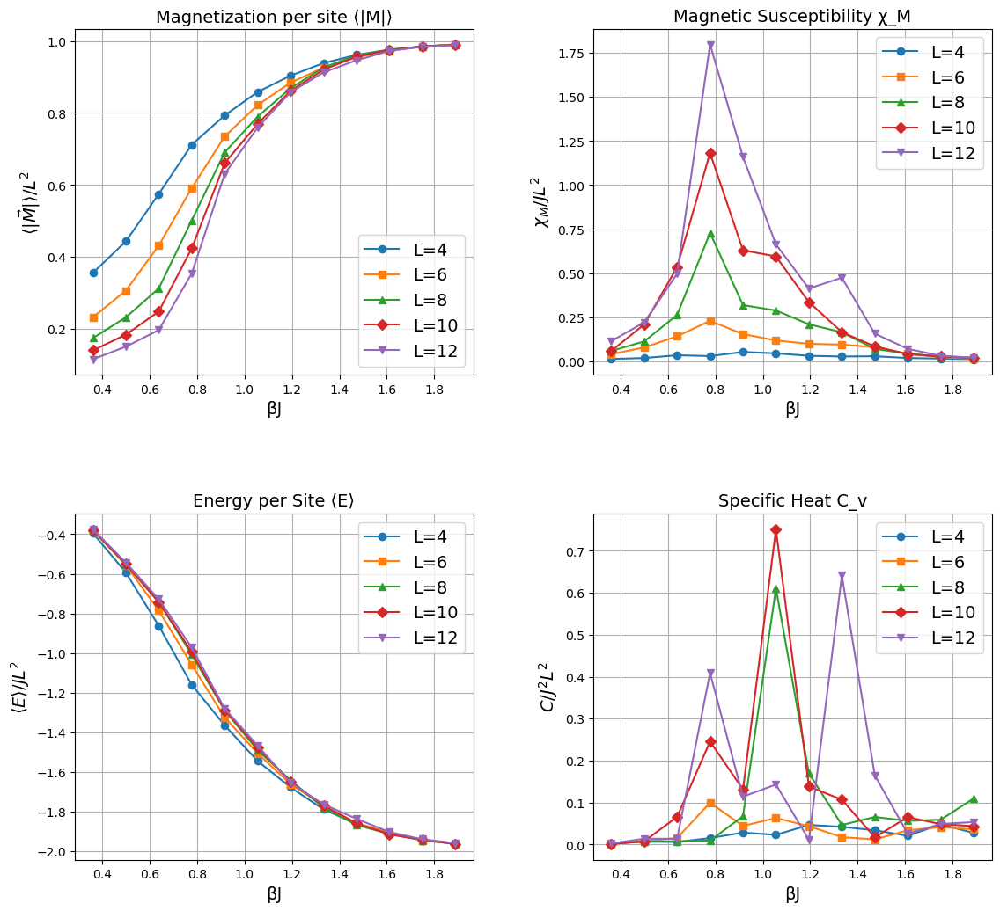

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

### No $L^2$

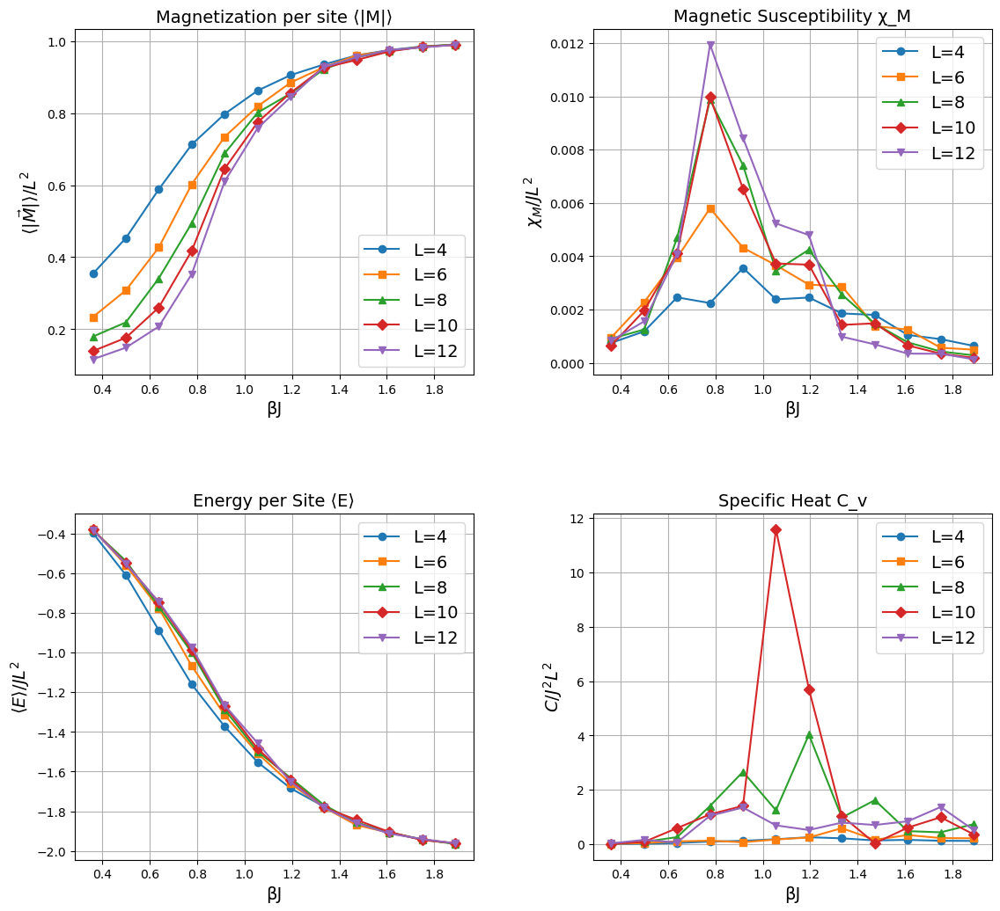

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

### $L^2$


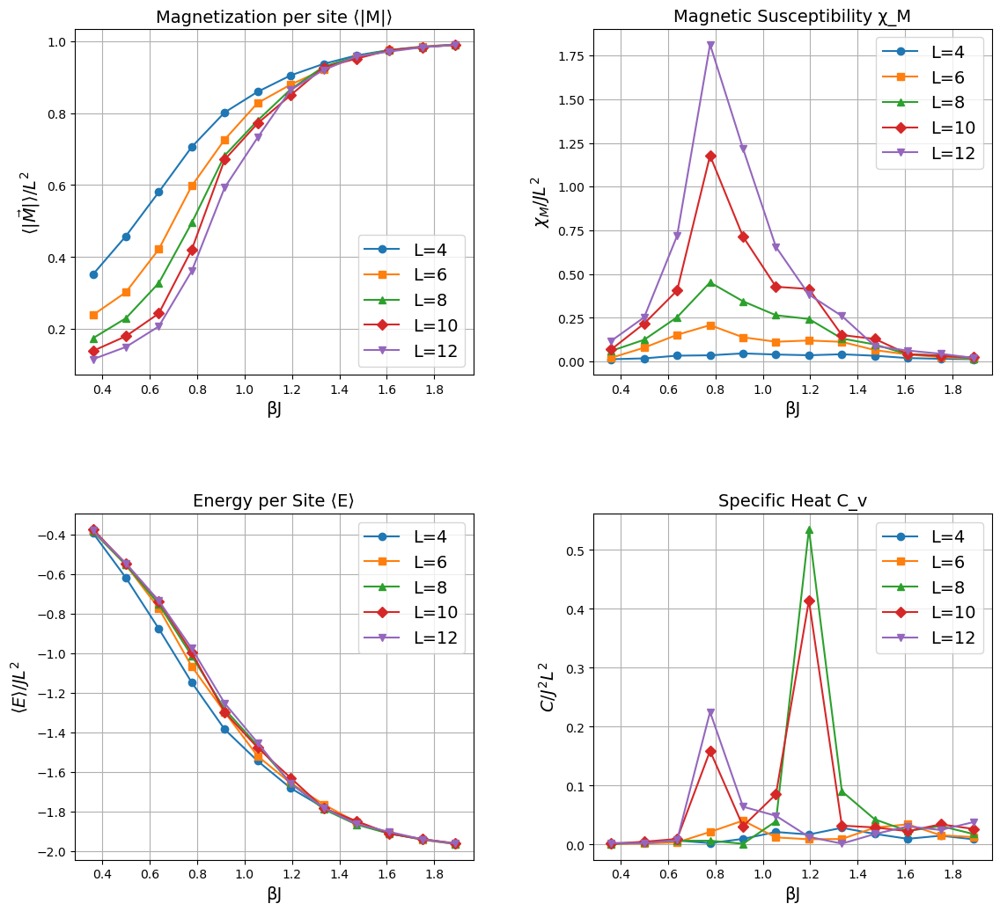

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

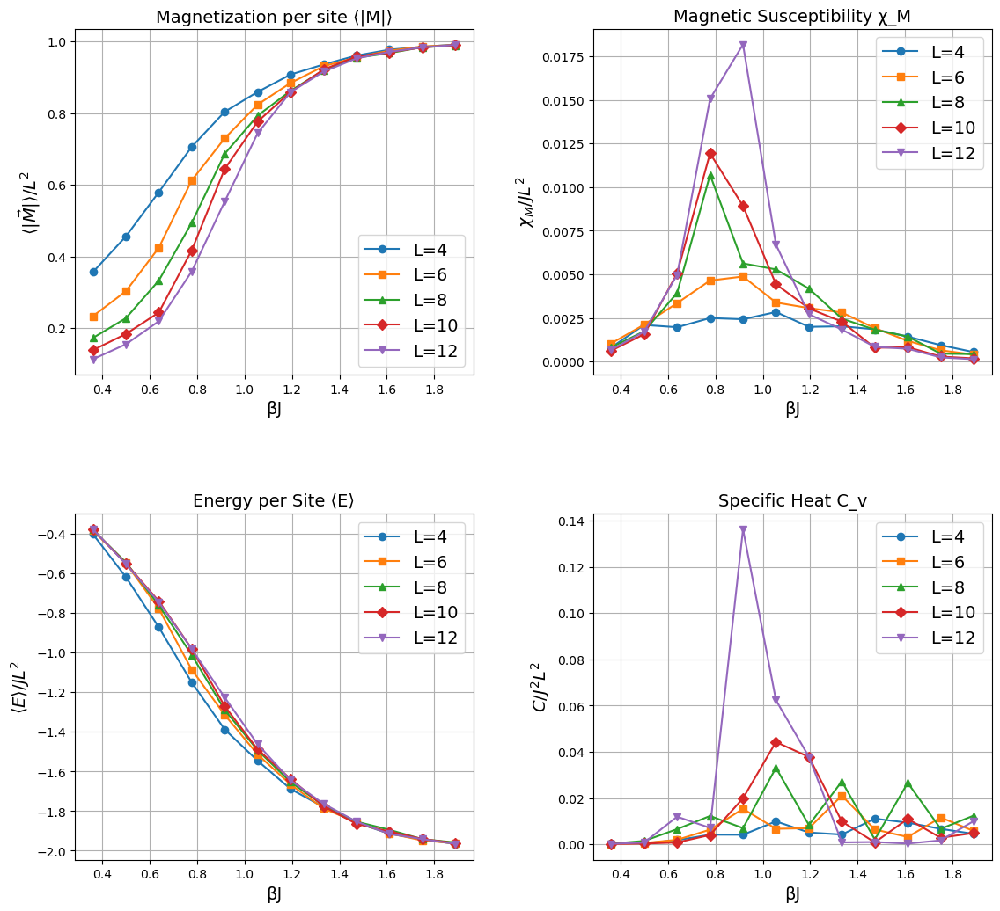

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

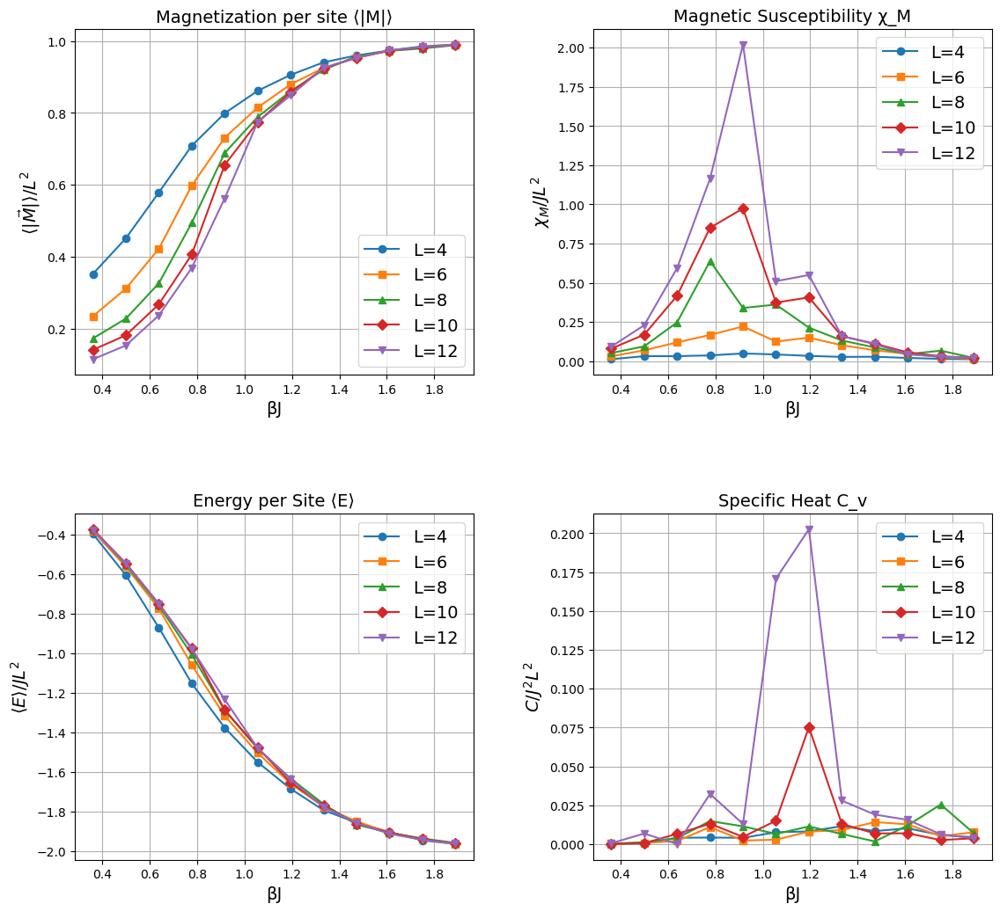

In [13]:

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

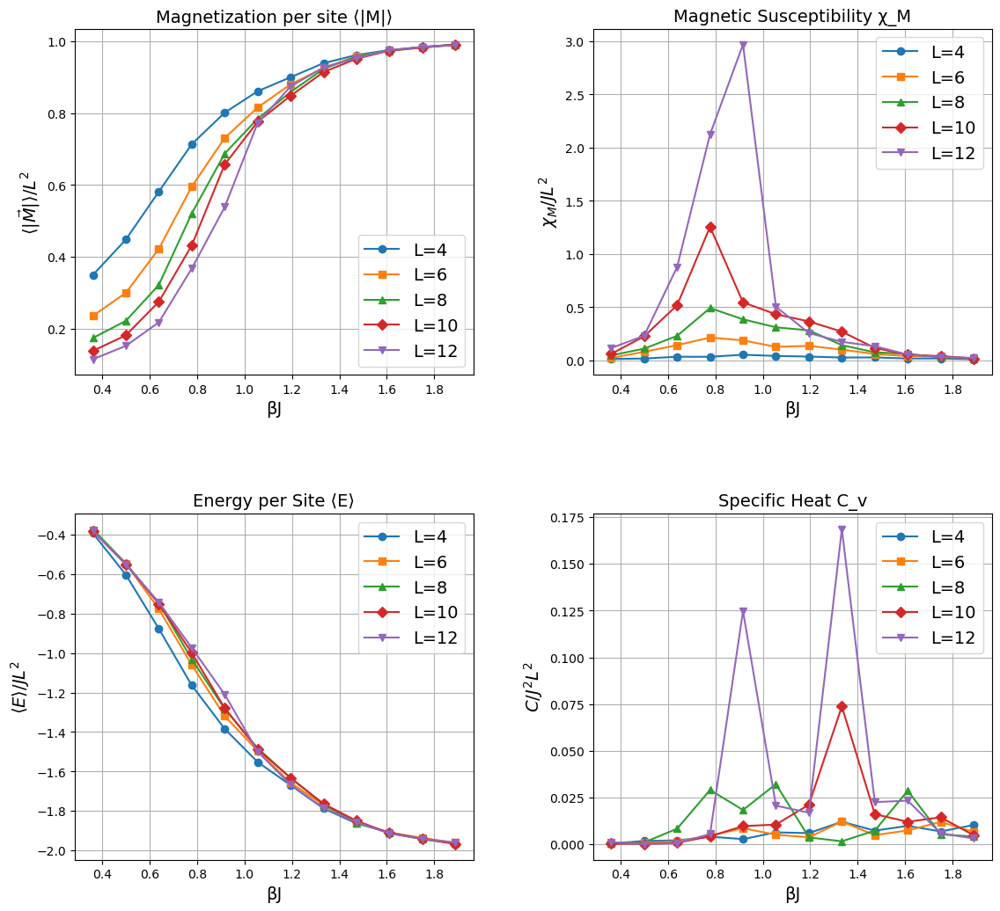

In [61]:

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

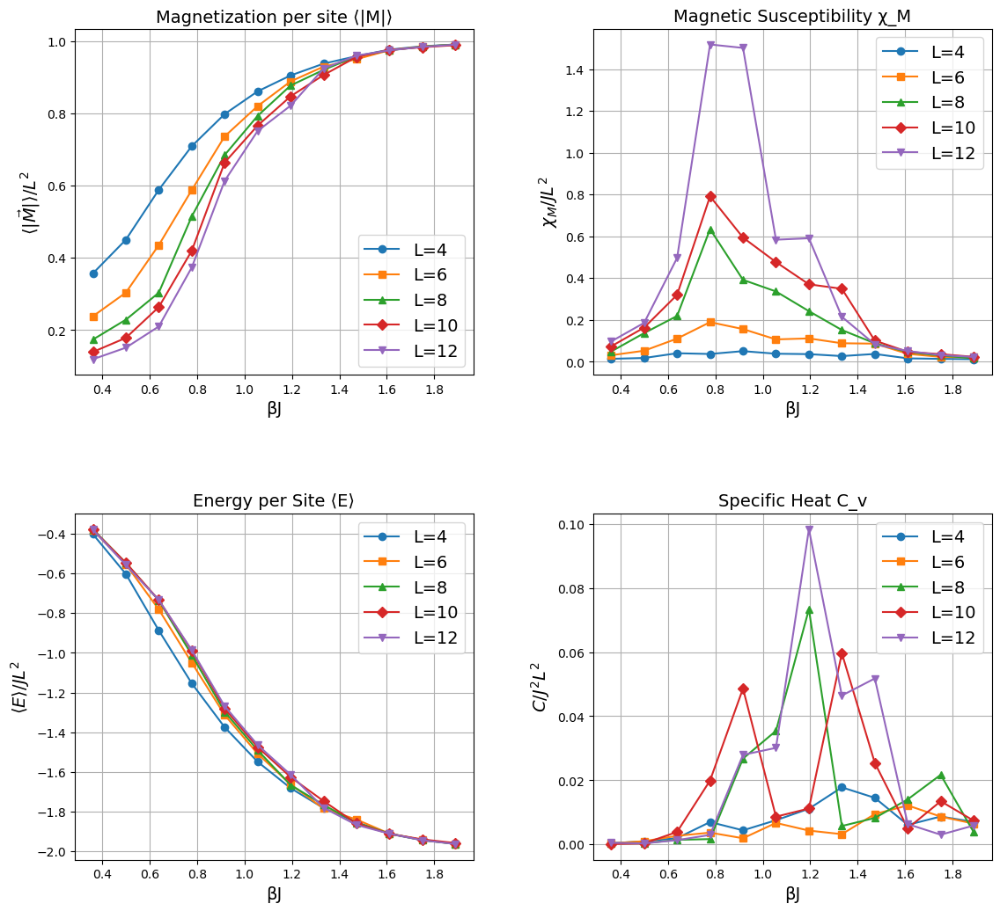

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

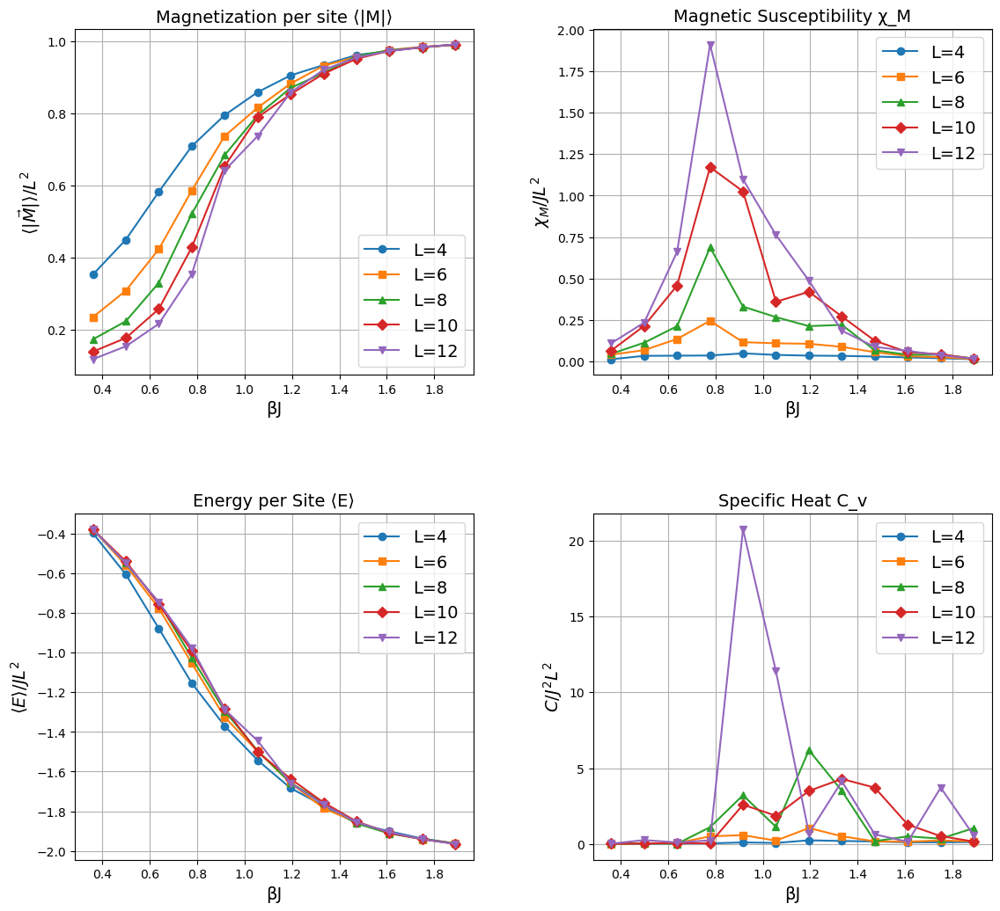

In [41]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / JL^2$", r"$\langle E \rangle / JL^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

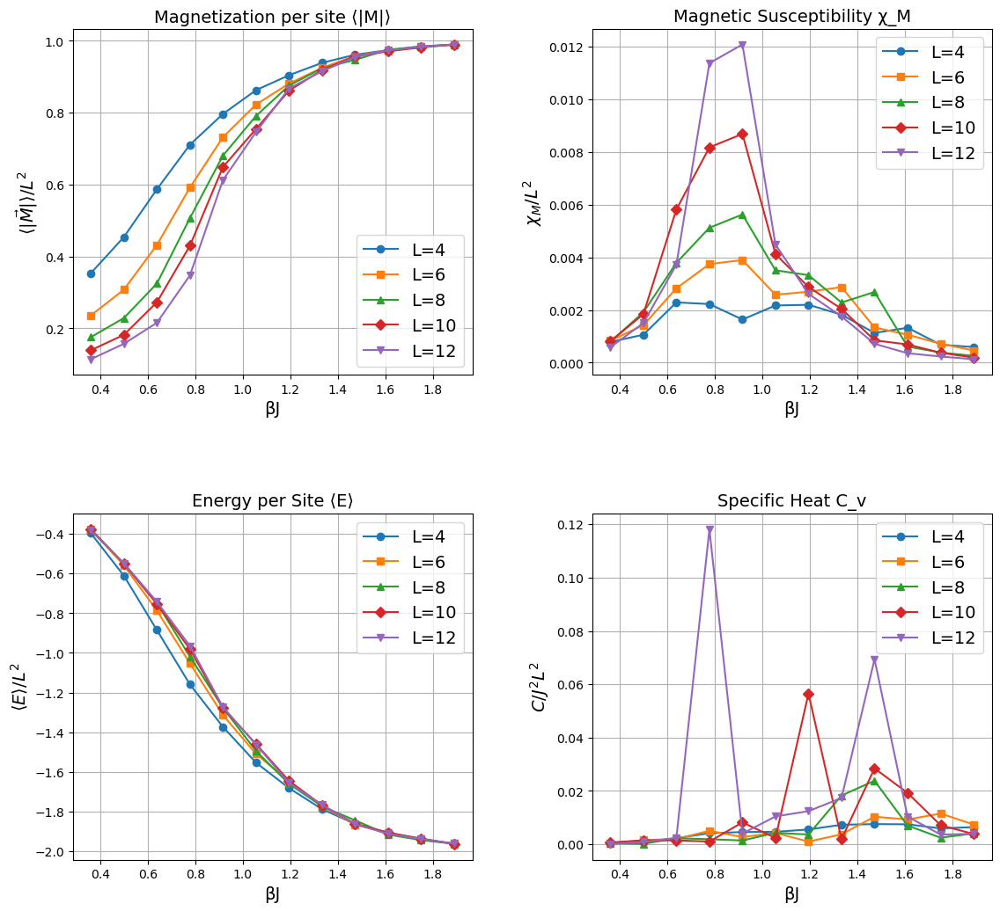

In [79]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / L^2$", r"$\langle E \rangle / L^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()


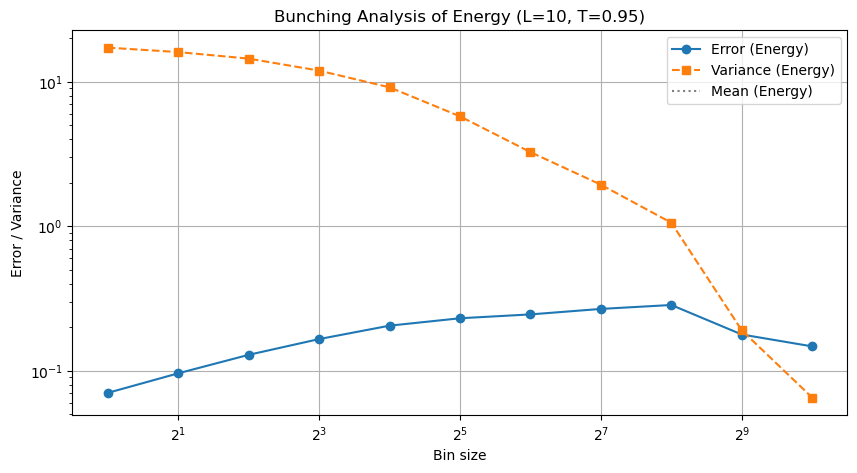

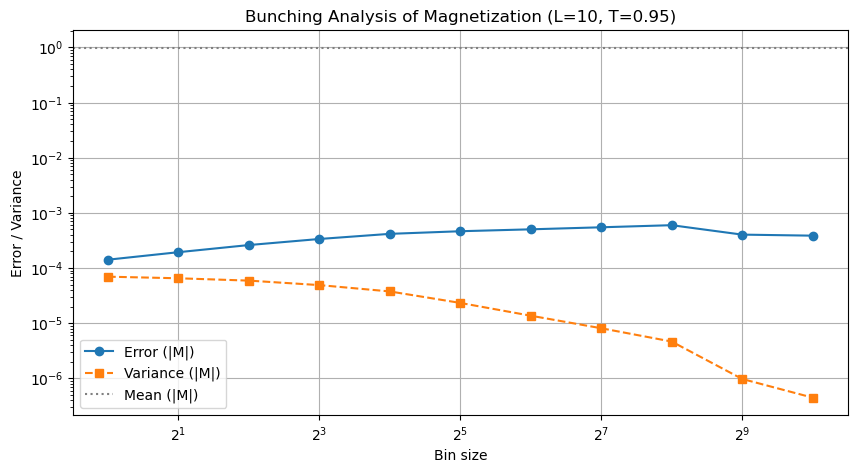

In [83]:
# Choose a specific lattice size and temperature index
L_select = 10
T_index = 5

# Energy bunching
E_bin_sizes = [entry["bin_size"] for entry in E_bunch]
E_errors = [entry["error"] for entry in E_bunch]
E_vars = [entry["variance"] for entry in E_bunch]
E_means = [entry["mean"] for entry in E_bunch]

# Plot
plt.figure(figsize=(10, 5))
plt.plot(E_bin_sizes, E_errors, 'o-', label='Error (Energy)')
plt.plot(E_bin_sizes, E_vars, 's--', label='Variance (Energy)')
plt.axhline(np.mean(E_means), color='gray', linestyle=':', label='Mean (Energy)')
plt.title(f'Bunching Analysis of Energy (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.savefig('BunchingEnergy.pdf', bbox_inches='tight')
plt.show()

# Magnetization bunching
M_bin_sizes = [entry["bin_size"] for entry in M_bunch]
M_errors = [entry["error"] for entry in M_bunch]
M_vars = [entry["variance"] for entry in M_bunch]
M_means = [entry["mean"] for entry in M_bunch]

plt.figure(figsize=(10, 5))
plt.plot(M_bin_sizes, M_errors, 'o-', label='Error (|M|)')
plt.plot(M_bin_sizes, M_vars, 's--', label='Variance (|M|)')
plt.axhline(np.mean(M_means), color='gray', linestyle=':', label='Mean (|M|)')
plt.title(f'Bunching Analysis of Magnetization (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.savefig('BunchingMag.pdf', bbox_inches='tight')
plt.show()


In [19]:
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []
    E_vals = []
    burn_in = 500000 if L >= 10 else 2**18  # More steps for large L
    # Pre-thermalization
    for _ in range(burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurements
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)
    E_vals = np.array(E_vals)

    # ----- Bunching analysis -----
    E_bunch, E_opt = bunch_data_with_optimal_bin(E_vals)
    M_bunch, M_opt = bunch_data_with_optimal_bin(np.linalg.norm(m_vals, axis=1))

    # ----- Observables -----
    # Energy observables
    E_avg = E_opt["mean"]
    E_sq_avg = E_opt["mean_sq"]
    # Final response functions
    E_avg_per_site = E_avg / (L**2)
    C_v = (E_sq_avg - E_avg**2)/ (T**2*L**2)

    # Magnetization observables
    M_avg = M_opt["mean"]
    M_avg_per_site = M_avg/ L**2
    M_sq_avg = M_opt["mean_sq"]
    chi_M = (M_sq_avg - M_avg**2) /T


    return M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch


In [21]:
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "E_bunch": [], "M_bunch": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(M_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["E_bunch"].append(E_bunch)
        results[L]["M_bunch"].append(M_bunch)

Running simulations for T=2.77 (Beta=0.36)...
Running simulations for T=2.00 (Beta=0.50)...
Running simulations for T=1.57 (Beta=0.64)...
Running simulations for T=1.29 (Beta=0.78)...
Running simulations for T=1.09 (Beta=0.92)...
Running simulations for T=0.95 (Beta=1.06)...
Running simulations for T=0.84 (Beta=1.19)...
Running simulations for T=0.75 (Beta=1.33)...
Running simulations for T=0.68 (Beta=1.47)...
Running simulations for T=0.62 (Beta=1.61)...
Running simulations for T=0.57 (Beta=1.75)...
Running simulations for T=0.53 (Beta=1.89)...


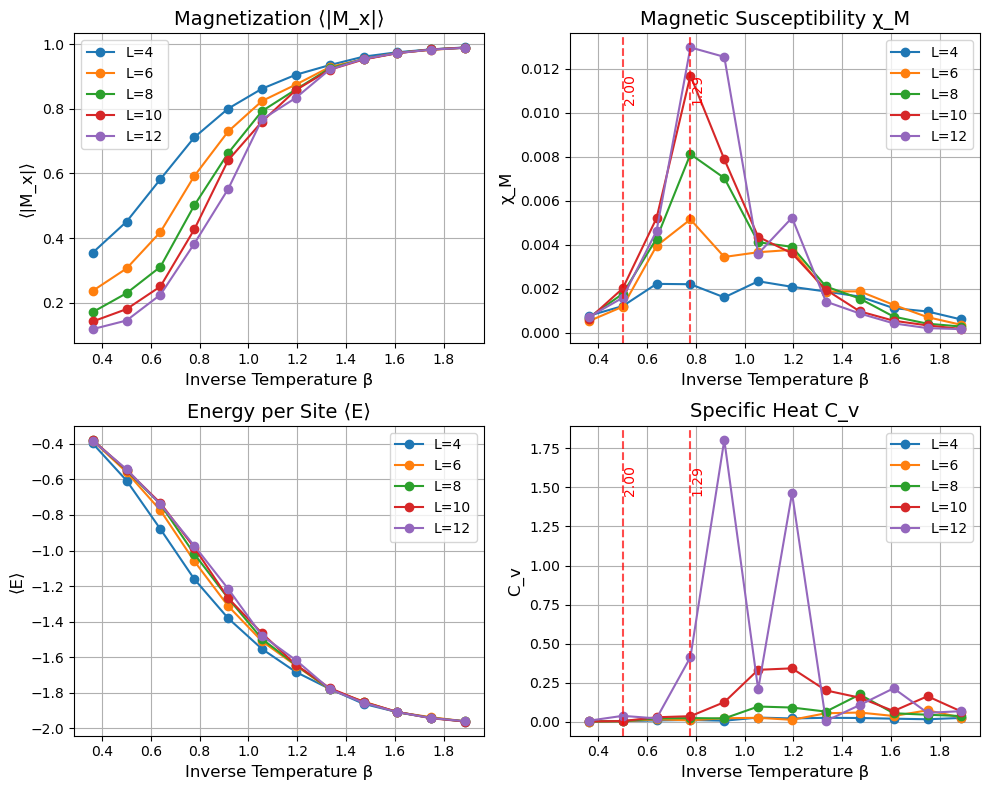

In [55]:
from scipy.signal import find_peaks

# Convert temperature values to inverse temperature (beta)
beta_values = 1 / T_values

# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

axes = axes.flatten()  # Flatten axes array for easier indexing

# Detect two transition points
chi_M_peaks, _ = find_peaks(results[L_values[-1]]["chi_M"])
Cv_peaks, _ = find_peaks(results[L_values[-1]]["C_v"])

# If two peaks exist, use them. Otherwise, approximate second transition
transition_betas = []

# First transition from χ_M
if len(chi_M_peaks) > 0:
    transition_betas.append(beta_values[chi_M_peaks[0]])  # First peak in χ_M

# Second transition from C_v
if len(Cv_peaks) > 0:
    transition_betas.append(beta_values[Cv_peaks[0]])  # First peak in C_v
elif len(chi_M_peaks) > 1:  
    transition_betas.append(beta_values[chi_M_peaks[1]])  # Use second χ_M peak if no C_v peak

# Ensure we have two transition points
if len(transition_betas) < 2:
    # Approximate second transition using the inflection point of |M|
    dM_dT = np.gradient(results[L_values[-1]]["M_x"])
    inflection_index = np.argmax(np.abs(np.gradient(dM_dT)))  
    transition_betas.append(beta_values[inflection_index])

# Sort transition betas
transition_betas = sorted(transition_betas)

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

    # Only mark transitions in χ_M and C_v plots
    if key in ["chi_M", "C_v"]:
        for beta in transition_betas:
            ax.axvline(x=beta, color='r', linestyle='--', alpha=0.7)
            ax.text(beta, max(results[L_values[-1]][key]) * 0.8, f"{1/beta:.2f}", 
                    rotation=90, verticalalignment='bottom', fontsize=10, color='red')

# Adjust layout and show
plt.tight_layout()
plt.show()


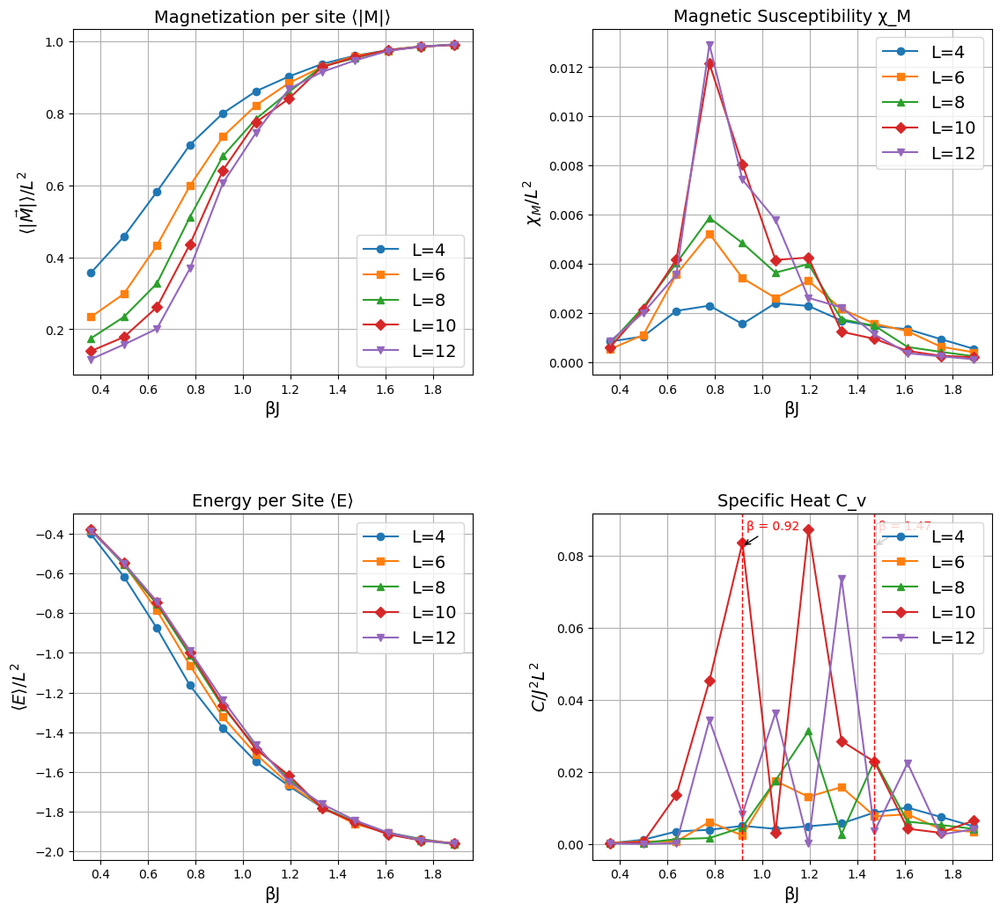

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / L^2$", r"$\langle E \rangle / L^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
peak_betas = [0.915, 1.47]

for beta in peak_betas:
    plt.axvline(x=beta, color='red', linestyle='--', linewidth=1)
    plt.annotate(f'β = {beta:.2f}', xy=(beta, plt.ylim()[1]*0.9), xytext=(beta + 0.02, plt.ylim()[1]*0.95),
                 arrowprops=dict(facecolor='red', arrowstyle='->'),
                 fontsize=10, color='red')
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

In [25]:
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []
    E_vals = []
    burn_in = 500000 if L >= 10 else 2**18  # More steps for large L
    # Pre-thermalization
    for _ in range(burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurements
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)
    E_vals = np.array(E_vals)

    # ----- Bunching analysis -----
    E_bunch, E_opt = bunch_data_with_optimal_bin(E_vals)
    M_bunch, M_opt = bunch_data_with_optimal_bin(np.linalg.norm(m_vals, axis=1))

    # ----- Observables -----
    # Energy observables
    E_avg = E_opt["mean"]
    E_sq_avg = E_opt["mean_sq"]
    # Final response functions
    E_avg_per_site = E_avg / (L**2)
    C_v = (E_sq_avg - E_avg**2)/(T**2*L**2)

    # Magnetization observables
    M_avg = M_opt["mean"]
    M_avg_per_site = M_avg/ L**2
    M_sq_avg = M_opt["mean_sq"]
    chi_M = (M_sq_avg - M_avg**2)/ T


    return M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch


In [27]:
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "E_bunch": [], "M_bunch": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(M_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["E_bunch"].append(E_bunch)
        results[L]["M_bunch"].append(M_bunch)


Running simulations for T=2.77 (Beta=0.36)...
Running simulations for T=2.00 (Beta=0.50)...
Running simulations for T=1.57 (Beta=0.64)...
Running simulations for T=1.29 (Beta=0.78)...
Running simulations for T=1.09 (Beta=0.92)...
Running simulations for T=0.95 (Beta=1.06)...
Running simulations for T=0.84 (Beta=1.19)...
Running simulations for T=0.75 (Beta=1.33)...
Running simulations for T=0.68 (Beta=1.47)...
Running simulations for T=0.62 (Beta=1.61)...
Running simulations for T=0.57 (Beta=1.75)...
Running simulations for T=0.53 (Beta=1.89)...


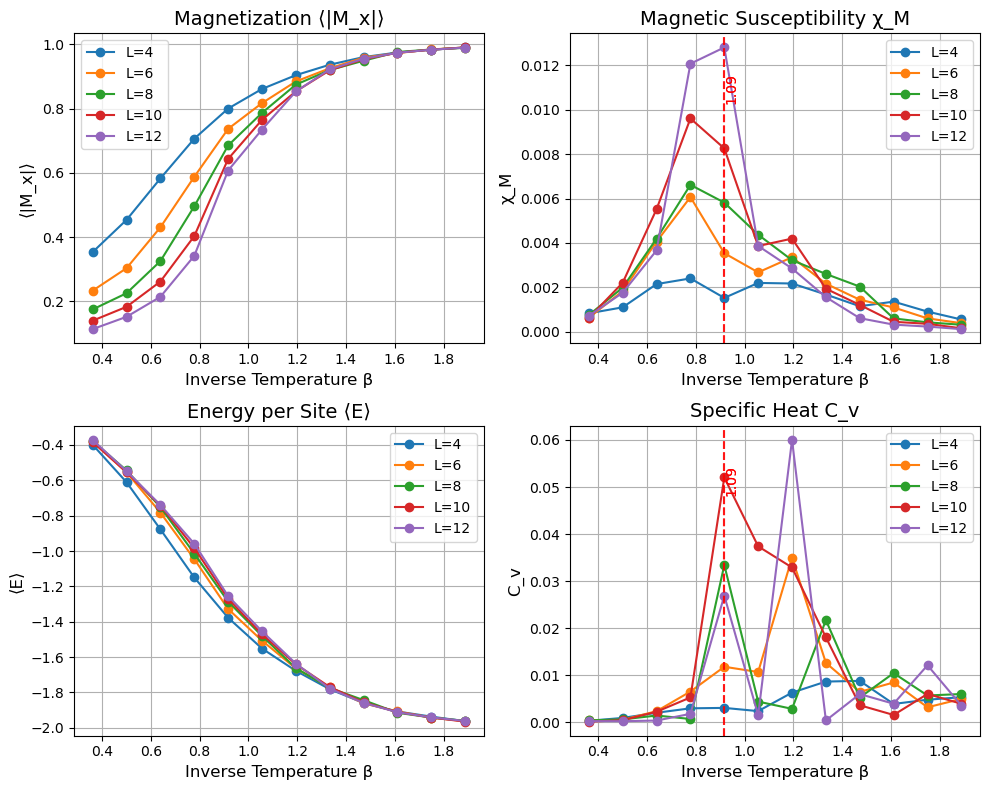

In [37]:
from scipy.signal import find_peaks

# Convert temperature values to inverse temperature (beta)
beta_values = 1 / T_values

# Set up subplots for the 4 response functions
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
titles = ["Magnetization ⟨|M_x|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩",  "Specific Heat C_v"]
y_labels = ["⟨|M_x|⟩", "χ_M", "⟨E⟩", "C_v"]

axes = axes.flatten()  # Flatten axes array for easier indexing

# Detect two transition points
chi_M_peaks, _ = find_peaks(results[L_values[-1]]["chi_M"])
Cv_peaks, _ = find_peaks(results[L_values[-1]]["C_v"])

# If two peaks exist, use them. Otherwise, approximate second transition
transition_betas = []

# First transition from χ_M
if len(chi_M_peaks) > 0:
    transition_betas.append(beta_values[chi_M_peaks[0]])  # First peak in χ_M

# Second transition from C_v
if len(Cv_peaks) > 0:
    transition_betas.append(beta_values[Cv_peaks[0]])  # First peak in C_v
elif len(chi_M_peaks) > 1:  
    transition_betas.append(beta_values[chi_M_peaks[1]])  # Use second χ_M peak if no C_v peak

# Ensure we have two transition points
if len(transition_betas) < 2:
    # Approximate second transition using the inflection point of |M|
    dM_dT = np.gradient(results[L_values[-1]]["M_x"])
    inflection_index = np.argmax(np.abs(np.gradient(dM_dT)))  
    transition_betas.append(beta_values[inflection_index])

# Sort transition betas
transition_betas = sorted(transition_betas)

# Plot each response function
for i, key in enumerate(["M_x", "chi_M", "E_avg", "C_v"]):
    ax = axes[i]
    
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', linestyle='-', label=f"L={L}")

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Inverse Temperature β", fontsize=12)
    ax.set_ylabel(y_labels[i], fontsize=12)
    ax.legend()
    ax.grid(True)

    # Only mark transitions in χ_M and C_v plots
    if key in ["chi_M", "C_v"]:
        for beta in transition_betas:
            ax.axvline(x=beta, color='r', linestyle='--', alpha=0.7)
            ax.text(beta, max(results[L_values[-1]][key]) * 0.8, f"{1/beta:.2f}", 
                    rotation=90, verticalalignment='bottom', fontsize=10, color='red')

# Adjust layout and show
plt.tight_layout()
plt.show()


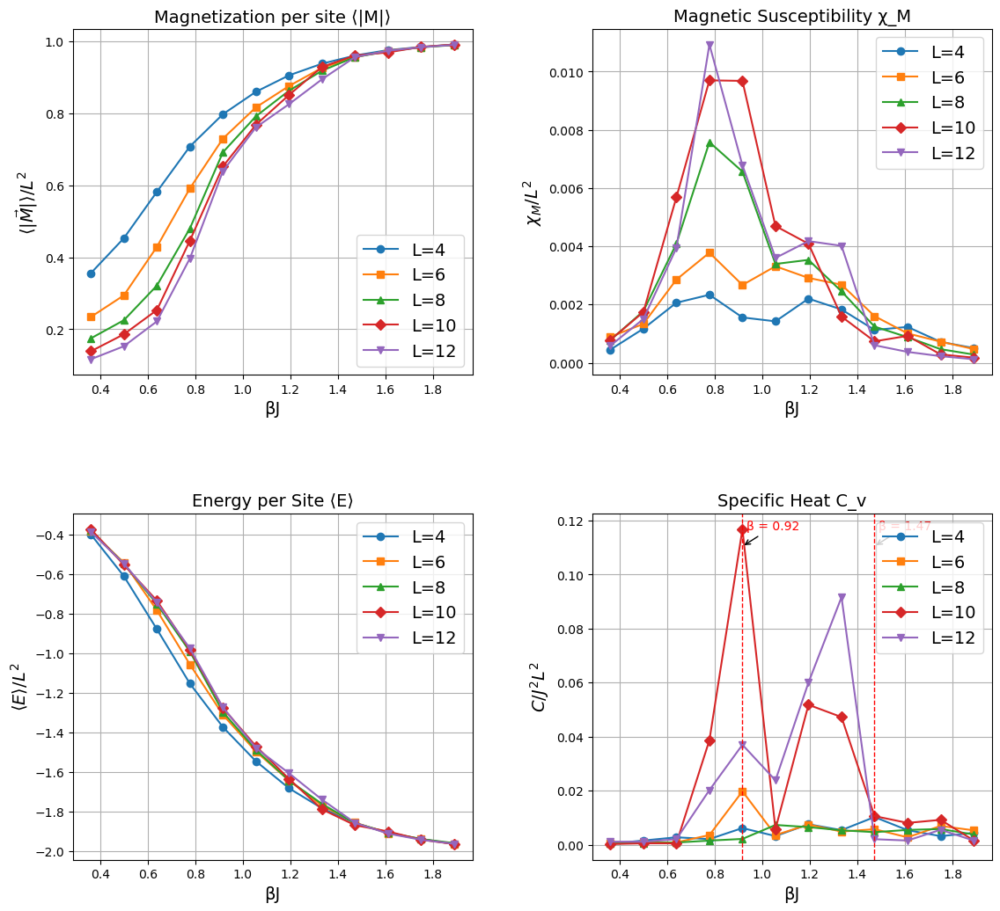

In [111]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
titles = ["Magnetization per site ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle / L^2$", r"$\chi_M / L^2$", r"$\langle E \rangle / L^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()
# List of markers to cycle through
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'h']

for i, key in enumerate(keys):
    ax = axes[i]
    for L, marker in zip(L_values,markers):
        ax.plot(beta_values, results[L][key], marker=marker, label=f"L={L}")
    ax.set_title(titles[i], fontsize= 14)
    ax.set_xlabel("βJ", fontsize= 14)
    ax.set_ylabel(y_labels[i], fontsize=14)
    ax.legend(fontsize = 14)
    ax.grid(True)
peak_betas = [0.915, 1.47]

for beta in peak_betas:
    plt.axvline(x=beta, color='red', linestyle='--', linewidth=1)
    plt.annotate(f'β = {beta:.2f}', xy=(beta, plt.ylim()[1]*0.9), xytext=(beta + 0.02, plt.ylim()[1]*0.95),
                 arrowprops=dict(facecolor='red', arrowstyle='->'),
                 fontsize=10, color='red')
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout(pad=3.0)  # More padding around subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)  # Extra space between rows/columns
plt.show()

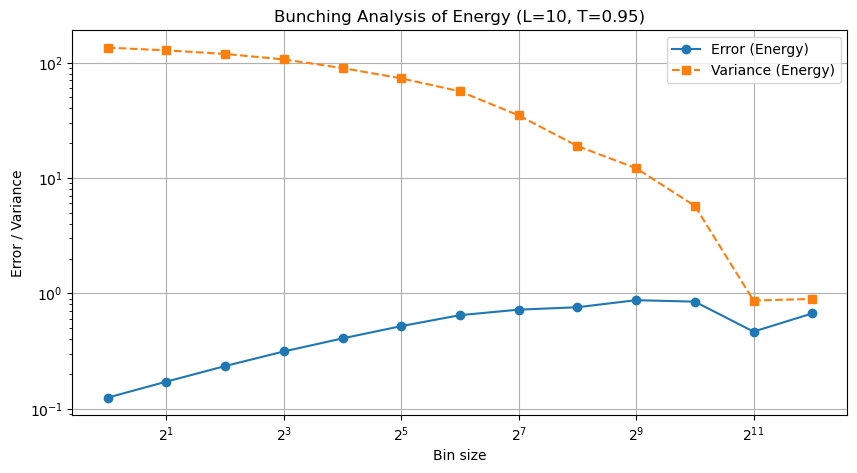

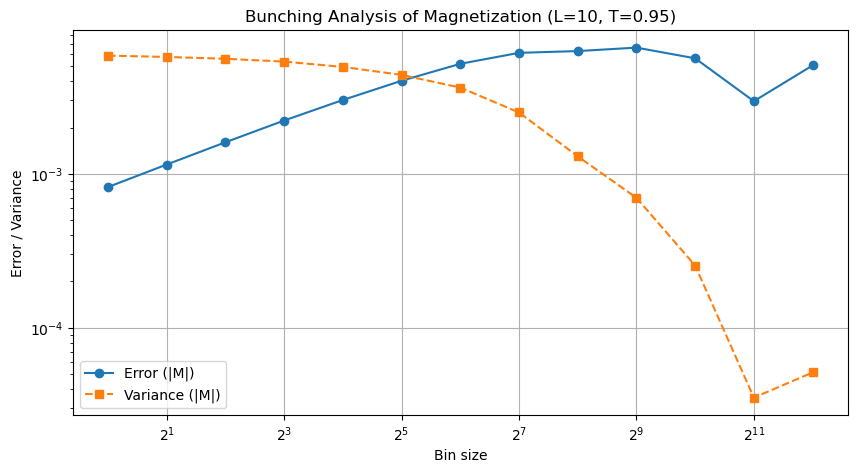

In [19]:
# Choose a specific lattice size and temperature index
L_select = 10
T_index = 5

E_bunch = results[L_select]["E_bunch"][T_index]
M_bunch = results[L_select]["M_bunch"][T_index]

# Energy bunching
E_bin_sizes = [entry["bin_size"] for entry in E_bunch]
E_errors = [entry["error"] for entry in E_bunch]
E_vars = [entry["variance"] for entry in E_bunch]

plt.figure(figsize=(10, 5))
plt.plot(E_bin_sizes, E_errors, 'o-', label='Error (Energy)')
plt.plot(E_bin_sizes, E_vars, 's--', label='Variance (Energy)')
plt.title(f'Bunching Analysis of Energy (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
#plt.savefig('BunchingEnergy.pdf', bbox_inches = 'tight')
plt.grid(True)
plt.show()

# Magnetization bunching
M_bin_sizes = [entry["bin_size"] for entry in M_bunch]
M_errors = [entry["error"] for entry in M_bunch]
M_vars = [entry["variance"] for entry in M_bunch]

plt.figure(figsize=(10, 5))
plt.plot(M_bin_sizes, M_errors, 'o-', label='Error (|M|)')
plt.plot(M_bin_sizes, M_vars, 's--', label='Variance (|M|)')
plt.title(f'Bunching Analysis of Magnetization (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
#plt.savefig('BunchingMag.pdf', bbox_inches = 'tight')
plt.grid(True)
plt.show()


In [31]:
def run_simulation(q, T, L, update_rule):
    spins, sigma, angles = initialize_spins(L, q)
    m_vals = []
    E_vals = []
    burn_in = 500000 if L >= 10 else 2**17  # More steps for large L
    # Pre-thermalization
    for _ in range(burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)

    # Measurements
    for step in range(steps - burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, L, q, update_rule)
        if step % measure_every(L) == 0:
            m_vec = compute_magnetization(sigma, L)
            m_vals.append(m_vec)
            E_vals.append(compute_hamiltonian(sigma, angles, J, h, delta, L))

    m_vals = np.array(m_vals)
    E_vals = np.array(E_vals)

    # ----- Bunching analysis -----
    E_bunch, E_opt = bunch_data_with_optimal_bin(E_vals)
    M_bunch, M_opt = bunch_data_with_optimal_bin(np.linalg.norm(m_vals, axis=1))

    # ----- Observables -----
    # Energy observables
    E_avg = E_opt["mean"]
    E_sq_avg = E_opt["mean_sq"]
    # Final response functions
    E_avg_per_site = E_avg / (L**2)
    C_v = (E_sq_avg - E_avg**2)/ (T**2*L**2)

    # Magnetization observables
    M_avg = M_opt["mean"]
    M_avg_per_site = M_avg/ L**2
    M_sq_avg = M_opt["mean_sq"]
    chi_M = (M_sq_avg - M_avg**2)/ T


    return M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch


In [ ]:
# Storage
results = {L: {"M_x": [], "chi_M": [], "C_v": [], "E_avg": [], "E_bunch": [], "M_bunch": []} for L in L_values}

for T in T_values:
    print(f"Running simulations for T={T:.2f} (Beta={1/T:.2f})...")
    for L in L_values:
        M_avg, chi_M, C_v, E_avg_per_site, E_bunch, M_bunch = run_simulation(q, T, L, "glauber")
        results[L]["M_x"].append(M_avg)
        results[L]["chi_M"].append(chi_M)
        results[L]["C_v"].append(C_v)
        results[L]["E_avg"].append(E_avg_per_site)
        results[L]["E_bunch"].append(E_bunch)
        results[L]["M_bunch"].append(M_bunch)


Running simulations for T=2.77 (Beta=0.36)...
Running simulations for T=2.00 (Beta=0.50)...
Running simulations for T=1.57 (Beta=0.64)...
Running simulations for T=1.29 (Beta=0.78)...
Running simulations for T=1.09 (Beta=0.92)...


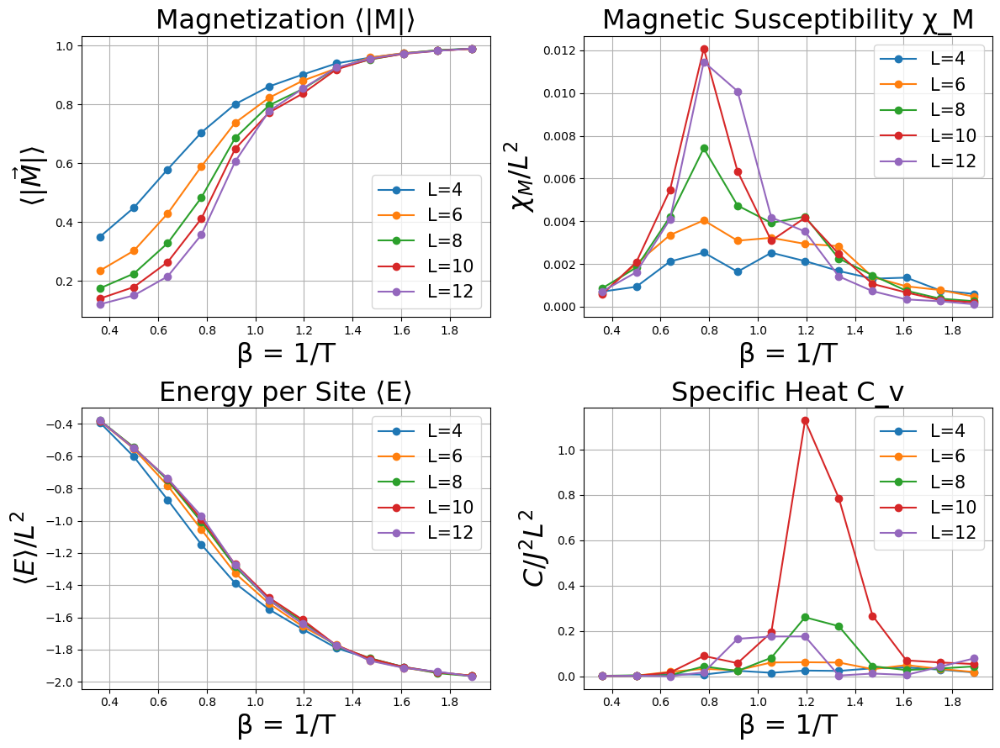

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
titles = ["Magnetization ⟨|M|⟩", "Magnetic Susceptibility χ_M",
          "Energy per Site ⟨E⟩", "Specific Heat C_v"]
y_labels = [r"$\langle |\vec{M}| \rangle$", r"$\chi_M / L^2$", r"$\langle E \rangle / L^2$", r"$C / J^2 L^2$"]
keys = ["M_x", "chi_M", "E_avg", "C_v"]
axes = axes.flatten()

for i, key in enumerate(keys):
    ax = axes[i]
    for L in L_values:
        ax.plot(beta_values, results[L][key], marker='o', label=f"L={L}")
    ax.set_title(titles[i], fontsize = 23)
    ax.set_xlabel("β = 1/T", fontsize = 23)
    ax.set_ylabel(y_labels[i], fontsize = 23)
    ax.legend(fontsize = 15)
    ax.grid(True)
#plt.savefig('ResFuncfor5.pdf', bbox_inches = 'tight')
plt.tight_layout()
plt.show()


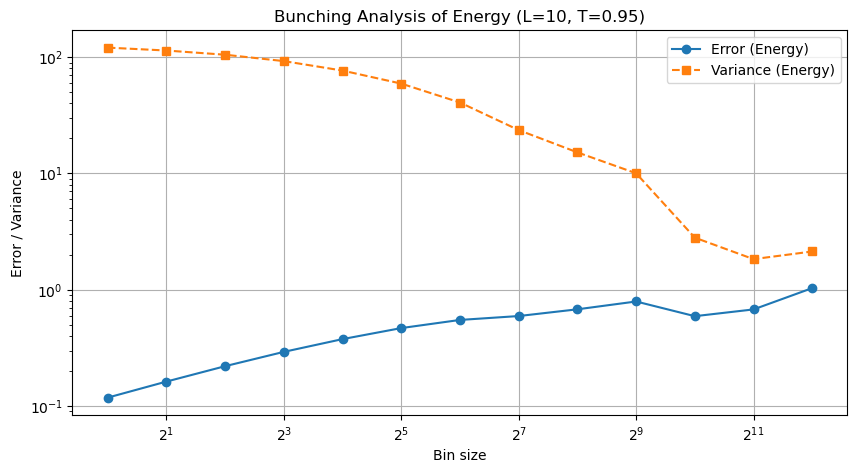

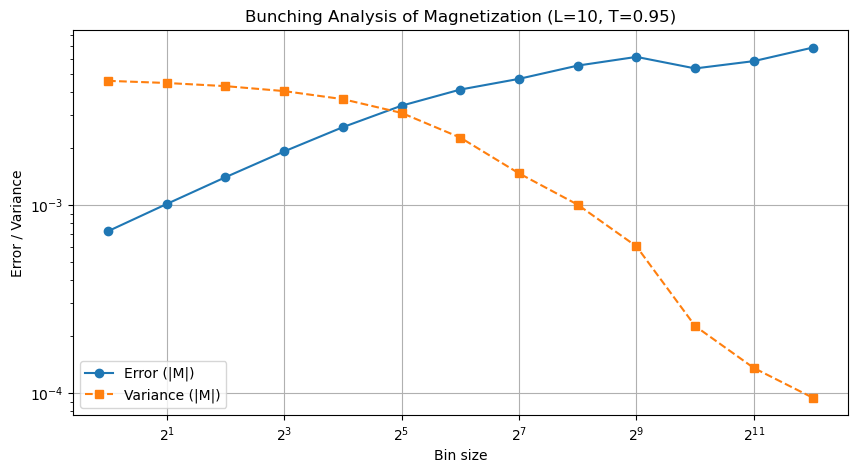

In [101]:
# Choose a specific lattice size and temperature index
L_select = 10
T_index = 5

E_bunch = results[L_select]["E_bunch"][T_index]
M_bunch = results[L_select]["M_bunch"][T_index]

# Energy bunching
E_bin_sizes = [entry["bin_size"] for entry in E_bunch]
E_errors = [entry["error"] for entry in E_bunch]
E_vars = [entry["variance"] for entry in E_bunch]

plt.figure(figsize=(10, 5))
plt.plot(E_bin_sizes, E_errors, 'o-', label='Error (Energy)')
plt.plot(E_bin_sizes, E_vars, 's--', label='Variance (Energy)')
plt.title(f'Bunching Analysis of Energy (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
#plt.savefig('BunchingEnergy.pdf', bbox_inches = 'tight')
plt.grid(True)
plt.show()

# Magnetization bunching
M_bin_sizes = [entry["bin_size"] for entry in M_bunch]
M_errors = [entry["error"] for entry in M_bunch]
M_vars = [entry["variance"] for entry in M_bunch]

plt.figure(figsize=(10, 5))
plt.plot(M_bin_sizes, M_errors, 'o-', label='Error (|M|)')
plt.plot(M_bin_sizes, M_vars, 's--', label='Variance (|M|)')
plt.title(f'Bunching Analysis of Magnetization (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
#plt.savefig('BunchingMag.pdf', bbox_inches = 'tight')
plt.grid(True)
plt.show()

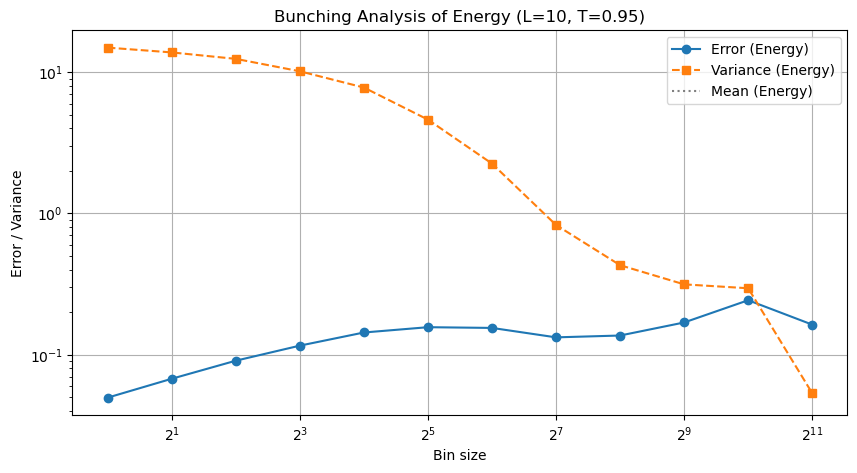

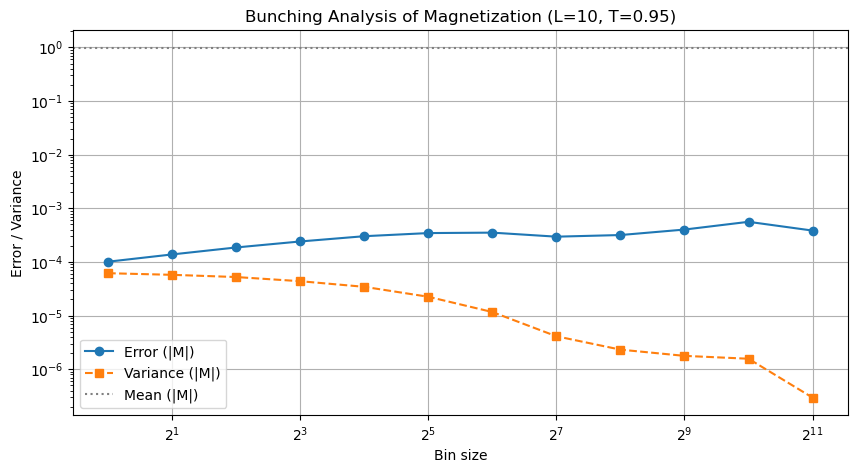

In [93]:
# Energy bunching
E_bin_sizes = [entry["bin_size"] for entry in E_bunch]
E_errors = [entry["error"] for entry in E_bunch]
E_vars = [entry["variance"] for entry in E_bunch]
E_means = [entry["mean"] for entry in E_bunch]

# Plot
plt.figure(figsize=(10, 5))
plt.plot(E_bin_sizes, E_errors, 'o-', label='Error (Energy)')
plt.plot(E_bin_sizes, E_vars, 's--', label='Variance (Energy)')
plt.axhline(np.mean(E_means), color='gray', linestyle=':', label='Mean (Energy)')
plt.title(f'Bunching Analysis of Energy (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.savefig('BunchingEnergy.pdf', bbox_inches='tight')
plt.show()

# Magnetization bunching
M_bin_sizes = [entry["bin_size"] for entry in M_bunch]
M_errors = [entry["error"] for entry in M_bunch]
M_vars = [entry["variance"] for entry in M_bunch]
M_means = [entry["mean"] for entry in M_bunch]

plt.figure(figsize=(10, 5))
plt.plot(M_bin_sizes, M_errors, 'o-', label='Error (|M|)')
plt.plot(M_bin_sizes, M_vars, 's--', label='Variance (|M|)')
plt.axhline(np.mean(M_means), color='gray', linestyle=':', label='Mean (|M|)')
plt.title(f'Bunching Analysis of Magnetization (L={L_select}, T={T_values[T_index]:.2f})')
plt.xlabel('Bin size')
plt.ylabel('Error / Variance')
plt.xscale('log', base=2)
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.savefig('BunchingMag.pdf', bbox_inches='tight')
plt.show()


### Incorporating J into being a site-dependent interaction strength that updates for every change in energy\\\
### Quenched 


In [139]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
L = 10  # Lattice size
q = 4   # Number of clock states
h = np.array([0, 0])  # External field
delta = 0  # Chirality term
T = 1.0  # Temperature
steps = 10000  # Total Monte Carlo steps
measure_every = 10  # Measure every 10 steps

# Function to initialize spins
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))  # Random spin indices
    angles = 2 * np.pi * spins / q
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D vectors
    return spins, sigma, angles  # Return angles too

# Generate a random J matrix for different bonds
def initialize_J(L):
    J_x = np.random.uniform(-1, 1, (L, L))  # J values for horizontal bonds
    J_y = np.random.uniform(-1, 1, (L, L))  # J values for vertical bonds
    return J_x, J_y

# Compute Hamiltonian
def compute_hamiltonian(sigma, angles, J_x, J_y, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            # Interaction with right neighbor (J_x)
            ni, nj = (i, (j + 1) % L)  # Periodic boundary
            H -= J_x[i, j] * np.cos(angles[i, j] - angles[ni, nj] + delta)
            
            # Interaction with bottom neighbor (J_y)
            ni, nj = ((i + 1) % L, j)  
            H -= J_y[i, j] * np.cos(angles[i, j] - angles[ni, nj] + delta)

            # External field term
            H -= np.dot(h, sigma[i, j])
    return H

# Compute average magnetization per spin
def compute_magnetization(sigma):
    mag_vector = np.sum(sigma, axis=(0, 1)) / (L * L)  # Average magnetization vector
    return mag_vector

# Monte Carlo update step
def monte_carlo_step(sigma, spins, angles, J_x, J_y, h, delta, T, update_rule="glauber"):
    L = spins.shape[0]  # Get lattice size dynamically
    i, j = np.random.randint(0, L, 2)  # Pick a random spin
    new_spin = np.random.randint(0, q)  # Propose a new state
    new_angle = 2 * np.pi * new_spin / q  # Convert to angle
    new_sigma = np.array([np.cos(new_angle), np.sin(new_angle)])

    # Compute energy difference ΔE
    old_angle = angles[i, j]  # Current spin angle
    dE = 0

    for (di, dj), J_matrix in [((1, 0), J_y), ((-1, 0), J_y), ((0, 1), J_x), ((0, -1), J_x)]:  # Neighboring interactions using J_x and J_y
        ni, nj = (i + di) % L, (j + dj) % L
        neighbor_angle = angles[ni, nj]
        J_ij = J_matrix[i, j]
        # Interaction term with chirality inside cosine
        dE += 2 * J_ij * (np.cos(old_angle - neighbor_angle + delta) - 
                   np.cos(new_angle - neighbor_angle + delta))

    # External field term
    dE += 2 * (np.dot(h, sigma[i, j]) - np.dot(h, new_sigma))

    # Update rule
    if update_rule == "metropolis":
        P_accept = min(1, np.exp(-dE / T))
    elif update_rule == "glauber":
        P_accept = 1 / (1 + np.exp(dE / T))

    # Apply update if accepted
    if np.random.rand() < P_accept:
        spins[i, j] = new_spin
        angles[i, j] = new_angle  # Update angles too!
        sigma[i, j] = new_sigma

# Run simulation
def run_simulation(J_x, J_y, update_rule):
    spins, sigma, angles = initialize_spins(L, q)  # Get angles too
    magnetization_vals = []

    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J_x, J_y, h, delta, T, update_rule)

        if step % measure_every == 0:
            magnetization_vals.append(compute_magnetization(sigma))

    return np.array(magnetization_vals), spins, sigma, angles  # Return angles

# Initialize J matrices
J_x, J_y = initialize_J(L)

# Run the Glauber simulation
magnetization_vals, spins, sigma, angles = run_simulation(J_x, J_y, "glauber")

# Compute initial and final Hamiltonian
H_init = compute_hamiltonian(sigma, angles, J_x, J_y, h, delta)
H_final = compute_hamiltonian(sigma, angles, J_x, J_y, h, delta)

print("Initial Hamiltonian:", H_init)
print("Final Hamiltonian:", H_final)

# Plot magnetization components over time
plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 0], label="M_x")
#plt.plot(np.arange(0, steps, measure_every), magnetization_vals[:, 1], label="M_y")
plt.xlabel("Monte Carlo Steps")
plt.ylabel("Magnetization Components per Spin")
plt.title(f"Magnetization Evolution with q={q}, delta={delta}, J∈[0.5,2]")
plt.legend()
plt.show()


ValueError: a must be greater than 0 unless no samples are taken

### Cluster Algorithm - Wolff's Algorithm

### Wolff's Algorithm in Krauth

In [3]:
def wolff_update(sigma, angles, J, T, L, q):
    beta = 1 / T

    # Step 1: Choose random reflection axis (unit vector r̂)
    theta_r = 2 * np.pi * np.random.rand()
    r_hat = np.array([np.cos(theta_r), np.sin(theta_r)])

    # Step 2: Pick a random site as the seed
    i, j = np.random.randint(0, L, 2)
    cluster_mask = np.zeros((L, L), dtype=bool)  # Mask for visited sites
    to_visit = [(i, j)]  # Stack for cluster growth
    cluster_mask[i, j] = True

    # Project spin at seed onto r̂
    sigma_proj = np.dot(sigma[i, j], r_hat)

    # Bond probability depends on alignment
    def bond_prob(s1_proj, s2_proj):
        return 1 - np.exp(-2 * beta * J * s1_proj * s2_proj)

    # Step 3: Grow the cluster
    while to_visit:
        i, j = to_visit.pop()
        for di, dj in [(-1,0), (1,0), (0,-1), (0,1)]:
            ni, nj = (i + di) % L, (j + dj) % L
            if not cluster_mask[ni, nj]:
                s_proj = np.dot(sigma[ni, nj], r_hat)
                if sigma_proj * s_proj > 0:  # Same "side" of r̂
                    if np.random.rand() < bond_prob(sigma_proj, s_proj):
                        cluster_mask[ni, nj] = True
                        to_visit.append((ni, nj))

    # Step 4: Reflect all spins in the cluster about r̂
    for i in range(L):
        for j in range(L):
            if cluster_mask[i, j]:
                s = sigma[i, j]
                s_reflected = s - 2 * np.dot(s, r_hat) * r_hat
                sigma[i, j] = s_reflected
                angles[i, j] = np.arctan2(s_reflected[1], s_reflected[0])

    return sigma, angles  # Updated spin vectors and angles

In [22]:
# Parameters
L = 8                      # Size of the lattice (8x8 grid of spins)
q = 5                      # Number of discrete spin states (clock states)
J = 1.0                    # Coupling strength between neighboring spins
h = np.array([0, 0])       # External magnetic field (set to zero vector)
delta = 0                  # Phase shift between neighbors (used in chiral models, here set to 0)
T = 2.25                   # Temperature of the system
num_sweeps = 5000          # Number of Monte Carlo sweeps (full-lattice updates)
measure_every = L**2       # How often to measure magnetization (every L^2 updates)
burn_in_sweeps = 1000      # Number of sweeps before we start recording measurements

steps = num_sweeps         # Alias for the number of measurement sweeps
burn_in = burn_in_sweeps   # Alias for burn-in sweeps


In [24]:
# Spin Initialization
def initialize_spins(L, q):
    spins = np.random.randint(0, q, (L, L))              # Random integers [0, q-1] for spin states
    angles = 2 * np.pi * spins / q                       # Map to angles on the circle
    sigma = np.stack([np.cos(angles), np.sin(angles)], axis=-1)  # Convert to 2D unit vectors
    return spins, sigma, angles


In [26]:
# Hamiltonian (Total Energy)
def compute_hamiltonian(sigma, angles, J, h, delta):
    H = 0
    for i in range(L):
        for j in range(L):
            for di, dj in [(1, 0), (0, 1)]:                     # Only right and down (avoid double-counting)
                ni, nj = (i + di) % L, (j + dj) % L             # Apply periodic boundary conditions
                H -= J * np.cos(angles[i, j] - angles[ni, nj] + delta)  # Interaction energy
                H -= np.dot(h, sigma[i, j])                    # Interaction with external field
    return H


In [28]:
# Magnetization
def compute_magnetization(sigma, L):
    M_vec = np.sum(sigma, axis=(0, 1))             # Total vector magnetization
    M_mag = np.linalg.norm(M_vec)                  # Magnitude of total magnetization
    m_mag = M_mag / (L**2)                         # Per-spin magnitude
    return M_vec, M_mag, m_mag


In [30]:
# Wolff's Cluster Algorithm
# Choose a random axis of reflection. This is the key difference from Ising – we reflect continuous vectors (spin directions).
def wolff_update(sigma, angles, J, T, L, q):
    beta = 1 / T
    theta_r = 2 * np.pi * np.random.rand()                # Random reflection axis
    r_hat = np.array([np.cos(theta_r), np.sin(theta_r)])  # Unit vector of reflection axis

# Choose a random direction in 2D as the reflection axis
    i, j = np.random.randint(0, L, 2)                     # Pick a random site to start the cluster
    cluster_mask = np.zeros((L, L), dtype=bool)          # Track cluster membership
    to_visit = [(i, j)]                                  # A stack to keep track of sites to process while growing the cluster.
    cluster_mask[i, j] = True                            # Marks the seed site as included in the cluster.
    sigma_proj = np.dot(sigma[i, j], r_hat)              # Projection of the initial site's spin vector onto the reflection axis. This projection determines which side it's on.
    def bond_prob(s1_proj, s2_proj):                     # Wolff bond probability dependent on the spin's projection
        return 1 - np.exp(-2 * beta * J * s1_proj * s2_proj) # Note: Spins more aligned (positive dot product) are more likely to be added to the cluster.
    # Wolff's cluster growth rule
    while to_visit:                                      # Continue growing the cluster as long as there are spins in the stack to process.
        i, j = to_visit.pop()                            # Pop a site from the to_visit stack to examine it's neighbors
        for di, dj in [(-1,0), (1,0), (0,-1), (0,1)]:    # Loop through 4 nearest neighbors using periodic boundary conditions via the modulus operator % L
            ni, nj = (i + di) % L, (j + dj) % L
            if not cluster_mask[ni, nj]:                 # Only consider neighbors that haven’t already been added to the cluster.
                s_proj = np.dot(sigma[ni, nj], r_hat)    # Only consider aligned neighbors — i.e., ones on the same side of the axis as the seed.
                if sigma_proj * s_proj > 0:    # Only grow the cluster with spins on the same side of the reflection axis (important for defining coherent clusters).
                    if np.random.rand() < bond_prob(sigma_proj, s_proj) # Add the neighbor to the cluster with some probability defined by the bond function.
                        cluster_mask[ni, nj] = True 
                        to_visit.append((ni, nj)) # If added, mark it as part of the cluster and push it to the to_visit stack for further processing
    for i in range(L):
        for j in range(L):
            if cluster_mask[i, j]: # Loop through all lattice sites and check if the site belongs to the cluster (based on cluster_mask).
                s = sigma[i, j]     # his reflects the spin s across the axis using the standard reflection formula:
                s_reflected = s - 2 * np.dot(s, r_hat) * r_hat        # Reflect a vector across a line (r_hat) 
                sigma[i, j] = s_reflected                              # Update the spin vector in the lattice to its reflected version.

                angles[i, j] = np.arctan2(s_reflected[1], s_reflected[0])  # Update the angle array so the Hamiltonian calculations remain consistent. Recompute the angle of the spin from the reflected vector using arctan2
    return sigma, angles

In [32]:
# Wrapper for Monte Carlo dynamics
def monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule):
    if update_rule == "wolff":
        sigma[:], angles[:] = wolff_update(sigma, angles, J, T, L, q)
    else:
        raise NotImplementedError("Only 'wolff' is implemented in this version.") # Currently, the wolff updated method is accepted


In [40]:
# Run simulation
def run_simulation(update_rule="wolff"): # Initialize spin configuration
    spins, sigma, angles = initialize_spins(L, q)
    for _ in range(burn_in):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)
    M_list = [] # Measure and store the  and energy values
    m_list = []
    E_list = [] 
    for step in range(steps):
        monte_carlo_step(sigma, spins, angles, J, h, delta, T, update_rule)

        if step % measure_every == 0:
            M_vec, M_mag, m_mag = compute_magnetization(sigma, L)
            M_list.append(M_mag)
            m_list.append(m_mag)
    return np.array(M_list), np.array(m_list), np.array(E_list), spins, sigma, angles
# Run the simulation with Wolff dynamics
M_list, m_list, E_list, spins, sigma, angles = run_simulation("wolff")


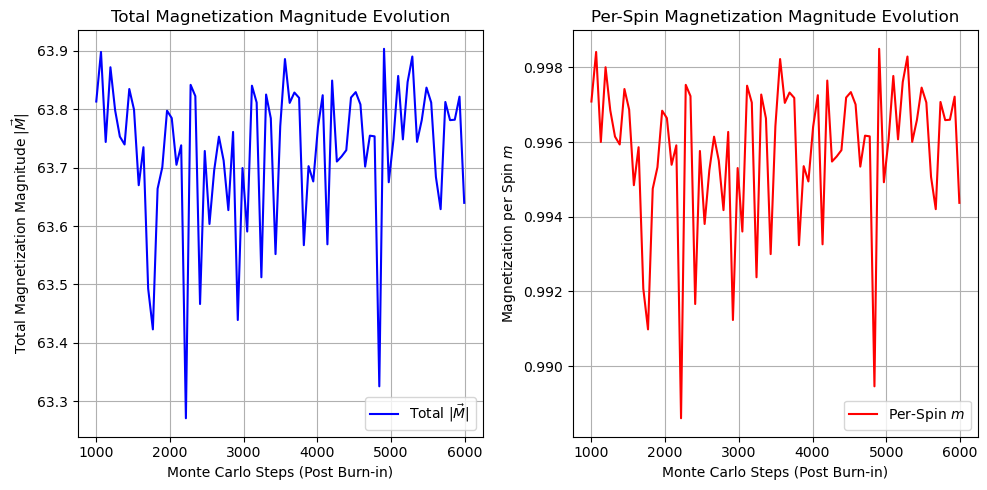

In [42]:

# Plot results
plt.figure(figsize=(10, 5))
x_vals = np.arange(len(M_list)) * measure_every + burn_in # len(M_list) is the number of measurements you've made — one every measure_every steps.np.arange(len(M_list)) gives you [0, 1, 2, ..., N-1] where N = len(M_list).* measure_every scales this to actual MC steps: [0, measure_every, 2*measure_every, ...].+ burn_in shifts it so the x-axis starts after the burn-in phase (which you're not measuring during).

plt.subplot(1, 2, 1)
plt.plot(x_vals, M_list, label="Total $|\\vec{M}|$", color="blue")
plt.xlabel("Monte Carlo Steps (Post Burn-in)")
plt.ylabel("Total Magnetization Magnitude $|\\vec{M}|$")
plt.title("Total Magnetization Magnitude Evolution")
plt.legend()
plt.grid()
# Note: Even at low temperatures, finite-sized simulations of the clock model (especially for odd q = 5) may not show a net magnetization unless you:

Break symmetry (e.g., via a small external field
plt.subplot(1, 2, 2)
plt.plot(x_vals, m_list, label="Per-Spin $m$", color="red")
plt.xlabel("Monte Carlo Steps (Post Burn-in)")
plt.ylabel("Magnetization per Spin $m$")
plt.title("Per-Spin Magnetization Magnitude Evolution")
plt.legend()
plt.grid()

plt.tight_layout()